In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import re

# Szukamy folderu aiops względem lokalizacji notebooka.
cwd = Path.cwd().resolve()

candidates = []
for p in [cwd, *cwd.parents]:
    candidates.extend([p, p / "aiops"])

AIOPS_ROOT = next(
    (
        p for p in candidates
        if (p / "scenarios_logs_3h_trimmed").is_dir()
    ),
    None,
)

if AIOPS_ROOT is None:
    raise FileNotFoundError(
        "Nie znaleziono scenarios_logs_3h_trimmed. "
        "Ustaw AIOPS_ROOT ręcznie na ścieżkę folderu aiops."
    )

NEW_ROOT = AIOPS_ROOT / "scenarios_logs_3h_trimmed"

# Szukamy poprzedniego benchmarku.
result_candidates = []

for p in [AIOPS_ROOT, AIOPS_ROOT.parent, cwd, *cwd.parents]:
    for suffix in [
        "results",
        "aiops_private/results",
        "projects/aiops_private/results",
        "aiops/results",
    ]:
        result_candidates.append(p / suffix)

OLD_RESULTS = next(
    (
        p for p in result_candidates
        if (p / "benchmark_all_ranked" / "ranking_all.csv").is_file()
    ),
    None,
)

print("NOWE LOGI:", NEW_ROOT)
print("STARE WYNIKI:", OLD_RESULTS)

if OLD_RESULTS is None:
    print(
        "\nNie znaleziono starego benchmarku automatycznie. "
        "Trzeba będzie ustawić OLD_RESULTS ręcznie."
    )
else:
    print("\nZnalezione pliki:")
    for relative in [
        "benchmark_all_ranked/ranking_all.csv",
        "benchmark_all_ranked/scores_by_case.csv",
        "checkpoint/session_latest.joblib",
        "checkpoint/namespace_benchmark_2026-10-26.joblib",
    ]:
        path = OLD_RESULTS / relative
        print(
            "✓" if path.exists() else "✗",
            relative
        )

    prediction_dir = (
        OLD_RESULTS / "benchmark_all_ranked" / "predictions"
    )

    print(
        "\nLiczba plików z predykcjami:",
        len(list(prediction_dir.glob("*.npz")))
        if prediction_dir.exists() else 0
    )

NOWE LOGI: C:\Users\kzieba\aiops\scenarios_logs_3h_trimmed
STARE WYNIKI: C:\Users\kzieba\aiops_private\results

Znalezione pliki:
✓ benchmark_all_ranked/ranking_all.csv
✓ benchmark_all_ranked/scores_by_case.csv
✓ checkpoint/session_latest.joblib
✓ checkpoint/namespace_benchmark_2026-10-26.joblib

Liczba plików z predykcjami: 560


In [2]:
def scenario_sort_key(path):
    match = re.search(r"\d+", path.name)
    return int(match.group()) if match else 999


def find_incident_fields(obj, prefix=""):
    found = {}

    if isinstance(obj, dict):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else key

            if key.lower() in {
                "incident_start", "incident_end"
            }:
                found[path] = str(value)

            elif isinstance(value, (dict, list)):
                found.update(
                    find_incident_fields(value, path)
                )

    elif isinstance(obj, list):
        for i, value in enumerate(obj[:10]):
            if isinstance(value, (dict, list)):
                found.update(
                    find_incident_fields(
                        value, f"{prefix}[{i}]"
                    )
                )

    return found


SCENARIO_DIRS = sorted(
    [p for p in NEW_ROOT.iterdir() if p.is_dir()],
    key=scenario_sort_key,
)

inspection = []

for scenario_dir in SCENARIO_DIRS:

    json_files = sorted(
        scenario_dir.glob("*.json")
    )

    window_files = [
        p for p in json_files
        if p.stem.lower().endswith("_window")
    ]

    log_files = [
        p for p in json_files
        if p not in window_files
    ]

    window_fields = {}

    if len(window_files) == 1:
        with window_files[0].open(
            "r", encoding="utf-8-sig"
        ) as f:
            window_obj = json.load(f)

        window_fields = find_incident_fields(
            window_obj
        )

    # Rozpoznajemy format początku pliku,
    # bez wyświetlania jego treści.
    log_format = "unknown"

    if len(log_files) == 1:
        with log_files[0].open(
            "r", encoding="utf-8-sig"
        ) as f:
            head = f.read(4096).lstrip()

        if head.startswith("["):
            log_format = "JSON array"
        elif head.startswith("{"):
            log_format = "JSON object / JSONL"
        else:
            log_format = "other"

    inspection.append({
        "scenario": scenario_dir.name,
        "log_file": log_files[0].name
            if len(log_files) == 1 else str(len(log_files)) + " files",
        "log_size_MB": round(
            log_files[0].stat().st_size / 1024**2, 2
        ) if len(log_files) == 1 else np.nan,
        "log_format": log_format,
        "window_file": window_files[0].name
            if len(window_files) == 1 else "NOT FOUND",
        "incident_fields": window_fields,
    })

inspection_df = pd.DataFrame(inspection)

display(inspection_df)

print("Liczba scenariuszy:", len(SCENARIO_DIRS))

if len(SCENARIO_DIRS) != 11:
    print("UWAGA: oczekiwano 11 scenariuszy.")

,scenario,log_file,log_size_MB,log_format,window_file,incident_fields
0,scenario1,pod_unavailable_2026-08-24_0847-1343Z.json,21.68,JSON array,_window.json,{'incident_start': '2026-08-24T11:47:09+00:00'...
1,scenario2,crashloopbackoff_2026-08-24_1157-1652Z.json,22.45,JSON array,_window.json,{'incident_start': '2026-08-24T13:43:20+00:00'...
2,scenario3,auth_rejection_2026-08-25_1037-1647Z.json,43.14,JSON array,_window.json,{'incident_start': '2026-08-25T13:37:43+00:00'...
3,scenario4,service_no_endpoints_2026-09-08_0230-0841Z.json,56.31,JSON array,_window.json,{'incident_start': '2026-09-08T05:30:18+00:00'...
4,scenario5,dns_failure_2026-09-09_0740-1206Z.json,30.26,JSON array,_window.json,{'incident_start': '2026-09-09T10:40:17+00:00'...
5,scenario6,log_flood_2026-09-09_1052-1416Z.json,190.88,JSON array,_window.json,{'incident_start': '2026-09-09T12:06:58+00:00'...
6,scenario7,oomkilled_2026-09-09_1218-1727Z.json,21.37,JSON array,_window.json,{'incident_start': '2026-09-09T14:16:10+00:00'...
7,scenario8,traffic_overload_2026-09-10_0932-1542Z.json,80.96,JSON array,_window.json,{'incident_start': '2026-09-10T12:32:36+00:00'...
8,scenario9,overloaded_outage_2026-09-11_0550-0926Z.json,18.27,JSON array,_window.json,{'incident_start': '2026-09-11T08:50:43+00:00'...
9,scenario10,network_latency_2026-09-11_0902-1028Z.json,15.45,JSON array,_window.json,{'incident_start': '2026-09-11T09:26:19+00:00'...


Liczba scenariuszy: 11


In [7]:
if OLD_RESULTS is not None:

    OLD_RANKING = pd.read_csv(
        OLD_RESULTS
        / "benchmark_all_ranked"
        / "ranking_all.csv"
    )

    print("Liczba zapisanych konfiguracji:", len(OLD_RANKING))

    display(
        OLD_RANKING
        .sort_values("MCC_all", ascending=False)
        .head(10)[
            [
                "parser", "window", "model",
                "variant", "n_features",
                "MCC_all", "MCC_scenario4",
            ]
        ]
        .round(4)
    )

    print("\nWarianty cech:")
    print(sorted(OLD_RANKING["variant"].unique()))

Liczba zapisanych konfiguracji: 560


,parser,window,model,variant,n_features,MCC_all,MCC_scenario4
416,IPLoM,10min,Random Forest,ALL - 5 metrics + missing,2068,0.6509,0.0000
337,IPLoM,2min,Gradient Boosting,ALL - counts,427,0.5961,0.2169
327,IPLoM,2min,Gradient Boosting,178 features,178,0.5961,0.2169
391,IPLoM,10min,Random Forest,23 features,23,0.5922,0.0000
77,Drain3,5min,Gradient Boosting,23 features,23,0.5787,0.0000
102,Drain3,5min,Gradient Boosting,ALL - 5 metrics + missing,2373,0.5787,0.0000
342,IPLoM,2min,Gradient Boosting,ALL - 5 metrics,2063,0.5771,-0.0756
347,IPLoM,2min,Gradient Boosting,ALL - 5 metrics + missing,2068,0.5747,0.3780
322,IPLoM,2min,Gradient Boosting,23 features,23,0.5747,0.3780
332,IPLoM,2min,Gradient Boosting,183 features,183,0.5725,0.3780



Warianty cech:
['178 features', '18 features', '183 features', '23 features', 'ALL - 5 metrics', 'ALL - 5 metrics + missing', 'ALL - counts']


In [4]:
import joblib
from pathlib import Path

CHECKPOINT_PATH = (
    OLD_RESULTS
    / "checkpoint"
    / "namespace_benchmark_2026-10-26.joblib"
)

checkpoint = joblib.load(CHECKPOINT_PATH)

# Nie otwieramy samych logów ani nie drukujemy ich treści.
model_files = []

for extension in ("*.joblib", "*.pkl", "*.pickle"):
    model_files.extend(OLD_RESULTS.rglob(extension))

print("Zapisane obiekty:")
for path in sorted(set(model_files)):
    print(
        f"  {path.relative_to(OLD_RESULTS)}"
        f"  ({path.stat().st_size / 1024**2:.1f} MB)"
    )

print("\nZawartość checkpointu:")
print("Klucze główne:", list(checkpoint.keys()))

for parser in ["Drain3", "Spell", "IPLoM", "AEL"]:
    obj = checkpoint["parsers"][parser]
    print(
        parser,
        "| zapisane elementy:",
        list(obj.keys()),
        "| scenariusze:",
        len(obj["cases"]),
    )

# Sprawdzenie schematu poprzednich cech.
old_dataset = checkpoint["parsers"]["IPLoM"]["window_results"][
    ("2min", "full", "Gradient Boosting")
]["dataset"]

print("\nSchemat starego datasetu:")
print("Shape:", old_dataset.shape)
print("Index:", old_dataset.index.names)
print("Kolumny:", list(old_dataset.columns))

Zapisane obiekty:
  checkpoint\namespace_benchmark_2026-10-26.joblib  (1.1 MB)
  checkpoint\session_latest.joblib  (7.3 MB)
  parser_comparison\decision_tree_predictions.joblib  (0.5 MB)

Zawartość checkpointu:
Klucze główne: ['version', 'saved_date', 'parsers', 'tables']
Drain3 | zapisane elementy: ['cases', 'window_results'] | scenariusze: 11
Spell | zapisane elementy: ['cases', 'window_results'] | scenariusze: 11
IPLoM | zapisane elementy: ['cases', 'window_results'] | scenariusze: 11
AEL | zapisane elementy: ['cases', 'window_results'] | scenariusze: 11

Schemat starego datasetu:
Shape: (405, 22)
Index: [None]
Kolumny: ['timestamp', 'total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'tem

In [3]:
import json
import re
import numpy as np
import pandas as pd


def parse_timestamp_series(values):
    values = pd.Series(values).reset_index(drop=True)
    strings = values.astype("string").str.strip()

    result = pd.Series(
        pd.NaT,
        index=values.index,
        dtype="datetime64[ns, UTC]",
    )

    numeric_mask = strings.str.fullmatch(
        r"-?\d+(?:\.\d+)?"
    ).fillna(False)

    if (~numeric_mask).any():
        result.loc[~numeric_mask] = pd.to_datetime(
            strings.loc[~numeric_mask],
            utc=True,
            errors="coerce",
            format="mixed",
        )

    if numeric_mask.any():
        numeric = pd.to_numeric(
            strings.loc[numeric_mask],
            errors="coerce",
        )

        # Rozpoznajemy jednostkę po skali Unix timestamp.
        median_abs = numeric.abs().median()

        if median_abs >= 1e17:
            unit = "ns"
        elif median_abs >= 1e14:
            unit = "us"
        elif median_abs >= 1e11:
            unit = "ms"
        else:
            unit = "s"

        result.loc[numeric_mask] = pd.to_datetime(
            numeric,
            unit=unit,
            utc=True,
            errors="coerce",
        )

    return result


def parse_one_timestamp(value):
    parsed = parse_timestamp_series([value]).iloc[0]

    if pd.isna(parsed):
        raise ValueError(
            f"Niepoprawny timestamp: {value!r}"
        )

    return parsed


def load_json_records(path):
    try:
        with path.open("r", encoding="utf-8-sig") as f:
            obj = json.load(f)

    except json.JSONDecodeError:
        with path.open("r", encoding="utf-8-sig") as f:
            obj = [
                json.loads(line)
                for line in f
                if line.strip()
            ]

    if isinstance(obj, list):
        return obj

    if isinstance(obj, dict):
        for key in (
            "logs", "records", "entries",
            "items", "results", "data",
        ):
            if isinstance(obj.get(key), list):
                return obj[key]

        # Jeden rekord JSON.
        if "line" in obj or "message" in obj:
            return [obj]

    raise ValueError(
        f"Nieobsługiwany format logów w {path.name}. "
        "Potrzebna będzie adaptacja loadera."
    )


def find_window_values(obj):
    found = {}

    def visit(value):
        if isinstance(value, dict):
            for key, item in value.items():
                if key.lower() in {
                    "incident_start", "incident_end"
                }:
                    found[key.lower()] = item
                elif isinstance(item, (dict, list)):
                    visit(item)

        elif isinstance(value, list):
            for item in value:
                visit(item)

    visit(obj)

    required = {"incident_start", "incident_end"}

    if not required.issubset(found):
        raise ValueError(
            f"Brak pól incydentu: {required - set(found)}"
        )

    return (
        parse_one_timestamp(found["incident_start"]),
        parse_one_timestamp(found["incident_end"]),
    )


def convert_log_records(records):
    df = pd.DataFrame(records)

    timestamp_col = next(
        (
            c for c in ("ts", "timestamp", "time")
            if c in df.columns
        ),
        None,
    )

    message_col = next(
        (
            c for c in ("line", "message", "msg")
            if c in df.columns
        ),
        None,
    )

    if timestamp_col is None or message_col is None:
        raise ValueError(
            "Nie rozpoznano pól timestamp/message. "
            f"Dostępne kolumny: {list(df.columns)}"
        )

    if "namespace" in df.columns:
        namespace = df["namespace"]

    elif "labels.namespace" in df.columns:
        namespace = df["labels.namespace"]

    elif "labels" in df.columns:
        namespace = df["labels"].map(
            lambda x: x.get("namespace")
            if isinstance(x, dict) else None
        )

    else:
        raise ValueError(
            "Nie rozpoznano namespace w nowych logach."
        )

    result = pd.DataFrame({
        "timestamp": parse_timestamp_series(
            df[timestamp_col]
        ),
        "message": df[message_col].fillna("").astype(str),
        "namespace": namespace.fillna("<NA>").astype(str),
    })

    if result["timestamp"].isna().any():
        raise ValueError(
            "Część timestampów nie została rozpoznana."
        )

    return (
        result.sort_values("timestamp", kind="stable")
        .reset_index(drop=True)
    )


NEW_CASE_DATA = {}
new_summary = []

for scenario_dir in SCENARIO_DIRS:

    match = re.search(r"\d+", scenario_dir.name)
    case = f"scenario{int(match.group())}"

    files = list(scenario_dir.rglob("*.json"))

    window_files = [
        p for p in files
        if p.stem.lower().endswith("_window")
    ]

    log_files = [
        p for p in files
        if p not in window_files
    ]

    if len(window_files) != 1 or len(log_files) != 1:
        raise ValueError(
            f"{case}: oczekiwano 1 pliku logów "
            f"i 1 pliku _window.json, "
            f"znaleziono {len(log_files)} i "
            f"{len(window_files)}."
        )

    with window_files[0].open(
        "r", encoding="utf-8-sig"
    ) as f:
        window_obj = json.load(f)

    incident_start, incident_end = (
        find_window_values(window_obj)
    )

    if incident_end <= incident_start:
        raise ValueError(
            f"{case}: incident_end <= incident_start"
        )

    records = load_json_records(log_files[0])
    full_df = convert_log_records(records)

    NEW_CASE_DATA[case] = {
        "full_df": full_df,
        "incident_start": incident_start,
        "incident_end": incident_end,
    }

    in_incident = (
        (full_df["timestamp"] >= incident_start)
        & (full_df["timestamp"] < incident_end)
    )

    new_summary.append({
        "scenario": case,
        "logs": len(full_df),
        "first_log": full_df["timestamp"].min(),
        "last_log": full_df["timestamp"].max(),
        "duration_h": round(
            (
                full_df["timestamp"].max()
                - full_df["timestamp"].min()
            ).total_seconds() / 3600,
            2,
        ),
        "incident_start": incident_start,
        "incident_end": incident_end,
        "incident_logs": int(in_incident.sum()),
        "namespaces": full_df["namespace"].nunique(),
    })

    print(
        f"✓ {case}: {len(full_df):,} logów, "
        f"{int(in_incident.sum()):,} podczas incydentu"
    )


NEW_SUMMARY = pd.DataFrame(new_summary)

display(NEW_SUMMARY)

assert len(NEW_CASE_DATA) == 11

✓ scenario1: 26,858 logów, 0 podczas incydentu
✓ scenario2: 27,651 logów, 0 podczas incydentu
✓ scenario3: 57,081 logów, 2,523 podczas incydentu
✓ scenario4: 76,732 logów, 613 podczas incydentu
✓ scenario5: 41,251 logów, 0 podczas incydentu
✓ scenario6: 312,362 logów, 0 podczas incydentu
✓ scenario7: 27,221 logów, 0 podczas incydentu
✓ scenario8: 89,713 logów, 55,381 podczas incydentu
✓ scenario9: 22,788 logów, 0 podczas incydentu
✓ scenario10: 19,253 logów, 0 podczas incydentu
✓ scenario11: 154,674 logów, 0 podczas incydentu


,scenario,logs,first_log,last_log,duration_h,incident_start,incident_end,incident_logs,namespaces
0,scenario1,26858,2026-08-24 08:47:14.526588+00:00,2026-08-24 13:43:14.634894+00:00,4.93,2026-08-24 13:43:20+00:00,2026-08-24 13:52:18+00:00,0,1
1,scenario2,27651,2026-08-24 11:57:51.571815+00:00,2026-08-24 16:52:03.596928+00:00,4.90,2026-08-24 11:47:09+00:00,2026-08-24 11:57:51+00:00,0,1
2,scenario3,57081,2026-08-25 10:37:47.743007+00:00,2026-08-25 16:47:15.046494+00:00,6.16,2026-08-25 13:37:43+00:00,2026-08-25 13:47:44+00:00,2523,1
3,scenario4,76732,2026-09-08 02:30:18.159991+00:00,2026-09-08 08:41:37.199147+00:00,6.19,2026-09-08 05:30:18+00:00,2026-09-08 05:41:42+00:00,613,1
4,scenario5,41251,2026-09-09 07:40:43.009858+00:00,2026-09-09 12:06:44.910355+00:00,4.43,2026-09-09 12:06:58+00:00,2026-09-09 12:18:12+00:00,0,1
5,scenario6,312362,2026-09-09 10:52:37.543737+00:00,2026-09-09 14:16:03.024847+00:00,3.39,2026-09-09 14:16:10+00:00,2026-09-09 14:27:21+00:00,0,1
6,scenario7,27221,2026-09-09 12:18:21.188200+00:00,2026-09-09 17:27:19.371005+00:00,5.15,2026-09-09 12:06:58+00:00,2026-09-09 12:18:12+00:00,0,1
7,scenario8,89713,2026-09-10 09:32:46.057126+00:00,2026-09-10 15:42:23.441372+00:00,6.16,2026-09-10 12:32:36+00:00,2026-09-10 12:42:36+00:00,55381,1
8,scenario9,22788,2026-09-11 05:51:02.739059+00:00,2026-09-11 09:26:02.891073+00:00,3.58,2026-09-11 10:28:36+00:00,2026-09-11 10:48:00+00:00,0,1
9,scenario10,19253,2026-09-11 09:02:00.178764+00:00,2026-09-11 10:28:32.024031+00:00,1.44,2026-09-11 10:28:36+00:00,2026-09-11 10:48:00+00:00,0,2


In [3]:
checks = []

for case, info in NEW_CASE_DATA.items():

    df = info["full_df"]
    start = info["incident_start"]
    end = info["incident_end"]

    checks.append({
        "scenario": case,
        "incident_inside_logs": (
            df["timestamp"].min() <= start
            and df["timestamp"].max() >= end
        ),
        "timestamps_sorted": (
            df["timestamp"].is_monotonic_increasing
        ),
        "missing_messages": int(
            df["message"].isna().sum()
        ),
        "incident_duration_min": round(
            (end - start).total_seconds() / 60,
            2,
        ),
    })

NEW_CHECKS = pd.DataFrame(checks)

display(NEW_CHECKS)

if not NEW_CHECKS["incident_inside_logs"].all():
    print(
        "UWAGA: niektóre incydenty wykraczają "
        "poza zakres dostępnych logów."
    )

NameError: name 'NEW_CASE_DATA' is not defined

In [10]:
import pandas as pd

rows = []

for case, info in NEW_CASE_DATA.items():

    df = info["full_df"]

    log_start = df["timestamp"].min()
    log_end = df["timestamp"].max()

    incident_start = info["incident_start"]
    incident_end = info["incident_end"]

    during = (
        (df["timestamp"] >= incident_start)
        & (df["timestamp"] < incident_end)
    )

    if incident_end <= log_start:
        status = "INCYDENT PRZED LOGAMI"
        gap_minutes = (
            log_start - incident_end
        ).total_seconds() / 60

    elif incident_start > log_end:
        status = "INCYDENT PO LOGACH"
        gap_minutes = (
            incident_start - log_end
        ).total_seconds() / 60

    elif incident_start < log_start or incident_end > log_end:
        status = "CZĘŚCIOWE POKRYCIE"
        gap_minutes = 0

    elif during.sum() == 0:
        status = "BRAK WIADOMOŚCI W OKNIE"
        gap_minutes = 0

    else:
        status = "OK"
        gap_minutes = 0

    rows.append({
        "scenario": case,
        "first_log": log_start,
        "last_log": log_end,
        "incident_start": incident_start,
        "incident_end": incident_end,
        "logs_during": int(during.sum()),
        "gap_minutes": round(gap_minutes, 2),
        "status": status,
    })


TIME_DIAGNOSTICS = pd.DataFrame(rows)

TIME_DIAGNOSTICS["nr"] = (
    TIME_DIAGNOSTICS["scenario"]
    .str.extract(r"(\d+)")
    .astype(int)
)

TIME_DIAGNOSTICS = (
    TIME_DIAGNOSTICS.sort_values("nr")
    .drop(columns="nr")
    .reset_index(drop=True)
)

display(TIME_DIAGNOSTICS)

,scenario,first_log,last_log,incident_start,incident_end,logs_during,gap_minutes,status
0,scenario1,2026-08-24 08:47:14.526588+00:00,2026-08-24 13:43:14.634894+00:00,2026-08-24 13:43:20+00:00,2026-08-24 13:52:18+00:00,0,0.09,INCYDENT PO LOGACH
1,scenario2,2026-08-24 11:57:51.571815+00:00,2026-08-24 16:52:03.596928+00:00,2026-08-24 11:47:09+00:00,2026-08-24 11:57:51+00:00,0,0.01,INCYDENT PRZED LOGAMI
2,scenario3,2026-08-25 10:37:47.743007+00:00,2026-08-25 16:47:15.046494+00:00,2026-08-25 13:37:43+00:00,2026-08-25 13:47:44+00:00,2523,0.00,OK
3,scenario4,2026-09-08 02:30:18.159991+00:00,2026-09-08 08:41:37.199147+00:00,2026-09-08 05:30:18+00:00,2026-09-08 05:41:42+00:00,613,0.00,OK
4,scenario5,2026-09-09 07:40:43.009858+00:00,2026-09-09 12:06:44.910355+00:00,2026-09-09 12:06:58+00:00,2026-09-09 12:18:12+00:00,0,0.22,INCYDENT PO LOGACH
5,scenario6,2026-09-09 10:52:37.543737+00:00,2026-09-09 14:16:03.024847+00:00,2026-09-09 14:16:10+00:00,2026-09-09 14:27:21+00:00,0,0.12,INCYDENT PO LOGACH
6,scenario7,2026-09-09 12:18:21.188200+00:00,2026-09-09 17:27:19.371005+00:00,2026-09-09 12:06:58+00:00,2026-09-09 12:18:12+00:00,0,0.15,INCYDENT PRZED LOGAMI
7,scenario8,2026-09-10 09:32:46.057126+00:00,2026-09-10 15:42:23.441372+00:00,2026-09-10 12:32:36+00:00,2026-09-10 12:42:36+00:00,55381,0.00,OK
8,scenario9,2026-09-11 05:51:02.739059+00:00,2026-09-11 09:26:02.891073+00:00,2026-09-11 10:28:36+00:00,2026-09-11 10:48:00+00:00,0,62.55,INCYDENT PO LOGACH
9,scenario10,2026-09-11 09:02:00.178764+00:00,2026-09-11 10:28:32.024031+00:00,2026-09-11 10:28:36+00:00,2026-09-11 10:48:00+00:00,0,0.07,INCYDENT PO LOGACH


In [11]:
import json
import re
import pandas as pd

corrected_rows = []

for scenario_dir in SCENARIO_DIRS:

    case_number = int(
        re.search(r"\d+", scenario_dir.name).group()
    )
    case = f"scenario{case_number}"

    window_files = [
        p for p in scenario_dir.rglob("*.json")
        if p.stem.lower().endswith("_window")
    ]

    if len(window_files) != 1:
        raise ValueError(
            f"{case}: znaleziono {len(window_files)} plików _window.json"
        )

    with window_files[0].open(
        "r", encoding="utf-8-sig"
    ) as f:
        meta = json.load(f)

    # KONTROLA: plik należy do właściwego scenariusza
    if int(meta["scenario"]) != case_number:
        raise ValueError(
            f"{case}: niezgodny numer w _window.json"
        )

    # KLUCZOWA POPRAWKA:
    # pobieramy tylko pola główne JSON,
    # ignorując other_incidents_in_range
    start = pd.to_datetime(
        meta["incident_start"], utc=True
    )
    end = pd.to_datetime(
        meta["incident_end"], utc=True
    )

    if end <= start:
        raise ValueError(f"{case}: nieprawidłowy przedział incydentu")

    NEW_CASE_DATA[case]["incident_start"] = start
    NEW_CASE_DATA[case]["incident_end"] = end

    df = NEW_CASE_DATA[case]["full_df"]

    during = (
        (df["timestamp"] >= start)
        & (df["timestamp"] < end)
    )

    covered = (
        df["timestamp"].min() <= start
        and df["timestamp"].max() >= end
    )

    corrected_rows.append({
        "scenario": case,
        "incident_start": start,
        "incident_end": end,
        "incident_duration_min": round(
            (end - start).total_seconds() / 60, 2
        ),
        "logs_during": int(during.sum()),
        "inside_log_range": covered,
        "other_incidents_listed": len(
            meta.get("other_incidents_in_range", [])
        ),
    })

CORRECTED_WINDOWS = pd.DataFrame(corrected_rows)

CORRECTED_WINDOWS["_nr"] = (
    CORRECTED_WINDOWS["scenario"]
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

CORRECTED_WINDOWS = (
    CORRECTED_WINDOWS
    .sort_values("_nr")
    .drop(columns="_nr")
    .reset_index(drop=True)
)

display(CORRECTED_WINDOWS)

print(
    "\nIncydenty w pełni objęte logami:",
    int(CORRECTED_WINDOWS["inside_log_range"].sum()),
    "/ 11"
)

if not CORRECTED_WINDOWS["inside_log_range"].all():
    print("UWAGA: część incydentów nadal wymaga sprawdzenia.")
else:
    print("OK — wszystkie incydenty znajdują się w zakresie logów.")

,scenario,incident_start,incident_end,incident_duration_min,logs_during,inside_log_range,other_incidents_listed
0,scenario1,2026-08-24 11:47:09+00:00,2026-08-24 11:57:51+00:00,10.70,1118,True,1
1,scenario2,2026-08-24 13:43:20+00:00,2026-08-24 13:52:18+00:00,8.97,1313,True,1
2,scenario3,2026-08-25 13:37:43+00:00,2026-08-25 13:47:44+00:00,10.02,2523,True,0
3,scenario4,2026-09-08 05:30:18+00:00,2026-09-08 05:41:42+00:00,11.40,613,True,0
4,scenario5,2026-09-09 10:40:17+00:00,2026-09-09 10:52:31+00:00,12.23,22053,True,1
5,scenario6,2026-09-09 12:06:58+00:00,2026-09-09 12:18:12+00:00,11.23,294129,True,2
6,scenario7,2026-09-09 14:16:10+00:00,2026-09-09 14:27:21+00:00,11.18,1119,True,1
7,scenario8,2026-09-10 12:32:36+00:00,2026-09-10 12:42:36+00:00,10.00,55381,True,0
8,scenario9,2026-09-11 08:50:43+00:00,2026-09-11 09:02:00+00:00,11.28,2506,True,2
9,scenario10,2026-09-11 09:26:19+00:00,2026-09-11 09:43:15+00:00,16.93,4174,True,2



Incydenty w pełni objęte logami: 11 / 11
OK — wszystkie incydenty znajdują się w zakresie logów.


In [12]:
import joblib
import numpy as np
import pandas as pd

SESSION_PATH = (
    OLD_RESULTS / "checkpoint" / "session_latest.joblib"
)

session = joblib.load(SESSION_PATH)

OLD_CASE_DATA = session["variables"]["CASE_DATA"]


def log_hashes(df):
    keys = pd.DataFrame({
        "timestamp": pd.to_datetime(
            df["timestamp"], utc=True
        ),
        "namespace": (
            df["namespace"].fillna("<NA>").astype(str)
        ),
        "message": (
            df["message"].fillna("").astype(str)
        ),
    })

    return pd.util.hash_pandas_object(
        keys, index=False
    ).to_numpy(dtype=np.uint64)


overlap_rows = []

for case in sorted(
    NEW_CASE_DATA,
    key=lambda c: int(c.replace("scenario", ""))
):

    old_df = OLD_CASE_DATA[case]["full_df"]
    new_df = NEW_CASE_DATA[case]["full_df"]

    old_hash = log_hashes(old_df)
    new_hash = log_hashes(new_df)

    old_keys, old_counts = np.unique(
        old_hash, return_counts=True
    )
    new_keys, new_counts = np.unique(
        new_hash, return_counts=True
    )

    _, old_idx, new_idx = np.intersect1d(
        old_keys,
        new_keys,
        assume_unique=True,
        return_indices=True,
    )

    matching = int(
        np.minimum(
            old_counts[old_idx],
            new_counts[new_idx],
        ).sum()
    )

    overlap_rows.append({
        "scenario": case,
        "old_logs": len(old_df),
        "new_logs": len(new_df),
        "matched_old_logs": matching,
        "old_coverage_%": round(
            100 * matching / max(len(old_df), 1), 2
        ),
        "new_logs_not_in_old": len(new_df) - matching,
        "new_fraction_%": round(
            100 * (len(new_df) - matching) / max(len(new_df), 1),
            2,
        ),
    })


OVERLAP_REPORT = pd.DataFrame(overlap_rows)

display(OVERLAP_REPORT)

print(
    "\nŁączna zgodność starych wiadomości:",
    round(
        100 * OVERLAP_REPORT["matched_old_logs"].sum()
        / OVERLAP_REPORT["old_logs"].sum(),
        2,
    ),
    "%"
)

,scenario,old_logs,new_logs,matched_old_logs,old_coverage_%,new_logs_not_in_old,new_fraction_%
0,scenario1,6580,26858,0,0.0,26858,100.0
1,scenario2,7281,27651,0,0.0,27651,100.0
2,scenario3,8014,57081,0,0.0,57081,100.0
3,scenario4,48359,76732,0,0.0,76732,100.0
4,scenario5,25017,41251,0,0.0,41251,100.0
5,scenario6,6579,312362,0,0.0,312362,100.0
6,scenario7,6049,27221,0,0.0,27221,100.0
7,scenario8,59274,89713,0,0.0,89713,100.0
8,scenario9,8355,22788,0,0.0,22788,100.0
9,scenario10,20414,19253,0,0.0,19253,100.0



Łączna zgodność starych wiadomości: 0.0 %


In [4]:
import json
import re
import pandas as pd

NEW_EVENT_WINDOWS = {}
event_rows = []

for scenario_dir in SCENARIO_DIRS:

    case_number = int(
        re.search(r"\d+", scenario_dir.name).group()
    )
    case = f"scenario{case_number}"

    window_path = next(
        p for p in scenario_dir.rglob("*.json")
        if p.stem.lower().endswith("_window")
    )

    with window_path.open(
        "r", encoding="utf-8-sig"
    ) as f:
        metadata = json.load(f)

    main = {
        "scenario": case,
        "type": "primary",
        "start": pd.to_datetime(
            metadata["incident_start"], utc=True
        ),
        "end": pd.to_datetime(
            metadata["incident_end"], utc=True
        ),
    }

    other = []

    for incident in metadata.get(
        "other_incidents_in_range", []
    ):

        other.append({
            "scenario": f'scenario{incident["scenario"]}',
            "type": "other",
            "start": pd.to_datetime(
                incident["incident_start"], utc=True
            ),
            "end": pd.to_datetime(
                incident["incident_end"], utc=True
            ),
        })

    NEW_EVENT_WINDOWS[case] = {
        "primary": main,
        "other": other,
    }

    event_rows.append({
        "scenario": case,
        "primary_incidents": 1,
        "other_incidents": len(other),
        "all_known_incidents": 1 + len(other),
    })


EVENT_REPORT = pd.DataFrame(event_rows)

display(EVENT_REPORT)

print(
    "Łącznie dodatkowych okien incydentów:",
    EVENT_REPORT["other_incidents"].sum()
)

,scenario,primary_incidents,other_incidents,all_known_incidents
0,scenario1,1,1,2
1,scenario2,1,1,2
2,scenario3,1,0,1
3,scenario4,1,0,1
4,scenario5,1,1,2
5,scenario6,1,2,3
6,scenario7,1,1,2
7,scenario8,1,0,1
8,scenario9,1,2,3
9,scenario10,1,2,3


Łącznie dodatkowych okien incydentów: 12


In [11]:
import numpy as np
import pandas as pd

def count_common(a, b):
    a = pd.util.hash_pandas_object(
        pd.Series(a).reset_index(drop=True),
        index=False
    ).to_numpy()

    b = pd.util.hash_pandas_object(
        pd.Series(b).reset_index(drop=True),
        index=False
    ).to_numpy()

    ua, ca = np.unique(a, return_counts=True)
    ub, cb = np.unique(b, return_counts=True)

    _, ia, ib = np.intersect1d(
        ua, ub, assume_unique=True,
        return_indices=True
    )

    return int(np.minimum(ca[ia], cb[ib]).sum())


diagnostics = []

for case in sorted(
    NEW_CASE_DATA,
    key=lambda c: int(c.replace("scenario", ""))
):
    old = OLD_CASE_DATA[case]["full_df"]
    new = NEW_CASE_DATA[case]["full_df"]

    old_ts = pd.to_datetime(old["timestamp"], utc=True)
    new_ts = pd.to_datetime(new["timestamp"], utc=True)

    old_msg = old["message"].fillna("").astype(str)
    new_msg = new["message"].fillna("").astype(str)

    old_ns = old["namespace"].fillna("<NA>").astype(str)
    new_ns = new["namespace"].fillna("<NA>").astype(str)

    exact_ts = count_common(old_ts, new_ts)
    second_ts = count_common(
        old_ts.dt.floor("s"),
        new_ts.dt.floor("s")
    )
    exact_msg = count_common(old_msg, new_msg)

    diagnostics.append({
        "scenario": case,
        "same_timestamp_%": round(
            100 * exact_ts / len(old), 1
        ),
        "same_second_%": round(
            100 * second_ts / len(old), 1
        ),
        "same_message_%": round(
            100 * exact_msg / len(old), 1
        ),
        "same_namespaces": set(old_ns) == set(new_ns),
        "old_first": old_ts.min(),
        "new_first": new_ts.min(),
    })

OVERLAP_DIAGNOSTICS = pd.DataFrame(diagnostics)

display(OVERLAP_DIAGNOSTICS)

,scenario,same_timestamp_%,same_second_%,same_message_%,same_namespaces,old_first,new_first
0,scenario1,0.0,0.0,100.0,True,2026-08-24 11:17:04.094200+00:00,2026-08-24 08:47:14.526588+00:00
1,scenario2,0.0,0.0,100.0,True,2026-08-24 13:13:23.111558+00:00,2026-08-24 11:57:51.571815+00:00
2,scenario3,0.0,0.0,100.0,True,2026-08-25 13:07:49.091722+00:00,2026-08-25 10:37:47.743007+00:00
3,scenario4,0.0,0.0,100.0,True,2026-09-08 05:00:18.453076+00:00,2026-09-08 02:30:18.159991+00:00
4,scenario5,0.0,0.0,100.0,True,2026-09-09 10:10:21.381179+00:00,2026-09-09 07:40:43.009858+00:00
5,scenario6,0.0,0.0,100.0,True,2026-09-09 11:36:58.188911+00:00,2026-09-09 10:52:37.543737+00:00
6,scenario7,0.0,0.0,100.0,True,2026-09-09 13:46:36.066839+00:00,2026-09-09 12:18:21.188200+00:00
7,scenario8,0.0,0.0,100.0,True,2026-09-10 12:02:36.553338+00:00,2026-09-10 09:32:46.057126+00:00
8,scenario9,0.0,0.0,93.2,True,2026-09-11 08:20:50.785104+00:00,2026-09-11 05:51:02.739059+00:00
9,scenario10,0.0,0.0,76.9,True,2026-09-11 08:56:19.138599+00:00,2026-09-11 09:02:00.178764+00:00


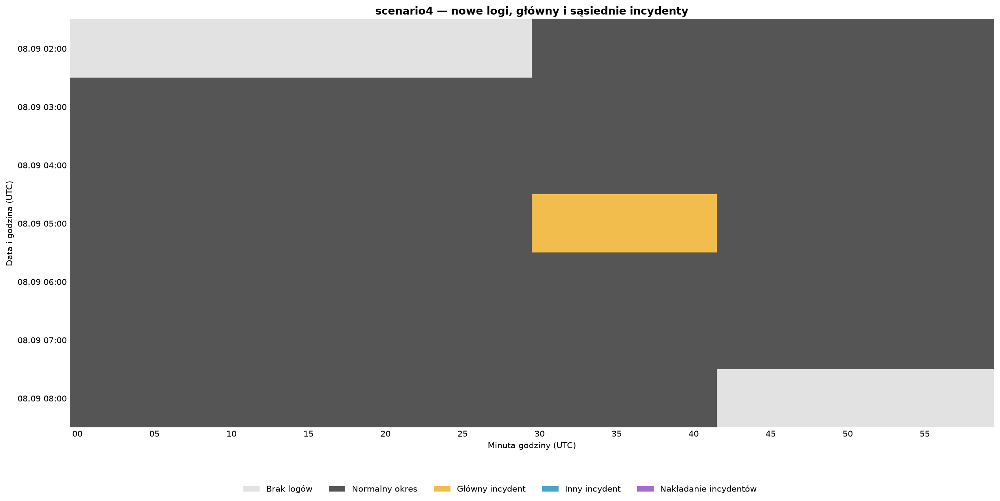

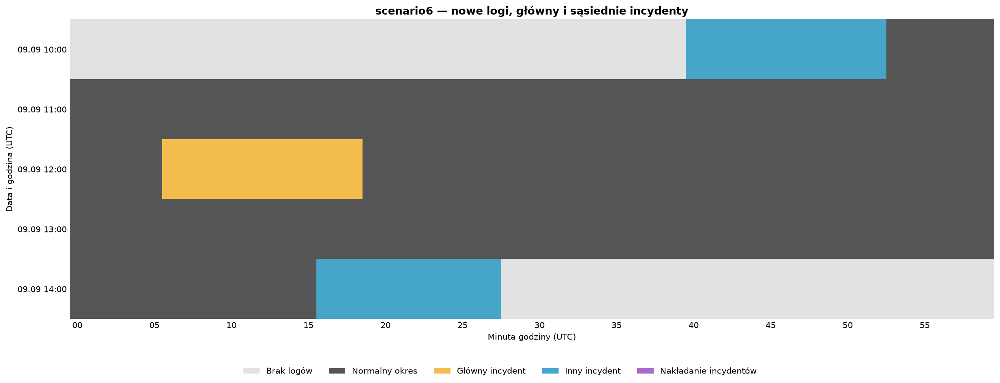

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

CALENDAR_COLORS = [
    "#E2E2E2",  # brak wiadomości
    "#555555",  # zwykłe logi
    "#F3BD4D",  # główny incydent
    "#45A6C9",  # inny incydent
    "#A66BCC",  # nakładające się incydenty
]

def plot_new_incident_calendar(case, save=True):

    info = NEW_CASE_DATA[case]
    df = info["full_df"]

    main_start = info["incident_start"]
    main_end = info["incident_end"]

    others = NEW_EVENT_WINDOWS[case]["other"]

    view_start = df["timestamp"].min().floor("h")
    view_end = df["timestamp"].max().ceil("h")

    hours = pd.date_range(
        view_start, view_end,
        freq="h", inclusive="left"
    )

    grid = np.zeros((len(hours), 60), dtype=np.int8)

    # Minuty z rzeczywistymi wiadomościami
    active_minutes = set(
        df["timestamp"].dt.floor("min")
    )

    for i, hour in enumerate(hours):
        for minute_number in range(60):

            minute = hour + pd.Timedelta(
                minutes=minute_number
            )
            minute_end = minute + pd.Timedelta(minutes=1)

            active = minute in active_minutes

            primary = (
                minute < main_end
                and minute_end > main_start
            )

            secondary = any(
                minute < event["end"]
                and minute_end > event["start"]
                for event in others
            )

            if primary and secondary:
                code = 4
            elif primary:
                code = 2
            elif secondary:
                code = 3
            elif active:
                code = 1
            else:
                code = 0

            grid[i, minute_number] = code

    fig, ax = plt.subplots(
        figsize=(17, max(4, 1.0 * len(hours) + 1.5)),
        dpi=150
    )

    cmap = ListedColormap(CALENDAR_COLORS)
    norm = BoundaryNorm(
        np.arange(-0.5, 5.5, 1), cmap.N
    )

    ax.imshow(
        grid,
        cmap=cmap,
        norm=norm,
        aspect="auto",
        interpolation="nearest"
    )

    ax.set_xticks(np.arange(0, 60, 5))
    ax.set_xticklabels(
        [f"{x:02d}" for x in range(0, 60, 5)]
    )

    ax.set_yticks(range(len(hours)))
    ax.set_yticklabels([
        h.strftime("%d.%m %H:00")
        for h in hours
    ])

    ax.set_xlabel("Minuta godziny (UTC)")
    ax.set_ylabel("Data i godzina (UTC)")

    ax.set_title(
        f"{case} — nowe logi, główny i sąsiednie incydenty",
        fontsize=13,
        fontweight="bold"
    )

    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.legend(
        handles=[
            Patch(facecolor=CALENDAR_COLORS[0],
                  label="Brak logów"),
            Patch(facecolor=CALENDAR_COLORS[1],
                  label="Normalny okres"),
            Patch(facecolor=CALENDAR_COLORS[2],
                  label="Główny incydent"),
            Patch(facecolor=CALENDAR_COLORS[3],
                  label="Inny incydent"),
            Patch(facecolor=CALENDAR_COLORS[4],
                  label="Nakładanie incydentów"),
        ],
        loc="lower center",
        ncol=5,
        frameon=False,
    )

    fig.tight_layout(rect=(0, 0.08, 1, 1))

    if save:
        output_dir = (
            OLD_RESULTS / "evaluation_3h" / "calendars"
        )
        output_dir.mkdir(parents=True, exist_ok=True)

        fig.savefig(
            output_dir / f"{case}_ground_truth.png",
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        fig.savefig(
            output_dir / f"{case}_ground_truth.svg",
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()
    plt.close(fig)


# Na początek scenariusz, który znamy najlepiej.
plot_new_incident_calendar("scenario4")

# Można też od razu sprawdzić scenariusz
# zawierający dodatkowe incydenty:
plot_new_incident_calendar("scenario6")

In [13]:
import pandas as pd
import numpy as np


def canonical_log_keys(df):
    # Wymuszamy identyczną jednostkę czasu po obu stronach.
    ts = (
        pd.to_datetime(df["timestamp"], utc=True)
        .astype("datetime64[ns, UTC]")
        .reset_index(drop=True)
    )

    return pd.DataFrame({
        "timestamp": ts,
        "namespace": (
            df["namespace"]
            .fillna("<NA>")
            .astype(str)
            .reset_index(drop=True)
        ),
        "message": (
            df["message"]
            .fillna("")
            .astype(str)
            .reset_index(drop=True)
        ),
    })


def count_matching_rows(old_keys, new_keys):
    old_hash = pd.util.hash_pandas_object(
        old_keys, index=False
    ).to_numpy(dtype=np.uint64)

    new_hash = pd.util.hash_pandas_object(
        new_keys, index=False
    ).to_numpy(dtype=np.uint64)

    old_unique, old_counts = np.unique(
        old_hash, return_counts=True
    )
    new_unique, new_counts = np.unique(
        new_hash, return_counts=True
    )

    _, old_idx, new_idx = np.intersect1d(
        old_unique,
        new_unique,
        assume_unique=True,
        return_indices=True,
    )

    return int(
        np.minimum(
            old_counts[old_idx],
            new_counts[new_idx]
        ).sum()
    )


rows = []

for case in sorted(
    NEW_CASE_DATA,
    key=lambda s: int(s.replace("scenario", ""))
):
    old_df = OLD_CASE_DATA[case]["full_df"]
    new_df = NEW_CASE_DATA[case]["full_df"]

    old = canonical_log_keys(old_df)
    new = canonical_log_keys(new_df)

    # Porównujemy daty jako wartości, nie jako hasze
    # różnych reprezentacji dat.
    old_seconds = old["timestamp"].dt.floor("s")
    new_seconds = new["timestamp"].dt.floor("s")

    seconds_match = count_matching_rows(
        pd.DataFrame({"second": old_seconds}),
        pd.DataFrame({"second": new_seconds}),
    )

    full_match = count_matching_rows(old, new)

    rows.append({
        "scenario": case,
        "old_timestamp_dtype": str(old_df["timestamp"].dtype),
        "new_timestamp_dtype": str(new_df["timestamp"].dtype),
        "old_logs": len(old),
        "new_logs": len(new),
        "matching_seconds_%": round(
            100 * seconds_match / max(len(old), 1), 2
        ),
        "matching_full_logs_%": round(
            100 * full_match / max(len(old), 1), 2
        ),
        "additional_logs": len(new) - full_match,
    })

FIXED_OVERLAP = pd.DataFrame(rows)

display(FIXED_OVERLAP)

,scenario,old_timestamp_dtype,new_timestamp_dtype,old_logs,new_logs,matching_seconds_%,matching_full_logs_%,additional_logs
0,scenario1,"datetime64[us, UTC]","datetime64[ns, UTC]",6580,26858,100.00,93.60,20699
1,scenario2,"datetime64[us, UTC]","datetime64[ns, UTC]",7281,27651,100.00,93.67,20831
2,scenario3,"datetime64[us, UTC]","datetime64[ns, UTC]",8014,57081,100.00,93.44,49593
3,scenario4,"datetime64[us, UTC]","datetime64[ns, UTC]",48359,76732,100.00,93.57,31483
4,scenario5,"datetime64[us, UTC]","datetime64[ns, UTC]",25017,41251,100.00,93.49,17862
5,scenario6,"datetime64[us, UTC]","datetime64[ns, UTC]",6579,312362,100.00,93.37,306219
6,scenario7,"datetime64[us, UTC]","datetime64[ns, UTC]",6049,27221,100.00,93.54,21563
7,scenario8,"datetime64[us, UTC]","datetime64[ns, UTC]",59274,89713,100.00,93.67,34192
8,scenario9,"datetime64[us, UTC]","datetime64[ns, UTC]",8355,22788,93.17,86.88,15529
9,scenario10,"datetime64[us, UTC]","datetime64[ns, UTC]",20414,19253,76.89,71.80,4596


In [6]:
import json
import re
from pathlib import Path

SYMBOLS = [
    "parse_full_by_namespace",
    "parse_full_by_namespace_spell",
    "parse_full_by_namespace_iplom",
    "parse_full_by_namespace_ael",
    "SpellWithTrainingIds",
    "IPLoMUTF8",
    "AELMemoryParser",
    "build_namespace_buckets",
    "make_models",
]

SEARCH_ROOTS = [
    Path.cwd(),
    AIOPS_ROOT,
    OLD_RESULTS.parent,
]

found = []
seen_files = set()

for root in SEARCH_ROOTS:
    for path in root.rglob("*.ipynb"):

        if ".ipynb_checkpoints" in path.parts:
            continue

        resolved = path.resolve()
        if resolved in seen_files:
            continue

        seen_files.add(resolved)

        try:
            with path.open("r", encoding="utf-8") as f:
                notebook = json.load(f)
        except (OSError, ValueError):
            continue

        definitions = []

        for cell_index, cell in enumerate(
            notebook.get("cells", [])
        ):
            if cell.get("cell_type") != "code":
                continue

            source = cell.get("source", "")
            if isinstance(source, list):
                source = "".join(source)

            for symbol in SYMBOLS:
                pattern = rf"^\s*(?:def|class)\s+{symbol}\b"

                if re.search(pattern, source, re.MULTILINE):
                    definitions.append(
                        f"{symbol} (komórka {cell_index + 1})"
                    )

        if definitions:
            found.append({
                "notebook": str(path),
                "definitions_count": len(definitions),
                "definitions": ", ".join(definitions),
            })

if found:
    display(
        pd.DataFrame(found)
        .sort_values(
            "definitions_count",
            ascending=False,
        )
    )
else:
    print("Nie znaleziono definicji w notebookach.")

print("\nZnaleziono notebooków z implementacjami:", len(found))

,notebook,definitions_count,definitions
0,C:\Users\kzieba\aiops\notebooks\Different_name...,9,"parse_full_by_namespace (komórka 4), build_nam..."
1,C:\Users\kzieba\aiops\notebooks\incident_analy...,1,make_models (komórka 10)
2,C:\Users\kzieba\aiops\notebooks\incident_analy...,1,make_models (komórka 21)
3,C:\Users\kzieba\aiops\notebooks\incident_analy...,1,make_models (komórka 17)
4,C:\Users\kzieba\aiops\notebooks\incident_analy...,1,make_models (komórka 20)



Znaleziono notebooków z implementacjami: 5


In [5]:
import ast
import json
import inspect
from pathlib import Path

REQUIRED_FUNCTIONS = {
    "parse_full_by_namespace",
    "parse_full_by_namespace_spell",
    "parse_full_by_namespace_iplom",
    "parse_full_by_namespace_ael",
    "build_namespace_buckets",
}

NOTEBOOK_ROOT = AIOPS_ROOT / "notebooks"


def read_python_cells(path):
    with path.open("r", encoding="utf-8") as f:
        nb = json.load(f)

    parsed = []
    skipped = []

    for i, cell in enumerate(nb.get("cells", []), 1):
        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)

        try:
            parsed.append((i, ast.parse(source)))
        except SyntaxError:
            skipped.append(i)

    return parsed, skipped


# Szukamy oryginalnej implementacji.
candidates = []

for path in NOTEBOOK_ROOT.rglob("*.ipynb"):

    if ".ipynb_checkpoints" in path.parts:
        continue

    cells, skipped = read_python_cells(path)

    names = {
        node.name
        for _, tree in cells
        for node in tree.body
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef),
        )
    }

    coverage = len(REQUIRED_FUNCTIONS & names)

    if coverage:
        candidates.append((coverage, path, cells, skipped))

if not candidates:
    raise RuntimeError("Nie znaleziono implementacji parserów.")

candidates.sort(key=lambda item: item[0], reverse=True)

coverage, source_path, cells, skipped = candidates[0]

if coverage != len(REQUIRED_FUNCTIONS):
    raise RuntimeError(
        f"Znaleziono tylko {coverage}/{len(REQUIRED_FUNCTIONS)} "
        f"wymaganych funkcji: {source_path}"
    )

print("Notebook źródłowy:", source_path)
print("Komórki z niepoprawną składnią Python:", skipped)

# Zbieramy WYŁĄCZNIE importy oraz definicje.
# Pomijamy instrukcje wykonywane na najwyższym poziomie,
# np. wczytywanie logów, trening i generowanie wykresów.

future_imports = []
imports = []
definitions = []

for cell_nr, tree in cells:

    for node in tree.body:

        if isinstance(node, ast.ImportFrom) and node.module == "__future__":
            future_imports.append(node)

        elif isinstance(node, (ast.Import, ast.ImportFrom)):
            imports.append(node)

        elif isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef),
        ):
            definitions.append(node)


# Importy wykonujemy osobno, żeby łatwo zdiagnozować
# ewentualną brakującą bibliotekę.
for node in future_imports + imports:

    module = ast.fix_missing_locations(
        ast.Module(body=[node], type_ignores=[])
    )

    exec(
        compile(module, str(source_path), "exec"),
        globals(),
    )


# Klasy i funkcje w kolejności ze starego notebooka.
module = ast.fix_missing_locations(
    ast.Module(body=definitions, type_ignores=[])
)

exec(
    compile(module, str(source_path), "exec"),
    globals(),
)

print("\nZAŁADOWANE FUNKCJE:")

for name in sorted(REQUIRED_FUNCTIONS):
    func = globals().get(name)

    if not callable(func):
        raise RuntimeError(f"Nie załadowano: {name}")

    print(f"✓ {name}{inspect.signature(func)}")

print("\nZAŁADOWANE KLASY PARSERÓW:")

for name in [
    "SpellWithTrainingIds",
    "IPLoMUTF8",
    "AELMemoryParser",
]:
    obj = globals().get(name)
    print("✓" if inspect.isclass(obj) else "—", name)

print("\nDefinicje załadowane. Parsowanie nie zostało uruchomione.")

Notebook źródłowy: C:\Users\kzieba\aiops\notebooks\Different_namespaces.ipynb
Komórki z niepoprawną składnią Python: []

ZAŁADOWANE FUNKCJE:
✓ build_namespace_buckets(parsed_df, window_size='5min', history_minutes=30)
✓ parse_full_by_namespace(full_df)
✓ parse_full_by_namespace_ael(full_df)
✓ parse_full_by_namespace_iplom(full_df)
✓ parse_full_by_namespace_spell(full_df)

ZAŁADOWANE KLASY PARSERÓW:
✓ SpellWithTrainingIds
✓ IPLoMUTF8
✓ AELMemoryParser

Definicje załadowane. Parsowanie nie zostało uruchomione.


In [16]:
import inspect

for name in sorted(REQUIRED_FUNCTIONS):
    func = globals()[name]

    print("\n", "=" * 65)
    print(name)
    print("Signature:", inspect.signature(func))

    try:
        closure = inspect.getclosurevars(func)
        missing = sorted(closure.unbound)

        if missing:
            print("Potencjalne niezdefiniowane nazwy:", missing[:30])
    except Exception:
        pass


build_namespace_buckets
Signature: (parsed_df, window_size='5min', history_minutes=30)
Potencjalne niezdefiniowane nazwy: ['DataFrame', 'Timedelta', 'append', 'copy', 'dt', 'floor', 'get', 'groupby', 'is_integer', 'sort_values', 'tolist', 'update']

parse_full_by_namespace
Signature: (full_df)
Potencjalne niezdefiniowane nazwy: ['DataFrame', 'add_log_message', 'append', 'clusters', 'copy', 'drain', 'groupby', 'index', 'replace', 'reset_index']

parse_full_by_namespace_ael
Signature: (full_df)
Potencjalne niezdefiniowane nazwy: ['DataFrame', 'RAW_ROOT', 'TemporaryDirectory', 'append', 'copy', 'groupby', 'index', 'mkdir', 'parent', 'parse', 'replace', 'reset_index', 'strip', 'training_event_ids', 'write']

parse_full_by_namespace_iplom
Signature: (full_df)
Potencjalne niezdefiniowane nazwy: ['DataFrame', 'RAW_ROOT', 'TemporaryDirectory', 'any', 'append', 'astype', 'copy', 'df_log', 'groupby', 'index', 'isna', 'mkdir', 'parent', 'parse', 'replace', 'reset_index', 'sort_values', 'strip', 

In [7]:
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    matthews_corrcoef,
    f1_score,
)

RAW_ROOT = OLD_RESULTS.parent / "raw"

EVAL_DIR = OLD_RESULTS / "evaluation_3h"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

PARSER = "IPLoM"
WINDOW = "10min"
MODEL_NAME = "Random Forest"

FEATURES18 = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
    "unique_rate",
    "single_occurrence_rate",
    "dominant_share",
    "template_entropy",
    "novel_template_rate",
    "template_set_change",
    "js_divergence",
    "total_logs_z",
    "unique_templates_z",
    "single_occurrence_templates_z",
    "template_entropy_z",
    "max_template_enrichment",
    "mean_top3_enrichment",
    "templates_enriched_5x",
    "templates_enriched_10x",
]

if not callable(globals().get("make_models")):
    raise RuntimeError(
        "Brakuje make_models(). "
        "Trzeba załadować tę funkcję ze starego notebooka."
    )

model_definitions = make_models()
print("Model:", model_definitions[MODEL_NAME])

old_dataset = (
    checkpoint["parsers"][PARSER]["window_results"][
        (WINDOW, "full", MODEL_NAME)
    ]["dataset"]
    .copy()
    .reset_index(drop=True)
)

X_old = (
    old_dataset[FEATURES18]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

y_old = old_dataset["is_incident"].astype(int).to_numpy()
cases_old = old_dataset["case"].astype(str).to_numpy()

RF_MODELS = {}
reconstructed = np.full(len(y_old), -1, dtype=int)

for test_case in sorted(set(cases_old)):

    train_mask = cases_old != test_case
    test_mask = cases_old == test_case

    clf = clone(model_definitions[MODEL_NAME])

    clf.fit(
        X_old[train_mask],
        y_old[train_mask],
    )

    reconstructed[test_mask] = clf.predict(
        X_old[test_mask]
    ).astype(int)

    RF_MODELS[test_case] = clf

# Porównujemy ze starym pełnym benchmarkiem.
old_prediction_path = (
    OLD_RESULTS
    / "benchmark_all_ranked"
    / "predictions"
    / "IPLoM__10min__18_features__Random_Forest.npz"
)

with np.load(old_prediction_path, allow_pickle=True) as saved:
    original_predictions = saved["prediction"].astype(int)
    original_cases = saved["cases"].astype(str)
    original_targets = saved["target"].astype(int)

if (
    not np.array_equal(cases_old, original_cases)
    or not np.array_equal(y_old, original_targets)
):
    raise RuntimeError(
        "Stary dataset ma inną kolejność lub etykiety "
        "niż zapisane predykcje."
    )

agreement = np.mean(
    reconstructed == original_predictions
)

print("\nZGODNOŚĆ ODTWORZONYCH MODELI")
print(f"Zgodność predykcji: {agreement:.2%}")

print(
    "Stare MCC:",
    round(
        matthews_corrcoef(
            y_old, original_predictions
        ), 4
    )
)

print(
    "Odtworzone MCC:",
    round(
        matthews_corrcoef(
            y_old, reconstructed
        ), 4
    )
)

if agreement != 1.0:
    raise RuntimeError(
        "Nie odtworzyliśmy dokładnie poprzedniego modelu. "
        "Nie uruchamiaj jeszcze inferencji na nowych logach."
    )

model_dir = EVAL_DIR / "reconstructed_models"
model_dir.mkdir(exist_ok=True)

for case, clf in RF_MODELS.items():
    joblib.dump(
        clf,
        model_dir / f"IPLoM_10min_RF_18_{case}.joblib"
    )

print("\nOK — odtworzone klasyfikatory zapisane lokalnie.")

Model: RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)


NameError: name 'checkpoint' is not defined

In [20]:
import pandas as pd
import joblib

print("Typ wyniku parsera:", type(parsed).__name__)

# Pokazujemy tylko strukturę, bez treści logów.
def describe_result(obj, name="result", depth=0):
    if depth > 3:
        return

    if isinstance(obj, pd.DataFrame):
        print(
            f"{name}: DataFrame, "
            f"shape={obj.shape}, "
            f"columns={list(obj.columns)}"
        )
    elif isinstance(obj, dict):
        print(f"{name}: dict, keys={list(obj.keys())[:20]}")
        for key, value in obj.items():
            describe_result(value, f"{name}[{key!r}]", depth + 1)
    elif isinstance(obj, (tuple, list)):
        print(f"{name}: {type(obj).__name__}, len={len(obj)}")
        for i, value in enumerate(obj[:10]):
            describe_result(value, f"{name}[{i}]", depth + 1)
    else:
        print(f"{name}: {type(obj).__name__}")


describe_result(parsed)


def extract_parsed_dataframe(result, expected_rows):

    required = {"timestamp", "namespace", "template_id"}
    frames = []

    def collect(obj, depth=0):
        if depth > 4:
            return

        if isinstance(obj, pd.DataFrame):
            if required.issubset(obj.columns):
                frames.append(obj)

        elif isinstance(obj, dict):
            for value in obj.values():
                collect(value, depth + 1)

        elif isinstance(obj, (tuple, list)):
            for value in obj[:100]:
                collect(value, depth + 1)

    collect(result)

    # Preferujemy jeden kompletny DataFrame.
    complete = [
        df for df in frames
        if len(df) == expected_rows
    ]

    if len(complete) == 1:
        return complete[0].copy()

    # Alternatywnie parser może zwracać osobny
    # DataFrame dla każdego namespace'u.
    if not complete and frames and sum(map(len, frames)) == expected_rows:
        return (
            pd.concat(frames, ignore_index=True)
            .sort_values("timestamp", kind="stable")
            .reset_index(drop=True)
        )

    raise ValueError(
        "Nie udało się jednoznacznie wybrać "
        "DataFrame z wyniku parsera. "
        f"Znalezione rozmiary: {[len(df) for df in frames]}, "
        f"oczekiwane: {expected_rows}."
    )


parsed = extract_parsed_dataframe(
    parsed,
    expected_rows=len(NEW_CASE_DATA["scenario1"]["full_df"]),
)

print("\nPoprawnie rozpakowany wynik:")
print("Wiersze:", len(parsed))
print("Kolumny:", list(parsed.columns))

# Zachowujemy już obliczony wynik scenario1.
joblib.dump(
    parsed,
    PARSED_DIR / "IPLoM_scenario1.joblib",
    compress=3,
)

print("✓ Parsowanie scenario1 zapisane w cache.")

Typ wyniku parsera: tuple
result: tuple, len=2
result[0]: DataFrame, shape=(26858, 4), columns=['timestamp', 'message', 'namespace', 'template_id']
result[1]: DataFrame, shape=(1, 2), columns=['logs', 'templates']

Poprawnie rozpakowany wynik:
Wiersze: 26858
Kolumny: ['timestamp', 'message', 'namespace', 'template_id']
✓ Parsowanie scenario1 zapisane w cache.


In [22]:
from pathlib import Path
from sklearn.metrics import confusion_matrix
import gc

PARSED_DIR = EVAL_DIR / "parsed_cache"
FEATURE_DIR = EVAL_DIR / "feature_cache"

PARSED_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_DIR.mkdir(parents=True, exist_ok=True)


def overlap_with_interval(bucket_start, bucket_end, start, end):
    return (
        (bucket_start < end)
        & (bucket_end > start)
    )


def evaluate_binary(actual, predicted, valid=None):
    if valid is None:
        valid = np.ones(len(actual), dtype=bool)

    y = np.asarray(actual)[valid]
    p = np.asarray(predicted)[valid]

    if len(y) == 0:
        return {
            "F1": np.nan, "MCC": np.nan,
            "TP": 0, "FP": 0, "FN": 0, "TN": 0
        }

    tn, fp, fn, tp = confusion_matrix(
        y, p, labels=[0, 1]
    ).ravel()

    return {
        "F1": f1_score(y, p, zero_division=0),
        "MCC": matthews_corrcoef(y, p),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


NEW_PREDICTIONS = {}
evaluation_rows = []

scenario_order = sorted(
    NEW_CASE_DATA,
    key=lambda name: int(name.replace("scenario", ""))
)

for case in scenario_order:

    print(f"\n{'=' * 70}")
    print("Przetwarzanie:", case, flush=True)

    parsed_path = PARSED_DIR / f"IPLoM_{case}.joblib"
    feature_path = FEATURE_DIR / f"IPLoM_10min_{case}.joblib"

    if feature_path.exists():

        buckets = joblib.load(feature_path)
        print("  Cechy z cache.")

    else:

        if parsed_path.exists():

            parsed = joblib.load(parsed_path)
            print("  Parsowanie z cache.")

        else:

            print("  Parsowanie nowych logów...", flush=True)

            parser_result = parse_full_by_namespace_iplom(
                NEW_CASE_DATA[case]["full_df"]
            )

            parsed = extract_parsed_dataframe(
                parser_result,
                expected_rows=len(NEW_CASE_DATA[case]["full_df"]),
            )

            required = {"timestamp", "template_id"}

            if not required.issubset(parsed.columns):
                raise ValueError(
                    f"{case}: brakuje kolumn "
                    f"{required - set(parsed.columns)}"
                )

            if len(parsed) != len(
                NEW_CASE_DATA[case]["full_df"]
            ):
                raise ValueError(
                    f"{case}: parser zmienił liczbę rekordów"
                )

            joblib.dump(
                parsed, parsed_path, compress=3
            )

        print("  Obliczanie cech...", flush=True)

        buckets = build_namespace_buckets(
            parsed,
            window_size=WINDOW,
            history_minutes=30,
        )

        joblib.dump(
            buckets, feature_path, compress=3
        )

        del parsed
        gc.collect()

    missing_columns = set(FEATURES18) - set(buckets.columns)

    if missing_columns:
        raise ValueError(
            f"{case}: brak cech: {missing_columns}"
        )

    buckets = buckets.copy()

    buckets["timestamp"] = pd.to_datetime(
        buckets["timestamp"], utc=True
    )

    if "bucket_end" in buckets.columns:
        buckets["bucket_end"] = pd.to_datetime(
            buckets["bucket_end"], utc=True
        )
    else:
        buckets["bucket_end"] = (
            buckets["timestamp"]
            + pd.Timedelta(WINDOW)
        )

    X_new = (
        buckets[FEATURES18]
        .apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    # Dokładnie ten model, który był trenowany
    # na pozostałych 10 STARYCH scenariuszach.
    model = RF_MODELS[case]

    buckets["prediction"] = (
        model.predict(X_new).astype(int)
    )

    primary = NEW_EVENT_WINDOWS[case]["primary"]
    others = NEW_EVENT_WINDOWS[case]["other"]

    bucket_start = buckets["timestamp"]
    bucket_end = buckets["bucket_end"]

    main_overlap = overlap_with_interval(
        bucket_start,
        bucket_end,
        primary["start"],
        primary["end"],
    )

    other_overlap = pd.Series(
        False, index=buckets.index
    )

    for event in others:
        other_overlap |= overlap_with_interval(
            bucket_start,
            bucket_end,
            event["start"],
            event["end"],
        )

    buckets["label_primary"] = (
        main_overlap.astype(int)
    )

    buckets["label_all_known"] = (
        (main_overlap | other_overlap).astype(int)
    )

    buckets["overlaps_other_incident"] = (
        other_overlap
    )

    # Primary-only: pomijamy buckety, które
    # nakładają się na inne znane incydenty.
    valid_primary = ~other_overlap.to_numpy()

    primary_score = evaluate_binary(
        buckets["label_primary"],
        buckets["prediction"],
        valid=valid_primary,
    )

    all_score = evaluate_binary(
        buckets["label_all_known"],
        buckets["prediction"],
    )

    for mode, score in [
        ("primary_only", primary_score),
        ("all_known", all_score),
    ]:
        evaluation_rows.append({
            "scenario": case,
            "evaluation": mode,
            "parser": PARSER,
            "window": WINDOW,
            "model": MODEL_NAME,
            "variant": "18 features",
            "n_buckets": len(buckets),
            **score,
        })

    NEW_PREDICTIONS[case] = buckets[
        [
            "timestamp",
            "bucket_end",
            "prediction",
            "label_primary",
            "label_all_known",
            "overlaps_other_incident",
        ]
    ].copy()

    print(
        f"  Buckety: {len(buckets)} | "
        f"Primary MCC={primary_score['MCC']:.3f}, "
        f"F1={primary_score['F1']:.3f} | "
        f"All-known MCC={all_score['MCC']:.3f}, "
        f"F1={all_score['F1']:.3f}",
        flush=True,
    )

    del buckets, X_new
    gc.collect()


NEW_EVALUATION = pd.DataFrame(evaluation_rows)

display(
    NEW_EVALUATION[
        [
            "scenario", "evaluation",
            "F1", "MCC",
            "TP", "FP", "FN", "TN",
        ]
    ].round(4)
)

NEW_EVALUATION.to_csv(
    EVAL_DIR / "IPLoM_10min_RF_18_scores.csv",
    index=False,
)

joblib.dump(
    NEW_PREDICTIONS,
    EVAL_DIR / "IPLoM_10min_RF_18_predictions.joblib",
    compress=3,
)


Przetwarzanie: scenario1
  Parsowanie z cache.
  Obliczanie cech...



KeyboardInterrupt



In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Patch

CALENDAR_DIR = EVAL_DIR / "calendars_IPLoM_10min_RF_18"
CALENDAR_DIR.mkdir(parents=True, exist_ok=True)

# 0 brak danych, 1 TN, 2 FP, 3 FN, 4 TP
COLORS = [
    "#E0E0E0",
    "#505050",
    "#E34850",
    "#855BC5",
    "#FFFFFF",
]

cmap = ListedColormap(COLORS)
norm = BoundaryNorm(np.arange(-0.5, 5.5), cmap.N)


def plot_prediction_calendar_3h(case):

    data = NEW_PREDICTIONS[case].copy()
    data["timestamp"] = pd.to_datetime(
        data["timestamp"], utc=True
    )

    full = NEW_CASE_DATA[case]["full_df"]

    view_start = full["timestamp"].min().floor("h")
    view_end = full["timestamp"].max().ceil("h")

    hours = pd.date_range(
        view_start,
        view_end,
        freq="h",
        inclusive="left",
    )

    hour_lookup = {
        hour: i for i, hour in enumerate(hours)
    }

    grid = np.zeros((len(hours), 60), dtype=np.int8)

    for row in data.itertuples(index=False):

        actual = int(row.label_all_known)
        predicted = int(row.prediction)

        if actual == 0 and predicted == 0:
            code = 1
        elif actual == 0 and predicted == 1:
            code = 2
        elif actual == 1 and predicted == 0:
            code = 3
        else:
            code = 4

        # Bucket 10-minutowy zajmuje 10 pól.
        for offset in range(10):

            minute = (
                row.timestamp
                + pd.Timedelta(minutes=offset)
            )

            hour = minute.floor("h")

            if hour in hour_lookup:
                grid[
                    hour_lookup[hour],
                    minute.minute
                ] = code

    if not np.any(grid):
        raise RuntimeError(
            f"{case}: nie narysowano żadnych predykcji."
        )

    fig, ax = plt.subplots(
        figsize=(18, max(5, len(hours) * 0.9 + 2)),
        dpi=150,
    )

    ax.imshow(
        grid,
        cmap=cmap,
        norm=norm,
        aspect="auto",
        interpolation="nearest",
        origin="upper",
    )

    # Podświetlenie głównego i innych incydentów.
    events = (
        [NEW_EVENT_WINDOWS[case]["primary"]]
        + NEW_EVENT_WINDOWS[case]["other"]
    )

    for event in events:

        is_primary = event["type"] == "primary"

        color = (
            "#FFD166" if is_primary else "#40BBD0"
        )

        for i, hour in enumerate(hours):

            left = max(hour, event["start"])
            right = min(
                hour + pd.Timedelta(hours=1),
                event["end"],
            )

            if left >= right:
                continue

            x0 = (
                (left - hour).total_seconds() / 60
                - 0.5
            )

            x1 = (
                (right - hour).total_seconds() / 60
                - 0.5
            )

            ax.add_patch(
                Rectangle(
                    (x0, i - 0.5),
                    x1 - x0,
                    1,
                    facecolor=color,
                    alpha=0.22,
                    linewidth=0,
                    zorder=3,
                )
            )

            ax.vlines(
                [x0, x1],
                i - 0.5,
                i + 0.5,
                color=color,
                linewidth=1.2,
                zorder=4,
            )

    scores = NEW_EVALUATION.loc[
        (NEW_EVALUATION["scenario"] == case)
        & (NEW_EVALUATION["evaluation"] == "all_known")
    ].iloc[0]

    ax.set_title(
        f"{case.upper()} — IPLoM | 10min | "
        f"Random Forest | 18 features\n"
        f"F1={scores['F1']:.3f}  "
        f"MCC={scores['MCC']:.3f}  "
        f"TP={scores['TP']}  FP={scores['FP']}  "
        f"FN={scores['FN']}",
        fontsize=12,
        fontweight="bold",
        pad=12,
    )

    ax.set_xticks(np.arange(0, 60, 5))
    ax.set_xticklabels([
        f"{m:02d}" for m in range(0, 60, 5)
    ])

    ax.set_yticks(range(len(hours)))
    ax.set_yticklabels([
        h.strftime("%d.%m %H:00")
        for h in hours
    ])

    ax.set_xlabel("Minuta godziny (UTC)")
    ax.set_ylabel("Data i godzina (UTC)")
    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.legend(
        handles=[
            Patch(facecolor=COLORS[1], label="TN"),
            Patch(facecolor=COLORS[2], label="FP"),
            Patch(facecolor=COLORS[3], label="FN"),
            Patch(
                facecolor=COLORS[4],
                edgecolor="#888888",
                label="TP",
            ),
            Patch(facecolor=COLORS[0], label="Brak danych"),
            Patch(facecolor="#FFD166", alpha=0.5,
                  label="Główny incydent"),
            Patch(facecolor="#40BBD0", alpha=0.5,
                  label="Inny incydent"),
        ],
        loc="lower center",
        ncol=7,
        frameon=False,
        bbox_to_anchor=(0.5, 0.01),
    )

    fig.tight_layout(rect=(0, 0.08, 1, 1))

    filename = CALENDAR_DIR / f"{case}_calendar"

    fig.savefig(
        filename.with_suffix(".png"),
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    fig.savefig(
        filename.with_suffix(".svg"),
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()
    plt.close(fig)


for case in scenario_order:
    plot_prediction_calendar_3h(case)

In [ ]:
for mode in ["primary_only", "all_known"]:

    all_y = []
    all_p = []

    for case in scenario_order:

        data = NEW_PREDICTIONS[case]

        if mode == "primary_only":
            valid = ~data[
                "overlaps_other_incident"
            ].to_numpy()

            y = data["label_primary"].to_numpy()[valid]
            p = data["prediction"].to_numpy()[valid]

        else:
            y = data["label_all_known"].to_numpy()
            p = data["prediction"].to_numpy()

        all_y.append(y)
        all_p.append(p)

    overall = evaluate_binary(
        np.concatenate(all_y),
        np.concatenate(all_p),
    )

    print(f"\n{mode.upper()}")
    print(f"F1:  {overall['F1']:.4f}")
    print(f"MCC: {overall['MCC']:.4f}")
    print(
        f"TP={overall['TP']} | FP={overall['FP']} | "
        f"FN={overall['FN']} | TN={overall['TN']}"
    )

In [23]:
import joblib
from pathlib import Path

SAVE_DIR = OLD_RESULTS / "evaluation_3h"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Zapisujemy stan nowych danych i metadanych
SAVE_NAMES = [
    "NEW_CASE_DATA",
    "NEW_EVENT_WINDOWS",
    "SCENARIO_DIRS",
    "NEW_SUMMARY",
    "CORRECTED_WINDOWS",
    "OVERLAP_REPORT",
    "FIXED_OVERLAP",
    "FEATURES18",
    "PARSER",
    "WINDOW",
    "MODEL_NAME",
]

state = {
    name: globals()[name]
    for name in SAVE_NAMES
    if name in globals()
}

state_path = SAVE_DIR / "session_3h_latest.joblib"
temp_path = SAVE_DIR / "session_3h_latest.tmp"

joblib.dump(state, temp_path, compress=3)
temp_path.replace(state_path)

print("✓ Zapisano stan nowych danych:", state_path)

# 2. Zabezpieczamy wynik parsowania scenario1,
#    jeśli nie został jeszcze zapisany w cache.
parsed_dir = SAVE_DIR / "parsed_cache"
parsed_dir.mkdir(parents=True, exist_ok=True)

parsed_cache = parsed_dir / "IPLoM_scenario1.joblib"
raw_result_path = parsed_dir / "IPLoM_scenario1_raw_result.joblib"

if parsed_cache.exists():
    print("✓ Scenario1 — wynik parsowania już w cache.")
elif "parsed" in globals():
    try:
        joblib.dump(parsed, raw_result_path, compress=3)
        print("✓ Zapisano surowy wynik parsera scenario1.")
    except Exception as e:
        print("⚠ Nie udało się zapisać wyniku parsera:", e)
else:
    print("⚠ Brak wyniku parsera scenario1 w pamięci.")

# 3. Sprawdzamy zapisane modele
model_dir = SAVE_DIR / "reconstructed_models"
models = list(model_dir.glob("IPLoM_10min_RF_18_*.joblib"))

print(f"✓ Zapisanych modeli Random Forest: {len(models)}/11")
print("✓ Zapis sesji zakończony.")

✓ Zapisano stan nowych danych: C:\Users\kzieba\aiops_private\results\evaluation_3h\session_3h_latest.joblib
✓ Scenario1 — wynik parsowania już w cache.
✓ Zapisanych modeli Random Forest: 11/11
✓ Zapis sesji zakończony.


In [19]:
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import re
import gc

AIOPS_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "scenarios_logs_3h_trimmed").is_dir()
)

OLD_RESULTS = AIOPS_ROOT.parent / "aiops_private" / "results"
RAW_ROOT = OLD_RESULTS.parent / "raw"
EVAL_DIR = OLD_RESULTS / "evaluation_3h"

state = joblib.load(
    EVAL_DIR / "session_3h_latest.joblib"
)

globals().update(state)

FREQ_DIR = EVAL_DIR / "template_frequency_global"
FREQ_CACHE = FREQ_DIR / "signature_cache"
PARSED_CACHE = EVAL_DIR / "parsed_cache"

FREQ_DIR.mkdir(parents=True, exist_ok=True)
FREQ_CACHE.mkdir(parents=True, exist_ok=True)
PARSED_CACHE.mkdir(parents=True, exist_ok=True)

PARSER_FUNCTIONS = {
    "Drain3": "parse_full_by_namespace",
    "Spell": "parse_full_by_namespace_spell",
    "IPLoM": "parse_full_by_namespace_iplom",
    "AEL": "parse_full_by_namespace_ael",
}

SCENARIOS = sorted(
    NEW_CASE_DATA,
    key=lambda x: int(re.search(r"\d+", x).group())
)

print("Scenariusze:", len(SCENARIOS))
print("Namespace'y:", sorted(set().union(*[
    set(v["full_df"]["namespace"].unique())
    for v in NEW_CASE_DATA.values()
])))
print("Folder wyników:", FREQ_DIR)

Scenariusze: 11
Namespace'y: ['ingestion', 'integration', 'ml', 'monitoring', 'reporting', 'resolve']
Folder wyników: C:\Users\kzieba\aiops_private\results\evaluation_3h\template_frequency_global


In [20]:
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import re
import gc

AIOPS_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "scenarios_logs_3h_trimmed").is_dir()
)

OLD_RESULTS = AIOPS_ROOT.parent / "aiops_private" / "results"
RAW_ROOT = OLD_RESULTS.parent / "raw"
EVAL_DIR = OLD_RESULTS / "evaluation_3h"

state = joblib.load(
    EVAL_DIR / "session_3h_latest.joblib"
)

globals().update(state)

FREQ_DIR = EVAL_DIR / "template_frequency_global"
FREQ_CACHE = FREQ_DIR / "signature_cache"
PARSED_CACHE = EVAL_DIR / "parsed_cache"

FREQ_DIR.mkdir(parents=True, exist_ok=True)
FREQ_CACHE.mkdir(parents=True, exist_ok=True)
PARSED_CACHE.mkdir(parents=True, exist_ok=True)

PARSER_FUNCTIONS = {
    "Drain3": "parse_full_by_namespace",
    "Spell": "parse_full_by_namespace_spell",
    "IPLoM": "parse_full_by_namespace_iplom",
    "AEL": "parse_full_by_namespace_ael",
}

SCENARIOS = sorted(
    NEW_CASE_DATA,
    key=lambda x: int(re.search(r"\d+", x).group())
)

print("Scenariusze:", len(SCENARIOS))
print("Namespace'y:", sorted(set().union(*[
    set(v["full_df"]["namespace"].unique())
    for v in NEW_CASE_DATA.values()
])))
print("Folder wyników:", FREQ_DIR)

Scenariusze: 11
Namespace'y: ['ingestion', 'integration', 'ml', 'monitoring', 'reporting', 'resolve']
Folder wyników: C:\Users\kzieba\aiops_private\results\evaluation_3h\template_frequency_global


In [21]:
import ast
import json
import inspect
from pathlib import Path

REQUIRED_FUNCTIONS = {
    "parse_full_by_namespace",
    "parse_full_by_namespace_spell",
    "parse_full_by_namespace_iplom",
    "parse_full_by_namespace_ael",
    "build_namespace_buckets",
}

NOTEBOOK_ROOT = AIOPS_ROOT / "notebooks"

candidates = []

for path in NOTEBOOK_ROOT.rglob("*.ipynb"):

    if ".ipynb_checkpoints" in path.parts:
        continue

    try:
        with path.open("r", encoding="utf-8") as f:
            notebook = json.load(f)
    except (OSError, ValueError):
        continue

    parsed_cells = []
    definitions_found = set()

    for cell in notebook.get("cells", []):

        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        parsed_cells.append(tree)

        definitions_found.update(
            node.name
            for node in tree.body
            if isinstance(
                node,
                (ast.FunctionDef, ast.ClassDef)
            )
        )

    coverage = len(
        REQUIRED_FUNCTIONS & definitions_found
    )

    if coverage:
        candidates.append(
            (coverage, path, parsed_cells)
        )

if not candidates:
    raise RuntimeError(
        "Nie znaleziono notebooka z parserami."
    )

candidates.sort(key=lambda x: x[0], reverse=True)

coverage, source_path, parsed_cells = candidates[0]

if coverage != len(REQUIRED_FUNCTIONS):
    raise RuntimeError(
        f"Znaleziono tylko {coverage}/"
        f"{len(REQUIRED_FUNCTIONS)} funkcji."
    )

print("Ładowanie funkcji z:", source_path)

# Ładujemy importy oraz definicje funkcji i klas.
# Nie uruchamiamy starych eksperymentów.

imports = []
definitions = []

for tree in parsed_cells:
    for node in tree.body:

        if isinstance(
            node,
            (ast.Import, ast.ImportFrom)
        ):
            imports.append(node)

        elif isinstance(
            node,
            (ast.FunctionDef, ast.ClassDef)
        ):
            definitions.append(node)

# Importy
for node in imports:

    module = ast.fix_missing_locations(
        ast.Module(
            body=[node],
            type_ignores=[]
        )
    )

    exec(
        compile(module, str(source_path), "exec"),
        globals()
    )

# Funkcje i klasy
module = ast.fix_missing_locations(
    ast.Module(
        body=definitions,
        type_ignores=[]
    )
)

exec(
    compile(module, str(source_path), "exec"),
    globals()
)

print("\nZAŁADOWANE FUNKCJE:")

for name in sorted(REQUIRED_FUNCTIONS):

    func = globals().get(name)

    if not callable(func):
        raise RuntimeError(
            f"Nie udało się załadować: {name}"
        )

    print(
        f"✓ {name}{inspect.signature(func)}"
    )

print("\nZAŁADOWANE KLASY:")

for name in [
    "SpellWithTrainingIds",
    "IPLoMUTF8",
    "AELMemoryParser",
]:
    obj = globals().get(name)
    print(
        "✓" if inspect.isclass(obj) else "✗",
        name
    )

print("\nGotowe — parsery są dostępne.")

Ładowanie funkcji z: C:\Users\kzieba\aiops\notebooks\Different_namespaces.ipynb

ZAŁADOWANE FUNKCJE:
✓ build_namespace_buckets(parsed_df, window_size='5min', history_minutes=30)
✓ parse_full_by_namespace(full_df)
✓ parse_full_by_namespace_ael(full_df)
✓ parse_full_by_namespace_iplom(full_df)
✓ parse_full_by_namespace_spell(full_df)

ZAŁADOWANE KLASY:
✓ SpellWithTrainingIds
✓ IPLoMUTF8
✓ AELMemoryParser

Gotowe — parsery są dostępne.


In [3]:
import re
import pandas as pd
import joblib
import numpy as np
import gc

PARSERS_TO_RUN = ["Drain3", "Spell", "IPLoM", "AEL"]

TEMPLATE_TEXT_COLUMNS = [
    "EventTemplate",
    "event_template",
    "template_text",
    "template_mined",
    "log_template",
    "template",
]

# Maksymalna liczba wiadomości użytych do
# odtworzenia struktury pojedynczego template'u.
PATTERN_SAMPLE_SIZE = 500


def extract_parsed_frame(obj, expected_rows):

    required = {
        "timestamp", "namespace",
        "message", "template_id",
    }

    frames = []

    def search(value, depth=0):
        if depth > 5:
            return

        if isinstance(value, pd.DataFrame):
            if required.issubset(value.columns):
                frames.append(value)

        elif isinstance(value, dict):
            for item in value.values():
                search(item, depth + 1)

        elif isinstance(value, (list, tuple)):
            for item in value:
                search(item, depth + 1)

    search(obj)

    complete = [
        f for f in frames
        if len(f) == expected_rows
    ]

    if len(complete) == 1:
        return complete[0].copy().reset_index(drop=True)

    if not complete and frames:
        if sum(len(f) for f in frames) == expected_rows:
            return pd.concat(
                frames, ignore_index=True
            )

    raise ValueError(
        "Nie udało się jednoznacznie rozpakować parsera. "
        f"Rozmiary DataFrame: {[len(f) for f in frames]}, "
        f"oczekiwane: {expected_rows}"
    )


def canonical_pattern(text):
    text = " ".join(str(text).split())

    # Ujednolicamy popularne oznaczenia wildcardów.
    return re.sub(
        r"<(?:\*|VAR\d+|NUM|IP|ID)>",
        "<*>",
        text,
        flags=re.IGNORECASE,
    )


def infer_template_pattern(group):

    # Najpierw próbujemy wykorzystać rzeczywisty
    # szablon dostarczony przez parser.
    for col in TEMPLATE_TEXT_COLUMNS:

        if col not in group.columns:
            continue

        templates = (
            group[col]
            .dropna()
            .astype(str)
            .str.strip()
        )

        templates = templates[templates.ne("")]

        if not templates.empty:
            return (
                canonical_pattern(
                    templates.value_counts().index[0]
                ),
                "parser",
            )

    # Fallback: rekonstruujemy wzorzec ze
    # stałych i zmiennych pozycji tokenów.
    messages = (
        group["message"]
        .fillna("")
        .astype(str)
    )

    lengths = messages.str.count(r"\S+")

    modal_length = int(
        lengths.value_counts().index[0]
    )

    candidates = messages.loc[
        lengths == modal_length
    ]

    if candidates.empty or modal_length == 0:
        return "<EMPTY>", "inferred"

    if len(candidates) > PATTERN_SAMPLE_SIZE:

        positions = np.linspace(
            0,
            len(candidates) - 1,
            PATTERN_SAMPLE_SIZE,
            dtype=int,
        )

        candidates = candidates.iloc[positions]

    tokens = [
        text.split()
        for text in candidates
    ]

    pattern = []

    for pos in range(modal_length):

        first = tokens[0][pos]

        if all(row[pos] == first for row in tokens):
            pattern.append(first)
        else:
            pattern.append("<*>")

    return canonical_pattern(" ".join(pattern)), "inferred"


def make_signature_frame(parsed):

    parsed = parsed.reset_index(drop=True).copy()

    parsed["timestamp"] = pd.to_datetime(
        parsed["timestamp"], utc=True
    )

    parsed["_local_template"] = (
        parsed["template_id"].map(repr)
    )

    signatures = pd.Series(
        index=parsed.index,
        dtype="object",
    )

    methods = {"parser": 0, "inferred": 0}

    for _, group in parsed.groupby(
        ["namespace", "_local_template"],
        sort=False,
    ):

        pattern, method = infer_template_pattern(group)

        signatures.loc[group.index] = pattern
        methods[method] += 1

    if signatures.isna().any():
        raise ValueError(
            "Nie wszystkim wiadomościom przypisano wzorzec."
        )

    result = parsed[
        ["timestamp", "namespace"]
    ].copy()

    result["signature"] = signatures.to_numpy()

    return result, methods


# ===========================================
# PRZETWARZANIE CZTERECH PARSERÓW
# ===========================================

parser_progress = []

for parser in PARSERS_TO_RUN:

    func = globals().get(PARSER_FUNCTIONS[parser])

    if not callable(func):
        raise RuntimeError(
            f"Brakuje {PARSER_FUNCTIONS[parser]}. "
            "Uruchom wcześniej komórkę 14."
        )

    for case in SCENARIOS:

        signature_path = (
            FREQ_CACHE
            / f"{parser}__{case}__signature_v1.joblib"
        )

        if signature_path.exists():
            print(
                f"✓ {parser} / {case}: "
                "sygnatury z cache",
                flush=True,
            )
            continue

        parsed_path = (
            PARSED_CACHE / f"{parser}_{case}.joblib"
        )

        raw_path = (
            PARSED_CACHE
            / f"{parser}_{case}_raw_result.joblib"
        )

        expected = len(
            NEW_CASE_DATA[case]["full_df"]
        )

        if parsed_path.exists():
            result = joblib.load(parsed_path)
            print(f"{parser} / {case}: parser z cache")

        elif raw_path.exists():
            result = joblib.load(raw_path)
            print(f"{parser} / {case}: surowy wynik z cache")

        else:
            print(
                f"{parser} / {case}: "
                f"parsowanie {expected:,} logów...",
                flush=True,
            )

            result = func(
                NEW_CASE_DATA[case]["full_df"]
            )

        parsed = extract_parsed_frame(
            result, expected_rows=expected
        )

        if not parsed_path.exists():
            joblib.dump(
                parsed, parsed_path, compress=3
            )

        signatures, methods = make_signature_frame(parsed)

        joblib.dump(
            signatures,
            signature_path,
            compress=3,
        )

        parser_progress.append({
            "parser": parser,
            "case": case,
            "logs": len(signatures),
            "native_templates": methods["parser"],
            "inferred_templates": methods["inferred"],
        })

        print(
            f"  ✓ {len(signatures):,} logów | "
            f"szablony parsera: {methods['parser']} | "
            f"rekonstruowane: {methods['inferred']}",
            flush=True,
        )

        del result, parsed, signatures
        gc.collect()

print("\nGotowe. Zapisano sygnatury template'ów.")

✓ Drain3 / scenario1: sygnatury z cache
✓ Drain3 / scenario2: sygnatury z cache
✓ Drain3 / scenario3: sygnatury z cache
✓ Drain3 / scenario4: sygnatury z cache
✓ Drain3 / scenario5: sygnatury z cache
✓ Drain3 / scenario6: sygnatury z cache
✓ Drain3 / scenario7: sygnatury z cache
✓ Drain3 / scenario8: sygnatury z cache
✓ Drain3 / scenario9: sygnatury z cache
✓ Drain3 / scenario10: sygnatury z cache
✓ Drain3 / scenario11: sygnatury z cache
✓ Spell / scenario1: sygnatury z cache
✓ Spell / scenario2: sygnatury z cache
✓ Spell / scenario3: sygnatury z cache
✓ Spell / scenario4: sygnatury z cache
✓ Spell / scenario5: sygnatury z cache
✓ Spell / scenario6: sygnatury z cache
✓ Spell / scenario7: sygnatury z cache
✓ Spell / scenario8: sygnatury z cache
✓ Spell / scenario9: sygnatury z cache
✓ Spell / scenario10: sygnatury z cache
✓ Spell / scenario11: sygnatury z cache
✓ IPLoM / scenario1: sygnatury z cache
✓ IPLoM / scenario2: sygnatury z cache
✓ IPLoM / scenario3: sygnatury z cache
✓ IPLoM / 


PARSER: Drain3
Namespace: reporting | scenariusze: 10 | różne wzorce: 520


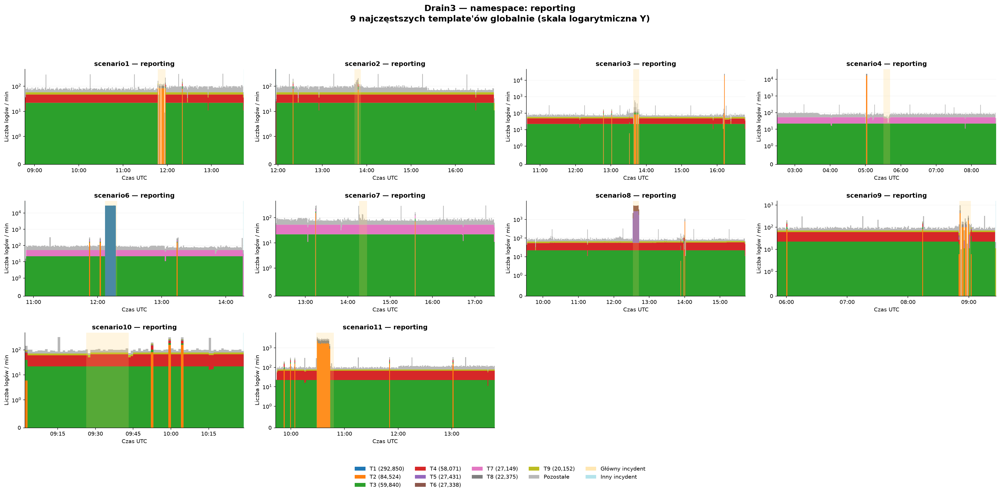


PARSER: Spell
Namespace: reporting | scenariusze: 10 | różne wzorce: 4903


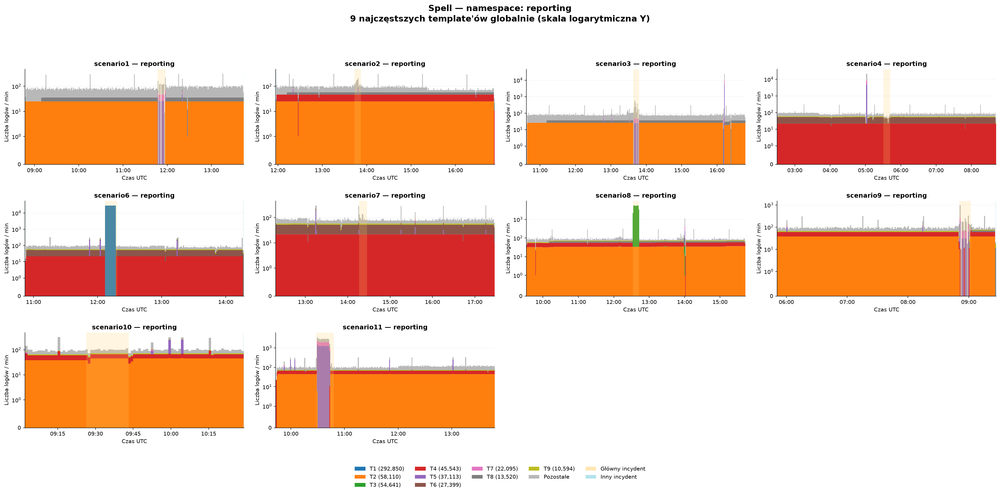


PARSER: IPLoM
Namespace: reporting | scenariusze: 10 | różne wzorce: 541


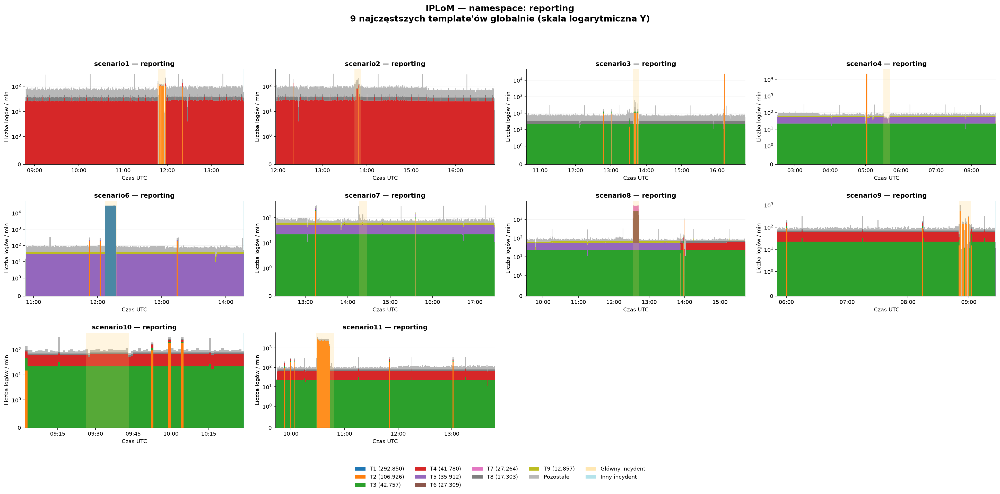


PARSER: AEL
Namespace: reporting | scenariusze: 10 | różne wzorce: 121


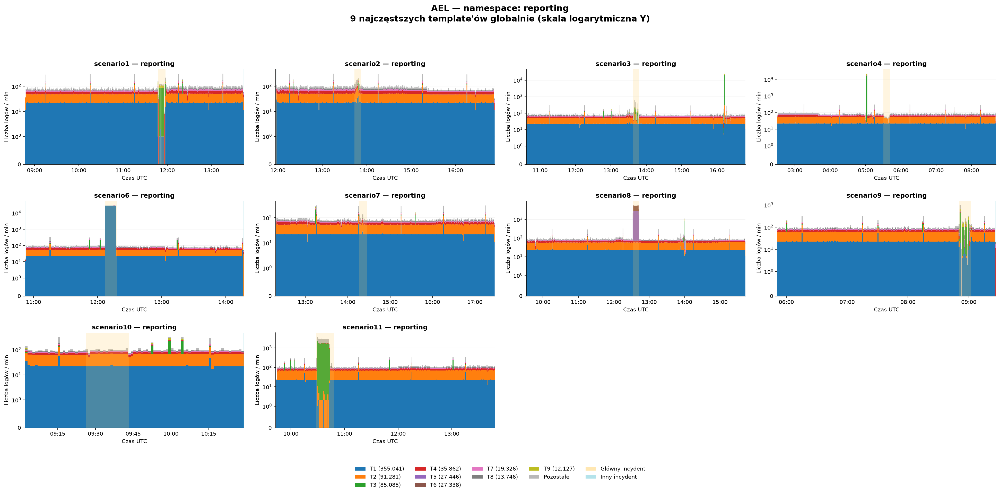


Wszystkie wykresy zapisano w: C:\Users\kzieba\aiops_private\results\evaluation_3h\template_frequency_global
Mapowanie T1–T9: C:\Users\kzieba\aiops_private\results\evaluation_3h\template_frequency_global\global_top9_template_mapping.csv


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from collections import Counter, defaultdict
from matplotlib.patches import Patch
from datetime import timezone

TOP_N = 9
SHOW_PLOTS = True

GLOBAL_COLORS = list(
    plt.get_cmap("tab10").colors[:TOP_N]
)

OTHER_COLOR = "#B8B8B8"

def safe_filename(text):
    return re.sub(r"[^A-Za-z0-9_-]+", "_", str(text))


GLOBAL_TEMPLATE_RANKINGS = []

for parser in PARSERS_TO_RUN:

    print(f"\n{'=' * 75}")
    print("PARSER:", parser)

    global_counts = Counter()
    presence = defaultdict(set)

    minute_data = {}
    namespace_ranges = {}
    namespace_cases = defaultdict(list)

    # =======================================
    # SUMOWANIE GLOBALNE
    # =======================================

    for case in SCENARIOS:

        df = joblib.load(
            FREQ_CACHE
            / f"{parser}__{case}__signature_v1.joblib"
        )

        # Wszystkie wystąpienia z danego scenariusza.
        freq = (
            df.groupby(["namespace", "signature"])
            .size()
        )

        for (namespace, signature), count in freq.items():
            global_counts[(namespace, signature)] += int(count)
            presence[(namespace, signature)].add(case)

        # Zakres czasowy każdego namespace'u.
        spans = df.groupby("namespace")["timestamp"].agg(
            ["min", "max"]
        )

        for namespace, row in spans.iterrows():

            namespace_ranges[(case, namespace)] = (
                row["min"], row["max"]
            )

            namespace_cases[namespace].append(case)

        # Częstotliwości w przedziałach 1-minutowych.
        minute_data[case] = (
            df.groupby([
                "namespace",
                pd.Grouper(key="timestamp", freq="1min"),
                "signature",
            ])
            .size()
            .rename("count")
            .reset_index()
        )

        del df

    # =======================================
    # ODDZIELNY WYKRES DLA NAMESPACE'U
    # =======================================

    for namespace, cases in sorted(
        namespace_cases.items()
    ):
        if namespace != "reporting":
            continue
        ranking = sorted(
            [
                (signature, count)
                for (ns, signature), count
                in global_counts.items()
                if ns == namespace
            ],
            key=lambda item: (-item[1], item[0]),
        )

        top9 = ranking[:TOP_N]

        top_lookup = {
            signature: f"T{i}"
            for i, (signature, _) in enumerate(top9, 1)
        }

        colors = {
            f"T{i}": GLOBAL_COLORS[i - 1]
            for i in range(1, TOP_N + 1)
        }

        colors["Other"] = OTHER_COLOR

        labels = [
            f"T{i}" for i in range(1, TOP_N + 1)
        ] + ["Other"]

        # Lokalna tabela: które wzorce są T1–T9.
        for rank, (signature, total) in enumerate(
            top9, 1
        ):
            GLOBAL_TEMPLATE_RANKINGS.append({
                "parser": parser,
                "namespace": namespace,
                "rank": f"T{rank}",
                "global_logs": total,
                "scenarios_present": len(
                    presence[(namespace, signature)]
                ),
                "template_pattern": signature,
            })

        print(
            f"Namespace: {namespace} | "
            f"scenariusze: {len(cases)} | "
            f"różne wzorce: {len(ranking)}"
        )

        ncols = 4
        nrows = 3
        
        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(26, 13),
            squeeze=False,
            dpi=150,
        )

        axes = axes.ravel()

        for idx, case in enumerate(cases):

            ax = axes[idx]

            part = minute_data[case].loc[
                minute_data[case]["namespace"] == namespace
            ].copy()

            part["series"] = (
                part["signature"]
                .map(top_lookup)
                .fillna("Other")
            )

            counts = (
                part.groupby(["timestamp", "series"])["count"]
                .sum()
                .unstack(fill_value=0)
            )

            first, last = namespace_ranges[
                (case, namespace)
            ]

            minutes = pd.date_range(
                first.floor("min"),
                last.floor("min"),
                freq="1min",
            )

            counts = counts.reindex(
                index=minutes,
                columns=labels,
                fill_value=0,
            )

            # Rysujemy skumulowany wykres z krokami
            # odpowiadającymi dokładnie jednej minucie.
            edges = minutes.append(
                pd.DatetimeIndex([
                    minutes[-1] + pd.Timedelta(minutes=1)
                ])
            )

            baseline = np.zeros(len(minutes), dtype=float)

            for label in labels:

                values = counts[label].to_numpy(dtype=float)

                if not values.any():
                    continue

                upper = baseline + values

                ax.fill_between(
                    edges,
                    np.r_[baseline, baseline[-1]],
                    np.r_[upper, upper[-1]],
                    step="post",
                    facecolor=colors[label],
                    linewidth=0,
                )

                baseline = upper

            # =================================
            # OKNA INCYDENTÓW
            # =================================

            if "NEW_EVENT_WINDOWS" in globals():

                event_info = NEW_EVENT_WINDOWS.get(case, {})

                main = event_info.get("primary")

                if main:
                    ax.axvspan(
                        main["start"], main["end"],
                        color="#FFD166",
                        alpha=0.20,
                        linewidth=0,
                    )

                for event in event_info.get("other", []):
                    ax.axvspan(
                        event["start"], event["end"],
                        color="#45B9CD",
                        alpha=0.12,
                        linewidth=0,
                    )

            ax.set_title(
                f"{case} — {namespace}",
                fontsize=12,
                fontweight="bold",
            )

            ax.set_ylabel("Liczba logów / min")
            ax.set_xlabel("Czas UTC")
            ax.set_yscale("symlog", linthresh=1, linscale=1)
            ax.set_ylim(bottom=0)
            
            ax.set_xlim(
                minutes[0],
                minutes[-1] + pd.Timedelta(minutes=1),
            )

            ax.xaxis.set_major_locator(
                mdates.AutoDateLocator(
                    minticks=3,
                    maxticks=7,
                    tz=timezone.utc,
                )
            )

            ax.xaxis.set_major_formatter(
                mdates.DateFormatter(
                    "%H:%M",
                    tz=timezone.utc,
                )
            )

            ax.grid(axis="y", alpha=0.15)
            ax.set_axisbelow(True)

            for spine in ["top", "right"]:
                ax.spines[spine].set_visible(False)

        for ax in axes[len(cases):]:
            ax.set_visible(False)

        legend_items = [
            Patch(
                facecolor=GLOBAL_COLORS[i],
                label=f"T{i+1} ({top9[i][1]:,})"
            )
            for i in range(len(top9))
        ]

        legend_items.extend([
            Patch(
                facecolor=OTHER_COLOR,
                label="Pozostałe"
            ),
            Patch(
                facecolor="#FFD166",
                alpha=0.5,
                label="Główny incydent"
            ),
            Patch(
                facecolor="#45B9CD",
                alpha=0.4,
                label="Inny incydent"
            ),
        ])

        fig.suptitle(
            f"{parser} — namespace: {namespace}\n"
            "9 najczęstszych template'ów globalnie "
            "(skala logarytmiczna Y)",
            fontsize=16,
            fontweight="bold",
            y=0.99,
        )

        fig.legend(
            handles=legend_items,
            loc="lower center",
            ncol=5,
            frameon=False,
            fontsize=10,
            bbox_to_anchor=(0.5, 0.015),
        )

        fig.tight_layout(
            rect=(0, 0.10, 1, 0.94),
            h_pad=2.2,
            w_pad=2.0,
        )

        basename = (
            f"{safe_filename(parser)}__"
            f"{safe_filename(namespace)}__global_top9_log"
        )

        fig.savefig(
            FREQ_DIR / f"{basename}.png",
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )

        fig.savefig(
            FREQ_DIR / f"{basename}.svg",
            bbox_inches="tight",
            facecolor="white",
        )

        if SHOW_PLOTS:
            plt.show()

        plt.close(fig)

    del minute_data
    gc.collect()


# =======================================
# ZAPIS MAPOWANIA T1–T9
# =======================================

GLOBAL_TEMPLATE_RANKINGS = pd.DataFrame(
    GLOBAL_TEMPLATE_RANKINGS
)

GLOBAL_TEMPLATE_RANKINGS.to_csv(
    FREQ_DIR / "global_top9_template_mapping.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nWszystkie wykresy zapisano w:", FREQ_DIR)
print(
    "Mapowanie T1–T9:",
    FREQ_DIR / "global_top9_template_mapping.csv"
)

In [53]:
import ast
import json
from pathlib import Path

# Szukamy w folderach, które wcześniej zawierały notebooki.
SEARCH_ROOTS = [
    Path.cwd(),
    AIOPS_ROOT,
    OLD_RESULTS.parent,
]

matches = []
seen = set()

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for path in root.rglob("Drain3+binary-v2.ipynb"):
        resolved = path.resolve()

        if resolved not in seen:
            matches.append(resolved)
            seen.add(resolved)

if not matches:
    raise FileNotFoundError(
        "Nie znaleziono Drain3+binary-v2.ipynb. "
        "Sprawdź, czy notebook nie został przeniesiony."
    )

notebook_path = matches[0]

print("✓ Znaleziono:", notebook_path)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

target_name = "plot_calendar_with_buckets"
restored = False
function_source = None

for cell_no, cell in enumerate(notebook["cells"], 1):

    if cell.get("cell_type") != "code":
        continue

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if (
            isinstance(node, ast.FunctionDef)
            and node.name == target_name
        ):

            module = ast.fix_missing_locations(
                ast.Module(
                    body=[node],
                    type_ignores=[]
                )
            )

            exec(
                compile(
                    module,
                    str(notebook_path),
                    "exec"
                ),
                globals()
            )

            function_source = ast.unparse(node)
            restored = True

            print(
                f"✓ Przywrócono {target_name} "
                f"z komórki {cell_no}"
            )
            break

    if restored:
        break

if not restored:
    raise RuntimeError(
        f"Nie znaleziono funkcji {target_name}"
    )

from matplotlib.patches import Rectangle, Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("\nKolumny i zależności używane przez funkcję:")

for line in function_source.splitlines():

    if any(token in line for token in [
        '["', "['", ".get(",
        "COLORS", "color=", "facecolor=",
    ]):
        print(line.strip())

✓ Znaleziono: C:\Users\kzieba\aiops\notebooks\incident_analysis\Drain3+binary-v2.ipynb
✓ Przywrócono plot_calendar_with_buckets z komórki 37

Kolumny i zależności używane przez funkcję:
datetime_columns = ['timestamp', 'bucket_end', 'incident_start', 'incident_end']
for col in ['day', 'scenario_start', 'scenario_end', 'incident_start', 'incident_end']:
days = sorted(segments['day'].dropna().unique())
day_segments = segments[segments['day'] == day].sort_values('scenario_start').reset_index(drop=True)
case = segment['case']
scenario_start = max(hour_float(segment['scenario_start']), start_hour)
scenario_end = min(hour_float(segment['scenario_end']), end_hour)
scenario_box = Rectangle((x, scenario_start), width, scenario_end - scenario_start, facecolor='white', edgecolor='firebrick', linewidth=1.7, zorder=1)
if pd.notna(segment['incident_start']):
inc_start = max(hour_float(segment['incident_start']), start_hour)
inc_end = min(hour_float(segment['incident_end']), end_hour)
incident_box = 

Scenariusze: 11
Dni: 6


NameError: name 'hour_float' is not defined

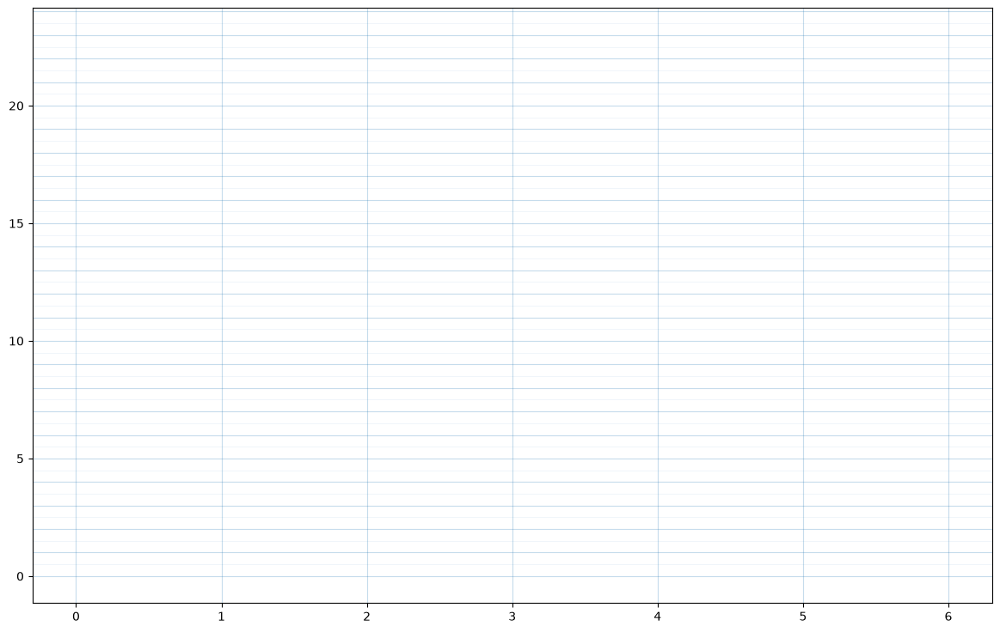

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# Funkcja korzysta z tej zmiennej globalnej.
OUTCOME_COLORS = {
    "TN": "black",
    "FP": "red",
    "FN": "purple",
    "TP": "white",
}

segments_rows = []

for case, info in NEW_CASE_DATA.items():

    timestamps = pd.to_datetime(
        info["full_df"]["timestamp"],
        utc=True
    )

    scenario_start = timestamps.min()
    scenario_end = timestamps.max()

    event = NEW_EVENT_WINDOWS[case]["primary"]

    incident_start = pd.to_datetime(
        event["start"], utc=True
    )
    incident_end = pd.to_datetime(
        event["end"], utc=True
    )

    # Rozdzielamy zakres scenariusza na dni,
    # ponieważ funkcja rysuje kolumny dzienne.
    days = pd.date_range(
        scenario_start.floor("D"),
        scenario_end.floor("D"),
        freq="D",
    )

    for day in days:

        day_end = day + pd.Timedelta(days=1)

        left = max(scenario_start, day)
        right = min(scenario_end, day_end)

        if right <= left:
            continue

        inc_left = max(incident_start, day)
        inc_right = min(incident_end, day_end)

        if inc_right <= inc_left:
            inc_left = pd.NaT
            inc_right = pd.NaT

        segments_rows.append({
            "case": case,
            "day": day,
            "scenario_start": left,
            "scenario_end": right,
            "incident_start": inc_left,
            "incident_end": inc_right,
        })

CALENDAR_SEGMENTS_3H = pd.DataFrame(
    segments_rows
)

# Pusty zbiór predykcji — nie udajemy,
# że klasyfikator już został uruchomiony.
EMPTY_BUCKETS = pd.DataFrame({
    "case": pd.Series(dtype="str"),
    "timestamp": pd.Series(
        dtype="datetime64[ns, UTC]"
    ),
    "bucket_end": pd.Series(
        dtype="datetime64[ns, UTC]"
    ),
    "outcome": pd.Series(dtype="str"),
})

print(
    "Scenariusze:",
    CALENDAR_SEGMENTS_3H["case"].nunique()
)
print(
    "Dni:",
    CALENDAR_SEGMENTS_3H["day"].nunique()
)

plot_calendar_with_buckets(
    calendar_segments=CALENDAR_SEGMENTS_3H,
    bucket_df=EMPTY_BUCKETS,
    title="Nowe logi 3h — zakresy scenariuszy i incydenty",
    start_hour=0,
    end_hour=24,
)

In [7]:
import pandas as pd

def hour_float(ts):
    ts = pd.Timestamp(ts)

    return (
        ts.hour
        + ts.minute / 60
        + ts.second / 3600
        + ts.microsecond / 3_600_000_000
    )

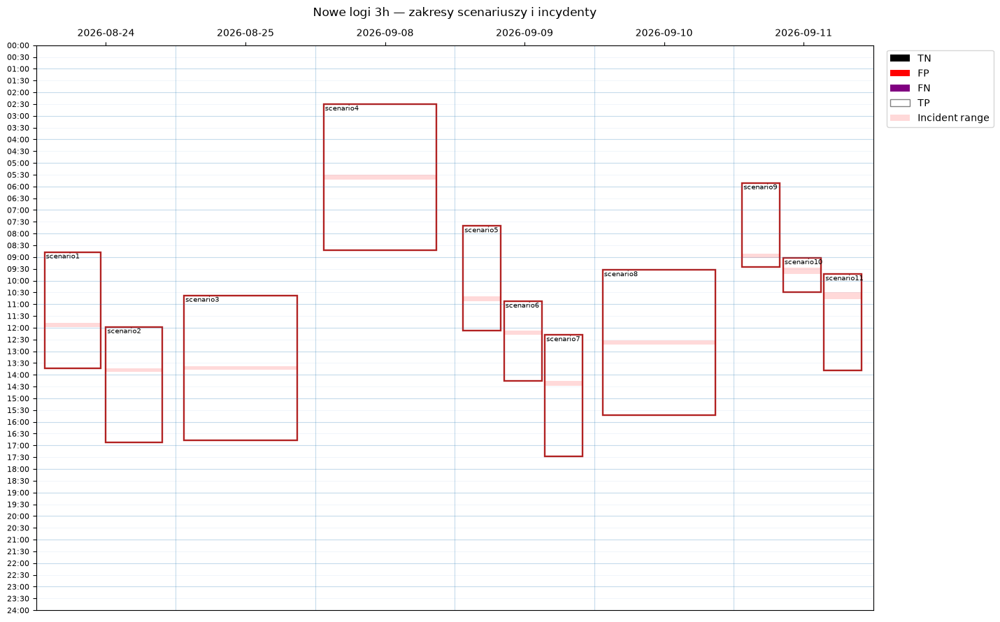

In [8]:
plot_calendar_with_buckets(
    calendar_segments=CALENDAR_SEGMENTS_3H,
    bucket_df=EMPTY_BUCKETS,
    title="Nowe logi 3h — zakresy scenariuszy i incydenty",
    start_hour=0,
    end_hour=24,
)

In [8]:
import re
import gc
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

BENCH_DIR = OLD_RESULTS / "benchmark_3h_LOSO_72"
DATASET_DIR = BENCH_DIR / "datasets"
MODEL_DIR = BENCH_DIR / "models"
PRED_DIR = BENCH_DIR / "predictions"

for directory in [BENCH_DIR, DATASET_DIR, MODEL_DIR, PRED_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]
WINDOWS = ["2min", "5min", "10min"]
FEATURE_VARIANTS = [7, 18]
CLASSIFIERS = ["RF", "LR", "GB"]

SCENARIOS = sorted(
    NEW_CASE_DATA,
    key=lambda s: int(re.search(r"\d+", s).group())
)

FEATURES18 = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
    "unique_rate",
    "single_occurrence_rate",
    "dominant_share",
    "template_entropy",
    "novel_template_rate",
    "template_set_change",
    "js_divergence",
    "total_logs_z",
    "unique_templates_z",
    "single_occurrence_templates_z",
    "template_entropy_z",
    "max_template_enrichment",
    "mean_top3_enrichment",
    "templates_enriched_5x",
    "templates_enriched_10x",
]

# Roboczy zestaw 7 podstawowych cech.
# Przed benchmarkiem sprawdzamy zgodność
# z definicją używaną w poprzednim eksperymencie.
FEATURES7 = FEATURES18[:7]

FEATURE_SETS = {
    7: FEATURES7,
    18: FEATURES18,
}

PARSER_FUNCTIONS = {
    "Drain3": "parse_full_by_namespace",
    "Spell": "parse_full_by_namespace_spell",
    "IPLoM": "parse_full_by_namespace_iplom",
    "AEL": "parse_full_by_namespace_ael",
}

def make_new_classifier(name):
    if name == "RF":
        return RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        )

    if name == "LR":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                random_state=42,
            )),
        ])

    if name == "GB":
        return GradientBoostingClassifier(
            random_state=42,
        )

    raise ValueError(name)

print("Scenariusze:", len(SCENARIOS))
print("Konfiguracje:", len(PARSERS) * len(WINDOWS) * len(FEATURE_VARIANTS) * len(CLASSIFIERS))
print("Folder:", BENCH_DIR)
print("7 cech:", FEATURES7)

Scenariusze: 11
Konfiguracje: 72
Folder: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72
7 cech: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy']


In [11]:
import ast
import gc
import inspect
import json
import joblib
import re
import sys
import traceback

from pathlib import Path

import numpy as np
import pandas as pd

# Znajdź folder projektu na podstawie lokalizacji notebooka.
candidates = [Path.cwd(), *Path.cwd().parents]

AIOPS_ROOT = next(
    (
        p for p in candidates
        if (p / "Extended_logs.ipynb").exists()
        or (p / "notebooks" / "incident_analysis").exists()
    ),
    None
)

if AIOPS_ROOT is None:
    raise FileNotFoundError(
        "Nie znaleziono folderu projektu aiops. "
        "Ustaw AIOPS_ROOT ręcznie na lokalny katalog projektu."
    )

# Wyszukujemy zapis sesji, bez zgadywania ścieżki prywatnej.
sessions = list(
    AIOPS_ROOT.parent.rglob("session_3h_latest.joblib")
)

if not sessions:
    raise FileNotFoundError(
        "Nie znaleziono session_3h_latest.joblib"
    )

session_path = max(
    sessions,
    key=lambda p: p.stat().st_mtime
)

EVAL_DIR = session_path.parent
OLD_RESULTS = EVAL_DIR.parent

print("Projekt:", AIOPS_ROOT)
print("Sesja:", session_path)

session = joblib.load(session_path)
globals().update(session)
del session

print("Scenariusze:", sorted(NEW_CASE_DATA))
print("Okna incydentów:", len(NEW_EVENT_WINDOWS))

assert len(NEW_CASE_DATA) == 11
assert len(NEW_EVENT_WINDOWS) == 11

Projekt: C:\Users\kzieba\aiops
Sesja: C:\Users\kzieba\aiops_private\results\evaluation_3h\session_3h_latest.joblib
Scenariusze: ['scenario1', 'scenario10', 'scenario11', 'scenario2', 'scenario3', 'scenario4', 'scenario5', 'scenario6', 'scenario7', 'scenario8', 'scenario9']
Okna incydentów: 11


In [12]:
import os

PREP_DIR = OLD_RESULTS / "benchmark_3h_LOSO_72_v2"
PARSED_DIR = PREP_DIR / "parsed"
BUCKET_DIR = PREP_DIR / "buckets"
REPORT_DIR = PREP_DIR / "reports"

for p in [PARSED_DIR, BUCKET_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]
WINDOWS = ["2min", "5min", "10min"]

SCENARIOS = sorted(
    NEW_CASE_DATA,
    key=lambda x: int(re.search(r"\d+", x).group())
)

PARSER_FUNCTIONS = {
    "Drain3": "parse_full_by_namespace",
    "Spell": "parse_full_by_namespace_spell",
    "IPLoM": "parse_full_by_namespace_iplom",
    "AEL": "parse_full_by_namespace_ael",
}

print("Folder wyników:", PREP_DIR)
print("Scenariusze:", SCENARIOS)

Folder wyników: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2
Scenariusze: ['scenario1', 'scenario2', 'scenario3', 'scenario4', 'scenario5', 'scenario6', 'scenario7', 'scenario8', 'scenario9', 'scenario10', 'scenario11']


In [13]:
def find_function_in_notebooks(function_name):

    notebook_paths = sorted(
        AIOPS_ROOT.rglob("*.ipynb")
    )

    found = []

    for path in notebook_paths:

        try:
            with path.open("r", encoding="utf-8") as f:
                notebook = json.load(f)
        except Exception:
            continue

        for cell_no, cell in enumerate(
            notebook.get("cells", []), 1
        ):
            if cell.get("cell_type") != "code":
                continue

            source = cell.get("source", "")
            if isinstance(source, list):
                source = "".join(source)

            try:
                tree = ast.parse(source)
            except SyntaxError:
                continue

            for node in tree.body:
                if (
                    isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
                    and node.name == function_name
                ):
                    found.append({
                        "path": path,
                        "cell": cell_no,
                        "node": node,
                        "source": ast.unparse(node),
                    })

    return found


required_functions = [
    *PARSER_FUNCTIONS.values(),
    "build_namespace_buckets",
]

FUNCTION_CANDIDATES = {}

for name in required_functions:

    matches = find_function_in_notebooks(name)
    FUNCTION_CANDIDATES[name] = matches

    print(f"\n{name}: {len(matches)} definicji")

    for i, match in enumerate(matches):
        print(
            f"  [{i}] "
            f"{match['path'].relative_to(AIOPS_ROOT)} "
            f"— komórka {match['cell']}"
        )


parse_full_by_namespace: 2 definicji
  [0] notebooks\.ipynb_checkpoints\Different_namespaces-checkpoint.ipynb — komórka 4
  [1] notebooks\Different_namespaces.ipynb — komórka 4

parse_full_by_namespace_spell: 2 definicji
  [0] notebooks\.ipynb_checkpoints\Different_namespaces-checkpoint.ipynb — komórka 26
  [1] notebooks\Different_namespaces.ipynb — komórka 26

parse_full_by_namespace_iplom: 2 definicji
  [0] notebooks\.ipynb_checkpoints\Different_namespaces-checkpoint.ipynb — komórka 37
  [1] notebooks\Different_namespaces.ipynb — komórka 37

parse_full_by_namespace_ael: 2 definicji
  [0] notebooks\.ipynb_checkpoints\Different_namespaces-checkpoint.ipynb — komórka 45
  [1] notebooks\Different_namespaces.ipynb — komórka 45

build_namespace_buckets: 2 definicji
  [0] notebooks\.ipynb_checkpoints\Different_namespaces-checkpoint.ipynb — komórka 8
  [1] notebooks\Different_namespaces.ipynb — komórka 8


In [14]:
for name, matches in FUNCTION_CANDIDATES.items():

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    if not matches:
        print("BRAK DEFINICJI")
        continue

    for i, match in enumerate(matches):

        node = match["node"]

        try:
            args = ast.unparse(node.args)
        except Exception:
            args = "?"

        print(f"\nWersja [{i}]")
        print(
            "Notebook:",
            match["path"].relative_to(AIOPS_ROOT)
        )
        print("Argumenty:", args)

        lines = match["source"].splitlines()

        print("Pierwsze 18 linii:")
        print("\n".join(lines[:18]))

        if name == "build_namespace_buckets":
            print("\nKolumny / cechy / zwracany wynik:")

            for line in lines:
                if any(token in line for token in [
                    "return ",
                    "columns",
                    "feature",
                    "bucket",
                    "history",
                    "window",
                    "template",
                ]):
                    print(line[:180])


parse_full_by_namespace

Wersja [0]
Notebook: notebooks\.ipynb_checkpoints\Different_namespaces-checkpoint.ipynb
Argumenty: full_df
Pierwsze 18 linii:
def parse_full_by_namespace(full_df):
    df = full_df.copy().reset_index(drop=True)
    template_ids = [None] * len(df)
    namespace_stats = []
    for namespace, group in df.groupby('namespace', sort=False):
        config = TemplateMinerConfig()
        config.drain_sim_th = 0.4
        config.drain_depth = 4
        config.drain_max_clusters = None
        miner = TemplateMiner(config=config)
        for row_idx, message in zip(group.index, group['message']):
            clean_message = str(message).replace('\n', ' ').replace('\r', ' ')
            result = miner.add_log_message(clean_message)
            cluster_id = int(result['cluster_id'])
            template_ids[row_idx] = (namespace, cluster_id)
        namespace_stats.append({'logs': len(group), 'templates': len(miner.drain.clusters)})
    if any((template_id is None for te

In [15]:
from collections import Counter
from pathlib import Path
import tempfile
import re
import gc
import inspect
import ast

NOTEBOOK_NAME = "Different_namespaces.ipynb"

FUNCTION_NAMES = [
    "parse_full_by_namespace",
    "parse_full_by_namespace_spell",
    "parse_full_by_namespace_iplom",
    "parse_full_by_namespace_ael",
    "build_namespace_buckets",
]

# Pomocnicze funkcje potrzebne do budowy cech.
HELPER_NAMES = [
    "basic_features",
    "calculate_js_divergence",
    "past_robust_z",
    "enrichment_features",
]

def restore_function(name):

    matches = FUNCTION_CANDIDATES.get(name)

    if matches is None:
        matches = find_function_in_notebooks(name)

    matches = [
        m for m in matches
        if m["path"].name == NOTEBOOK_NAME
        and ".ipynb_checkpoints" not in m["path"].parts
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"{name}: oczekiwano jednej definicji, "
            f"znaleziono {len(matches)}"
        )

    node = matches[0]["node"]

    module = ast.fix_missing_locations(
        ast.Module(
            body=[node],
            type_ignores=[]
        )
    )

    exec(
        compile(module, str(matches[0]["path"]), "exec"),
        globals()
    )

    print("✓", name)


for name in FUNCTION_NAMES + HELPER_NAMES:
    restore_function(name)

# Katalog tymczasowy używany przez IPLoM/AEL.
# Nie zmieniamy RAW_ROOT, jeśli już istnieje.
if "RAW_ROOT" not in globals():
    RAW_ROOT = AIOPS_ROOT / "raw"

print("\nSygnatura:")
print(inspect.signature(build_namespace_buckets))

✓ parse_full_by_namespace
✓ parse_full_by_namespace_spell
✓ parse_full_by_namespace_iplom
✓ parse_full_by_namespace_ael
✓ build_namespace_buckets
✓ basic_features
✓ calculate_js_divergence
✓ past_robust_z
✓ enrichment_features

Sygnatura:
(parsed_df, window_size='5min', history_minutes=30)


In [16]:
import builtins
import dis

for name in FUNCTION_NAMES + HELPER_NAMES:

    func = globals()[name]

    referenced = {
        ins.argval
        for ins in dis.get_instructions(func)
        if ins.opname in {"LOAD_GLOBAL", "LOAD_NAME"}
        and isinstance(ins.argval, str)
    }

    missing = sorted(
        ref for ref in referenced
        if ref not in func.__globals__
        and not hasattr(builtins, ref)
    )

    print(f"{name}:")
    print("  brakujące:", missing or "brak")

parse_full_by_namespace:
  brakujące: brak
parse_full_by_namespace_spell:
  brakujące: brak
parse_full_by_namespace_iplom:
  brakujące: brak
parse_full_by_namespace_ael:
  brakujące: brak
build_namespace_buckets:
  brakujące: brak
basic_features:
  brakujące: ['BASIC_FEATURES']
calculate_js_divergence:
  brakujące: brak
past_robust_z:
  brakujące: brak
enrichment_features:
  brakujące: brak


In [17]:
import time

TEST_CASE = SCENARIOS[0]

source = NEW_CASE_DATA[TEST_CASE]["full_df"]

# Mały wycinek do sprawdzenia działania funkcji.
# Zachowujemy kolejność czasową.
test_df = (
    source
    .sort_values("timestamp")
    .head(3000)
    .copy()
)

print("Scenariusz:", TEST_CASE)
print("Logi testowe:", len(test_df))
print("Namespace'y:", test_df["namespace"].nunique())

t0 = time.perf_counter()

parsed_result = parse_full_by_namespace(test_df)

print(
    "Parsowanie:",
    round(time.perf_counter() - t0, 2),
    "s"
)

print("Typ wyniku:", type(parsed_result))

if isinstance(parsed_result, tuple):
    print(
        "Elementy:",
        [(type(x).__name__, getattr(x, "shape", None))
         for x in parsed_result]
    )
elif isinstance(parsed_result, pd.DataFrame):
    print("Kolumny:", parsed_result.columns.tolist())

Scenariusz: scenario1
Logi testowe: 3000
Namespace'y: 1
Parsowanie: 0.05 s
Typ wyniku: <class 'tuple'>
Elementy: [('DataFrame', (3000, 4)), ('DataFrame', (1, 2))]


In [6]:
import ast
import json

notebook_path = (
    AIOPS_ROOT / "notebooks" / "Different_namespaces.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

found = False

for cell in notebook["cells"]:
    if cell.get("cell_type") != "code":
        continue

    source = cell.get("source", "")
    if isinstance(source, list):
        source = "".join(source)

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if not isinstance(node, (ast.Assign, ast.AnnAssign)):
            continue

        targets = (
            node.targets
            if isinstance(node, ast.Assign)
            else [node.target]
        )

        if any(
            isinstance(t, ast.Name) and t.id == "BASIC_FEATURES"
            for t in targets
        ):
            value = ast.literal_eval(node.value)
            BASIC_FEATURES = value
            found = True
            break

    if found:
        break

if not found:
    raise RuntimeError(
        "Nie znaleziono BASIC_FEATURES w oryginalnym notebooku."
    )

print("✓ BASIC_FEATURES:", BASIC_FEATURES)

✓ BASIC_FEATURES: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy']


In [19]:
import time
import gc

TEST_CASE = "scenario1"
TEST_ROWS = 1000

test_df = (
    NEW_CASE_DATA[TEST_CASE]["full_df"]
    .sort_values("timestamp")
    .head(TEST_ROWS)
    .copy()
)

PARSER_TESTS = {}

for parser_name, function_name in PARSER_FUNCTIONS.items():

    parser_func = globals()[function_name]

    print(f"\n{'=' * 60}")
    print(f"Parser: {parser_name}")
    print(f"{'=' * 60}", flush=True)

    start = time.perf_counter()

    try:
        result = parser_func(test_df)

        parsed = (
            result[0]
            if isinstance(result, tuple)
            else result
        )

        if not isinstance(parsed, pd.DataFrame):
            raise TypeError(
                f"Parser zwrócił {type(parsed)}"
            )

        required = {"timestamp", "template_id"}
        missing = required - set(parsed.columns)

        if missing:
            raise ValueError(
                f"Brak kolumn: {missing}"
            )

        if len(parsed) != len(test_df):
            raise ValueError(
                f"Liczba logów: {len(parsed)} "
                f"zamiast {len(test_df)}"
            )

        duration = time.perf_counter() - start

        PARSER_TESTS[parser_name] = {
            "status": "OK",
            "seconds": round(duration, 2),
            "templates": parsed["template_id"].nunique(),
        }

        print(
            f"✓ {parser_name}: "
            f"{len(parsed)} logów, "
            f"{parsed['template_id'].nunique()} szablonów, "
            f"{duration:.2f} s",
            flush=True,
        )

    except Exception as exc:

        PARSER_TESTS[parser_name] = {
            "status": "ERROR",
            "error": str(exc),
        }

        print(
            f"✗ {parser_name}: {type(exc).__name__}: {exc}",
            flush=True,
        )

    finally:
        if "result" in locals():
            del result
        if "parsed" in locals():
            del parsed
        gc.collect()

display(pd.DataFrame(PARSER_TESTS).T)


Parser: Drain3
✓ Drain3: 1000 logów, 20 szablonów, 0.02 s

Parser: Spell
Parsing file: C:\Users\kzieba\AppData\Local\Temp\tmpd5d36y9k\input\full.log
Processed 100.0% of log lines.
Entering lightweight outputResult | clusters: 41
Templates written: 41
Parsing done. [Time taken: 0:00:00.085908]
✓ Spell: 1000 logów, 41 szablonów, 0.09 s

Parser: IPLoM
Parsing file: C:\Users\kzieba\aiops_private\parser_tmp\tmpozj3fvs2\input\full.log
Parsing done. [Time taken: 0:00:00.045420]
✓ IPLoM: 1000 logów, 40 szablonów, 0.07 s

Parser: AEL
Parsing file: C:\Users\kzieba\aiops_private\parser_tmp\tmp835t5kpn\input\full.log
Parsing done. [Time taken: 0:00:00.026541]
✓ AEL: 1000 logów, 10 szablonów, 0.03 s


,status,seconds,templates
Drain3,OK,0.02,20
Spell,OK,0.09,41
IPLoM,OK,0.07,40
AEL,OK,0.03,10


In [20]:
result = parse_full_by_namespace(test_df)
parsed = result[0]

print("Kolumny parsera:", parsed.columns.tolist())

for window in ["2min", "5min", "10min"]:

    buckets = build_namespace_buckets(
        parsed,
        window_size=window,
        history_minutes=30,
    )

    print(f"\n{window}:")
    print("Kubełki:", len(buckets))
    print("Kolumny:", buckets.columns.tolist())

    print(
        "Braki danych:",
        int(buckets.isna().sum().sum())
    )

del result, parsed, buckets
gc.collect()

Kolumny parsera: ['timestamp', 'message', 'namespace', 'template_id']

2min:
Kubełki: 8
Kolumny: ['timestamp', 'total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'templates_enriched_5x', 'templates_enriched_10x']
Braki danych: 0

5min:
Kubełki: 4
Kolumny: ['timestamp', 'total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'templates_enriched_5x', 'templates_enriched_10x']
Braki danych: 0

10min:
Kube

0

In [9]:
import gc
import time
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

PREP_DIR = OLD_RESULTS / "benchmark_3h_LOSO_72_v2"
PARSED_DIR = PREP_DIR / "parsed"
BUCKET_DIR = PREP_DIR / "buckets"
REPORT_DIR = PREP_DIR / "reports"

for p in [PARSED_DIR, BUCKET_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]
WINDOWS = ["2min", "5min", "10min"]

FEATURES18 = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
    "unique_rate",
    "single_occurrence_rate",
    "dominant_share",
    "template_entropy",
    "novel_template_rate",
    "template_set_change",
    "js_divergence",
    "total_logs_z",
    "unique_templates_z",
    "single_occurrence_templates_z",
    "template_entropy_z",
    "max_template_enrichment",
    "mean_top3_enrichment",
    "templates_enriched_5x",
    "templates_enriched_10x",
]

PARSER_FUNCTIONS = {
    "Drain3": parse_full_by_namespace,
    "Spell": parse_full_by_namespace_spell,
    "IPLoM": parse_full_by_namespace_iplom,
    "AEL": parse_full_by_namespace_ael,
}

SCENARIOS = sorted(
    NEW_CASE_DATA,
    key=lambda s: int("".join(filter(str.isdigit, s)))
)

print("Scenariusze:", len(SCENARIOS))
print("Parsery:", PARSERS)
print("Okna:", WINDOWS)
print("Folder:", PREP_DIR)

assert len(SCENARIOS) == 11
assert all(callable(f) for f in PARSER_FUNCTIONS.values())
assert len(FEATURES18) == 18

Scenariusze: 11
Parsery: ['Drain3', 'Spell', 'IPLoM', 'AEL']
Okna: ['2min', '5min', '10min']
Folder: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2


In [11]:
def as_utc(value):
    return pd.to_datetime(value, utc=True)


def add_bucket_labels(buckets, case, window):

    result = buckets.copy()

    result["timestamp"] = pd.to_datetime(
        result["timestamp"], utc=True
    )

    result["bucket_end"] = (
        result["timestamp"] + pd.Timedelta(window)
    )

    events = NEW_EVENT_WINDOWS[case]

    def event_mask(event):
        start = as_utc(event["start"])
        end = as_utc(event["end"])

        return (
            (result["timestamp"] < end)
            & (result["bucket_end"] > start)
        )

    primary_mask = event_mask(events["primary"])
    all_mask = primary_mask.copy()

    for event in events.get("other", []):
        all_mask |= event_mask(event)

    result["label_primary"] = primary_mask.astype("int8")
    result["label_all_known"] = all_mask.astype("int8")
    result["case"] = case

    return result

In [23]:
def prepare_case_parser(case, parser_name):

    parser_func = PARSER_FUNCTIONS[parser_name]

    output_paths = {
        window: BUCKET_DIR / f"{parser_name}__{case}__{window}.joblib"
        for window in WINDOWS
    }

    pending = [
        window for window, path in output_paths.items()
        if not path.exists()
    ]

    if not pending:
        print(f"✓ Cache: {parser_name} / {case}", flush=True)
        return

    print(
        f"\n▶ {parser_name} / {case} "
        f"| brakujące okna: {pending}",
        flush=True,
    )

    start = time.perf_counter()

    source = NEW_CASE_DATA[case]["full_df"]

    # Nie kopiujemy pełnego DataFrame przed wywołaniem parsera.
    parsed_result = parser_func(source)

    parsed = (
        parsed_result[0]
        if isinstance(parsed_result, tuple)
        else parsed_result
    )

    if not isinstance(parsed, pd.DataFrame):
        raise TypeError(
            f"{parser_name}/{case}: "
            f"nieoczekiwany typ {type(parsed)}"
        )

    if len(parsed) != len(source):
        raise ValueError(
            f"{parser_name}/{case}: "
            f"liczba wierszy {len(parsed)} != {len(source)}"
        )

    required = {"timestamp", "template_id"}
    missing = required - set(parsed.columns)

    if missing:
        raise ValueError(
            f"{parser_name}/{case}: brak {missing}"
        )

    # Minimalna struktura do liczenia cech.
    compact = parsed[
        ["timestamp", "template_id"]
    ].copy()

    compact["timestamp"] = pd.to_datetime(
        compact["timestamp"], utc=True
    )

    del parsed_result, parsed
    gc.collect()

    print(
        f"  Parsowanie zakończone: "
        f"{time.perf_counter() - start:.1f} s",
        flush=True,
    )

    for window in pending:

        window_start = time.perf_counter()

        buckets = build_namespace_buckets(
            compact,
            window_size=window,
            history_minutes=30,
        )

        missing_features = (
            set(FEATURES18) - set(buckets.columns)
        )

        if missing_features:
            raise ValueError(
                f"{parser_name}/{case}/{window}: "
                f"brak cech {sorted(missing_features)}"
            )

        buckets = add_bucket_labels(
            buckets, case, window
        )

        # Zachowujemy tylko potrzebne kolumny.
        columns = [
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
            *FEATURES18,
        ]

        buckets = buckets[columns]

        # Atomowy zapis: nie pozostawiamy częściowego checkpointu.
        path = output_paths[window]
        temporary = path.with_suffix(".tmp")

        joblib.dump(
            buckets,
            temporary,
            compress=0,
        )

        temporary.replace(path)

        print(
            f"  ✓ {window}: "
            f"{len(buckets):,} kubełków, "
            f"{buckets['label_all_known'].sum():,} pozytywnych, "
            f"{time.perf_counter() - window_start:.1f} s",
            flush=True,
        )

        del buckets
        gc.collect()

    del compact
    gc.collect()


# Najpierw uruchamiamy tylko jeden scenariusz i jeden parser.
prepare_case_parser("scenario1", "Drain3")


▶ Drain3 / scenario1 | brakujące okna: ['2min', '5min', '10min']
  Parsowanie zakończone: 0.8 s
  ✓ 2min: 149 kubełków, 7 pozytywnych, 0.1 s
  ✓ 5min: 60 kubełków, 4 pozytywnych, 0.0 s
  ✓ 10min: 31 kubełków, 3 pozytywnych, 0.0 s


In [24]:
for window in WINDOWS:

    path = (
        BUCKET_DIR / f"Drain3__scenario1__{window}.joblib"
    )

    df = joblib.load(path)

    print(
        window,
        "| kubełki:", len(df),
        "| pozytywne:", int(df["label_all_known"].sum()),
        "| negatywne:", int((df["label_all_known"] == 0).sum()),
        "| cechy:", len([c for c in FEATURES18 if c in df]),
        "| braki:", int(df[FEATURES18].isna().sum().sum()),
    )

    del df

gc.collect()

2min | kubełki: 149 | pozytywne: 7 | negatywne: 142 | cechy: 18 | braki: 0
5min | kubełki: 60 | pozytywne: 4 | negatywne: 56 | cechy: 18 | braki: 0
10min | kubełki: 31 | pozytywne: 3 | negatywne: 28 | cechy: 18 | braki: 0


0

In [25]:
import traceback

failures = []

for parser_name in PARSERS:

    for case in SCENARIOS:

        try:
            prepare_case_parser(case, parser_name)

        except Exception as exc:

            print(
                f"\n✗ BŁĄD: {parser_name} / {case}: "
                f"{type(exc).__name__}: {exc}",
                flush=True,
            )

            traceback.print_exc()

            failures.append({
                "parser": parser_name,
                "case": case,
                "error": repr(exc),
            })

            # Nie próbujemy kolejnych kosztownych parsowań,
            # jeśli wystąpił nieoczekiwany błąd.
            break

    if failures:
        break

if failures:
    pd.DataFrame(failures).to_csv(
        REPORT_DIR / "preparation_errors.csv",
        index=False,
    )
    print("\nPrzygotowanie przerwane. Zapisane checkpointy pozostają.")
else:
    print("\n✓ Wszystkie kombinacje przygotowane.")

✓ Cache: Drain3 / scenario1

▶ Drain3 / scenario2 | brakujące okna: ['2min', '5min', '10min']
  Parsowanie zakończone: 0.6 s
  ✓ 2min: 149 kubełków, 7 pozytywnych, 0.1 s
  ✓ 5min: 60 kubełków, 4 pozytywnych, 0.0 s
  ✓ 10min: 31 kubełków, 3 pozytywnych, 0.0 s

▶ Drain3 / scenario3 | brakujące okna: ['2min', '5min', '10min']
  Parsowanie zakończone: 0.8 s
  ✓ 2min: 186 kubełków, 6 pozytywnych, 0.1 s
  ✓ 5min: 75 kubełków, 3 pozytywnych, 0.1 s
  ✓ 10min: 38 kubełków, 2 pozytywnych, 0.0 s

▶ Drain3 / scenario4 | brakujące okna: ['2min', '5min', '10min']
  Parsowanie zakończone: 1.1 s
  ✓ 2min: 186 kubełków, 6 pozytywnych, 0.1 s
  ✓ 5min: 75 kubełków, 3 pozytywnych, 0.1 s
  ✓ 10min: 38 kubełków, 2 pozytywnych, 0.0 s

▶ Drain3 / scenario5 | brakujące okna: ['2min', '5min', '10min']
  Parsowanie zakończone: 0.7 s
  ✓ 2min: 134 kubełków, 8 pozytywnych, 0.1 s
  ✓ 5min: 54 kubełków, 4 pozytywnych, 0.0 s
  ✓ 10min: 27 kubełków, 3 pozytywnych, 0.0 s

▶ Drain3 / scenario6 | brakujące okna: ['2min',

In [26]:
validation_rows = []

for parser_name in PARSERS:
    for case in SCENARIOS:
        for window in WINDOWS:

            path = (
                BUCKET_DIR
                / f"{parser_name}__{case}__{window}.joblib"
            )

            if not path.exists():
                validation_rows.append({
                    "parser": parser_name,
                    "case": case,
                    "window": window,
                    "status": "MISSING",
                })
                continue

            df = joblib.load(path)

            missing_features = (
                set(FEATURES18) - set(df.columns)
            )

            validation_rows.append({
                "parser": parser_name,
                "case": case,
                "window": window,
                "status": (
                    "OK" if not missing_features else "BAD_FEATURES"
                ),
                "buckets": len(df),
                "positive": int(df["label_all_known"].sum()),
                "negative": int((df["label_all_known"] == 0).sum()),
                "missing_values": int(
                    df[FEATURES18].isna().sum().sum()
                ) if not missing_features else None,
            })

            del df

VALIDATION_3H = pd.DataFrame(validation_rows)

VALIDATION_3H.to_csv(
    REPORT_DIR / "validation.csv",
    index=False,
)

display(
    VALIDATION_3H.groupby(
        ["parser", "window", "status"],
        dropna=False,
    ).agg(
        scenarios=("case", "nunique"),
        buckets=("buckets", "sum"),
        positive=("positive", "sum"),
        negative=("negative", "sum"),
    )
)

print(
    "\nGotowe:",
    int((VALIDATION_3H["status"] == "OK").sum()),
    "/",
    len(PARSERS) * len(SCENARIOS) * len(WINDOWS),
)

scenarios  buckets  positive  negative
parser window status                                        
AEL    10min  OK             11      312        34       278
       2min   OK             11     1524        84      1440
       5min   OK             11      616        46       570
Drain3 10min  OK             11      312        34       278
       2min   OK             11     1524        84      1440
       5min   OK             11      616        46       570
IPLoM  10min  OK             11      312        34       278
       2min   OK             11     1524        84      1440
       5min   OK             11      616        46       570
Spell  10min  OK             11      312        34       278
       2min   OK             11     1524        84      1440
       5min   OK             11      616        46       570


Gotowe: 132 / 132


In [27]:
import ast
import json
import re

notebook_path = (
    AIOPS_ROOT / "notebooks" / "Different_namespaces.ipynb"
)

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

for cell_number, cell in enumerate(notebook["cells"], 1):

    if cell.get("cell_type") != "code":
        continue

    source = cell.get("source", "")
    if isinstance(source, list):
        source = "".join(source)

    lines = source.splitlines()

    matches = [
        (i, line)
        for i, line in enumerate(lines)
        if re.search(
            r"FEATURES7|FEATURES_7|BASIC_FEATURES|feature_cols|feature_columns|feature_set|n_features",
            line,
            flags=re.IGNORECASE,
        )
    ]

    if not matches:
        continue

    print(f"\n{'=' * 70}")
    print(f"KOMÓRKA {cell_number}")
    print(f"{'=' * 70}")

    shown = set()

    for index, _ in matches:
        for j in range(
            max(0, index - 2),
            min(len(lines), index + 4)
        ):
            if j not in shown:
                print(f"{j + 1:3}: {lines[j]}")
                shown.add(j)


KOMÓRKA 7
  2: 
  3: 
  4: BASIC_FEATURES = [
  5:     "total_logs",
  6:     "unique_templates",
  7:     "single_occurrence_templates",
 28: 
 29: 
 30: FEATURE_SETS = {
 31:     "basic": BASIC_FEATURES,
 32:     "full": BASIC_FEATURES + TEMPORAL_FEATURES,
 33: }
 34: 
 35: 
 36: def basic_features(counts):
 37: 
 38:     total = sum(counts.values())
 39:     unique = len(counts)
 40: 
 41:     if total == 0:
 42:         return dict.fromkeys(BASIC_FEATURES, 0.0)
 43: 
 44:     frequencies = np.array(
 45:         list(counts.values()),
196: 
197: 
198: print("Basic features:", len(FEATURE_SETS["basic"]))
199: print("Full features:", len(FEATURE_SETS["full"]))

KOMÓRKA 8
 46:         current = bucket_counts[bucket_time]
 47: 
 48:         current_basic = basic_features(current)
 49: 
 50:         # WYŁĄCZNIE wcześniejsze okna
 51:         history = [
 66: 
 67:         history_basic = [
 68:             basic_features(counts)
 69:             for counts in history
 70:         ]
 71

In [12]:
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

MODEL_DIR = PREP_DIR / "models"
PRED_DIR = PREP_DIR / "predictions"

for p in [MODEL_DIR, PRED_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Oryginalne definicje z notebooka.
BASIC_FEATURES = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
    "unique_rate",
    "single_occurrence_rate",
    "dominant_share",
    "template_entropy",
]

FEATURES7 = list(BASIC_FEATURES)
FEATURES18 = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
    "unique_rate",
    "single_occurrence_rate",
    "dominant_share",
    "template_entropy",
    "novel_template_rate",
    "template_set_change",
    "js_divergence",
    "total_logs_z",
    "unique_templates_z",
    "single_occurrence_templates_z",
    "template_entropy_z",
    "max_template_enrichment",
    "mean_top3_enrichment",
    "templates_enriched_5x",
    "templates_enriched_10x",
]

FEATURE_VARIANTS = {
    "basic": FEATURES7,
    "full": FEATURES18,
}

assert len(FEATURES7) == 7, FEATURES7
assert len(FEATURES18) == 18, FEATURES18
assert set(FEATURES7).issubset(FEATURES18)

print("7 cech:", FEATURES7)
print("18 cech:", FEATURES18)
print("Warianty:", list(FEATURE_VARIANTS))

MODELS = {
    "RF": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=1,
    ),
    "LR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42,
        )),
    ]),
    "GB": GradientBoostingClassifier(
        random_state=42,
    ),
}

print("7 cech:", FEATURES7)
print("18 cech:", FEATURES18)
print("Liczba konfiguracji:", 4 * 3 * 2 * 3)

7 cech: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy']
18 cech: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'templates_enriched_5x', 'templates_enriched_10x']
Warianty: ['basic', 'full']
7 cech: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy']
18 cech: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z',

In [13]:
def calculate_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

In [34]:
import time

LABEL_COLUMN = "label_all_known"

def run_one_configuration(parser, window, feature_set, model_name):

    features = FEATURE_VARIANTS[feature_set]

    # Ładujemy wyłącznie jeden parser i jedno okno.
    frames = []

    for case in SCENARIOS:

        path = (
            BUCKET_DIR
            / f"{parser}__{case}__{window}.joblib"
        )

        frames.append(joblib.load(path))

    dataset = pd.concat(frames, ignore_index=True)

    del frames
    gc.collect()

    X = (
        dataset[features]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    y = dataset[LABEL_COLUMN].to_numpy(dtype=np.int8)
    cases = dataset["case"].to_numpy()

    config_id = (
        f"{parser}__{window}__{feature_set}__{model_name}"
    )

    for test_case in SCENARIOS:

        fold_id = f"{config_id}__{test_case}"

        model_path = MODEL_DIR / f"{fold_id}.joblib"
        pred_path = PRED_DIR / f"{fold_id}.joblib"

        if model_path.exists() and pred_path.exists():
            print("✓ Cache:", fold_id, flush=True)
            continue

        train_mask = cases != test_case
        test_mask = cases == test_case

        X_train = X[train_mask]
        y_train = y[train_mask]

        X_test = X[test_mask]
        y_test = y[test_mask]

        if np.unique(y_train).size < 2:
            raise ValueError(
                f"{fold_id}: trening zawiera tylko jedną klasę."
            )

        model = clone(MODELS[model_name])

        start = time.perf_counter()

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test).astype(np.int8)

        metrics = calculate_metrics(y_test, y_pred)

        prediction_df = dataset.loc[
            test_mask,
            [
                "case",
                "timestamp",
                "bucket_end",
                "label_primary",
                LABEL_COLUMN,
            ],
        ].copy()

        prediction_df["prediction"] = y_pred

        joblib.dump(
            {
                "data": prediction_df,
                "metrics": metrics,
            },
            pred_path,
            compress=0,
        )

        joblib.dump(
            {
                "model": model,
                "features": features,
                "parser": parser,
                "window": window,
                "test_case": test_case,
            },
            model_path,
            compress=0,
        )

        elapsed = time.perf_counter() - start

        print(
            f"✓ {fold_id} | "
            f"MCC={metrics['MCC']:.3f} | "
            f"F1={metrics['F1']:.3f} | "
            f"{elapsed:.1f}s",
            flush=True,
        )

        del model, prediction_df
        gc.collect()

    del dataset, X, y, cases
    gc.collect()


for parser in PARSERS:
    for window in WINDOWS:
        for feature_set in FEATURE_VARIANTS:
            for model_name in MODELS:

                print(
                    f"\n▶ {parser} | {window} | "
                    f"{feature_set} | {model_name}",
                    flush=True,
                )

                run_one_configuration(
                    parser,
                    window,
                    feature_set,
                    model_name,
                )

print("\n✓ Wszystkie treningi LOSO zakończone.")


▶ Drain3 | 2min | basic | RF
✓ Drain3__2min__basic__RF__scenario1 | MCC=0.487 | F1=0.500 | 0.5s
✓ Drain3__2min__basic__RF__scenario2 | MCC=0.761 | F1=0.769 | 0.4s
✓ Drain3__2min__basic__RF__scenario3 | MCC=0.101 | F1=0.133 | 0.3s
✓ Drain3__2min__basic__RF__scenario4 | MCC=0.392 | F1=0.400 | 0.3s
✓ Drain3__2min__basic__RF__scenario5 | MCC=1.000 | F1=1.000 | 0.5s
✓ Drain3__2min__basic__RF__scenario6 | MCC=0.250 | F1=0.286 | 0.5s
✓ Drain3__2min__basic__RF__scenario7 | MCC=0.526 | F1=0.444 | 0.3s
✓ Drain3__2min__basic__RF__scenario8 | MCC=0.595 | F1=0.545 | 0.4s
✓ Drain3__2min__basic__RF__scenario9 | MCC=0.429 | F1=0.462 | 0.4s
✓ Drain3__2min__basic__RF__scenario10 | MCC=0.184 | F1=0.414 | 0.4s
✓ Drain3__2min__basic__RF__scenario11 | MCC=0.363 | F1=0.400 | 0.4s

▶ Drain3 | 2min | basic | LR
✓ Drain3__2min__basic__LR__scenario1 | MCC=0.333 | F1=0.348 | 0.0s
✓ Drain3__2min__basic__LR__scenario2 | MCC=0.663 | F1=0.667 | 0.0s
✓ Drain3__2min__basic__LR__scenario3 | MCC=-0.085 | F1=0.000 | 0.1s

In [35]:
ranking_rows = []
fold_rows = []

for parser in PARSERS:
    for window in WINDOWS:
        for feature_set in FEATURE_VARIANTS:
            for model_name in MODELS:

                true_parts = []
                pred_parts = []

                for case in SCENARIOS:

                    fold_id = (
                        f"{parser}__{window}__"
                        f"{feature_set}__{model_name}__{case}"
                    )

                    result = joblib.load(
                        PRED_DIR / f"{fold_id}.joblib"
                    )

                    df = result["data"]

                    y_true = df[LABEL_COLUMN].to_numpy()
                    y_pred = df["prediction"].to_numpy()

                    fold_rows.append({
                        "parser": parser,
                        "window": window,
                        "feature_set": feature_set,
                        "model": model_name,
                        "case": case,
                        **calculate_metrics(y_true, y_pred),
                    })

                    true_parts.append(y_true)
                    pred_parts.append(y_pred)

                y_true = np.concatenate(true_parts)
                y_pred = np.concatenate(pred_parts)

                ranking_rows.append({
                    "parser": parser,
                    "window": window,
                    "feature_set": feature_set,
                    "features": len(FEATURE_VARIANTS[feature_set]),
                    "model": model_name,
                    "buckets": len(y_true),
                    **calculate_metrics(y_true, y_pred),
                })

RANKING_3H = (
    pd.DataFrame(ranking_rows)
    .sort_values(
        ["MCC", "F1", "recall"],
        ascending=False,
    )
    .reset_index(drop=True)
)

RANKING_3H.insert(
    0,
    "rank",
    np.arange(1, len(RANKING_3H) + 1),
)

SCORES_BY_CASE_3H = pd.DataFrame(fold_rows)

RANKING_3H.to_csv(
    REPORT_DIR / "ranking_by_MCC.csv",
    index=False,
)

SCORES_BY_CASE_3H.to_csv(
    REPORT_DIR / "scores_by_case.csv",
    index=False,
)

display(
    RANKING_3H.head(20).style.format({
        "acc": "{:.4f}",
        "prec": "{:.4f}",
        "recall": "{:.4f}",
        "F1": "{:.4f}",
        "MCC": "{:.4f}",
    })
)

print("Konfiguracje:", len(RANKING_3H))
print("Foldy:", len(SCORES_BY_CASE_3H))
print("Ranking:", REPORT_DIR / "ranking_by_MCC.csv")

,rank,parser,window,feature_set,features,model,buckets,TP,FP,TN,FN,acc,prec,recall,F1,MCC
0,1,IPLoM,10min,basic,7,RF,312,22,25,253,12,0.8814,0.4681,0.6471,0.5432,0.4853
1,2,IPLoM,2min,full,18,RF,1524,41,38,1402,43,0.9469,0.5190,0.4881,0.5031,0.4753
2,3,Drain3,2min,full,18,RF,1524,39,37,1403,45,0.9462,0.5132,0.4643,0.4875,0.4598
3,4,Drain3,5min,full,18,RF,616,24,27,543,22,0.9205,0.4706,0.5217,0.4948,0.4525
4,5,Drain3,2min,basic,7,RF,1524,46,63,1377,38,0.9337,0.4220,0.5476,0.4767,0.4462
5,6,Drain3,5min,basic,7,RF,616,28,42,528,18,0.9026,0.4000,0.6087,0.4828,0.4431
6,7,Spell,2min,basic,7,RF,1524,46,67,1373,38,0.9311,0.4071,0.5476,0.4670,0.4365
7,8,IPLoM,10min,full,18,RF,312,19,24,254,15,0.8750,0.4419,0.5588,0.4935,0.4271
8,9,IPLoM,2min,basic,7,RF,1524,43,62,1378,41,0.9324,0.4095,0.5119,0.4550,0.4224
9,10,IPLoM,10min,basic,7,LR,312,22,37,241,12,0.8429,0.3729,0.6471,0.4731,0.4090


Konfiguracje: 72
Foldy: 792
Ranking: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\reports\ranking_by_MCC.csv


In [36]:
run_one_configuration("Drain3", "2min", "basic", "LR")

✓ Cache: Drain3__2min__basic__LR__scenario1
✓ Cache: Drain3__2min__basic__LR__scenario2
✓ Cache: Drain3__2min__basic__LR__scenario3
✓ Cache: Drain3__2min__basic__LR__scenario4
✓ Cache: Drain3__2min__basic__LR__scenario5
✓ Cache: Drain3__2min__basic__LR__scenario6
✓ Cache: Drain3__2min__basic__LR__scenario7
✓ Cache: Drain3__2min__basic__LR__scenario8
✓ Cache: Drain3__2min__basic__LR__scenario9
✓ Cache: Drain3__2min__basic__LR__scenario10
✓ Cache: Drain3__2min__basic__LR__scenario11


In [60]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

# Wczytanie rankingu, jeśli nie ma go już w pamięci
if "RANKING_3H" not in globals():
    RANKING_3H = pd.read_csv(
        REPORT_DIR / "ranking_by_MCC.csv"
    )

TOP3_3H = (
    RANKING_3H
    .sort_values(["MCC", "F1", "recall"], ascending=False)
    .head(3)
    .reset_index(drop=True)
)

display(
    TOP3_3H[
        ["parser", "window", "feature_set",
         "model", "MCC", "F1", "TP", "FP", "TN", "FN"]
    ]
)

def load_top3_predictions(row):
    parser = row["parser"]
    window = row["window"]
    feature_set = row["feature_set"]
    model = row["model"]

    frames = []

    for case in SCENARIOS:
        fold_id = (
            f"{parser}__{window}__"
            f"{feature_set}__{model}__{case}"
        )

        path = PRED_DIR / f"{fold_id}.joblib"

        if not path.exists():
            raise FileNotFoundError(
                f"Brak predykcji LOSO: {fold_id}"
            )

        df = joblib.load(path)["data"].copy()
        frames.append(df)

    result = pd.concat(frames, ignore_index=True)

    result["timestamp"] = pd.to_datetime(
        result["timestamp"], utc=True
    )
    result["bucket_end"] = pd.to_datetime(
        result["bucket_end"], utc=True
    )

    y_true = result["label_all_known"].astype(int)
    y_pred = result["prediction"].astype(int)

    result["outcome"] = np.select(
        [
            (y_true == 1) & (y_pred == 1),
            (y_true == 0) & (y_pred == 1),
            (y_true == 0) & (y_pred == 0),
            (y_true == 1) & (y_pred == 0),
        ],
        ["TP", "FP", "TN", "FN"],
        default="UNKNOWN",
    )

    return result

TOP3_PREDICTIONS = {
    rank: load_top3_predictions(row)
    for rank, (_, row) in enumerate(TOP3_3H.iterrows(), 1)
}

print("✓ Wczytano predykcje dla TOP 3")

,parser,window,feature_set,model,MCC,F1,TP,FP,TN,FN
0,IPLoM,10min,basic,RF,0.485341,0.543210,22,25,253,12
1,IPLoM,2min,full,RF,0.475269,0.503067,41,38,1402,43
2,Drain3,2min,full,RF,0.459822,0.487500,39,37,1403,45


✓ Wczytano predykcje dla TOP 3


In [55]:
import ast
import json
import inspect

notebook_path = (
    AIOPS_ROOT
    / "notebooks"
    / "incident_analysis"
    / "Drain3+binary-v2.ipynb"
)

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

function_name = "plot_calendar_with_buckets"
found = False

for cell in notebook["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == function_name
        ):
            module = ast.fix_missing_locations(
                ast.Module(body=[node], type_ignores=[])
            )

            exec(
                compile(module, str(notebook_path), "exec"),
                globals(),
            )

            found = True
            break

    if found:
        break

if not found:
    raise RuntimeError(
        "Nie znaleziono plot_calendar_with_buckets"
    )

print("✓ Przywrócono oryginalną funkcję")
print("\nArgumenty:")
print(inspect.signature(plot_calendar_with_buckets))

print("\nKod funkcji:")
print(inspect.getsource(plot_calendar_with_buckets)
      if hasattr(plot_calendar_with_buckets, "__source__")
      else ast.unparse(node))

✓ Przywrócono oryginalną funkcję

Argumenty:
(calendar_segments, bucket_df, title='Scenariusze, incydenty i kubełki', start_hour=8, end_hour=15)

Kod funkcji:
def plot_calendar_with_buckets(calendar_segments, bucket_df, title='Scenariusze, incydenty i kubełki', start_hour=8, end_hour=15):
    segments = calendar_segments.copy()
    buckets = bucket_df.copy()
    datetime_columns = ['timestamp', 'bucket_end', 'incident_start', 'incident_end']
    for col in datetime_columns:
        if col in buckets.columns:
            buckets[col] = pd.to_datetime(buckets[col], errors='coerce')
    for col in ['day', 'scenario_start', 'scenario_end', 'incident_start', 'incident_end']:
        if col in segments.columns:
            segments[col] = pd.to_datetime(segments[col], errors='coerce')
    days = sorted(segments['day'].dropna().unique())
    day_to_x = {pd.Timestamp(day): i for i, day in enumerate(days)}
    fig_width = max(10, len(days) * 2.4)
    fig, ax = plt.subplots(figsize=(fig_width, 9

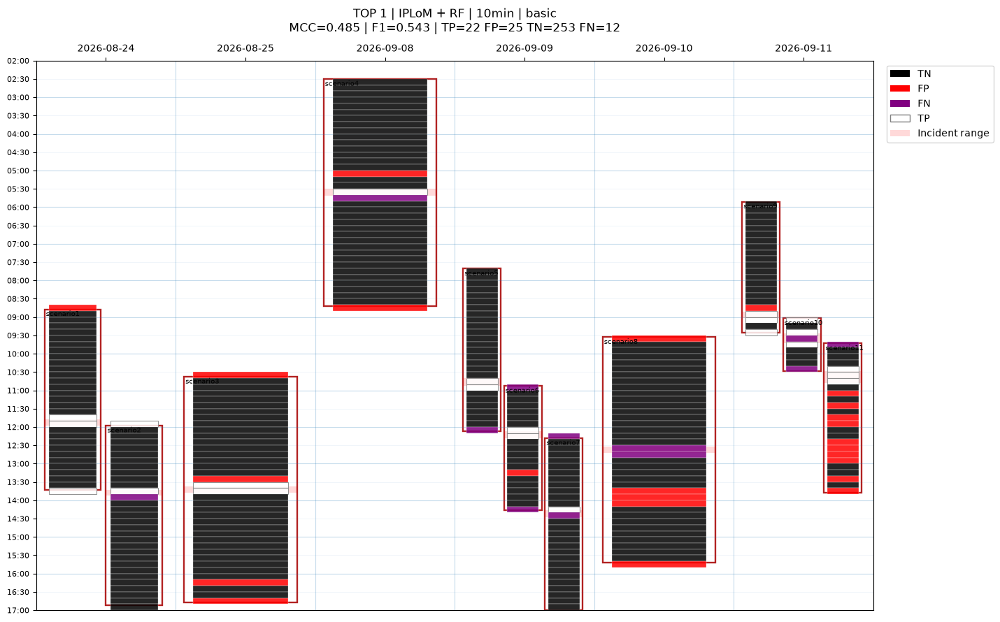

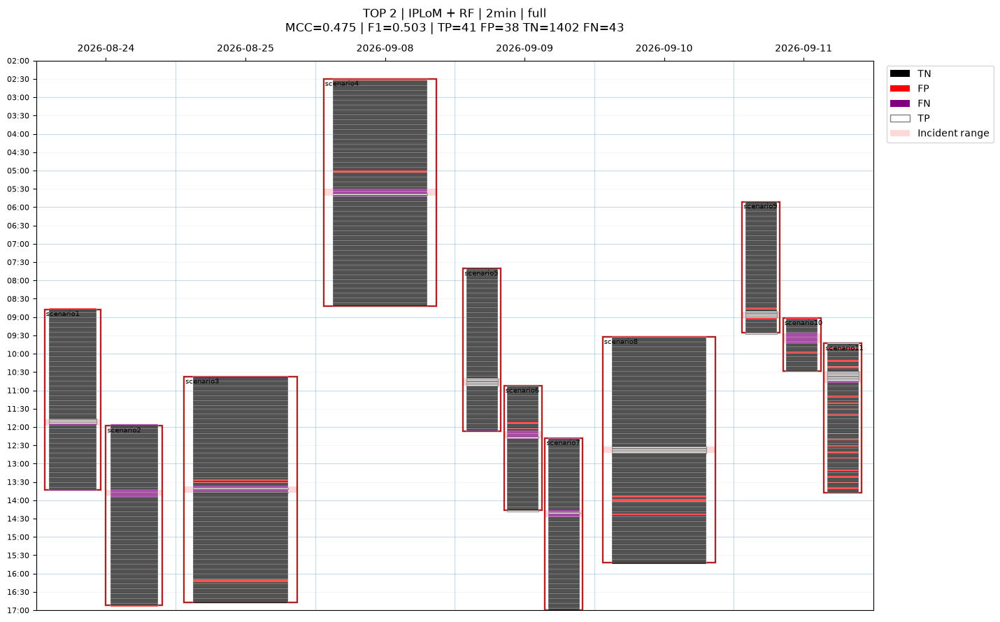

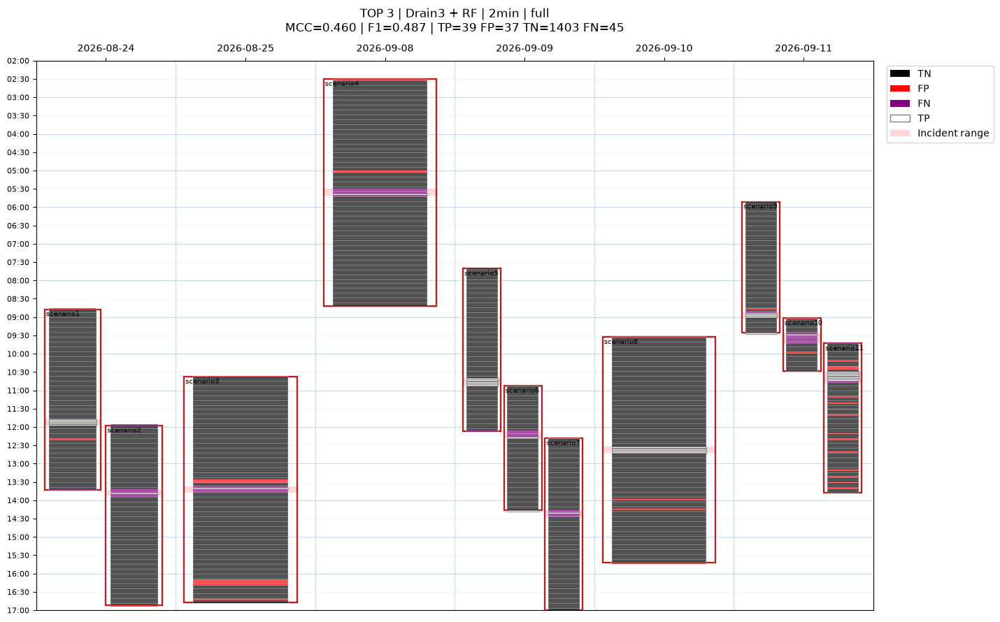

In [61]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import pandas as pd
import numpy as np

# Dokładnie te kolory, których używa oryginalny wykres.
OUTCOME_COLORS = {
    "TN": "black",
    "FP": "red",
    "FN": "purple",
    "TP": "white",
}

def hour_float(value):
    value = pd.Timestamp(value)
    return (
        value.hour
        + value.minute / 60
        + value.second / 3600
    )

# Przygotowanie calendar_segments z rzeczywistych
# przedziałów scenariuszy i incydentów.
segment_rows = []

for case in SCENARIOS:
    info = NEW_CASE_DATA[case]
    full_df = info["full_df"]

    scenario_start = pd.to_datetime(
        full_df["timestamp"].min(), utc=True
    )
    scenario_end = pd.to_datetime(
        full_df["timestamp"].max(), utc=True
    )

    incident_start = pd.to_datetime(
        info["incident_start"], utc=True
    )
    incident_end = pd.to_datetime(
        info["incident_end"], utc=True
    )

    segment_rows.append({
        "case": case,
        "day": scenario_start.floor("D"),
        "scenario_start": scenario_start,
        "scenario_end": scenario_end,
        "incident_start": incident_start,
        "incident_end": incident_end,
    })

CALENDAR_SEGMENTS_3H = pd.DataFrame(segment_rows)

# Spójny format czasu — UTC bez informacji o strefie,
# ponieważ oryginalna funkcja korzysta z godzin zegarowych.
for col in [
    "day", "scenario_start", "scenario_end",
    "incident_start", "incident_end"
]:
    CALENDAR_SEGMENTS_3H[col] = (
        pd.to_datetime(CALENDAR_SEGMENTS_3H[col], utc=True)
        .dt.tz_localize(None)
    )

# Oryginalne wykresy dla trzech najlepszych konfiguracji.
for rank, (_, config) in enumerate(TOP3_3H.iterrows(), 1):

    buckets = TOP3_PREDICTIONS[rank].copy()

    for col in ["timestamp", "bucket_end"]:
        buckets[col] = (
            pd.to_datetime(buckets[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"TOP {rank} | {config['parser']} + {config['model']}"
        f" | {config['window']} | {config['feature_set']}\n"
        f"MCC={config['MCC']:.3f} | F1={config['F1']:.3f}"
        f" | TP={int(config['TP'])}"
        f" FP={int(config['FP'])}"
        f" TN={int(config['TN'])}"
        f" FN={int(config['FN'])}"
    )

    plot_calendar_with_buckets(
        calendar_segments=CALENDAR_SEGMENTS_3H,
        bucket_df=buckets,
        title=title,
        start_hour=2,
        end_hour=17,
    )

In [17]:
import inspect

for name in [
    "get_parsed_dataframe",
    "plot_template_frequency",
    "plot_template_frequency_grid",
    "plot_frequency_grid",
]:
    func = globals().get(name)

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    if func is None:
        print("Funkcja niedostępna")
        continue

    print("Argumenty:", inspect.signature(func))

    try:
        source = inspect.getsource(func)
        print(source[:12000])
    except (OSError, TypeError):
        print("Nie udało się pobrać kodu źródłowego.")

print("\n" + "=" * 65)
print("SCENARIO11 — STRUKTURA LOGÓW")
print("=" * 65)

df11 = NEW_CASE_DATA["scenario11"]["full_df"]

print("Kolumny:", df11.columns.tolist())
print("Namespace'y:")

if "namespace" in df11.columns:
    print(df11["namespace"].value_counts().to_string())
else:
    print("Brak kolumny namespace")

print("\nZakres czasu:")
print(df11["timestamp"].min(), "→", df11["timestamp"].max())


get_parsed_dataframe
Funkcja niedostępna

plot_template_frequency
Funkcja niedostępna

plot_template_frequency_grid
Funkcja niedostępna

plot_frequency_grid
Funkcja niedostępna

SCENARIO11 — STRUKTURA LOGÓW
Kolumny: ['timestamp', 'message', 'namespace']
Namespace'y:
namespace
reporting      69926
monitoring     65976
resolve         6859
ml              6392
integration     5521

Zakres czasu:
2026-09-11 09:43:15.455612+00:00 → 2026-09-11 13:47:59.703697+00:00


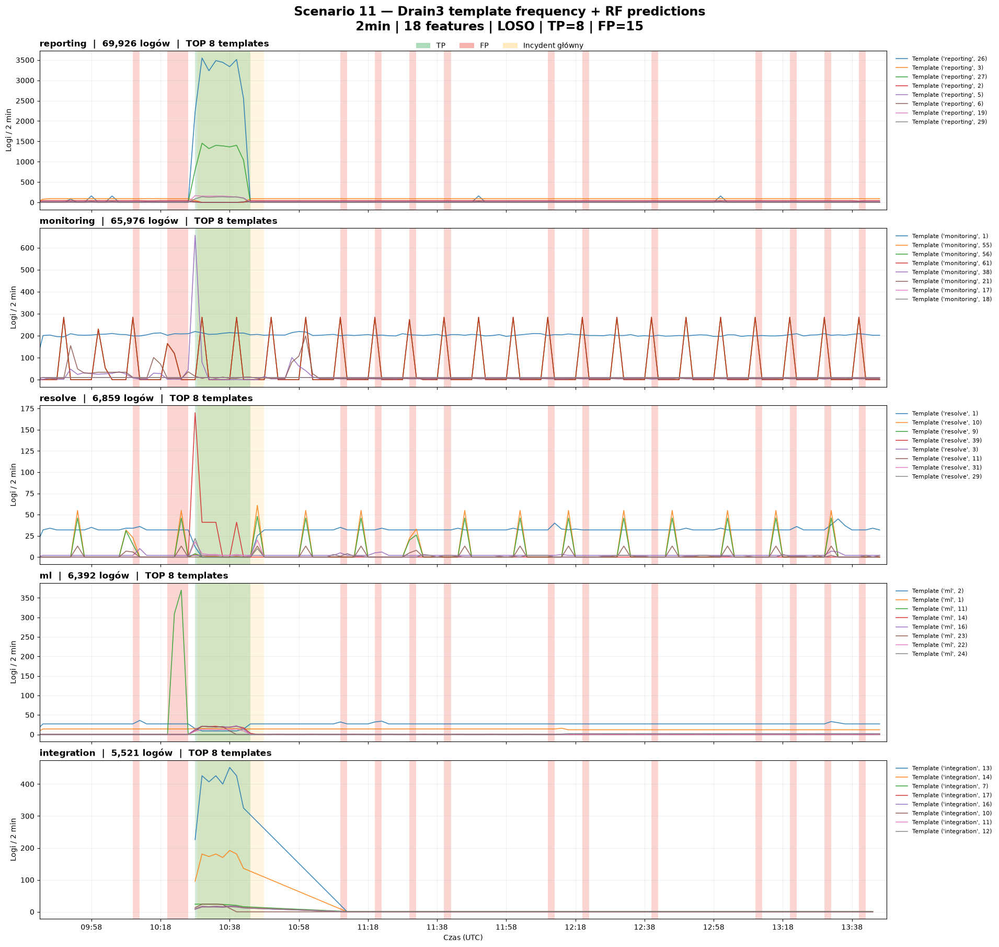

Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\reports\scenario11_Drain3_RF_2min_full_templates_TP_FP.png
Namespace'y: 5
TP: 8 | FP: 15


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import joblib

CASE = "scenario11"
PARSER = "Drain3"
WINDOW = "2min"
TOP_N = 8

# 1. Sparsowane logi Drain3 (z istniejącego cache).
parsed = get_parsed_dataframe(PARSER, CASE).copy()

parsed["timestamp"] = pd.to_datetime(
    parsed["timestamp"], utc=True
)
parsed["namespace"] = parsed["namespace"].astype(str)
parsed["template_id"] = parsed["template_id"].astype(str)

# 2. Predykcje dokładnie trzeciego najlepszego modelu.
pred_path = (
    PRED_DIR
    / "Drain3__2min__full__RF__scenario11.joblib"
)

pred = joblib.load(pred_path)["data"].copy()

pred["timestamp"] = pd.to_datetime(
    pred["timestamp"], utc=True
)
pred["bucket_end"] = pd.to_datetime(
    pred["bucket_end"], utc=True
)

pred["outcome"] = np.select(
    [
        (pred["label_all_known"] == 1) & (pred["prediction"] == 1),
        (pred["label_all_known"] == 0) & (pred["prediction"] == 1),
    ],
    ["TP", "FP"],
    default="OTHER",
)

tp_windows = pred[pred["outcome"] == "TP"]
fp_windows = pred[pred["outcome"] == "FP"]

# 3. Przedział incydentu głównego.
incident_start = pd.to_datetime(
    NEW_CASE_DATA[CASE]["incident_start"], utc=True
)
incident_end = pd.to_datetime(
    NEW_CASE_DATA[CASE]["incident_end"], utc=True
)

# 4. Namespace'y w kolejności liczby logów.
namespaces = (
    parsed["namespace"]
    .value_counts()
    .index
    .tolist()
)

fig, axes = plt.subplots(
    len(namespaces),
    1,
    figsize=(19, 3.6 * len(namespaces)),
    sharex=True,
    constrained_layout=True,
)

axes = np.atleast_1d(axes)

for ax, namespace in zip(axes, namespaces):

    ns_df = parsed.loc[
        parsed["namespace"] == namespace,
        ["timestamp", "template_id"],
    ].copy()

    # Wybór najpopularniejszych szablonów w namespace.
    top_templates = (
        ns_df["template_id"]
        .value_counts()
        .head(TOP_N)
        .index
        .tolist()
    )

    # Agregacja liczby wystąpień szablonu na 2 minuty.
    frequency = (
        ns_df[
            ns_df["template_id"].isin(top_templates)
        ]
        .groupby([
            pd.Grouper(key="timestamp", freq=WINDOW),
            "template_id",
        ])
        .size()
        .unstack(fill_value=0)
    )

    frequency = frequency.reindex(
        columns=top_templates,
        fill_value=0,
    )

    # Częstotliwości szablonów.
    for template_id in top_templates:
        ax.plot(
            frequency.index,
            frequency[template_id],
            linewidth=1.2,
            alpha=0.85,
            label=f"Template {template_id}",
        )

    # Rzeczywisty incydent — podkład.
    ax.axvspan(
        incident_start,
        incident_end,
        facecolor="#FFB300",
        alpha=0.12,
        zorder=0,
    )

    # TP — zielone kubełki.
    for row in tp_windows.itertuples(index=False):
        ax.axvspan(
            row.timestamp,
            row.bucket_end,
            facecolor="#34A853",
            alpha=0.22,
            zorder=0,
        )

    # FP — czerwone kubełki.
    for row in fp_windows.itertuples(index=False):
        ax.axvspan(
            row.timestamp,
            row.bucket_end,
            facecolor="#EA4335",
            alpha=0.22,
            zorder=0,
        )

    ax.set_title(
        f"{namespace}  |  {len(ns_df):,} logów"
        f"  |  TOP {len(top_templates)} templates",
        loc="left",
        fontsize=12,
        fontweight="bold",
    )

    ax.set_ylabel("Logi / 2 min")
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.005, 1),
        fontsize=8,
        frameon=False,
    )

# Wspólna oś czasu.
axes[-1].xaxis.set_major_locator(
    mdates.MinuteLocator(interval=20)
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M", tz=mdates.UTC)
)
axes[-1].set_xlabel("Czas (UTC)")

axes[0].set_xlim(
    parsed["timestamp"].min().floor("min"),
    parsed["timestamp"].max().ceil("min"),
)

fig.suptitle(
    "Scenario 11 — Drain3 template frequency + RF predictions\n"
    "2min | 18 features | LOSO | TP=8 | FP=15",
    fontsize=17,
    fontweight="bold",
)

fig.legend(
    handles=[
        Patch(facecolor="#34A853", alpha=0.4, label="TP"),
        Patch(facecolor="#EA4335", alpha=0.4, label="FP"),
        Patch(facecolor="#FFB300", alpha=0.25, label="Incydent główny"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=3,
    frameon=False,
)

output_path = (
    REPORT_DIR
    / "scenario11_Drain3_RF_2min_full_templates_TP_FP.png"
)

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Zapisano:", output_path)
print("Namespace'y:", len(namespaces))
print("TP:", len(tp_windows), "| FP:", len(fp_windows))

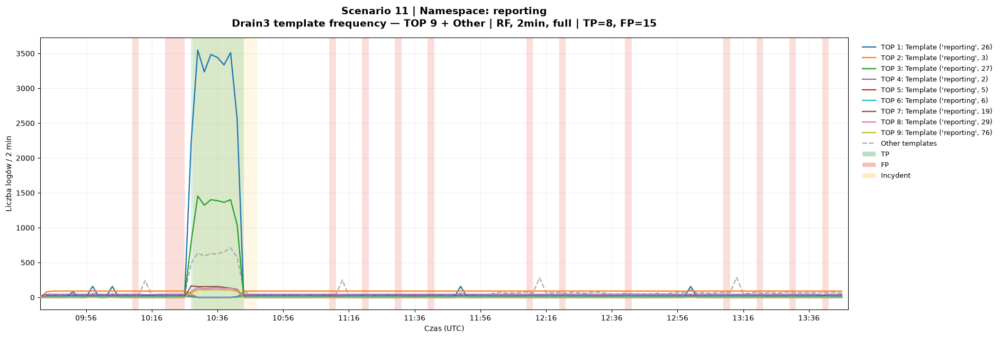

✓ Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\reports\scenario11_reporting_Drain3_TOP9_TP_FP.png


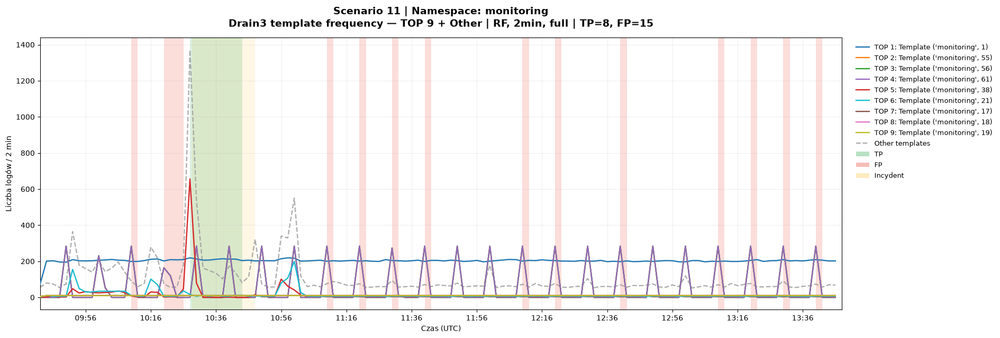

✓ Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\reports\scenario11_monitoring_Drain3_TOP9_TP_FP.png


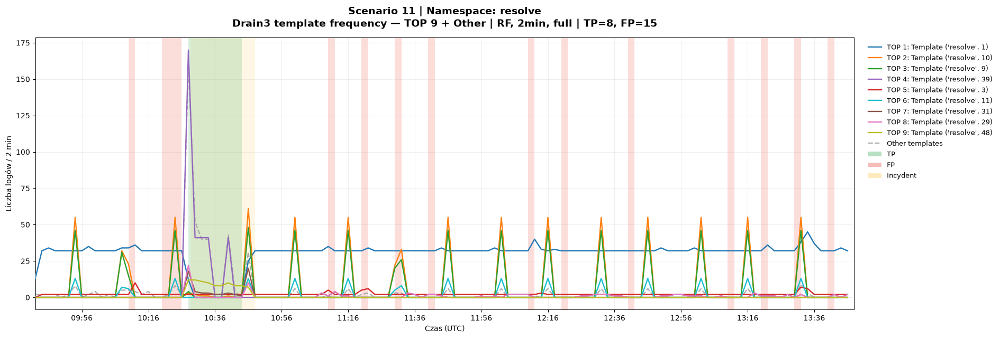

✓ Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\reports\scenario11_resolve_Drain3_TOP9_TP_FP.png


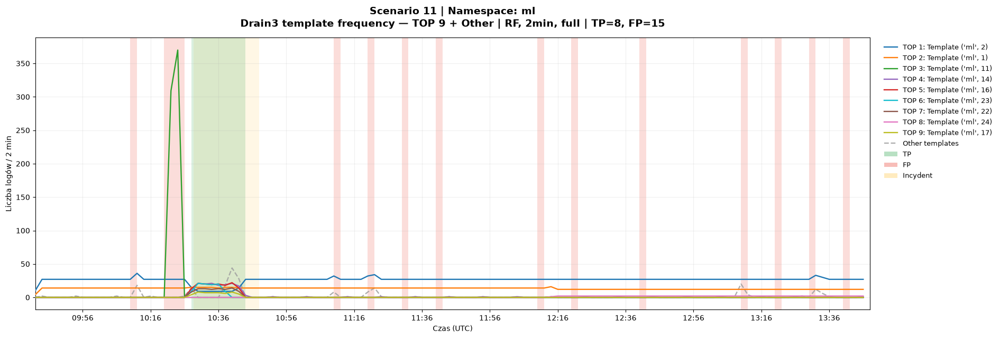

✓ Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\reports\scenario11_ml_Drain3_TOP9_TP_FP.png


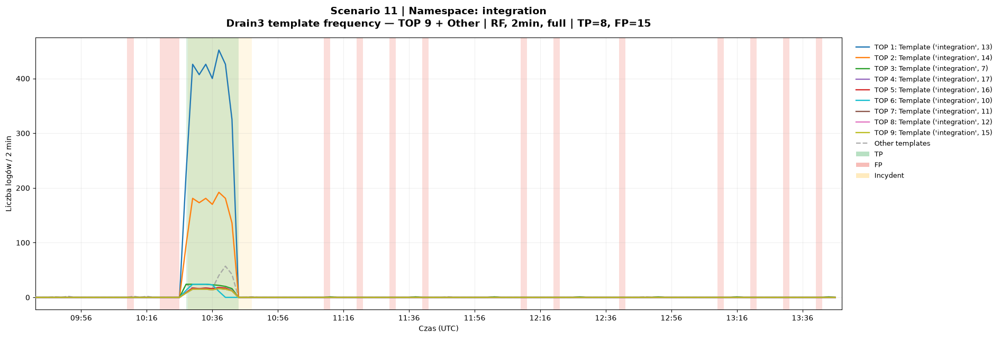

✓ Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\reports\scenario11_integration_Drain3_TOP9_TP_FP.png

Gotowe: 5 osobnych wykresów.


In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import joblib

CASE = "scenario11"
PARSER = "Drain3"
WINDOW = "2min"
TOP_N = 9

# Sparsowane logi z istniejącego cache
parsed = get_parsed_dataframe(PARSER, CASE).copy()

parsed["timestamp"] = pd.to_datetime(
    parsed["timestamp"], utc=True
)
parsed["namespace"] = parsed["namespace"].astype(str)
parsed["template_id"] = parsed["template_id"].astype(str)

# Predykcje trzeciego najlepszego klasyfikatora
pred_path = (
    PRED_DIR
    / "Drain3__2min__full__RF__scenario11.joblib"
)

pred = joblib.load(pred_path)["data"].copy()

pred["timestamp"] = pd.to_datetime(
    pred["timestamp"], utc=True
)
pred["bucket_end"] = pd.to_datetime(
    pred["bucket_end"], utc=True
)

tp_mask = (
    (pred["label_all_known"] == 1)
    & (pred["prediction"] == 1)
)
fp_mask = (
    (pred["label_all_known"] == 0)
    & (pred["prediction"] == 1)
)

tp_windows = pred.loc[tp_mask]
fp_windows = pred.loc[fp_mask]

# Przedział rzeczywistego incydentu
incident_start = pd.to_datetime(
    NEW_CASE_DATA[CASE]["incident_start"], utc=True
)
incident_end = pd.to_datetime(
    NEW_CASE_DATA[CASE]["incident_end"], utc=True
)

# Wspólny zakres osi czasu
time_start = parsed["timestamp"].min().floor("2min")
time_end = parsed["timestamp"].max().ceil("2min")

# Pełna siatka kubełków dla każdego namespace'u
time_grid = pd.date_range(
    start=time_start,
    end=time_end,
    freq=WINDOW,
    inclusive="left",
    tz="UTC",
)

# 9 wyraźnych kolorów
TOP9_COLORS = [
    "#1F77B4",  # niebieski
    "#FF7F0E",  # pomarańczowy
    "#2CA02C",  # zielony
    "#9467BD",  # fioletowy
    "#D62728",  # czerwony
    "#17BECF",  # turkusowy
    "#8C564B",  # brązowy
    "#E377C2",  # różowy
    "#BCBD22",  # oliwkowy
]

OTHER_COLOR = "#A0A0A0"

namespaces = (
    parsed["namespace"]
    .value_counts()
    .index
    .tolist()
)

for namespace in namespaces:

    ns_df = parsed.loc[
        parsed["namespace"] == namespace,
        ["timestamp", "template_id"],
    ].copy()

    # TOP 9 według liczby wystąpień w całym namespace
    top_templates = (
        ns_df["template_id"]
        .value_counts()
        .head(TOP_N)
        .index
        .tolist()
    )

    # Każdy log przypisujemy do TOP 9 lub Other
    ns_df["template_group"] = np.where(
        ns_df["template_id"].isin(top_templates),
        ns_df["template_id"],
        "Other templates",
    )

    # Liczba logów na szablon w każdym kubełku 2 min
    frequency = (
        ns_df
        .groupby([
            pd.Grouper(key="timestamp", freq=WINDOW),
            "template_group",
        ])
        .size()
        .unstack(fill_value=0)
        .reindex(time_grid, fill_value=0)
    )

    for template_id in top_templates:
        if template_id not in frequency.columns:
            frequency[template_id] = 0

    if "Other templates" not in frequency.columns:
        frequency["Other templates"] = 0

    fig, ax = plt.subplots(figsize=(19, 6.5))

    # Rzeczywisty incydent
    ax.axvspan(
        incident_start,
        incident_end,
        facecolor="#FFB300",
        alpha=0.10,
        zorder=0,
    )

    # TP i FP: pionowe obszary odpowiadające kubełkom
    for row in tp_windows.itertuples(index=False):
        ax.axvspan(
            row.timestamp,
            row.bucket_end,
            facecolor="#34A853",
            alpha=0.18,
            zorder=0,
        )

    for row in fp_windows.itertuples(index=False):
        ax.axvspan(
            row.timestamp,
            row.bucket_end,
            facecolor="#EA4335",
            alpha=0.18,
            zorder=0,
        )

    # TOP 9: osobne kolorowe linie
    for i, template_id in enumerate(top_templates):
        ax.plot(
            frequency.index,
            frequency[template_id],
            color=TOP9_COLORS[i],
            linewidth=1.7,
            label=f"TOP {i+1}: Template {template_id}",
            zorder=3,
        )

    # Wszystkie pozostałe szablony razem
    ax.plot(
        frequency.index,
        frequency["Other templates"],
        color=OTHER_COLOR,
        linewidth=1.7,
        alpha=0.85,
        linestyle="--",
        label="Other templates",
        zorder=2,
    )

    ax.set_xlim(time_start, time_end)

    ax.xaxis.set_major_locator(
        mdates.MinuteLocator(interval=20)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M", tz=mdates.UTC)
    )

    ax.set_xlabel("Czas (UTC)")
    ax.set_ylabel("Liczba logów / 2 min")

    ax.set_title(
        f"Scenario 11 | Namespace: {namespace}\n"
        f"Drain3 template frequency — TOP 9 + Other"
        f" | RF, 2min, full | TP=8, FP=15",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )

    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

    handles, labels = ax.get_legend_handles_labels()

    handles += [
        Patch(
            facecolor="#34A853",
            alpha=0.35,
            label="TP",
        ),
        Patch(
            facecolor="#EA4335",
            alpha=0.35,
            label="FP",
        ),
        Patch(
            facecolor="#FFB300",
            alpha=0.25,
            label="Incydent",
        ),
    ]

    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        fontsize=9,
        frameon=False,
    )

    plt.tight_layout()

    output_path = (
        REPORT_DIR
        / f"scenario11_{namespace}_Drain3_TOP9_TP_FP.png"
    )

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"✓ Zapisano: {output_path}")

print(
    f"\nGotowe: {len(namespaces)} osobnych wykresów."
)

In [48]:
import pandas as pd
import ast

CASE = "scenario11"

parsed = get_parsed_dataframe("Drain3", CASE).copy()

TARGETS = [
    ("monitoring", 61),
    ("ml", 11),
]

def normalize_template_id(value):
    """
    Obsługuje:
      61
      '61'
      ('monitoring', 61)
      "('monitoring', 61)"
    """
    if isinstance(value, str):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            pass

    if isinstance(value, tuple) and len(value) == 2:
        return str(value[0]), str(value[1])

    return None, str(value)


parsed["_template_key"] = [
    normalize_template_id(value)
    for value in parsed["template_id"]
]

print("Przykładowe identyfikatory Drain3:")
print(parsed["template_id"].drop_duplicates().head(10).tolist())

for namespace, template_number in TARGETS:

    mask = (
        (parsed["namespace"].astype(str) == namespace)
        & parsed["_template_key"].map(
            lambda key: (
                key == (namespace, str(template_number))
                or key == (None, str(template_number))
            )
        )
    )

    subset = parsed.loc[mask].copy()

    print("\n" + "=" * 90)
    print(f"NAMESPACE: {namespace}")
    print(f"TEMPLATE: {template_number}")
    print(f"LICZBA WYSTĄPIEŃ: {len(subset)}")
    print("=" * 90)

    if subset.empty:
        print("Nie znaleziono — sprawdź identyfikatory powyżej.")
        continue

    print("\nRzeczywisty identyfikator:")
    print(subset["template_id"].iloc[0])

    template_cols = [
        "template",
        "template_text",
        "event_template",
        "parsed_template",
        "cluster_template",
    ]

    available = [
        col for col in template_cols
        if col in subset.columns
    ]

    if available:
        print("\nTREŚĆ SZABLONU:")
        print(subset[available[0]].iloc[0])

    else:
        print("\nKolumny parsera:", subset.columns.tolist())
        print("Brak osobnej kolumny z treścią szablonu.")

    print("\n3 PRZYKŁADOWE LOGI:")

    message_col = next(
        (
            col for col in ["message", "original_message"]
            if col in subset.columns
        ),
        None,
    )

    if message_col:
        for i, message in enumerate(
            subset[message_col].head(3), start=1
        ):
            print(f"\n[{i}] {message}")
    else:
        print("Brak kolumny z oryginalnymi komunikatami.")

Przykładowe identyfikatory Drain3:
[('monitoring', 1), ('monitoring', 2), ('monitoring', 3), ('resolve', 1), ('monitoring', 4), ('monitoring', 5), ('monitoring', 6), ('monitoring', 7), ('monitoring', 8), ('monitoring', 9)]

NAMESPACE: monitoring
TEMPLATE: 61
LICZBA WYSTĄPIEŃ: 6816

Rzeczywisty identyfikator:
('monitoring', 61)

Kolumny parsera: ['timestamp', 'message', 'namespace', 'template_id', '_template_key']
Brak osobnej kolumny z treścią szablonu.

3 PRZYKŁADOWE LOGI:

[1] level=info ts=2026-09-11T09:51:49.603935999Z caller=tables_manager.go:286 msg="finished compacting table" table-name=index_20707

[2] level=info ts=2026-09-11T09:51:49.633432793Z caller=tables_manager.go:286 msg="finished compacting table" table-name=index_20706

[3] level=info ts=2026-09-11T09:51:49.658296827Z caller=tables_manager.go:286 msg="finished compacting table" table-name=index_20705

NAMESPACE: ml
TEMPLATE: 11
LICZBA WYSTĄPIEŃ: 679

Rzeczywisty identyfikator:
('ml', 11)

Kolumny parsera: ['timestamp'

In [49]:
import ast
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

CASE = "scenario11"
PARSER = "Drain3"
WINDOW = "2min"

ABLATION_DIR = PREP_DIR / "ablation_scenario11"
ABLATION_DIR.mkdir(parents=True, exist_ok=True)

parsed = get_parsed_dataframe(PARSER, CASE).copy()

def template_key(value):
    """Normalizuje identyfikatory typu ('monitoring', 61)."""
    if isinstance(value, str):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            pass

    if isinstance(value, (tuple, list)) and len(value) == 2:
        return str(value[0]), str(value[1])

    return None, str(value)

keys = parsed["template_id"].map(template_key)

remove_mask = (
    (
        parsed["namespace"].astype(str).eq("monitoring")
        & keys.map(
            lambda x: x in [
                ("monitoring", "61"),
                (None, "61"),
            ]
        )
    )
    |
    (
        parsed["namespace"].astype(str).eq("ml")
        & keys.map(
            lambda x: x in [
                ("ml", "11"),
                (None, "11"),
            ]
        )
    )
)

print("Logi przed:", len(parsed))
print("Usuwane monitoring / 61:", int((
    remove_mask & parsed["namespace"].astype(str).eq("monitoring")
).sum()))
print("Usuwane ml / 11:", int((
    remove_mask & parsed["namespace"].astype(str).eq("ml")
).sum()))

assert remove_mask.sum() > 0, (
    "Nie znaleziono wskazanych szablonów. "
    "Nie uruchamiamy eksperymentu na niezmienionych danych."
)

parsed_clean = parsed.loc[~remove_mask].copy()

print("Logi po:", len(parsed_clean))
print("Usunięto łącznie:", int(remove_mask.sum()))

# Ponowne obliczenie wszystkich 18 cech
clean_buckets = build_namespace_buckets(
    parsed_clean,
    window_size=WINDOW,
    history_minutes=30,
)

print("\nKolumny nowych kubełków:")
print(clean_buckets.columns.tolist())
print("Liczba kubełków:", len(clean_buckets))

Logi przed: 154674
Usuwane monitoring / 61: 6816
Usuwane ml / 11: 679
Logi po: 147179
Usunięto łącznie: 7495

Kolumny nowych kubełków:
['timestamp', 'total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'templates_enriched_5x', 'templates_enriched_10x']
Liczba kubełków: 123


In [50]:
from sklearn.base import clone

original = joblib.load(
    BUCKET_DIR / "Drain3__scenario11__2min.joblib"
).copy()

original["timestamp"] = pd.to_datetime(
    original["timestamp"], utc=True
)

clean_buckets["timestamp"] = pd.to_datetime(
    clean_buckets["timestamp"], utc=True
)

# Tylko 18 cech, bez przenoszenia etykiet z nowej agregacji
clean_features = clean_buckets[
    ["timestamp"] + FEATURES18
].copy()

assert not clean_features["timestamp"].duplicated().any()

aligned = original[
    [
        "case",
        "timestamp",
        "bucket_end",
        "label_primary",
        "label_all_known",
    ]
].merge(
    clean_features,
    on="timestamp",
    how="left",
    validate="one_to_one",
)

missing_buckets = aligned[FEATURES18].isna().all(axis=1).sum()

print("Oryginalne kubełki:", len(original))
print("Kubełki po dopasowaniu:", len(aligned))
print("Kubełki bez logów po usunięciu:", missing_buckets)

# Uzupełniamy puste kubełki zerami.
aligned[FEATURES18] = (
    aligned[FEATURES18]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

assert len(aligned) == len(original)
assert aligned["label_all_known"].equals(
    original["label_all_known"].reset_index(drop=True)
)

# Trening na pozostałych 10 oryginalnych scenariuszach
train_frames = []

for case in SCENARIOS:
    if case == CASE:
        continue

    train_frames.append(
        joblib.load(
            BUCKET_DIR / f"Drain3__{case}__2min.joblib"
        )
    )

train_df = pd.concat(train_frames, ignore_index=True)

X_train = (
    train_df[FEATURES18]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

y_train = train_df["label_all_known"].to_numpy(dtype=int)

X_test = aligned[FEATURES18].to_numpy(dtype=np.float32)
y_test = aligned["label_all_known"].to_numpy(dtype=int)

model = clone(MODELS["RF"])
model.fit(X_train, y_train)

aligned["prediction"] = model.predict(X_test).astype(int)

metrics_clean = calculate_metrics(
    y_test,
    aligned["prediction"].to_numpy(),
)

print("\nWYNIKI PO USUNIĘCIU SZABLONÓW")
print(pd.Series(metrics_clean))

joblib.dump(
    {
        "data": aligned,
        "metrics": metrics_clean,
        "removed_templates": [
            ("monitoring", 61),
            ("ml", 11),
        ],
    },
    ABLATION_DIR / "Drain3_RF_2min_full_scenario11.joblib",
)

Oryginalne kubełki: 123
Kubełki po dopasowaniu: 123
Kubełki bez logów po usunięciu: 0

WYNIKI PO USUNIĘCIU SZABLONÓW
TP         8.000000
FP        14.000000
TN        98.000000
FN         3.000000
acc        0.861789
prec       0.363636
recall     0.727273
F1         0.484848
MCC        0.448463
dtype: float64


['C:\\Users\\kzieba\\aiops_private\\results\\benchmark_3h_LOSO_72_v2\\ablation_scenario11\\Drain3_RF_2min_full_scenario11.joblib']

In [51]:
baseline = joblib.load(
    PRED_DIR / "Drain3__2min__full__RF__scenario11.joblib"
)["data"]

metrics_before = calculate_metrics(
    baseline["label_all_known"].astype(int),
    baseline["prediction"].astype(int),
)

comparison = pd.DataFrame(
    {
        "Przed usunięciem": metrics_before,
        "Po usunięciu": metrics_clean,
    }
)

comparison["Zmiana"] = (
    comparison["Po usunięciu"]
    - comparison["Przed usunięciem"]
)

display(comparison)

,Przed usunięciem,Po usunięciu,Zmiana
TP,8.000000,8.000000,0.000000
FP,15.000000,14.000000,-1.000000
TN,97.000000,98.000000,1.000000
FN,3.000000,3.000000,0.000000
acc,0.853659,0.861789,0.008130
prec,0.347826,0.363636,0.015810
recall,0.727273,0.727273,0.000000
F1,0.470588,0.484848,0.014260
MCC,0.434258,0.448463,0.014205


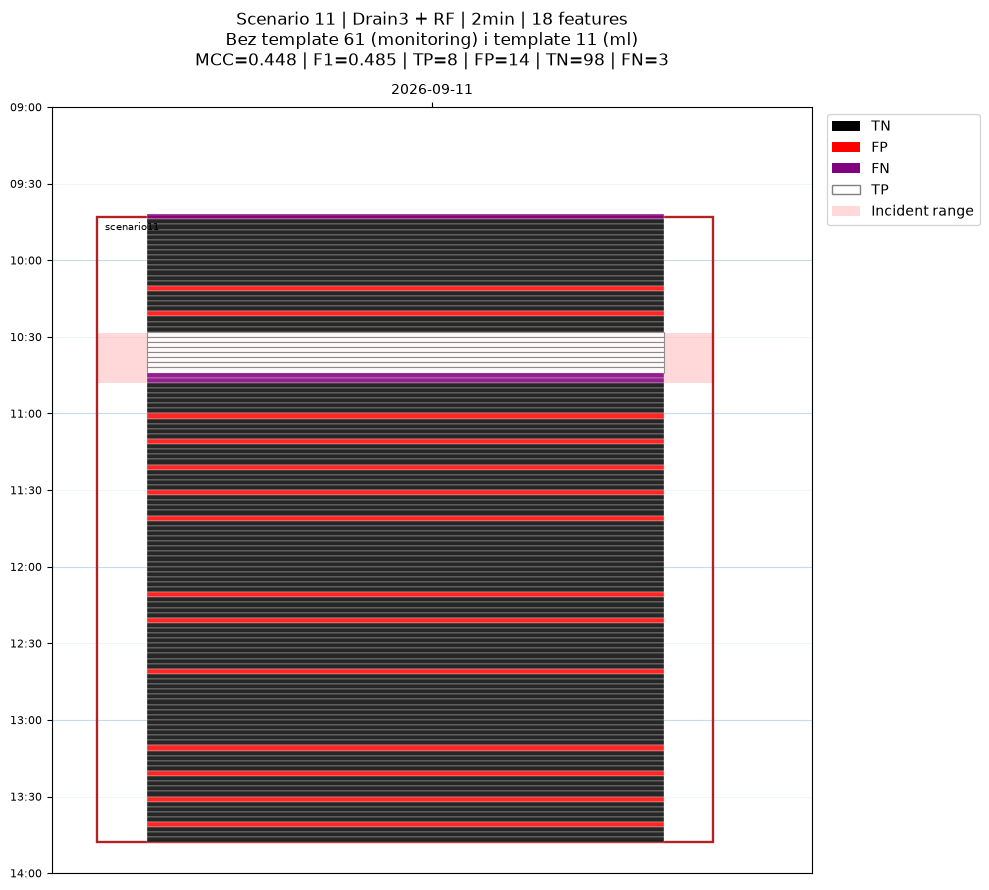

In [53]:
OUTCOME_COLORS = {
    "TN": "black",
    "FP": "red",
    "FN": "purple",
    "TP": "white",
}

calendar_buckets = aligned.copy()

y_true = calendar_buckets["label_all_known"].astype(int)
y_pred = calendar_buckets["prediction"].astype(int)

calendar_buckets["outcome"] = np.select(
    [
        (y_true == 1) & (y_pred == 1),
        (y_true == 0) & (y_pred == 1),
        (y_true == 0) & (y_pred == 0),
        (y_true == 1) & (y_pred == 0),
    ],
    ["TP", "FP", "TN", "FN"],
    default="UNKNOWN",
)

for col in ["timestamp", "bucket_end"]:
    calendar_buckets[col] = (
        pd.to_datetime(calendar_buckets[col], utc=True)
        .dt.tz_localize(None)
    )

segments = CALENDAR_SEGMENTS_3H[
    CALENDAR_SEGMENTS_3H["case"] == "scenario11"
].copy()

title = (
    "Scenario 11 | Drain3 + RF | 2min | 18 features\n"
    "Bez template 61 (monitoring) i template 11 (ml)\n"
    f"MCC={metrics_clean['MCC']:.3f} | "
    f"F1={metrics_clean['F1']:.3f} | "
    f"TP={metrics_clean['TP']} | "
    f"FP={metrics_clean['FP']} | "
    f"TN={metrics_clean['TN']} | "
    f"FN={metrics_clean['FN']}"
)

plot_calendar_with_buckets(
    calendar_segments=segments,
    bucket_df=calendar_buckets,
    title=title,
    start_hour=9,
    end_hour=14,
)

Zgodność z checkpointem: 100.00%


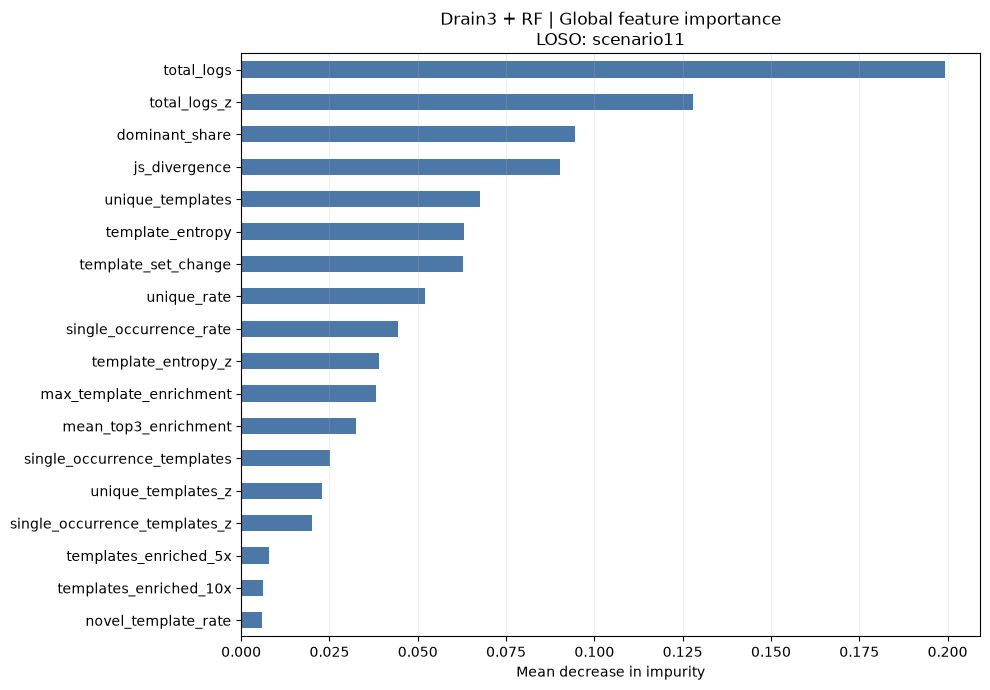


FP uporządkowane według pewności modelu:


,timestamp,probability
0,2026-09-11 11:20:00+00:00,0.790000
1,2026-09-11 11:10:00+00:00,0.760000
2,2026-09-11 11:30:00+00:00,0.690000
3,2026-09-11 10:22:00+00:00,0.666667
4,2026-09-11 12:20:00+00:00,0.636667
5,2026-09-11 10:20:00+00:00,0.623333
6,2026-09-11 10:10:00+00:00,0.613333
7,2026-09-11 12:40:00+00:00,0.603333
8,2026-09-11 11:40:00+00:00,0.556667
9,2026-09-11 10:24:00+00:00,0.550000


In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.inspection import permutation_importance

CASE = "scenario11"
FEATURES = list(FEATURES18)

# Oryginalne dane
train_frames = [
    joblib.load(
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    )
    for case in SCENARIOS
    if case != CASE
]

train_df = pd.concat(train_frames, ignore_index=True)

test_df = joblib.load(
    BUCKET_DIR / "Drain3__scenario11__2min.joblib"
).copy()

X_train = (
    train_df[FEATURES]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

y_train = train_df["label_all_known"].astype(int)

X_test = (
    test_df[FEATURES]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

y_test = test_df["label_all_known"].astype(int)

# Ten sam RF co w benchmarku
rf = clone(MODELS["RF"])
rf.fit(X_train, y_train)

# Porównanie z zapisanymi predykcjami
checkpoint = joblib.load(
    PRED_DIR / "Drain3__2min__full__RF__scenario11.joblib"
)["data"].copy()

checkpoint["timestamp"] = pd.to_datetime(
    checkpoint["timestamp"], utc=True
)
test_df["timestamp"] = pd.to_datetime(
    test_df["timestamp"], utc=True
)

assert test_df["timestamp"].is_unique
assert checkpoint["timestamp"].is_unique

assert set(test_df["timestamp"]) == set(checkpoint["timestamp"]), (
    "Kubełki testowe nie zgadzają się z checkpointem."
)

checkpoint = (
    checkpoint.set_index("timestamp")
    .loc[test_df["timestamp"]]
    .reset_index()
)

predictions = rf.predict(X_test)

agreement = np.mean(
    predictions == checkpoint["prediction"].to_numpy()
)

print(f"Zgodność z checkpointem: {agreement:.2%}")

if agreement < 1.0:
    print(
        "UWAGA: Odtworzony RF nie daje identycznych predykcji. "
        "Przed interpretacją SHAP trzeba sprawdzić konfigurację "
        "modelu i preprocessing."
    )
else:
    # Ważność cech według RF
    importance = pd.Series(
        rf.feature_importances_,
        index=FEATURES,
    ).sort_values()

    fig, ax = plt.subplots(figsize=(10, 7))

    importance.plot.barh(
        ax=ax,
        color="#4C78A8",
    )

    ax.set_title(
        "Drain3 + RF | Global feature importance\n"
        "LOSO: scenario11"
    )
    ax.set_xlabel("Mean decrease in impurity")
    ax.grid(axis="x", alpha=0.2)

    plt.tight_layout()
    plt.show()

    # Prawdopodobieństwa klasy 1
    class_1_index = list(rf.classes_).index(1)
    probabilities = rf.predict_proba(X_test)[:, class_1_index]

    analysis_df = test_df[
        ["timestamp", "label_all_known"]
    ].copy()

    analysis_df["prediction"] = predictions
    analysis_df["probability"] = probabilities

    analysis_df["outcome"] = np.select(
        [
            (analysis_df["label_all_known"] == 1)
            & (analysis_df["prediction"] == 1),

            (analysis_df["label_all_known"] == 0)
            & (analysis_df["prediction"] == 1),

            (analysis_df["label_all_known"] == 1)
            & (analysis_df["prediction"] == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    print("\nFP uporządkowane według pewności modelu:")

    display(
        analysis_df.loc[
            analysis_df["outcome"] == "FP",
            ["timestamp", "probability"],
        ]
        .sort_values("probability", ascending=False)
        .reset_index(drop=True)
    )

Mediany cech według wyniku klasyfikacji:


outcome,FN,FP,TN,TP
total_logs,659.000,1475.000,621.000,7095.000
total_logs_z,-1.025,12.771,-0.079,16.969
dominant_share,0.310,0.191,0.326,0.464
template_entropy,4.217,3.649,4.000,3.231
unique_templates,57.000,63.000,56.000,114.000
template_set_change,0.750,0.559,0.587,0.658
js_divergence,0.736,0.133,0.158,0.196


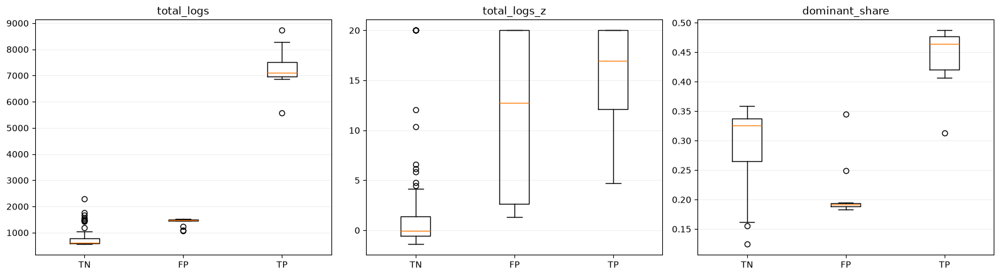

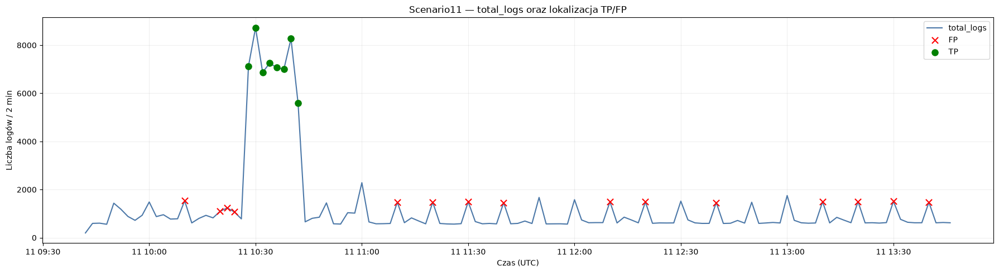

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

explain_df = X_test.copy().reset_index(drop=True)
explain_df["timestamp"] = pd.to_datetime(
    test_df["timestamp"].reset_index(drop=True), utc=True
)
explain_df["outcome"] = analysis_df["outcome"].to_numpy()
explain_df["probability"] = analysis_df["probability"].to_numpy()

features_to_compare = [
    "total_logs",
    "total_logs_z",
    "dominant_share",
    "template_entropy",
    "unique_templates",
    "template_set_change",
    "js_divergence",
]

# 1. Mediany cech w grupach
comparison = (
    explain_df
    .groupby("outcome")[features_to_compare]
    .median()
    .T
)

print("Mediany cech według wyniku klasyfikacji:")
display(comparison.round(3))

# 2. Wykresy rozkładów
fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5)
)

for ax, feature in zip(
    axes,
    ["total_logs", "total_logs_z", "dominant_share"]
):
    groups = [
        explain_df.loc[
            explain_df["outcome"] == outcome, feature
        ].dropna().to_numpy()
        for outcome in ["TN", "FP", "TP"]
    ]

    ax.boxplot(
        groups,
        tick_labels=["TN", "FP", "TP"],
        showfliers=True,
    )
    ax.set_title(feature)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# 3. Przebieg liczby logów w całym scenario11
fig, ax1 = plt.subplots(figsize=(18, 5))

ax1.plot(
    explain_df["timestamp"],
    explain_df["total_logs"],
    color="#4C78A8",
    linewidth=1.5,
    label="total_logs",
)

for outcome, color, marker in [
    ("FP", "red", "x"),
    ("TP", "green", "o"),
]:
    selected = explain_df[
        explain_df["outcome"] == outcome
    ]

    ax1.scatter(
        selected["timestamp"],
        selected["total_logs"],
        color=color,
        marker=marker,
        s=65,
        label=outcome,
        zorder=5,
    )

ax1.set_title(
    "Scenario11 — total_logs oraz lokalizacja TP/FP"
)
ax1.set_xlabel("Czas (UTC)")
ax1.set_ylabel("Liczba logów / 2 min")
ax1.grid(alpha=0.2)
ax1.legend()

plt.tight_layout()
plt.show()

In [57]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 14.8 MB/s  0:00:00

   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Maksymalna różnica SHAP vs RF: 9.43689570931383e-16

FP: 2026-09-11 11:20:00+00:00
Prawdopodobieństwo RF: 0.79


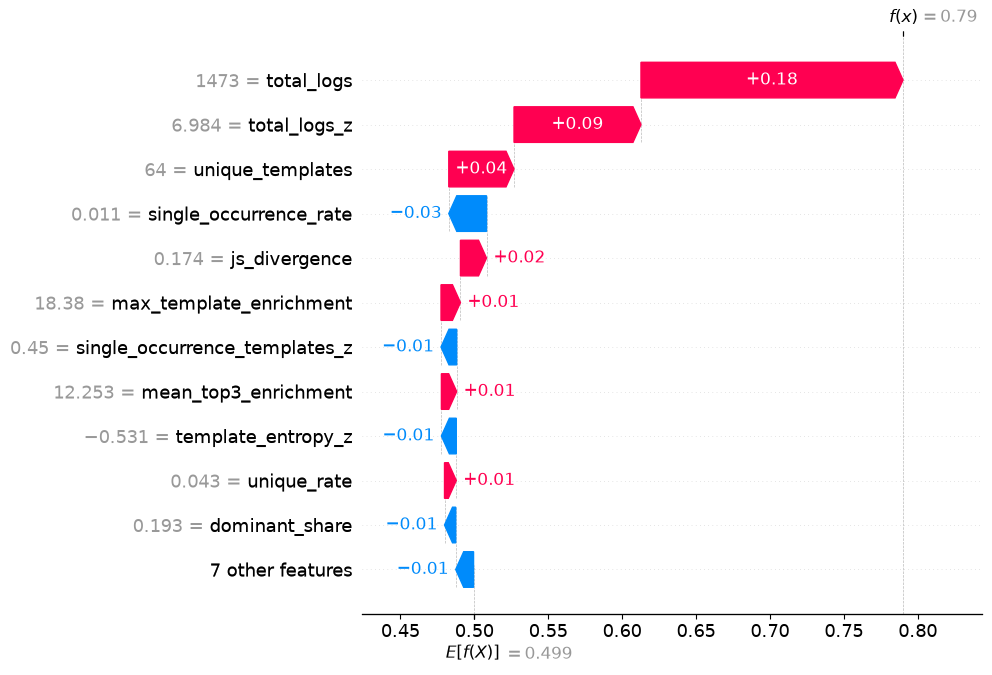


FP: 2026-09-11 10:22:00+00:00
Prawdopodobieństwo RF: 0.6667


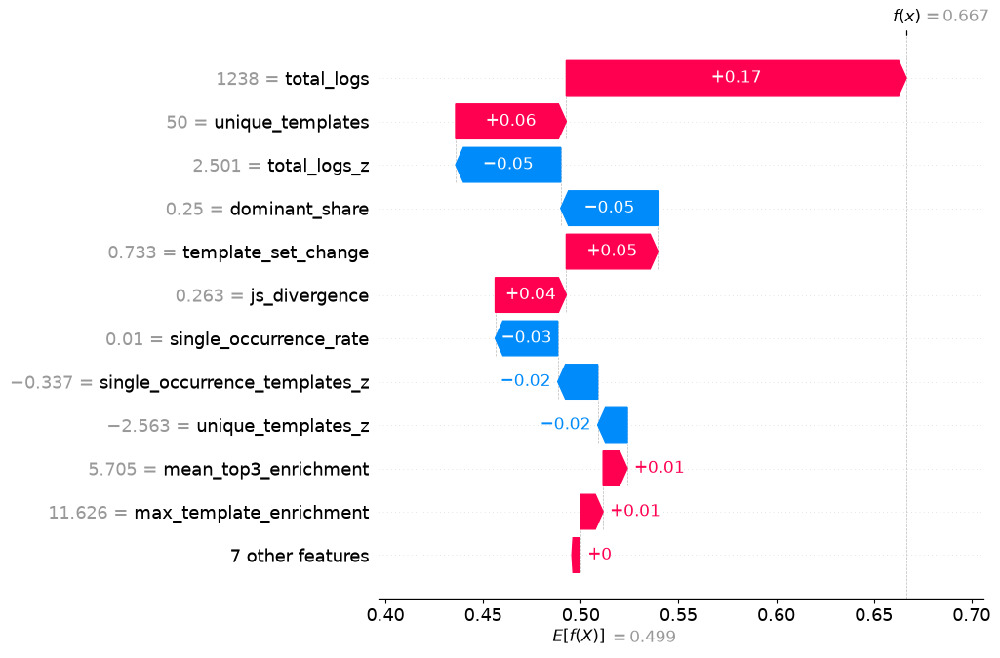


FP: 2026-09-11 13:40:00+00:00
Prawdopodobieństwo RF: 0.5367


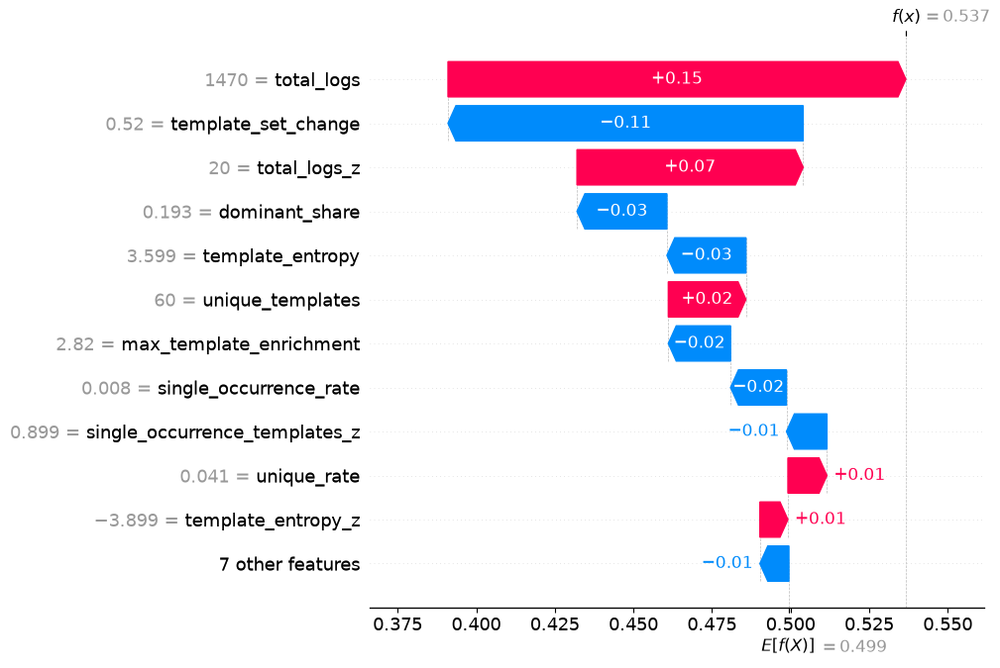

In [58]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Wyjaśniamy wyłącznie kubełki scenario11
explainer = shap.TreeExplainer(rf)
shap_explanation = explainer(X_test)

values = shap_explanation.values
base_values = shap_explanation.base_values

# Dla klasyfikacji binarnej różne wersje SHAP
# mogą zwracać różne kształty tablic.
if values.ndim == 3:
    positive_index = list(rf.classes_).index(1)
    values = values[:, :, positive_index]

    if np.ndim(base_values) == 2:
        base_values = base_values[:, positive_index]

elif values.ndim != 2:
    raise ValueError(
        f"Nieoczekiwany kształt SHAP: {values.shape}"
    )

if np.ndim(base_values) == 0:
    base_values = np.full(len(X_test), base_values)

# Kontrola, czy SHAP sumuje się do wyniku RF
shap_output = np.asarray(base_values) + values.sum(axis=1)
rf_probability = rf.predict_proba(X_test)[
    :, list(rf.classes_).index(1)
]

print(
    "Maksymalna różnica SHAP vs RF:",
    np.max(np.abs(shap_output - rf_probability))
)

targets = [
    "2026-09-11 11:20:00+00:00",
    "2026-09-11 10:22:00+00:00",
    "2026-09-11 13:40:00+00:00",
]

timestamps = pd.to_datetime(
    test_df["timestamp"], utc=True
).reset_index(drop=True)

for target in targets:
    matches = np.flatnonzero(
        timestamps == pd.Timestamp(target)
    )

    if len(matches) != 1:
        print("Nie znaleziono kubełka:", target)
        continue

    idx = matches[0]

    explanation = shap.Explanation(
        values=values[idx],
        base_values=np.asarray(base_values)[idx],
        data=X_test.iloc[idx].to_numpy(),
        feature_names=X_test.columns.tolist(),
    )

    print("\n" + "=" * 65)
    print("FP:", target)
    print(
        "Prawdopodobieństwo RF:",
        round(float(rf_probability[idx]), 4)
    )

    shap.plots.waterfall(
        explanation,
        max_display=12,
        show=True,
    )

ODSTĘPY MIĘDZY FP


,timestamp,delta_minutes,probability,total_logs,total_logs_z,dominant_share
14,2026-09-11 10:10:00+00:00,NaN,0.613333,1533,2.768377,0.185258
19,2026-09-11 10:20:00+00:00,10.0,0.623333,1097,1.510578,0.184139
20,2026-09-11 10:22:00+00:00,2.0,0.666667,1238,2.501237,0.249596
21,2026-09-11 10:24:00+00:00,2.0,0.550000,1072,1.334930,0.345149
44,2026-09-11 11:10:00+00:00,46.0,0.760000,1475,1.979098,0.192542
49,2026-09-11 11:20:00+00:00,10.0,0.790000,1473,6.983968,0.192804
54,2026-09-11 11:30:00+00:00,10.0,0.690000,1492,20.000000,0.183646
59,2026-09-11 11:40:00+00:00,10.0,0.556667,1455,20.000000,0.195189
74,2026-09-11 12:10:00+00:00,30.0,0.530000,1493,12.771336,0.190221
79,2026-09-11 12:20:00+00:00,10.0,0.636667,1485,10.716909,0.191246



CZĘSTOŚĆ ODSTĘPÓW:


delta_minutes
2.0     2
10.0    8
20.0    1
30.0    2
46.0    1
Name: count, dtype: int64

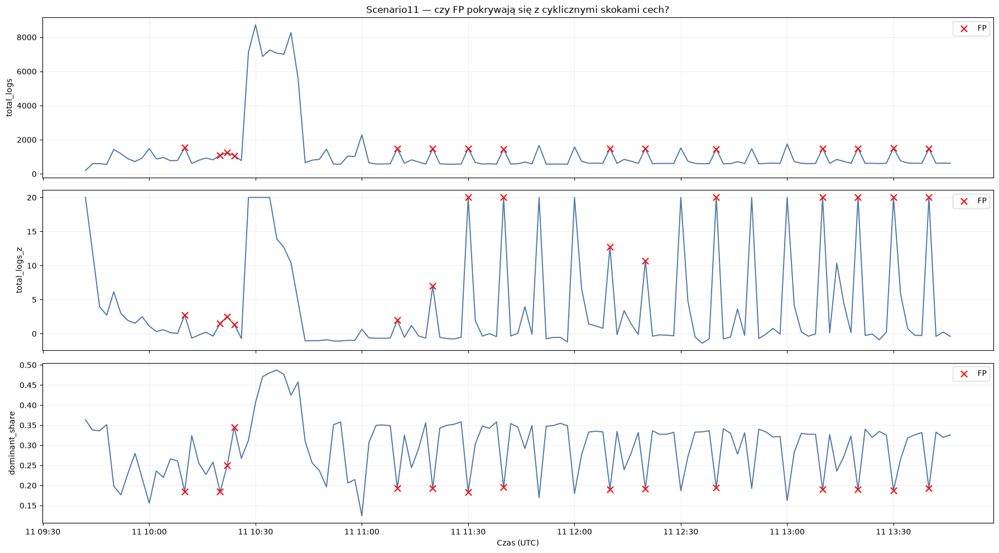

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = explain_df.sort_values("timestamp").copy()

fp = df[df["outcome"] == "FP"].copy()

print("ODSTĘPY MIĘDZY FP")
fp["delta_minutes"] = (
    fp["timestamp"].diff().dt.total_seconds() / 60
)

display(fp[[
    "timestamp",
    "delta_minutes",
    "probability",
    "total_logs",
    "total_logs_z",
    "dominant_share",
]])

print("\nCZĘSTOŚĆ ODSTĘPÓW:")
display(
    fp["delta_minutes"]
    .value_counts()
    .sort_index()
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(18, 10),
    sharex=True,
)

features = [
    "total_logs",
    "total_logs_z",
    "dominant_share",
]

for ax, feature in zip(axes, features):

    ax.plot(
        df["timestamp"],
        df[feature],
        color="#4C78A8",
        linewidth=1.4,
    )

    ax.scatter(
        fp["timestamp"],
        fp[feature],
        color="red",
        s=65,
        marker="x",
        label="FP",
        zorder=5,
    )

    ax.set_ylabel(feature)
    ax.grid(alpha=0.2)
    ax.legend()

axes[0].set_title(
    "Scenario11 — czy FP pokrywają się z cyklicznymi skokami cech?"
)

axes[-1].set_xlabel("Czas (UTC)")
plt.tight_layout()
plt.show()

,buckets,mean_logs,median_logs,mean_z,fp_count,tp_count,fp_rate
cycle_position,,,,,,,
0,24,2107.625,1492.5,13.090,13,2,0.542
2,25,1121.760,619.0,2.672,1,2,0.040
4,25,951.240,622.0,1.909,1,1,0.040
6,25,941.120,633.0,1.067,0,1,0.000
8,24,1197.417,616.0,1.309,0,2,0.000


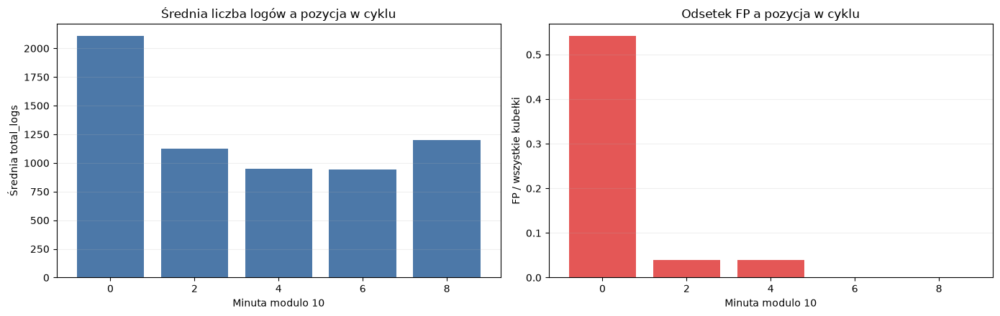

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

cycle_df = explain_df.copy()

cycle_df["timestamp"] = pd.to_datetime(
    cycle_df["timestamp"], utc=True
)

# Pozycja kubełka w cyklu 10-minutowym
cycle_df["cycle_position"] = (
    cycle_df["timestamp"].dt.minute % 10
)

cycle_summary = (
    cycle_df.groupby("cycle_position")
    .agg(
        buckets=("outcome", "size"),
        mean_logs=("total_logs", "mean"),
        median_logs=("total_logs", "median"),
        mean_z=("total_logs_z", "mean"),
        fp_count=("outcome", lambda x: (x == "FP").sum()),
        tp_count=("outcome", lambda x: (x == "TP").sum()),
    )
)

cycle_summary["fp_rate"] = (
    cycle_summary["fp_count"]
    / cycle_summary["buckets"]
)

display(cycle_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(
    cycle_summary.index.astype(str),
    cycle_summary["mean_logs"],
    color="#4C78A8",
)
axes[0].set_title("Średnia liczba logów a pozycja w cyklu")
axes[0].set_xlabel("Minuta modulo 10")
axes[0].set_ylabel("Średnia total_logs")
axes[0].grid(axis="y", alpha=0.2)

axes[1].bar(
    cycle_summary.index.astype(str),
    cycle_summary["fp_rate"],
    color="#E45756",
)
axes[1].set_title("Odsetek FP a pozycja w cyklu")
axes[1].set_xlabel("Minuta modulo 10")
axes[1].set_ylabel("FP / wszystkie kubełki")
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

Liczba cech: 18
Liczba kubełków: 123
outcome
TN    97
FP    15
TP     8
FN     3
Name: count, dtype: int64


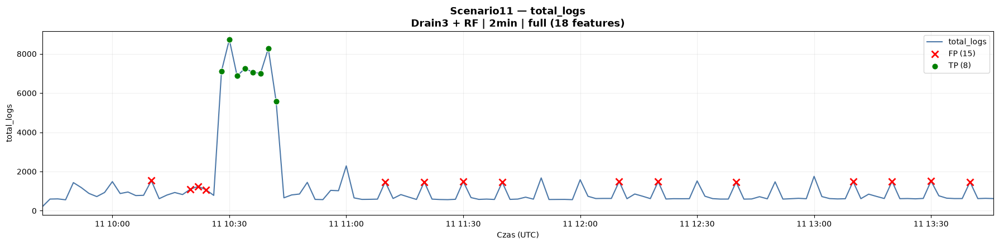

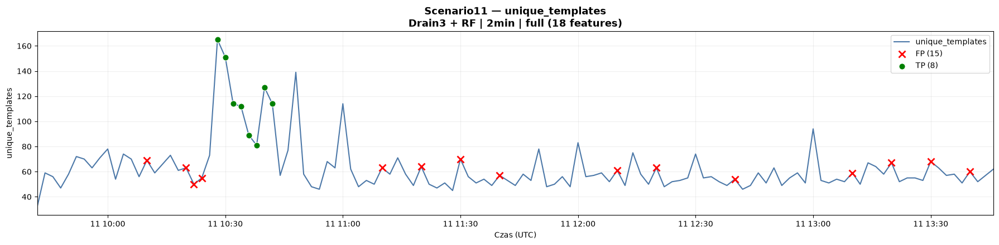

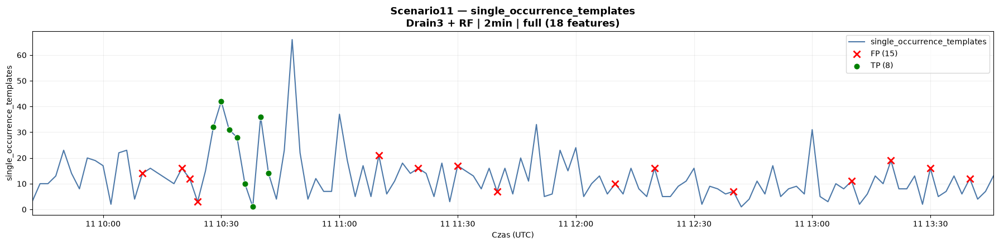

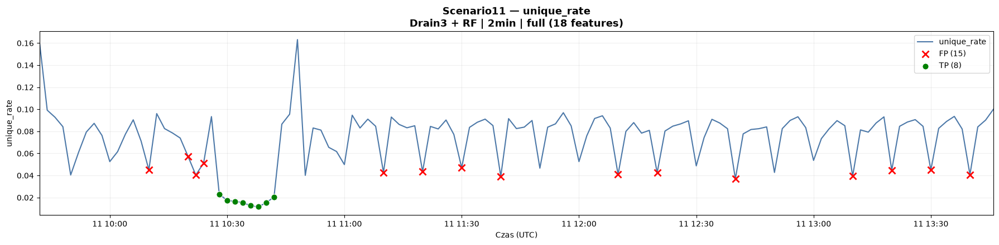

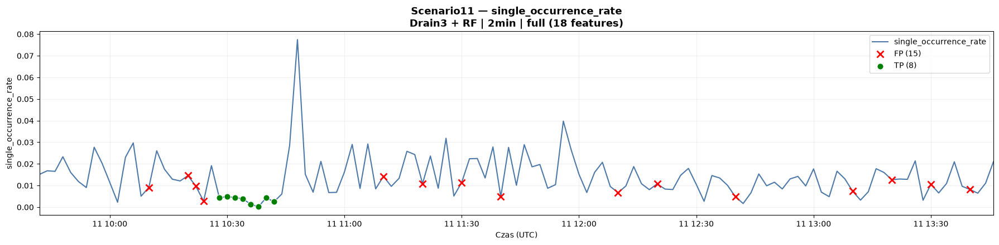

...

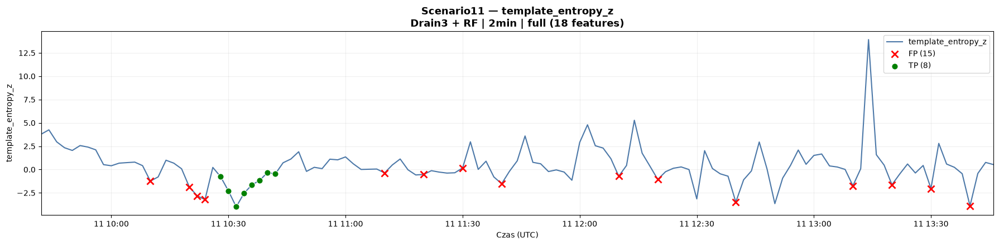

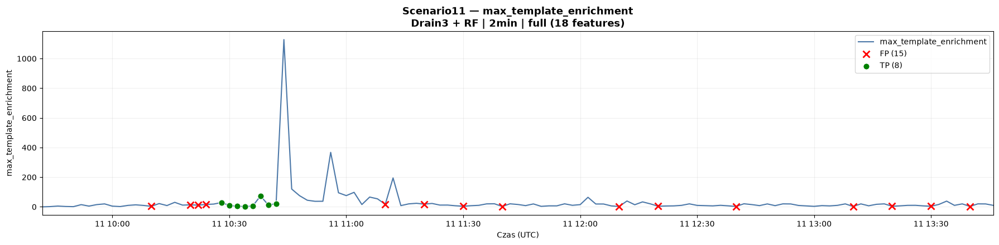

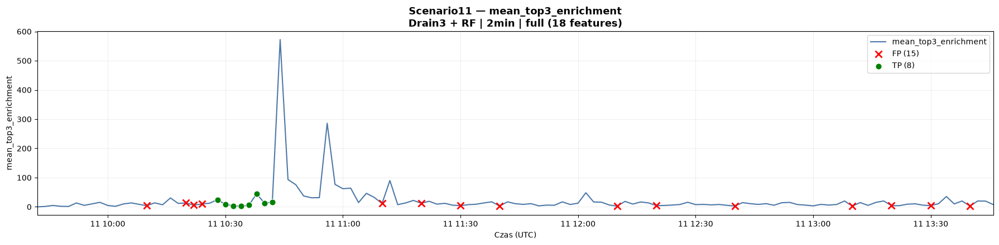

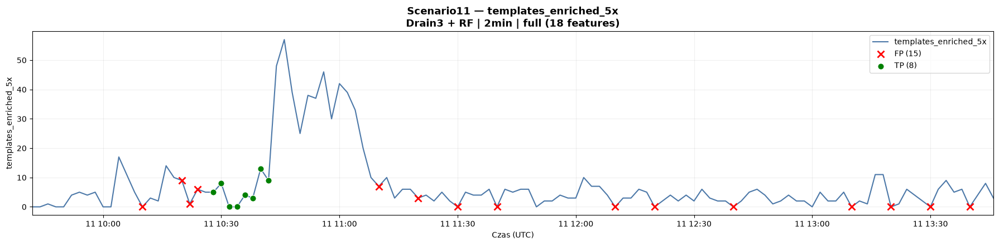

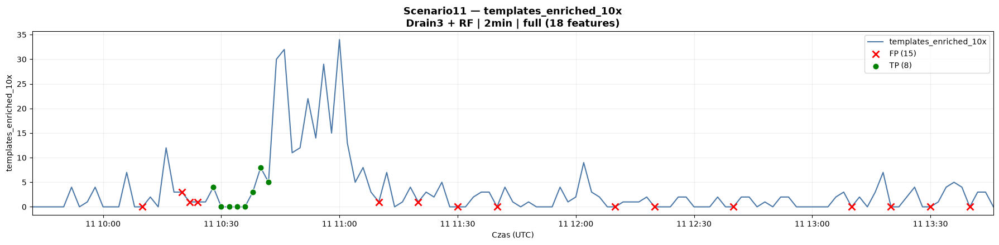

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

CASE = "scenario11"

# Oryginalne 18 cech
features_df = joblib.load(
    BUCKET_DIR / f"Drain3__{CASE}__2min.joblib"
).copy()

# Oryginalne predykcje RF
pred_df = joblib.load(
    PRED_DIR / f"Drain3__2min__full__RF__{CASE}.joblib"
)["data"].copy()

features_df["timestamp"] = pd.to_datetime(
    features_df["timestamp"], utc=True
)
pred_df["timestamp"] = pd.to_datetime(
    pred_df["timestamp"], utc=True
)

# Łączymy po timestamp, nie po indeksie
features_df = features_df.merge(
    pred_df[
        ["timestamp", "label_all_known", "prediction"]
    ],
    on="timestamp",
    how="inner",
    validate="one_to_one",
    suffixes=("", "_pred"),
)

assert len(features_df) == len(pred_df), (
    "Nie wszystkie kubełki zostały dopasowane."
)

y_true = features_df["label_all_known"].astype(int)
y_pred = features_df["prediction"].astype(int)

features_df["outcome"] = np.select(
    [
        (y_true == 1) & (y_pred == 1),
        (y_true == 0) & (y_pred == 1),
        (y_true == 1) & (y_pred == 0),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)

features_df = (
    features_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Wszystkie 18 cech
feature_columns = list(FEATURES18)

print("Liczba cech:", len(feature_columns))
print("Liczba kubełków:", len(features_df))
print(features_df["outcome"].value_counts())

# Wspólny zakres czasu
time_min = features_df["timestamp"].min()
time_max = features_df["timestamp"].max()

for feature in feature_columns:

    fig, ax = plt.subplots(figsize=(18, 4.5))

    # Przebieg cechy
    ax.plot(
        features_df["timestamp"],
        features_df[feature],
        color="#4C78A8",
        linewidth=1.5,
        label=feature,
        zorder=2,
    )

    # False Positives
    fp = features_df[
        features_df["outcome"] == "FP"
    ]

    ax.scatter(
        fp["timestamp"],
        fp[feature],
        color="red",
        marker="x",
        s=75,
        linewidths=2,
        label=f"FP ({len(fp)})",
        zorder=5,
    )

    # True Positives
    tp = features_df[
        features_df["outcome"] == "TP"
    ]

    ax.scatter(
        tp["timestamp"],
        tp[feature],
        color="green",
        marker="o",
        s=65,
        edgecolors="white",
        linewidths=0.8,
        label=f"TP ({len(tp)})",
        zorder=5,
    )

    ax.set_title(
        f"Scenario11 — {feature}\n"
        "Drain3 + RF | 2min | full (18 features)",
        fontsize=13,
        fontweight="bold",
    )

    ax.set_xlabel("Czas (UTC)")
    ax.set_ylabel(feature)
    ax.set_xlim(time_min, time_max)

    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

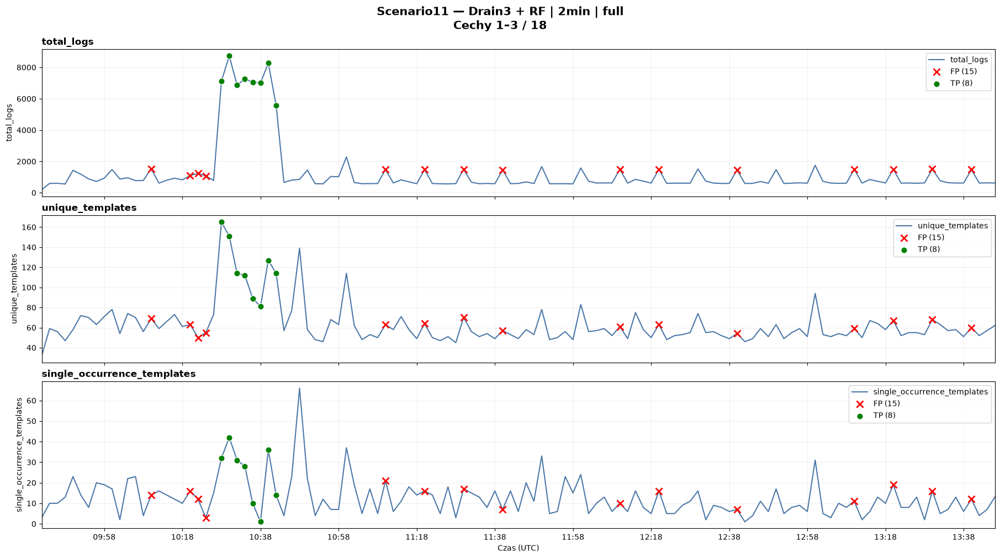

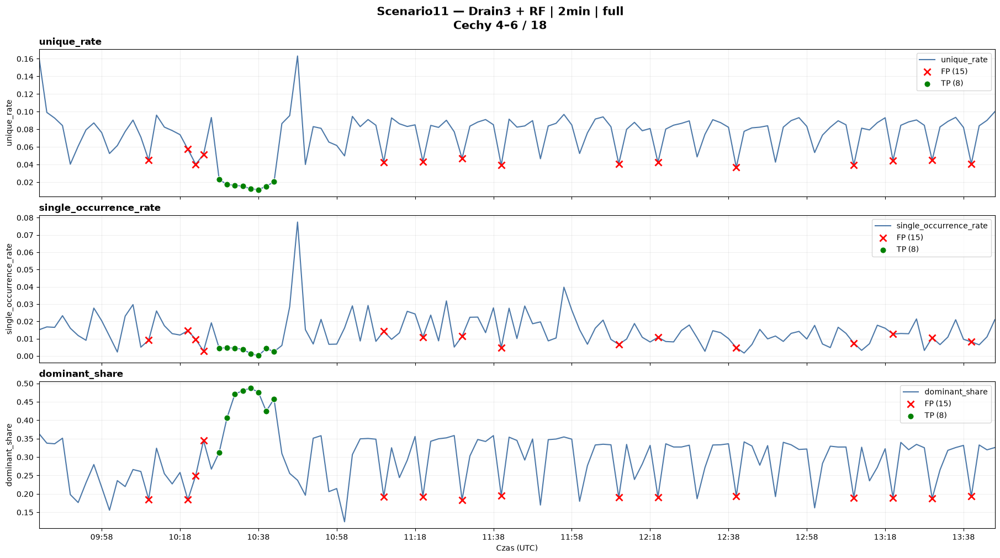

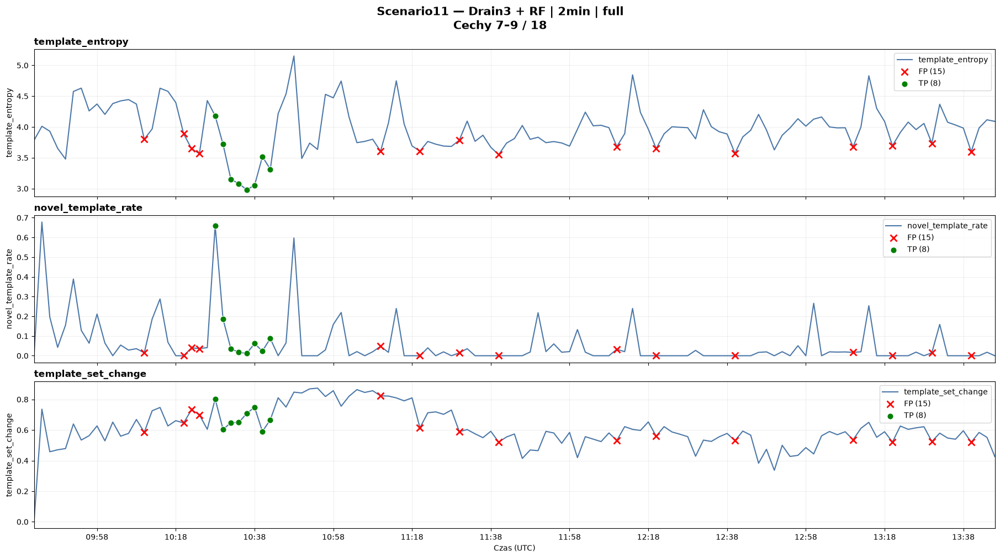

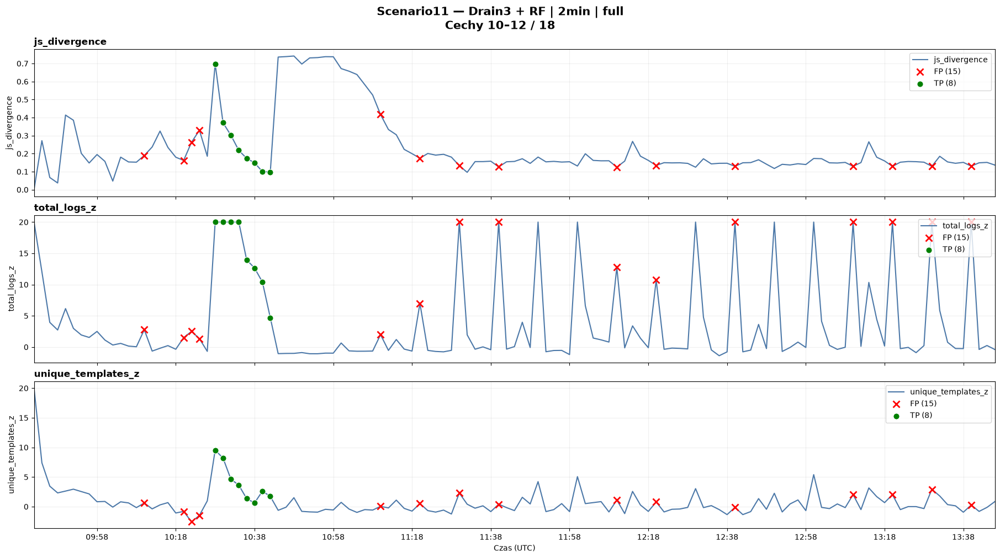

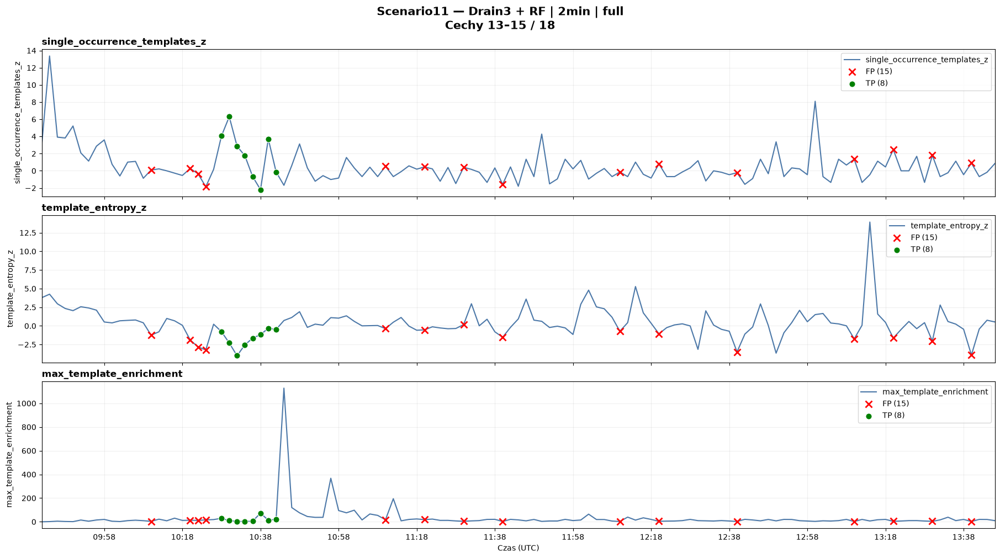

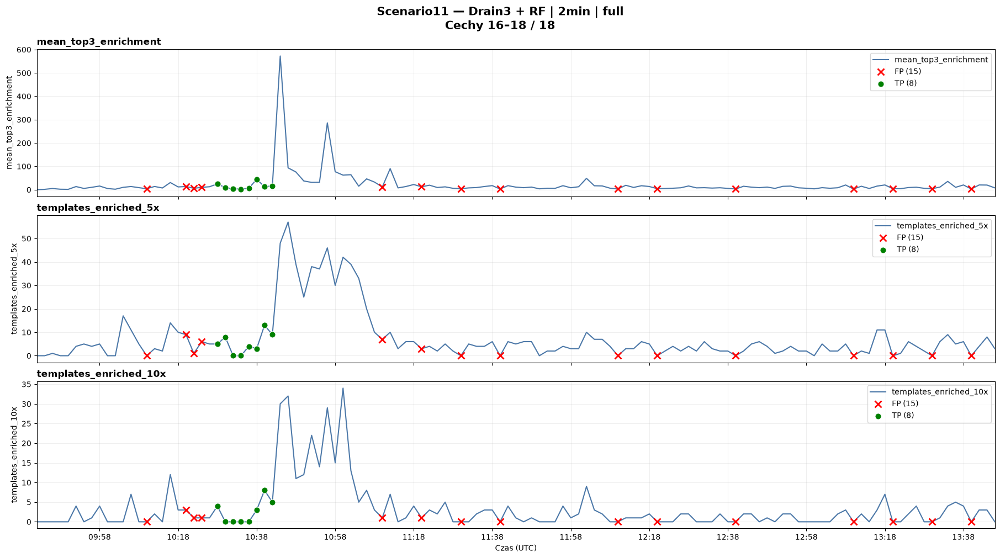

In [62]:
import matplotlib.dates as mdates

# 18 cech → 6 figur × 3 subploty
for group_start in range(0, len(feature_columns), 3):

    group = feature_columns[group_start:group_start + 3]

    fig, axes = plt.subplots(
        3, 1,
        figsize=(18, 10),
        sharex=True,
        constrained_layout=True,
    )

    fp = features_df[features_df["outcome"] == "FP"]
    tp = features_df[features_df["outcome"] == "TP"]

    for ax, feature in zip(axes, group):

        ax.plot(
            features_df["timestamp"],
            features_df[feature],
            color="#4C78A8",
            linewidth=1.5,
            label=feature,
            zorder=2,
        )

        ax.scatter(
            fp["timestamp"],
            fp[feature],
            color="red",
            marker="x",
            s=75,
            linewidths=2,
            label=f"FP ({len(fp)})",
            zorder=5,
        )

        ax.scatter(
            tp["timestamp"],
            tp[feature],
            color="green",
            marker="o",
            s=65,
            edgecolors="white",
            linewidths=0.8,
            label=f"TP ({len(tp)})",
            zorder=5,
        )

        ax.set_title(
            feature,
            fontsize=12,
            fontweight="bold",
            loc="left",
        )
        ax.set_ylabel(feature)
        ax.grid(alpha=0.2)
        ax.legend(loc="upper right")

    # Wspólna oś czasu
    axes[-1].set_xlim(time_min, time_max)
    axes[-1].xaxis.set_major_locator(
        mdates.MinuteLocator(interval=20)
    )
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M", tz=mdates.UTC)
    )
    axes[-1].set_xlabel("Czas (UTC)")

    fig.suptitle(
        f"Scenario11 — Drain3 + RF | 2min | full\n"
        f"Cechy {group_start + 1}–"
        f"{group_start + len(group)} / {len(feature_columns)}",
        fontsize=15,
        fontweight="bold",
    )

    plt.show()
    plt.close(fig)

In [ ]:
######################

In [22]:
import pandas as pd
import numpy as np
import joblib

CASE = "scenario11"

parsed = get_parsed_dataframe("Drain3", CASE).copy()

parsed["timestamp"] = pd.to_datetime(
    parsed["timestamp"], utc=True
)

incident_start = pd.to_datetime(
    NEW_CASE_DATA[CASE]["incident_start"], utc=True
)
incident_end = pd.to_datetime(
    NEW_CASE_DATA[CASE]["incident_end"], utc=True
)

parsed["in_incident"] = (
    parsed["timestamp"].between(
        incident_start,
        incident_end,
        inclusive="both",
    )
)

# Ważne: template_id pozostaje niezmieniony.
# Nie próbujemy wydobywać samego numeru z krotki.
parsed["template_key"] = parsed["template_id"].map(repr)

summary = (
    parsed
    .groupby(
        ["namespace", "template_key", "in_incident"]
    )
    .size()
    .unstack(fill_value=0)
    .rename(columns={
        False: "normal_count",
        True: "incident_count",
    })
    .reset_index()
)

for col in ["normal_count", "incident_count"]:
    if col not in summary.columns:
        summary[col] = 0

summary["total_count"] = (
    summary["normal_count"]
    + summary["incident_count"]
)

summary["incident_share"] = (
    summary["incident_count"]
    / summary["total_count"].clip(lower=1)
)

summary["normal_share"] = (
    summary["normal_count"]
    / summary["total_count"].clip(lower=1)
)

summary = summary.sort_values(
    ["namespace", "total_count"],
    ascending=[True, False],
)

for namespace, group in summary.groupby("namespace"):
    print(f"\n{'=' * 70}")
    print("NAMESPACE:", namespace)
    print("=" * 70)

    display(
        group[
            [
                "template_key",
                "normal_count",
                "incident_count",
                "total_count",
                "incident_share",
            ]
        ].head(15)
    )


NAMESPACE: integration


in_incident,template_key,normal_count,incident_count,total_count,incident_share
4,"('integration', 13)",0,3088,3088,1.000000
5,"('integration', 14)",0,1310,1310,1.000000
19,"('integration', 7)",7,177,184,0.961957
8,"('integration', 17)",0,123,123,1.000000
7,"('integration', 16)",0,122,122,1.000000
1,"('integration', 10)",0,119,119,1.000000
2,"('integration', 11)",0,110,110,1.000000
3,"('integration', 12)",0,110,110,1.000000
6,"('integration', 15)",0,110,110,1.000000
20,"('integration', 8)",0,97,97,1.000000



NAMESPACE: ml


in_incident,template_key,normal_count,incident_count,total_count,incident_share
33,"('ml', 2)",3077,129,3206,0.040237
22,"('ml', 1)",1487,141,1628,0.086609
24,"('ml', 11)",679,0,679,0.000000
27,"('ml', 14)",18,152,170,0.894118
29,"('ml', 16)",0,147,147,1.000000
37,"('ml', 23)",0,98,98,1.000000
36,"('ml', 22)",0,94,94,1.000000
38,"('ml', 24)",93,0,93,0.000000
30,"('ml', 17)",0,52,52,1.000000
34,"('ml', 20)",0,47,47,1.000000



NAMESPACE: monitoring


in_incident,template_key,normal_count,incident_count,total_count,incident_share
47,"('monitoring', 1)",22911,2039,24950,0.081723
256,"('monitoring', 55)",6248,568,6816,0.083333
257,"('monitoring', 56)",6248,568,6816,0.083333
263,"('monitoring', 61)",6248,568,6816,0.083333
237,"('monitoring', 38)",1063,690,1753,0.393611
170,"('monitoring', 21)",1654,82,1736,0.047235
125,"('monitoring', 17)",1130,95,1225,0.077551
136,"('monitoring', 18)",1130,95,1225,0.077551
147,"('monitoring', 19)",1130,95,1225,0.077551
238,"('monitoring', 39)",1059,101,1160,0.087069



NAMESPACE: reporting


in_incident,template_key,normal_count,incident_count,total_count,incident_share
338,"('reporting', 26)",712,25343,26055,0.972673
342,"('reporting', 3)",10118,183,10301,0.017765
339,"('reporting', 27)",127,10169,10296,0.987665
331,"('reporting', 2)",4950,99,5049,0.019608
364,"('reporting', 5)",2475,55,2530,0.021739
375,"('reporting', 6)",1350,30,1380,0.021739
330,"('reporting', 19)",140,1182,1322,0.894100
341,"('reporting', 29)",13,981,994,0.986922
393,"('reporting', 76)",0,799,799,1.000000
391,"('reporting', 74)",0,772,772,1.000000



NAMESPACE: resolve


in_incident,template_key,normal_count,incident_count,total_count,incident_share
419,"('resolve', 1)",3671,29,3700,0.007838
420,"('resolve', 10)",770,69,839,0.082241
485,"('resolve', 9)",644,52,696,0.074713
451,"('resolve', 39)",0,334,334,1.000000
441,"('resolve', 3)",253,19,272,0.069853
421,"('resolve', 11)",182,13,195,0.066667
443,"('resolve', 31)",64,58,122,0.475410
440,"('resolve', 29)",64,32,96,0.333333
461,"('resolve', 48)",0,94,94,1.000000
422,"('resolve', 12)",56,6,62,0.096774


In [23]:
import re
import pandas as pd

parsed = get_parsed_dataframe(
    "Drain3", "scenario11"
).copy()

possible_template_columns = [
    "template",
    "template_text",
    "event_template",
    "parsed_template",
    "cluster_template",
]

available = [
    col for col in possible_template_columns
    if col in parsed.columns
]

print("Kolumny parsera:")
print(parsed.columns.tolist())

if not available:
    print(
        "\nBrak tekstu szablonu w DataFrame. "
        "Nie można wiarygodnie wykrywać duplikatów "
        "na podstawie samych identyfikatorów."
    )
else:
    template_col = available[0]

    templates = (
        parsed[
            ["namespace", "template_id", template_col]
        ]
        .dropna(subset=[template_col])
        .drop_duplicates()
        .copy()
    )

    def normalize_template(text):
        text = str(text).strip().lower()
        text = re.sub(r"\s+", " ", text)
        return text

    templates["normalized_text"] = (
        templates[template_col].map(normalize_template)
    )

    duplicates = (
        templates
        .groupby("normalized_text")
        .filter(
            lambda g: (
                g["template_id"].map(repr).nunique() > 1
            )
        )
        .sort_values("normalized_text")
    )

    print(
        "\nLiczba wpisów z potencjalnymi duplikatami:",
        len(duplicates),
    )

    display(
        duplicates[
            ["namespace", "template_id", "normalized_text"]
        ].head(50)
    )

Kolumny parsera:
['timestamp', 'message', 'namespace', 'template_id']

Brak tekstu szablonu w DataFrame. Nie można wiarygodnie wykrywać duplikatów na podstawie samych identyfikatorów.


In [27]:
from itertools import combinations
from difflib import SequenceMatcher
import numpy as np
import pandas as pd

results = []  # Tego brakowało

for namespace, group in representatives.groupby("namespace"):

    records = group.to_dict("records")

    for a, b in combinations(records, 2):

        similarities = [
            SequenceMatcher(None, x, y).ratio()
            for x in a["normalized"]
            for y in b["normalized"]
        ]

        if not similarities:
            continue

        results.append({
            "namespace": namespace,
            "template_a": a["template_key"],
            "template_b": b["template_key"],
            "max_similarity": max(similarities),
            "mean_similarity": np.mean(similarities),
        })

similarity_df = pd.DataFrame(
    results,
    columns=[
        "namespace",
        "template_a",
        "template_b",
        "max_similarity",
        "mean_similarity",
    ],
)

similarity_df = similarity_df.sort_values(
    ["mean_similarity", "max_similarity"],
    ascending=False,
)

print("Najbardziej podobne pary szablonów:")
display(similarity_df.head(30).round(3))

print("\nPary z podobieństwem >= 0.95:")
display(
    similarity_df[
        similarity_df["max_similarity"] >= 0.95
    ].round(3)
)

Najbardziej podobne pary szablonów:


,namespace,template_a,template_b,max_similarity,mean_similarity
246,ml,"('ml', 1)","('ml', 24)",0.983,0.959
183,integration,"('integration', 2)","('integration', 7)",1.000,0.935
218,integration,"('integration', 4)","('integration', 7)",1.000,0.935
180,integration,"('integration', 2)","('integration', 4)",1.000,0.933
256,ml,"('ml', 10)","('ml', 12)",1.000,0.932
257,ml,"('ml', 10)","('ml', 13)",1.000,0.932
258,ml,"('ml', 10)","('ml', 14)",1.000,0.932
271,ml,"('ml', 10)","('ml', 3)",1.000,0.932
272,ml,"('ml', 10)","('ml', 4)",1.000,0.932
273,ml,"('ml', 10)","('ml', 5)",1.000,0.932



Pary z podobieństwem >= 0.95:


,namespace,template_a,template_b,max_similarity,mean_similarity
246,ml,"('ml', 1)","('ml', 24)",0.983,0.959
183,integration,"('integration', 2)","('integration', 7)",1.000,0.935
218,integration,"('integration', 4)","('integration', 7)",1.000,0.935
180,integration,"('integration', 2)","('integration', 4)",1.000,0.933
256,ml,"('ml', 10)","('ml', 12)",1.000,0.932
257,ml,"('ml', 10)","('ml', 13)",1.000,0.932
258,ml,"('ml', 10)","('ml', 14)",1.000,0.932
271,ml,"('ml', 10)","('ml', 3)",1.000,0.932
272,ml,"('ml', 10)","('ml', 4)",1.000,0.932
273,ml,"('ml', 10)","('ml', 5)",1.000,0.932


In [28]:
import pandas as pd
import re

def normalize_for_audit(msg):
    text = str(msg).lower().strip()

    text = re.sub(
        r"\b[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-"
        r"[0-9a-f]{4}-[0-9a-f]{12}\b",
        "<UUID>", text
    )
    text = re.sub(
        r"\b(?:\d{1,3}\.){3}\d{1,3}\b",
        "<IP>", text
    )
    text = re.sub(
        r"\b\d+(?:\.\d+)?\b",
        "<NUM>", text
    )
    text = re.sub(r"\s+", " ", text)

    return text

all_parsed = []

for case in SCENARIOS:
    df = get_parsed_dataframe("Drain3", case).copy()

    df["case"] = case
    df["template_key"] = df["template_id"].map(repr)

    all_parsed.append(
        df[["case", "namespace", "template_key", "message"]]
    )

all_parsed = pd.concat(all_parsed, ignore_index=True)

all_parsed["normalized"] = (
    all_parsed["message"].map(normalize_for_audit)
)

# Jedna znormalizowana wiadomość może być
# przypisana do kilku różnych template_id.
audit = (
    all_parsed
    .groupby(["namespace", "normalized"])
    .agg(
        total_logs=("template_key", "size"),
        distinct_ids=("template_key", "nunique"),
        template_ids=(
            "template_key",
            lambda x: sorted(set(x))
        ),
        scenarios=(
            "case",
            lambda x: sorted(set(x))
        ),
    )
    .reset_index()
)

duplicates = (
    audit[audit["distinct_ids"] > 1]
    .sort_values(
        ["total_logs", "distinct_ids"],
        ascending=False
    )
    .copy()
)

print("Wszystkie logi:", len(all_parsed))
print(
    "Znormalizowane komunikaty z wieloma ID:",
    len(duplicates)
)

print("\nNajczęstsze potencjalne duplikaty:")

# Bez ujawniania treści komunikatów
display(
    duplicates[
        [
            "namespace",
            "total_logs",
            "distinct_ids",
            "template_ids",
            "scenarios",
        ]
    ].head(30)
)

Wszystkie logi: 855584
Znormalizowane komunikaty z wieloma ID: 11277

Najczęstsze potencjalne duplikaty:


,namespace,total_logs,distinct_ids,template_ids,scenarios
49380,reporting,35912,4,"[('reporting', 3), ('reporting', 4), ('reporti...","[scenario4, scenario6, scenario7, scenario8]"
93288,reporting,13636,4,"[('reporting', 36), ('reporting', 58), ('repor...","[scenario6, scenario7, scenario8, scenario9]"
49384,reporting,13634,4,"[('reporting', 36), ('reporting', 58), ('repor...","[scenario6, scenario7, scenario8, scenario9]"
49382,reporting,13633,2,"[('reporting', 118), ('reporting', 61)]","[scenario8, scenario9]"
93285,reporting,13631,2,"[('reporting', 118), ('reporting', 61)]","[scenario8, scenario9]"
124025,reporting,8356,7,"[('reporting', 26), ('reporting', 34), ('repor...","[scenario1, scenario10, scenario11, scenario2,..."
116225,reporting,5440,6,"[('reporting', 17), ('reporting', 19), ('repor...","[scenario1, scenario10, scenario11, scenario2,..."
116226,reporting,5440,6,"[('reporting', 17), ('reporting', 19), ('repor...","[scenario1, scenario10, scenario11, scenario2,..."
116227,reporting,5440,6,"[('reporting', 17), ('reporting', 19), ('repor...","[scenario1, scenario10, scenario11, scenario2,..."
116228,reporting,5440,6,"[('reporting', 17), ('reporting', 19), ('repor...","[scenario1, scenario10, scenario11, scenario2,..."


In [29]:
import pandas as pd

# Korzystamy z all_parsed z komórki 43.
# Kolumny: case, namespace, template_key, message, normalized

def find_multi_id(df, message_column):
    grouped = (
        df.groupby(
            ["case", "namespace", message_column],
            dropna=False,
        )
        .agg(
            total_logs=("template_key", "size"),
            distinct_ids=("template_key", "nunique"),
            template_ids=(
                "template_key",
                lambda x: sorted(set(x)),
            ),
        )
        .reset_index()
    )

    return grouped[
        grouped["distinct_ids"] > 1
    ].copy()

# Ten sam znormalizowany komunikat, różne ID
normalized_multi = find_multi_id(
    all_parsed, "normalized"
)

# Dokładnie ten sam surowy komunikat, różne ID
exact_multi = find_multi_id(
    all_parsed, "message"
)

print("=== DUPLIKATY W OBRĘBIE SCENARIUSZA ===")
print(
    "Znormalizowane komunikaty z wieloma ID:",
    len(normalized_multi),
)
print(
    "Dokładnie identyczne komunikaty z wieloma ID:",
    len(exact_multi),
)

print("\n=== PODZIAŁ NA SCENARIUSZE ===")

scenario_summary = pd.DataFrame({
    "normalized_multi": normalized_multi.groupby("case").size(),
    "exact_multi": exact_multi.groupby("case").size(),
}).fillna(0).astype(int)

display(scenario_summary)

print("\n=== SCENARIO11: NAJCZĘSTSZE PRZYPADKI ===")

s11 = (
    normalized_multi[
        normalized_multi["case"] == "scenario11"
    ]
    .sort_values("total_logs", ascending=False)
)

# Nie pokazujemy treści logów
display(
    s11[
        [
            "namespace",
            "total_logs",
            "distinct_ids",
            "template_ids",
        ]
    ].head(30)
)

print("\n=== SCENARIO11: IDENTYCZNE SUROWE KOMUNIKATY ===")

s11_exact = (
    exact_multi[
        exact_multi["case"] == "scenario11"
    ]
    .sort_values("total_logs", ascending=False)
)

display(
    s11_exact[
        [
            "namespace",
            "total_logs",
            "distinct_ids",
            "template_ids",
        ]
    ].head(30)
)

print("\n=== MONITORING T15 / T38 ===")

target_ids = {
    "('monitoring', 15)",
    "('monitoring', 38)",
}

target = all_parsed[
    (all_parsed["case"] == "scenario11")
    & (all_parsed["namespace"] == "monitoring")
    & (all_parsed["template_key"].isin(target_ids))
]

target_summary = (
    target.groupby("template_key")
    .agg(
        logs=("message", "size"),
        unique_raw_messages=("message", "nunique"),
        unique_normalized=("normalized", "nunique"),
    )
)

display(target_summary)

overlap = (
    target.groupby("normalized")["template_key"]
    .nunique()
)

print(
    "Wspólne znormalizowane komunikaty T15/T38:",
    int((overlap == 2).sum()),
)

=== DUPLIKATY W OBRĘBIE SCENARIUSZA ===
Znormalizowane komunikaty z wieloma ID: 16
Dokładnie identyczne komunikaty z wieloma ID: 0

=== PODZIAŁ NA SCENARIUSZE ===


,normalized_multi,exact_multi
case,,
scenario11,10,0
scenario5,1,0
scenario7,3,0
scenario9,2,0



=== SCENARIO11: NAJCZĘSTSZE PRZYPADKI ===


,namespace,total_logs,distinct_ids,template_ids
24089,monitoring,1754,2,"[('monitoring', 15), ('monitoring', 38)]"
62034,reporting,1324,3,"[('reporting', 17), ('reporting', 18), ('repor..."
24090,monitoring,1060,2,"[('monitoring', 15), ('monitoring', 39)]"
21273,integration,186,3,"[('integration', 2), ('integration', 4), ('int..."
24003,ml,175,6,"[('ml', 10), ('ml', 12), ('ml', 14), ('ml', 3)..."
62035,reporting,149,3,"[('reporting', 17), ('reporting', 18), ('repor..."
82218,resolve,141,20,"[('resolve', 14), ('resolve', 15), ('resolve',..."
82219,resolve,93,20,"[('resolve', 14), ('resolve', 15), ('resolve',..."
24006,ml,30,6,"[('ml', 10), ('ml', 12), ('ml', 13), ('ml', 3)..."
21274,integration,9,3,"[('integration', 2), ('integration', 4), ('int..."



=== SCENARIO11: IDENTYCZNE SUROWE KOMUNIKATY ===


,namespace,total_logs,distinct_ids,template_ids



=== MONITORING T15 / T38 ===


,logs,unique_raw_messages,unique_normalized
template_key,,,
"('monitoring', 15)",2,2,2
"('monitoring', 38)",1753,1753,1


Wspólne znormalizowane komunikaty T15/T38: 1


In [30]:
import pandas as pd
import numpy as np

TEST_CASE = "scenario11"

train_logs = all_parsed[
    all_parsed["case"] != TEST_CASE
].copy()

# Liczba scenariuszy, w których występuje dany wzorzec.
ranking = (
    train_logs
    .groupby(["namespace", "normalized"])
    .agg(
        total_logs=("case", "size"),
        scenario_count=("case", "nunique"),
        scenarios=("case", lambda x: sorted(set(x))),
    )
    .reset_index()
)

ranking = ranking.sort_values(
    ["namespace", "total_logs"],
    ascending=[True, False],
)

# Nie wypisujemy treści komunikatów.
for namespace, group in ranking.groupby("namespace"):

    print(f"\n{'=' * 65}")
    print("NAMESPACE:", namespace)
    print("=" * 65)

    display(
        group[
            [
                "total_logs",
                "scenario_count",
                "scenarios",
            ]
        ].head(15)
    )


NAMESPACE: ingestion


,total_logs,scenario_count,scenarios
115,4004,2,"[scenario10, scenario5]"
1077,1800,1,[scenario5]
1042,750,1,[scenario5]
1076,720,1,[scenario5]
63,700,2,"[scenario10, scenario5]"
79,691,2,"[scenario10, scenario5]"
80,691,2,"[scenario10, scenario5]"
66,690,2,"[scenario10, scenario5]"
78,690,2,"[scenario10, scenario5]"
54,681,2,"[scenario10, scenario5]"



NAMESPACE: reporting


,total_logs,scenario_count,scenarios
8855,35912,4,"[scenario4, scenario6, scenario7, scenario8]"
44478,13636,4,"[scenario6, scenario7, scenario8, scenario9]"
8859,13634,4,"[scenario6, scenario7, scenario8, scenario9]"
8857,13633,2,"[scenario8, scenario9]"
44475,13631,2,"[scenario8, scenario9]"
70259,8044,7,"[scenario1, scenario10, scenario2, scenario3, ..."
6004,5000,1,[scenario6]
6007,5000,1,[scenario6]
6008,5000,1,[scenario6]
6012,5000,1,[scenario6]


In [31]:
import pandas as pd
import numpy as np

CASE = "scenario11"

df = get_parsed_dataframe("Drain3", CASE).copy()

df["timestamp"] = pd.to_datetime(
    df["timestamp"], utc=True
)

df["template_key"] = df["template_id"].map(repr)

# Kubełki 2-minutowe
df["bucket"] = df["timestamp"].dt.floor("2min")
df["phase"] = df["bucket"].dt.minute % 10

# Liczba wystąpień szablonu w kubełku
counts = (
    df.groupby(
        ["namespace", "template_key", "bucket", "phase"]
    )
    .size()
    .rename("count")
    .reset_index()
)

# Uwzględniamy również kubełki, w których
# dany szablon nie wystąpił.
all_buckets = pd.date_range(
    df["bucket"].min(),
    df["bucket"].max(),
    freq="2min",
    tz="UTC",
)

all_templates = (
    counts[["namespace", "template_key"]]
    .drop_duplicates()
)

template_index = pd.MultiIndex.from_frame(
    all_templates
)

full_index = pd.MultiIndex.from_product(
    [
        all_buckets,
        range(len(template_index)),
    ],
    names=["bucket", "template_idx"],
)

template_lookup = dict(enumerate(template_index.tolist()))
reverse_lookup = {
    value: key
    for key, value in template_lookup.items()
}

counts["template_idx"] = [
    reverse_lookup[(ns, key)]
    for ns, key in zip(
        counts["namespace"],
        counts["template_key"],
    )
]

full = (
    counts.set_index(["bucket", "template_idx"])["count"]
    .reindex(full_index, fill_value=0)
    .reset_index()
)

full["phase"] = full["bucket"].dt.minute % 10

stats = (
    full.groupby(["template_idx", "phase"])["count"]
    .mean()
    .unstack(fill_value=0)
)

stats["mean_other"] = stats[[2, 4, 6, 8]].mean(axis=1)
stats["mean_phase0"] = stats[0]

stats["excess_at_phase0"] = (
    stats["mean_phase0"] - stats["mean_other"]
)

stats["ratio_phase0"] = (
    (stats["mean_phase0"] + 0.1)
    / (stats["mean_other"] + 0.1)
)

stats["namespace"] = [
    template_lookup[i][0]
    for i in stats.index
]

stats["template_key"] = [
    template_lookup[i][1]
    for i in stats.index
]

stats = stats.sort_values(
    "excess_at_phase0",
    ascending=False
)

print("Szablony generujące największy nadmiar logów")
print("na początku cyklu 10-minutowego:")

display(
    stats[
        [
            "namespace",
            "template_key",
            "mean_phase0",
            "mean_other",
            "excess_at_phase0",
            "ratio_phase0",
        ]
    ].head(30).round(2)
)

Szablony generujące największy nadmiar logów
na początku cyklu 10-minutowego:


phase,namespace,template_key,mean_phase0,mean_other,excess_at_phase0,ratio_phase0
template_idx,,,,,,
256,monitoring,"('monitoring', 55)",276.42,1.82,274.60,144.02
257,monitoring,"('monitoring', 56)",276.29,1.85,274.44,141.74
263,monitoring,"('monitoring', 61)",276.29,1.85,274.44,141.74
338,reporting,"('reporting', 26)",307.38,189.16,118.21,1.62
339,reporting,"('reporting', 27)",121.38,74.74,46.63,1.62
4,integration,"('integration', 13)",35.50,22.64,12.86,1.57
335,reporting,"('reporting', 23)",9.17,0.00,9.17,92.67
5,integration,"('integration', 14)",15.08,9.60,5.48,1.57
341,reporting,"('reporting', 29)",11.62,7.24,4.38,1.60


=== WPŁYW SZABLONÓW NA KUBEŁKI ===


,buckets,mean_total_logs,mean_target_logs,median_target_logs,mean_target_share
outcome,,,,,
FN,3,554.333,0.000,0.0,0.000
FP,15,1416.667,736.267,852.0,0.506
TN,97,761.454,79.381,0.0,0.051
TP,8,7237.500,213.000,0.0,0.025


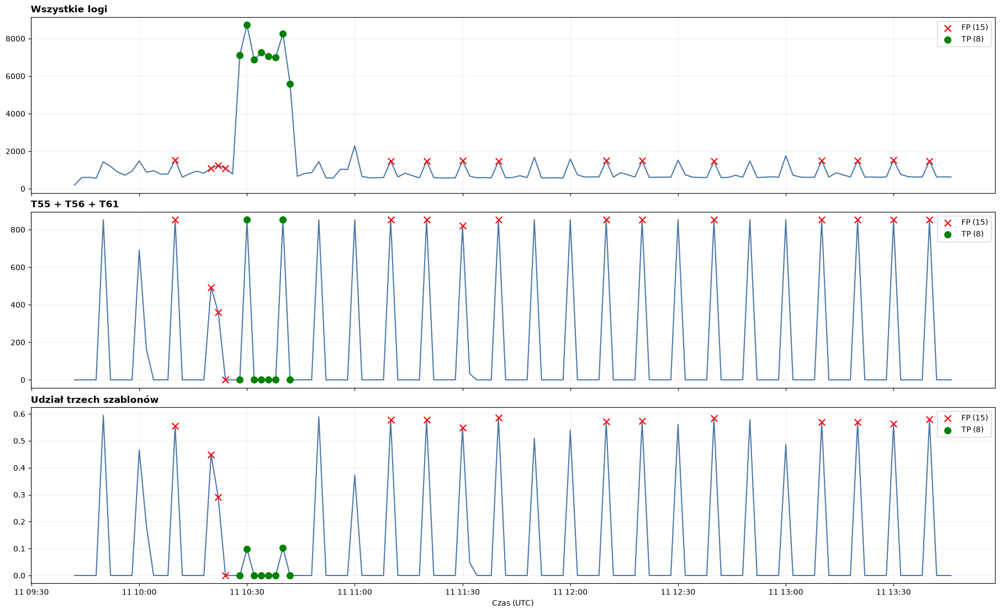

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CASE = "scenario11"

logs = get_parsed_dataframe("Drain3", CASE).copy()
logs["timestamp"] = pd.to_datetime(logs["timestamp"], utc=True)
logs["bucket"] = logs["timestamp"].dt.floor("2min")

# Porównujemy rzeczywiste tuple, bez konwersji ID do tekstu.
TARGETS = {
    ("monitoring", 55),
    ("monitoring", 56),
    ("monitoring", 61),
}

logs["is_target"] = logs["template_id"].apply(
    lambda x: x in TARGETS if isinstance(x, tuple) else False
)

target_counts = (
    logs[logs["is_target"]]
    .groupby(["bucket", "template_id"])
    .size()
    .unstack(fill_value=0)
)

# Oryginalne predykcje scenariusza 11
pred = features_df[
    ["timestamp", "outcome", "total_logs"]
].copy()

pred["timestamp"] = pd.to_datetime(
    pred["timestamp"], utc=True
)

plot_df = pred.set_index("timestamp").join(
    target_counts,
    how="left"
).fillna(0)

for template in TARGETS:
    if template not in plot_df.columns:
        plot_df[template] = 0

plot_df["target_total"] = (
    plot_df[list(TARGETS)].sum(axis=1)
)

plot_df["target_share"] = (
    plot_df["target_total"]
    / plot_df["total_logs"].replace(0, np.nan)
)

print("=== WPŁYW SZABLONÓW NA KUBEŁKI ===")

summary = (
    plot_df.groupby("outcome")
    .agg(
        buckets=("total_logs", "size"),
        mean_total_logs=("total_logs", "mean"),
        mean_target_logs=("target_total", "mean"),
        median_target_logs=("target_total", "median"),
        mean_target_share=("target_share", "mean"),
    )
)

display(summary.round(3))

fig, axes = plt.subplots(
    3, 1,
    figsize=(18, 11),
    sharex=True,
    constrained_layout=True,
)

series = [
    ("total_logs", "Wszystkie logi"),
    ("target_total", "T55 + T56 + T61"),
    ("target_share", "Udział trzech szablonów"),
]

for ax, (column, title) in zip(axes, series):

    ax.plot(
        plot_df.index,
        plot_df[column],
        linewidth=1.5,
        color="#4C78A8",
    )

    for outcome, color, marker in [
        ("FP", "red", "x"),
        ("TP", "green", "o"),
    ]:
        subset = plot_df[plot_df["outcome"] == outcome]

        ax.scatter(
            subset.index,
            subset[column],
            color=color,
            marker=marker,
            s=70,
            label=f"{outcome} ({len(subset)})",
            zorder=5,
        )

    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(alpha=0.2)
    ax.legend()

axes[-1].set_xlabel("Czas (UTC)")
plt.show()

In [41]:
import pandas as pd

logs = get_parsed_dataframe("Drain3", "scenario11").copy()

TARGETS = [
    ("monitoring", 55),
    ("monitoring", 56),
    ("monitoring", 61),
]

for template_id in TARGETS:

    subset = logs[
        logs["template_id"].apply(
            lambda x: x == template_id
        )
    ].copy()

    subset["timestamp"] = pd.to_datetime(
        subset["timestamp"], utc=True
    )

    subset = subset.sort_values("timestamp")

    print("\n" + "=" * 90)
    print(f"TEMPLATE: {template_id}")
    print(f"NAMESPACE: {template_id[0]}")
    print(f"LICZBA LOGÓW: {len(subset)}")
    print("=" * 90)

    if subset.empty:
        print("Brak logów dla tego szablonu.")
        continue

    # Trzy próbki rozłożone w czasie
    positions = [
        0,
        len(subset) // 2,
        len(subset) - 1,
    ]

    for i, pos in enumerate(sorted(set(positions)), start=1):
        row = subset.iloc[pos]

        print(f"\n--- PRZYKŁAD {i} ---")
        print("Timestamp:", row["timestamp"])
        print("Namespace:", row["namespace"])
        print("Message:")
        print(row["message"])


TEMPLATE: ('monitoring', 55)
NAMESPACE: monitoring
LICZBA LOGÓW: 6816

--- PRZYKŁAD 1 ---
Timestamp: 2026-09-11 09:51:49.216796+00:00
Namespace: monitoring
Message:
level=info ts=2026-09-11T09:51:49.216255398Z caller=tables_manager.go:281 msg="compacting table" table-name=index_20707

--- PRZYKŁAD 2 ---
Timestamp: 2026-09-11 11:51:49.217142+00:00
Namespace: monitoring
Message:
level=info ts=2026-09-11T11:51:49.206466412Z caller=tables_manager.go:281 msg="compacting table" table-name=index_20707

--- PRZYKŁAD 3 ---
Timestamp: 2026-09-11 13:41:57.717460+00:00
Namespace: monitoring
Message:
level=info ts=2026-09-11T13:41:57.623766372Z caller=tables_manager.go:281 msg="compacting table" table-name=index_20424

TEMPLATE: ('monitoring', 56)
NAMESPACE: monitoring
LICZBA LOGÓW: 6816

--- PRZYKŁAD 1 ---
Timestamp: 2026-09-11 09:51:49.319584+00:00
Namespace: monitoring
Message:
level=info ts=2026-09-11T09:51:49.245080627Z caller=table.go:145 table-name=index_20707 msg="listed files" count=1

--

Logi przed filtrowaniem: 154674
Logi usunięte: 20448
Logi po filtrowaniu: 134226
Usunięty procent: 13.22 %

Średnia liczba logów według fazy:


,before,after,removed
phase,,,
0,2107.62,1278.62,829.00
2,1121.76,1099.68,22.08
4,951.24,951.24,0.00
6,941.12,941.12,0.00
8,1197.42,1197.42,0.00


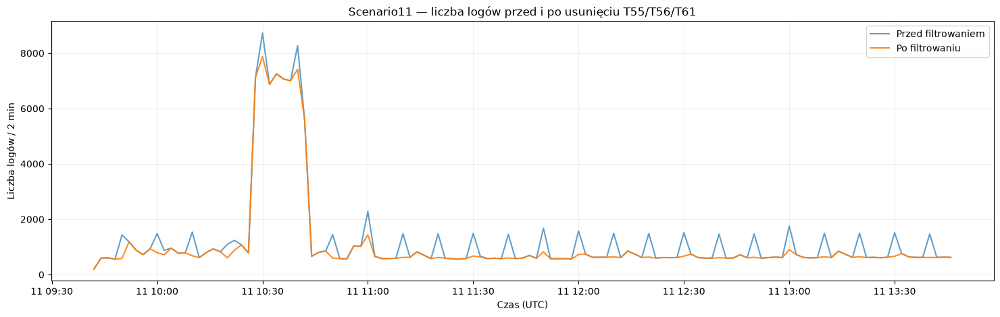

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CASE = "scenario11"

REMOVE_TEMPLATES = {
    ("monitoring", 55),
    ("monitoring", 56),
    ("monitoring", 61),
}

logs = get_parsed_dataframe("Drain3", CASE).copy()
logs["timestamp"] = pd.to_datetime(logs["timestamp"], utc=True)

mask = logs["template_id"].apply(
    lambda x: x in REMOVE_TEMPLATES
)

filtered_logs = logs.loc[~mask].copy()

print("Logi przed filtrowaniem:", len(logs))
print("Logi usunięte:", int(mask.sum()))
print("Logi po filtrowaniu:", len(filtered_logs))
print("Usunięty procent:", round(mask.mean() * 100, 2), "%")

# Zachowujemy te same granice kubełków.
logs["bucket"] = logs["timestamp"].dt.floor("2min")
filtered_logs["bucket"] = filtered_logs["timestamp"].dt.floor("2min")

buckets = pd.date_range(
    logs["bucket"].min(),
    logs["bucket"].max(),
    freq="2min",
    tz="UTC",
)

before = (
    logs.groupby("bucket")
    .size()
    .reindex(buckets, fill_value=0)
)

after = (
    filtered_logs.groupby("bucket")
    .size()
    .reindex(buckets, fill_value=0)
)

comparison = pd.DataFrame({
    "before": before,
    "after": after,
})

comparison["removed"] = (
    comparison["before"] - comparison["after"]
)

comparison["phase"] = comparison.index.minute % 10

print("\nŚrednia liczba logów według fazy:")
display(
    comparison.groupby("phase")[
        ["before", "after", "removed"]
    ].mean().round(2)
)

fig, ax = plt.subplots(figsize=(18, 5))

ax.plot(
    comparison.index,
    comparison["before"],
    label="Przed filtrowaniem",
    alpha=0.7,
)

ax.plot(
    comparison.index,
    comparison["after"],
    label="Po filtrowaniu",
    alpha=0.9,
)

ax.set_title(
    "Scenario11 — liczba logów przed i po usunięciu T55/T56/T61"
)
ax.set_ylabel("Liczba logów / 2 min")
ax.set_xlabel("Czas (UTC)")
ax.grid(alpha=0.2)
ax.legend()

plt.show()

In [43]:
import pandas as pd
import re

TEST_CASE = "scenario11"
PARSER = "Drain3"
WINDOW = "2min"

REMOVE_TEMPLATES = {
    ("monitoring", 55),
    ("monitoring", 56),
    ("monitoring", 61),
}

# Oryginalne logi
original = get_parsed_dataframe(PARSER, TEST_CASE).copy()

# Filtrowanie
mask = original["template_id"].apply(
    lambda x: x in REMOVE_TEMPLATES
)

filtered = original.loc[~mask].copy()

# Osobny cache w pamięci
FILTERED_PARSED_CACHE = {
    (PARSER, TEST_CASE): filtered
}

print("Scenariusz:", TEST_CASE)
print("Parser:", PARSER)
print("Kubełki:", WINDOW)
print("Logi przed:", len(original))
print("Usunięte:", int(mask.sum()))
print("Logi po:", len(filtered))
print("Udział usuniętych:", f"{mask.mean():.2%}")

Scenariusz: scenario11
Parser: Drain3
Kubełki: 2min
Logi przed: 154674
Usunięte: 20448
Logi po: 134226
Udział usuniętych: 13.22%


In [44]:
import json
from pathlib import Path

SEARCH_TERMS = [
    "mean_top3_enrichment",
    "templates_enriched_10x",
    "novel_template_rate",
    "def build_",
    "def compute_",
    "def make_",
    "BASIC_FEATURES",
    "joblib.dump",
]

notebooks = list(Path.cwd().glob("*.ipynb"))

print("Znalezione notebooki:", len(notebooks))

for notebook_path in notebooks:
    try:
        with open(notebook_path, "r", encoding="utf-8") as f:
            notebook = json.load(f)
    except Exception as exc:
        print("Pominięto:", notebook_path.name, exc)
        continue

    matches = []

    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        lines = source.splitlines()

        found = []

        for line_no, line in enumerate(lines, start=1):
            stripped = line.strip()

            if any(term in stripped for term in SEARCH_TERMS):
                found.append((line_no, stripped[:160]))

        if found:
            matches.append((i + 1, found))

    if not matches:
        continue

    print("\n" + "=" * 80)
    print("NOTEBOOK:", notebook_path.name)
    print("=" * 80)

    for cell_no, found in matches:
        print(f"\nKOMÓRKA {cell_no}")

        for line_no, text in found[:12]:
            print(f"  linia {line_no}: {text}")

Znalezione notebooki: 3

NOTEBOOK: Extended_logs.ipynb

KOMÓRKA 17
  linia 28: "novel_template_rate",
  linia 36: "mean_top3_enrichment",
  linia 38: "templates_enriched_10x",
  linia 147: joblib.dump(

KOMÓRKA 18
  linia 91: joblib.dump(

KOMÓRKA 19
  linia 102: joblib.dump(
  linia 114: joblib.dump(
  linia 268: joblib.dump(

KOMÓRKA 22
  linia 31: joblib.dump(state, temp_path, compress=3)
  linia 48: joblib.dump(parsed, raw_result_path, compress=3)

KOMÓRKA 26
  linia 160: def make_signature_frame(parsed):
  linia 271: joblib.dump(
  linia 277: joblib.dump(

KOMÓRKA 32
  linia 50: "novel_template_rate",
  linia 58: "mean_top3_enrichment",
  linia 60: "templates_enriched_10x",
  linia 80: def make_new_classifier(name):

KOMÓRKA 40
  linia 37: isinstance(t, ast.Name) and t.id == "BASIC_FEATURES"
  linia 41: BASIC_FEATURES = value
  linia 50: "Nie znaleziono BASIC_FEATURES w oryginalnym notebooku."
  linia 53: print("✓ BASIC_FEATURES:", BASIC_FEATURES)

KOMÓRKA 43
  linia 29: "novel_te

In [45]:
import json
from pathlib import Path

notebook_path = Path("Extended_logs.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for cell_number in [17, 18, 19]:
    cell = notebook["cells"][cell_number - 1]

    print("\n" + "=" * 90)
    print(f"KOMÓRKA {cell_number}")
    print("=" * 90)

    source = "".join(cell.get("source", []))

    for line_number, line in enumerate(
        source.splitlines(), start=1
    ):
        print(f"{line_number:3d}: {line}")


KOMÓRKA 17
  1: import joblib
  2: import numpy as np
  3: import pandas as pd
  4: 
  5: from sklearn.base import clone
  6: from sklearn.metrics import (
  7:     matthews_corrcoef,
  8:     f1_score,
  9: )
 10: 
 11: RAW_ROOT = OLD_RESULTS.parent / "raw"
 12: 
 13: EVAL_DIR = OLD_RESULTS / "evaluation_3h"
 14: EVAL_DIR.mkdir(parents=True, exist_ok=True)
 15: 
 16: PARSER = "IPLoM"
 17: WINDOW = "10min"
 18: MODEL_NAME = "Random Forest"
 19: 
 20: FEATURES18 = [
 21:     "total_logs",
 22:     "unique_templates",
 23:     "single_occurrence_templates",
 24:     "unique_rate",
 25:     "single_occurrence_rate",
 26:     "dominant_share",
 27:     "template_entropy",
 28:     "novel_template_rate",
 29:     "template_set_change",
 30:     "js_divergence",
 31:     "total_logs_z",
 32:     "unique_templates_z",
 33:     "single_occurrence_templates_z",
 34:     "template_entropy_z",
 35:     "max_template_enrichment",
 36:     "mean_top3_enrichment",
 37:     "templates_enriched_5x",


In [11]:
import inspect
import joblib

print("=== FUNKCJE ===")

for name in [
    "build_namespace_buckets",
    "get_parsed_dataframe",
]:
    obj = globals().get(name)
    print(f"{name}: {'OK' if callable(obj) else 'BRAK'}")

    if callable(obj):
        print("  Argumenty:", inspect.signature(obj))

print("\n=== ZESTAW 7 CECH ===")

if "BASIC_FEATURES" in globals():
    print("BASIC_FEATURES:", list(BASIC_FEATURES))
else:
    print("BRAK BASIC_FEATURES")

print("\n=== MODELE ===")

if "MODELS" in globals():
    for name, model in MODELS.items():
        print(name, ":", model)
else:
    print("BRAK MODELS")

print("\n=== CACHE KUBEŁKÓW ===")

for window in ["2min", "5min", "10min"]:
    path = BUCKET_DIR / f"Drain3__scenario11__{window}.joblib"
    print(window, ":", "OK" if path.exists() else "BRAK")

print("\n=== PRZYKŁADOWY BUCKET ===")

path = BUCKET_DIR / "Drain3__scenario11__2min.joblib"

if path.exists():
    sample = joblib.load(path)
    print("Wymiary:", sample.shape)
    print("Kolumny:", list(sample.columns))
    print("Pierwsze timestampy:")
    print(sample["timestamp"].head(3).tolist())

=== FUNKCJE ===
build_namespace_buckets: OK
  Argumenty: (parsed_df, window_size='5min', history_minutes=30)
get_parsed_dataframe: BRAK

=== ZESTAW 7 CECH ===
BRAK BASIC_FEATURES

=== MODELE ===
BRAK MODELS

=== CACHE KUBEŁKÓW ===
2min : OK
5min : OK
10min : OK

=== PRZYKŁADOWY BUCKET ===
Wymiary: (123, 23)
Kolumny: ['case', 'timestamp', 'bucket_end', 'label_primary', 'label_all_known', 'total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'templates_enriched_5x', 'templates_enriched_10x']
Pierwsze timestampy:
[Timestamp('2026-09-11 09:42:00+0000', tz='UTC'), Timestamp('2026-09-11 09:44:00+0000', tz='UTC'), Timestamp('2026-09-11 09:46:00+0000', tz='UTC')]


In [47]:
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

FILTER_DIR = PREP_DIR / "experiment_monitoring_T55_T56_T61"
FILTER_BUCKET_DIR = FILTER_DIR / "buckets"
FILTER_PRED_DIR = FILTER_DIR / "predictions"
FILTER_REPORT_DIR = FILTER_DIR / "reports"

for directory in [FILTER_BUCKET_DIR, FILTER_PRED_DIR, FILTER_REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PARSER = "Drain3"
TEST_CASE = "scenario11"
WINDOWS_EXP = ["2min", "5min", "10min"]

REMOVE_TEMPLATES = {
    ("monitoring", 55),
    ("monitoring", 56),
    ("monitoring", 61),
}

parsed = get_parsed_dataframe(PARSER, TEST_CASE).copy()

mask = parsed["template_id"].map(
    lambda x: x in REMOVE_TEMPLATES
)

filtered = parsed.loc[~mask].copy()

print("Logi przed:", len(parsed))
print("Logi usunięte:", int(mask.sum()))
print("Logi po:", len(filtered))

FILTERED_BUCKETS = {}

for window in WINDOWS_EXP:

    original_path = (
        BUCKET_DIR / f"{PARSER}__{TEST_CASE}__{window}.joblib"
    )

    original = joblib.load(original_path).copy()

    rebuilt = build_namespace_buckets(
        filtered,
        window_size=window,
        history_minutes=30,
    ).copy()

    for frame in [original, rebuilt]:
        frame["timestamp"] = pd.to_datetime(
            frame["timestamp"], utc=True
        )

    if rebuilt["timestamp"].duplicated().any():
        raise ValueError(
            f"{window}: powtórzone timestampy po agregacji"
        )

    # Zachowujemy oryginalną oś czasu i etykiety.
    original_index = original.set_index("timestamp")
    rebuilt_index = rebuilt.set_index("timestamp")

    if not original_index.index.equals(rebuilt_index.index):
        missing = original_index.index.difference(
            rebuilt_index.index
        )
        extra = rebuilt_index.index.difference(
            original_index.index
        )

        raise ValueError(
            f"{window}: niezgodne kubełki. "
            f"Brakujących: {len(missing)}, "
            f"dodatkowych: {len(extra)}. "
            "Nie kontynuujemy automatycznie."
        )

    # Bierzemy tylko cechy z przeliczonego zbioru.
    result = original[
        [
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]
    ].copy()

    for feature in FEATURES18:
        result[feature] = rebuilt_index.loc[
            result["timestamp"], feature
        ].to_numpy()

    if len(result) != len(original):
        raise RuntimeError(
            f"{window}: zmieniła się liczba kubełków"
        )

    output_path = (
        FILTER_BUCKET_DIR
        / f"{PARSER}__{TEST_CASE}__{window}.joblib"
    )

    joblib.dump(result, output_path, compress=3)
    FILTERED_BUCKETS[window] = result

    print(
        f"{window}: {len(result)} kubełków | "
        f"średni total_logs: "
        f"{original['total_logs'].mean():.1f} → "
        f"{result['total_logs'].mean():.1f}"
    )

print("\nGotowe — nowe cechy zapisane osobno.")

Logi przed: 154674
Logi usunięte: 20448
Logi po: 134226
2min: 123 kubełków | średni total_logs: 1257.5 → 1091.3
5min: 50 kubełków | średni total_logs: 3093.5 → 2684.5
10min: 25 kubełków | średni total_logs: 6187.0 → 5369.0

Gotowe — nowe cechy zapisane osobno.


In [50]:
import gc
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

FEATURE_SETS_EXP = {
    "basic": list(BASIC_FEATURES),
    "full": list(FEATURES18),
}

MODELS_EXP = {
    name: clone(model)
    for name, model in MODELS.items()
    if name in ["RF", "LR", "GB"]
}

SCENARIOS_EXP = list(SCENARIOS)

assert len(SCENARIOS_EXP) == 11
assert len(FEATURE_SETS_EXP["basic"]) == 7
assert len(FEATURE_SETS_EXP["full"]) == 18
assert len(MODELS_EXP) == 3

def score_predictions(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(
            y_true, y_pred
        ),
    }

results = []
scenario_results = []

for window in WINDOWS_EXP:

    print(f"\n{'=' * 70}")
    print("WINDOW:", window)
    print("=" * 70)

    frames = []

    for case in SCENARIOS_EXP:

        if case == TEST_CASE:
            path = (
                FILTER_BUCKET_DIR
                / f"Drain3__{case}__{window}.joblib"
            )
        else:
            path = (
                BUCKET_DIR
                / f"Drain3__{case}__{window}.joblib"
            )

        frame = joblib.load(path).copy()
        frame["case"] = case
        frames.append(frame)

    dataset = pd.concat(
        frames, ignore_index=True
    )

    dataset["timestamp"] = pd.to_datetime(
        dataset["timestamp"], utc=True
    )

    y = dataset["label_primary"].astype(int).to_numpy()
    cases = dataset["case"].astype(str).to_numpy()

    for feature_name, feature_columns in FEATURE_SETS_EXP.items():

        X = (
            dataset[feature_columns]
            .apply(pd.to_numeric, errors="raise")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0)
            .to_numpy(dtype=np.float32)
        )
        for model_name, model_definition in MODELS_EXP.items():

            print(
                f"  {window} | {feature_name} | {model_name}",
                flush=True,
            )

            predictions = np.full(
                len(dataset), -1, dtype=int
            )

            for test_case in SCENARIOS_EXP:

                train_mask = cases != test_case
                test_mask = cases == test_case

                model = clone(model_definition)

                model.fit(
                    X[train_mask],
                    y[train_mask],
                )

                pred = model.predict(
                    X[test_mask]
                ).astype(int)

                predictions[test_mask] = pred

                case_metrics = score_predictions(
                    y[test_mask],
                    pred,
                )

                scenario_results.append({
                    "window": window,
                    "feature_set": feature_name,
                    "model": model_name,
                    "case": test_case,
                    **case_metrics,
                })

                prediction_frame = dataset.loc[
                    test_mask,
                    [
                        "case",
                        "timestamp",
                        "bucket_end",
                        "label_primary",
                        "label_all_known",
                    ],
                ].copy()

                prediction_frame["prediction"] = pred

                output_path = (
                    FILTER_PRED_DIR
                    / (
                        f"Drain3__{window}__{feature_name}"
                        f"__{model_name}__{test_case}.joblib"
                    )
                )

                joblib.dump(
                    {
                        "data": prediction_frame,
                        "metrics": case_metrics,
                    },
                    output_path,
                    compress=3,
                )

                del model

            if (predictions < 0).any():
                raise RuntimeError(
                    "Nie wszystkie kubełki otrzymały predykcję"
                )

            overall = score_predictions(
                y, predictions
            )

            results.append({
                "parser": "Drain3",
                "window": window,
                "feature_set": feature_name,
                "model": model_name,
                **overall,
            })

            print(
                f"    MCC={overall['MCC']:.4f} | "
                f"F1={overall['F1']:.4f} | "
                f"TP={overall['TP']} | "
                f"FP={overall['FP']}",
                flush=True,
            )

            del predictions
            gc.collect()
        del X
        gc.collect()
    del dataset, frames
    gc.collect()

RESULTS_FILTERED = (
    pd.DataFrame(results)
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

SCENARIO_RESULTS_FILTERED = pd.DataFrame(
    scenario_results
)

RESULTS_FILTERED.to_csv(
    FILTER_REPORT_DIR / "overall_results.csv",
    index=False,
)

SCENARIO_RESULTS_FILTERED.to_csv(
    FILTER_REPORT_DIR / "scenario_results.csv",
    index=False,
)

print("\n=== WYNIKI CAŁEGO LOSO ===")

display(
    RESULTS_FILTERED[
        [
            "window",
            "feature_set",
            "model",
            "MCC",
            "F1",
            "precision",
            "recall",
            "TP",
            "FP",
            "FN",
            "TN",
        ]
    ].round(4)
)

print("\n=== SCENARIO11 ===")

display(
    SCENARIO_RESULTS_FILTERED[
        SCENARIO_RESULTS_FILTERED["case"] == "scenario11"
    ]
    .sort_values("MCC", ascending=False)
    .round(4)
)

print("\nWyniki zapisane w:", FILTER_DIR)


WINDOW: 2min
  2min | basic | RF
    MCC=0.4671 | F1=0.4933 | TP=37 | FP=38
  2min | basic | LR
    MCC=0.2078 | F1=0.2294 | TP=39 | FP=226
  2min | basic | GB
    MCC=0.3353 | F1=0.3303 | TP=18 | FP=16
  2min | full | RF
    MCC=0.4860 | F1=0.4960 | TP=31 | FP=19
  2min | full | LR
    MCC=0.2653 | F1=0.2632 | TP=50 | FP=255
  2min | full | GB
    MCC=0.2414 | F1=0.2778 | TP=30 | FP=111

WINDOW: 5min
  5min | basic | RF
    MCC=0.3871 | F1=0.4071 | TP=23 | FP=54
  5min | basic | LR
    MCC=0.3163 | F1=0.3415 | TP=21 | FP=66
  5min | basic | GB
    MCC=0.0986 | F1=0.1616 | TP=8 | FP=55
  5min | full | RF
    MCC=0.3994 | F1=0.4359 | TP=17 | FP=25
  5min | full | LR
    MCC=0.3103 | F1=0.3165 | TP=25 | FP=97
  5min | full | GB
    MCC=0.1733 | F1=0.2273 | TP=10 | FP=42

WINDOW: 10min
  10min | basic | RF
    MCC=0.3436 | F1=0.3889 | TP=14 | FP=34
  10min | basic | LR
    MCC=0.3278 | F1=0.3733 | TP=14 | FP=37
  10min | basic | GB
    MCC=0.1306 | F1=0.2069 | TP=6 | FP=28
  10min | full

,window,feature_set,model,MCC,F1,precision,recall,TP,FP,FN,TN
0,2min,full,RF,0.4860,0.4960,0.6200,0.4133,31,19,44,1430
1,2min,basic,RF,0.4671,0.4933,0.4933,0.4933,37,38,38,1411
2,5min,full,RF,0.3994,0.4359,0.4048,0.4722,17,25,19,555
3,10min,full,RF,0.3929,0.4407,0.3714,0.5417,13,22,11,266
4,10min,full,LR,0.3895,0.4091,0.2812,0.7500,18,46,6,242
5,5min,basic,RF,0.3871,0.4071,0.2987,0.6389,23,54,13,526
6,10min,basic,RF,0.3436,0.3889,0.2917,0.5833,14,34,10,254
7,10min,full,GB,0.3385,0.3929,0.3438,0.4583,11,21,13,267
8,2min,basic,GB,0.3353,0.3303,0.5294,0.2400,18,16,57,1433
9,10min,basic,LR,0.3278,0.3733,0.2745,0.5833,14,37,10,251



=== SCENARIO11 ===


,window,feature_set,model,case,TP,FP,TN,FN,precision,recall,F1,MCC
32,2min,basic,GB,scenario11,8,1,112,2,0.8889,0.8,0.8421,0.8303
10,2min,basic,RF,scenario11,8,3,110,2,0.7273,0.8,0.7619,0.7407
43,2min,full,RF,scenario11,8,5,108,2,0.6154,0.8,0.6957,0.6718
109,5min,full,RF,scenario11,5,16,29,0,0.2381,1.0,0.3846,0.3917
175,10min,full,RF,scenario11,3,16,6,0,0.1579,1.0,0.2727,0.2075
197,10min,full,GB,scenario11,3,16,6,0,0.1579,1.0,0.2727,0.2075
76,5min,basic,RF,scenario11,5,37,8,0,0.1190,1.0,0.2128,0.1455
54,2min,full,LR,scenario11,10,112,1,0,0.0820,1.0,0.1515,0.0269
65,2min,full,GB,scenario11,9,101,12,1,0.0818,0.9,0.1500,0.0055
21,2min,basic,LR,scenario11,10,113,0,0,0.0813,1.0,0.1504,0.0000



Wyniki zapisane w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\experiment_monitoring_T55_T56_T61


In [56]:
import inspect
import joblib
import pandas as pd

TOP3_CONFIGS = [
    ("2min", "full",  "RF"),
    ("2min", "basic", "RF"),
    ("5min", "full",  "RF"),
]

if not callable(globals().get("plot_calendar_with_buckets")):
    raise RuntimeError(
        "Brakuje plot_calendar_with_buckets(). "
        "Uruchom najpierw komórkę definiującą tę funkcję."
    )

print(
    "Argumenty funkcji:",
    inspect.signature(plot_calendar_with_buckets)
)

TOP3_FILTERED_PREDICTIONS = {}

for window, feature_set, model_name in TOP3_CONFIGS:

    frames = []

    for case in SCENARIOS:

        path = (
            FILTER_PRED_DIR
            / f"Drain3__{window}__{feature_set}"
              f"__{model_name}__{case}.joblib"
        )

        saved = joblib.load(path)
        frame = saved["data"].copy()

        frame["case"] = case
        frame["timestamp"] = pd.to_datetime(
            frame["timestamp"], utc=True
        )
        frame["bucket_end"] = pd.to_datetime(
            frame["bucket_end"], utc=True
        )

        frames.append(frame)

    combined = pd.concat(frames, ignore_index=True)

    TOP3_FILTERED_PREDICTIONS[
        (window, feature_set, model_name)
    ] = combined

    print(
        f"{window} | {feature_set} | {model_name}: "
        f"{len(combined)} kubełków"
    )

Argumenty funkcji: (calendar_segments, bucket_df, title='Scenariusze, incydenty i kubełki', start_hour=8, end_hour=15)
2min | full | RF: 1524 kubełków
2min | basic | RF: 1524 kubełków
5min | full | RF: 616 kubełków


Rozkład wyników: {'TN': 1430, 'FN': 44, 'TP': 31, 'FP': 19}
Rysowanie TOP 1: 2min, full, RF (1524 kubełków)


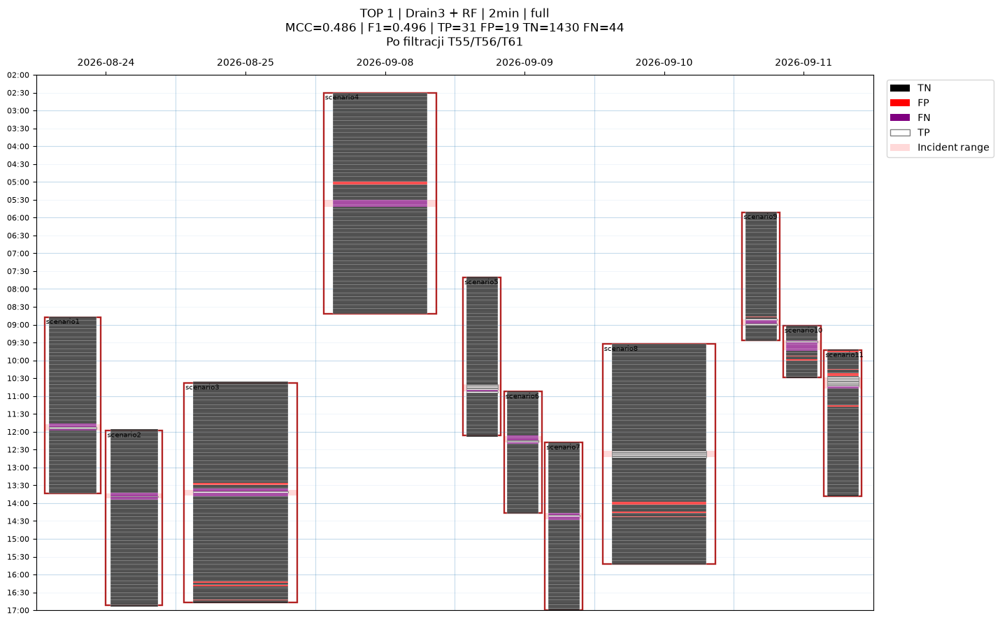

Rozkład wyników: {'TN': 1411, 'FN': 38, 'FP': 38, 'TP': 37}
Rysowanie TOP 2: 2min, basic, RF (1524 kubełków)


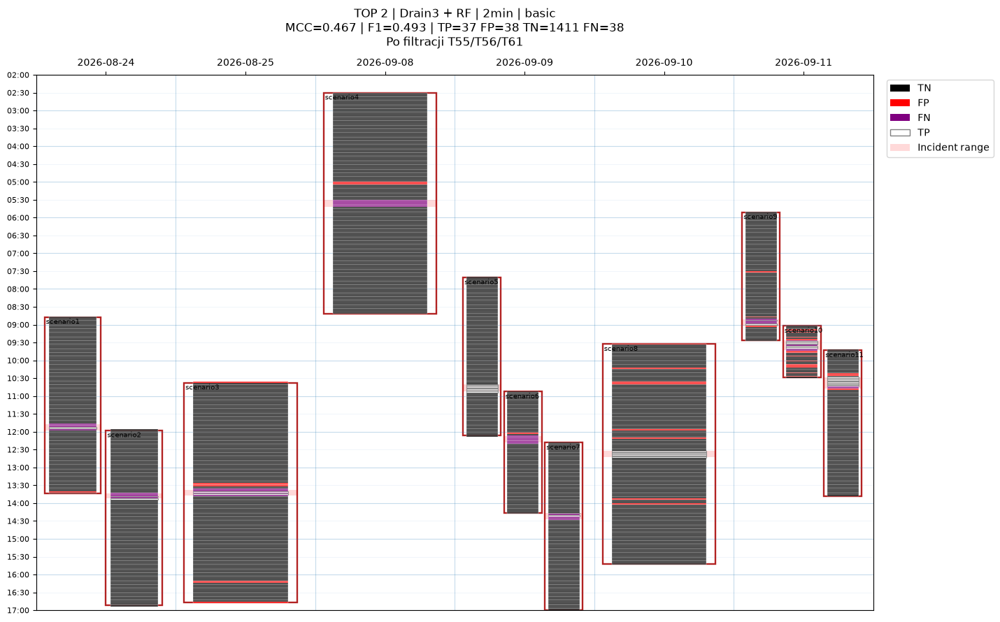

Rozkład wyników: {'TN': 555, 'FP': 25, 'FN': 19, 'TP': 17}
Rysowanie TOP 3: 5min, full, RF (616 kubełków)


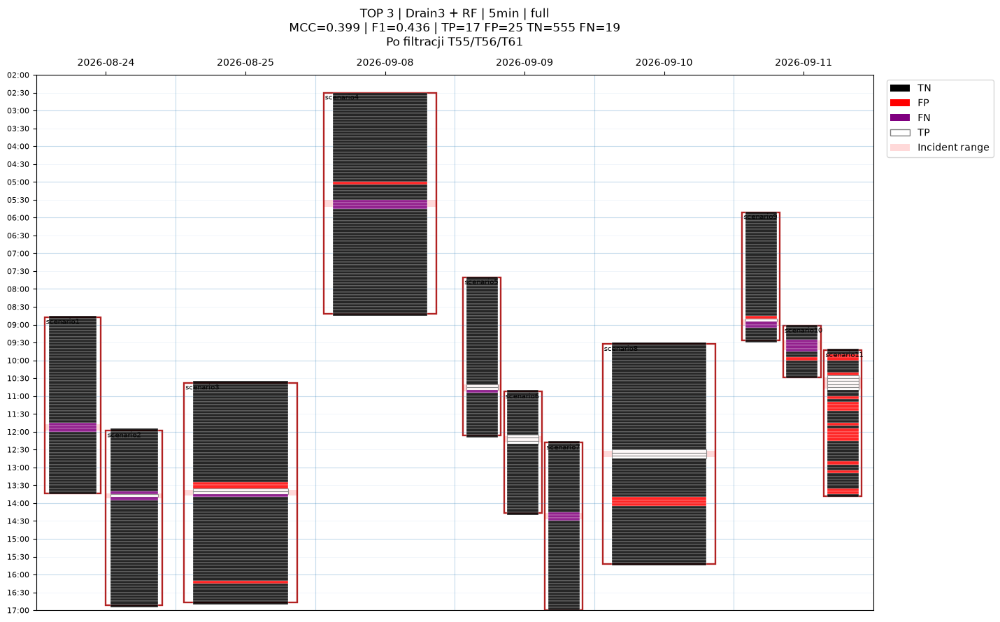

In [64]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt

# 1. Trzy najlepsze konfiguracje według globalnego MCC.
top3 = (
    RESULTS_FILTERED
    .sort_values("MCC", ascending=False)
    .head(3)
    .reset_index(drop=True)
)

# 2. Sprawdzenie danych kalendarza.
if not callable(globals().get("plot_calendar_with_buckets")):
    raise RuntimeError("Brakuje plot_calendar_with_buckets().")

if "CALENDAR_SEGMENTS_3H" not in globals():
    raise RuntimeError("Brakuje CALENDAR_SEGMENTS_3H.")

calendar_segments = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:
    calendar_segments[col] = (
        pd.to_datetime(calendar_segments[col], utc=True)
        .dt.tz_localize(None)
    )

# 3. Rysowanie.
for rank, (_, config) in enumerate(top3.iterrows(), start=1):

    window = config["window"]
    feature_set = config["feature_set"]
    model_name = config["model"]

    frames = []

    for case in SCENARIOS:
        path = (
            FILTER_PRED_DIR
            / (
                f"Drain3__{window}__{feature_set}"
                f"__{model_name}__{case}.joblib"
            )
        )

        saved = joblib.load(path)
        frame = saved["data"].copy()
        frame["case"] = case

        frames.append(frame)

    buckets = pd.concat(frames, ignore_index=True)

    # Dokładnie jak w oryginalnym wywołaniu:
    # UTC -> czas bez strefy.
    for col in ["timestamp", "bucket_end"]:
        buckets[col] = (
            pd.to_datetime(buckets[col], utc=True)
            .dt.tz_localize(None)
        )

    buckets["prediction"] = (
        buckets["prediction"].astype(int)
    )

    buckets["label_primary"] = (
        buckets["label_primary"].astype(int)
    )
        # Odtworzenie kolumny wymaganej przez oryginalny wykres.
    actual = buckets["label_primary"].astype(int)
    predicted = buckets["prediction"].astype(int)

    buckets["outcome"] = "TN"

    buckets.loc[
        (actual == 0) & (predicted == 1),
        "outcome"
    ] = "FP"

    buckets.loc[
        (actual == 1) & (predicted == 0),
        "outcome"
    ] = "FN"

    buckets.loc[
        (actual == 1) & (predicted == 1),
        "outcome"
    ] = "TP"

    print(
        "Rozkład wyników:",
        buckets["outcome"].value_counts().to_dict()
    )
    
    title = (
        f"TOP {rank} | Drain3 + {model_name}"
        f" | {window} | {feature_set}\n"
        f"MCC={config['MCC']:.3f} | F1={config['F1']:.3f}"
        f" | TP={int(config['TP'])}"
        f" FP={int(config['FP'])}"
        f" TN={int(config['TN'])}"
        f" FN={int(config['FN'])}"
        f"\nPo filtracji T55/T56/T61"
    )

    print(
        f"Rysowanie TOP {rank}: "
        f"{window}, {feature_set}, {model_name} "
        f"({len(buckets)} kubełków)"
    )

    plot_calendar_with_buckets(
        calendar_segments=calendar_segments,
        bucket_df=buckets,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

In [65]:
import os
import gc
import random
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

import torch
from torch import nn

# Najpierw pilot: 22 treningi.
# True = pełna siatka 132 treningów.
RUN_FULL_GRID = False

# Na początek NIE usuwamy żadnych szablonów.
USE_FILTERED = False

EPOCHS = 25
BATCH_SIZE = 64
SEED = 42

NN_WINDOWS = (
    ["2min", "5min", "10min"]
    if RUN_FULL_GRID else ["2min"]
)

NN_FEATURE_SETS = (
    {
        "basic": list(BASIC_FEATURES),
        "full": list(FEATURES18),
    }
    if RUN_FULL_GRID
    else {"full": list(FEATURES18)}
)

NN_KINDS = ["GRU", "LSTM"]

NN_RUN_NAME = (
    ("filtered" if USE_FILTERED else "original")
    + ("_fullgrid" if RUN_FULL_GRID else "_pilot")
)

NN_DIR = PREP_DIR / "nn_loso" / NN_RUN_NAME
NN_PRED_DIR = NN_DIR / "predictions"
NN_MODEL_DIR = NN_DIR / "models"
NN_REPORT_DIR = NN_DIR / "reports"

for p in [NN_PRED_DIR, NN_MODEL_DIR, NN_REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class IncidentRNN(nn.Module):

    def __init__(self, kind, n_features, hidden_size=24):
        super().__init__()

        rnn_class = nn.GRU if kind == "GRU" else nn.LSTM

        self.rnn = rnn_class(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(0.20)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequences, _ = self.rnn(x)
        last = sequences[:, -1, :]
        return self.output(
            self.dropout(last)
        ).squeeze(-1)


def make_sequences(frame, scaled, steps):
    """
    Buduje sekwencje bez przechodzenia między scenariuszami.
    Każda sekwencja zawiera tylko przeszłość i bieżący kubełek.
    """
    result = np.zeros(
        (len(frame), steps, scaled.shape[1]),
        dtype=np.float32,
    )

    for _, indices in frame.groupby(
        "case", sort=False
    ).indices.items():

        positions = np.asarray(indices)

        positions = positions[
            np.argsort(
                frame.iloc[positions][
                    "timestamp"
                ].to_numpy()
            )
        ]

        for j, pos in enumerate(positions):
            history = positions[
                max(0, j - steps + 1):j + 1
            ]

            result[pos, -len(history):, :] = scaled[
                history
            ]

    return result


def nn_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "precision": float(precision_score(
            y_true, y_pred, zero_division=0
        )),
        "recall": float(recall_score(
            y_true, y_pred, zero_division=0
        )),
        "F1": float(f1_score(
            y_true, y_pred, zero_division=0
        )),
        "MCC": float(matthews_corrcoef(
            y_true, y_pred
        )),
    }


print("Urządzenie:", DEVICE)
print("Filtracja:", USE_FILTERED)
print("Okna:", NN_WINDOWS)
print("Zestawy cech:", list(NN_FEATURE_SETS))
print("Modele:", NN_KINDS)
print(
    "Liczba treningów:",
    len(NN_WINDOWS)
    * len(NN_FEATURE_SETS)
    * len(NN_KINDS)
    * len(SCENARIOS)
)
print("Katalog:", NN_DIR)

Urządzenie: cpu
Filtracja: False
Okna: ['2min']
Zestawy cech: ['full']
Modele: ['GRU', 'LSTM']
Liczba treningów: 22
Katalog: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\original_pilot


In [66]:
import os
import gc
import random
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

import torch
from torch import nn

# Najpierw pilot: 22 treningi.
# True = pełna siatka 132 treningów.
RUN_FULL_GRID = False

# Na początek NIE usuwamy żadnych szablonów.
USE_FILTERED = False

EPOCHS = 25
BATCH_SIZE = 64
SEED = 42

NN_WINDOWS = (
    ["2min", "5min", "10min"]
    if RUN_FULL_GRID else ["2min"]
)

NN_FEATURE_SETS = (
    {
        "basic": list(BASIC_FEATURES),
        "full": list(FEATURES18),
    }
    if RUN_FULL_GRID
    else {"full": list(FEATURES18)}
)

NN_KINDS = ["GRU", "LSTM"]

NN_RUN_NAME = (
    ("filtered" if USE_FILTERED else "original")
    + ("_fullgrid" if RUN_FULL_GRID else "_pilot")
)

NN_DIR = PREP_DIR / "nn_loso" / NN_RUN_NAME
NN_PRED_DIR = NN_DIR / "predictions"
NN_MODEL_DIR = NN_DIR / "models"
NN_REPORT_DIR = NN_DIR / "reports"

for p in [NN_PRED_DIR, NN_MODEL_DIR, NN_REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class IncidentRNN(nn.Module):

    def __init__(self, kind, n_features, hidden_size=24):
        super().__init__()

        rnn_class = nn.GRU if kind == "GRU" else nn.LSTM

        self.rnn = rnn_class(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(0.20)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequences, _ = self.rnn(x)
        last = sequences[:, -1, :]
        return self.output(
            self.dropout(last)
        ).squeeze(-1)


def make_sequences(frame, scaled, steps):
    """
    Buduje sekwencje bez przechodzenia między scenariuszami.
    Każda sekwencja zawiera tylko przeszłość i bieżący kubełek.
    """
    result = np.zeros(
        (len(frame), steps, scaled.shape[1]),
        dtype=np.float32,
    )

    for _, indices in frame.groupby(
        "case", sort=False
    ).indices.items():

        positions = np.asarray(indices)

        positions = positions[
            np.argsort(
                frame.iloc[positions][
                    "timestamp"
                ].to_numpy()
            )
        ]

        for j, pos in enumerate(positions):
            history = positions[
                max(0, j - steps + 1):j + 1
            ]

            result[pos, -len(history):, :] = scaled[
                history
            ]

    return result


def nn_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "precision": float(precision_score(
            y_true, y_pred, zero_division=0
        )),
        "recall": float(recall_score(
            y_true, y_pred, zero_division=0
        )),
        "F1": float(f1_score(
            y_true, y_pred, zero_division=0
        )),
        "MCC": float(matthews_corrcoef(
            y_true, y_pred
        )),
    }


print("Urządzenie:", DEVICE)
print("Filtracja:", USE_FILTERED)
print("Okna:", NN_WINDOWS)
print("Zestawy cech:", list(NN_FEATURE_SETS))
print("Modele:", NN_KINDS)
print(
    "Liczba treningów:",
    len(NN_WINDOWS)
    * len(NN_FEATURE_SETS)
    * len(NN_KINDS)
    * len(SCENARIOS)
)
print("Katalog:", NN_DIR)

Urządzenie: cpu
Filtracja: False
Okna: ['2min']
Zestawy cech: ['full']
Modele: ['GRU', 'LSTM']
Liczba treningów: 22
Katalog: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\original_pilot


In [67]:
nn_overall_rows = []
nn_case_rows = []

scenarios_nn = list(SCENARIOS)
assert len(scenarios_nn) == 11

for window in NN_WINDOWS:

    steps = int(
        pd.Timedelta("30min") / pd.Timedelta(window)
    )

    frames = []

    for case in scenarios_nn:

        source = (
            FILTER_BUCKET_DIR
            if USE_FILTERED and case == "scenario11"
            else BUCKET_DIR
        )

        path = (
            source / f"Drain3__{case}__{window}.joblib"
        )

        if not path.exists():
            raise FileNotFoundError(path)

        df = joblib.load(path).copy()

        df["case"] = case
        df["timestamp"] = pd.to_datetime(
            df["timestamp"], utc=True
        )
        df["bucket_end"] = pd.to_datetime(
            df["bucket_end"], utc=True
        )

        frames.append(
            df.sort_values("timestamp")
        )

    data = pd.concat(
        frames, ignore_index=True
    )

    y = data["label_primary"].to_numpy(
        dtype=np.int64
    )
    case_names = data["case"].astype(str).to_numpy()

    print(
        f"\n{window}: {len(data)} kubełków, "
        f"pozytywne={int(y.sum())}, "
        f"historia={steps} kroków",
        flush=True,
    )

    for feat_name, feat_cols in NN_FEATURE_SETS.items():

        numeric = (
            data[feat_cols]
            .apply(pd.to_numeric, errors="raise")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0)
            .to_numpy(dtype=np.float32)
        )

        for kind in NN_KINDS:

            all_pred = np.full(
                len(data), -1, dtype=np.int64
            )

            print(
                f"  {feat_name} / {kind}",
                flush=True,
            )

            for fold, test_case in enumerate(
                scenarios_nn, start=1
            ):

                train_idx = np.flatnonzero(
                    case_names != test_case
                )
                test_idx = np.flatnonzero(
                    case_names == test_case
                )

                if not len(train_idx) or not len(test_idx):
                    raise RuntimeError(
                        f"Brak danych: {test_case}"
                    )

                # Scaler tylko z danych treningowych.
                scaler = StandardScaler()
                scaler.fit(numeric[train_idx])

                scaled = scaler.transform(
                    numeric
                ).astype(np.float32)

                seq = make_sequences(
                    data, scaled, steps
                )

                # Identyczny seed dla każdego foldu.
                random.seed(SEED)
                np.random.seed(SEED)
                torch.manual_seed(SEED)

                if DEVICE.type == "cuda":
                    torch.cuda.manual_seed_all(SEED)

                network = IncidentRNN(
                    kind,
                    len(feat_cols),
                ).to(DEVICE)

                optimizer = torch.optim.Adam(
                    network.parameters(),
                    lr=1e-3,
                )

                positives = int(y[train_idx].sum())
                negatives = int(
                    len(train_idx) - positives
                )

                if positives == 0:
                    raise RuntimeError(
                        "Brak pozytywnych przykładów "
                        "w zbiorze treningowym."
                    )

                pos_weight = min(
                    10.0,
                    negatives / positives,
                )

                loss_fn = nn.BCEWithLogitsLoss(
                    pos_weight=torch.tensor(
                        pos_weight,
                        dtype=torch.float32,
                        device=DEVICE,
                    )
                )

                x_train = torch.from_numpy(
                    seq[train_idx]
                ).to(DEVICE)

                y_train = torch.from_numpy(
                    y[train_idx].astype(np.float32)
                ).to(DEVICE)

                for epoch in range(EPOCHS):

                    network.train()

                    order = torch.randperm(
                        len(train_idx),
                        device=DEVICE,
                    )

                    for batch in order.split(BATCH_SIZE):

                        optimizer.zero_grad(
                            set_to_none=True
                        )

                        logits = network(
                            x_train[batch]
                        )

                        loss = loss_fn(
                            logits, y_train[batch]
                        )

                        loss.backward()
                        optimizer.step()

                # Predykcja wyłącznie dla test_case.
                network.eval()

                with torch.no_grad():

                    test_tensor = torch.from_numpy(
                        seq[test_idx]
                    ).to(DEVICE)

                    probability = torch.sigmoid(
                        network(test_tensor)
                    ).cpu().numpy()

                pred = (
                    probability >= 0.50
                ).astype(np.int64)

                all_pred[test_idx] = pred

                metrics = nn_metrics(
                    y[test_idx],
                    pred,
                )

                nn_case_rows.append({
                    "window": window,
                    "feature_set": feat_name,
                    "model": kind,
                    "case": test_case,
                    **metrics,
                })

                prediction_frame = data.iloc[
                    test_idx
                ][[
                    "case",
                    "timestamp",
                    "bucket_end",
                    "label_primary",
                    "label_all_known",
                ]].copy()

                prediction_frame["prediction"] = pred
                prediction_frame["probability"] = (
                    probability
                )

                name = (
                    f"Drain3__{window}__{feat_name}"
                    f"__{kind}__{test_case}"
                )

                # Predykcje zgodne ze strukturą RF/GB/LR.
                joblib.dump(
                    {
                        "data": prediction_frame,
                        "metrics": metrics,
                    },
                    NN_PRED_DIR / f"{name}.joblib",
                    compress=3,
                )

                # Zapis wytrenowanej sieci i scalera.
                torch.save(
                    {
                        "state_dict": {
                            k: v.detach().cpu()
                            for k, v in network.state_dict().items()
                        },
                        "features": feat_cols,
                        "steps": steps,
                        "kind": kind,
                        "scaler_mean": scaler.mean_,
                        "scaler_scale": scaler.scale_,
                        "epochs": EPOCHS,
                        "threshold": 0.50,
                    },
                    NN_MODEL_DIR / f"{name}.pt",
                )

                print(
                    f"    {fold:2d}/11 {test_case}: "
                    f"MCC={metrics['MCC']:.3f}, "
                    f"FP={metrics['FP']}",
                    flush=True,
                )

                del (
                    seq,
                    scaled,
                    network,
                    optimizer,
                    x_train,
                    y_train,
                    test_tensor,
                )

                if DEVICE.type == "cuda":
                    torch.cuda.empty_cache()

                gc.collect()

            if (all_pred < 0).any():
                raise RuntimeError(
                    "Brak predykcji dla części kubełków."
                )

            overall = nn_metrics(y, all_pred)

            nn_overall_rows.append({
                "parser": "Drain3",
                "window": window,
                "feature_set": feat_name,
                "model": kind,
                **overall,
            })

            print(
                f"  WYNIK: "
                f"MCC={overall['MCC']:.4f}, "
                f"F1={overall['F1']:.4f}",
                flush=True,
            )

NN_RESULTS = (
    pd.DataFrame(nn_overall_rows)
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

NN_CASE_RESULTS = pd.DataFrame(nn_case_rows)

NN_RESULTS.to_csv(
    NN_REPORT_DIR / "overall_results.csv",
    index=False,
)

NN_CASE_RESULTS.to_csv(
    NN_REPORT_DIR / "scenario_results.csv",
    index=False,
)

print("\n=== WYNIKI GLOBALNE ===")
display(NN_RESULTS.round(4))

print("\n=== SCENARIO11 ===")
display(
    NN_CASE_RESULTS[
        NN_CASE_RESULTS["case"] == "scenario11"
    ].round(4)
)

print("\nZapisano wyniki w:", NN_DIR)


2min: 1524 kubełków, pozytywne=75, historia=15 kroków
  full / GRU
     1/11 scenario1: MCC=0.627, FP=5
     2/11 scenario2: MCC=0.595, FP=6
     3/11 scenario3: MCC=0.486, FP=17
     4/11 scenario4: MCC=-0.023, FP=3
     5/11 scenario5: MCC=0.932, FP=1
     6/11 scenario6: MCC=-0.116, FP=16
     7/11 scenario7: MCC=0.000, FP=0
     8/11 scenario8: MCC=0.270, FP=13
     9/11 scenario9: MCC=0.720, FP=5
    10/11 scenario10: MCC=0.000, FP=0
    11/11 scenario11: MCC=0.027, FP=112
  WYNIK: MCC=0.2691, F1=0.2847
  full / LSTM
     1/11 scenario1: MCC=0.708, FP=3
     2/11 scenario2: MCC=0.531, FP=2
     3/11 scenario3: MCC=0.249, FP=15
     4/11 scenario4: MCC=-0.019, FP=2
     5/11 scenario5: MCC=0.849, FP=1
     6/11 scenario6: MCC=0.424, FP=16
     7/11 scenario7: MCC=0.000, FP=0
     8/11 scenario8: MCC=0.294, FP=11
     9/11 scenario9: MCC=0.759, FP=4
    10/11 scenario10: MCC=0.430, FP=0
    11/11 scenario11: MCC=0.027, FP=112
  WYNIK: MCC=0.2963, F1=0.3088

=== WYNIKI GLOBALNE ===


,parser,window,feature_set,model,TP,FP,FN,TN,precision,recall,F1,MCC
0,Drain3,2min,full,LSTM,44,166,31,1283,0.2095,0.5867,0.3088,0.2963
1,Drain3,2min,full,GRU,42,178,33,1271,0.1909,0.5600,0.2847,0.2691



=== SCENARIO11 ===


,window,feature_set,model,case,TP,FP,FN,TN,precision,recall,F1,MCC
10,2min,full,GRU,scenario11,10,112,0,1,0.082,1.0,0.1515,0.0269
21,2min,full,LSTM,scenario11,10,112,0,1,0.082,1.0,0.1515,0.0269



Zapisano wyniki w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\original_pilot



LSTM:
{'TN': 1283, 'FP': 166, 'TP': 44, 'FN': 31}


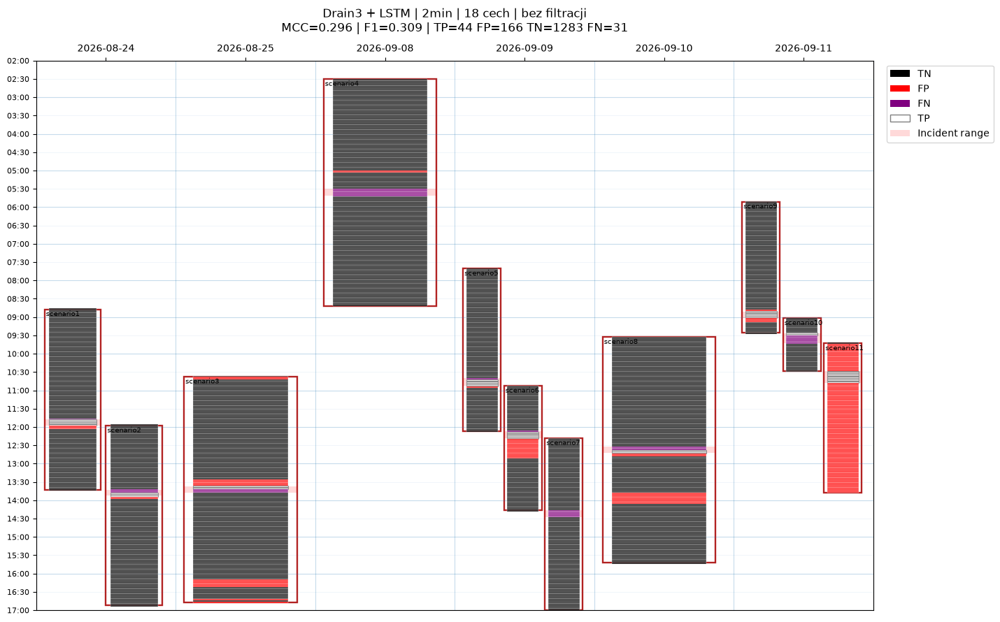


GRU:
{'TN': 1271, 'FP': 178, 'TP': 42, 'FN': 33}


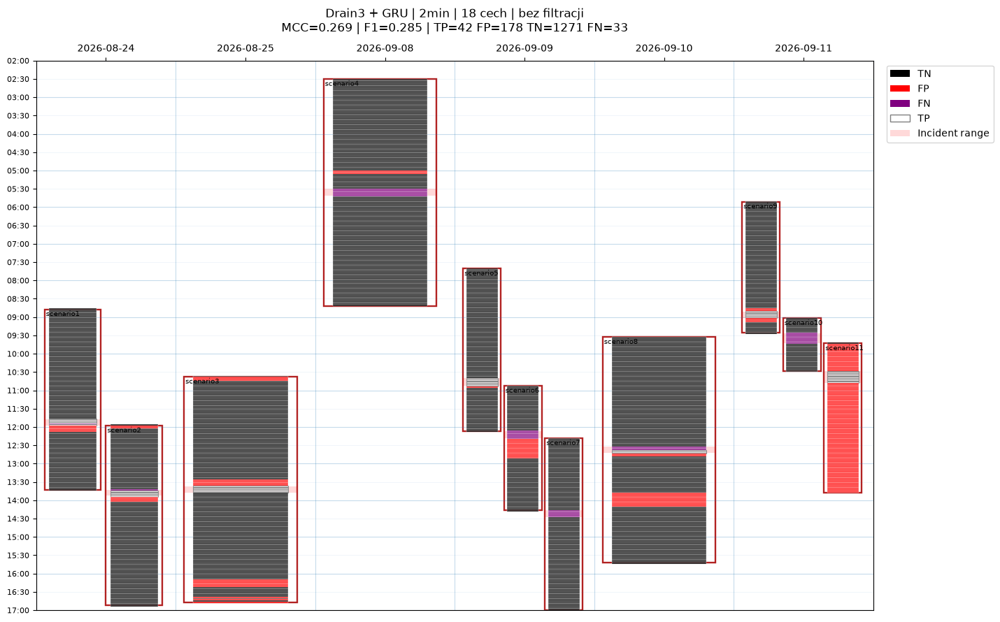

In [68]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
)

# Wyniki pilotażu LSTM/GRU bez filtracji.
NN_CALENDAR_DIR = (
    PREP_DIR / "nn_loso" / "original_pilot" / "predictions"
)

NN_CALENDAR_DATA = {}

# Oryginalne przedziały scenariuszy i incydentów.
calendar_segments = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:
    calendar_segments[col] = (
        pd.to_datetime(calendar_segments[col], utc=True)
        .dt.tz_localize(None)
    )

for model_name in ["LSTM", "GRU"]:

    frames = []

    for case in SCENARIOS:

        path = (
            NN_CALENDAR_DIR
            / f"Drain3__2min__full__{model_name}__{case}.joblib"
        )

        if not path.exists():
            raise FileNotFoundError(path)

        saved = joblib.load(path)
        frame = saved["data"].copy()
        frame["case"] = case

        frames.append(frame)

    buckets = pd.concat(frames, ignore_index=True)

    # Taki sam format czasu jak na wcześniejszych kalendarzach.
    for col in ["timestamp", "bucket_end"]:
        buckets[col] = (
            pd.to_datetime(buckets[col], utc=True)
            .dt.tz_localize(None)
        )

    actual = buckets["label_primary"].astype(int)
    predicted = buckets["prediction"].astype(int)

    buckets["outcome"] = np.select(
        [
            (actual == 1) & (predicted == 1),
            (actual == 0) & (predicted == 1),
            (actual == 1) & (predicted == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    mcc = matthews_corrcoef(actual, predicted)
    f1 = f1_score(actual, predicted, zero_division=0)

    title = (
        f"Drain3 + {model_name} | 2min | 18 cech | bez filtracji\n"
        f"MCC={mcc:.3f} | F1={f1:.3f}"
        f" | TP={tp} FP={fp} TN={tn} FN={fn}"
    )

    NN_CALENDAR_DATA[model_name] = buckets.copy()

    print(f"\n{model_name}:")
    print(buckets["outcome"].value_counts().to_dict())

    plot_calendar_with_buckets(
        calendar_segments=calendar_segments,
        bucket_df=buckets,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

In [69]:
diagnostic_frames = []

for model_name, df in NN_CALENDAR_DATA.items():

    summary = (
        df.groupby("case")
        .agg(
            buckets=("prediction", "size"),
            actual_incidents=("label_primary", "sum"),
            predicted_incidents=("prediction", "sum"),
            median_probability=("probability", "median"),
            p10_probability=(
                "probability",
                lambda x: x.quantile(0.10),
            ),
            p90_probability=(
                "probability",
                lambda x: x.quantile(0.90),
            ),
        )
        .reset_index()
    )

    summary["predicted_positive_pct"] = (
        100
        * summary["predicted_incidents"]
        / summary["buckets"]
    )

    summary["model"] = model_name
    diagnostic_frames.append(summary)

NN_DIAGNOSTICS = pd.concat(
    diagnostic_frames, ignore_index=True
)

display(
    NN_DIAGNOSTICS[
        [
            "model",
            "case",
            "buckets",
            "actual_incidents",
            "predicted_incidents",
            "predicted_positive_pct",
            "median_probability",
            "p10_probability",
            "p90_probability",
        ]
    ].round(3)
)

,model,case,buckets,actual_incidents,predicted_incidents,predicted_positive_pct,median_probability,p10_probability,p90_probability
0,LSTM,scenario1,149,6,8,5.369,0.003,0.002,0.024
1,LSTM,scenario10,44,9,2,4.545,0.006,0.003,0.193
2,LSTM,scenario11,123,10,122,99.187,0.957,0.901,0.983
3,LSTM,scenario2,149,6,5,3.356,0.002,0.001,0.041
4,LSTM,scenario3,186,6,18,9.677,0.003,0.001,0.469
5,LSTM,scenario4,186,6,2,1.075,0.003,0.001,0.009
6,LSTM,scenario5,134,7,7,5.224,0.001,0.001,0.005
7,LSTM,scenario6,103,7,22,21.359,0.002,0.002,0.879
8,LSTM,scenario7,155,6,0,0.000,0.001,0.001,0.003
9,LSTM,scenario8,186,6,14,7.527,0.002,0.002,0.078


In [70]:
import joblib
import numpy as np
import pandas as pd

DIAG_CASE = "scenario11"
DIAG_WINDOW = "2min"

parts = []

for case in SCENARIOS:
    path = (
        BUCKET_DIR
        / f"Drain3__{case}__{DIAG_WINDOW}.joblib"
    )

    df = joblib.load(path).copy()
    df["case"] = case
    parts.append(df)

DIAG_DATA_2MIN = pd.concat(
    parts, ignore_index=True
)

features = list(FEATURES18)

X = (
    DIAG_DATA_2MIN[features]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

is_test = DIAG_DATA_2MIN["case"].eq(DIAG_CASE)
is_normal = DIAG_DATA_2MIN["label_primary"].eq(0)

train = X.loc[~is_test]
test = X.loc[is_test]
test_normal = X.loc[is_test & is_normal]

rows = []

for feature in features:

    tr = train[feature]
    te = test[feature]
    normal = test_normal[feature]

    q25 = tr.quantile(0.25)
    q75 = tr.quantile(0.75)
    q99 = tr.quantile(0.99)

    iqr = q75 - q25

    scale = tr.std(ddof=0)
    if not np.isfinite(scale) or scale < 1e-8:
        scale = 1.0

    standardized = (
        (normal - tr.mean()) / scale
    )

    rows.append({
        "feature": feature,
        "train_median": tr.median(),
        "test_median": te.median(),
        "normal11_median": normal.median(),
        "train_p99": q99,
        "median_shift_IQR": (
            (normal.median() - tr.median())
            / max(iqr, 1e-8)
        ),
        "normal11_above_train_p99_pct": (
            100 * (normal > q99).mean()
        ),
        "normal11_abs_z_gt_5_pct": (
            100 * (standardized.abs() > 5).mean()
        ),
    })

FEATURE_SHIFT = (
    pd.DataFrame(rows)
    .sort_values(
        "normal11_abs_z_gt_5_pct",
        ascending=False,
    )
    .reset_index(drop=True)
)

print(
    "Kubełki treningowe:", len(train),
    "| scenario11:", len(test),
    "| normalne scenario11:", len(test_normal),
)

display(FEATURE_SHIFT.round(3))

Kubełki treningowe: 1401 | scenario11: 123 | normalne scenario11: 113


,feature,train_median,test_median,normal11_median,train_p99,median_shift_IQR,normal11_above_train_p99_pct,normal11_abs_z_gt_5_pct
0,unique_templates,18.000,57.000,56.000,49.000,3.800000e+00,84.071,45.133
1,templates_enriched_5x,0.000,4.000,4.000,18.000,4.000000e+00,8.850,7.965
2,single_occurrence_templates,2.000,11.000,10.000,21.000,1.000000e+00,8.850,3.540
3,templates_enriched_10x,0.000,1.000,1.000,18.000,1.000000e+08,2.655,2.655
4,single_occurrence_templates_z,0.000,0.169,0.096,10.000,4.800000e-02,0.885,0.885
5,unique_templates_z,0.000,0.135,0.000,16.036,0.000000e+00,0.885,0.885
6,mean_top3_enrichment,1.723,10.074,10.006,116.112,2.643000e+00,0.885,0.885
7,total_logs,171.000,659.000,627.000,4696.000,1.381800e+01,0.000,0.000
8,single_occurrence_rate,0.011,0.012,0.013,0.085,6.300000e-02,0.000,0.000
9,unique_rate,0.099,0.082,0.083,0.171,-3.410000e-01,0.000,0.000


In [71]:
from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
)

data = DIAG_DATA_2MIN

X_rf = (
    data[FEATURES18]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

y_rf = data["label_primary"].astype(int).to_numpy()
cases_rf = data["case"].astype(str).to_numpy()

pred_rf = np.full(len(y_rf), -1, dtype=int)

for case in SCENARIOS:

    train_mask = cases_rf != case
    test_mask = cases_rf == case

    model = clone(MODELS["RF"])
    model.fit(X_rf[train_mask], y_rf[train_mask])

    pred_rf[test_mask] = model.predict(
        X_rf[test_mask]
    ).astype(int)

def show_rf_score(name, mask):

    actual = y_rf[mask]
    predicted = pred_rf[mask]

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    print(
        f"{name}: "
        f"MCC={matthews_corrcoef(actual, predicted):.4f}, "
        f"F1={f1_score(actual, predicted, zero_division=0):.4f}, "
        f"TP={tp}, FP={fp}, FN={fn}, TN={tn}"
    )

print("RF | Drain3 | 2min | 18 cech | bez filtracji")

show_rf_score(
    "Cały LOSO",
    np.ones(len(y_rf), dtype=bool),
)

show_rf_score(
    "scenario11",
    cases_rf == "scenario11",
)

RF | Drain3 | 2min | 18 cech | bez filtracji
Cały LOSO: MCC=0.4434, F1=0.4681, TP=33, FP=33, FN=42, TN=1416
scenario11: MCC=0.4172, F1=0.4324, TP=8, FP=19, FN=2, TN=94


In [72]:
import random
import gc
import joblib
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from sklearn.preprocessing import StandardScaler

if not callable(globals().get("make_sequences")):
    raise RuntimeError("Brakuje funkcji make_sequences")

if not callable(globals().get("nn_metrics")):
    raise RuntimeError("Brakuje funkcji nn_metrics")

if "IncidentRNN" not in globals():
    raise RuntimeError("Brakuje klasy IncidentRNN")

EXP_VARIANTS = {
    "A_weight2_18": {
        "features": list(FEATURES18),
        "clip": None,
    },
    "B_weight2_18_clip3": {
        "features": list(FEATURES18),
        "clip": 3.0,
    },
    "C_weight2_15_clip3": {
        "features": [
            f for f in FEATURES18
            if f not in {
                "total_logs",
                "unique_templates",
                "single_occurrence_templates",
            }
        ],
        "clip": 3.0,
    },
}

EXP_ROOT = PREP_DIR / "nn_loso" / "lstm_shift_ablation"
EXP_PRED = EXP_ROOT / "predictions"
EXP_REPORT = EXP_ROOT / "reports"

for p in [EXP_PRED, EXP_REPORT]:
    p.mkdir(parents=True, exist_ok=True)

# Oryginalne kubełki bez filtracji.
frames = []

for case in SCENARIOS:
    path = BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    df = joblib.load(path).copy()
    df["case"] = case
    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
    df["bucket_end"] = pd.to_datetime(df["bucket_end"], utc=True)
    frames.append(df.sort_values("timestamp"))

data = pd.concat(frames, ignore_index=True)
y = data["label_primary"].astype(int).to_numpy()
cases = data["case"].astype(str).to_numpy()

assert len(data) == 1524
assert int(y.sum()) == 75

DEVICE_EXP = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

rows_global = []
rows_cases = []

for variant_name, setup in EXP_VARIANTS.items():

    columns = setup["features"]
    clip_value = setup["clip"]

    numeric = (
        data[columns]
        .apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    all_predictions = np.full(len(data), -1, dtype=int)

    print(
        f"\n=== {variant_name} | "
        f"{len(columns)} cech | clip={clip_value} ===",
        flush=True,
    )

    for test_case in SCENARIOS:

        train_idx = np.flatnonzero(cases != test_case)
        test_idx = np.flatnonzero(cases == test_case)

        scaler = StandardScaler()
        scaler.fit(numeric[train_idx])

        scaled = scaler.transform(numeric).astype(np.float32)

        if clip_value is not None:
            scaled = np.clip(
                scaled, -clip_value, clip_value
            )

        sequences = make_sequences(
            data,
            scaled,
            steps=15,
        )

        # Identyczny seed w każdym foldzie.
        random.seed(42)
        np.random.seed(42)
        torch.manual_seed(42)

        if DEVICE_EXP.type == "cuda":
            torch.cuda.manual_seed_all(42)

        model = IncidentRNN(
            kind="LSTM",
            n_features=len(columns),
            hidden_size=24,
        ).to(DEVICE_EXP)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001,
        )

        loss_fn = torch.nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                2.0,
                device=DEVICE_EXP,
            )
        )

        x_train = torch.from_numpy(
            sequences[train_idx]
        ).to(DEVICE_EXP)

        y_train = torch.from_numpy(
            y[train_idx].astype(np.float32)
        ).to(DEVICE_EXP)

        for epoch in range(25):

            model.train()

            order = torch.randperm(
                len(train_idx),
                device=DEVICE_EXP,
            )

            for batch in order.split(64):

                optimizer.zero_grad(set_to_none=True)

                logits = model(x_train[batch])
                loss = loss_fn(
                    logits,
                    y_train[batch],
                )

                loss.backward()
                optimizer.step()

        model.eval()

        with torch.no_grad():
            x_test = torch.from_numpy(
                sequences[test_idx]
            ).to(DEVICE_EXP)

            probability = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

        prediction = (
            probability >= 0.5
        ).astype(int)

        all_predictions[test_idx] = prediction

        metrics = nn_metrics(
            y[test_idx], prediction
        )

        normal_mask = y[test_idx] == 0

        rows_cases.append({
            "variant": variant_name,
            "case": test_case,
            **metrics,
            "normal_median_probability": (
                float(np.median(
                    probability[normal_mask]
                ))
                if normal_mask.any() else np.nan
            ),
        })

        prediction_df = data.iloc[test_idx][[
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]].copy()

        prediction_df["prediction"] = prediction
        prediction_df["probability"] = probability

        joblib.dump(
            {
                "data": prediction_df,
                "metrics": metrics,
                "variant": variant_name,
            },
            EXP_PRED / (
                f"{variant_name}__{test_case}.joblib"
            ),
            compress=3,
        )

        print(
            f"  {test_case}: "
            f"TP={metrics['TP']} "
            f"FP={metrics['FP']} "
            f"MCC={metrics['MCC']:.3f}",
            flush=True,
        )

        del (
            model,
            optimizer,
            x_train,
            y_train,
            x_test,
            sequences,
            scaled,
        )

        if DEVICE_EXP.type == "cuda":
            torch.cuda.empty_cache()

        gc.collect()

    overall = nn_metrics(y, all_predictions)

    rows_global.append({
        "variant": variant_name,
        "features": len(columns),
        **overall,
    })

    # Zapis po każdym wariancie.
    pd.DataFrame(rows_global).to_csv(
        EXP_REPORT / "overall_results.csv",
        index=False,
    )

    pd.DataFrame(rows_cases).to_csv(
        EXP_REPORT / "scenario_results.csv",
        index=False,
    )

EXP_RESULTS = (
    pd.DataFrame(rows_global)
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

EXP_CASE_RESULTS = pd.DataFrame(rows_cases)

print("\n=== WYNIKI GLOBALNE ===")
display(EXP_RESULTS.round(4))

print("\n=== SCENARIO11 ===")
display(
    EXP_CASE_RESULTS[
        EXP_CASE_RESULTS["case"] == "scenario11"
    ][[
        "variant",
        "TP", "FP", "FN", "TN",
        "F1", "MCC",
        "normal_median_probability",
    ]].round(4)
)

print("\nZapisano w:", EXP_ROOT)


=== A_weight2_18 | 18 cech | clip=None ===
  scenario1: TP=1 FP=4 MCC=0.151
  scenario2: TP=0 FP=4 MCC=-0.034
  scenario3: TP=1 FP=8 MCC=0.101
  scenario4: TP=0 FP=2 MCC=-0.019
  scenario5: TP=6 FP=0 MCC=0.922
  scenario6: TP=4 FP=14 MCC=0.282
  scenario7: TP=0 FP=0 MCC=0.000
  scenario8: TP=3 FP=9 MCC=0.324
  scenario9: TP=5 FP=0 MCC=0.908
  scenario10: TP=0 FP=0 MCC=0.000
  scenario11: TP=9 FP=103 MCC=-0.011

=== B_weight2_18_clip3 | 18 cech | clip=3.0 ===
  scenario1: TP=4 FP=3 MCC=0.600
  scenario2: TP=2 FP=3 MCC=0.341
  scenario3: TP=2 FP=10 MCC=0.200
  scenario4: TP=0 FP=2 MCC=-0.019
  scenario5: TP=6 FP=1 MCC=0.849
  scenario6: TP=5 FP=4 MCC=0.599
  scenario7: TP=0 FP=0 MCC=0.000
  scenario8: TP=5 FP=9 MCC=0.525
  scenario9: TP=5 FP=1 MCC=0.824
  scenario10: TP=0 FP=0 MCC=0.000
  scenario11: TP=10 FP=108 MCC=0.061

=== C_weight2_15_clip3 | 15 cech | clip=3.0 ===
  scenario1: TP=5 FP=2 MCC=0.761
  scenario2: TP=5 FP=1 MCC=0.826
  scenario3: TP=5 FP=13 MCC=0.455
  scenario4: TP=0

,variant,features,TP,FP,FN,TN,precision,recall,F1,MCC
0,C_weight2_15_clip3,15,35,33,40,1416,0.5147,0.4667,0.4895,0.4651
1,B_weight2_18_clip3,18,39,141,36,1308,0.2167,0.5200,0.3059,0.2833
2,A_weight2_18,18,29,144,46,1305,0.1676,0.3867,0.2339,0.1959



=== SCENARIO11 ===


,variant,TP,FP,FN,TN,F1,MCC,normal_median_probability
10,A_weight2_18,9,103,1,10,0.1475,-0.0110,0.8328
21,B_weight2_18_clip3,10,108,0,5,0.1562,0.0612,0.7738
32,C_weight2_15_clip3,8,1,2,112,0.8421,0.8303,0.0105



Zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\lstm_shift_ablation


In [73]:
BASE15 = [
    f for f in FEATURES18
    if f not in {
        "total_logs",
        "unique_templates",
        "single_occurrence_templates",
    }
]

ZSCORE_FEATURES = {
    "total_logs_z",
    "unique_templates_z",
    "single_occurrence_templates_z",
    "template_entropy_z",
}

EXP_VARIANTS = {
    "D_16_plus_unique": {
        "features": BASE15 + ["unique_templates"],
        "clip": 3.0,
    },
    "E_16_plus_total": {
        "features": BASE15 + ["total_logs"],
        "clip": 3.0,
    },
    "F_16_plus_single": {
        "features": BASE15 + ["single_occurrence_templates"],
        "clip": 3.0,
    },
    "G_11_without_z": {
        "features": [
            f for f in BASE15
            if f not in ZSCORE_FEATURES
        ],
        "clip": 3.0,
    },
}

for name, config in EXP_VARIANTS.items():
    print(name, len(config["features"]), config["features"])

D_16_plus_unique 16 ['unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'templates_enriched_5x', 'templates_enriched_10x', 'unique_templates']
E_16_plus_total 16 ['unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy_z', 'max_template_enrichment', 'mean_top3_enrichment', 'templates_enriched_5x', 'templates_enriched_10x', 'total_logs']
F_16_plus_single 16 ['unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy', 'novel_template_rate', 'template_set_change', 'js_divergence', 'total_logs_z', 'unique_templates_z', 'single_occurrence_templates_z', 'template_entropy

In [74]:
EXP_ROOT = PREP_DIR / "nn_loso" / "lstm_feature_ablation_v2"


=== KALENDARZ: C_weight2_15_clip3 ===


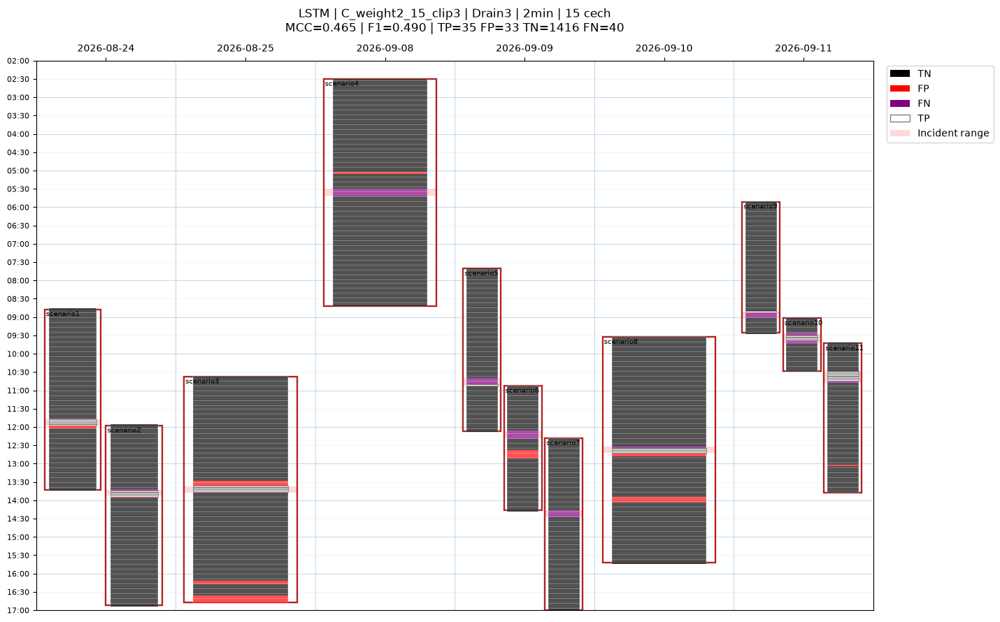

In [75]:
    # ======================================================
    # KALENDARZ PO KAŻDYM ZAKOŃCZONYM WARIANCIE LOSO
    # ======================================================

    plot_buckets = data[
        [
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]
    ].copy()

    plot_buckets["prediction"] = all_predictions.astype(int)

    actual = plot_buckets["label_primary"].astype(int)
    predicted = plot_buckets["prediction"]

    plot_buckets["outcome"] = np.select(
        [
            (actual == 1) & (predicted == 1),
            (actual == 0) & (predicted == 1),
            (actual == 1) & (predicted == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    # Ten sam format czasu co na oryginalnych kalendarzach.
    for col in ["timestamp", "bucket_end"]:
        plot_buckets[col] = (
            pd.to_datetime(plot_buckets[col], utc=True)
            .dt.tz_localize(None)
        )

    plot_calendar = CALENDAR_SEGMENTS_3H.copy()

    for col in [
        "day",
        "scenario_start",
        "scenario_end",
        "incident_start",
        "incident_end",
    ]:
        plot_calendar[col] = (
            pd.to_datetime(plot_calendar[col], utc=True)
            .dt.tz_localize(None)
        )

    plot_title = (
        f"LSTM | {variant_name} | Drain3 | 2min | "
        f"{len(columns)} cech\n"
        f"MCC={overall['MCC']:.3f} | "
        f"F1={overall['F1']:.3f} | "
        f"TP={overall['TP']} "
        f"FP={overall['FP']} "
        f"TN={overall['TN']} "
        f"FN={overall['FN']}"
    )

    print(
        f"\n=== KALENDARZ: {variant_name} ===",
        flush=True,
    )

    plot_calendar_with_buckets(
        calendar_segments=plot_calendar,
        bucket_df=plot_buckets,
        title=plot_title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

Urządzenie: cpu
Folder: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\lstm_feature_ablation_v2
Liczba treningów: 44
D_plus_unique | cechy: 16
E_plus_total | cechy: 16
F_plus_single | cechy: 16
G_without_z | cechy: 11

Kubełki: 1524 | pozytywne: 75

WARIANT: D_plus_unique
Liczba cech: 16
Clip: 3.0
   1/11  scenario1 | TP= 4 FP=  2 FN= 2 TN=141 | MCC=0.653
   2/11  scenario2 | TP= 4 FP=  1 FN= 2 TN=142 | MCC=0.720
   3/11  scenario3 | TP= 3 FP=  7 FN= 3 TN=173 | MCC=0.361
   4/11  scenario4 | TP= 0 FP=  1 FN= 6 TN=179 | MCC=-0.013
   5/11  scenario5 | TP= 5 FP=  1 FN= 2 TN=126 | MCC=0.760
   6/11  scenario6 | TP= 4 FP=  5 FN= 3 TN= 91 | MCC=0.463
   7/11  scenario7 | TP= 0 FP=  0 FN= 6 TN=149 | MCC=0.000
   8/11  scenario8 | TP= 5 FP= 10 FN= 1 TN=170 | MCC=0.505
   9/11  scenario9 | TP= 6 FP=  1 FN= 0 TN=102 | MCC=0.921
  10/11 scenario10 | TP= 2 FP=  0 FN= 7 TN= 35 | MCC=0.430
  11/11 scenario11 | TP=10 FP= 95 FN= 0 TN= 18 | MCC=0.123

---------------------------

,variant,features,MCC,F1,precision,recall,TP,FP,FN,TN
0,D_plus_unique,16,0.3391,0.3568,0.259,0.5733,43,123,32,1326



WYNIKI DLA KAŻDEGO SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN,normal_median_probability
0,scenario1,0.6527,0.6667,4,2,2,141,0.0026
1,scenario2,0.7201,0.7273,4,1,2,142,0.0019
2,scenario3,0.3612,0.3750,3,7,3,173,0.0023
3,scenario4,-0.0134,0.0000,0,1,6,179,0.0016
4,scenario5,0.7600,0.7692,5,1,2,126,0.0008
5,scenario6,0.4629,0.5000,4,5,3,91,0.0020
6,scenario7,0.0000,0.0000,0,0,6,149,0.0012
7,scenario8,0.5047,0.4762,5,10,1,170,0.0020
8,scenario9,0.9213,0.9231,6,1,0,102,0.0026
9,scenario10,0.4303,0.3636,2,0,7,35,0.0025



KALENDARZ: D_plus_unique


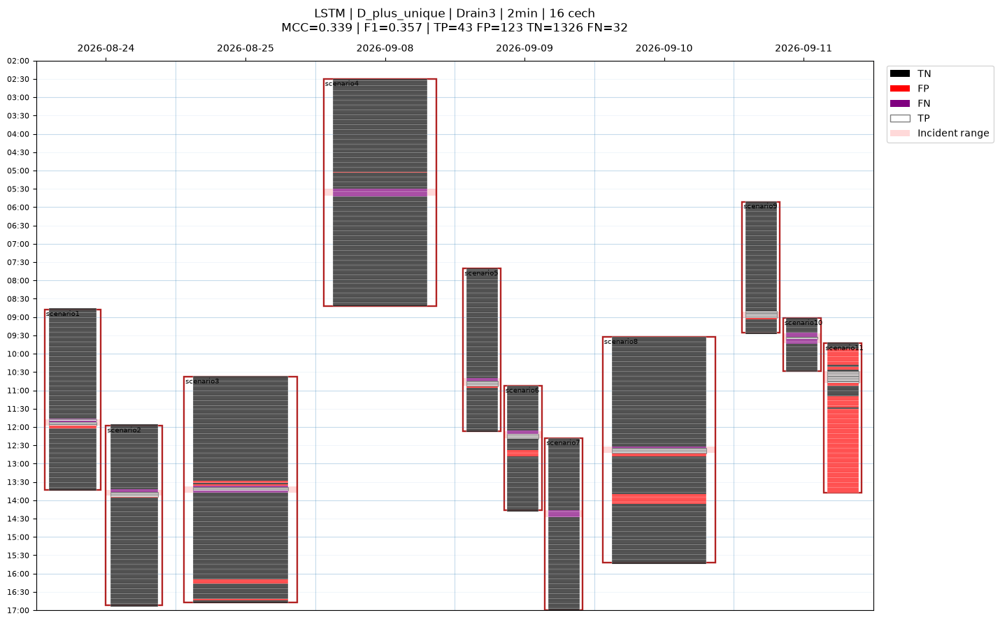


Zakończono: D_plus_unique

WARIANT: E_plus_total
Liczba cech: 16
Clip: 3.0
   1/11  scenario1 | TP= 5 FP=  2 FN= 1 TN=141 | MCC=0.761
   2/11  scenario2 | TP= 3 FP=  2 FN= 3 TN=141 | MCC=0.531
   3/11  scenario3 | TP= 3 FP=  5 FN= 3 TN=175 | MCC=0.411
   4/11  scenario4 | TP= 0 FP=  2 FN= 6 TN=178 | MCC=-0.019
   5/11  scenario5 | TP= 5 FP=  1 FN= 2 TN=126 | MCC=0.760
   6/11  scenario6 | TP= 5 FP=  5 FN= 2 TN= 91 | MCC=0.563
   7/11  scenario7 | TP= 0 FP=  0 FN= 6 TN=149 | MCC=0.000
   8/11  scenario8 | TP= 5 FP= 10 FN= 1 TN=170 | MCC=0.505
   9/11  scenario9 | TP= 4 FP=  0 FN= 2 TN=103 | MCC=0.809
  10/11 scenario10 | TP= 1 FP=  0 FN= 8 TN= 35 | MCC=0.301
  11/11 scenario11 | TP= 8 FP= 15 FN= 2 TN= 98 | MCC=0.468

---------------------------------------------------------------------------
WYNIKI GLOBALNE: E_plus_total
---------------------------------------------------------------------------


,variant,features,MCC,F1,precision,recall,TP,FP,FN,TN
0,E_plus_total,16,0.4735,0.5,0.4815,0.52,39,42,36,1407



WYNIKI DLA KAŻDEGO SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN,normal_median_probability
0,scenario1,0.7612,0.7692,5,2,1,141,0.0026
1,scenario2,0.5305,0.5455,3,2,3,141,0.0012
2,scenario3,0.4112,0.4286,3,5,3,175,0.0021
3,scenario4,-0.0190,0.0000,0,2,6,178,0.0016
4,scenario5,0.7600,0.7692,5,1,2,126,0.0008
5,scenario6,0.5629,0.5882,5,5,2,91,0.0018
6,scenario7,0.0000,0.0000,0,0,6,149,0.0013
7,scenario8,0.5047,0.4762,5,10,1,170,0.0017
8,scenario9,0.8087,0.8000,4,0,2,103,0.0028
9,scenario10,0.3007,0.2000,1,0,8,35,0.0022



KALENDARZ: E_plus_total


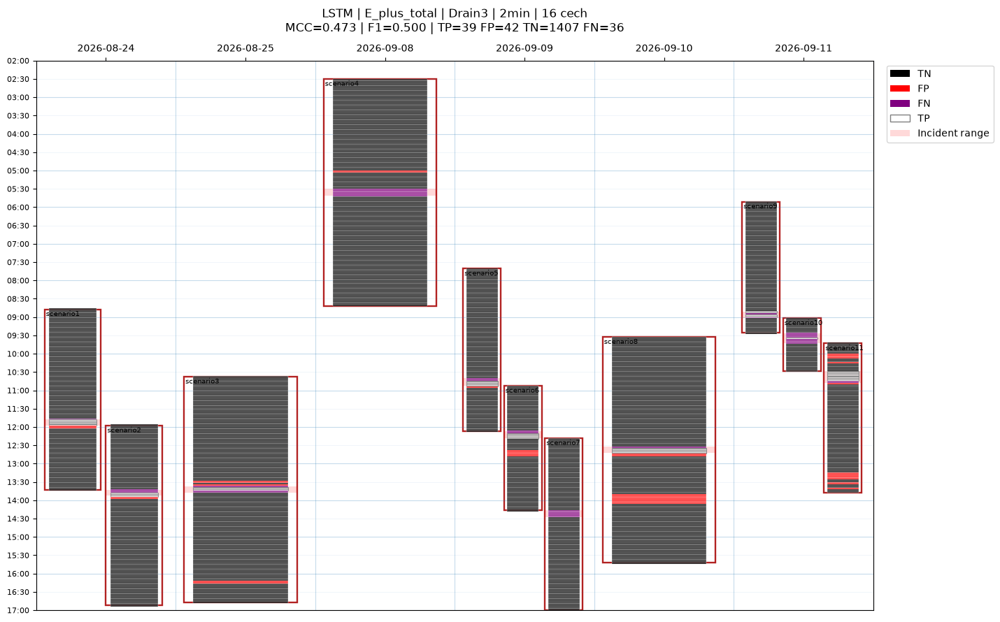


Zakończono: E_plus_total

WARIANT: F_plus_single
Liczba cech: 16
Clip: 3.0
   1/11  scenario1 | TP= 5 FP=  2 FN= 1 TN=141 | MCC=0.761
   2/11  scenario2 | TP= 3 FP=  8 FN= 3 TN=135 | MCC=0.334
   3/11  scenario3 | TP= 2 FP= 10 FN= 4 TN=170 | MCC=0.200
   4/11  scenario4 | TP= 0 FP=  1 FN= 6 TN=179 | MCC=-0.013
   5/11  scenario5 | TP= 5 FP=  1 FN= 2 TN=126 | MCC=0.760
   6/11  scenario6 | TP= 4 FP=  4 FN= 3 TN= 92 | MCC=0.498
   7/11  scenario7 | TP= 0 FP=  0 FN= 6 TN=149 | MCC=0.000
   8/11  scenario8 | TP= 5 FP= 10 FN= 1 TN=170 | MCC=0.505
   9/11  scenario9 | TP= 6 FP=  1 FN= 0 TN=102 | MCC=0.921
  10/11 scenario10 | TP= 0 FP=  0 FN= 9 TN= 35 | MCC=0.000
  11/11 scenario11 | TP= 9 FP= 55 FN= 1 TN= 58 | MCC=0.226

---------------------------------------------------------------------------
WYNIKI GLOBALNE: F_plus_single
---------------------------------------------------------------------------


,variant,features,MCC,F1,precision,recall,TP,FP,FN,TN
0,F_plus_single,16,0.3523,0.3786,0.2977,0.52,39,92,36,1357



WYNIKI DLA KAŻDEGO SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN,normal_median_probability
0,scenario1,0.7612,0.7692,5,2,1,141,0.0028
1,scenario2,0.3338,0.3529,3,8,3,135,0.0012
2,scenario3,0.1998,0.2222,2,10,4,170,0.0023
3,scenario4,-0.0134,0.0000,0,1,6,179,0.0016
4,scenario5,0.7600,0.7692,5,1,2,126,0.0009
5,scenario6,0.4981,0.5333,4,4,3,92,0.0019
6,scenario7,0.0000,0.0000,0,0,6,149,0.0016
7,scenario8,0.5047,0.4762,5,10,1,170,0.0018
8,scenario9,0.9213,0.9231,6,1,0,102,0.0019
9,scenario10,0.0000,0.0000,0,0,9,35,0.0020



KALENDARZ: F_plus_single


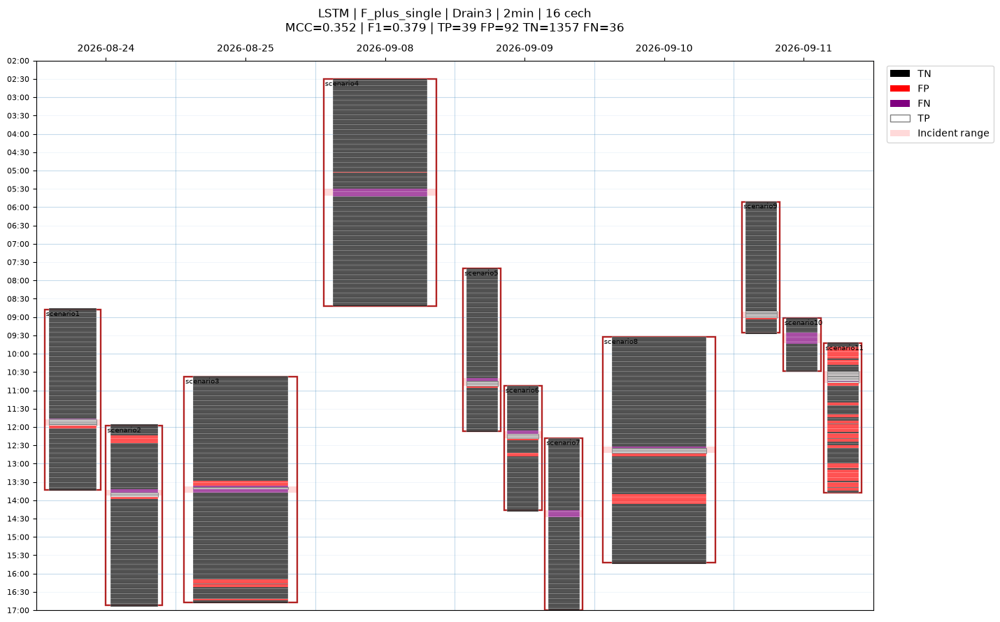


Zakończono: F_plus_single

WARIANT: G_without_z
Liczba cech: 11
Clip: 3.0
   1/11  scenario1 | TP= 4 FP=  1 FN= 2 TN=142 | MCC=0.720
   2/11  scenario2 | TP= 3 FP=  3 FN= 3 TN=140 | MCC=0.479
   3/11  scenario3 | TP= 3 FP= 13 FN= 3 TN=167 | MCC=0.270
   4/11  scenario4 | TP= 0 FP=  2 FN= 6 TN=178 | MCC=-0.019
   5/11  scenario5 | TP= 0 FP=  0 FN= 7 TN=127 | MCC=0.000
   6/11  scenario6 | TP= 3 FP=  0 FN= 4 TN= 96 | MCC=0.641
   7/11  scenario7 | TP= 0 FP=  0 FN= 6 TN=149 | MCC=0.000
   8/11  scenario8 | TP= 3 FP=  4 FN= 3 TN=176 | MCC=0.444
   9/11  scenario9 | TP= 5 FP=  0 FN= 1 TN=103 | MCC=0.908
  10/11 scenario10 | TP= 0 FP=  0 FN= 9 TN= 35 | MCC=0.000
  11/11 scenario11 | TP= 4 FP= 42 FN= 6 TN= 71 | MCC=0.016

---------------------------------------------------------------------------
WYNIKI GLOBALNE: G_without_z
---------------------------------------------------------------------------


,variant,features,MCC,F1,precision,recall,TP,FP,FN,TN
0,G_without_z,11,0.2647,0.303,0.2778,0.3333,25,65,50,1384



WYNIKI DLA KAŻDEGO SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN,normal_median_probability
0,scenario1,0.7201,0.7273,4,1,2,142,0.0016
1,scenario2,0.4790,0.5000,3,3,3,140,0.0014
2,scenario3,0.2696,0.2727,3,13,3,167,0.0022
3,scenario4,-0.0190,0.0000,0,2,6,178,0.0024
4,scenario5,0.0000,0.0000,0,0,7,127,0.0005
5,scenario6,0.6414,0.6000,3,0,4,96,0.0026
6,scenario7,0.0000,0.0000,0,0,6,149,0.0014
7,scenario8,0.4436,0.4615,3,4,3,176,0.0025
8,scenario9,0.9085,0.9091,5,0,1,103,0.0038
9,scenario10,0.0000,0.0000,0,0,9,35,0.0023



KALENDARZ: G_without_z


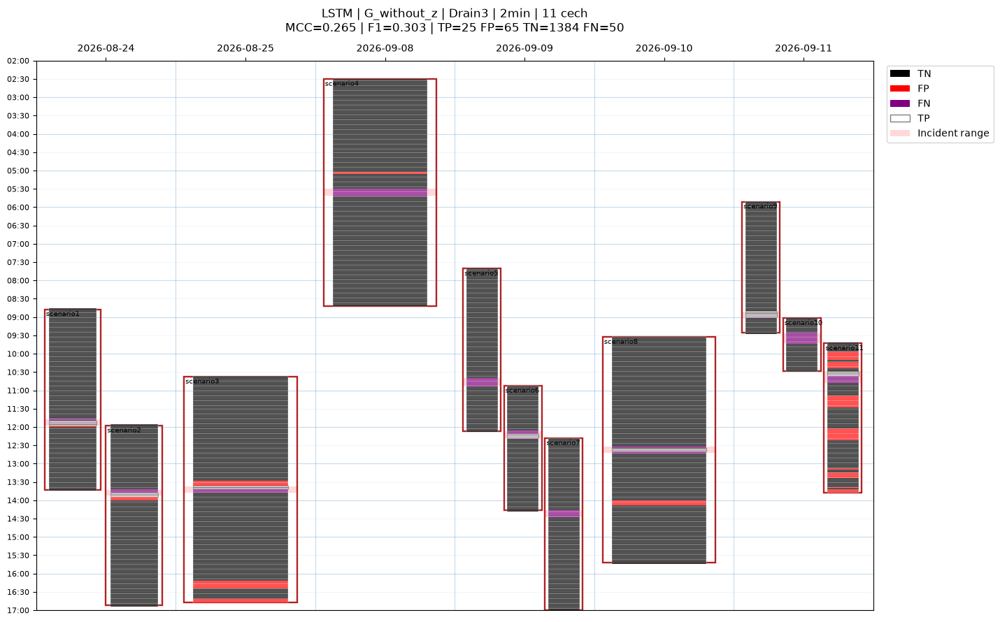


Zakończono: G_without_z

RANKING KOŃCOWY D–G


,variant,features,MCC,F1,precision,recall,TP,FP,FN,TN
0,E_plus_total,16,0.4735,0.5000,0.4815,0.5200,39,42,36,1407
1,F_plus_single,16,0.3523,0.3786,0.2977,0.5200,39,92,36,1357
2,D_plus_unique,16,0.3391,0.3568,0.2590,0.5733,43,123,32,1326
3,G_without_z,11,0.2647,0.3030,0.2778,0.3333,25,65,50,1384



SCENARIO11 — PORÓWNANIE D–G


,variant,MCC,F1,TP,FP,FN,TN,normal_median_probability
21,E_plus_total,0.4677,0.4848,8,15,2,98,0.0593
32,F_plus_single,0.2261,0.2432,9,55,1,58,0.4921
10,D_plus_unique,0.1232,0.1739,10,95,0,18,0.6966
43,G_without_z,0.0160,0.1429,4,42,6,71,0.4619



Wszystkie wyniki zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\lstm_feature_ablation_v2


In [76]:
import gc
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. WARIANTY
# ============================================================

BASE15 = [
    f for f in FEATURES18
    if f not in {
        "total_logs",
        "unique_templates",
        "single_occurrence_templates",
    }
]

ZSCORE_FEATURES = {
    "total_logs_z",
    "unique_templates_z",
    "single_occurrence_templates_z",
    "template_entropy_z",
}

ABLATION_VARIANTS = {
    "D_plus_unique": {
        "features": BASE15 + ["unique_templates"],
        "clip": 3.0,
    },
    "E_plus_total": {
        "features": BASE15 + ["total_logs"],
        "clip": 3.0,
    },
    "F_plus_single": {
        "features": BASE15 + [
            "single_occurrence_templates"
        ],
        "clip": 3.0,
    },
    "G_without_z": {
        "features": [
            f for f in BASE15
            if f not in ZSCORE_FEATURES
        ],
        "clip": 3.0,
    },
}

# Parametry identyczne jak w eksperymencie C.
EPOCHS_ABL = 25
BATCH_SIZE_ABL = 64
POS_WEIGHT_ABL = 2.0
HIDDEN_ABL = 24
STEPS_ABL = 15
SEED_ABL = 42

DEVICE_ABL = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Osobny folder — bez nadpisywania poprzednich wyników.
ABL_ROOT = (
    PREP_DIR / "nn_loso" / "lstm_feature_ablation_v2"
)
ABL_PRED = ABL_ROOT / "predictions"
ABL_REPORT = ABL_ROOT / "reports"

for folder in [ABL_PRED, ABL_REPORT]:
    folder.mkdir(parents=True, exist_ok=True)

print("Urządzenie:", DEVICE_ABL)
print("Folder:", ABL_ROOT)
print("Liczba treningów:", 4 * len(SCENARIOS))

for name, setup in ABLATION_VARIANTS.items():
    print(name, "| cechy:", len(setup["features"]))


# ============================================================
# 2. ORYGINALNE DANE — BEZ FILTROWANIA TEMPLATÓW
# ============================================================

frames = []

for case in SCENARIOS:

    path = (
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    )

    if not path.exists():
        raise FileNotFoundError(path)

    frame = joblib.load(path).copy()

    frame["case"] = case

    for col in ["timestamp", "bucket_end"]:
        frame[col] = pd.to_datetime(
            frame[col], utc=True
        )

    frames.append(
        frame.sort_values("timestamp")
    )

ABL_DATA = pd.concat(
    frames, ignore_index=True
)

ABL_Y = (
    ABL_DATA["label_primary"]
    .astype(int)
    .to_numpy()
)

ABL_CASES = (
    ABL_DATA["case"]
    .astype(str)
    .to_numpy()
)

print(
    "\nKubełki:", len(ABL_DATA),
    "| pozytywne:", int(ABL_Y.sum())
)


# ============================================================
# 3. KALENDARZ W ORYGINALNYM FORMACIE
# ============================================================

ABL_CALENDAR = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:
    ABL_CALENDAR[col] = (
        pd.to_datetime(ABL_CALENDAR[col], utc=True)
        .dt.tz_localize(None)
    )


def plot_ablation_calendar(
    data, predictions, variant, features_count, metrics
):

    buckets = data[
        [
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]
    ].copy()

    buckets["prediction"] = predictions.astype(int)

    actual = buckets["label_primary"].astype(int)
    predicted = buckets["prediction"]

    buckets["outcome"] = np.select(
        [
            (actual == 1) & (predicted == 1),
            (actual == 0) & (predicted == 1),
            (actual == 1) & (predicted == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    # Tak jak w oryginalnym kalendarzu.
    for col in ["timestamp", "bucket_end"]:
        buckets[col] = (
            pd.to_datetime(buckets[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"LSTM | {variant} | Drain3 | 2min"
        f" | {features_count} cech\n"
        f"MCC={metrics['MCC']:.3f}"
        f" | F1={metrics['F1']:.3f}"
        f" | TP={metrics['TP']}"
        f" FP={metrics['FP']}"
        f" TN={metrics['TN']}"
        f" FN={metrics['FN']}"
    )

    plot_calendar_with_buckets(
        calendar_segments=ABL_CALENDAR,
        bucket_df=buckets,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()


# ============================================================
# 4. TRENING LOSO + WYNIKI PO KAŻDYM WARIANCIE
# ============================================================

ABL_GLOBAL_ROWS = []
ABL_CASE_ROWS = []

for variant_name, setup in ABLATION_VARIANTS.items():

    columns = setup["features"]
    clip_value = setup["clip"]

    numeric = (
        ABL_DATA[columns]
        .apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    all_predictions = np.full(
        len(ABL_DATA), -1, dtype=int
    )

    all_probabilities = np.full(
        len(ABL_DATA), np.nan, dtype=np.float32
    )

    variant_case_rows = []

    print("\n" + "=" * 75)
    print("WARIANT:", variant_name)
    print("Liczba cech:", len(columns))
    print("Clip:", clip_value)
    print("=" * 75, flush=True)

    for fold, test_case in enumerate(
        SCENARIOS, start=1
    ):

        train_idx = np.flatnonzero(
            ABL_CASES != test_case
        )

        test_idx = np.flatnonzero(
            ABL_CASES == test_case
        )

        # Normalizacja wyłącznie na treningu.
        scaler = StandardScaler()
        scaler.fit(numeric[train_idx])

        scaled = scaler.transform(
            numeric
        ).astype(np.float32)

        if clip_value is not None:
            scaled = np.clip(
                scaled,
                -clip_value,
                clip_value,
            )

        sequences = make_sequences(
            ABL_DATA,
            scaled,
            steps=STEPS_ABL,
        )

        random.seed(SEED_ABL)
        np.random.seed(SEED_ABL)
        torch.manual_seed(SEED_ABL)

        if DEVICE_ABL.type == "cuda":
            torch.cuda.manual_seed_all(SEED_ABL)

        model = IncidentRNN(
            kind="LSTM",
            n_features=len(columns),
            hidden_size=HIDDEN_ABL,
        ).to(DEVICE_ABL)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001,
        )

        loss_fn = torch.nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                POS_WEIGHT_ABL,
                dtype=torch.float32,
                device=DEVICE_ABL,
            )
        )

        x_train = torch.from_numpy(
            sequences[train_idx]
        ).to(DEVICE_ABL)

        y_train = torch.from_numpy(
            ABL_Y[train_idx].astype(np.float32)
        ).to(DEVICE_ABL)

        # ------------------------
        # Uczenie
        # ------------------------

        for epoch in range(EPOCHS_ABL):

            model.train()

            order = torch.randperm(
                len(train_idx),
                device=DEVICE_ABL,
            )

            for batch in order.split(
                BATCH_SIZE_ABL
            ):

                optimizer.zero_grad(
                    set_to_none=True
                )

                logits = model(
                    x_train[batch]
                )

                loss = loss_fn(
                    logits,
                    y_train[batch],
                )

                loss.backward()
                optimizer.step()

        # ------------------------
        # Predykcja testowego foldu
        # ------------------------

        model.eval()

        with torch.no_grad():

            x_test = torch.from_numpy(
                sequences[test_idx]
            ).to(DEVICE_ABL)

            probabilities = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        all_predictions[test_idx] = predictions
        all_probabilities[test_idx] = probabilities

        metrics = nn_metrics(
            ABL_Y[test_idx],
            predictions,
        )

        normal_mask = ABL_Y[test_idx] == 0

        case_row = {
            "variant": variant_name,
            "case": test_case,
            **metrics,
            "normal_median_probability": (
                float(np.median(
                    probabilities[normal_mask]
                ))
                if normal_mask.any()
                else np.nan
            ),
        }

        variant_case_rows.append(case_row)
        ABL_CASE_ROWS.append(case_row)

        # Predykcje do późniejszych analiz.
        prediction_df = ABL_DATA.iloc[
            test_idx
        ][[
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]].copy()

        prediction_df["prediction"] = predictions
        prediction_df["probability"] = probabilities

        joblib.dump(
            {
                "data": prediction_df,
                "metrics": metrics,
                "variant": variant_name,
            },
            ABL_PRED / (
                f"{variant_name}__{test_case}.joblib"
            ),
            compress=3,
        )

        print(
            f"  {fold:2d}/11 {test_case:>10} | "
            f"TP={metrics['TP']:2d} "
            f"FP={metrics['FP']:3d} "
            f"FN={metrics['FN']:2d} "
            f"TN={metrics['TN']:3d} | "
            f"MCC={metrics['MCC']:.3f}",
            flush=True,
        )

        del (
            model,
            optimizer,
            x_train,
            y_train,
            x_test,
            sequences,
            scaled,
        )

        if DEVICE_ABL.type == "cuda":
            torch.cuda.empty_cache()

        gc.collect()

    # ========================================================
    # 5. WYNIKI LICZBOWE — NATYCHMIAST PO WARIANCIE
    # ========================================================

    if (all_predictions < 0).any():
        raise RuntimeError(
            f"{variant_name}: brak części predykcji."
        )

    global_metrics = nn_metrics(
        ABL_Y,
        all_predictions,
    )

    global_row = {
        "variant": variant_name,
        "features": len(columns),
        **global_metrics,
    }

    ABL_GLOBAL_ROWS.append(global_row)

    print("\n" + "-" * 75)
    print("WYNIKI GLOBALNE:", variant_name)
    print("-" * 75)

    display(
        pd.DataFrame([global_row])[
            [
                "variant",
                "features",
                "MCC",
                "F1",
                "precision",
                "recall",
                "TP",
                "FP",
                "FN",
                "TN",
            ]
        ].round(4)
    )

    print("\nWYNIKI DLA KAŻDEGO SCENARIUSZA:")

    per_case = pd.DataFrame(
        variant_case_rows
    )

    display(
        per_case[
            [
                "case",
                "MCC",
                "F1",
                "TP",
                "FP",
                "FN",
                "TN",
                "normal_median_probability",
            ]
        ].round(4)
    )

    # Zapis raportów po KAŻDYM wariancie.
    pd.DataFrame(ABL_GLOBAL_ROWS).to_csv(
        ABL_REPORT / "overall_results.csv",
        index=False,
    )

    pd.DataFrame(ABL_CASE_ROWS).to_csv(
        ABL_REPORT / "scenario_results.csv",
        index=False,
    )

    # ========================================================
    # 6. KALENDARZ — NATYCHMIAST PO WYNIKACH LICZBOWYCH
    # ========================================================

    print(
        f"\nKALENDARZ: {variant_name}",
        flush=True,
    )

    plot_ablation_calendar(
        data=ABL_DATA,
        predictions=all_predictions,
        variant=variant_name,
        features_count=len(columns),
        metrics=global_metrics,
    )

    print(
        f"\nZakończono: {variant_name}",
        flush=True,
    )

    del numeric, all_predictions, all_probabilities
    gc.collect()


# ============================================================
# 7. KOŃCOWE PORÓWNANIE
# ============================================================

ABL_RESULTS = (
    pd.DataFrame(ABL_GLOBAL_ROWS)
    .sort_values(
        "MCC", ascending=False
    )
    .reset_index(drop=True)
)

ABL_CASE_RESULTS = pd.DataFrame(
    ABL_CASE_ROWS
)

print("\n" + "=" * 75)
print("RANKING KOŃCOWY D–G")
print("=" * 75)

display(
    ABL_RESULTS[
        [
            "variant",
            "features",
            "MCC",
            "F1",
            "precision",
            "recall",
            "TP",
            "FP",
            "FN",
            "TN",
        ]
    ].round(4)
)

print("\nSCENARIO11 — PORÓWNANIE D–G")

display(
    ABL_CASE_RESULTS[
        ABL_CASE_RESULTS["case"] == "scenario11"
    ][
        [
            "variant",
            "MCC",
            "F1",
            "TP",
            "FP",
            "FN",
            "TN",
            "normal_median_probability",
        ]
    ]
    .sort_values("MCC", ascending=False)
    .round(4)
)

print("\nWszystkie wyniki zapisano w:", ABL_ROOT)

FP w C: 1
FP w E: 15
Dodatkowe FP E względem C: 15

FAŁSZYWE ALARMY E — FAZA 10 MIN:


,minute_mod_10,FP
0,0,4
1,2,3
2,4,4
3,6,2
4,8,2



DODATKOWE FAŁSZYWE ALARMY E:


C:\Users\kzieba\AppData\Local\Temp\ipykernel_12104\2368862761.py:91: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,timestamp,prob_C,prob_E,phase_10min
9,2026-09-11 10:00:00+00:00,0.0026,0.7533,0
10,2026-09-11 10:02:00+00:00,0.0025,0.6986,2
11,2026-09-11 10:04:00+00:00,0.0031,0.6386,4
12,2026-09-11 10:06:00+00:00,0.0033,0.5219,6
16,2026-09-11 10:14:00+00:00,0.0081,0.5143,4
33,2026-09-11 10:48:00+00:00,0.0669,0.6142,8
106,2026-09-11 13:14:00+00:00,0.0149,0.5615,4
107,2026-09-11 13:16:00+00:00,0.0140,0.6088,6
108,2026-09-11 13:18:00+00:00,0.0079,0.5049,8
109,2026-09-11 13:20:00+00:00,0.0690,0.8190,0


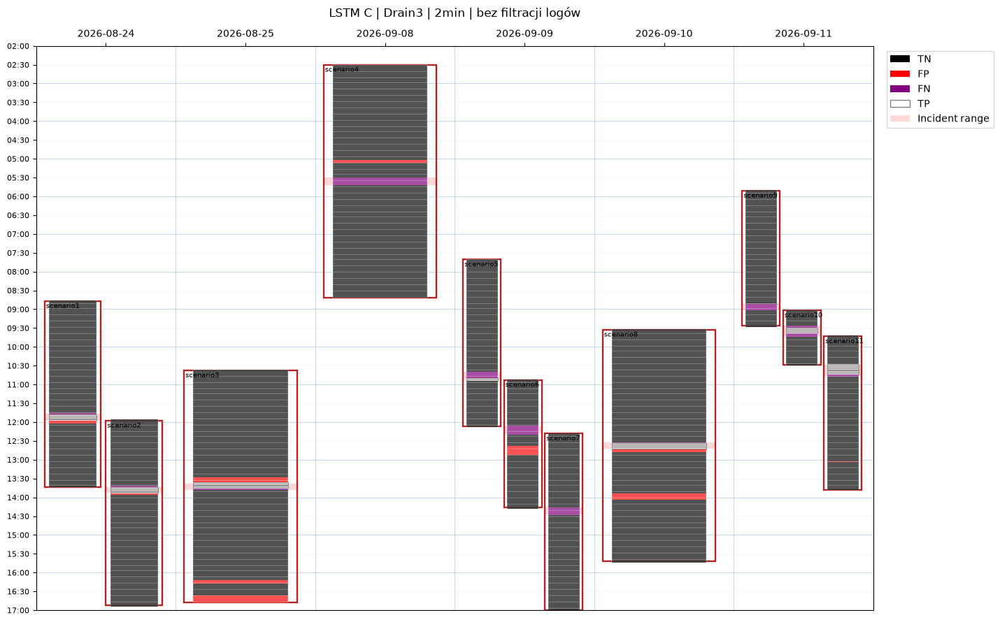

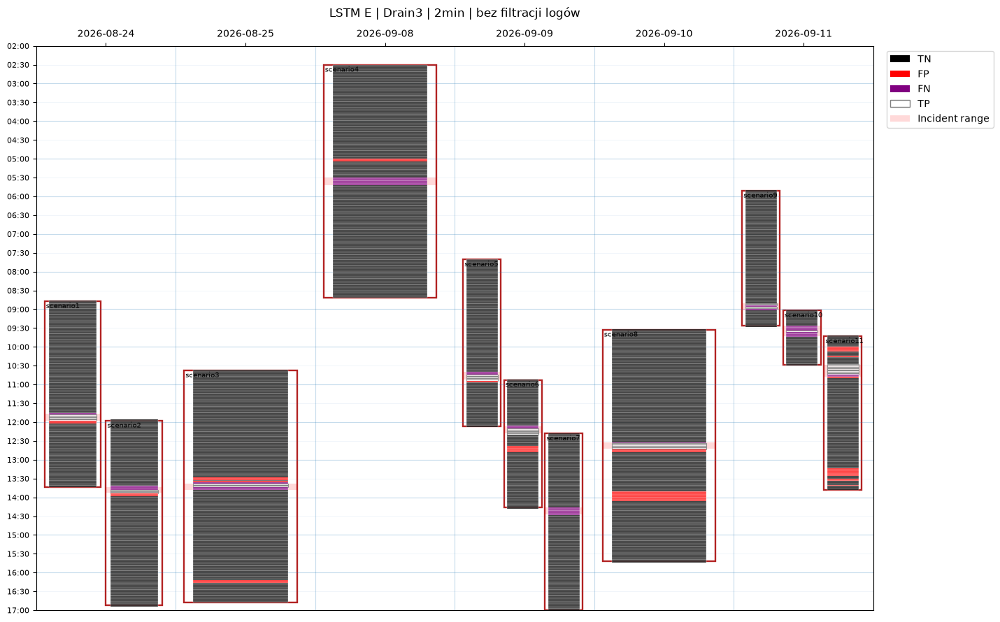

In [77]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CASE = "scenario11"

paths = {
    "C": (
        PREP_DIR / "nn_loso" / "lstm_shift_ablation"
        / "predictions" / f"C_weight2_15_clip3__{CASE}.joblib"
    ),
    "E": (
        PREP_DIR / "nn_loso" / "lstm_feature_ablation_v2"
        / "predictions" / f"E_plus_total__{CASE}.joblib"
    ),
}

frames = {}

for name, path in paths.items():
    saved = joblib.load(path)
    frame = saved["data"].copy()

    frame["timestamp"] = pd.to_datetime(
        frame["timestamp"], utc=True
    )
    frame["bucket_end"] = pd.to_datetime(
        frame["bucket_end"], utc=True
    )

    frame = frame.sort_values("timestamp").reset_index(drop=True)
    frames[name] = frame

compare = frames["C"][
    ["timestamp", "label_primary", "prediction", "probability"]
].rename(columns={
    "prediction": "pred_C",
    "probability": "prob_C",
})

compare = compare.merge(
    frames["E"][
        ["timestamp", "label_primary", "prediction", "probability"]
    ].rename(columns={
        "label_primary": "label_E",
        "prediction": "pred_E",
        "probability": "prob_E",
    }),
    on="timestamp",
    validate="one_to_one",
)

assert (
    compare["label_primary"] == compare["label_E"]
).all(), "C i E mają różne etykiety!"

compare["phase_10min"] = compare["timestamp"].dt.minute % 10

# Tylko rzeczywiste fałszywe alarmy E.
fp_E = compare[
    (compare["label_primary"] == 0)
    & (compare["pred_E"] == 1)
].copy()

# Fałszywe alarmy E, których nie ma w C.
extra_fp_E = fp_E[
    fp_E["pred_C"] == 0
].copy()

print("FP w C:", int(
    ((compare["label_primary"] == 0) &
     (compare["pred_C"] == 1)).sum()
))
print("FP w E:", len(fp_E))
print("Dodatkowe FP E względem C:", len(extra_fp_E))

print("\nFAŁSZYWE ALARMY E — FAZA 10 MIN:")
display(
    fp_E["phase_10min"]
    .value_counts()
    .sort_index()
    .rename_axis("minute_mod_10")
    .reset_index(name="FP")
)

print("\nDODATKOWE FAŁSZYWE ALARMY E:")
display(
    extra_fp_E[
        ["timestamp", "prob_C", "prob_E", "phase_10min"]
    ].round(4)
)

# Oryginalne kalendarze dla porównania.
calendar = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day", "scenario_start", "scenario_end",
    "incident_start", "incident_end"
]:
    calendar[col] = (
        pd.to_datetime(calendar[col], utc=True)
        .dt.tz_localize(None)
    )

for name in ["C", "E"]:

    # Ładujemy wszystkie scenariusze dla kalendarza.
    all_frames = []

    for case in SCENARIOS:
        path = paths[name].parent / (
            f"{'C_weight2_15_clip3' if name == 'C' else 'E_plus_total'}"
            f"__{case}.joblib"
        )

        df = joblib.load(path)["data"].copy()
        df["case"] = case
        all_frames.append(df)

    buckets = pd.concat(all_frames, ignore_index=True)

    actual = buckets["label_primary"].astype(int)
    predicted = buckets["prediction"].astype(int)

    buckets["outcome"] = np.select(
        [
            (actual == 1) & (predicted == 1),
            (actual == 0) & (predicted == 1),
            (actual == 1) & (predicted == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    for col in ["timestamp", "bucket_end"]:
        buckets[col] = (
            pd.to_datetime(buckets[col], utc=True)
            .dt.tz_localize(None)
        )

    plot_calendar_with_buckets(
        calendar_segments=calendar,
        bucket_df=buckets,
        title=f"LSTM {name} | Drain3 | 2min | bez filtracji logów",
        start_hour=2,
        end_hour=17,
    )

    plt.show()

Kubełki: 1524
Pozytywne: 75

WARIANT: baseline_050
ON=0.5, OFF=0.5, potwierdzenie=1 kubełek/kubełki

WYNIKI GLOBALNE:


,variant,MCC,F1,precision,recall,TP,FP,FN,TN
0,baseline_050,0.4651,0.4895,0.5147,0.4667,35,33,40,1416



WYNIKI WEDŁUG SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,0.7612,0.7692,5,2,1,141
1,scenario2,0.8263,0.8333,5,1,1,142
2,scenario3,0.4549,0.4167,5,13,1,167
3,scenario4,-0.0190,0.0000,0,2,6,178
4,scenario5,0.5243,0.4444,2,0,5,127
5,scenario6,-0.0729,0.0000,0,7,7,89
6,scenario7,0.0000,0.0000,0,0,6,149
7,scenario8,0.5714,0.5556,5,7,1,173
8,scenario9,0.3987,0.2857,1,0,5,103
9,scenario10,0.6236,0.6154,4,0,5,35


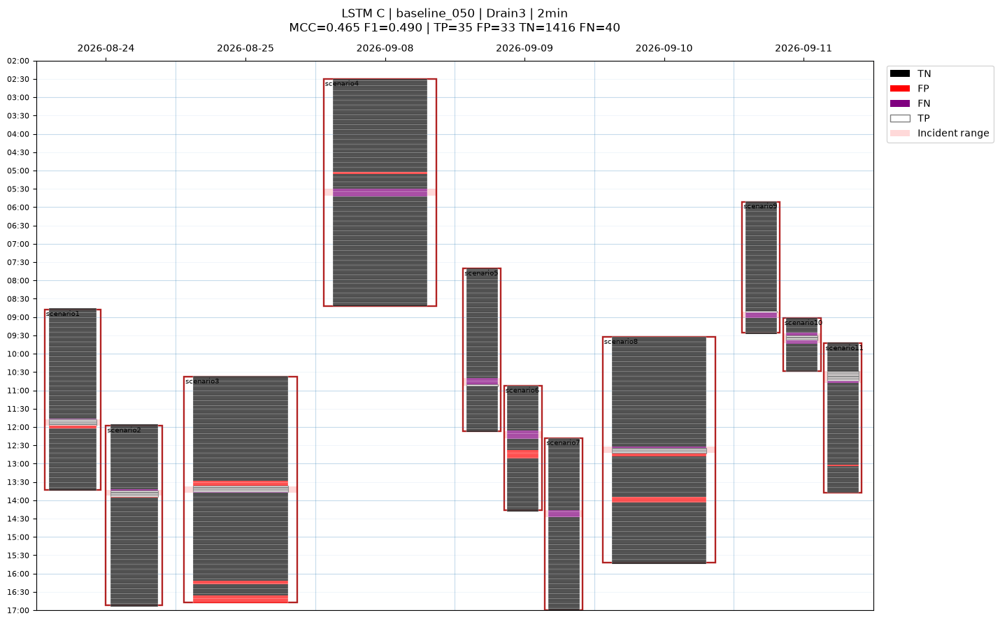

Zakończono: baseline_050

WARIANT: threshold_030
ON=0.3, OFF=0.3, potwierdzenie=1 kubełek/kubełki

WYNIKI GLOBALNE:


,variant,MCC,F1,precision,recall,TP,FP,FN,TN
0,threshold_030,0.4667,0.4937,0.4699,0.52,39,44,36,1405



WYNIKI WEDŁUG SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN
11,scenario1,0.7085,0.7143,5,3,1,140
12,scenario2,0.7612,0.7692,5,2,1,141
13,scenario3,0.5118,0.4444,6,15,0,165
14,scenario4,-0.0234,0.0000,0,3,6,177
15,scenario5,0.5501,0.5455,3,1,4,126
16,scenario6,-0.0784,0.0000,0,8,7,88
17,scenario7,0.0000,0.0000,0,0,6,149
18,scenario8,0.5246,0.5000,5,9,1,171
19,scenario9,0.5665,0.5000,2,0,4,103
20,scenario10,0.7061,0.7143,5,0,4,35


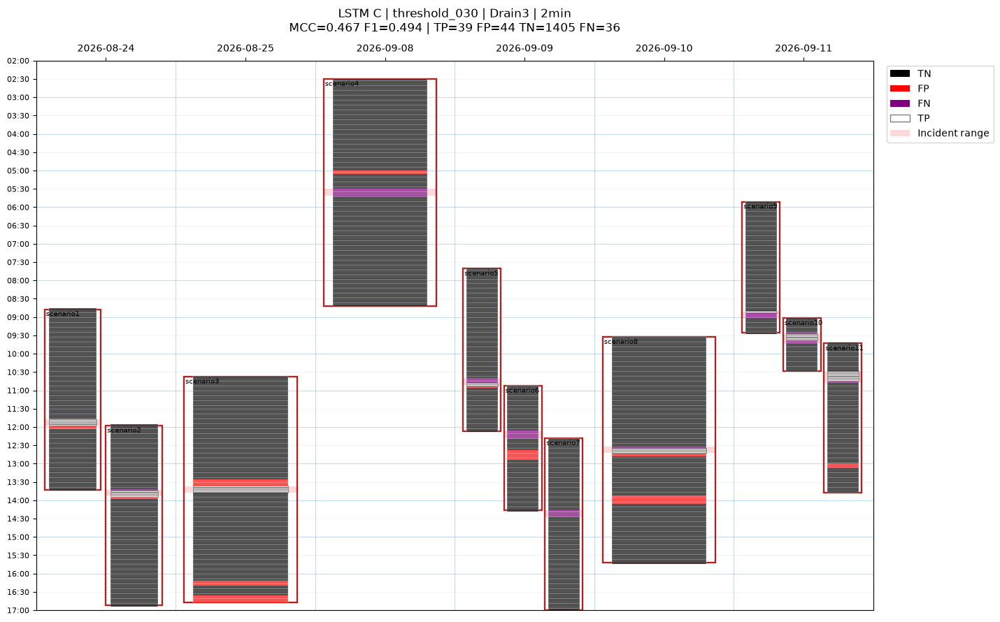

Zakończono: threshold_030

WARIANT: hysteresis_030_015
ON=0.3, OFF=0.15, potwierdzenie=1 kubełek/kubełki

WYNIKI GLOBALNE:


,variant,MCC,F1,precision,recall,TP,FP,FN,TN
0,hysteresis_030_015,0.5027,0.5269,0.4783,0.5867,44,48,31,1401



WYNIKI WEDŁUG SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN
22,scenario1,0.7085,0.7143,5,3,1,140
23,scenario2,0.7612,0.7692,5,2,1,141
24,scenario3,0.4985,0.4286,6,16,0,164
25,scenario4,-0.0234,0.0000,0,3,6,177
26,scenario5,0.5501,0.5455,3,1,4,126
27,scenario6,-0.0836,0.0000,0,9,7,87
28,scenario7,0.0000,0.0000,0,0,6,149
29,scenario8,0.5047,0.4762,5,10,1,170
30,scenario9,0.9085,0.9091,5,0,1,103
31,scenario10,0.7836,0.8000,6,0,3,35


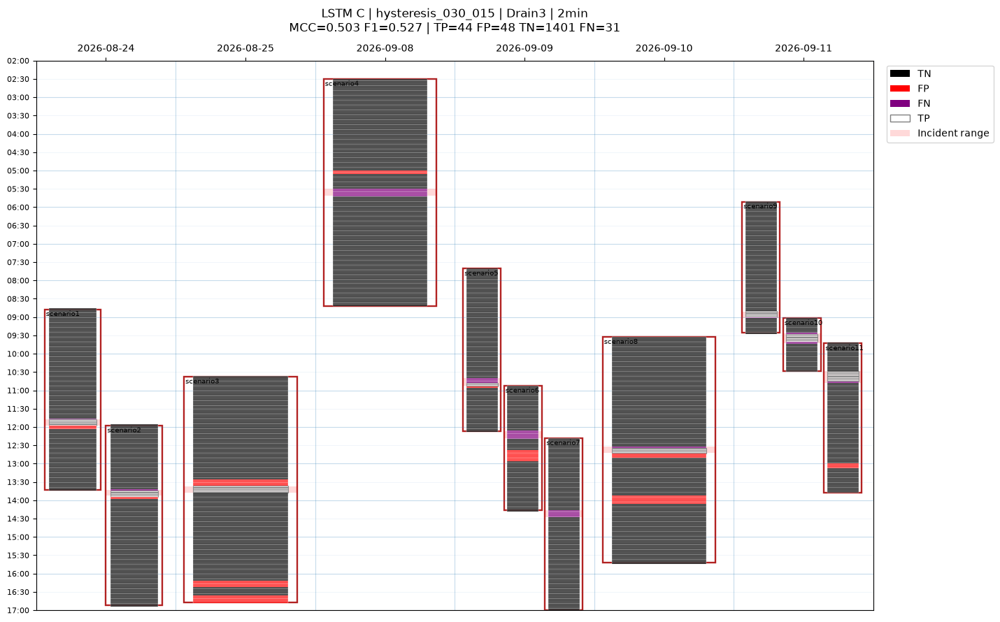

Zakończono: hysteresis_030_015

WARIANT: hysteresis_confirm2_030_015
ON=0.3, OFF=0.15, potwierdzenie=2 kubełek/kubełki

WYNIKI GLOBALNE:


,variant,MCC,F1,precision,recall,TP,FP,FN,TN
0,hysteresis_confirm2_030_015,0.4565,0.4837,0.4744,0.4933,37,41,38,1408



WYNIKI WEDŁUG SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN
33,scenario1,0.5999,0.6154,4,3,2,140
34,scenario2,0.6527,0.6667,4,2,2,141
35,scenario3,0.5413,0.4800,6,13,0,167
36,scenario4,-0.0190,0.0000,0,2,6,178
37,scenario5,0.4179,0.4000,2,1,5,126
38,scenario6,-0.0784,0.0000,0,8,7,88
39,scenario7,0.0000,0.0000,0,0,6,149
40,scenario8,0.4273,0.4211,4,9,2,171
41,scenario9,0.8087,0.8000,4,0,2,103
42,scenario10,0.7061,0.7143,5,0,4,35


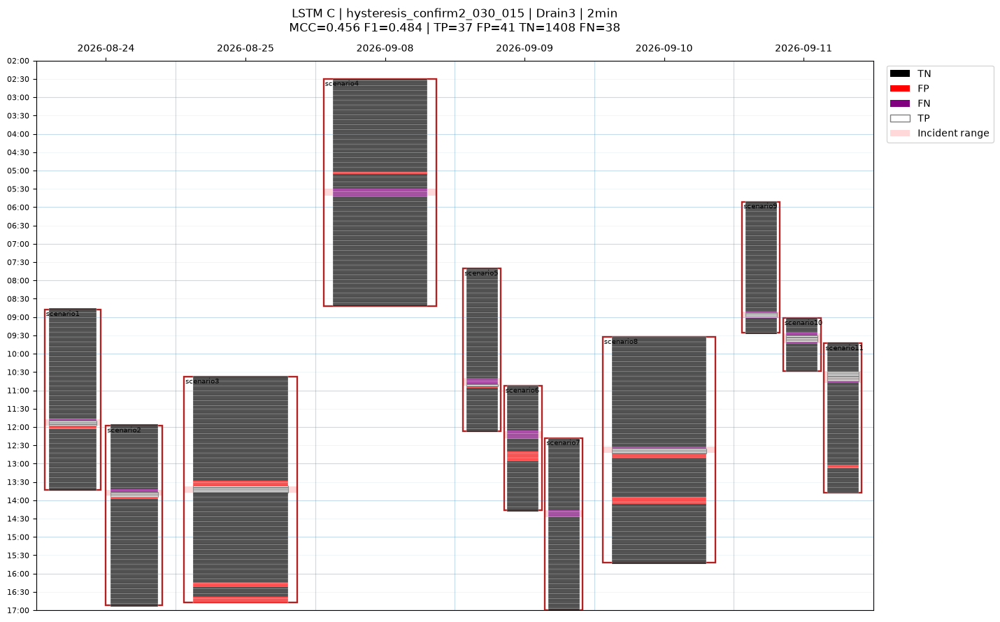

Zakończono: hysteresis_confirm2_030_015

WARIANT: hysteresis_confirm2_040_020
ON=0.4, OFF=0.2, potwierdzenie=2 kubełek/kubełki

WYNIKI GLOBALNE:


,variant,MCC,F1,precision,recall,TP,FP,FN,TN
0,hysteresis_confirm2_040_020,0.4283,0.4552,0.4714,0.44,33,37,42,1412



WYNIKI WEDŁUG SCENARIUSZA:


,case,MCC,F1,TP,FP,FN,TN
44,scenario1,0.5999,0.6154,4,3,2,140
45,scenario2,0.6527,0.6667,4,2,2,141
46,scenario3,0.5413,0.4800,6,13,0,167
47,scenario4,-0.0134,0.0000,0,1,6,179
48,scenario5,0.4179,0.4000,2,1,5,126
49,scenario6,-0.0729,0.0000,0,7,7,89
50,scenario7,0.0000,0.0000,0,0,6,149
51,scenario8,0.4475,0.4444,4,8,2,172
52,scenario9,0.0000,0.0000,0,0,6,103
53,scenario10,0.7061,0.7143,5,0,4,35


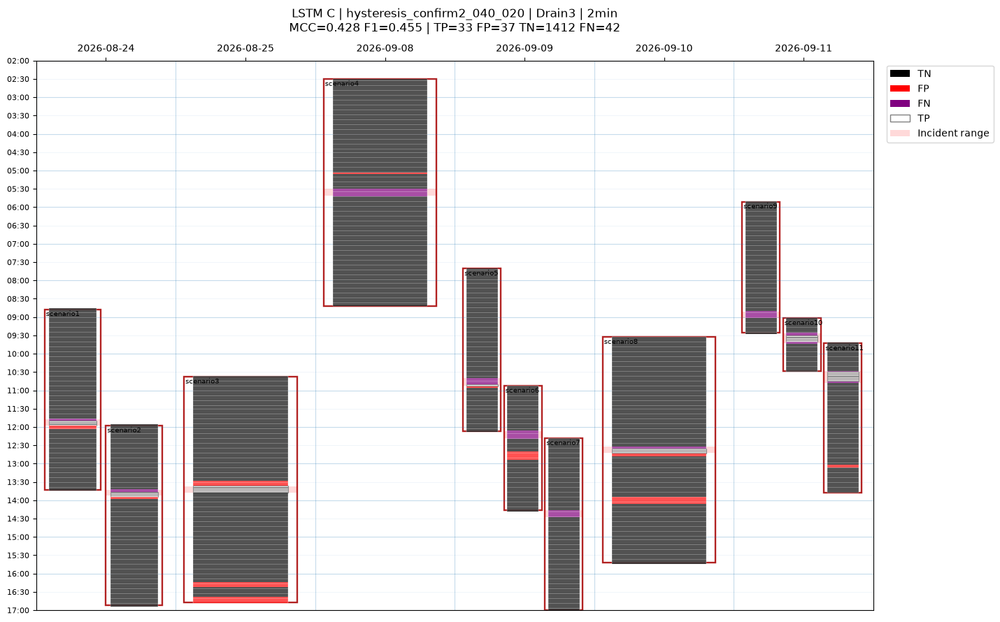

Zakończono: hysteresis_confirm2_040_020

=== RANKING GLOBALNY ===


,variant,threshold_on,threshold_off,confirmation,MCC,F1,precision,recall,TP,FP,FN,TN
0,hysteresis_030_015,0.3,0.15,1,0.5027,0.5269,0.4783,0.5867,44,48,31,1401
1,threshold_030,0.3,0.30,1,0.4667,0.4937,0.4699,0.5200,39,44,36,1405
2,baseline_050,0.5,0.50,1,0.4651,0.4895,0.5147,0.4667,35,33,40,1416
3,hysteresis_confirm2_030_015,0.3,0.15,2,0.4565,0.4837,0.4744,0.4933,37,41,38,1408
4,hysteresis_confirm2_040_020,0.4,0.20,2,0.4283,0.4552,0.4714,0.4400,33,37,42,1412



=== SCENARIO11 ===


,variant,case,MCC,F1,precision,recall,TP,FP,FN,TN
10,baseline_050,scenario11,0.8303,0.8421,0.8889,0.8,8,1,2,112
54,hysteresis_confirm2_040_020,scenario11,0.7823,0.8000,0.8000,0.8,8,2,2,111
32,hysteresis_030_015,scenario11,0.7686,0.7826,0.6923,0.9,9,4,1,109
21,threshold_030,scenario11,0.7407,0.7619,0.7273,0.8,8,3,2,110
43,hysteresis_confirm2_030_015,scenario11,0.7407,0.7619,0.7273,0.8,8,3,2,110



Wyniki zapisane w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\C_threshold_hysteresis


In [79]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

# ============================================================
# 1. KONFIGURACJA
# ============================================================

SOURCE_DIR = (
    PREP_DIR
    / "nn_loso"
    / "lstm_shift_ablation"
    / "predictions"
)

SOURCE_VARIANT = "C_weight2_15_clip3"

POST_DIR = (
    PREP_DIR
    / "nn_loso"
    / "C_threshold_hysteresis"
)

POST_DIR.mkdir(parents=True, exist_ok=True)

SETTINGS = {
    "baseline_050": {
        "on": 0.50,
        "off": 0.50,
        "confirm": 1,
    },
    "threshold_030": {
        "on": 0.30,
        "off": 0.30,
        "confirm": 1,
    },
    "hysteresis_030_015": {
        "on": 0.30,
        "off": 0.15,
        "confirm": 1,
    },
    "hysteresis_confirm2_030_015": {
        "on": 0.30,
        "off": 0.15,
        "confirm": 2,
    },
    "hysteresis_confirm2_040_020": {
        "on": 0.40,
        "off": 0.20,
        "confirm": 2,
    },
}

# ============================================================
# 2. WCZYTANIE ORYGINALNYCH PREDYKCJI LOSO
# ============================================================

frames = []

for case in SCENARIOS:

    path = SOURCE_DIR / f"{SOURCE_VARIANT}__{case}.joblib"

    if not path.exists():
        raise FileNotFoundError(path)

    frame = joblib.load(path)["data"].copy()

    frame["case"] = case

    for col in ["timestamp", "bucket_end"]:
        frame[col] = pd.to_datetime(
            frame[col], utc=True
        )

    if "probability" not in frame.columns:
        raise ValueError(
            f"{case}: brak kolumny probability"
        )

    frames.append(frame)

PROB_DATA = (
    pd.concat(frames, ignore_index=True)
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
)

if PROB_DATA.duplicated(["case", "timestamp"]).any():
    raise ValueError("Zduplikowane kubełki")

if not np.isfinite(
    PROB_DATA["probability"].to_numpy(dtype=float)
).all():
    raise ValueError("Niepoprawne prawdopodobieństwa")

print("Kubełki:", len(PROB_DATA))
print("Pozytywne:", int(PROB_DATA["label_primary"].sum()))

# ============================================================
# 3. PRZYCZYNOWA HISTEREZA
# ============================================================

def apply_hysteresis(
    probabilities,
    timestamps,
    threshold_on,
    threshold_off,
    confirmation=1,
    window="2min",
):
    if not (0 <= threshold_off <= threshold_on <= 1):
        raise ValueError("Wymagane: 0 <= off <= on <= 1")

    if confirmation < 1:
        raise ValueError("confirmation musi być >= 1")

    probs = np.asarray(probabilities, dtype=float)
    times = pd.DatetimeIndex(pd.to_datetime(timestamps, utc=True))

    result = np.zeros(len(probs), dtype=int)

    active = False
    consecutive = 0

    expected_gap = pd.Timedelta(window)

    for i, p in enumerate(probs):

        # Reset przy luce czasowej — nie łączymy
        # nieciągłych fragmentów w jeden alarm.
        if i > 0 and (
            times[i] - times[i - 1] != expected_gap
        ):
            active = False
            consecutive = 0

        if active:
            if p < threshold_off:
                active = False
                consecutive = 0

        else:
            if p >= threshold_on:
                consecutive += 1
            else:
                consecutive = 0

            if consecutive >= confirmation:
                active = True

        # Nie zmieniamy wstecz wcześniejszych kubełków.
        result[i] = int(active)

    return result


def calculate_metrics(actual, predicted):

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    return {
        "MCC": matthews_corrcoef(actual, predicted),
        "F1": f1_score(actual, predicted, zero_division=0),
        "precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }

# ============================================================
# 4. PRZYGOTOWANIE ORYGINALNEGO KALENDARZA
# ============================================================

calendar = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:
    calendar[col] = (
        pd.to_datetime(calendar[col], utc=True)
        .dt.tz_localize(None)
    )

# ============================================================
# 5. EKSPERYMENT — METRYKI + KALENDARZ PO KAŻDYM WARIANCIE
# ============================================================

global_rows = []
case_rows = []

for variant, config in SETTINGS.items():

    print("\n" + "=" * 75)
    print("WARIANT:", variant)
    print(
        f"ON={config['on']}, "
        f"OFF={config['off']}, "
        f"potwierdzenie={config['confirm']} kubełek/kubełki"
    )

    result_frames = []

    for case in SCENARIOS:

        df = (
            PROB_DATA[PROB_DATA["case"] == case]
            .sort_values("timestamp")
            .copy()
        )

        df["prediction"] = apply_hysteresis(
            probabilities=df["probability"].to_numpy(),
            timestamps=df["timestamp"],
            threshold_on=config["on"],
            threshold_off=config["off"],
            confirmation=config["confirm"],
            window="2min",
        )

        metrics = calculate_metrics(
            df["label_primary"].astype(int),
            df["prediction"],
        )

        case_rows.append({
            "variant": variant,
            "case": case,
            **metrics,
        })

        result_frames.append(df)

    result = pd.concat(
        result_frames, ignore_index=True
    )

    overall = calculate_metrics(
        result["label_primary"].astype(int),
        result["prediction"],
    )

    global_rows.append({
        "variant": variant,
        "threshold_on": config["on"],
        "threshold_off": config["off"],
        "confirmation": config["confirm"],
        **overall,
    })

    # --------------------------------------------------------
    # METRYKI GLOBALNE
    # --------------------------------------------------------

    print("\nWYNIKI GLOBALNE:")

    display(
        pd.DataFrame([global_rows[-1]])[
            [
                "variant",
                "MCC", "F1", "precision", "recall",
                "TP", "FP", "FN", "TN",
            ]
        ].round(4)
    )

    # --------------------------------------------------------
    # METRYKI SCENARIUSZY
    # --------------------------------------------------------

    print("\nWYNIKI WEDŁUG SCENARIUSZA:")

    case_table = pd.DataFrame(case_rows)
    case_table = case_table[
        case_table["variant"] == variant
    ]

    display(
        case_table[
            ["case", "MCC", "F1", "TP", "FP", "FN", "TN"]
        ].round(4)
    )

    # --------------------------------------------------------
    # KALENDARZ
    # --------------------------------------------------------

    result["outcome"] = np.select(
        [
            (result["label_primary"] == 1)
            & (result["prediction"] == 1),

            (result["label_primary"] == 0)
            & (result["prediction"] == 1),

            (result["label_primary"] == 1)
            & (result["prediction"] == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    plot_df = result.copy()

    for col in ["timestamp", "bucket_end"]:
        plot_df[col] = (
            pd.to_datetime(plot_df[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"LSTM C | {variant} | Drain3 | 2min\n"
        f"MCC={overall['MCC']:.3f} "
        f"F1={overall['F1']:.3f} | "
        f"TP={overall['TP']} "
        f"FP={overall['FP']} "
        f"TN={overall['TN']} "
        f"FN={overall['FN']}"
    )

    plot_calendar_with_buckets(
        calendar_segments=calendar,
        bucket_df=plot_df,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

    # --------------------------------------------------------
    # ZAPIS — BEZ NADPISYWANIA ORYGINALNEGO MODELU
    # --------------------------------------------------------

    joblib.dump(
        result,
        POST_DIR / f"{variant}_predictions.joblib",
        compress=3,
    )

    pd.DataFrame(global_rows).to_csv(
        POST_DIR / "global_results.csv",
        index=False,
    )

    pd.DataFrame(case_rows).to_csv(
        POST_DIR / "scenario_results.csv",
        index=False,
    )

    print("Zakończono:", variant, flush=True)

# ============================================================
# 6. KOŃCOWY RANKING
# ============================================================

HYSTERESIS_RESULTS = (
    pd.DataFrame(global_rows)
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

HYSTERESIS_CASE_RESULTS = pd.DataFrame(case_rows)

print("\n=== RANKING GLOBALNY ===")

display(HYSTERESIS_RESULTS.round(4))

print("\n=== SCENARIO11 ===")

display(
    HYSTERESIS_CASE_RESULTS[
        HYSTERESIS_CASE_RESULTS["case"] == "scenario11"
    ].sort_values("MCC", ascending=False).round(4)
)

print("\nWyniki zapisane w:", POST_DIR)

In [80]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display

C_PRED_DIR = (
    PREP_DIR / "nn_loso"
    / "lstm_shift_ablation"
    / "predictions"
)

diagnostics = []

for case in SCENARIOS:
    path = C_PRED_DIR / f"C_weight2_15_clip3__{case}.joblib"
    df = joblib.load(path)["data"]

    incident = df.loc[
        df["label_primary"].astype(int) == 1,
        "probability"
    ].to_numpy(dtype=float)

    normal = df.loc[
        df["label_primary"].astype(int) == 0,
        "probability"
    ].to_numpy(dtype=float)

    diagnostics.append({
        "case": case,
        "incident_buckets": len(incident),
        "max_p_incident": np.max(incident),
        "median_p_incident": np.median(incident),
        "incident_p_ge_0.1": int((incident >= 0.1).sum()),
        "incident_p_ge_0.3": int((incident >= 0.3).sum()),
        "incident_p_ge_0.5": int((incident >= 0.5).sum()),
        "median_p_normal": np.median(normal),
    })

FN_DIAGNOSTICS = pd.DataFrame(diagnostics)

display(FN_DIAGNOSTICS.round(4))

,case,incident_buckets,max_p_incident,median_p_incident,incident_p_ge_0.1,incident_p_ge_0.3,incident_p_ge_0.5,median_p_normal
0,scenario1,6,0.8587,0.7463,6,5,5,0.0035
1,scenario2,6,0.8096,0.7546,6,5,5,0.0023
2,scenario3,6,0.8377,0.7003,6,6,5,0.0027
3,scenario4,6,0.0066,0.0034,0,0,0,0.0026
4,scenario5,7,0.6050,0.2179,4,3,2,0.0011
5,scenario6,7,0.2295,0.1095,4,0,0,0.0026
6,scenario7,6,0.0116,0.0026,0,0,0,0.0017
7,scenario8,6,0.9260,0.8756,6,5,5,0.0023
8,scenario9,6,0.5838,0.1939,5,2,1,0.0021
9,scenario10,9,0.8120,0.4502,7,5,4,0.0040


Urządzenie: cpu
Liczba treningów: 22

WARIANT: C_posweight_4
   1/11  scenario1 | TP= 5 FN= 1 FP=  2 MCC=0.761
   2/11  scenario2 | TP= 5 FN= 1 FP=  3 MCC=0.708
   3/11  scenario3 | TP= 5 FN= 1 FP= 16 MCC=0.416
   4/11  scenario4 | TP= 0 FN= 6 FP=  1 MCC=-0.013
   5/11  scenario5 | TP= 2 FN= 5 FP=  0 MCC=0.524
   6/11  scenario6 | TP= 0 FN= 7 FP=  7 MCC=-0.073
   7/11  scenario7 | TP= 0 FN= 6 FP=  0 MCC=0.000
   8/11  scenario8 | TP= 4 FN= 2 FP=  8 MCC=0.447
   9/11  scenario9 | TP= 2 FN= 4 FP=  0 MCC=0.566
  10/11 scenario10 | TP= 7 FN= 2 FP=  1 MCC=0.784
  11/11 scenario11 | TP= 7 FN= 3 FP=  0 MCC=0.826

WYNIKI GLOBALNE — C_posweight_4


,variant,pos_weight,detected_scenarios,TP,FP,FN,TN,precision,recall,F1,MCC
0,C_posweight_4,4.0,8,37,38,38,1411,0.4933,0.4933,0.4933,0.4671



WYNIKI SCENARIUSZY:


,case,TP,FN,FP,TN,F1,MCC,incident_detected
0,scenario1,5,1,2,141,0.7692,0.7612,1
1,scenario2,5,1,3,140,0.7143,0.7085,1
2,scenario3,5,1,16,164,0.3704,0.4156,1
3,scenario4,0,6,1,179,0.0000,-0.0134,0
4,scenario5,2,5,0,127,0.4444,0.5243,1
5,scenario6,0,7,7,89,0.0000,-0.0729,0
6,scenario7,0,6,0,149,0.0000,0.0000,0
7,scenario8,4,2,8,172,0.4444,0.4475,1
8,scenario9,2,4,0,103,0.5000,0.5665,1
9,scenario10,7,2,1,34,0.8235,0.7835,1


Wykryto incydent w 8/11 scenariuszach (co najmniej jeden TP).


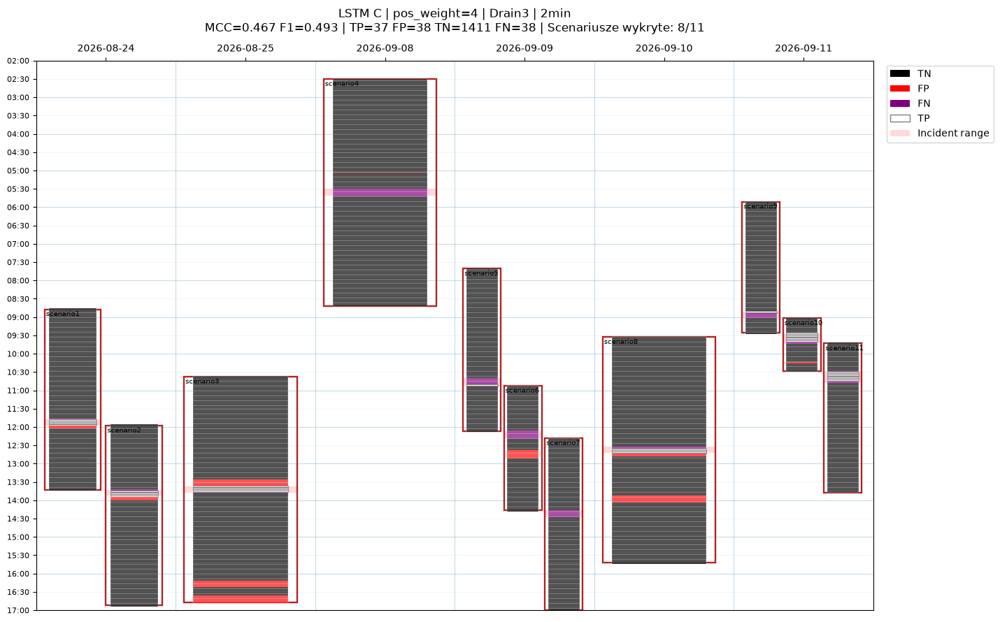

Zakończono: C_posweight_4

WARIANT: C_posweight_8
   1/11  scenario1 | TP= 5 FN= 1 FP=  3 MCC=0.708
   2/11  scenario2 | TP= 6 FN= 0 FP=  4 MCC=0.764
   3/11  scenario3 | TP= 5 FN= 1 FP= 16 MCC=0.416
   4/11  scenario4 | TP= 0 FN= 6 FP=  1 MCC=-0.013
   5/11  scenario5 | TP= 0 FN= 7 FP=  0 MCC=0.000
   6/11  scenario6 | TP= 0 FN= 7 FP=  8 MCC=-0.078
   7/11  scenario7 | TP= 0 FN= 6 FP=  0 MCC=0.000
   8/11  scenario8 | TP= 5 FN= 1 FP=  9 MCC=0.525
   9/11  scenario9 | TP= 0 FN= 6 FP=  0 MCC=0.000
  10/11 scenario10 | TP= 4 FN= 5 FP=  0 MCC=0.624
  11/11 scenario11 | TP= 9 FN= 1 FP=  1 MCC=0.891

WYNIKI GLOBALNE — C_posweight_8


,variant,pos_weight,detected_scenarios,TP,FP,FN,TN,precision,recall,F1,MCC
0,C_posweight_8,8.0,6,34,42,41,1407,0.4474,0.4533,0.4503,0.4217



WYNIKI SCENARIUSZY:


,case,TP,FN,FP,TN,F1,MCC,incident_detected
0,scenario1,5,1,3,140,0.7143,0.7085,1
1,scenario2,6,0,4,139,0.7500,0.7637,1
2,scenario3,5,1,16,164,0.3704,0.4156,1
3,scenario4,0,6,1,179,0.0000,-0.0134,0
4,scenario5,0,7,0,127,0.0000,0.0000,0
5,scenario6,0,7,8,88,0.0000,-0.0784,0
6,scenario7,0,6,0,149,0.0000,0.0000,0
7,scenario8,5,1,9,171,0.5000,0.5246,1
8,scenario9,0,6,0,103,0.0000,0.0000,0
9,scenario10,4,5,0,35,0.6154,0.6236,1


Wykryto incydent w 6/11 scenariuszach (co najmniej jeden TP).


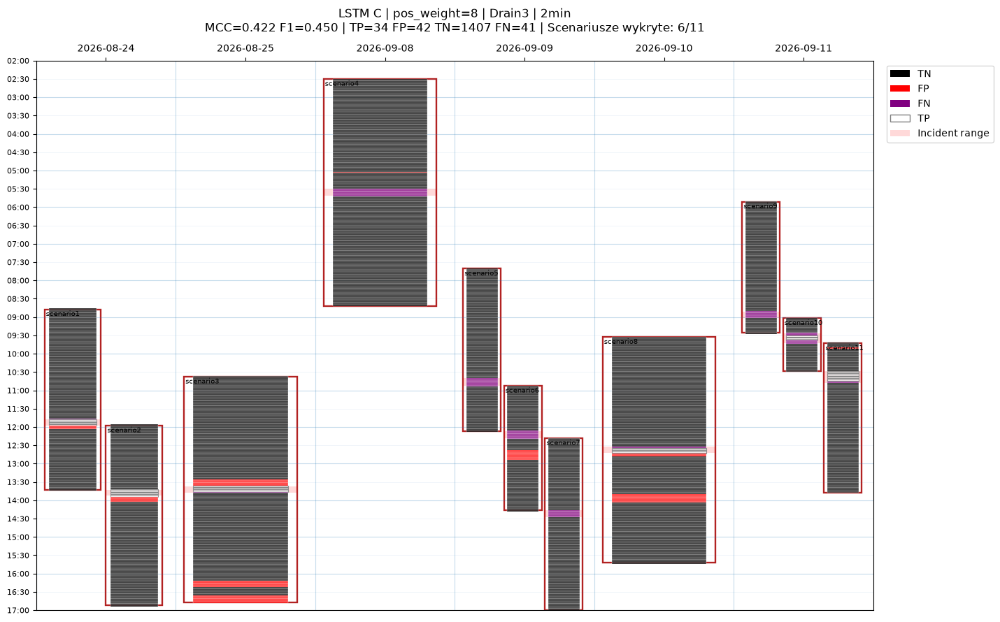

Zakończono: C_posweight_8

=== PORÓWNANIE Z LSTM C ===


,variant,pos_weight,detected_scenarios,MCC,F1,TP,FP,FN,TN
0,C_posweight_2,2.0,8,0.4651,0.4895,35,33,40,1416
1,C_posweight_4,4.0,8,0.4671,0.4933,37,38,38,1411
2,C_posweight_8,8.0,6,0.4217,0.4503,34,42,41,1407



Wyniki zapisane w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\C_posweight_experiment


In [81]:
import gc
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler

# ============================================================
# KONFIGURACJA
# ============================================================

POS_WEIGHTS_TEST = [4.0, 8.0]

C_FEATURES = [
    f for f in FEATURES18
    if f not in {
        "total_logs",
        "unique_templates",
        "single_occurrence_templates",
    }
]

assert len(C_FEATURES) == 15

DEVICE_FN = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

FN_ROOT = PREP_DIR / "nn_loso" / "C_posweight_experiment"
FN_PRED_DIR = FN_ROOT / "predictions"
FN_REPORT_DIR = FN_ROOT / "reports"

for folder in [FN_PRED_DIR, FN_REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Urządzenie:", DEVICE_FN)
print("Liczba treningów:", len(POS_WEIGHTS_TEST) * len(SCENARIOS))

# ============================================================
# DANE — ORYGINALNE, BEZ FILTRACJI LOGÓW
# ============================================================

frames = []

for case in SCENARIOS:
    path = BUCKET_DIR / f"Drain3__{case}__2min.joblib"

    df = joblib.load(path).copy()
    df["case"] = case

    for col in ["timestamp", "bucket_end"]:
        df[col] = pd.to_datetime(df[col], utc=True)

    frames.append(df.sort_values("timestamp"))

FN_DATA = pd.concat(frames, ignore_index=True)

FN_Y = FN_DATA["label_primary"].astype(int).to_numpy()
FN_CASES = FN_DATA["case"].astype(str).to_numpy()

FN_NUMERIC = (
    FN_DATA[C_FEATURES]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

assert len(FN_DATA) == 1524
assert FN_Y.sum() == 75

# ============================================================
# ORYGINALNY KALENDARZ
# ============================================================

FN_CALENDAR = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day", "scenario_start", "scenario_end",
    "incident_start", "incident_end"
]:
    FN_CALENDAR[col] = (
        pd.to_datetime(FN_CALENDAR[col], utc=True)
        .dt.tz_localize(None)
    )

# ============================================================
# TRENING LOSO
# ============================================================

FN_GLOBAL_ROWS = []
FN_CASE_ROWS = []

for weight in POS_WEIGHTS_TEST:

    variant = f"C_posweight_{int(weight)}"

    all_pred = np.full(len(FN_DATA), -1, dtype=int)
    all_prob = np.full(len(FN_DATA), np.nan, dtype=float)

    current_case_rows = []

    print("\n" + "=" * 75)
    print("WARIANT:", variant)
    print("=" * 75, flush=True)

    for fold, test_case in enumerate(SCENARIOS, start=1):

        train_idx = np.flatnonzero(FN_CASES != test_case)
        test_idx = np.flatnonzero(FN_CASES == test_case)

        # Skalowanie tylko na 10 scenariuszach treningowych.
        scaler = StandardScaler()
        scaler.fit(FN_NUMERIC[train_idx])

        scaled = scaler.transform(
            FN_NUMERIC
        ).astype(np.float32)

        scaled = np.clip(scaled, -3.0, 3.0)

        sequences = make_sequences(
            FN_DATA,
            scaled,
            steps=15,
        )

        # Ta sama inicjalizacja co w eksperymencie C.
        random.seed(42)
        np.random.seed(42)
        torch.manual_seed(42)

        if DEVICE_FN.type == "cuda":
            torch.cuda.manual_seed_all(42)

        model = IncidentRNN(
            kind="LSTM",
            n_features=len(C_FEATURES),
            hidden_size=24,
        ).to(DEVICE_FN)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001,
        )

        loss_fn = torch.nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                weight,
                dtype=torch.float32,
                device=DEVICE_FN,
            )
        )

        x_train = torch.from_numpy(
            sequences[train_idx]
        ).to(DEVICE_FN)

        y_train = torch.from_numpy(
            FN_Y[train_idx].astype(np.float32)
        ).to(DEVICE_FN)

        # 25 epok jak w wariancie C.
        for epoch in range(25):

            model.train()

            order = torch.randperm(
                len(train_idx),
                device=DEVICE_FN,
            )

            for batch in order.split(64):

                optimizer.zero_grad(set_to_none=True)

                logits = model(x_train[batch])
                loss = loss_fn(logits, y_train[batch])

                loss.backward()
                optimizer.step()

        # Predykcje tylko dla scenariusza testowego.
        model.eval()

        with torch.no_grad():
            x_test = torch.from_numpy(
                sequences[test_idx]
            ).to(DEVICE_FN)

            probabilities = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        all_pred[test_idx] = predictions
        all_prob[test_idx] = probabilities

        metrics = nn_metrics(
            FN_Y[test_idx], predictions
        )

        row = {
            "variant": variant,
            "case": test_case,
            **metrics,
            "incident_detected": int(metrics["TP"] > 0),
        }

        current_case_rows.append(row)
        FN_CASE_ROWS.append(row)

        # Zapis predykcji foldu.
        pred_df = FN_DATA.iloc[test_idx][[
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]].copy()

        pred_df["prediction"] = predictions
        pred_df["probability"] = probabilities

        joblib.dump(
            {
                "data": pred_df,
                "metrics": metrics,
                "pos_weight": weight,
            },
            FN_PRED_DIR / f"{variant}__{test_case}.joblib",
            compress=3,
        )

        print(
            f"  {fold:2d}/11 {test_case:>10} | "
            f"TP={metrics['TP']:2d} "
            f"FN={metrics['FN']:2d} "
            f"FP={metrics['FP']:3d} "
            f"MCC={metrics['MCC']:.3f}",
            flush=True,
        )

        del (
            model, optimizer, x_train, y_train,
            x_test, sequences, scaled
        )

        if DEVICE_FN.type == "cuda":
            torch.cuda.empty_cache()

        gc.collect()

    # ========================================================
    # WYNIKI GLOBALNE
    # ========================================================

    if (all_pred < 0).any():
        raise RuntimeError("Brakuje części predykcji")

    overall = nn_metrics(FN_Y, all_pred)

    detected_cases = sum(
        row["incident_detected"]
        for row in current_case_rows
    )

    global_row = {
        "variant": variant,
        "pos_weight": weight,
        "detected_scenarios": detected_cases,
        **overall,
    }

    FN_GLOBAL_ROWS.append(global_row)

    print(f"\nWYNIKI GLOBALNE — {variant}")

    display(
        pd.DataFrame([global_row]).round(4)
    )

    print("\nWYNIKI SCENARIUSZY:")

    display(
        pd.DataFrame(current_case_rows)[[
            "case",
            "TP", "FN", "FP", "TN",
            "F1", "MCC", "incident_detected",
        ]].round(4)
    )

    print(
        f"Wykryto incydent w {detected_cases}/11 scenariuszach "
        "(co najmniej jeden TP)."
    )

    # ========================================================
    # KALENDARZ PO KAŻDYM WARIANCIE
    # ========================================================

    plot_df = FN_DATA[[
        "case", "timestamp", "bucket_end",
        "label_primary", "label_all_known"
    ]].copy()

    plot_df["prediction"] = all_pred
    plot_df["probability"] = all_prob

    actual = plot_df["label_primary"].astype(int)

    plot_df["outcome"] = np.select(
        [
            (actual == 1) & (all_pred == 1),
            (actual == 0) & (all_pred == 1),
            (actual == 1) & (all_pred == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    for col in ["timestamp", "bucket_end"]:
        plot_df[col] = (
            pd.to_datetime(plot_df[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"LSTM C | pos_weight={weight:g} | Drain3 | 2min\n"
        f"MCC={overall['MCC']:.3f} "
        f"F1={overall['F1']:.3f} | "
        f"TP={overall['TP']} "
        f"FP={overall['FP']} "
        f"TN={overall['TN']} "
        f"FN={overall['FN']} | "
        f"Scenariusze wykryte: {detected_cases}/11"
    )

    plot_calendar_with_buckets(
        calendar_segments=FN_CALENDAR,
        bucket_df=plot_df,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

    # ========================================================
    # ZAPIS WYNIKÓW PO WARIANCIE
    # ========================================================

    pd.DataFrame(FN_GLOBAL_ROWS).to_csv(
        FN_REPORT_DIR / "overall_results.csv",
        index=False,
    )

    pd.DataFrame(FN_CASE_ROWS).to_csv(
        FN_REPORT_DIR / "scenario_results.csv",
        index=False,
    )

    print("Zakończono:", variant, flush=True)

# ============================================================
# PORÓWNANIE KOŃCOWE
# ============================================================

FN_RESULTS = pd.DataFrame(FN_GLOBAL_ROWS)

print("\n=== PORÓWNANIE Z LSTM C ===")

baseline = pd.DataFrame([{
    "variant": "C_posweight_2",
    "pos_weight": 2.0,
    "detected_scenarios": 8,
    "MCC": 0.4651,
    "F1": 0.4895,
    "TP": 35,
    "FP": 33,
    "FN": 40,
    "TN": 1416,
}])

display(
    pd.concat(
        [baseline, FN_RESULTS],
        ignore_index=True,
    )[[
        "variant",
        "pos_weight",
        "detected_scenarios",
        "MCC", "F1",
        "TP", "FP", "FN", "TN",
    ]].round(4)
)

print("\nWyniki zapisane w:", FN_ROOT)

Urządzenie: cpu
Kubełki: 1524
Pozytywne: 75
Planowane treningi: 22
H_18_short_changes | 18 cech
I_21_short_and_baseline | 21 cech

WARIANT: H_18_short_changes
Cechy: 18
 1/11  scenario1 | TP= 1 FN= 5 FP=  1 MCC=0.273
 2/11  scenario2 | TP= 4 FN= 2 FP=  0 MCC=0.811
 3/11  scenario3 | TP= 4 FN= 2 FP=  6 MCC=0.496
 4/11  scenario4 | TP= 0 FN= 6 FP=  1 MCC=-0.013
 5/11  scenario5 | TP= 6 FN= 1 FP=  1 MCC=0.849
 6/11  scenario6 | TP= 3 FN= 4 FP=  5 MCC=0.354
 7/11  scenario7 | TP= 0 FN= 6 FP=  0 MCC=0.000
 8/11  scenario8 | TP= 5 FN= 1 FP=  8 MCC=0.547
 9/11  scenario9 | TP= 6 FN= 0 FP=  0 MCC=1.000
10/11 scenario10 | TP= 3 FN= 6 FP=  0 MCC=0.533
11/11 scenario11 | TP= 7 FN= 3 FP=  7 MCC=0.549

WYNIKI GLOBALNE — H_18_short_changes


,variant,features,detected_scenarios,TP,FP,FN,TN,precision,recall,F1,MCC
0,H_18_short_changes,18,9,39,29,36,1420,0.5735,0.52,0.5455,0.5238



WYNIKI WEDŁUG SCENARIUSZA


,case,TP,FP,FN,TN,F1,MCC
0,scenario1,1,1,5,142,0.2500,0.2728
1,scenario2,4,0,2,143,0.8000,0.8108
2,scenario3,4,6,2,174,0.5000,0.4961
3,scenario4,0,1,6,179,0.0000,-0.0134
4,scenario5,6,1,1,126,0.8571,0.8493
5,scenario6,3,5,4,91,0.4000,0.3540
6,scenario7,0,0,6,149,0.0000,0.0000
7,scenario8,5,8,1,172,0.5263,0.5467
8,scenario9,6,0,0,103,1.0000,1.0000
9,scenario10,3,0,6,35,0.5000,0.5334



Wykryte scenariusze: 9/11

KALENDARZ — H_18_short_changes


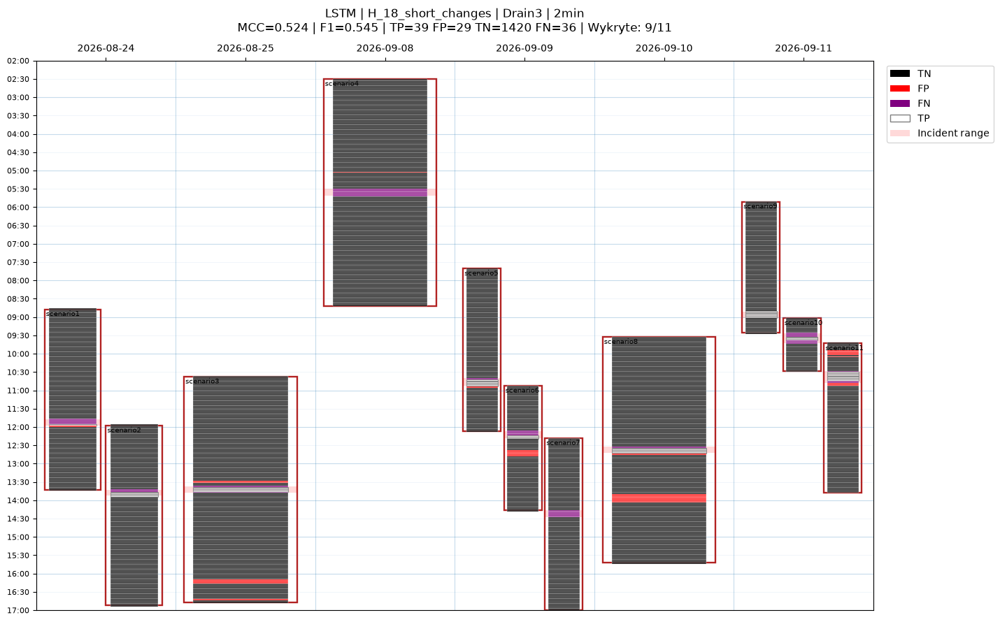


Zakończono H_18_short_changes

WARIANT: I_21_short_and_baseline
Cechy: 21
 1/11  scenario1 | TP= 1 FN= 5 FP=  1 MCC=0.273
 2/11  scenario2 | TP= 4 FN= 2 FP=  1 MCC=0.720
 3/11  scenario3 | TP= 5 FN= 1 FP= 10 MCC=0.505
 4/11  scenario4 | TP= 0 FN= 6 FP=  3 MCC=-0.023
 5/11  scenario5 | TP= 6 FN= 1 FP=  1 MCC=0.849
 6/11  scenario6 | TP= 1 FN= 6 FP=  5 MCC=0.098
 7/11  scenario7 | TP= 0 FN= 6 FP=  0 MCC=0.000
 8/11  scenario8 | TP= 3 FN= 3 FP=  6 MCC=0.384
 9/11  scenario9 | TP= 0 FN= 6 FP=  0 MCC=0.000
10/11 scenario10 | TP= 0 FN= 9 FP=  0 MCC=0.000
11/11 scenario11 | TP= 8 FN= 2 FP=  1 MCC=0.830

WYNIKI GLOBALNE — I_21_short_and_baseline


,variant,features,detected_scenarios,TP,FP,FN,TN,precision,recall,F1,MCC
0,I_21_short_and_baseline,21,7,28,28,47,1421,0.5,0.3733,0.4275,0.407



WYNIKI WEDŁUG SCENARIUSZA


,case,TP,FP,FN,TN,F1,MCC
0,scenario1,1,1,5,142,0.2500,0.2728
1,scenario2,4,1,2,142,0.7273,0.7201
2,scenario3,5,10,1,170,0.4762,0.5047
3,scenario4,0,3,6,177,0.0000,-0.0234
4,scenario5,6,1,1,126,0.8571,0.8493
5,scenario6,1,5,6,91,0.1538,0.0975
6,scenario7,0,0,6,149,0.0000,0.0000
7,scenario8,3,6,3,174,0.4000,0.3842
8,scenario9,0,0,6,103,0.0000,0.0000
9,scenario10,0,0,9,35,0.0000,0.0000



Wykryte scenariusze: 7/11

KALENDARZ — I_21_short_and_baseline


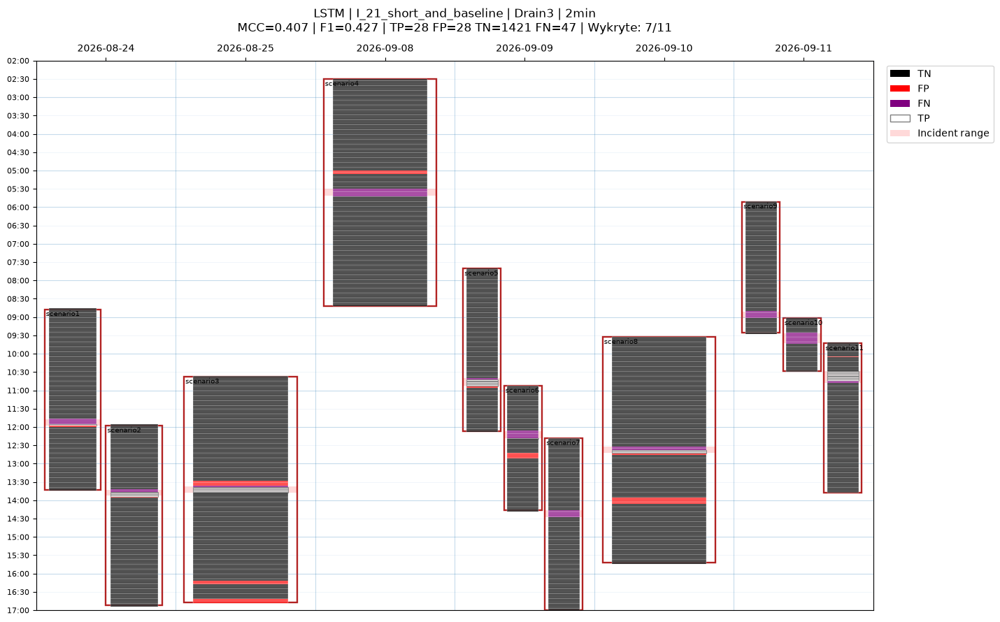


Zakończono I_21_short_and_baseline

=== PORÓWNANIE C, H, I ===


,variant,features,detected_scenarios,MCC,F1,TP,FP,FN,TN
1,H_18_short_changes,18,9,0.5238,0.5455,39,29,36,1420
0,C_15_reference,15,8,0.4651,0.4895,35,33,40,1416
2,I_21_short_and_baseline,21,7,0.4070,0.4275,28,28,47,1421



=== TRUDNE SCENARIUSZE: 4, 6, 7 ===


,variant,case,TP,FP,FN,MCC
3,H_18_short_changes,scenario4,0,1,6,-0.0134
5,H_18_short_changes,scenario6,3,5,4,0.3540
6,H_18_short_changes,scenario7,0,0,6,0.0000
14,I_21_short_and_baseline,scenario4,0,3,6,-0.0234
16,I_21_short_and_baseline,scenario6,1,5,6,0.0975
17,I_21_short_and_baseline,scenario7,0,0,6,0.0000



Wyniki zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\lstm_relative_changes


In [82]:
import os
import gc
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from IPython.display import display
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. KONFIGURACJA
# ============================================================

C15 = [
    f for f in FEATURES18
    if f not in {
        "total_logs",
        "unique_templates",
        "single_occurrence_templates",
    }
]

COUNTERS = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
]

assert len(C15) == 15

HI_ROOT = PREP_DIR / "nn_loso" / "lstm_relative_changes"
HI_PRED = HI_ROOT / "predictions"
HI_MODEL = HI_ROOT / "models"
HI_REPORT = HI_ROOT / "reports"

for folder in [HI_PRED, HI_MODEL, HI_REPORT]:
    folder.mkdir(parents=True, exist_ok=True)

HI_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if HI_DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

# ============================================================
# 2. WCZYTANIE DANYCH
# ============================================================

frames = []

for case in SCENARIOS:
    path = BUCKET_DIR / f"Drain3__{case}__2min.joblib"

    df = joblib.load(path).copy()
    df["case"] = case

    for col in ["timestamp", "bucket_end"]:
        df[col] = pd.to_datetime(df[col], utc=True)

    frames.append(df.sort_values("timestamp"))

HI_DATA = pd.concat(
    frames, ignore_index=True
).reset_index(drop=True)

HI_Y = HI_DATA["label_primary"].astype(int).to_numpy()
HI_CASES = HI_DATA["case"].astype(str).to_numpy()

assert len(HI_DATA) == 1524
assert HI_Y.sum() == 75

# ============================================================
# 3. NOWE CECHY: TYLKO PRZESZŁOŚĆ I BIEŻĄCY KUBEŁEK
# ============================================================

DELTA_FEATURES = []
BASELINE_FEATURES = []

for feature in COUNTERS:

    values = (
        pd.to_numeric(
            HI_DATA[feature], errors="coerce"
        )
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .clip(lower=0)
    )

    log_values = np.log1p(values)

    # Zmiana względem poprzedniego kubełka (2 min).
    previous = log_values.groupby(
        HI_DATA["case"], sort=False
    ).shift(1)

    delta_name = f"delta2m_log_{feature}"

    HI_DATA[delta_name] = (
        log_values - previous
    ).fillna(0.0)

    DELTA_FEATURES.append(delta_name)

    # Mediana z pięciu poprzednich kubełków (10 min).
    # Bieżący kubełek NIE należy do mediany.
    previous_median = values.groupby(
        HI_DATA["case"], sort=False
    ).transform(
        lambda s: s.shift(1).rolling(
            window=5, min_periods=1
        ).median()
    )

    baseline_name = f"delta10m_log_{feature}"

    HI_DATA[baseline_name] = (
        log_values - np.log1p(previous_median)
    ).fillna(0.0)

    BASELINE_FEATURES.append(baseline_name)

HI_VARIANTS = {
    "H_18_short_changes": C15 + DELTA_FEATURES,
    "I_21_short_and_baseline": (
        C15 + DELTA_FEATURES + BASELINE_FEATURES
    ),
}

print("Urządzenie:", HI_DEVICE)
print("Kubełki:", len(HI_DATA))
print("Pozytywne:", int(HI_Y.sum()))
print("Planowane treningi:", 2 * len(SCENARIOS))

for name, columns in HI_VARIANTS.items():
    print(name, "|", len(columns), "cech")

# ============================================================
# 4. PRZYGOTOWANIE KALENDARZA
# ============================================================

HI_CALENDAR = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:
    HI_CALENDAR[col] = (
        pd.to_datetime(HI_CALENDAR[col], utc=True)
        .dt.tz_localize(None)
    )

# ============================================================
# 5. LOSO
# ============================================================

HI_GLOBAL_ROWS = []
HI_CASE_ROWS = []

for variant, columns in HI_VARIANTS.items():

    X_numeric = (
        HI_DATA[columns]
        .apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    predictions_all = np.full(
        len(HI_DATA), -1, dtype=int
    )

    probabilities_all = np.full(
        len(HI_DATA), np.nan, dtype=np.float32
    )

    current_rows = []

    print("\n" + "=" * 75)
    print("WARIANT:", variant)
    print("Cechy:", len(columns))
    print("=" * 75, flush=True)

    for fold, test_case in enumerate(SCENARIOS, 1):

        train_idx = np.flatnonzero(HI_CASES != test_case)
        test_idx = np.flatnonzero(HI_CASES == test_case)

        # Normalizacja tylko na scenariuszach treningowych.
        scaler = StandardScaler()
        scaler.fit(X_numeric[train_idx])

        scaled = scaler.transform(
            X_numeric
        ).astype(np.float32)

        scaled = np.clip(scaled, -3.0, 3.0)

        sequences = make_sequences(
            HI_DATA,
            scaled,
            steps=15,
        )

        # Odtwarzalne inicjalizacje.
        random.seed(42)
        np.random.seed(42)
        torch.manual_seed(42)

        if HI_DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(42)

        model = IncidentRNN(
            kind="LSTM",
            n_features=len(columns),
            hidden_size=24,
        ).to(HI_DEVICE)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=0.001,
        )

        loss_fn = torch.nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                2.0,
                dtype=torch.float32,
                device=HI_DEVICE,
            )
        )

        x_train = torch.from_numpy(
            sequences[train_idx]
        ).to(HI_DEVICE)

        y_train = torch.from_numpy(
            HI_Y[train_idx].astype(np.float32)
        ).to(HI_DEVICE)

        # 25 epok — jak w LSTM C.
        for epoch in range(25):

            model.train()

            order = torch.randperm(
                len(train_idx),
                device=HI_DEVICE,
            )

            for batch in order.split(64):

                optimizer.zero_grad(set_to_none=True)

                logits = model(x_train[batch])
                loss = loss_fn(logits, y_train[batch])

                loss.backward()
                optimizer.step()

        model.eval()

        with torch.no_grad():

            x_test = torch.from_numpy(
                sequences[test_idx]
            ).to(HI_DEVICE)

            probabilities = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

        predicted = (
            probabilities >= 0.5
        ).astype(int)

        predictions_all[test_idx] = predicted
        probabilities_all[test_idx] = probabilities

        metrics = nn_metrics(
            HI_Y[test_idx], predicted
        )

        current_rows.append({
            "variant": variant,
            "case": test_case,
            **metrics,
        })

        HI_CASE_ROWS.append(current_rows[-1])

        # Predykcje osobnego foldu.
        pred_df = HI_DATA.iloc[test_idx][[
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]].copy()

        pred_df["prediction"] = predicted
        pred_df["probability"] = probabilities

        joblib.dump(
            {
                "data": pred_df,
                "metrics": metrics,
            },
            HI_PRED / f"{variant}__{test_case}.joblib",
            compress=3,
        )

        # Zapis modelu i parametrów skalowania.
        torch.save(
            {
                "state_dict": {
                    k: v.detach().cpu()
                    for k, v in model.state_dict().items()
                },
                "features": list(columns),
                "scaler_mean": scaler.mean_,
                "scaler_scale": scaler.scale_,
                "clip": 3.0,
                "steps": 15,
                "pos_weight": 2.0,
                "threshold": 0.5,
            },
            HI_MODEL / f"{variant}__{test_case}.pt",
        )

        print(
            f"{fold:2d}/11 {test_case:>10} | "
            f"TP={metrics['TP']:2d} "
            f"FN={metrics['FN']:2d} "
            f"FP={metrics['FP']:3d} "
            f"MCC={metrics['MCC']:.3f}",
            flush=True,
        )

        del (
            model,
            optimizer,
            x_train,
            y_train,
            x_test,
            sequences,
            scaled,
        )

        if HI_DEVICE.type == "cuda":
            torch.cuda.empty_cache()

        gc.collect()

    # ========================================================
    # 6. WYNIKI PO KAŻDYM WARIANCIE
    # ========================================================

    assert (predictions_all >= 0).all()

    overall = nn_metrics(
        HI_Y, predictions_all
    )

    detected_cases = sum(
        row["TP"] > 0 for row in current_rows
    )

    global_row = {
        "variant": variant,
        "features": len(columns),
        "detected_scenarios": detected_cases,
        **overall,
    }

    HI_GLOBAL_ROWS.append(global_row)

    print(f"\nWYNIKI GLOBALNE — {variant}")

    display(pd.DataFrame([global_row]).round(4))

    print("\nWYNIKI WEDŁUG SCENARIUSZA")

    display(
        pd.DataFrame(current_rows)[[
            "case", "TP", "FP", "FN", "TN",
            "F1", "MCC",
        ]].round(4)
    )

    print(
        f"\nWykryte scenariusze: {detected_cases}/11"
    )

    # Zapis wyników.
    pd.DataFrame(HI_GLOBAL_ROWS).to_csv(
        HI_REPORT / "overall_results.csv",
        index=False,
    )

    pd.DataFrame(HI_CASE_ROWS).to_csv(
        HI_REPORT / "scenario_results.csv",
        index=False,
    )

    # ========================================================
    # 7. ORYGINALNY KALENDARZ
    # ========================================================

    plot_df = HI_DATA[[
        "case",
        "timestamp",
        "bucket_end",
        "label_primary",
        "label_all_known",
    ]].copy()

    plot_df["prediction"] = predictions_all
    plot_df["probability"] = probabilities_all

    actual = plot_df["label_primary"].astype(int)

    plot_df["outcome"] = np.select(
        [
            (actual == 1) & (predictions_all == 1),
            (actual == 0) & (predictions_all == 1),
            (actual == 1) & (predictions_all == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    for col in ["timestamp", "bucket_end"]:
        plot_df[col] = (
            pd.to_datetime(plot_df[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"LSTM | {variant} | Drain3 | 2min\n"
        f"MCC={overall['MCC']:.3f} | "
        f"F1={overall['F1']:.3f} | "
        f"TP={overall['TP']} "
        f"FP={overall['FP']} "
        f"TN={overall['TN']} "
        f"FN={overall['FN']} | "
        f"Wykryte: {detected_cases}/11"
    )

    print(f"\nKALENDARZ — {variant}")

    plot_calendar_with_buckets(
        calendar_segments=HI_CALENDAR,
        bucket_df=plot_df,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

    print(f"\nZakończono {variant}", flush=True)

    del X_numeric, predictions_all, probabilities_all
    gc.collect()

# ============================================================
# 8. PORÓWNANIE Z LSTM C
# ============================================================

baseline = {
    "variant": "C_15_reference",
    "features": 15,
    "detected_scenarios": 8,
    "MCC": 0.4651,
    "F1": 0.4895,
    "TP": 35,
    "FP": 33,
    "FN": 40,
    "TN": 1416,
}

HI_RESULTS = pd.concat(
    [
        pd.DataFrame([baseline]),
        pd.DataFrame(HI_GLOBAL_ROWS),
    ],
    ignore_index=True,
)

print("\n=== PORÓWNANIE C, H, I ===")

display(
    HI_RESULTS[[
        "variant",
        "features",
        "detected_scenarios",
        "MCC", "F1",
        "TP", "FP", "FN", "TN",
    ]]
    .sort_values("MCC", ascending=False)
    .round(4)
)

print("\n=== TRUDNE SCENARIUSZE: 4, 6, 7 ===")

display(
    pd.DataFrame(HI_CASE_ROWS)
    .loc[
        lambda d: d["case"].isin([
            "scenario4",
            "scenario6",
            "scenario7",
        ])
    ][[
        "variant", "case",
        "TP", "FP", "FN", "MCC",
    ]]
    .round(4)
)

print("\nWyniki zapisano w:", HI_ROOT)

In [83]:
import joblib
import numpy as np
import pandas as pd
import torch

from IPython.display import display

H_NAME = "H_18_short_changes"

H_ROOT = PREP_DIR / "nn_loso" / "lstm_relative_changes"
H_MODEL_DIR = H_ROOT / "models"
H_PRED_DIR = H_ROOT / "predictions"

# Dane z eksperymentu H, zawierające również nowe cechy delta2m.
if "HI_DATA" not in globals():
    raise RuntimeError(
        "Brakuje HI_DATA. Uruchom komórkę przygotowującą dane H/I."
    )

H_DATA = HI_DATA.copy()
H_DATA["timestamp"] = pd.to_datetime(
    H_DATA["timestamp"], utc=True
)

H_DATA = (
    H_DATA
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
)

H_AUDIT_PARTS = []
H_FEATURE_NAMES = None

torch.set_num_threads(4)

for case in SCENARIOS:

    model_path = H_MODEL_DIR / f"{H_NAME}__{case}.pt"
    pred_path = H_PRED_DIR / f"{H_NAME}__{case}.joblib"

    if not model_path.exists():
        raise FileNotFoundError(model_path)

    if not pred_path.exists():
        raise FileNotFoundError(pred_path)

    # Ładujemy wyłącznie nasze lokalnie zapisane modele.
    checkpoint = torch.load(
        model_path,
        map_location="cpu",
        weights_only=False,
    )

    features = list(checkpoint["features"])

    if H_FEATURE_NAMES is None:
        H_FEATURE_NAMES = features
    else:
        assert features == H_FEATURE_NAMES

    X = (
        H_DATA[features]
        .apply(pd.to_numeric, errors="raise")
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )

    mean = np.asarray(
        checkpoint["scaler_mean"], dtype=np.float64
    )
    scale = np.asarray(
        checkpoint["scaler_scale"], dtype=np.float64
    )

    scale = np.where(scale == 0, 1.0, scale)

    scaled = ((X - mean) / scale).astype(np.float32)

    scaled = np.clip(
        scaled,
        -float(checkpoint["clip"]),
        float(checkpoint["clip"]),
    )

    sequences = make_sequences(
        H_DATA,
        scaled,
        steps=int(checkpoint["steps"]),
    )

    case_idx = np.flatnonzero(
        H_DATA["case"].to_numpy() == case
    )

    case_data = (
        H_DATA.iloc[case_idx]
        .sort_values("timestamp")
    )

    test_sequences = sequences[case_idx]

    stored = (
        joblib.load(pred_path)["data"]
        .copy()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    stored["timestamp"] = pd.to_datetime(
        stored["timestamp"], utc=True
    )

    if (
        len(stored) != len(case_data)
        or not np.array_equal(
            stored["timestamp"].to_numpy(),
            case_data["timestamp"].to_numpy(),
        )
    ):
        raise RuntimeError(
            f"{case}: niezgodna kolejność lub liczba kubełków."
        )

    model = IncidentRNN(
        kind="LSTM",
        n_features=len(features),
        hidden_size=24,
    )

    model.load_state_dict(checkpoint["state_dict"])
    model.eval()

    with torch.no_grad():
        baseline_logits = model(
            torch.from_numpy(test_sequences)
        ).numpy()

    reconstructed_prob = (
        1.0 / (1.0 + np.exp(-baseline_logits))
    )

    max_error = float(np.max(np.abs(
        reconstructed_prob
        - stored["probability"].to_numpy(dtype=float)
    )))

    if max_error > 0.002:
        raise RuntimeError(
            f"{case}: model nie odtwarza zapisanych "
            f"prawdopodobieństw (różnica={max_error:.6f})."
        )

    impacts = np.empty(
        (len(stored), len(features)),
        dtype=np.float32,
    )

    for j, feature in enumerate(features):

        modified = test_sequences.copy()

        # Neutralizujemy jedną cechę w całej sekwencji.
        modified[:, :, j] = 0.0

        with torch.no_grad():
            modified_logits = model(
                torch.from_numpy(modified)
            ).numpy()

        impacts[:, j] = (
            baseline_logits - modified_logits
        )

    part = stored[
        [
            "case",
            "timestamp",
            "label_primary",
            "prediction",
            "probability",
        ]
    ].copy()

    for j, feature in enumerate(features):
        part[f"impact__{feature}"] = impacts[:, j]

    H_AUDIT_PARTS.append(part)

    print(
        f"{case}: przeanalizowano "
        f"{len(stored)} kubełków i {len(features)} cech"
    )

H_AUDIT = pd.concat(
    H_AUDIT_PARTS,
    ignore_index=True,
)

actual = H_AUDIT["label_primary"].astype(int)
predicted = H_AUDIT["prediction"].astype(int)

H_AUDIT["outcome"] = np.select(
    [
        (actual == 1) & (predicted == 1),
        (actual == 0) & (predicted == 1),
        (actual == 1) & (predicted == 0),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)

def mean_impact(feature, mask):
    values = H_AUDIT.loc[
        mask, f"impact__{feature}"
    ]

    return float(values.mean()) if len(values) else np.nan

impact_rows = []

for feature in H_FEATURE_NAMES:

    impact_rows.append({
        "feature": feature,
        "TP_effect": mean_impact(
            feature, H_AUDIT["outcome"].eq("TP")
        ),
        "FN_effect": mean_impact(
            feature, H_AUDIT["outcome"].eq("FN")
        ),
        "FN_scenario4": mean_impact(
            feature,
            H_AUDIT["outcome"].eq("FN")
            & H_AUDIT["case"].eq("scenario4"),
        ),
        "FN_scenario6": mean_impact(
            feature,
            H_AUDIT["outcome"].eq("FN")
            & H_AUDIT["case"].eq("scenario6"),
        ),
        "FN_scenario7": mean_impact(
            feature,
            H_AUDIT["outcome"].eq("FN")
            & H_AUDIT["case"].eq("scenario7"),
        ),
    })

H_IMPACT = pd.DataFrame(impact_rows)

print("\n=== CECHY NAJBARDZIEJ WSPIERAJĄCE TP ===")

display(
    H_IMPACT
    .sort_values("TP_effect", ascending=False)
    .head(12)
    .round(4)
)

print("\n=== CECHY NAJBARDZIEJ OBNIŻAJĄCE WYNIK TP ===")

display(
    H_IMPACT
    .sort_values("TP_effect")
    .head(8)
    .round(4)
)

print("\n=== ROZKŁAD TP / FP / FN / TN ===")

display(
    pd.crosstab(
        H_AUDIT["case"],
        H_AUDIT["outcome"],
    ).reindex(
        columns=["TP", "FP", "FN", "TN"],
        fill_value=0,
    )
)

scenario1: przeanalizowano 149 kubełków i 18 cech
scenario2: przeanalizowano 149 kubełków i 18 cech
scenario3: przeanalizowano 186 kubełków i 18 cech
scenario4: przeanalizowano 186 kubełków i 18 cech
scenario5: przeanalizowano 134 kubełków i 18 cech
scenario6: przeanalizowano 103 kubełków i 18 cech
scenario7: przeanalizowano 155 kubełków i 18 cech
scenario8: przeanalizowano 186 kubełków i 18 cech
scenario9: przeanalizowano 109 kubełków i 18 cech
scenario10: przeanalizowano 44 kubełków i 18 cech
scenario11: przeanalizowano 123 kubełków i 18 cech

=== CECHY NAJBARDZIEJ WSPIERAJĄCE TP ===


,feature,TP_effect,FN_effect,FN_scenario4,FN_scenario6,FN_scenario7
7,total_logs_z,2.8922,1.0980,-0.1359,2.7553,0.5586
10,template_entropy_z,0.6975,0.0377,0.1094,2.5106,-1.5728
5,template_set_change,0.6460,1.0636,0.0855,-0.4173,1.5222
4,novel_template_rate,0.4665,0.9508,-0.0710,-0.0702,1.9044
8,unique_templates_z,0.4014,0.6493,-0.1187,0.9286,0.8540
11,max_template_enrichment,0.2818,0.1261,0.1465,-0.8157,-0.2771
0,unique_rate,0.1998,0.1610,0.1585,-0.2647,0.3547
3,template_entropy,0.1875,0.4386,0.0009,0.2273,-0.0392
1,single_occurrence_rate,0.1266,0.5957,0.3431,-0.5686,1.1415
2,dominant_share,0.0900,0.1810,-0.0175,-1.0435,0.1182



=== CECHY NAJBARDZIEJ OBNIŻAJĄCE WYNIK TP ===


,feature,TP_effect,FN_effect,FN_scenario4,FN_scenario6,FN_scenario7
14,templates_enriched_10x,-0.1003,-0.1323,0.2303,0.1799,0.0429
13,templates_enriched_5x,-0.0687,-0.1267,0.0151,-0.0393,-0.2456
6,js_divergence,0.0213,0.0396,-0.1203,0.6690,0.0371
16,delta2m_log_unique_templates,0.0314,0.2639,-0.0138,0.1486,0.6240
12,mean_top3_enrichment,0.0442,-0.0191,0.1197,-0.4582,-0.1900
17,delta2m_log_single_occurrence_templates,0.0676,0.2352,0.0575,0.2831,0.3641
15,delta2m_log_total_logs,0.0737,0.0511,-0.0045,1.0281,-0.1510
9,single_occurrence_templates_z,0.0863,0.4821,0.2426,-1.3802,1.4877



=== ROZKŁAD TP / FP / FN / TN ===


outcome,TP,FP,FN,TN
case,,,,
scenario1,1,1,5,142
scenario10,3,0,6,35
scenario11,7,7,3,106
scenario2,4,0,2,143
scenario3,4,6,2,174
scenario4,0,1,6,179
scenario5,6,1,1,126
scenario6,3,5,4,91
scenario7,0,0,6,149


In [85]:
import os
import gc
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

# ============================================================
# KONFIGURACJA EKSPERYMENTU
# ============================================================

NETWORK_NAME = "LSTM_AIOps_Temporal18"

SEQ_LENGTH = 15
HIDDEN_SIZE = 24
DROPOUT = 0.20
EPOCHS = 25
BATCH_SIZE = 64
LEARNING_RATE = 0.001
POS_WEIGHT = 2.0
THRESHOLD = 0.50
CLIP = 3.0
SEED = 42

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

# ============================================================
# 18 CECH MODELU
# ============================================================

ABSOLUTE_COUNTERS = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
]

BASE_FEATURES = [
    feature for feature in FEATURES18
    if feature not in ABSOLUTE_COUNTERS
]

DELTA_FEATURES = [
    f"delta2m_log_{feature}"
    for feature in ABSOLUTE_COUNTERS
]

NETWORK_FEATURES = BASE_FEATURES + DELTA_FEATURES

assert len(BASE_FEATURES) == 15
assert len(NETWORK_FEATURES) == 18

# ============================================================
# DANE ZE WSZYSTKICH SCENARIUSZY
# ============================================================

frames = []

for case in SCENARIOS:

    path = BUCKET_DIR / f"Drain3__{case}__2min.joblib"

    if not path.exists():
        raise FileNotFoundError(path)

    frame = joblib.load(path).copy()
    frame["case"] = case

    for col in ["timestamp", "bucket_end"]:
        frame[col] = pd.to_datetime(frame[col], utc=True)

    frame = frame.sort_values(
        "timestamp"
    ).reset_index(drop=True)

    # Trzy zmiany logarytmiczne.
    for feature in ABSOLUTE_COUNTERS:

        values = (
            pd.to_numeric(frame[feature], errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0)
            .clip(lower=0)
        )

        frame[f"delta2m_log_{feature}"] = (
            np.log1p(values).diff().fillna(0.0)
        )

    frames.append(frame)

NETWORK_DATA = pd.concat(
    frames, ignore_index=True
)

NETWORK_Y = (
    NETWORK_DATA["label_primary"]
    .astype(int)
    .to_numpy()
)

NETWORK_CASES = (
    NETWORK_DATA["case"]
    .astype(str)
    .to_numpy()
)

NETWORK_NUMERIC = (
    NETWORK_DATA[NETWORK_FEATURES]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

# ============================================================
# BUDOWANIE SEKWENCJI — BEZ ŁĄCZENIA SCENARIUSZY
# ============================================================

def build_aiops_sequences(data, scaled, steps=15):

    sequences = np.zeros(
        (len(data), steps, scaled.shape[1]),
        dtype=np.float32,
    )

    for _, indices in data.groupby(
        "case", sort=False
    ).indices.items():

        indices = np.asarray(indices)

        indices = indices[
            np.argsort(
                data.iloc[indices]["timestamp"].to_numpy()
            )
        ]

        for i, position in enumerate(indices):

            history = indices[
                max(0, i - steps + 1):i + 1
            ]

            # Krótsze sekwencje na początku scenariusza
            # dopełniamy zerami po standaryzacji.
            sequences[
                position, -len(history):, :
            ] = scaled[history]

    return sequences

# ============================================================
# ARCHITEKTURA
# ============================================================

class LSTMAIOps(nn.Module):

    def __init__(self, n_features=18, hidden_size=24):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(hidden_size, 1)

    def forward(self, x):

        sequence_output, _ = self.lstm(x)

        last_state = sequence_output[:, -1, :]

        logits = self.classifier(
            self.dropout(last_state)
        )

        return logits.squeeze(-1)


def calculate_aiops_metrics(actual, predicted):

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    return {
        "MCC": float(matthews_corrcoef(actual, predicted)),
        "F1": float(f1_score(
            actual, predicted, zero_division=0
        )),
        "precision": float(precision_score(
            actual, predicted, zero_division=0
        )),
        "recall": float(recall_score(
            actual, predicted, zero_division=0
        )),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


# ============================================================
# PODSUMOWANIE DO PREZENTACJI
# ============================================================

architecture = LSTMAIOps(
    n_features=len(NETWORK_FEATURES),
    hidden_size=HIDDEN_SIZE,
)

n_parameters = sum(
    p.numel() for p in architecture.parameters()
)

print("MODEL:", NETWORK_NAME)
print("Urządzenie:", DEVICE)
print("Liczba scenariuszy:", len(SCENARIOS))
print("Kubełki:", len(NETWORK_DATA))
print("Dodatnie kubełki:", int(NETWORK_Y.sum()))
print("Wejście:", (SEQ_LENGTH, len(NETWORK_FEATURES)))
print("LSTM hidden size:", HIDDEN_SIZE)
print("Parametry trenowalne:", n_parameters)
print("Liczba treningów LOSO:", len(SCENARIOS))

print("\nCECHY MODELU:")
for i, feature in enumerate(NETWORK_FEATURES, start=1):
    print(f"{i:2d}. {feature}")

print("\nARCHITEKTURA:")
print(architecture)

MODEL: LSTM_AIOps_Temporal18
Urządzenie: cpu
Liczba scenariuszy: 11
Kubełki: 1524
Dodatnie kubełki: 75
Wejście: (15, 18)
LSTM hidden size: 24
Parametry trenowalne: 4249
Liczba treningów LOSO: 11

CECHY MODELU:
 1. unique_rate
 2. single_occurrence_rate
 3. dominant_share
 4. template_entropy
 5. novel_template_rate
 6. template_set_change
 7. js_divergence
 8. total_logs_z
 9. unique_templates_z
10. single_occurrence_templates_z
11. template_entropy_z
12. max_template_enrichment
13. mean_top3_enrichment
14. templates_enriched_5x
15. templates_enriched_10x
16. delta2m_log_total_logs
17. delta2m_log_unique_templates
18. delta2m_log_single_occurrence_templates

ARCHITEKTURA:
LSTMAIOps(
  (lstm): LSTM(18, 24, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (classifier): Linear(in_features=24, out_features=1, bias=True)
)


 1/11  scenario1 | TP= 1 FP=  1 FN= 5 MCC=0.273
 2/11  scenario2 | TP= 4 FP=  0 FN= 2 MCC=0.811
 3/11  scenario3 | TP= 4 FP=  6 FN= 2 MCC=0.496
 4/11  scenario4 | TP= 0 FP=  1 FN= 6 MCC=-0.013
 5/11  scenario5 | TP= 6 FP=  1 FN= 1 MCC=0.849
 6/11  scenario6 | TP= 3 FP=  5 FN= 4 MCC=0.354
 7/11  scenario7 | TP= 0 FP=  0 FN= 6 MCC=0.000
 8/11  scenario8 | TP= 5 FP=  8 FN= 1 MCC=0.547
 9/11  scenario9 | TP= 6 FP=  0 FN= 0 MCC=1.000
10/11 scenario10 | TP= 3 FP=  0 FN= 6 MCC=0.533
11/11 scenario11 | TP= 7 FP=  7 FN= 3 MCC=0.549

=== WYNIKI GLOBALNE LSTM-AIOps ===


,model,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,LSTM_AIOps_Temporal18,18,9,0.5238,0.5455,0.5735,0.52,39,29,36,1420



=== WYNIKI WEDŁUG SCENARIUSZA ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN
0,scenario1,0.2728,0.2500,0.5000,0.1667,1,1,5,142
1,scenario2,0.8108,0.8000,1.0000,0.6667,4,0,2,143
2,scenario3,0.4961,0.5000,0.4000,0.6667,4,6,2,174
3,scenario4,-0.0134,0.0000,0.0000,0.0000,0,1,6,179
4,scenario5,0.8493,0.8571,0.8571,0.8571,6,1,1,126
5,scenario6,0.3540,0.4000,0.3750,0.4286,3,5,4,91
6,scenario7,0.0000,0.0000,0.0000,0.0000,0,0,6,149
7,scenario8,0.5467,0.5263,0.3846,0.8333,5,8,1,172
8,scenario9,1.0000,1.0000,1.0000,1.0000,6,0,0,103
9,scenario10,0.5334,0.5000,1.0000,0.3333,3,0,6,35



=== KALENDARZ LSTM-AIOps ===


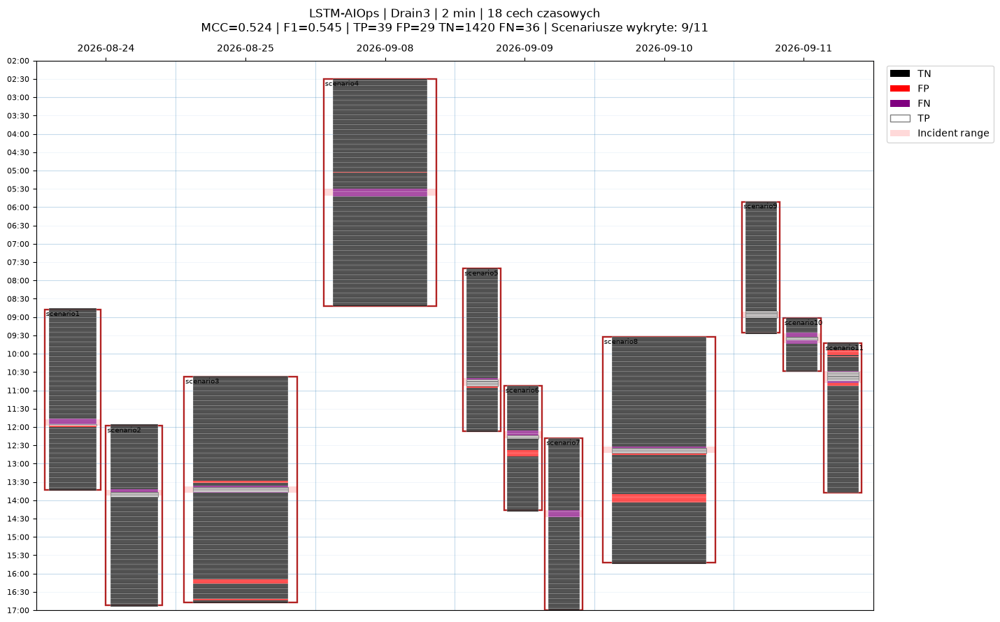


Wyniki i modele zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\LSTM_AIOps_Temporal18


In [86]:
# ============================================================
# KATALOG WYNIKÓW
# ============================================================

NETWORK_ROOT = (
    PREP_DIR / "nn_loso" / "LSTM_AIOps_Temporal18"
)

NETWORK_MODEL_DIR = NETWORK_ROOT / "models"
NETWORK_PRED_DIR = NETWORK_ROOT / "predictions"
NETWORK_REPORT_DIR = NETWORK_ROOT / "reports"

for folder in [
    NETWORK_MODEL_DIR,
    NETWORK_PRED_DIR,
    NETWORK_REPORT_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOSO — 11 TRENINGÓW
# ============================================================

NETWORK_ALL_PRED = np.full(
    len(NETWORK_DATA), -1, dtype=int
)

NETWORK_ALL_PROB = np.full(
    len(NETWORK_DATA), np.nan, dtype=np.float32
)

NETWORK_CASE_RESULTS = []

for fold, test_case in enumerate(SCENARIOS, start=1):

    train_idx = np.flatnonzero(
        NETWORK_CASES != test_case
    )

    test_idx = np.flatnonzero(
        NETWORK_CASES == test_case
    )

    # Standaryzacja tylko na treningu.
    scaler = StandardScaler()
    scaler.fit(NETWORK_NUMERIC[train_idx])

    scaled = scaler.transform(
        NETWORK_NUMERIC
    ).astype(np.float32)

    scaled = np.clip(scaled, -CLIP, CLIP)

    sequences = build_aiops_sequences(
        NETWORK_DATA,
        scaled,
        steps=SEQ_LENGTH,
    )

    # Odtwarzalna inicjalizacja.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    model = LSTMAIOps(
        n_features=len(NETWORK_FEATURES),
        hidden_size=HIDDEN_SIZE,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            POS_WEIGHT,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    x_train = torch.from_numpy(
        sequences[train_idx]
    ).to(DEVICE)

    y_train = torch.from_numpy(
        NETWORK_Y[train_idx].astype(np.float32)
    ).to(DEVICE)

    # --------------------------------------------------------
    # TRENING
    # --------------------------------------------------------

    for epoch in range(EPOCHS):

        model.train()

        order = torch.randperm(
            len(train_idx),
            device=DEVICE,
        )

        for batch in order.split(BATCH_SIZE):

            optimizer.zero_grad(set_to_none=True)

            logits = model(x_train[batch])

            loss = loss_fn(
                logits,
                y_train[batch],
            )

            loss.backward()
            optimizer.step()

    # --------------------------------------------------------
    # TEST NA SCENARIUSZU WYŁĄCZONYM Z TRENINGU
    # --------------------------------------------------------

    model.eval()

    with torch.no_grad():

        x_test = torch.from_numpy(
            sequences[test_idx]
        ).to(DEVICE)

        probability = torch.sigmoid(
            model(x_test)
        ).cpu().numpy()

    prediction = (
        probability >= THRESHOLD
    ).astype(int)

    NETWORK_ALL_PRED[test_idx] = prediction
    NETWORK_ALL_PROB[test_idx] = probability

    metrics = calculate_aiops_metrics(
        NETWORK_Y[test_idx],
        prediction,
    )

    NETWORK_CASE_RESULTS.append({
        "case": test_case,
        **metrics,
    })

    # Zapis predykcji.
    pred_df = NETWORK_DATA.iloc[test_idx][[
        "case",
        "timestamp",
        "bucket_end",
        "label_primary",
        "label_all_known",
    ]].copy()

    pred_df["prediction"] = prediction
    pred_df["probability"] = probability

    joblib.dump(
        {
            "data": pred_df,
            "metrics": metrics,
        },
        NETWORK_PRED_DIR / f"{test_case}.joblib",
        compress=3,
    )

    # Zapis modelu wraz z preprocessingiem.
    torch.save(
        {
            "state_dict": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "features": NETWORK_FEATURES,
            "scaler_mean": scaler.mean_,
            "scaler_scale": scaler.scale_,
            "sequence_length": SEQ_LENGTH,
            "hidden_size": HIDDEN_SIZE,
            "dropout": DROPOUT,
            "clip": CLIP,
            "threshold": THRESHOLD,
            "epochs": EPOCHS,
            "pos_weight": POS_WEIGHT,
            "test_case": test_case,
        },
        NETWORK_MODEL_DIR / f"{test_case}.pt",
    )

    print(
        f"{fold:2d}/11 {test_case:>10} | "
        f"TP={metrics['TP']:2d} "
        f"FP={metrics['FP']:3d} "
        f"FN={metrics['FN']:2d} "
        f"MCC={metrics['MCC']:.3f}",
        flush=True,
    )

    del (
        model,
        optimizer,
        x_train,
        y_train,
        x_test,
        sequences,
        scaled,
    )

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    gc.collect()


# ============================================================
# GLOBALNE WYNIKI
# ============================================================

if (NETWORK_ALL_PRED < 0).any():
    raise RuntimeError("Nie wszystkie kubełki mają predykcję")

NETWORK_METRICS = calculate_aiops_metrics(
    NETWORK_Y,
    NETWORK_ALL_PRED,
)

detected_scenarios = sum(
    row["TP"] > 0
    for row in NETWORK_CASE_RESULTS
)

print("\n=== WYNIKI GLOBALNE LSTM-AIOps ===")

global_result = {
    "model": NETWORK_NAME,
    "features": len(NETWORK_FEATURES),
    "detected_scenarios": detected_scenarios,
    **NETWORK_METRICS,
}

display(
    pd.DataFrame([global_result]).round(4)
)

print("\n=== WYNIKI WEDŁUG SCENARIUSZA ===")

NETWORK_CASE_TABLE = pd.DataFrame(
    NETWORK_CASE_RESULTS
)

display(
    NETWORK_CASE_TABLE[
        [
            "case", "MCC", "F1",
            "precision", "recall",
            "TP", "FP", "FN", "TN",
        ]
    ].round(4)
)

pd.DataFrame([global_result]).to_csv(
    NETWORK_REPORT_DIR / "overall_results.csv",
    index=False,
)

NETWORK_CASE_TABLE.to_csv(
    NETWORK_REPORT_DIR / "scenario_results.csv",
    index=False,
)

# ============================================================
# KALENDARZ — ORYGINALNY STYL
# ============================================================

plot_df = NETWORK_DATA[[
    "case",
    "timestamp",
    "bucket_end",
    "label_primary",
    "label_all_known",
]].copy()

plot_df["prediction"] = NETWORK_ALL_PRED
plot_df["probability"] = NETWORK_ALL_PROB

actual = plot_df["label_primary"].astype(int)

plot_df["outcome"] = np.select(
    [
        (actual == 1) & (NETWORK_ALL_PRED == 1),
        (actual == 0) & (NETWORK_ALL_PRED == 1),
        (actual == 1) & (NETWORK_ALL_PRED == 0),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)

for col in ["timestamp", "bucket_end"]:
    plot_df[col] = (
        pd.to_datetime(plot_df[col], utc=True)
        .dt.tz_localize(None)
    )

calendar = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:
    calendar[col] = (
        pd.to_datetime(calendar[col], utc=True)
        .dt.tz_localize(None)
    )

title = (
    f"LSTM-AIOps | Drain3 | 2 min | 18 cech czasowych\n"
    f"MCC={NETWORK_METRICS['MCC']:.3f}"
    f" | F1={NETWORK_METRICS['F1']:.3f}"
    f" | TP={NETWORK_METRICS['TP']}"
    f" FP={NETWORK_METRICS['FP']}"
    f" TN={NETWORK_METRICS['TN']}"
    f" FN={NETWORK_METRICS['FN']}"
    f" | Scenariusze wykryte: {detected_scenarios}/11"
)

print("\n=== KALENDARZ LSTM-AIOps ===")

plot_calendar_with_buckets(
    calendar_segments=calendar,
    bucket_df=plot_df,
    title=title,
    start_hour=2,
    end_hour=17,
)

plt.show()

print("\nWyniki i modele zapisano w:", NETWORK_ROOT)


MODEL: Basic7_Standard
 1/11  scenario1 | TP= 0 FP=  0 FN= 6 MCC=0.000
 2/11  scenario2 | TP= 0 FP=  0 FN= 6 MCC=0.000
 3/11  scenario3 | TP= 0 FP=  3 FN= 6 MCC=-0.023
 4/11  scenario4 | TP= 0 FP=  1 FN= 6 MCC=-0.013
 5/11  scenario5 | TP= 2 FP=  1 FN= 5 MCC=0.418
 6/11  scenario6 | TP= 6 FP=  0 FN= 1 MCC=0.921
 7/11  scenario7 | TP= 0 FP=  0 FN= 6 MCC=0.000
 8/11  scenario8 | TP= 6 FP=  4 FN= 0 MCC=0.766
 9/11  scenario9 | TP= 0 FP=  0 FN= 6 MCC=0.000
10/11 scenario10 | TP= 0 FP=  0 FN= 9 MCC=0.000
11/11 scenario11 | TP=10 FP=110 FN= 0 MCC=0.047

=== GLOBALNE METRYKI: Basic7_Standard ===


,model,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,Basic7_Standard,7,4,0.1765,0.2202,0.1678,0.32,24,119,51,1330



=== WYNIKI SCENARIUSZY ===


,model,case,MCC,F1,precision,recall,TP,FP,FN,TN
0,Basic7_Standard,scenario1,0.0000,0.0000,0.0000,0.0000,0,0,6,143
1,Basic7_Standard,scenario2,0.0000,0.0000,0.0000,0.0000,0,0,6,143
2,Basic7_Standard,scenario3,-0.0234,0.0000,0.0000,0.0000,0,3,6,177
3,Basic7_Standard,scenario4,-0.0134,0.0000,0.0000,0.0000,0,1,6,179
4,Basic7_Standard,scenario5,0.4179,0.4000,0.6667,0.2857,2,1,5,126
5,Basic7_Standard,scenario6,0.9210,0.9231,1.0000,0.8571,6,0,1,96
6,Basic7_Standard,scenario7,0.0000,0.0000,0.0000,0.0000,0,0,6,149
7,Basic7_Standard,scenario8,0.7659,0.7500,0.6000,1.0000,6,4,0,176
8,Basic7_Standard,scenario9,0.0000,0.0000,0.0000,0.0000,0,0,6,103
9,Basic7_Standard,scenario10,0.0000,0.0000,0.0000,0.0000,0,0,9,35



=== KALENDARZ: Basic7_Standard ===


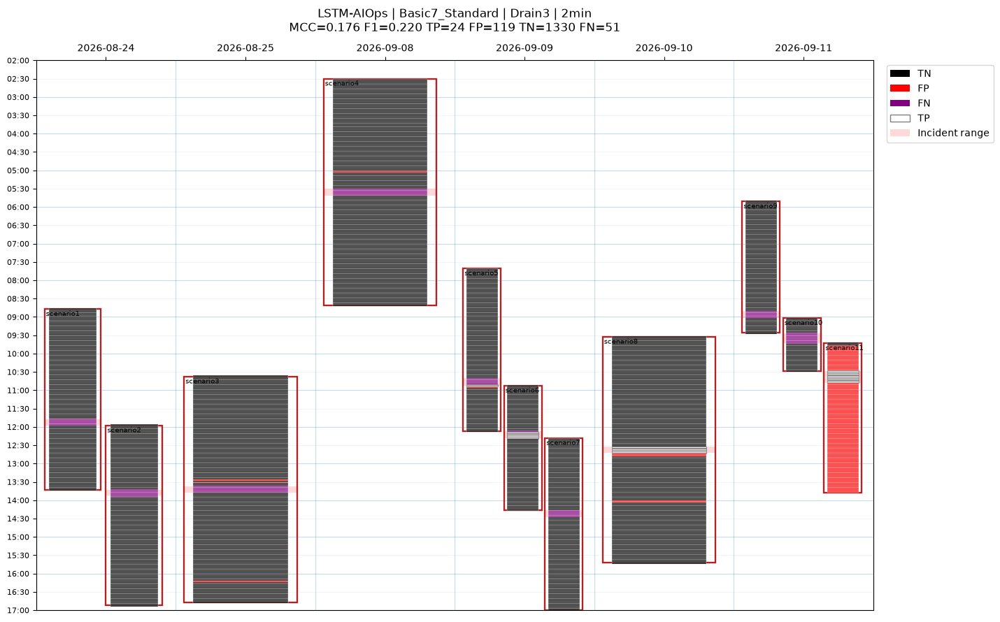


MODEL: Basic7_Log
 1/11  scenario1 | TP= 0 FP=  0 FN= 6 MCC=0.000
 2/11  scenario2 | TP= 0 FP=  0 FN= 6 MCC=0.000
 3/11  scenario3 | TP= 0 FP=  1 FN= 6 MCC=-0.013
 4/11  scenario4 | TP= 0 FP=  1 FN= 6 MCC=-0.013
 5/11  scenario5 | TP= 3 FP=  1 FN= 4 MCC=0.550
 6/11  scenario6 | TP= 7 FP=  0 FN= 0 MCC=1.000
 7/11  scenario7 | TP= 0 FP=  0 FN= 6 MCC=0.000
 8/11  scenario8 | TP= 6 FP=  3 FN= 0 MCC=0.810
 9/11  scenario9 | TP= 0 FP=  0 FN= 6 MCC=0.000
10/11 scenario10 | TP= 0 FP=  0 FN= 9 MCC=0.000
11/11 scenario11 | TP=10 FP=110 FN= 0 MCC=0.047

=== GLOBALNE METRYKI: Basic7_Log ===


,model,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,Basic7_Log,7,4,0.1984,0.2396,0.1831,0.3467,26,116,49,1333



=== WYNIKI SCENARIUSZY ===


,model,case,MCC,F1,precision,recall,TP,FP,FN,TN
0,Basic7_Log,scenario1,0.0000,0.0000,0.0000,0.0000,0,0,6,143
1,Basic7_Log,scenario2,0.0000,0.0000,0.0000,0.0000,0,0,6,143
2,Basic7_Log,scenario3,-0.0134,0.0000,0.0000,0.0000,0,1,6,179
3,Basic7_Log,scenario4,-0.0134,0.0000,0.0000,0.0000,0,1,6,179
4,Basic7_Log,scenario5,0.5501,0.5455,0.7500,0.4286,3,1,4,126
5,Basic7_Log,scenario6,1.0000,1.0000,1.0000,1.0000,7,0,0,96
6,Basic7_Log,scenario7,0.0000,0.0000,0.0000,0.0000,0,0,6,149
7,Basic7_Log,scenario8,0.8097,0.8000,0.6667,1.0000,6,3,0,177
8,Basic7_Log,scenario9,0.0000,0.0000,0.0000,0.0000,0,0,6,103
9,Basic7_Log,scenario10,0.0000,0.0000,0.0000,0.0000,0,0,9,35



=== KALENDARZ: Basic7_Log ===


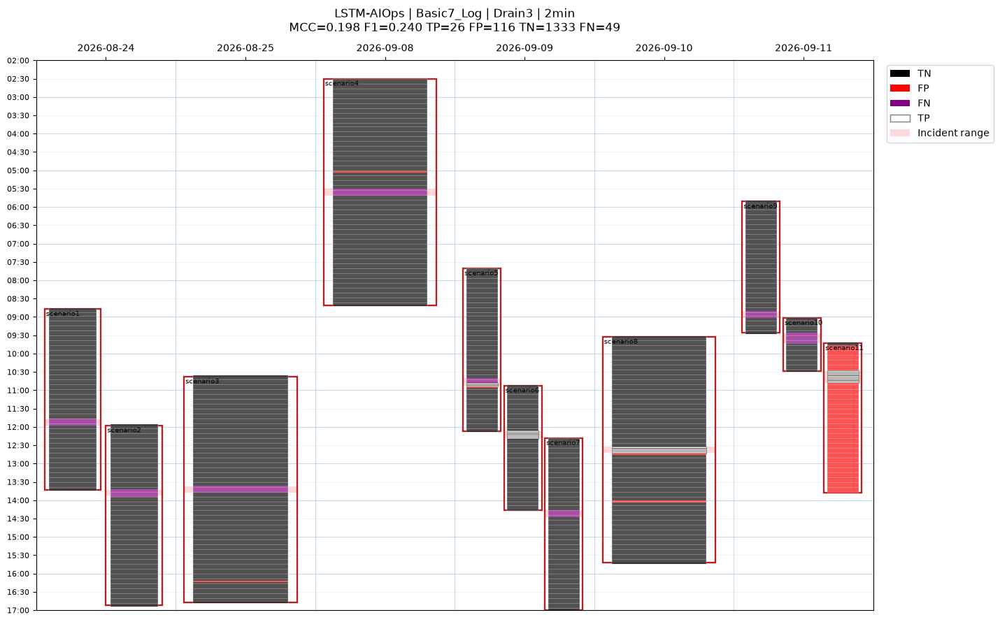


=== PORÓWNANIE MODELI ===


,model,features,MCC,F1,TP,FP,FN,TN
0,LSTM_Temporal18,18,0.5238,0.5455,39,29,36,1420
2,Basic7_Log,7,0.1984,0.2396,26,116,49,1333
1,Basic7_Standard,7,0.1765,0.2202,24,119,51,1330



Wyniki zapisane w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\LSTM_AIOps_Basic7


In [87]:
import os
import gc
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, f1_score, matthews_corrcoef,
    precision_score, recall_score
)

# ======================================================
# 1. KONFIGURACJA
# ======================================================

BASIC7 = list(BASIC_FEATURES)
assert len(BASIC7) == 7

COUNT_FEATURES = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
]

VARIANTS7 = {
    "Basic7_Standard": False,
    "Basic7_Log": True,
}

SEQ7 = 15
HIDDEN7 = 24
EPOCHS7 = 25
BATCH7 = 64
LR7 = 0.001
WEIGHT7 = 2.0
CLIP7 = 3.0
THRESHOLD7 = 0.50

DEVICE7 = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE7.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

EXP7_ROOT = (
    PREP_DIR / "nn_loso" / "LSTM_AIOps_Basic7"
)
EXP7_PRED = EXP7_ROOT / "predictions"
EXP7_MODELS = EXP7_ROOT / "models"
EXP7_REPORTS = EXP7_ROOT / "reports"

for p in [EXP7_PRED, EXP7_MODELS, EXP7_REPORTS]:
    p.mkdir(parents=True, exist_ok=True)

# ======================================================
# 2. ARCHITEKTURA
# ======================================================

class Basic7LSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=7,
            hidden_size=24,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(0.20)
        self.classifier = nn.Linear(24, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        last = output[:, -1, :]
        return self.classifier(
            self.dropout(last)
        ).squeeze(-1)


# ======================================================
# 3. DANE
# ======================================================

frames7 = []

for case in SCENARIOS:
    path = BUCKET_DIR / f"Drain3__{case}__2min.joblib"

    df = joblib.load(path).copy()
    df["case"] = case

    for col in ["timestamp", "bucket_end"]:
        df[col] = pd.to_datetime(df[col], utc=True)

    frames7.append(
        df.sort_values("timestamp").reset_index(drop=True)
    )

DATA7 = pd.concat(frames7, ignore_index=True)

Y7 = DATA7["label_primary"].astype(int).to_numpy()
CASES7 = DATA7["case"].astype(str).to_numpy()

RAW7 = (
    DATA7[BASIC7]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

assert len(DATA7) == 1524
assert int(Y7.sum()) == 75

# ======================================================
# 4. SEKWENCJE
# ======================================================

def sequences7(scaled):
    result = np.zeros(
        (len(DATA7), SEQ7, 7),
        dtype=np.float32
    )

    for case in SCENARIOS:
        idx = np.flatnonzero(CASES7 == case)

        for j, position in enumerate(idx):
            previous = idx[max(0, j - SEQ7 + 1):j + 1]
            result[position, -len(previous):, :] = (
                scaled[previous]
            )

    return result


def metrics7(y, prediction):
    tn, fp, fn, tp = confusion_matrix(
        y, prediction, labels=[0, 1]
    ).ravel()

    return {
        "MCC": float(matthews_corrcoef(y, prediction)),
        "F1": float(f1_score(
            y, prediction, zero_division=0
        )),
        "precision": float(precision_score(
            y, prediction, zero_division=0
        )),
        "recall": float(recall_score(
            y, prediction, zero_division=0
        )),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


# ======================================================
# 5. KALENDARZ
# ======================================================

CALENDAR7 = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day", "scenario_start", "scenario_end",
    "incident_start", "incident_end",
]:
    CALENDAR7[col] = (
        pd.to_datetime(CALENDAR7[col], utc=True)
        .dt.tz_localize(None)
    )

# ======================================================
# 6. TRENING LOSO
# ======================================================

GLOBAL7 = []
PER_CASE7 = []

for variant, use_log in VARIANTS7.items():

    X_numeric = RAW7.copy()

    if use_log:
        for feature in COUNT_FEATURES:
            j = BASIC7.index(feature)

            if (X_numeric[:, j] < 0).any():
                raise ValueError(
                    f"Ujemne wartości licznika {feature}"
                )

            X_numeric[:, j] = np.log1p(X_numeric[:, j])

    all_pred = np.full(len(DATA7), -1, dtype=int)
    all_prob = np.full(len(DATA7), np.nan, dtype=float)
    variant_rows = []

    print("\n" + "=" * 70)
    print("MODEL:", variant)
    print("=" * 70)

    for fold, test_case in enumerate(SCENARIOS, start=1):

        train_idx = np.flatnonzero(CASES7 != test_case)
        test_idx = np.flatnonzero(CASES7 == test_case)

        # Normalizacja wyłącznie na treningu.
        scaler = StandardScaler()
        scaler.fit(X_numeric[train_idx])

        scaled = scaler.transform(
            X_numeric
        ).astype(np.float32)

        scaled = np.clip(scaled, -CLIP7, CLIP7)
        seq = sequences7(scaled)

        random.seed(42)
        np.random.seed(42)
        torch.manual_seed(42)

        if DEVICE7.type == "cuda":
            torch.cuda.manual_seed_all(42)

        model = Basic7LSTM().to(DEVICE7)

        optimizer = torch.optim.Adam(
            model.parameters(), lr=LR7
        )

        loss_fn = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                WEIGHT7,
                device=DEVICE7
            )
        )

        x_train = torch.from_numpy(
            seq[train_idx]
        ).to(DEVICE7)

        y_train = torch.from_numpy(
            Y7[train_idx].astype(np.float32)
        ).to(DEVICE7)

        for epoch in range(EPOCHS7):
            model.train()

            order = torch.randperm(
                len(train_idx), device=DEVICE7
            )

            for batch in order.split(BATCH7):
                optimizer.zero_grad(set_to_none=True)

                loss = loss_fn(
                    model(x_train[batch]),
                    y_train[batch]
                )

                loss.backward()
                optimizer.step()

        model.eval()

        with torch.no_grad():
            x_test = torch.from_numpy(
                seq[test_idx]
            ).to(DEVICE7)

            probability = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

        prediction = (
            probability >= THRESHOLD7
        ).astype(int)

        all_pred[test_idx] = prediction
        all_prob[test_idx] = probability

        metrics = metrics7(Y7[test_idx], prediction)

        row = {
            "model": variant,
            "case": test_case,
            **metrics,
        }
        PER_CASE7.append(row)
        variant_rows.append(row)

        prediction_df = DATA7.iloc[test_idx][[
            "case", "timestamp", "bucket_end",
            "label_primary", "label_all_known"
        ]].copy()

        prediction_df["prediction"] = prediction
        prediction_df["probability"] = probability

        joblib.dump(
            {"data": prediction_df, "metrics": metrics},
            EXP7_PRED / f"{variant}__{test_case}.joblib",
            compress=3,
        )

        torch.save(
            {
                "state_dict": {
                    k: v.detach().cpu()
                    for k, v in model.state_dict().items()
                },
                "features": BASIC7,
                "log_count_features": (
                    COUNT_FEATURES if use_log else []
                ),
                "scaler_mean": scaler.mean_,
                "scaler_scale": scaler.scale_,
                "clip": CLIP7,
                "sequence_length": SEQ7,
                "threshold": THRESHOLD7,
                "hidden_size": HIDDEN7,
            },
            EXP7_MODELS / f"{variant}__{test_case}.pt",
        )

        print(
            f"{fold:2d}/11 {test_case:>10} | "
            f"TP={metrics['TP']:2d} "
            f"FP={metrics['FP']:3d} "
            f"FN={metrics['FN']:2d} "
            f"MCC={metrics['MCC']:.3f}",
            flush=True,
        )

        del (
            model, optimizer, x_train, y_train,
            x_test, seq, scaled
        )

        if DEVICE7.type == "cuda":
            torch.cuda.empty_cache()

        gc.collect()

    if (all_pred < 0).any():
        raise RuntimeError("Brak części predykcji")

    overall = metrics7(Y7, all_pred)

    global_row = {
        "model": variant,
        "features": 7,
        "detected_scenarios": sum(
            r["TP"] > 0 for r in variant_rows
        ),
        **overall,
    }

    GLOBAL7.append(global_row)

    # ==================================================
    # WYNIKI PO KAŻDYM WARIANCIE
    # ==================================================

    print(f"\n=== GLOBALNE METRYKI: {variant} ===")
    display(pd.DataFrame([global_row]).round(4))

    print("\n=== WYNIKI SCENARIUSZY ===")
    display(pd.DataFrame(variant_rows).round(4))

    pd.DataFrame(GLOBAL7).to_csv(
        EXP7_REPORTS / "overall_results.csv",
        index=False,
    )

    pd.DataFrame(PER_CASE7).to_csv(
        EXP7_REPORTS / "scenario_results.csv",
        index=False,
    )

    # ==================================================
    # ORYGINALNY KALENDARZ
    # ==================================================

    plot_df = DATA7[[
        "case", "timestamp", "bucket_end",
        "label_primary", "label_all_known"
    ]].copy()

    plot_df["prediction"] = all_pred
    plot_df["probability"] = all_prob

    actual = plot_df["label_primary"].astype(int)

    plot_df["outcome"] = np.select(
        [
            (actual == 1) & (all_pred == 1),
            (actual == 0) & (all_pred == 1),
            (actual == 1) & (all_pred == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    for col in ["timestamp", "bucket_end"]:
        plot_df[col] = (
            pd.to_datetime(plot_df[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"LSTM-AIOps | {variant} | Drain3 | 2min\n"
        f"MCC={overall['MCC']:.3f} "
        f"F1={overall['F1']:.3f} "
        f"TP={overall['TP']} "
        f"FP={overall['FP']} "
        f"TN={overall['TN']} "
        f"FN={overall['FN']}"
    )

    print(f"\n=== KALENDARZ: {variant} ===")

    plot_calendar_with_buckets(
        calendar_segments=CALENDAR7,
        bucket_df=plot_df,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

    del X_numeric, all_pred, all_prob
    gc.collect()


# ======================================================
# 7. ZESTAWIENIE
# ======================================================

BASIC7_RESULTS = pd.DataFrame(GLOBAL7)

print("\n=== PORÓWNANIE MODELI ===")

comparison = pd.concat([
    pd.DataFrame([{
        "model": "LSTM_Temporal18",
        "features": 18,
        "MCC": 0.5238,
        "F1": 0.5455,
        "TP": 39,
        "FP": 29,
        "FN": 36,
        "TN": 1420,
    }]),
    BASIC7_RESULTS,
], ignore_index=True)

display(
    comparison[[
        "model", "features", "MCC", "F1",
        "TP", "FP", "FN", "TN"
    ]]
    .sort_values("MCC", ascending=False)
    .round(4)
)

print("\nWyniki zapisane w:", EXP7_ROOT)

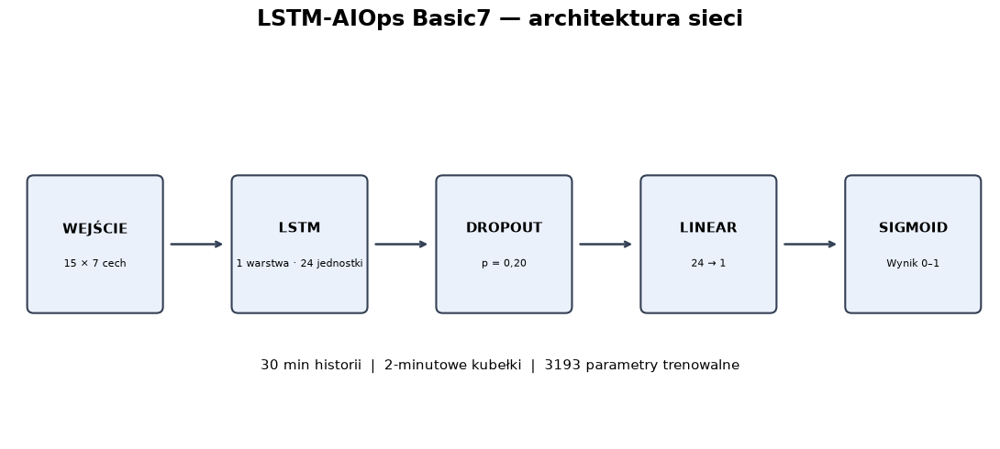

In [88]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.axis("off")

layers = [
    (0.3, "WEJŚCIE", "15 × 7 cech"),
    (2.8, "LSTM", "1 warstwa · 24 jednostki"),
    (5.3, "DROPOUT", "p = 0,20"),
    (7.8, "LINEAR", "24 → 1"),
    (10.3, "SIGMOID", "Wynik 0–1"),
]

for x, name, description in layers:

    box = FancyBboxPatch(
        (x, 1.7),
        1.5, 1.6,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="#344054",
        facecolor="#EAF1FB",
    )

    ax.add_patch(box)

    ax.text(
        x + 0.75, 2.7, name,
        ha="center", va="center",
        fontsize=11, fontweight="bold",
    )

    ax.text(
        x + 0.75, 2.25, description,
        ha="center", va="center",
        fontsize=8,
        wrap=True,
    )

for x in [1.95, 4.45, 6.95, 9.45]:
    ax.annotate(
        "",
        xy=(x + 0.7, 2.5),
        xytext=(x, 2.5),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.8,
            color="#344054",
        ),
    )

ax.set_title(
    "LSTM-AIOps Basic7 — architektura sieci",
    fontsize=17, fontweight="bold", pad=18,
)

ax.text(
    6, 0.9,
    "30 min historii  |  2-minutowe kubełki  |  "
    "3193 parametry trenowalne",
    ha="center", fontsize=11,
)

fig.tight_layout()

fig.savefig(
    EXP7_ROOT / "LSTM_Basic7_architektura.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    EXP7_ROOT / "LSTM_Basic7_architektura.svg",
    bbox_inches="tight",
)

plt.show()


MODEL: Basic7_LocalZ
 1/11  scenario1 | TP= 2 FP=  0 FN= 4 MCC=0.569
 2/11  scenario2 | TP= 0 FP=  0 FN= 6 MCC=0.000
 3/11  scenario3 | TP= 1 FP=  2 FN= 5 MCC=0.218
 4/11  scenario4 | TP= 0 FP=  1 FN= 6 MCC=-0.013
 5/11  scenario5 | TP= 6 FP=  0 FN= 1 MCC=0.922
 6/11  scenario6 | TP= 7 FP=  1 FN= 0 MCC=0.931
 7/11  scenario7 | TP= 0 FP=  0 FN= 6 MCC=0.000
 8/11  scenario8 | TP= 4 FP= 10 FN= 2 MCC=0.409
 9/11  scenario9 | TP= 4 FP=  0 FN= 2 MCC=0.809
10/11 scenario10 | TP= 0 FP=  0 FN= 9 MCC=0.000
11/11 scenario11 | TP= 9 FP=  4 FN= 1 MCC=0.769

=== WYNIKI GLOBALNE: Basic7_LocalZ ===


,model,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,Basic7_LocalZ,7,7,0.5143,0.5238,0.6471,0.44,33,18,42,1431



=== WYNIKI SCENARIUSZY ===


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,0.5694,0.5000,2,0,4,143
1,scenario2,0.0000,0.0000,0,0,6,143
2,scenario3,0.2182,0.2222,1,2,5,178
3,scenario4,-0.0134,0.0000,0,1,6,179
4,scenario5,0.9222,0.9231,6,0,1,127
5,scenario6,0.9305,0.9333,7,1,0,95
6,scenario7,0.0000,0.0000,0,0,6,149
7,scenario8,0.4093,0.4000,4,10,2,170
8,scenario9,0.8087,0.8000,4,0,2,103
9,scenario10,0.0000,0.0000,0,0,9,35



=== KALENDARZ: Basic7_LocalZ ===


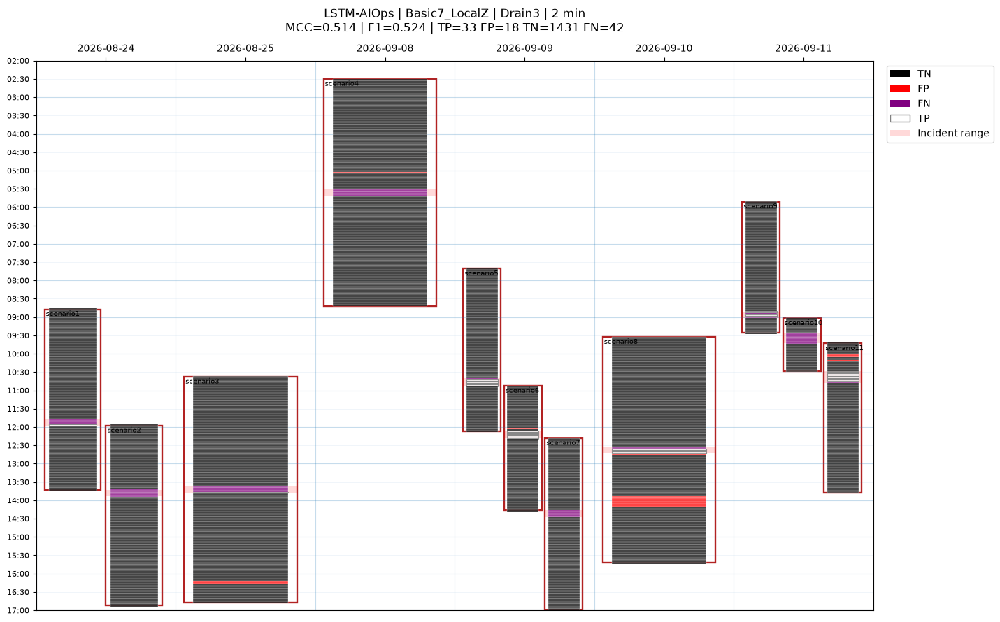


MODEL: Basic7_LogLocalZ
 1/11  scenario1 | TP= 3 FP=  0 FN= 3 MCC=0.700
 2/11  scenario2 | TP= 0 FP=  0 FN= 6 MCC=0.000
 3/11  scenario3 | TP= 0 FP=  2 FN= 6 MCC=-0.019
 4/11  scenario4 | TP= 0 FP=  2 FN= 6 MCC=-0.019
 5/11  scenario5 | TP= 7 FP=  0 FN= 0 MCC=1.000
 6/11  scenario6 | TP= 7 FP=  1 FN= 0 MCC=0.931
 7/11  scenario7 | TP= 0 FP=  0 FN= 6 MCC=0.000
 8/11  scenario8 | TP= 5 FP=  7 FN= 1 MCC=0.571
 9/11  scenario9 | TP= 4 FP=  0 FN= 2 MCC=0.809
10/11 scenario10 | TP= 0 FP=  0 FN= 9 MCC=0.000
11/11 scenario11 | TP= 8 FP=  0 FN= 2 MCC=0.887

=== WYNIKI GLOBALNE: Basic7_LogLocalZ ===


,model,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,Basic7_LogLocalZ,7,6,0.5627,0.562,0.7391,0.4533,34,12,41,1437



=== WYNIKI SCENARIUSZY ===


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,0.6998,0.6667,3,0,3,143
1,scenario2,0.0000,0.0000,0,0,6,143
2,scenario3,-0.0190,0.0000,0,2,6,178
3,scenario4,-0.0190,0.0000,0,2,6,178
4,scenario5,1.0000,1.0000,7,0,0,127
5,scenario6,0.9305,0.9333,7,1,0,95
6,scenario7,0.0000,0.0000,0,0,6,149
7,scenario8,0.5714,0.5556,5,7,1,173
8,scenario9,0.8087,0.8000,4,0,2,103
9,scenario10,0.0000,0.0000,0,0,9,35



=== KALENDARZ: Basic7_LogLocalZ ===


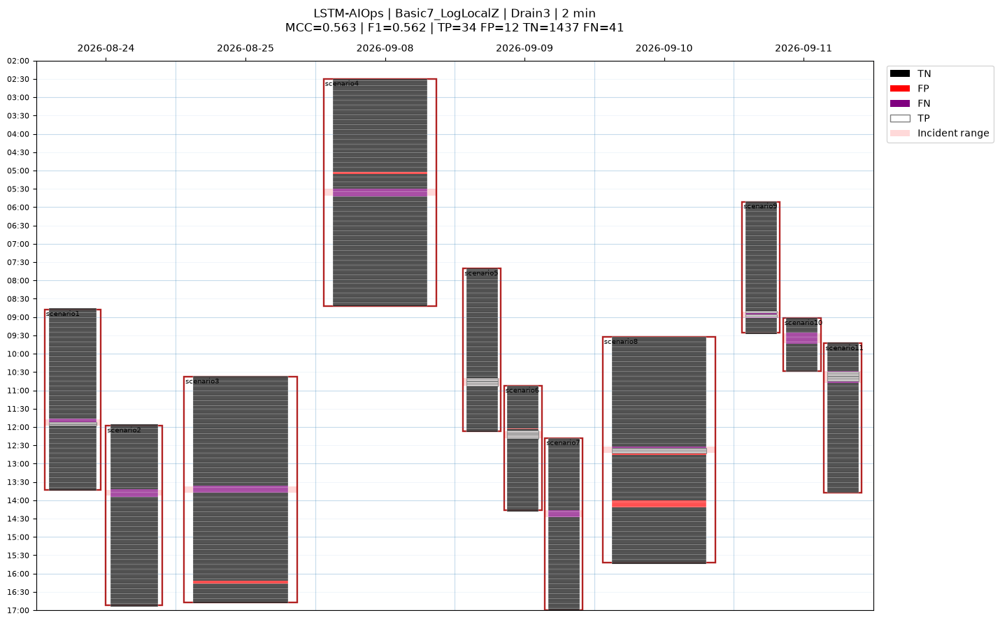


=== PORÓWNANIE KOŃCOWE ===


,model,features,MCC,F1,TP,FP,FN,TN
4,Basic7_LogLocalZ,7,0.5627,0.5620,34,12,41,1437
2,LSTM_Temporal18,18,0.5238,0.5455,39,29,36,1420
3,Basic7_LocalZ,7,0.5143,0.5238,33,18,42,1431
1,Basic7_Log,7,0.1984,0.2396,26,116,49,1333
0,Basic7_Standard,7,0.1765,0.2202,24,119,51,1330



Wyniki zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\LSTM_Basic7_LocalZ


In [89]:
import gc
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, matthews_corrcoef
)

# ==========================================================
# 1. USTAWIENIA
# ==========================================================

BASIC7_Z = list(BASIC_FEATURES)
assert len(BASIC7_Z) == 7

Z_VARIANTS = {
    "Basic7_LocalZ": False,
    "Basic7_LogLocalZ": True,
}

COUNT_COLS = [
    "total_logs",
    "unique_templates",
    "single_occurrence_templates",
]

Z_HISTORY = 15        # 15 POPRZEDNICH kubełków (30 minut)
Z_MIN_HISTORY = 5     # minimum 5 poprzednich kubełków
Z_LIMIT = 5.0         # ograniczenie lokalnego z-score

SEQ_LEN = 15          # bieżący + 14 wcześniejszych
HIDDEN = 24
EPOCHS = 25
BATCH_SIZE = 64
POS_WEIGHT = 2.0
SEED = 42

DEVICE_Z = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

Z_ROOT = PREP_DIR / "nn_loso" / "LSTM_Basic7_LocalZ"
Z_PRED_DIR = Z_ROOT / "predictions"
Z_MODEL_DIR = Z_ROOT / "models"
Z_REPORT_DIR = Z_ROOT / "reports"

for folder in [Z_PRED_DIR, Z_MODEL_DIR, Z_REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ==========================================================
# 2. DANE
# ==========================================================

frames = []

for case in SCENARIOS:
    path = BUCKET_DIR / f"Drain3__{case}__2min.joblib"

    frame = joblib.load(path).copy()
    frame["case"] = case

    for col in ["timestamp", "bucket_end"]:
        frame[col] = pd.to_datetime(frame[col], utc=True)

    frames.append(frame)

Z_DATA = (
    pd.concat(frames, ignore_index=True)
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
)

Z_Y = Z_DATA["label_primary"].astype(int).to_numpy()
Z_CASES = Z_DATA["case"].astype(str).to_numpy()

if len(Z_DATA) != 1524 or int(Z_Y.sum()) != 75:
    raise RuntimeError(
        "Zmieniono dane lub etykiety względem "
        "poprzedniego eksperymentu."
    )

Z_RAW = (
    Z_DATA[BASIC7_Z]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# Oddzielamy ciągłe fragmenty danych, aby historia
# nie przechodziła przez ewentualne luki czasowe.
new_run = (
    Z_DATA["case"].ne(Z_DATA["case"].shift())
    | Z_DATA["timestamp"].diff().ne(pd.Timedelta("2min"))
)

Z_DATA["run_id"] = new_run.cumsum()

# ==========================================================
# 3. SIEĆ — DOKŁADNIE TA SAMA ARCHITEKTURA BASIC7
# ==========================================================

class LocalZLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=7,
            hidden_size=HIDDEN,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(0.20)
        self.output = nn.Linear(HIDDEN, 1)

    def forward(self, x):
        sequence, _ = self.lstm(x)
        return self.output(
            self.dropout(sequence[:, -1, :])
        ).squeeze(-1)


def make_z_sequences(scaled):
    result = np.zeros(
        (len(Z_DATA), SEQ_LEN, 7),
        dtype=np.float32
    )

    for _, positions in Z_DATA.groupby(
        "run_id", sort=False
    ).indices.items():

        positions = np.asarray(positions)

        for j, position in enumerate(positions):
            history = positions[
                max(0, j - SEQ_LEN + 1):j + 1
            ]

            result[
                position, -len(history):, :
            ] = scaled[history]

    return result


def score_z(actual, prediction):
    tn, fp, fn, tp = confusion_matrix(
        actual, prediction, labels=[0, 1]
    ).ravel()

    return {
        "MCC": float(matthews_corrcoef(actual, prediction)),
        "F1": float(f1_score(
            actual, prediction, zero_division=0
        )),
        "precision": float(precision_score(
            actual, prediction, zero_division=0
        )),
        "recall": float(recall_score(
            actual, prediction, zero_division=0
        )),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


# ==========================================================
# 4. KALENDARZ
# ==========================================================

Z_CALENDAR = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day", "scenario_start", "scenario_end",
    "incident_start", "incident_end",
]:
    Z_CALENDAR[col] = (
        pd.to_datetime(Z_CALENDAR[col], utc=True)
        .dt.tz_localize(None)
    )

# ==========================================================
# 5. TRENING LOSO
# ==========================================================

Z_GLOBAL_RESULTS = []
Z_CASE_RESULTS = []

for variant, log_counts in Z_VARIANTS.items():

    base = Z_RAW.copy()

    if log_counts:
        for feature in COUNT_COLS:
            if (base[feature] < 0).any():
                raise ValueError(
                    f"Ujemny licznik: {feature}"
                )
            base[feature] = np.log1p(base[feature])

    # Historyczne średnie i odchylenia.
    # Dla każdego kubełka wyłącznie wcześniejsze dane.
    past_mean = pd.DataFrame(index=base.index)
    past_std = pd.DataFrame(index=base.index)

    for feature in BASIC7_Z:

        previous = base[feature].groupby(
            Z_DATA["run_id"], sort=False
        ).shift(1)

        groups = previous.groupby(
            Z_DATA["run_id"], sort=False
        )

        past_mean[feature] = groups.transform(
            lambda s: s.rolling(
                Z_HISTORY,
                min_periods=Z_MIN_HISTORY,
            ).mean()
        )

        past_std[feature] = groups.transform(
            lambda s: s.rolling(
                Z_HISTORY,
                min_periods=Z_MIN_HISTORY,
            ).std(ddof=0)
        )

    all_pred = np.full(len(Z_DATA), -1, dtype=int)
    all_prob = np.full(len(Z_DATA), np.nan)
    current_rows = []

    print("\n" + "=" * 72)
    print("MODEL:", variant)
    print("=" * 72, flush=True)

    for fold, test_case in enumerate(SCENARIOS, 1):

        train_idx = np.flatnonzero(Z_CASES != test_case)
        test_idx = np.flatnonzero(Z_CASES == test_case)

        # ----------------------------------------------
        # LOKALNE Z-SCORE DLA SIEDMIU CECH
        # ----------------------------------------------

        X_local = np.zeros(
            (len(Z_DATA), 7),
            dtype=np.float32
        )

        sigma_floors = {}

        for j, feature in enumerate(BASIC7_Z):

            # Minimalna skala ustalana TYLKO
            # z dziesięciu scenariuszy treningowych.
            train_std = float(
                base[feature].iloc[train_idx].std(ddof=0)
            )

            sigma_floor = max(
                0.05 * train_std, 1e-6
            )

            sigma_floors[feature] = sigma_floor

            denominator = np.maximum(
                past_std[feature].to_numpy(dtype=float),
                sigma_floor,
            )

            z = (
                base[feature].to_numpy(dtype=float)
                - past_mean[feature].to_numpy(dtype=float)
            ) / denominator

            # Początek scenariusza bez wystarczającej
            # historii: neutralny lokalny z-score.
            z[~np.isfinite(z)] = 0.0

            X_local[:, j] = np.clip(
                z, -Z_LIMIT, Z_LIMIT
            )

        # Dodatkowe skalowanie między cechami:
        # wyłącznie na zbiorze treningowym.
        scaler = StandardScaler()
        scaler.fit(X_local[train_idx])

        scaled = scaler.transform(
            X_local
        ).astype(np.float32)

        scaled = np.clip(scaled, -3.0, 3.0)

        sequences = make_z_sequences(scaled)

        # ----------------------------------------------
        # MODELOWANIE
        # ----------------------------------------------

        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        if DEVICE_Z.type == "cuda":
            torch.cuda.manual_seed_all(SEED)

        model = LocalZLSTM().to(DEVICE_Z)

        optimizer = torch.optim.Adam(
            model.parameters(), lr=0.001
        )

        loss_fn = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                POS_WEIGHT,
                dtype=torch.float32,
                device=DEVICE_Z,
            )
        )

        x_train = torch.from_numpy(
            sequences[train_idx]
        ).to(DEVICE_Z)

        y_train = torch.from_numpy(
            Z_Y[train_idx].astype(np.float32)
        ).to(DEVICE_Z)

        for epoch in range(EPOCHS):

            model.train()

            order = torch.randperm(
                len(train_idx),
                device=DEVICE_Z,
            )

            for batch in order.split(BATCH_SIZE):

                optimizer.zero_grad(set_to_none=True)

                loss = loss_fn(
                    model(x_train[batch]),
                    y_train[batch],
                )

                loss.backward()
                optimizer.step()

        model.eval()

        with torch.no_grad():
            x_test = torch.from_numpy(
                sequences[test_idx]
            ).to(DEVICE_Z)

            probabilities = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

        predictions = (probabilities >= 0.50).astype(int)

        all_pred[test_idx] = predictions
        all_prob[test_idx] = probabilities

        metrics = score_z(
            Z_Y[test_idx], predictions
        )

        row = {
            "model": variant,
            "case": test_case,
            **metrics,
        }

        current_rows.append(row)
        Z_CASE_RESULTS.append(row)

        # ----------------------------------------------
        # ZAPIS
        # ----------------------------------------------

        pred_df = Z_DATA.iloc[test_idx][[
            "case", "timestamp", "bucket_end",
            "label_primary", "label_all_known",
        ]].copy()

        pred_df["prediction"] = predictions
        pred_df["probability"] = probabilities

        joblib.dump(
            {"data": pred_df, "metrics": metrics},
            Z_PRED_DIR / f"{variant}__{test_case}.joblib",
            compress=3,
        )

        torch.save(
            {
                "state_dict": {
                    k: v.detach().cpu()
                    for k, v in model.state_dict().items()
                },
                "features": BASIC7_Z,
                "log_counts": log_counts,
                "history": Z_HISTORY,
                "min_history": Z_MIN_HISTORY,
                "z_limit": Z_LIMIT,
                "sigma_floors": sigma_floors,
                "scaler_mean": scaler.mean_,
                "scaler_scale": scaler.scale_,
                "sequence_length": SEQ_LEN,
                "hidden_size": HIDDEN,
                "threshold": 0.50,
            },
            Z_MODEL_DIR / f"{variant}__{test_case}.pt",
        )

        print(
            f"{fold:2d}/11 {test_case:>10} | "
            f"TP={metrics['TP']:2d} "
            f"FP={metrics['FP']:3d} "
            f"FN={metrics['FN']:2d} "
            f"MCC={metrics['MCC']:.3f}",
            flush=True,
        )

        del (
            model, optimizer, x_train, y_train,
            x_test, sequences, scaled, X_local
        )

        if DEVICE_Z.type == "cuda":
            torch.cuda.empty_cache()

        gc.collect()

    # ======================================================
    # 6. METRYKI PO KAŻDYM WARIANCIE
    # ======================================================

    if (all_pred < 0).any():
        raise RuntimeError("Niepełne predykcje LOSO")

    overall = score_z(Z_Y, all_pred)

    global_row = {
        "model": variant,
        "features": 7,
        "detected_scenarios": sum(
            r["TP"] > 0 for r in current_rows
        ),
        **overall,
    }

    Z_GLOBAL_RESULTS.append(global_row)

    print(f"\n=== WYNIKI GLOBALNE: {variant} ===")
    display(pd.DataFrame([global_row]).round(4))

    print("\n=== WYNIKI SCENARIUSZY ===")
    display(
        pd.DataFrame(current_rows)[[
            "case", "MCC", "F1",
            "TP", "FP", "FN", "TN",
        ]].round(4)
    )

    pd.DataFrame(Z_GLOBAL_RESULTS).to_csv(
        Z_REPORT_DIR / "overall_results.csv",
        index=False,
    )

    pd.DataFrame(Z_CASE_RESULTS).to_csv(
        Z_REPORT_DIR / "scenario_results.csv",
        index=False,
    )

    # ======================================================
    # 7. KALENDARZ
    # ======================================================

    plot_df = Z_DATA[[
        "case", "timestamp", "bucket_end",
        "label_primary", "label_all_known",
    ]].copy()

    plot_df["prediction"] = all_pred
    plot_df["probability"] = all_prob

    actual = plot_df["label_primary"].astype(int)

    plot_df["outcome"] = np.select(
        [
            (actual == 1) & (all_pred == 1),
            (actual == 0) & (all_pred == 1),
            (actual == 1) & (all_pred == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    for col in ["timestamp", "bucket_end"]:
        plot_df[col] = (
            pd.to_datetime(plot_df[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"LSTM-AIOps | {variant} | Drain3 | 2 min\n"
        f"MCC={overall['MCC']:.3f} | "
        f"F1={overall['F1']:.3f} | "
        f"TP={overall['TP']} "
        f"FP={overall['FP']} "
        f"TN={overall['TN']} "
        f"FN={overall['FN']}"
    )

    print(f"\n=== KALENDARZ: {variant} ===")

    plot_calendar_with_buckets(
        calendar_segments=Z_CALENDAR,
        bucket_df=plot_df,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

    del base, past_mean, past_std, all_pred, all_prob
    gc.collect()


# ==========================================================
# 8. KOŃCOWE PORÓWNANIE
# ==========================================================

Z_RESULTS = pd.DataFrame(Z_GLOBAL_RESULTS)

previous = pd.DataFrame([
    {
        "model": "Basic7_Standard",
        "features": 7,
        "MCC": 0.1765,
        "F1": 0.2202,
        "TP": 24, "FP": 119,
        "FN": 51, "TN": 1330,
    },
    {
        "model": "Basic7_Log",
        "features": 7,
        "MCC": 0.1984,
        "F1": 0.2396,
        "TP": 26, "FP": 116,
        "FN": 49, "TN": 1333,
    },
    {
        "model": "LSTM_Temporal18",
        "features": 18,
        "MCC": 0.5238,
        "F1": 0.5455,
        "TP": 39, "FP": 29,
        "FN": 36, "TN": 1420,
    },
])

comparison = pd.concat(
    [previous, Z_RESULTS],
    ignore_index=True,
)

print("\n=== PORÓWNANIE KOŃCOWE ===")

display(
    comparison[
        [
            "model", "features",
            "MCC", "F1",
            "TP", "FP", "FN", "TN",
        ]
    ]
    .sort_values("MCC", ascending=False)
    .round(4)
)

print("\nWyniki zapisano w:", Z_ROOT)

In [92]:
import inspect
import joblib
import numpy as np
import pandas as pd
from IPython.display import display

CASES_TO_ANALYZE = [
    "scenario4", "scenario5", "scenario6",
    "scenario7", "scenario9", "scenario11",
]

PREDICTIONS_DIR = (
    PREP_DIR / "nn_loso"
    / "LSTM_Basic7_LocalZ" / "predictions"
)

# Sprawdzenie sygnatury, gdyby loader wymagał korekty.
print("Loader:", inspect.signature(get_parsed_dataframe))

def load_parsed_logs(case):
    return get_parsed_dataframe("Drain3", case)


TEMPLATE_RESULTS = []
COVERAGE_RESULTS = []

for case in CASES_TO_ANALYZE:

    print("\n" + "=" * 75)
    print("SCENARIUSZ:", case)
    print("=" * 75)

    # ------------------------------------------------------
    # KUBEŁKI Z ETYKIETAMI
    # ------------------------------------------------------

    buckets = joblib.load(
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    ).copy()

    predictions = joblib.load(
        PREDICTIONS_DIR
        / f"Basic7_LocalZ__{case}.joblib"
    )["data"].copy()

    for frame in [buckets, predictions]:
        frame["timestamp"] = pd.to_datetime(
            frame["timestamp"], utc=True
        )

    buckets["bucket_end"] = pd.to_datetime(
        buckets["bucket_end"], utc=True
    )

    buckets = buckets.merge(
        predictions[["timestamp", "prediction"]],
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )

    buckets["label_primary"] = (
        buckets["label_primary"].astype(int)
    )
    buckets["prediction"] = (
        buckets["prediction"].astype(int)
    )

    n_inc = int(buckets["label_primary"].sum())
    n_normal = int(len(buckets) - n_inc)

    # ------------------------------------------------------
    # SPARSOWANE LOGI DRAIN3
    # ------------------------------------------------------

    parsed = load_parsed_logs(case)

    required = {"timestamp", "template_id"}
    missing = required - set(parsed.columns)

    if missing:
        raise ValueError(
            f"{case}: brak kolumn {missing}. "
            f"Dostępne: {list(parsed.columns)}"
        )

    logs = parsed[["timestamp", "template_id"]].copy()

    logs["timestamp"] = pd.to_datetime(
        logs["timestamp"],
        utc=True,
        errors="coerce",
    )

    logs = logs.dropna(
        subset=["timestamp", "template_id"]
    ).copy()

    # Zachowujemy pełny identyfikator, również namespace.
    logs["template_key"] = logs["template_id"].map(repr)

    # ------------------------------------------------------
    # PRZYPISANIE LOGÓW DO DWUMINUTOWYCH KUBEŁKÓW
    # ------------------------------------------------------

    bucket_intervals = buckets[[
        "timestamp",
        "bucket_end",
        "label_primary",
        "prediction",
    ]].rename(
        columns={"timestamp": "bucket_start"}
    )

    matched = pd.merge_asof(
        logs[["timestamp", "template_key"]]
        .sort_values("timestamp"),

        bucket_intervals.sort_values("bucket_start"),

        left_on="timestamp",
        right_on="bucket_start",
        direction="backward",
    )

    matched = matched[
        matched["bucket_end"].notna()
        & (matched["timestamp"] < matched["bucket_end"])
    ].copy()

    print(
        f"Logi przypisane do kubełków: "
        f"{len(matched):,}/{len(logs):,}"
    )

    if matched.empty:
        raise RuntimeError(
            f"{case}: żaden log nie trafił do kubełków. "
            "Sprawdź znaczenie kolumn timestamp i bucket_end."
        )

    # ------------------------------------------------------
    # LICZBA WYSTĄPIEŃ SZABLONU W KAŻDYM KUBEŁKU
    # ------------------------------------------------------

    per_bucket = (
        matched.groupby(
            [
                "template_key",
                "bucket_start",
                "label_primary",
                "prediction",
            ],
            as_index=False,
        )
        .size()
        .rename(columns={"size": "log_count"})
    )

    per_bucket["inc_logs"] = np.where(
        per_bucket["label_primary"] == 1,
        per_bucket["log_count"],
        0,
    )

    per_bucket["normal_logs"] = np.where(
        per_bucket["label_primary"] == 0,
        per_bucket["log_count"],
        0,
    )

    per_bucket["inc_bucket"] = (
        per_bucket["label_primary"] == 1
    ).astype(int)

    per_bucket["normal_bucket"] = (
        per_bucket["label_primary"] == 0
    ).astype(int)

    per_bucket["TP_bucket"] = (
        (per_bucket["label_primary"] == 1)
        & (per_bucket["prediction"] == 1)
    ).astype(int)

    per_bucket["FN_bucket"] = (
        (per_bucket["label_primary"] == 1)
        & (per_bucket["prediction"] == 0)
    ).astype(int)

    # ------------------------------------------------------
    # STATYSTYKI SZABLONÓW
    # ------------------------------------------------------

    stats = (
        per_bucket.groupby("template_key", as_index=False)
        .agg(
            incident_logs=("inc_logs", "sum"),
            normal_logs=("normal_logs", "sum"),
            incident_buckets=("inc_bucket", "sum"),
            normal_buckets=("normal_bucket", "sum"),
            TP_buckets=("TP_bucket", "sum"),
            FN_buckets=("FN_bucket", "sum"),
        )
    )

    stats["case"] = case

    stats["incident_coverage"] = (
        stats["incident_buckets"] / n_inc
    )

    stats["normal_coverage"] = (
        stats["normal_buckets"] / n_normal
    )

    # Wygładzony stosunek częstości występowania
    # w kubełkach incydentowych i normalnych.
    stats["coverage_lift"] = (
        (stats["incident_buckets"] + 0.5)
        / (n_inc + 1)
    ) / (
        (stats["normal_buckets"] + 0.5)
        / (n_normal + 1)
    )

    TEMPLATE_RESULTS.append(stats)

    # ------------------------------------------------------
    # SZABLONY OBECNE PODCZAS INCYDENTU,
    # NIGDY W NORMALNYCH KUBEŁKACH TEGO SCENARIUSZA
    # ------------------------------------------------------

    exclusive = stats[
        (stats["incident_buckets"] >= 2)
        & (stats["normal_buckets"] == 0)
    ].sort_values(
        ["FN_buckets", "incident_buckets"],
        ascending=False,
    )

    print("\nSZABLONY WYŁĄCZNIE W INCYDENCIE")
    print("(minimum 2 kubełki incydentowe)")

    display(
        exclusive[[
            "template_key",
            "incident_logs",
            "incident_buckets",
            "TP_buckets",
            "FN_buckets",
        ]].head(15)
    )

    # ------------------------------------------------------
    # SZABLONY NAJBARDZIEJ WZBOGACONE PODCZAS INCYDENTU
    # ------------------------------------------------------

    enriched = (
        stats[stats["incident_buckets"] >= 2]
        .sort_values(
            ["coverage_lift", "incident_buckets"],
            ascending=False,
        )
    )

    print("\nSZABLONY SILNIE ZWIĄZANE Z INCYDENTEM")

    display(
        enriched[[
            "template_key",
            "incident_buckets",
            "normal_buckets",
            "incident_coverage",
            "normal_coverage",
            "coverage_lift",
            "FN_buckets",
        ]].head(12).round(3)
    )

    COVERAGE_RESULTS.append({
        "case": case,
        "incident_buckets": n_inc,
        "normal_buckets": n_normal,
        "templates_total": len(stats),
        "exclusive_templates_2plus": len(exclusive),
        "exclusive_present_in_FN": int(
            (exclusive["FN_buckets"] > 0).sum()
        ),
    })

# ==========================================================
# PODSUMOWANIE
# ==========================================================

TEMPLATE_STATS = pd.concat(
    TEMPLATE_RESULTS,
    ignore_index=True,
)

TEMPLATE_SUMMARY = pd.DataFrame(
    COVERAGE_RESULTS
)

print("\n" + "=" * 75)
print("PODSUMOWANIE WSZYSTKICH ANALIZOWANYCH SCENARIUSZY")
print("=" * 75)

display(TEMPLATE_SUMMARY)

print("\nSZABLONY CHARAKTERYSTYCZNE DLA POMINIĘTYCH INCYDENTÓW")

display(
    TEMPLATE_STATS[
        (TEMPLATE_STATS["FN_buckets"] >= 2)
        & (TEMPLATE_STATS["normal_buckets"] == 0)
    ][[
        "case",
        "template_key",
        "incident_buckets",
        "FN_buckets",
        "incident_logs",
    ]]
    .sort_values(
        ["FN_buckets", "incident_logs"],
        ascending=False,
    )
    .head(30)
)

TEMPLATE_STATS.to_csv(
    PREP_DIR / "incident_template_diagnostics.csv",
    index=False,
)

Loader: (parser, case)

SCENARIUSZ: scenario4
Logi przypisane do kubełków: 76,732/76,732

SZABLONY WYŁĄCZNIE W INCYDENCIE
(minimum 2 kubełki incydentowe)


,template_key,incident_logs,incident_buckets,TP_buckets,FN_buckets



SZABLONY SILNIE ZWIĄZANE Z INCYDENTEM


,template_key,incident_buckets,normal_buckets,incident_coverage,normal_coverage,coverage_lift,FN_buckets
12,"('reporting', 20)",2,35,0.333,0.194,1.821,2
13,"('reporting', 21)",2,35,0.333,0.194,1.821,2
38,"('reporting', 44)",6,120,1.000,0.667,1.395,6
39,"('reporting', 45)",6,120,1.000,0.667,1.395,6
1,"('reporting', 10)",6,156,1.000,0.867,1.074,6
3,"('reporting', 12)",6,156,1.000,0.867,1.074,6
4,"('reporting', 13)",6,156,1.000,0.867,1.074,6
5,"('reporting', 14)",6,156,1.000,0.867,1.074,6
55,"('reporting', 6)",6,156,1.000,0.867,1.074,6
66,"('reporting', 8)",6,156,1.000,0.867,1.074,6



SCENARIUSZ: scenario5
Logi przypisane do kubełków: 41,251/41,251

SZABLONY WYŁĄCZNIE W INCYDENCIE
(minimum 2 kubełki incydentowe)


,template_key,incident_logs,incident_buckets,TP_buckets,FN_buckets
35,"('ingestion', 41)",424,7,6,1
37,"('ingestion', 43)",159,7,6,1
38,"('ingestion', 44)",16504,7,6,1
39,"('ingestion', 45)",2904,7,6,1
40,"('ingestion', 46)",180,7,6,1
41,"('ingestion', 47)",162,7,6,1
49,"('ingestion', 54)",114,7,6,1
15,"('ingestion', 23)",4,3,2,1
28,"('ingestion', 35)",15,3,2,1
30,"('ingestion', 37)",8,3,2,1


... (18 outputs left out)


PODSUMOWANIE WSZYSTKICH ANALIZOWANYCH SCENARIUSZY


,case,incident_buckets,normal_buckets,templates_total,exclusive_templates_2plus,exclusive_present_in_FN
0,scenario4,6,180,68,0,0
1,scenario5,7,127,73,50,40
2,scenario6,7,96,65,1,0
3,scenario7,6,149,115,11,11
4,scenario9,6,103,136,12,7
5,scenario11,10,113,486,85,11



SZABLONY CHARAKTERYSTYCZNE DLA POMINIĘTYCH INCYDENTÓW


,case,template_key,incident_buckets,FN_buckets,incident_logs
304,scenario7,"('reporting', 84)",6,6,54
298,scenario7,"('reporting', 79)",4,4,7
301,scenario7,"('reporting', 81)",4,4,7
305,scenario7,"('reporting', 85)",4,4,7
306,scenario7,"('reporting', 86)",4,4,7
307,scenario7,"('reporting', 87)",4,4,7
308,scenario7,"('reporting', 88)",4,4,7
309,scenario7,"('reporting', 89)",4,4,7
311,scenario7,"('reporting', 90)",4,4,7
312,scenario7,"('reporting', 91)",3,3,4


In [91]:
import inspect
import pandas as pd

print("Sygnatura:", inspect.signature(get_parsed_dataframe))

def load_parsed_logs(case):

    attempts = [
        ("parser, scenariusz", ("Drain3", case)),
        ("scenariusz, parser", (case, "Drain3")),
    ]

    errors = []

    for description, args in attempts:
        try:
            df = get_parsed_dataframe(*args)

            if not isinstance(df, pd.DataFrame):
                raise TypeError(
                    f"Loader zwrócił {type(df)}, nie DataFrame"
                )

            required = {"timestamp", "template_id"}
            missing = required - set(df.columns)

            if missing:
                raise ValueError(
                    f"Brak kolumn {missing}; "
                    f"dostępne: {list(df.columns)}"
                )

            print(
                f"OK: {case} | kolejność: {description} | "
                f"logów: {len(df):,}"
            )

            return df

        except (FileNotFoundError, TypeError, ValueError) as exc:
            errors.append(f"{description}: {exc}")

    raise RuntimeError(
        f"Nie udało się wczytać {case}.\n"
        + "\n".join(errors)
    )


# Test przed uruchomieniem pełnej analizy.
test_logs = load_parsed_logs("scenario4")

print("\nKolumny:", list(test_logs.columns))
print("Przykładowe identyfikatory szablonów:")
print(test_logs["template_id"].head(5).tolist())

Sygnatura: (parser, case)
OK: scenario4 | kolejność: parser, scenariusz | logów: 76,732

Kolumny: ['timestamp', 'message', 'namespace', 'template_id']
Przykładowe identyfikatory szablonów:
[('reporting', 1), ('reporting', 2), ('reporting', 2), ('reporting', 2), ('reporting', 2)]



scenario4


,feature,normal_median,normal_p95,normal_max,incident_median,incident_max,incident_above_normal_p95
0,new_templates,0.0,2.0,18.0,0.0,1.0000,0
1,young_templates_30m,0.0,18.0,20.0,0.0,1.0000,0
2,young_log_share_30m,0.0,1.0,1.0,0.0,0.0091,0



CECHY W KUBEŁKACH INCYDENTOWYCH:


C:\Users\kzieba\AppData\Local\Temp\ipykernel_12104\2418382833.py:154: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,timestamp,new_templates,young_templates_30m,young_log_share_30m
90,2026-09-08 05:30:00+00:00,0,0,0.0000
91,2026-09-08 05:32:00+00:00,0,0,0.0000
92,2026-09-08 05:34:00+00:00,1,1,0.0091
93,2026-09-08 05:36:00+00:00,0,0,0.0000
94,2026-09-08 05:38:00+00:00,0,0,0.0000
95,2026-09-08 05:40:00+00:00,0,0,0.0000


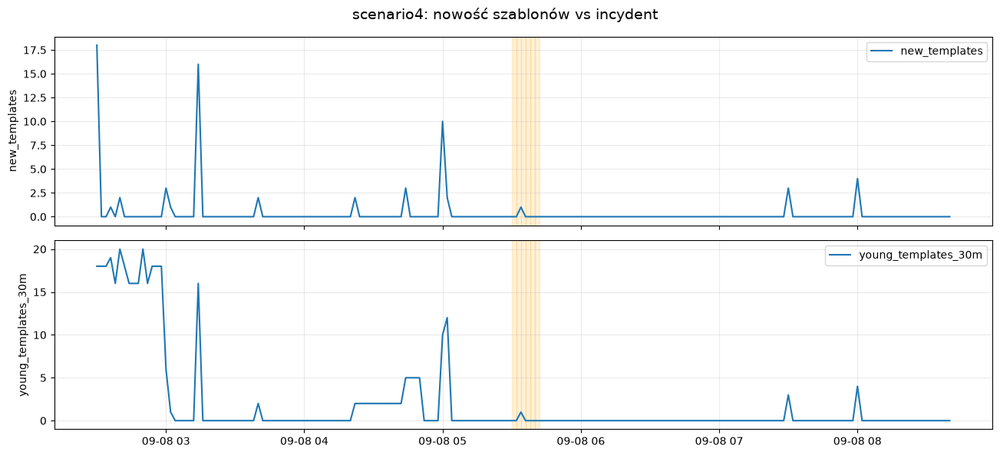


scenario6


,feature,normal_median,normal_p95,normal_max,incident_median,incident_max,incident_above_normal_p95
0,new_templates,0.0,2.0,19.0,0.0000,1.0000,0
1,young_templates_30m,0.0,20.5,36.0,1.0000,1.0000,0
2,young_log_share_30m,0.0,1.0,1.0,0.9938,0.9968,0



CECHY W KUBEŁKACH INCYDENTOWYCH:


C:\Users\kzieba\AppData\Local\Temp\ipykernel_12104\2418382833.py:154: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,timestamp,new_templates,young_templates_30m,young_log_share_30m
37,2026-09-09 12:06:00+00:00,1,1,0.9938
38,2026-09-09 12:08:00+00:00,0,1,0.9968
39,2026-09-09 12:10:00+00:00,0,1,0.9967
40,2026-09-09 12:12:00+00:00,0,1,0.9967
41,2026-09-09 12:14:00+00:00,0,1,0.9931
42,2026-09-09 12:16:00+00:00,0,1,0.9936
43,2026-09-09 12:18:00+00:00,0,0,0.0000


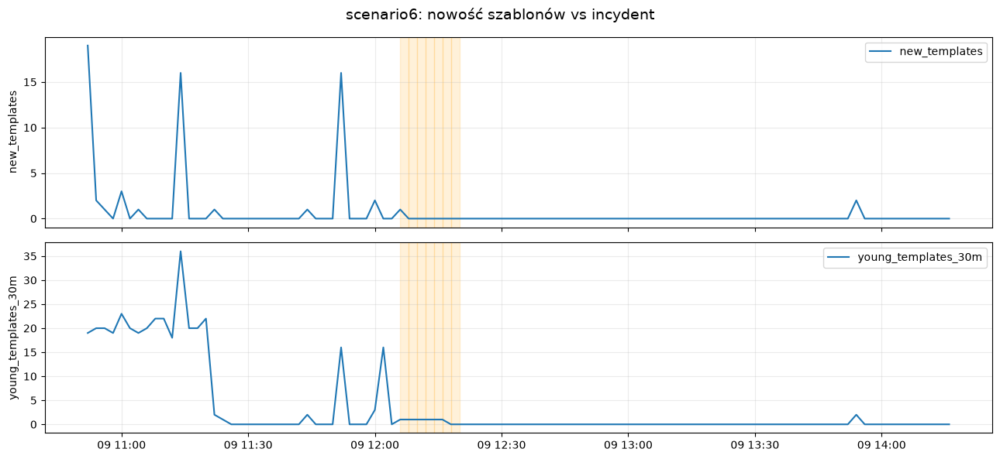


scenario7


,feature,normal_median,normal_p95,normal_max,incident_median,incident_max,incident_above_normal_p95
0,new_templates,0.0,1.6,32.0,2.0000,29.0000,3
1,young_templates_30m,0.0,12.6,32.0,10.0000,29.0000,2
2,young_log_share_30m,0.0,1.0,1.0,0.1058,0.3855,0



CECHY W KUBEŁKACH INCYDENTOWYCH:


C:\Users\kzieba\AppData\Local\Temp\ipykernel_12104\2418382833.py:154: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,timestamp,new_templates,young_templates_30m,young_log_share_30m
59,2026-09-09 14:16:00+00:00,29,29,0.3404
60,2026-09-09 14:18:00+00:00,0,10,0.1017
61,2026-09-09 14:20:00+00:00,14,24,0.3855
62,2026-09-09 14:22:00+00:00,0,10,0.1098
63,2026-09-09 14:24:00+00:00,0,1,0.0488
64,2026-09-09 14:26:00+00:00,4,6,0.0599


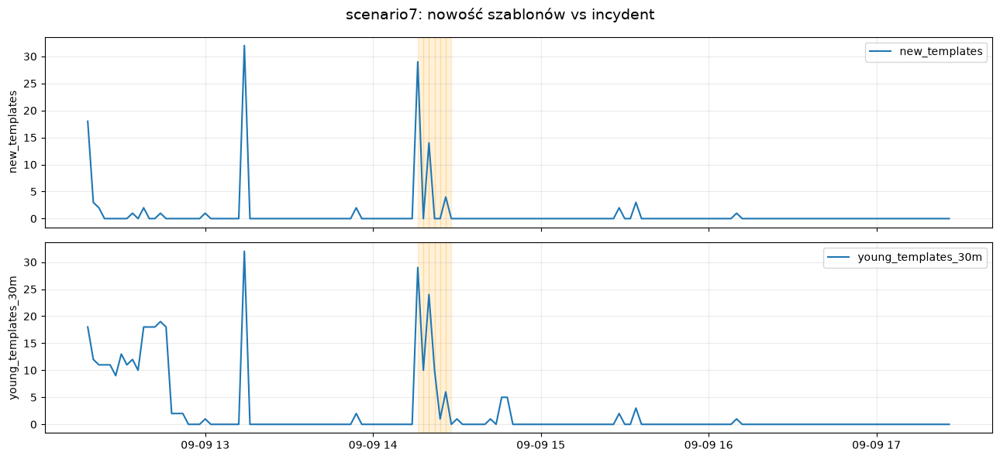

In [93]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

NOVELTY_CASES = ["scenario4", "scenario6", "scenario7"]
NOVELTY_RESULTS = []

for case in NOVELTY_CASES:

    # Oryginalne, niefiltrowane logi Drain3.
    logs = get_parsed_dataframe("Drain3", case)[
        ["timestamp", "template_id"]
    ].copy()

    logs["timestamp"] = pd.to_datetime(
        logs["timestamp"], utc=True
    )
    logs["template_key"] = logs["template_id"].map(repr)

    buckets = joblib.load(
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    ).copy()

    for col in ["timestamp", "bucket_end"]:
        buckets[col] = pd.to_datetime(
            buckets[col], utc=True
        )

    # Przypisanie logów do przedziałów [start, end).
    intervals = buckets[
        ["timestamp", "bucket_end", "label_primary"]
    ].rename(columns={"timestamp": "bucket_start"})

    matched = pd.merge_asof(
        logs[["timestamp", "template_key"]]
            .sort_values("timestamp"),
        intervals.sort_values("bucket_start"),
        left_on="timestamp",
        right_on="bucket_start",
        direction="backward",
    )

    matched = matched[
        matched["bucket_end"].notna()
        & (matched["timestamp"] < matched["bucket_end"])
    ].copy()

    assert len(matched) == len(logs), (
        f"{case}: nie wszystkie logi przypisano"
    )

    # Liczba logów danego szablonu w danym kubełku.
    occurrences = (
        matched.groupby(
            ["bucket_start", "template_key"],
            as_index=False,
        )
        .size()
        .rename(columns={"size": "template_logs"})
        .sort_values(["template_key", "bucket_start"])
        .reset_index(drop=True)
    )

    # Pierwsza obserwacja szablonu.
    # To można obliczać przyczynowo w trakcie napływu logów.
    first_seen = occurrences.groupby(
        "template_key"
    )["bucket_start"].transform("min")

    age = occurrences["bucket_start"] - first_seen

    occurrences["new_template"] = (
        age == pd.Timedelta(0)
    ).astype(int)

    occurrences["young_template_30m"] = (
        age < pd.Timedelta("30min")
    ).astype(int)

    occurrences["young_logs"] = (
        occurrences["template_logs"]
        * occurrences["young_template_30m"]
    )

    # Agregacja na poziom kubełka.
    features = occurrences.groupby("bucket_start").agg(
        new_templates=("new_template", "sum"),
        young_templates_30m=("young_template_30m", "sum"),
        young_logs=("young_logs", "sum"),
        total_logs=("template_logs", "sum"),
    )

    features["young_log_share_30m"] = (
        features["young_logs"]
        / features["total_logs"].clip(lower=1)
    )

    result = buckets.merge(
        features[
            [
                "new_templates",
                "young_templates_30m",
                "young_log_share_30m",
            ]
        ],
        left_on="timestamp",
        right_index=True,
        how="left",
        validate="one_to_one",
    )

    feature_cols = [
        "new_templates",
        "young_templates_30m",
        "young_log_share_30m",
    ]

    result[feature_cols] = result[feature_cols].fillna(0)
    result["case"] = case

    NOVELTY_RESULTS.append(result)

    print("\n" + "=" * 75)
    print(case)
    print("=" * 75)

    normal = result[result["label_primary"] == 0]
    incident = result[result["label_primary"] == 1]

    comparison = []

    for feature in feature_cols:
        comparison.append({
            "feature": feature,
            "normal_median": normal[feature].median(),
            "normal_p95": normal[feature].quantile(0.95),
            "normal_max": normal[feature].max(),
            "incident_median": incident[feature].median(),
            "incident_max": incident[feature].max(),
            "incident_above_normal_p95": int(
                (incident[feature] >
                 normal[feature].quantile(0.95)).sum()
            ),
        })

    display(pd.DataFrame(comparison).round(4))

    print("\nCECHY W KUBEŁKACH INCYDENTOWYCH:")
    display(
        incident[
            ["timestamp"] + feature_cols
        ].round(4)
    )

    # Wykres: czas a liczba nowych/niedawnych szablonów.
    fig, axes = plt.subplots(
        2, 1, figsize=(13, 6), sharex=True
    )

    for ax, feature in zip(
        axes,
        ["new_templates", "young_templates_30m"]
    ):
        ax.plot(
            result["timestamp"],
            result[feature],
            label=feature,
        )

        for _, row in incident.iterrows():
            ax.axvspan(
                row["timestamp"],
                row["bucket_end"],
                color="orange",
                alpha=0.15,
            )

        ax.set_ylabel(feature)
        ax.grid(alpha=0.25)
        ax.legend()

    fig.suptitle(
        f"{case}: nowość szablonów vs incydent",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()

NOVELTY_DATA = pd.concat(
    NOVELTY_RESULTS, ignore_index=True
)

Przygotowano scenario1: 149 kubełków, 26,858 logów
Przygotowano scenario2: 149 kubełków, 27,651 logów
Przygotowano scenario3: 186 kubełków, 57,081 logów
Przygotowano scenario4: 186 kubełków, 76,732 logów
Przygotowano scenario5: 134 kubełków, 41,251 logów
Przygotowano scenario6: 103 kubełków, 312,362 logów
Przygotowano scenario7: 155 kubełków, 27,221 logów
Przygotowano scenario8: 186 kubełków, 89,713 logów
Przygotowano scenario9: 109 kubełków, 22,788 logów
Przygotowano scenario10: 44 kubełków, 19,253 logów
Przygotowano scenario11: 123 kubełków, 154,674 logów

ARCHITEKTURA:
NoveltyLSTM(
  (lstm): LSTM(10, 24, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=24, out_features=1, bias=True)
)
Parametry trenowalne: 3481
 1/11  scenario1 | TP= 5 FP=  1 FN= 1 MCC=0.826
 2/11  scenario2 | TP= 0 FP=  0 FN= 6 MCC=0.000
 3/11  scenario3 | TP= 0 FP=  6 FN= 6 MCC=-0.033
 4/11  scenario4 | TP= 0 FP=  2 FN= 6 MCC=-0.019
 5/11  scenario5 | TP= 7 FP=  0 FN= 0 M

,model,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,LSTM_AIOps_Novelty10,10,5,0.4504,0.4755,0.5,0.4533,34,34,41,1415



=== WYNIKI SCENARIUSZY ===


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,0.8263,0.8333,5,1,1,142
1,scenario2,0.0000,0.0000,0,0,6,143
2,scenario3,-0.0333,0.0000,0,6,6,174
3,scenario4,-0.0190,0.0000,0,2,6,178
4,scenario5,1.0000,1.0000,7,0,0,127
5,scenario6,1.0000,1.0000,7,0,0,96
6,scenario7,-0.0162,0.0000,0,1,6,148
7,scenario8,-0.0412,0.0000,0,9,6,171
8,scenario9,0.9213,0.9231,6,1,0,102
9,scenario10,0.0000,0.0000,0,0,9,35


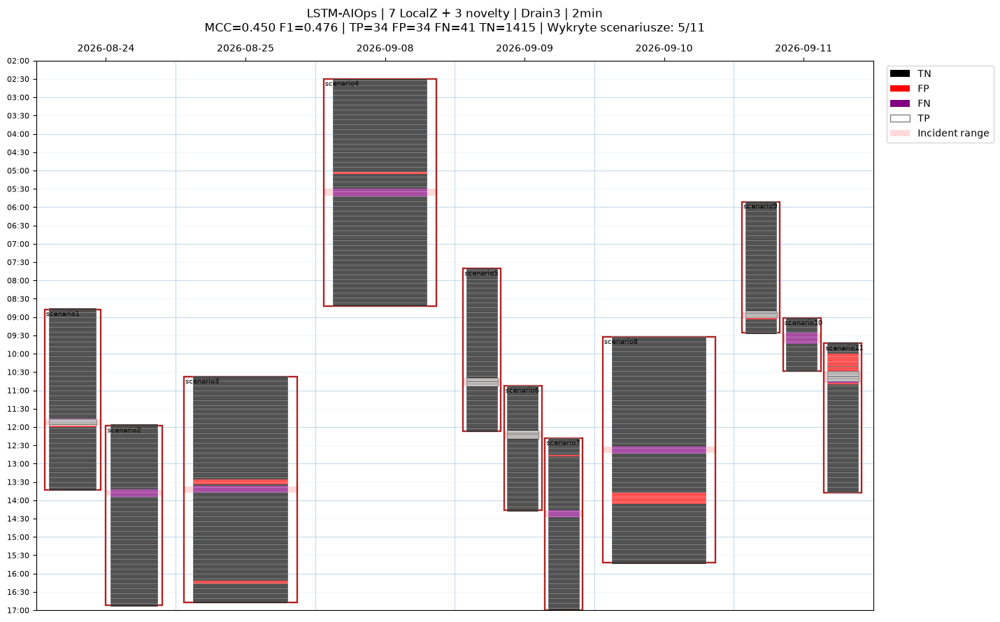


=== PORÓWNANIE MODELI ===


,model,MCC,TP,FP,FN,TN,detected_scenarios
1,LSTM_Temporal18,0.5238,39,29,36,1420,9
0,Basic7_LocalZ,0.5143,33,18,42,1431,7
2,LSTM_AIOps_Novelty10,0.4504,34,34,41,1415,5



=== SCENARIUSZE 4, 6, 7 I 11 ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN
3,scenario4,-0.0190,0.0000,0.0000,0.0,0,2,6,178
5,scenario6,1.0000,1.0000,1.0000,1.0,7,0,0,96
6,scenario7,-0.0162,0.0000,0.0000,0.0,0,1,6,148
10,scenario11,0.5440,0.5455,0.3913,0.9,9,14,1,99



Wyniki zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\LSTM_AIOps_Novelty10


In [94]:
import os
import gc
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, matthews_corrcoef, f1_score,
    precision_score, recall_score
)
from IPython.display import display

# ============================================================
# 1. KONFIGURACJA
# ============================================================

MODEL_NAME = "LSTM_AIOps_Novelty10"

BASE7 = list(BASIC_FEATURES)

NOVELTY3 = [
    "new_templates",
    "young_templates_30m",
    "young_log_share_30m",
]

FEATURE_NAMES = BASE7 + NOVELTY3

assert len(BASE7) == 7
assert len(FEATURE_NAMES) == 10

OUT = PREP_DIR / "nn_loso" / MODEL_NAME
(OUT / "predictions").mkdir(parents=True, exist_ok=True)
(OUT / "models").mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

# ============================================================
# 2. DANE — RAW LOGS SPARSOWANE PRZEZ DRAIN3
# ============================================================

frames = []

for case in SCENARIOS:

    df = joblib.load(
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    ).copy()

    df["case"] = case

    for col in ["timestamp", "bucket_end"]:
        df[col] = pd.to_datetime(df[col], utc=True)

    df = df.sort_values("timestamp").reset_index(drop=True)

    logs = get_parsed_dataframe("Drain3", case)[
        ["timestamp", "template_id"]
    ].copy()

    logs["timestamp"] = pd.to_datetime(
        logs["timestamp"], utc=True
    )

    logs["template_key"] = logs["template_id"].map(repr)

    intervals = df[
        ["timestamp", "bucket_end"]
    ].rename(columns={"timestamp": "bucket_start"})

    matched = pd.merge_asof(
        logs[["timestamp", "template_key"]]
            .sort_values("timestamp"),
        intervals.sort_values("bucket_start"),
        left_on="timestamp",
        right_on="bucket_start",
        direction="backward",
    )

    matched = matched[
        matched["bucket_end"].notna()
        & (matched["timestamp"] < matched["bucket_end"])
    ].copy()

    if len(matched) != len(logs):
        raise RuntimeError(
            f"{case}: przypisano {len(matched)}/{len(logs)} logów. "
            "Sprawdź zakresy kubełków."
        )

    # Wystąpienia szablonów w poszczególnych kubełkach.
    per_template = (
        matched.groupby(
            ["bucket_start", "template_key"],
            as_index=False
        )
        .size()
        .rename(columns={"size": "count"})
    )

    first_seen = per_template.groupby(
        "template_key"
    )["bucket_start"].transform("min")

    age = per_template["bucket_start"] - first_seen

    per_template["new_templates"] = (
        age == pd.Timedelta(0)
    ).astype(int)

    per_template["young_templates_30m"] = (
        age < pd.Timedelta("30min")
    ).astype(int)

    per_template["young_logs"] = (
        per_template["count"]
        * per_template["young_templates_30m"]
    )

    novelty = per_template.groupby("bucket_start").agg(
        new_templates=("new_templates", "sum"),
        young_templates_30m=("young_templates_30m", "sum"),
        young_logs=("young_logs", "sum"),
        counted_logs=("count", "sum"),
    )

    novelty["young_log_share_30m"] = (
        novelty["young_logs"]
        / novelty["counted_logs"].clip(lower=1)
    )

    df = df.merge(
        novelty[NOVELTY3],
        left_on="timestamp",
        right_index=True,
        how="left",
        validate="one_to_one",
    )

    df[NOVELTY3] = df[NOVELTY3].fillna(0)

    frames.append(df)

    print(
        f"Przygotowano {case}: "
        f"{len(df)} kubełków, {len(logs):,} logów",
        flush=True
    )

DATA = (
    pd.concat(frames, ignore_index=True)
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
)

Y = DATA["label_primary"].astype(int).to_numpy()
CASES = DATA["case"].astype(str).to_numpy()

assert len(DATA) == 1524
assert Y.sum() == 75

# Reset historii przy zmianie scenariusza lub luce czasu.
new_run = (
    DATA["case"].ne(DATA["case"].shift())
    | DATA["timestamp"].diff().ne(pd.Timedelta("2min"))
)

DATA["run_id"] = new_run.cumsum()

# ============================================================
# 3. LOKALNY Z-SCORE DLA PODSTAWOWYCH SIEDMIU CECH
# ============================================================

base = (
    DATA[BASE7]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

past_mean = pd.DataFrame(index=DATA.index)
past_std = pd.DataFrame(index=DATA.index)

for feature in BASE7:

    previous = base[feature].groupby(
        DATA["run_id"], sort=False
    ).shift(1)

    grouped = previous.groupby(
        DATA["run_id"], sort=False
    )

    past_mean[feature] = grouped.transform(
        lambda s: s.rolling(
            15, min_periods=5
        ).mean()
    )

    past_std[feature] = grouped.transform(
        lambda s: s.rolling(
            15, min_periods=5
        ).std(ddof=0)
    )

# Dodatkowe cechy:
# log1p dla liczby szablonów, bez log1p dla udziału.
novelty_values = np.column_stack([
    np.log1p(DATA["new_templates"].to_numpy()),
    np.log1p(DATA["young_templates_30m"].to_numpy()),
    DATA["young_log_share_30m"].to_numpy(),
]).astype(np.float32)

# ============================================================
# 4. ARCHITEKTURA
# ============================================================

class NoveltyLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=10,
            hidden_size=24,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(0.20)
        self.output = nn.Linear(24, 1)

    def forward(self, x):
        sequence, _ = self.lstm(x)
        return self.output(
            self.dropout(sequence[:, -1, :])
        ).squeeze(-1)


def make_sequences_10(scaled):
    sequences = np.zeros(
        (len(DATA), 15, 10),
        dtype=np.float32
    )

    for _, positions in DATA.groupby(
        "run_id", sort=False
    ).indices.items():

        positions = np.asarray(positions)

        for j, position in enumerate(positions):
            history = positions[max(0, j - 14):j + 1]
            sequences[position, -len(history):] = scaled[history]

    return sequences


def metrics_10(y, pred):
    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "MCC": matthews_corrcoef(y, pred),
        "F1": f1_score(y, pred, zero_division=0),
        "precision": precision_score(
            y, pred, zero_division=0
        ),
        "recall": recall_score(
            y, pred, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


model_example = NoveltyLSTM()

print("\nARCHITEKTURA:")
print(model_example)
print(
    "Parametry trenowalne:",
    sum(p.numel() for p in model_example.parameters())
)

# ============================================================
# 5. TRENING LOSO
# ============================================================

all_pred = np.full(len(DATA), -1, dtype=int)
all_prob = np.full(len(DATA), np.nan, dtype=float)

case_results = []

for fold, test_case in enumerate(SCENARIOS, start=1):

    train_idx = np.flatnonzero(CASES != test_case)
    test_idx = np.flatnonzero(CASES == test_case)

    local_z = np.zeros((len(DATA), 7), dtype=np.float32)
    sigma_floors = {}

    for j, feature in enumerate(BASE7):

        train_std = float(
            base[feature].iloc[train_idx].std(ddof=0)
        )

        floor = max(0.05 * train_std, 1e-6)
        sigma_floors[feature] = floor

        z = (
            base[feature].to_numpy(dtype=float)
            - past_mean[feature].to_numpy(dtype=float)
        ) / np.maximum(
            past_std[feature].to_numpy(dtype=float),
            floor,
        )

        z[~np.isfinite(z)] = 0

        local_z[:, j] = np.clip(z, -5.0, 5.0)

    X = np.column_stack([
        local_z,
        novelty_values,
    ]).astype(np.float32)

    scaler = StandardScaler()
    scaler.fit(X[train_idx])

    scaled = scaler.transform(X).astype(np.float32)
    scaled = np.clip(scaled, -3.0, 3.0)

    sequences = make_sequences_10(scaled)

    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(42)

    model = NoveltyLSTM().to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            2.0, device=DEVICE
        )
    )

    x_train = torch.from_numpy(
        sequences[train_idx]
    ).to(DEVICE)

    y_train = torch.from_numpy(
        Y[train_idx].astype(np.float32)
    ).to(DEVICE)

    for epoch in range(25):

        model.train()

        order = torch.randperm(
            len(train_idx), device=DEVICE
        )

        for batch in order.split(64):

            optimizer.zero_grad(set_to_none=True)

            loss = loss_fn(
                model(x_train[batch]),
                y_train[batch],
            )

            loss.backward()
            optimizer.step()

    model.eval()

    with torch.no_grad():
        x_test = torch.from_numpy(
            sequences[test_idx]
        ).to(DEVICE)

        probabilities = torch.sigmoid(
            model(x_test)
        ).cpu().numpy()

    predictions = (probabilities >= 0.5).astype(int)

    all_pred[test_idx] = predictions
    all_prob[test_idx] = probabilities

    metric = metrics_10(Y[test_idx], predictions)

    row = {
        "case": test_case,
        **metric,
    }

    case_results.append(row)

    prediction_df = DATA.iloc[test_idx][[
        "case", "timestamp", "bucket_end",
        "label_primary", "label_all_known",
    ]].copy()

    prediction_df["prediction"] = predictions
    prediction_df["probability"] = probabilities

    joblib.dump(
        {"data": prediction_df, "metrics": metric},
        OUT / "predictions" / f"{test_case}.joblib",
        compress=3,
    )

    torch.save(
        {
            "state_dict": {
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            },
            "features": FEATURE_NAMES,
            "sigma_floors": sigma_floors,
            "scaler_mean": scaler.mean_,
            "scaler_scale": scaler.scale_,
            "local_z_history": 15,
            "young_template_window_minutes": 30,
            "sequence_length": 15,
            "threshold": 0.5,
        },
        OUT / "models" / f"{test_case}.pt",
    )

    print(
        f"{fold:2d}/11 {test_case:>10} | "
        f"TP={metric['TP']:2d} "
        f"FP={metric['FP']:3d} "
        f"FN={metric['FN']:2d} "
        f"MCC={metric['MCC']:.3f}",
        flush=True,
    )

    del (
        model, optimizer, x_train,
        y_train, x_test, sequences, scaled, X, local_z
    )

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    gc.collect()

# ============================================================
# 6. GLOBALNE WYNIKI
# ============================================================

assert (all_pred >= 0).all()

overall = metrics_10(Y, all_pred)

detected = sum(
    row["TP"] > 0 for row in case_results
)

print("\n=== WYNIKI GLOBALNE ===")

display(
    pd.DataFrame([{
        "model": MODEL_NAME,
        "features": 10,
        "detected_scenarios": detected,
        **overall,
    }]).round(4)
)

print("\n=== WYNIKI SCENARIUSZY ===")

display(
    pd.DataFrame(case_results)[[
        "case", "MCC", "F1",
        "TP", "FP", "FN", "TN",
    ]].round(4)
)

pd.DataFrame(case_results).to_csv(
    OUT / "scenario_results.csv", index=False
)

pd.DataFrame([{
    "model": MODEL_NAME,
    "detected_scenarios": detected,
    **overall,
}]).to_csv(
    OUT / "overall_results.csv", index=False
)

# ============================================================
# 7. ORYGINALNY KALENDARZ
# ============================================================

plot_df = DATA[[
    "case", "timestamp", "bucket_end",
    "label_primary", "label_all_known",
]].copy()

plot_df["prediction"] = all_pred
plot_df["probability"] = all_prob

actual = plot_df["label_primary"].astype(int)

plot_df["outcome"] = np.select(
    [
        (actual == 1) & (all_pred == 1),
        (actual == 0) & (all_pred == 1),
        (actual == 1) & (all_pred == 0),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)

for col in ["timestamp", "bucket_end"]:
    plot_df[col] = (
        pd.to_datetime(plot_df[col], utc=True)
        .dt.tz_localize(None)
    )

calendar = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day", "scenario_start", "scenario_end",
    "incident_start", "incident_end",
]:
    calendar[col] = (
        pd.to_datetime(calendar[col], utc=True)
        .dt.tz_localize(None)
    )

title = (
    f"LSTM-AIOps | 7 LocalZ + 3 novelty | Drain3 | 2min\n"
    f"MCC={overall['MCC']:.3f} "
    f"F1={overall['F1']:.3f} | "
    f"TP={overall['TP']} "
    f"FP={overall['FP']} "
    f"FN={overall['FN']} "
    f"TN={overall['TN']} | "
    f"Wykryte scenariusze: {detected}/11"
)

plot_calendar_with_buckets(
    calendar_segments=calendar,
    bucket_df=plot_df,
    title=title,
    start_hour=2,
    end_hour=17,
)

plt.show()

# ============================================================
# 8. PORÓWNANIE Z POPRZEDNIMI MODELAMI
# ============================================================

comparison = pd.DataFrame([
    {
        "model": "Basic7_LocalZ",
        "MCC": 0.5143,
        "TP": 33, "FP": 18,
        "FN": 42, "TN": 1431,
        "detected_scenarios": 7,
    },
    {
        "model": "LSTM_Temporal18",
        "MCC": 0.5238,
        "TP": 39, "FP": 29,
        "FN": 36, "TN": 1420,
        "detected_scenarios": 9,
    },
    {
        "model": MODEL_NAME,
        "MCC": overall["MCC"],
        "TP": overall["TP"],
        "FP": overall["FP"],
        "FN": overall["FN"],
        "TN": overall["TN"],
        "detected_scenarios": detected,
    },
])

print("\n=== PORÓWNANIE MODELI ===")
display(comparison.sort_values("MCC", ascending=False).round(4))

print("\n=== SCENARIUSZE 4, 6, 7 I 11 ===")
display(
    pd.DataFrame(case_results)
    .loc[
        lambda df: df["case"].isin([
            "scenario4", "scenario6",
            "scenario7", "scenario11",
        ])
    ]
    .round(4)
)

print("\nWyniki zapisano w:", OUT)

In [96]:
import pandas as pd
from collections.abc import Mapping

CASE = "scenario7"

if "NEW_CASE_DATA" not in globals():
    raise RuntimeError(
        "Nie znaleziono NEW_CASE_DATA. "
        "Musimy zlokalizować słownik źródłowych logów."
    )

source = NEW_CASE_DATA

if isinstance(source, Mapping) and CASE in source:
    source = source[CASE]

print("Typ źródła:", type(source).__name__)

visited = [0]

def inspect_schema(obj, path="source", depth=0, max_depth=6):

    if visited[0] >= 100 or depth > max_depth:
        return

    visited[0] += 1
    indent = "  " * depth

    if isinstance(obj, Mapping):
        print(f"{indent}{path}: dict ({len(obj)} pól)")

        for key, value in list(obj.items())[:35]:
            name = f"{path}.{key}"

            if isinstance(value, (Mapping, list, tuple, pd.DataFrame)):
                inspect_schema(
                    value, name, depth + 1, max_depth
                )
            else:
                print(
                    f"{indent}  {key}: "
                    f"{type(value).__name__}"
                )

    elif isinstance(obj, pd.DataFrame):
        print(
            f"{indent}{path}: DataFrame "
            f"{obj.shape}"
        )

        for column in obj.columns:
            print(
                f"{indent}  {column}: "
                f"{obj[column].dtype}"
            )

        # Jeżeli kolumna zawiera słowniki,
        # wypisz również ich strukturę.
        for column in obj.columns:
            sample = next(
                (
                    value for value in obj[column]
                    if isinstance(value, Mapping)
                ),
                None,
            )

            if sample is not None:
                inspect_schema(
                    sample,
                    f"{path}[{column}]",
                    depth + 1,
                    max_depth,
                )

    elif isinstance(obj, (list, tuple)):
        print(
            f"{indent}{path}: "
            f"{type(obj).__name__} ({len(obj)} elementów)"
        )

        if len(obj):
            inspect_schema(
                obj[0],
                f"{path}[0]",
                depth + 1,
                max_depth,
            )

    else:
        print(
            f"{indent}{path}: {type(obj).__name__}"
        )

inspect_schema(source)

Typ źródła: dict
source: dict (3 pól)
  source.full_df: DataFrame (27221, 3)
    timestamp: datetime64[ns, UTC]
    message: str
    namespace: str
  incident_start: Timestamp
  incident_end: Timestamp


In [97]:
from collections.abc import Mapping
import pandas as pd

def find_labels(obj, path, depth=0):

    if depth > 5:
        return []

    results = []

    if isinstance(obj, Mapping):

        if isinstance(obj.get("labels"), Mapping):
            results.append({
                "location": path + ".labels",
                "fields": sorted(obj["labels"].keys()),
            })
            return results

        for key, value in list(obj.items())[:20]:
            if isinstance(
                value, (Mapping, list, tuple, pd.DataFrame)
            ):
                results.extend(
                    find_labels(
                        value,
                        f"{path}.{key}",
                        depth + 1,
                    )
                )

    elif isinstance(obj, (list, tuple)):

        for i, value in enumerate(obj[:3]):
            results.extend(
                find_labels(
                    value,
                    f"{path}[{i}]",
                    depth + 1,
                )
            )

    elif isinstance(obj, pd.DataFrame):

        # Sprawdzamy tylko kolumny mogące zawierać słowniki.
        candidates = [
            c for c in obj.columns
            if c in {
                "labels", "record", "raw", "event",
                "data", "json", "metadata",
            }
        ]

        for col in candidates:
            for i, value in enumerate(obj[col].head(3)):
                results.extend(
                    find_labels(
                        value,
                        f"{path}[{i}].{col}",
                        depth + 1,
                    )
                )

    return results


found = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if isinstance(value, (Mapping, list, tuple, pd.DataFrame)):

        found.extend(
            find_labels(value, name)
        )

print("Znalezione słowniki labels:", len(found))

for item in found[:15]:

    print("\nLokalizacja:", item["location"])
    print("Pola:", ", ".join(item["fields"]))

if not found:
    print(
        "\nNie znaleziono surowych metadanych w "
        "sprawdzonych zmiennych notebooka."
    )
    print(
        "Potrzebujemy oryginalnego pliku JSON/JSONL "
        "albo funkcji, która go wczytuje."
    )

Znalezione słowniki labels: 0

Nie znaleziono surowych metadanych w sprawdzonych zmiennych notebooka.
Potrzebujemy oryginalnego pliku JSON/JSONL albo funkcji, która go wczytuje.


In [98]:
from pathlib import Path
from collections import Counter
import glob
import gzip
import json
import pandas as pd

# =====================================================
# 1. LOKALIZACJA ORYGINALNYCH LOGÓW
# =====================================================

ROOT = Path.home() / "aiops" / "scenarios_logs_3h_trimmed"

if not ROOT.exists():
    matches = glob.glob(
        r"C:\Users\*\aiops\scenarios_logs_3h_trimmed"
    )

    if matches:
        ROOT = Path(matches[0])

if not ROOT.exists():
    raise FileNotFoundError(
        "Nie znaleziono katalogu scenarios_logs_3h_trimmed. "
        "Sprawdź, czy notebook działa na komputerze "
        "z oryginalnymi logami."
    )

print("Katalog istnieje:", ROOT.exists())

# =====================================================
# 2. STRUKTURA PLIKÓW
# =====================================================

ALL_FILES = sorted(
    p for p in ROOT.rglob("*") if p.is_file()
)

print("\nLiczba plików:", len(ALL_FILES))

print("\nROZSZERZENIA:")
display(
    pd.DataFrame(
        Counter(p.suffix.lower() for p in ALL_FILES).items(),
        columns=["extension", "count"]
    ).sort_values("count", ascending=False)
)

print("\nPRZYKŁADOWE ŚCIEŻKI WZGLĘDNE:")

for path in ALL_FILES[:20]:
    print(" ", path.relative_to(ROOT))

# =====================================================
# 3. WCZYTYWANIE PRZYKŁADOWEGO REKORDU JSON
# =====================================================

def read_sample_record(path):

    opener = (
        gzip.open
        if path.suffix.lower() == ".gz"
        else open
    )

    try:
        with opener(
            path,
            "rt",
            encoding="utf-8-sig",
            errors="replace"
        ) as file:

            # Obsługa JSONL: jeden rekord JSON na linię.
            for i, line in enumerate(file):

                if i >= 100:
                    break

                line = line.strip().rstrip(",")

                if not line:
                    continue

                try:
                    obj = json.loads(line)
                except json.JSONDecodeError:
                    continue

                if isinstance(obj, dict):
                    return obj

            # Obsługa niewielkich plików JSON
            # zawierających jeden obiekt lub listę.
            if path.stat().st_size <= 5_000_000:

                file.seek(0)

                try:
                    obj = json.load(file)

                    if isinstance(obj, list) and obj:
                        obj = obj[0]

                    if isinstance(obj, dict):
                        return obj

                except (ValueError, TypeError):
                    pass

    except (OSError, UnicodeError):
        pass

    return None


# =====================================================
# 4. SZUKAMY SCENARIUSZY I STRUKTURY LABELS
# =====================================================

for case in ["scenario4", "scenario7", "scenario11"]:

    print("\n" + "=" * 70)
    print(case.upper())
    print("=" * 70)

    # Obsługuje również foldery scenario_4 itd.
    case_files = [
        p for p in ALL_FILES
        if case in "".join(
            c for c in str(p.relative_to(ROOT)).lower()
            if c.isalnum()
        )
    ]

    print("Znalezione pliki:", len(case_files))

    if not case_files:
        print("Nie znaleziono plików po nazwie scenariusza.")
        continue

    sample = None
    sample_file = None

    for path in case_files[:30]:

        if path.suffix.lower() not in {
            ".json", ".jsonl", ".ndjson",
            ".log", ".txt", ".gz", ""
        }:
            continue

        sample = read_sample_record(path)

        if sample is not None:
            sample_file = path
            break

    if sample is None:
        print("Nie udało się odczytać rekordu JSON.")
        print("Przykładowy plik:",
              case_files[0].relative_to(ROOT))
        continue

    print(
        "Plik:",
        sample_file.relative_to(ROOT)
    )

    print("\nPOLA GŁÓWNE:")
    for key, value in sample.items():
        print(f"  {key}: {type(value).__name__}")

    labels = sample.get("labels", {})

    # Niektóre eksporty przechowują labels
    # jako tekst zawierający słownik JSON.
    if isinstance(labels, str):
        try:
            labels = json.loads(labels)
        except json.JSONDecodeError:
            labels = {}

    if isinstance(labels, dict):

        print("\nPOLA LABELS:")

        for key, value in labels.items():
            print(
                f"  {key}: {type(value).__name__}"
            )

    else:
        print("\nPole labels nie jest słownikiem.")

Katalog istnieje: True

Liczba plików: 22

ROZSZERZENIA:


,extension,count
0,.json,22



PRZYKŁADOWE ŚCIEŻKI WZGLĘDNE:
  scenario1\_window.json
  scenario1\pod_unavailable_2026-08-24_0847-1343Z.json
  scenario10\_window.json
  scenario10\network_latency_2026-09-11_0902-1028Z.json
  scenario11\_window.json
  scenario11\database_outage_2026-09-11_0943-1348Z.json
  scenario2\_window.json
  scenario2\crashloopbackoff_2026-08-24_1157-1652Z.json
  scenario3\_window.json
  scenario3\auth_rejection_2026-08-25_1037-1647Z.json
  scenario4\_window.json
  scenario4\service_no_endpoints_2026-09-08_0230-0841Z.json
  scenario5\_window.json
  scenario5\dns_failure_2026-09-09_0740-1206Z.json
  scenario6\_window.json
  scenario6\log_flood_2026-09-09_1052-1416Z.json
  scenario7\_window.json
  scenario7\oomkilled_2026-09-09_1218-1727Z.json
  scenario8\_window.json
  scenario8\traffic_overload_2026-09-10_0932-1542Z.json

SCENARIO4
Znalezione pliki: 2
Plik: scenario4\_window.json

POLA GŁÓWNE:
  scenario: int
  name: str
  query: str
  incident_start: str
  incident_end: str
  range_start: str

In [99]:
from pathlib import Path
import json

ROOT = Path.home() / "aiops" / "scenarios_logs_3h_trimmed"

def find_log_file(case):
    candidates = []

    for p in ROOT.rglob("*.json"):
        relative = p.relative_to(ROOT)

        # Scenariusz może występować w nazwie folderu
        # albo bezpośrednio w nazwie pliku.
        if case.lower() not in str(relative).lower():
            continue

        # Pomijamy plik opisujący okno czasowe.
        if "window" in p.stem.lower():
            continue

        candidates.append(p)

    if len(candidates) != 1:
        raise RuntimeError(
            f"{case}: oczekiwano jednego pliku z logami, "
            f"znaleziono {len(candidates)}:\n"
            + "\n".join(str(p) for p in candidates)
        )

    return candidates[0]


def read_first_log(path):
    """
    Odczytuje pierwszy rekord bez ładowania
    całego potencjalnie dużego pliku.

    Obsługuje JSONL oraz tablice JSON.
    """
    decoder = json.JSONDecoder()
    buffer = ""

    with open(
        path, "r", encoding="utf-8-sig"
    ) as f:

        for _ in range(256):
            chunk = f.read(8192)

            if not chunk:
                break

            buffer += chunk
            content = buffer.lstrip()

            # Obsługa tablicy rekordów JSON.
            if content.startswith("["):
                content = content[1:].lstrip()

            try:
                record, _ = decoder.raw_decode(content)
            except json.JSONDecodeError:
                continue

            if isinstance(record, dict):
                return record

            raise TypeError(
                f"Pierwszy rekord ma typ {type(record).__name__}"
            )

    raise ValueError(
        f"Nie udało się odczytać pierwszego rekordu: {path}"
    )


LOG_FILES = {}

for case in ["scenario4", "scenario7", "scenario11"]:

    path = find_log_file(case)
    LOG_FILES[case] = path

    record = read_first_log(path)

    print("\n" + "=" * 65)
    print(case.upper())
    print("=" * 65)

    print("Plik:", path.relative_to(ROOT))
    print("Rozmiar MB:", round(path.stat().st_size / 1e6, 2))

    print("\nPOLA REKORDU:")
    for key, value in record.items():
        print(f"  {key}: {type(value).__name__}")

    print("\nCzy istnieje 'line':", "line" in record)

    labels = record.get("labels")

    # Zabezpieczenie, jeżeli labels jest tekstowym JSON-em.
    if isinstance(labels, str):
        labels = json.loads(labels)

    if isinstance(labels, dict):

        print("\nPOLA METADANYCH (labels):")

        for key, value in labels.items():
            print(f"  {key}: {type(value).__name__}")

    else:
        print(
            "\nPole labels ma typ:",
            type(labels).__name__
        )


SCENARIO4
Plik: scenario4\service_no_endpoints_2026-09-08_0230-0841Z.json
Rozmiar MB: 59.04

POLA REKORDU:
  ts: str
  ts_ns: int
  labels: dict
  line: str

Czy istnieje 'line': True

POLA METADANYCH (labels):
  app: str
  container: str
  detected_level: str
  filename: str
  instance: str
  job: str
  namespace: str
  node_name: str
  pod: str
  service_name: str
  stream: str

SCENARIO7
Plik: scenario7\oomkilled_2026-09-09_1218-1727Z.json
Rozmiar MB: 22.41

POLA REKORDU:
  ts: str
  ts_ns: int
  labels: dict
  line: str

Czy istnieje 'line': True

POLA METADANYCH (labels):
  app: str
  container: str
  detected_level: str
  filename: str
  instance: str
  job: str
  namespace: str
  node_name: str
  pod: str
  service_name: str
  stream: str

SCENARIO11
Plik: scenario11\database_outage_2026-09-11_0943-1348Z.json
Rozmiar MB: 116.32

POLA REKORDU:
  ts: str
  ts_ns: int
  labels: dict
  line: str

Czy istnieje 'line': True

POLA METADANYCH (labels):
  app: str
  component: str
  con

In [100]:
import json
import re
from bisect import bisect_right
from collections import Counter
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import display

RAW_ROOT = Path.home() / "aiops" / "scenarios_logs_3h_trimmed"

META_FEATURES = [
    "meta_error_rate",
    "meta_warn_rate",
    "meta_stderr_rate",
    "meta_unique_pods",
    "meta_unique_containers",
    "meta_unique_services",
    "meta_unique_nodes",
    "meta_unique_apps",
    "meta_dominant_pod_share",
]

if not RAW_ROOT.exists():
    raise FileNotFoundError(RAW_ROOT)


# ============================================================
# 1. ZNAJDŹ PLIK Z LOGAMI, NIE _window.json
# ============================================================

def find_case_log_file(case):
    number = int(re.search(r"\d+", case).group())

    # Ważne: scenario1 nie może pasować do scenario11.
    pattern = re.compile(
        rf"(?<![a-z0-9])scenario0*{number}(?![0-9])",
        re.IGNORECASE,
    )

    candidates = [
        p for p in RAW_ROOT.rglob("*.json")
        if pattern.search(str(p.relative_to(RAW_ROOT)))
        and "window" not in p.stem.lower()
    ]

    if len(candidates) != 1:
        raise RuntimeError(
            f"{case}: znaleziono {len(candidates)} plików "
            f"z logami: {[str(p) for p in candidates]}"
        )

    return candidates[0]


# ============================================================
# 2. STRUMIENIOWE CZYTANIE JSON / JSONL
# ============================================================

def iter_json_records(path, chunk_chars=1024 * 1024):
    decoder = json.JSONDecoder()
    buffer = ""
    pos = 0
    is_array = None

    with open(path, "r", encoding="utf-8-sig") as f:

        while True:
            chunk = f.read(chunk_chars)
            finished = not chunk

            buffer = buffer[pos:] + chunk
            pos = 0

            while True:
                while (
                    pos < len(buffer)
                    and buffer[pos].isspace()
                ):
                    pos += 1

                if is_array is None:
                    if pos >= len(buffer):
                        break

                    is_array = buffer[pos] == "["

                    if is_array:
                        pos += 1
                        continue

                while (
                    pos < len(buffer)
                    and (
                        buffer[pos].isspace()
                        or (is_array and buffer[pos] == ",")
                    )
                ):
                    pos += 1

                if (
                    is_array
                    and pos < len(buffer)
                    and buffer[pos] == "]"
                ):
                    return

                if pos >= len(buffer):
                    break

                try:
                    record, end = decoder.raw_decode(
                        buffer, pos
                    )
                except json.JSONDecodeError:
                    if finished:
                        raise
                    break

                if not isinstance(record, dict):
                    raise TypeError(
                        f"Oczekiwano rekordu dict, otrzymano "
                        f"{type(record).__name__}"
                    )

                yield record
                pos = end

            if finished:
                remaining = buffer[pos:].strip()

                if remaining not in ("", "]"):
                    raise ValueError(
                        f"Nieprawidłowy koniec pliku: {path}"
                    )
                return


# ============================================================
# 3. AGREGACJA ETYKIET KUBERNETES
# ============================================================

MISSING_VALUES = {"", "none", "null", "nan", "unknown", "-"}

def clean_label(value):
    if value is None:
        return ""
    value = str(value).strip()
    return "" if value.lower() in MISSING_VALUES else value


META_BUCKET_PARTS = []
META_QUALITY = []

for case in SCENARIOS:

    path = find_case_log_file(case)

    buckets = joblib.load(
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    ).copy()

    buckets["case"] = case

    for col in ["timestamp", "bucket_end"]:
        buckets[col] = pd.to_datetime(
            buckets[col], utc=True
        )

    buckets = (
        buckets.sort_values("timestamp")
        .reset_index(drop=True)
    )

    starts_ns = buckets["timestamp"].astype("int64").to_numpy()
    ends_ns = buckets["bucket_end"].astype("int64").to_numpy()

    n = len(buckets)

    total = np.zeros(n, dtype=np.int64)
    errors = np.zeros(n, dtype=np.int64)
    warnings = np.zeros(n, dtype=np.int64)
    stderr = np.zeros(n, dtype=np.int64)

    present_level = np.zeros(n, dtype=np.int64)
    present_pod = np.zeros(n, dtype=np.int64)
    present_service = np.zeros(n, dtype=np.int64)

    pods = [set() for _ in range(n)]
    containers = [set() for _ in range(n)]
    services = [set() for _ in range(n)]
    nodes = [set() for _ in range(n)]
    apps = [set() for _ in range(n)]

    pod_counts = [Counter() for _ in range(n)]

    level_values = Counter()
    stream_values = Counter()

    source_records = 0
    outside_buckets = 0

    for record in iter_json_records(path):

        source_records += 1

        try:
            timestamp_ns = int(record["ts_ns"])
        except (KeyError, TypeError, ValueError):
            outside_buckets += 1
            continue

        i = bisect_right(starts_ns, timestamp_ns) - 1

        # Przedziały kubełków [timestamp, bucket_end).
        if (
            i < 0
            or i >= n
            or timestamp_ns >= ends_ns[i]
        ):
            outside_buckets += 1
            continue

        labels = record.get("labels") or {}

        if isinstance(labels, str):
            labels = json.loads(labels)

        if not isinstance(labels, dict):
            labels = {}

        total[i] += 1

        level = clean_label(
            labels.get("detected_level")
        ).lower()

        stream = clean_label(
            labels.get("stream")
        ).lower()

        namespace = clean_label(
            labels.get("namespace")
        )

        pod = clean_label(labels.get("pod"))
        container = clean_label(labels.get("container"))
        service = clean_label(labels.get("service_name"))
        node = clean_label(labels.get("node_name"))
        app = clean_label(labels.get("app"))

        level_values[level or "<missing>"] += 1
        stream_values[stream or "<missing>"] += 1

        if level:
            present_level[i] += 1

        if level in {
            "error", "err", "fatal",
            "critical", "crit", "panic"
        }:
            errors[i] += 1

        if level in {"warn", "warning"}:
            warnings[i] += 1

        if stream == "stderr":
            stderr[i] += 1

        if pod:
            present_pod[i] += 1
            pod_key = (namespace, pod)
            pods[i].add(pod_key)
            pod_counts[i][pod_key] += 1

        if container:
            containers[i].add(
                (namespace, pod, container)
            )

        if service:
            present_service[i] += 1
            services[i].add((namespace, service))

        if node:
            nodes[i].add(node)

        if app:
            apps[i].add((namespace, app))

    matched_records = int(total.sum())

    if source_records == 0:
        raise RuntimeError(f"{case}: pusty plik z logami")

    matched_fraction = matched_records / source_records

    if matched_fraction < 0.95:
        raise RuntimeError(
            f"{case}: tylko {matched_fraction:.1%} logów "
            "trafiło do kubełków. Sprawdź jednostkę ts_ns "
            "i zgodność zakresów czasu."
        )

    denominator = np.maximum(total, 1)

    buckets["meta_error_rate"] = errors / denominator
    buckets["meta_warn_rate"] = warnings / denominator
    buckets["meta_stderr_rate"] = stderr / denominator

    buckets["meta_unique_pods"] = [
        len(s) for s in pods
    ]
    buckets["meta_unique_containers"] = [
        len(s) for s in containers
    ]
    buckets["meta_unique_services"] = [
        len(s) for s in services
    ]
    buckets["meta_unique_nodes"] = [
        len(s) for s in nodes
    ]
    buckets["meta_unique_apps"] = [
        len(s) for s in apps
    ]

    buckets["meta_dominant_pod_share"] = [
        max(c.values(), default=0) / max(count, 1)
        for c, count in zip(pod_counts, total)
    ]

    buckets["meta_log_count"] = total

    META_BUCKET_PARTS.append(buckets)

    quality = {
        "case": case,
        "raw_records": source_records,
        "matched_records": matched_records,
        "matched_pct": 100 * matched_fraction,
        "level_present_pct": (
            100 * present_level.sum() / matched_records
        ),
        "pod_present_pct": (
            100 * present_pod.sum() / matched_records
        ),
        "service_present_pct": (
            100 * present_service.sum() / matched_records
        ),
        "levels": dict(level_values.most_common(8)),
        "streams": dict(stream_values.most_common(5)),
    }

    META_QUALITY.append(quality)

    print(
        f"{case:>10} | "
        f"rekordy={source_records:>8,} | "
        f"dopasowanie={matched_fraction:6.1%} | "
        f"level={quality['level_present_pct']:5.1f}% | "
        f"pod={quality['pod_present_pct']:5.1f}%",
        flush=True,
    )


# ============================================================
# 4. WYNIKI I KONTROLA JAKOŚCI
# ============================================================

META_BUCKET_DATA = (
    pd.concat(META_BUCKET_PARTS, ignore_index=True)
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
)

META_QUALITY_TABLE = pd.DataFrame(META_QUALITY)

print("\n=== JAKOŚĆ METADANYCH ===")

display(
    META_QUALITY_TABLE[
        [
            "case",
            "raw_records",
            "matched_pct",
            "level_present_pct",
            "pod_present_pct",
            "service_present_pct",
        ]
    ].round(2)
)

print("\n=== PRZYKŁADOWE POZIOMY I STRUMIENIE ===")

display(
    META_QUALITY_TABLE[
        ["case", "levels", "streams"]
    ]
)

print("\n=== METADANE: NORMALNE VS INCYDENT ===")

comparison_rows = []

for case in ["scenario4", "scenario7", "scenario11"]:

    subset = META_BUCKET_DATA[
        META_BUCKET_DATA["case"] == case
    ]

    normal = subset[subset["label_primary"] == 0]
    incident = subset[subset["label_primary"] == 1]

    for feature in META_FEATURES:
        comparison_rows.append({
            "case": case,
            "feature": feature,
            "normal_median": normal[feature].median(),
            "incident_median": incident[feature].median(),
            "normal_p95": normal[feature].quantile(0.95),
            "incident_max": incident[feature].max(),
        })

META_DIAGNOSTICS = pd.DataFrame(comparison_rows)

for case in ["scenario4", "scenario7", "scenario11"]:
    print("\n", case)
    display(
        META_DIAGNOSTICS[
            META_DIAGNOSTICS["case"] == case
        ].round(4)
    )

# Zachowujemy przygotowane dane na dysku.
META_CACHE = (
    PREP_DIR / "metadata_experiment"
)

META_CACHE.mkdir(parents=True, exist_ok=True)

joblib.dump(
    META_BUCKET_DATA,
    META_CACHE / "Drain3_2min_metadata.joblib",
    compress=3,
)

META_QUALITY_TABLE.to_csv(
    META_CACHE / "metadata_quality.csv",
    index=False,
)

print("\nZapisano dane w:", META_CACHE)

 scenario1 | rekordy=  26,858 | dopasowanie=100.0% | level= 93.2% | pod=100.0%
 scenario2 | rekordy=  27,651 | dopasowanie=100.0% | level= 96.3% | pod=100.0%
 scenario3 | rekordy=  57,081 | dopasowanie=100.0% | level= 53.0% | pod=100.0%
 scenario4 | rekordy=  76,732 | dopasowanie=100.0% | level= 42.5% | pod=100.0%
 scenario5 | rekordy=  41,251 | dopasowanie=100.0% | level= 42.4% | pod=100.0%
 scenario6 | rekordy= 312,362 | dopasowanie=100.0% | level= 99.6% | pod=100.0%
 scenario7 | rekordy=  27,221 | dopasowanie=100.0% | level= 95.6% | pod=100.0%
 scenario8 | rekordy=  89,713 | dopasowanie=100.0% | level= 97.5% | pod=100.0%
 scenario9 | rekordy=  22,788 | dopasowanie=100.0% | level= 88.6% | pod=100.0%
scenario10 | rekordy=  19,253 | dopasowanie=100.0% | level= 88.1% | pod=100.0%
scenario11 | rekordy= 154,674 | dopasowanie=100.0% | level= 48.7% | pod=100.0%

=== JAKOŚĆ METADANYCH ===


,case,raw_records,matched_pct,level_present_pct,pod_present_pct,service_present_pct
0,scenario1,26858,100.0,93.23,100.0,100.0
1,scenario2,27651,100.0,96.32,100.0,100.0
2,scenario3,57081,100.0,52.97,100.0,100.0
3,scenario4,76732,100.0,42.55,100.0,100.0
4,scenario5,41251,100.0,42.45,100.0,100.0
5,scenario6,312362,100.0,99.60,100.0,100.0
6,scenario7,27221,100.0,95.65,100.0,100.0
7,scenario8,89713,100.0,97.55,100.0,100.0
8,scenario9,22788,100.0,88.63,100.0,100.0
9,scenario10,19253,100.0,88.10,100.0,100.0



=== PRZYKŁADOWE POZIOMY I STRUMIENIE ===


,case,levels,streams
0,scenario1,"{'info': 25038, '<missing>': 1819, 'debug': 1}","{'stdout': 26452, 'stderr': 406}"
1,scenario2,"{'info': 26634, '<missing>': 1017}","{'stdout': 27266, 'stderr': 385}"
2,scenario3,"{'info': 30234, '<missing>': 26844, 'debug': 3}","{'stdout': 56592, 'stderr': 489}"
3,scenario4,"{'<missing>': 44086, 'info': 32646}","{'stdout': 76182, 'stderr': 550}"
4,scenario5,"{'<missing>': 23741, 'info': 17510}","{'stdout': 33773, 'stderr': 7478}"
5,scenario6,"{'info': 311113, '<missing>': 1249}","{'stdout': 312054, 'stderr': 308}"
6,scenario7,"{'info': 26036, '<missing>': 1185}","{'stdout': 26822, 'stderr': 399}"
7,scenario8,"{'info': 87511, '<missing>': 2198, 'debug': 4}","{'stdout': 89222, 'stderr': 491}"
8,scenario9,"{'info': 20193, '<missing>': 2592, 'debug': 3}","{'stdout': 22346, 'stderr': 442}"
9,scenario10,"{'info': 16791, '<missing>': 2291, 'warn': 171}","{'stdout': 19012, 'stderr': 241}"



=== METADANE: NORMALNE VS INCYDENT ===

 scenario4


,case,feature,normal_median,incident_median,normal_p95,incident_max
0,scenario4,meta_error_rate,0.000,0.0000,0.0000,0.0000
1,scenario4,meta_warn_rate,0.000,0.0000,0.0000,0.0000
2,scenario4,meta_stderr_rate,0.000,0.0000,0.0000,0.0000
3,scenario4,meta_unique_pods,4.000,4.5000,5.0000,6.0000
4,scenario4,meta_unique_containers,5.000,5.5000,7.0000,7.0000
5,scenario4,meta_unique_services,4.000,4.5000,5.0000,6.0000
6,scenario4,meta_unique_nodes,1.000,1.0000,1.0000,1.0000
7,scenario4,meta_unique_apps,4.000,4.5000,5.0000,6.0000
8,scenario4,meta_dominant_pod_share,0.796,0.8069,0.8729,0.8554



 scenario7


,case,feature,normal_median,incident_median,normal_p95,incident_max
9,scenario7,meta_error_rate,0.0000,0.0000,0.0000,0.0000
10,scenario7,meta_warn_rate,0.0000,0.0000,0.0000,0.0000
11,scenario7,meta_stderr_rate,0.0000,0.0093,0.0000,0.0340
12,scenario7,meta_unique_pods,4.0000,4.5000,5.0000,7.0000
13,scenario7,meta_unique_containers,5.0000,7.5000,7.0000,12.0000
14,scenario7,meta_unique_services,4.0000,3.5000,5.0000,6.0000
15,scenario7,meta_unique_nodes,1.0000,2.0000,1.0000,2.0000
16,scenario7,meta_unique_apps,4.0000,3.5000,5.0000,6.0000
17,scenario7,meta_dominant_pod_share,0.8253,0.7772,0.8839,0.8415



 scenario11


,case,feature,normal_median,incident_median,normal_p95,incident_max
18,scenario11,meta_error_rate,0.0000,0.0000,0.0000,0.0841
19,scenario11,meta_warn_rate,0.0000,0.0001,0.0000,0.0025
20,scenario11,meta_stderr_rate,0.4950,0.1169,0.7880,0.4977
21,scenario11,meta_unique_pods,16.0000,20.0000,18.0000,21.0000
22,scenario11,meta_unique_containers,18.0000,40.5000,21.0000,44.0000
23,scenario11,meta_unique_services,15.0000,19.0000,17.0000,20.0000
24,scenario11,meta_unique_nodes,2.0000,2.0000,2.0000,2.0000
25,scenario11,meta_unique_apps,15.0000,19.0000,17.0000,20.0000
26,scenario11,meta_dominant_pod_share,0.3412,0.1512,0.6304,0.3096



Zapisano dane w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\metadata_experiment


In [101]:
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display

# Korzystamy z funkcji z komórki 87:
# find_case_log_file(case)
# iter_json_records(path)

LABEL_FIELDS = [
    "app",
    "component",
    "container",
    "detected_level",
    "filename",
    "instance",
    "job",
    "namespace",
    "node_name",
    "pod",
    "service_name",
    "stream",
]

MISSING = {"", "null", "none", "nan", "unknown", "-"}

# Nie wyświetlamy nazw podów, hostów ani usług.
SHOW_CATEGORY_VALUES = False

COUNTS_BY_CASE = {}
RECORDS_BY_CASE = {}

for case in SCENARIOS:

    path = find_case_log_file(case)

    field_counters = {
        field: Counter()
        for field in LABEL_FIELDS
    }

    record_count = 0

    for record in iter_json_records(path):

        record_count += 1

        labels = record.get("labels") or {}

        if isinstance(labels, str):
            import json
            labels = json.loads(labels)

        if not isinstance(labels, dict):
            labels = {}

        for field in LABEL_FIELDS:

            value = labels.get(field)

            if value is None:
                continue

            value = str(value).strip()

            if value.lower() in MISSING:
                continue

            field_counters[field][value] += 1

    COUNTS_BY_CASE[case] = field_counters
    RECORDS_BY_CASE[case] = record_count

    print(
        f"{case:>10}: "
        f"{record_count:,} rekordów",
        flush=True,
    )


# ========================================================
# PORÓWNANIE KATEGORII MIĘDZY SCENARIUSZAMI
# ========================================================

PROFILE_ROWS = []

for field in LABEL_FIELDS:

    global_counts = Counter()
    category_scenarios = Counter()

    distinct_per_case = []

    for case in SCENARIOS:

        counts = COUNTS_BY_CASE[case][field]

        global_counts.update(counts)

        distinct_per_case.append(len(counts))

        # Liczymy, w ilu różnych scenariuszach
        # pojawia się każda kategoria.
        for category in counts:
            category_scenarios[category] += 1

    total_present = sum(global_counts.values())
    total_records = sum(RECORDS_BY_CASE.values())

    shared_categories = {
        category
        for category, n_cases
        in category_scenarios.items()
        if n_cases >= 2
    }

    shared_3plus = {
        category
        for category, n_cases
        in category_scenarios.items()
        if n_cases >= 3
    }

    shared_logs = sum(
        count
        for category, count in global_counts.items()
        if category in shared_categories
    )

    # LOSO: ile logów testowego scenariusza
    # ma kategorię występującą w treningu?
    loso_seen_logs = 0
    loso_total_logs = 0

    for case in SCENARIOS:

        case_counts = COUNTS_BY_CASE[case][field]

        for category, count in case_counts.items():

            loso_total_logs += count

            # Kategoria musi występować w co
            # najmniej jednym INNYM scenariuszu.
            if category_scenarios[category] >= 2:
                loso_seen_logs += count

    loso_coverage = (
        loso_seen_logs / loso_total_logs
        if loso_total_logs else 0.0
    )

    PROFILE_ROWS.append({
        "field": field,
        "present_pct": (
            100 * total_present / total_records
            if total_records else 0
        ),
        "unique_values": len(global_counts),
        "shared_2plus": len(shared_categories),
        "shared_3plus": len(shared_3plus),
        "median_unique_per_case": float(
            np.median(distinct_per_case)
        ),
        "loso_known_pct": 100 * loso_coverage,
        "loso_unknown_pct": 100 * (1 - loso_coverage),
    })

    if SHOW_CATEGORY_VALUES:
        print(f"\n{field}: najczęstsze wartości")
        display(
            pd.DataFrame(
                global_counts.most_common(10),
                columns=["category", "logs"],
            )
        )

ONEHOT_PROFILE = pd.DataFrame(PROFILE_ROWS)

print("\n=== PRZYDATNOŚĆ PÓL DO ONE-HOT ===")

display(
    ONEHOT_PROFILE
    .sort_values(
        ["loso_known_pct", "shared_2plus"],
        ascending=False,
    )
    .round(2)
)


# ========================================================
# AUTOMATYCZNE WSTĘPNE KANDYDATY
# ========================================================

# Wykluczamy identyfikatory, które łatwo prowadzą
# do zapamiętywania konkretnej instancji infrastruktury.
IDENTIFIER_FIELDS = {
    "pod",
    "instance",
    "filename",
}

candidates = ONEHOT_PROFILE[
    (~ONEHOT_PROFILE["field"].isin(IDENTIFIER_FIELDS))
    & (ONEHOT_PROFILE["shared_2plus"] >= 2)
    & (ONEHOT_PROFILE["loso_known_pct"] >= 70)
    & (ONEHOT_PROFILE["unique_values"] <= 100)
].copy()

ONEHOT_CANDIDATES = candidates[
    "field"
].tolist()

print("\n=== KANDYDACI DO ONE-HOT ===")

display(
    candidates[
        [
            "field",
            "unique_values",
            "shared_2plus",
            "loso_known_pct",
        ]
    ].round(2)
)

print(
    "\nWybrane pola:",
    ONEHOT_CANDIDATES
)

 scenario1: 26,858 rekordów
 scenario2: 27,651 rekordów
 scenario3: 57,081 rekordów
 scenario4: 76,732 rekordów
 scenario5: 41,251 rekordów
 scenario6: 312,362 rekordów
 scenario7: 27,221 rekordów
 scenario8: 89,713 rekordów
 scenario9: 22,788 rekordów
scenario10: 19,253 rekordów
scenario11: 154,674 rekordów

=== PRZYDATNOŚĆ PÓL DO ONE-HOT ===


,field,present_pct,unique_values,shared_2plus,shared_3plus,median_unique_per_case,loso_known_pct,loso_unknown_pct
11,stream,100.00,2,2,2,2.0,100.00,0.00
3,detected_level,78.22,4,3,2,2.0,99.90,0.10
8,node_name,100.00,7,4,4,2.0,96.81,3.19
7,namespace,100.00,6,2,1,1.0,90.09,9.91
5,instance,65.29,24,12,10,9.0,84.83,15.17
2,container,100.00,31,15,12,11.0,56.39,43.61
0,app,100.00,28,14,11,10.0,55.83,44.17
6,job,100.00,28,14,11,10.0,55.83,44.17
10,service_name,100.00,28,14,11,10.0,55.83,44.17
9,pod,100.00,99,30,18,15.0,45.75,54.25



=== KANDYDACI DO ONE-HOT ===


,field,unique_values,shared_2plus,loso_known_pct
3,detected_level,4,3,99.90
7,namespace,6,2,90.09
8,node_name,7,4,96.81
11,stream,2,2,100.00



Wybrane pola: ['detected_level', 'namespace', 'node_name', 'stream']


In [102]:
import json
from bisect import bisect_right
from collections import Counter
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

OHE_FIELDS = [
    "detected_level",
    "namespace",
    "node_name",
    "stream",
]

MISSING_TOKEN = "__MISSING__"
OTHER_TOKEN = "__OTHER__"


def normalize_meta_value(field, value):
    if value is None:
        return MISSING_TOKEN

    value = str(value).strip()

    if value.lower() in {
        "", "none", "null", "nan", "unknown", "-"
    }:
        return MISSING_TOKEN

    if field in {"detected_level", "stream"}:
        value = value.lower()

    return value


if "META_BUCKET_DATA" not in globals():
    META_BUCKET_DATA = joblib.load(
        PREP_DIR
        / "metadata_experiment"
        / "Drain3_2min_metadata.joblib"
    )


# Każdy kubełek ma licznik wystąpień kategorii.
# Nie tworzymy jeszcze słownika one-hot —
# powstanie osobno w każdym foldzie LOSO.

OHE_BUCKET_COUNTS = {}
OHE_CASE_COUNTS = {}
OHE_BUCKET_TOTALS = {}

for case in SCENARIOS:

    df = (
        META_BUCKET_DATA[
            META_BUCKET_DATA["case"] == case
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    starts = (
        pd.to_datetime(df["timestamp"], utc=True)
        .astype("int64")
        .to_numpy()
    )

    ends = (
        pd.to_datetime(df["bucket_end"], utc=True)
        .astype("int64")
        .to_numpy()
    )

    n = len(df)

    bucket_counts = [
        {field: Counter() for field in OHE_FIELDS}
        for _ in range(n)
    ]

    case_counts = {
        field: Counter()
        for field in OHE_FIELDS
    }

    totals = np.zeros(n, dtype=np.int64)

    source_count = 0
    unmatched = 0

    path = find_case_log_file(case)

    for record in iter_json_records(path):

        source_count += 1

        ts_ns = int(record["ts_ns"])
        i = bisect_right(starts, ts_ns) - 1

        if i < 0 or i >= n or ts_ns >= ends[i]:
            unmatched += 1
            continue

        totals[i] += 1

        labels = record.get("labels") or {}

        if isinstance(labels, str):
            labels = json.loads(labels)

        if not isinstance(labels, dict):
            labels = {}

        for field in OHE_FIELDS:

            category = normalize_meta_value(
                field, labels.get(field)
            )

            bucket_counts[i][field][category] += 1
            case_counts[field][category] += 1

    if unmatched:
        raise RuntimeError(
            f"{case}: {unmatched} logów nie zostało "
            "przypisanych do kubełków."
        )

    # Kontrola z wcześniejszą agregacją metadanych.
    expected = df["meta_log_count"].to_numpy()

    if not np.array_equal(totals, expected):
        raise RuntimeError(
            f"{case}: liczności nie zgadzają się "
            "z poprzednim eksperymentem."
        )

    OHE_BUCKET_COUNTS[case] = bucket_counts
    OHE_CASE_COUNTS[case] = case_counts
    OHE_BUCKET_TOTALS[case] = totals

    print(
        f"{case:>10} | "
        f"{source_count:>8,} logów | "
        f"{n:>3} kubełków | "
        + " | ".join(
            f"{field}={len(case_counts[field])}"
            for field in OHE_FIELDS
        ),
        flush=True,
    )


OHE_CACHE_DIR = PREP_DIR / "metadata_experiment"
OHE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "bucket_counts": OHE_BUCKET_COUNTS,
        "case_counts": OHE_CASE_COUNTS,
        "bucket_totals": OHE_BUCKET_TOTALS,
        "fields": OHE_FIELDS,
    },
    OHE_CACHE_DIR / "ohe_bucket_counts.joblib",
    compress=3,
)

print("\nZapisano liczniki metadanych.")
print("Gotowe do treningu LOSO.")

 scenario1 |   26,858 logów | 149 kubełków | detected_level=3 | namespace=1 | node_name=3 | stream=2
 scenario2 |   27,651 logów | 149 kubełków | detected_level=2 | namespace=1 | node_name=3 | stream=2
 scenario3 |   57,081 logów | 186 kubełków | detected_level=3 | namespace=1 | node_name=3 | stream=2
 scenario4 |   76,732 logów | 186 kubełków | detected_level=2 | namespace=1 | node_name=2 | stream=2
 scenario5 |   41,251 logów | 134 kubełków | detected_level=2 | namespace=1 | node_name=2 | stream=2
 scenario6 |  312,362 logów | 103 kubełków | detected_level=2 | namespace=1 | node_name=2 | stream=2
 scenario7 |   27,221 logów | 155 kubełków | detected_level=2 | namespace=1 | node_name=2 | stream=2
 scenario8 |   89,713 logów | 186 kubełków | detected_level=3 | namespace=1 | node_name=2 | stream=2
 scenario9 |   22,788 logów | 109 kubełków | detected_level=3 | namespace=1 | node_name=2 | stream=2
scenario10 |   19,253 logów |  44 kubełków | detected_level=3 | namespace=2 | node_name=2 |

Urządzenie: cpu
 1/11  scenario1 | cechy=26 | MCC=0.600 | TP= 3 FP=  1 FN= 3
 2/11  scenario2 | cechy=26 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | cechy=26 | MCC=0.293 | TP= 4 FP= 20 FN= 2
 4/11  scenario4 | cechy=26 | MCC=-0.027 | TP= 0 FP=  4 FN= 6
 5/11  scenario5 | cechy=25 | MCC=1.000 | TP= 7 FP=  0 FN= 0
 6/11  scenario6 | cechy=26 | MCC=0.847 | TP= 6 FP=  1 FN= 1
 7/11  scenario7 | cechy=26 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | cechy=26 | MCC=-0.039 | TP= 0 FP=  8 FN= 6
 9/11  scenario9 | cechy=26 | MCC=0.908 | TP= 5 FP=  0 FN= 1
10/11 scenario10 | cechy=24 | MCC=0.000 | TP= 0 FP=  0 FN= 9
11/11 scenario11 | cechy=25 | MCC=0.102 | TP=10 FP=100 FN= 0

=== WYNIKI GLOBALNE ===


,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,LSTM_AIOps_MetadataOneHot4,6,0.2578,0.2869,0.2071,0.4667,35,134,40,1315



=== WYNIKI WSZYSTKICH 11 SCENARIUSZY ===


,case,n_features,MCC,F1,precision,recall,TP,FP,FN,TN
0,scenario1,26,0.5996,0.6000,0.7500,0.5000,3,1,3,142
1,scenario2,26,0.0000,0.0000,0.0000,0.0000,0,0,6,143
2,scenario3,26,0.2928,0.2667,0.1667,0.6667,4,20,2,160
3,scenario4,26,-0.0271,0.0000,0.0000,0.0000,0,4,6,176
4,scenario5,25,1.0000,1.0000,1.0000,1.0000,7,0,0,127
5,scenario6,26,0.8467,0.8571,0.8571,0.8571,6,1,1,95
6,scenario7,26,0.0000,0.0000,0.0000,0.0000,0,0,6,149
7,scenario8,26,-0.0387,0.0000,0.0000,0.0000,0,8,6,172
8,scenario9,26,0.9085,0.9091,1.0000,0.8333,5,0,1,103
9,scenario10,24,0.0000,0.0000,0.0000,0.0000,0,0,9,35


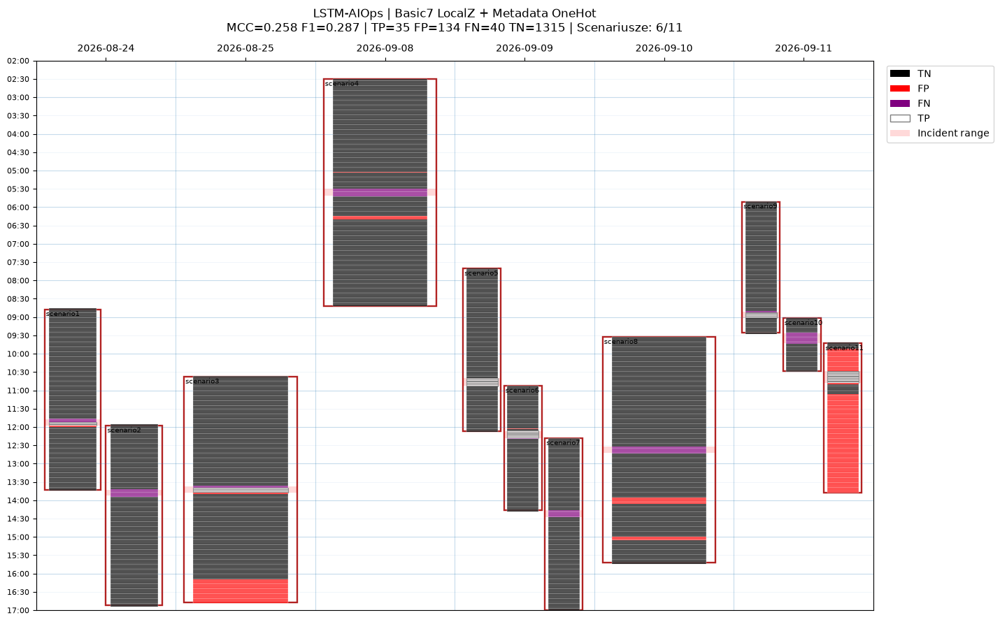


=== PORÓWNANIE MODELI ===


,model,MCC,F1,TP,FP,FN,TN,detected_scenarios
1,LSTM_AIOps_Temporal18,0.5238,0.5455,39,29,36,1420,9
0,Basic7_LocalZ,0.5143,0.5238,33,18,42,1431,7
2,LSTM_AIOps_MetadataOneHot4,0.2578,0.2869,35,134,40,1315,6



=== KLUCZOWE SCENARIUSZE ===


,case,n_features,train_categories,MCC,F1,precision,recall,TP,FP,FN,TN
3,scenario4,26,11,-0.0271,0.0000,0.0000,0.0000,0,4,6,176
5,scenario6,26,11,0.8467,0.8571,0.8571,0.8571,6,1,1,95
6,scenario7,26,11,0.0000,0.0000,0.0000,0.0000,0,0,6,149
10,scenario11,25,10,0.1023,0.1667,0.0909,1.0000,10,100,0,13



Wyniki zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\LSTM_AIOps_MetadataOneHot4


In [103]:
import gc
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from collections import Counter
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    matthews_corrcoef,
    f1_score,
    precision_score,
    recall_score,
)

from IPython.display import display


# ============================================================
# 1. KONFIGURACJA
# ============================================================

MODEL_NAME = "LSTM_AIOps_MetadataOneHot4"

MODEL_DIR = PREP_DIR / "nn_loso" / MODEL_NAME

for sub in ["models", "predictions", "reports"]:
    (MODEL_DIR / sub).mkdir(parents=True, exist_ok=True)

BASE_FEATURES = list(BASIC_FEATURES)

SEQ_LEN = 15
LOCAL_HISTORY = 15
MIN_HISTORY = 5

HIDDEN_SIZE = 24
EPOCHS = 25
BATCH_SIZE = 64
LR = 0.001
POS_WEIGHT = 2.0
THRESHOLD = 0.5
SEED = 42

MIN_TRAIN_CASES = 2

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Urządzenie:", DEVICE)


# ============================================================
# 2. DANE
# ============================================================

DATA = (
    META_BUCKET_DATA
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
    .copy()
)

Y = DATA["label_primary"].astype(int).to_numpy()
CASES = DATA["case"].astype(str).to_numpy()

assert len(DATA) == 1524
assert int(Y.sum()) == 75

# Historia nie przechodzi pomiędzy scenariuszami
# ani przez luki w kubełkach.
new_run = (
    DATA["case"].ne(DATA["case"].shift())
    | DATA["timestamp"].diff().ne(pd.Timedelta("2min"))
)

DATA["run_id"] = new_run.cumsum()

BASE_X = (
    DATA[BASE_FEATURES]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# Indeksy kubełków dla każdego scenariusza.
CASE_INDICES = {}

for case in SCENARIOS:

    indices = np.flatnonzero(CASES == case)

    assert (
        len(indices) == len(OHE_BUCKET_COUNTS[case])
    ), f"Niezgodna liczba kubełków: {case}"

    CASE_INDICES[case] = indices


# ============================================================
# 3. LOKALNE STATYSTYKI BASIC7
# ============================================================

PAST_MEAN = pd.DataFrame(index=DATA.index)
PAST_STD = pd.DataFrame(index=DATA.index)

for feature in BASE_FEATURES:

    previous = BASE_X[feature].groupby(
        DATA["run_id"], sort=False
    ).shift(1)

    grouped = previous.groupby(
        DATA["run_id"], sort=False
    )

    PAST_MEAN[feature] = grouped.transform(
        lambda s: s.rolling(
            LOCAL_HISTORY,
            min_periods=MIN_HISTORY
        ).mean()
    )

    PAST_STD[feature] = grouped.transform(
        lambda s: s.rolling(
            LOCAL_HISTORY,
            min_periods=MIN_HISTORY
        ).std(ddof=0)
    )


def build_local_z(train_idx):

    result = np.zeros(
        (len(DATA), len(BASE_FEATURES)),
        dtype=np.float32,
    )

    floors = {}

    for j, feature in enumerate(BASE_FEATURES):

        train_std = float(
            BASE_X[feature].iloc[train_idx].std(ddof=0)
        )

        floor = max(0.05 * train_std, 1e-6)
        floors[feature] = floor

        z = (
            BASE_X[feature].to_numpy(dtype=float)
            - PAST_MEAN[feature].to_numpy(dtype=float)
        ) / np.maximum(
            PAST_STD[feature].to_numpy(dtype=float),
            floor,
        )

        z[~np.isfinite(z)] = 0.0

        result[:, j] = np.clip(z, -5, 5)

    return result, floors


# ============================================================
# 4. SŁOWNIK KATEGORII — TYLKO TRAIN
# ============================================================

def build_train_vocab(train_cases):

    vocab = {}

    for field in OHE_FIELDS:

        case_presence = Counter()

        for case in train_cases:

            for category in OHE_CASE_COUNTS[case][field]:

                if category != MISSING_TOKEN:
                    case_presence[category] += 1

        # Minimum dwa scenariusze treningowe.
        categories = sorted(
            category
            for category, count in case_presence.items()
            if count >= MIN_TRAIN_CASES
        )

        vocab[field] = categories

    return vocab


def build_ohe_matrix(vocab):

    # Zawsze uwzględniamy MISSING i OTHER.
    field_columns = {}

    feature_names = []

    for field in OHE_FIELDS:

        categories = (
            list(vocab[field])
            + [MISSING_TOKEN, OTHER_TOKEN]
        )

        field_columns[field] = {
            value: len(feature_names) + j
            for j, value in enumerate(categories)
        }

        feature_names.extend(
            f"{field}={value}"
            for value in categories
        )

    X = np.zeros(
        (len(DATA), len(feature_names)),
        dtype=np.float32,
    )

    for case in SCENARIOS:

        indices = CASE_INDICES[case]
        counts_by_bucket = OHE_BUCKET_COUNTS[case]
        totals = OHE_BUCKET_TOTALS[case]

        for bucket_index, position in enumerate(indices):

            total = int(totals[bucket_index])

            if total == 0:
                continue

            for field in OHE_FIELDS:

                columns = field_columns[field]

                for category, count in (
                    counts_by_bucket[bucket_index][field].items()
                ):

                    if category == MISSING_TOKEN:
                        column = columns[MISSING_TOKEN]
                    else:
                        column = columns.get(
                            category,
                            columns[OTHER_TOKEN]
                        )

                    X[position, column] += count / total

    # Każde pole w niepustym kubełku powinno
    # mieć sumę udziałów równą 1.
    offset = 0

    for field in OHE_FIELDS:

        width = len(vocab[field]) + 2

        field_sums = X[:, offset:offset + width].sum(
            axis=1
        )

        expected = np.array([
            1.0 if OHE_BUCKET_TOTALS[case][j] > 0 else 0.0
            for case in sorted(SCENARIOS)
            for j in []
        ])

        # Sprawdzamy bez tworzenia zależności
        # od kolejności nazw scenariuszy.
        for case in SCENARIOS:
            indices = CASE_INDICES[case]
            nonempty = OHE_BUCKET_TOTALS[case] > 0

            if not np.allclose(
                field_sums[indices][nonempty], 1.0,
                atol=1e-5
            ):
                raise RuntimeError(
                    f"Niepoprawne udziały OHE: {case}, {field}"
                )

        offset += width

    return X, feature_names


# ============================================================
# 5. SEKWENCJE 15 KUBEŁKÓW
# ============================================================

def build_sequences(scaled):

    n_features = scaled.shape[1]

    sequences = np.zeros(
        (len(DATA), SEQ_LEN, n_features),
        dtype=np.float32,
    )

    for _, positions in DATA.groupby(
        "run_id", sort=False
    ).indices.items():

        positions = np.asarray(positions)

        for j, position in enumerate(positions):

            history = positions[
                max(0, j - SEQ_LEN + 1):j + 1
            ]

            sequences[
                position,
                -len(history):,
                :
            ] = scaled[history]

    return sequences


# ============================================================
# 6. ARCHITEKTURA LSTM
# ============================================================

class MetadataOneHotLSTM(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=HIDDEN_SIZE,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(0.20)
        self.output = nn.Linear(HIDDEN_SIZE, 1)

    def forward(self, x):

        outputs, _ = self.lstm(x)

        return self.output(
            self.dropout(outputs[:, -1, :])
        ).squeeze(-1)


def evaluate(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


# ============================================================
# 7. LOSO — 11 FOLDÓW
# ============================================================

ALL_PRED = np.full(len(DATA), -1, dtype=int)
ALL_PROB = np.full(len(DATA), np.nan)

FOLD_RESULTS = []

for fold, test_case in enumerate(SCENARIOS, 1):

    train_cases = [
        case for case in SCENARIOS
        if case != test_case
    ]

    train_idx = np.flatnonzero(CASES != test_case)
    test_idx = CASE_INDICES[test_case]

    # Słownik wyłącznie z 10 scenariuszy treningowych.
    vocab = build_train_vocab(train_cases)

    X_ohe, ohe_names = build_ohe_matrix(vocab)

    X_local, sigma_floors = build_local_z(train_idx)

    X = np.column_stack([
        X_local,
        X_ohe,
    ]).astype(np.float32)

    feature_names = BASE_FEATURES + ohe_names
    n_features = X.shape[1]

    # Standaryzacja wyłącznie na treningu.
    scaler = StandardScaler()
    scaler.fit(X[train_idx])

    X_scaled = scaler.transform(
        X
    ).astype(np.float32)

    X_scaled = np.clip(X_scaled, -3, 3)

    sequences = build_sequences(X_scaled)

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    model = MetadataOneHotLSTM(
        input_size=n_features
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR
    )

    loss_fn = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            POS_WEIGHT,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    x_train = torch.from_numpy(
        sequences[train_idx]
    ).to(DEVICE)

    y_train = torch.from_numpy(
        Y[train_idx].astype(np.float32)
    ).to(DEVICE)

    for epoch in range(EPOCHS):

        model.train()

        order = torch.randperm(
            len(train_idx), device=DEVICE
        )

        for batch in order.split(BATCH_SIZE):

            optimizer.zero_grad(set_to_none=True)

            logits = model(x_train[batch])

            loss = loss_fn(
                logits,
                y_train[batch],
            )

            loss.backward()
            optimizer.step()

    # Test na scenariuszu wyłączonym z treningu.
    model.eval()

    with torch.no_grad():

        x_test = torch.from_numpy(
            sequences[test_idx]
        ).to(DEVICE)

        prob = torch.sigmoid(
            model(x_test)
        ).cpu().numpy()

    pred = (prob >= THRESHOLD).astype(int)

    ALL_PRED[test_idx] = pred
    ALL_PROB[test_idx] = prob

    metrics = evaluate(Y[test_idx], pred)

    FOLD_RESULTS.append({
        "case": test_case,
        "n_features": n_features,
        "train_categories": sum(
            len(categories) for categories in vocab.values()
        ),
        **metrics,
    })

    # Predykcje w znanym formacie notebooka.
    fold_df = DATA.iloc[test_idx][[
        "case",
        "timestamp",
        "bucket_end",
        "label_primary",
        "label_all_known",
    ]].copy()

    fold_df["prediction"] = pred
    fold_df["probability"] = prob

    joblib.dump(
        {"data": fold_df, "metrics": metrics},
        MODEL_DIR / "predictions" / f"{test_case}.joblib",
        compress=3,
    )

    # Zapis modelu i słownika właściwego dla foldu.
    torch.save(
        {
            "state_dict": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "input_size": n_features,
            "features": feature_names,
            "vocab": vocab,
            "ohe_fields": OHE_FIELDS,
            "scaler_mean": scaler.mean_,
            "scaler_scale": scaler.scale_,
            "sigma_floors": sigma_floors,
            "local_history": LOCAL_HISTORY,
            "min_history": MIN_HISTORY,
            "sequence_length": SEQ_LEN,
            "threshold": THRESHOLD,
            "min_train_cases": MIN_TRAIN_CASES,
        },
        MODEL_DIR / "models" / f"{test_case}.pt",
    )

    print(
        f"{fold:2d}/11 {test_case:>10} | "
        f"cechy={n_features:2d} | "
        f"MCC={metrics['MCC']:.3f} | "
        f"TP={metrics['TP']:2d} "
        f"FP={metrics['FP']:3d} "
        f"FN={metrics['FN']:2d}",
        flush=True,
    )

    del (
        model, optimizer, x_train, y_train, x_test,
        sequences, X_scaled, X_local, X_ohe, X
    )

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    gc.collect()


# ============================================================
# 8. WYNIKI GLOBALNE
# ============================================================

assert (ALL_PRED >= 0).all()
assert np.isfinite(ALL_PROB).all()

overall = evaluate(Y, ALL_PRED)

detected_cases = sum(
    row["TP"] > 0 for row in FOLD_RESULTS
)

print("\n=== WYNIKI GLOBALNE ===")

display(
    pd.DataFrame([{
        "model": MODEL_NAME,
        "detected_scenarios": detected_cases,
        **overall,
    }]).round(4)
)

print("\n=== WYNIKI WSZYSTKICH 11 SCENARIUSZY ===")

fold_table = pd.DataFrame(FOLD_RESULTS)

display(
    fold_table[[
        "case", "n_features",
        "MCC", "F1", "precision", "recall",
        "TP", "FP", "FN", "TN",
    ]].round(4)
)

fold_table.to_csv(
    MODEL_DIR / "reports" / "by_scenario.csv",
    index=False,
)

pd.DataFrame([{
    "model": MODEL_NAME,
    "detected_scenarios": detected_cases,
    **overall,
}]).to_csv(
    MODEL_DIR / "reports" / "overall.csv",
    index=False,
)


# ============================================================
# 9. ORYGINALNY KALENDARZ
# ============================================================

plot_df = DATA[[
    "case",
    "timestamp",
    "bucket_end",
    "label_primary",
    "label_all_known",
]].copy()

plot_df["prediction"] = ALL_PRED
plot_df["probability"] = ALL_PROB

actual = plot_df["label_primary"].astype(int)

plot_df["outcome"] = np.select(
    [
        (actual == 1) & (ALL_PRED == 1),
        (actual == 0) & (ALL_PRED == 1),
        (actual == 1) & (ALL_PRED == 0),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)

for col in ["timestamp", "bucket_end"]:
    plot_df[col] = (
        pd.to_datetime(plot_df[col], utc=True)
        .dt.tz_localize(None)
    )

calendar = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:
    calendar[col] = (
        pd.to_datetime(calendar[col], utc=True)
        .dt.tz_localize(None)
    )

title = (
    f"LSTM-AIOps | Basic7 LocalZ + Metadata OneHot\n"
    f"MCC={overall['MCC']:.3f} "
    f"F1={overall['F1']:.3f} | "
    f"TP={overall['TP']} "
    f"FP={overall['FP']} "
    f"FN={overall['FN']} "
    f"TN={overall['TN']} | "
    f"Scenariusze: {detected_cases}/11"
)

plot_calendar_with_buckets(
    calendar_segments=calendar,
    bucket_df=plot_df,
    title=title,
    start_hour=2,
    end_hour=17,
)

plt.show()


# ============================================================
# 10. PORÓWNANIE Z POPRZEDNIMI MODELAMI
# ============================================================

comparison = pd.DataFrame([
    {
        "model": "Basic7_LocalZ",
        "MCC": 0.5143,
        "F1": 0.5238,
        "TP": 33,
        "FP": 18,
        "FN": 42,
        "TN": 1431,
        "detected_scenarios": 7,
    },
    {
        "model": "LSTM_AIOps_Temporal18",
        "MCC": 0.5238,
        "F1": 0.5455,
        "TP": 39,
        "FP": 29,
        "FN": 36,
        "TN": 1420,
        "detected_scenarios": 9,
    },
    {
        "model": MODEL_NAME,
        "MCC": overall["MCC"],
        "F1": overall["F1"],
        "TP": overall["TP"],
        "FP": overall["FP"],
        "FN": overall["FN"],
        "TN": overall["TN"],
        "detected_scenarios": detected_cases,
    },
])

print("\n=== PORÓWNANIE MODELI ===")

display(
    comparison.sort_values(
        "MCC", ascending=False
    ).round(4)
)

print("\n=== KLUCZOWE SCENARIUSZE ===")

display(
    fold_table[
        fold_table["case"].isin([
            "scenario4",
            "scenario6",
            "scenario7",
            "scenario11",
        ])
    ].round(4)
)

print("\nWyniki zapisano w:", MODEL_DIR)

In [104]:
import numpy as np
import pandas as pd
from collections import Counter
from itertools import combinations
from IPython.display import display

# ============================================================
# 1. KONFIGURACJA
# ============================================================

if (
    "COUNTS_BY_CASE" not in globals()
    or "RECORDS_BY_CASE" not in globals()
):
    raise RuntimeError(
        "Najpierw uruchom komórkę 89, która przygotowuje "
        "COUNTS_BY_CASE i RECORDS_BY_CASE."
    )

FIELDS = [
    "app",
    "component",
    "container",
    "detected_level",
    "filename",
    "instance",
    "job",
    "namespace",
    "node_name",
    "pod",
    "service_name",
    "stream",
]

CASES_AUDIT = list(SCENARIOS)

SELECTED_OHE_FIELDS = [
    "detected_level",
    "namespace",
    "node_name",
    "stream",
]

# Domyślnie nie pokazujemy nazw podów, hostów itd.
# Dla detected_level i stream wartości są czytelne.
SHOW_ALL_CATEGORY_NAMES = False

# Liczba najczęstszych kategorii na pole.
TOP_K = 8

TOTAL_RECORDS = sum(
    RECORDS_BY_CASE[c] for c in CASES_AUDIT
)

GLOBAL_ROWS = []
CASE_ROWS = []
TOP_ROWS = []
CROSS_CASE_ROWS = []

# ============================================================
# 2. STATYSTYKI GLOBALNE
# ============================================================

for field in FIELDS:

    global_counts = Counter()
    case_presence = Counter()

    for case in CASES_AUDIT:

        counts = COUNTS_BY_CASE[case][field]
        global_counts.update(counts)

        for value in counts:
            case_presence[value] += 1

    present = sum(global_counts.values())
    missing = TOTAL_RECORDS - present

    if missing < 0:
        raise RuntimeError(
            f"Nieprawidłowe liczniki dla {field}"
        )

    unique = len(global_counts)

    shared_2 = sum(
        n >= 2 for n in case_presence.values()
    )
    shared_3 = sum(
        n >= 3 for n in case_presence.values()
    )

    only_one_case = sum(
        n == 1 for n in case_presence.values()
    )

    # Kategoria, która wystąpiła tylko w jednym logu.
    single_occurrence = sum(
        n == 1 for n in global_counts.values()
    )

    # Logi należące do kategorii widzianych
    # w co najmniej dwóch różnych scenariuszach.
    loso_known = sum(
        count
        for category, count in global_counts.items()
        if case_presence[category] >= 2
    )

    sorted_counts = sorted(
        global_counts.values(), reverse=True
    )

    top1 = (
        sorted_counts[0] / present
        if present else np.nan
    )

    top3 = (
        sum(sorted_counts[:3]) / present
        if present else np.nan
    )

    # Entropia rozkładu kategorii (tylko obecne wartości).
    if present and unique > 1:
        probabilities = (
            np.asarray(sorted_counts, dtype=float) / present
        )
        entropy = float(
            -(probabilities * np.log2(probabilities)).sum()
        )
        normalized_entropy = entropy / np.log2(unique)
    else:
        normalized_entropy = 0.0 if present else np.nan

    GLOBAL_ROWS.append({
        "field": field,
        "total_logs": TOTAL_RECORDS,
        "present": present,
        "missing": missing,
        "missing_pct": 100 * missing / TOTAL_RECORDS,
        "unique_values": unique,
        "shared_2plus": shared_2,
        "shared_3plus": shared_3,
        "one_case_only": only_one_case,
        "one_log_only": single_occurrence,
        "top1_pct": 100 * top1,
        "top3_pct": 100 * top3,
        "entropy_normalized": normalized_entropy,
        "loso_known_pct": (
            100 * loso_known / present
            if present else np.nan
        ),
        "loso_unknown_pct": (
            100 * (present - loso_known) / present
            if present else np.nan
        ),
    })

    # ========================================================
    # 3. NAJCZĘSTSZE KATEGORIE
    # ========================================================

    for rank, (category, count) in enumerate(
        global_counts.most_common(TOP_K), start=1
    ):

        if (
            SHOW_ALL_CATEGORY_NAMES
            or field in {"detected_level", "stream"}
        ):
            display_value = category
        else:
            display_value = f"<kategoria_{rank}>"

        TOP_ROWS.append({
            "field": field,
            "rank": rank,
            "category": display_value,
            "logs": count,
            "pct_of_present": (
                100 * count / present if present else 0
            ),
            "scenarios": case_presence[category],
        })

    # ========================================================
    # 4. STATYSTYKI PER SCENARIUSZ
    # ========================================================

    for case in CASES_AUDIT:

        counts = COUNTS_BY_CASE[case][field]
        total = RECORDS_BY_CASE[case]

        case_present = sum(counts.values())
        case_missing = total - case_present

        train_categories = set()

        for other in CASES_AUDIT:
            if other != case:
                train_categories.update(
                    COUNTS_BY_CASE[other][field]
                )

        known_logs = sum(
            count
            for category, count in counts.items()
            if category in train_categories
        )

        CASE_ROWS.append({
            "case": case,
            "field": field,
            "total": total,
            "present": case_present,
            "missing": case_missing,
            "missing_pct": (
                100 * case_missing / total
                if total else 0
            ),
            "unique": len(counts),
            "known_loso_pct": (
                100 * known_logs / case_present
                if case_present else np.nan
            ),
            "unknown_loso_pct": (
                100 * (case_present - known_logs)
                / case_present
                if case_present else np.nan
            ),
        })

    # ========================================================
    # 5. LICZBA SCENARIUSZY NA KATEGORIĘ
    # ========================================================

    distribution = Counter(case_presence.values())

    for n_cases in range(1, len(CASES_AUDIT) + 1):
        CROSS_CASE_ROWS.append({
            "field": field,
            "scenarios_count": n_cases,
            "categories_count": distribution[n_cases],
        })


META_AUDIT_GLOBAL = pd.DataFrame(GLOBAL_ROWS)
META_AUDIT_BY_CASE = pd.DataFrame(CASE_ROWS)
META_AUDIT_TOP = pd.DataFrame(TOP_ROWS)
META_AUDIT_CROSS_CASE = pd.DataFrame(CROSS_CASE_ROWS)

# ============================================================
# 6. GLOBALNY PRZEGLĄD
# ============================================================

print("\n" + "=" * 80)
print("1. KOMPLETNOŚĆ I LICZBA KATEGORII")
print("=" * 80)

display(
    META_AUDIT_GLOBAL[
        [
            "field",
            "present",
            "missing",
            "missing_pct",
            "unique_values",
            "one_case_only",
            "one_log_only",
        ]
    ]
    .sort_values("missing_pct", ascending=False)
    .round(2)
)

print("\n" + "=" * 80)
print("2. DOMINACJA I POWTARZALNOŚĆ KATEGORII")
print("=" * 80)

display(
    META_AUDIT_GLOBAL[
        [
            "field",
            "unique_values",
            "top1_pct",
            "top3_pct",
            "entropy_normalized",
            "shared_2plus",
            "shared_3plus",
            "loso_known_pct",
            "loso_unknown_pct",
        ]
    ]
    .sort_values("loso_known_pct", ascending=False)
    .round(3)
)

print("\nInterpretacja:")
print("  top1_pct: udział najczęstszej kategorii")
print("  top3_pct: udział trzech najczęstszych kategorii")
print("  entropy_normalized: 0 = jedna dominująca,")
print("                      1 = równomierny rozkład")
print("  one_case_only: kategorie unikalne dla scenariusza")
print("  one_log_only: kategorie obecne tylko w jednym logu")

# ============================================================
# 7. BRAKI METADANYCH W KAŻDYM SCENARIUSZU
# ============================================================

print("\n" + "=" * 80)
print("3. BRAKI METADANYCH [%] — SCENARIUSZE")
print("=" * 80)

MISSING_MATRIX = META_AUDIT_BY_CASE.pivot(
    index="case",
    columns="field",
    values="missing_pct",
).reindex(index=CASES_AUDIT, columns=FIELDS)

display(MISSING_MATRIX.round(1))

# ============================================================
# 8. LICZBA UNIKALNYCH WARTOŚCI W SCENARIUSZACH
# ============================================================

print("\n" + "=" * 80)
print("4. UNIKALNE WARTOŚCI — SCENARIUSZE")
print("=" * 80)

UNIQUE_MATRIX = META_AUDIT_BY_CASE.pivot(
    index="case",
    columns="field",
    values="unique",
).reindex(index=CASES_AUDIT, columns=FIELDS)

display(UNIQUE_MATRIX.astype(int))

# ============================================================
# 9. NAJCZĘSTSZE KATEGORIE
# ============================================================

print("\n" + "=" * 80)
print("5. NAJCZĘSTSZE KATEGORIE")
print("=" * 80)

display(
    META_AUDIT_TOP[
        [
            "field", "rank", "category",
            "logs", "pct_of_present", "scenarios"
        ]
    ].round(2)
)

# ============================================================
# 10. OHE — DOKŁADNA WIELKOŚĆ SŁOWNIKA NA FOLD
# ============================================================

OHE_FOLD_ROWS = []

for test_case in CASES_AUDIT:

    train_cases = [
        case for case in CASES_AUDIT
        if case != test_case
    ]

    fold_row = {"test_case": test_case}

    total_ohe_dims = 0

    for field in SELECTED_OHE_FIELDS:

        category_case_presence = Counter()

        for train_case in train_cases:
            for category in COUNTS_BY_CASE[
                train_case
            ][field]:
                category_case_presence[category] += 1

        # Taka sama zasada jak w komórce 91:
        # minimum dwa scenariusze treningowe.
        retained_categories = {
            category
            for category, n in category_case_presence.items()
            if n >= 2
        }

        test_counts = COUNTS_BY_CASE[test_case][field]

        test_present = sum(test_counts.values())
        test_to_other = sum(
            count
            for category, count in test_counts.items()
            if category not in retained_categories
        )

        dimensions = len(retained_categories) + 2
        # Dwa dodatkowe wymiary: MISSING oraz OTHER.

        fold_row[f"{field}_dims"] = dimensions
        fold_row[f"{field}_other_pct"] = (
            100 * test_to_other / test_present
            if test_present else np.nan
        )

        total_ohe_dims += dimensions

    fold_row["OHE_dimensions"] = total_ohe_dims
    fold_row["LSTM_input_features"] = 7 + total_ohe_dims

    OHE_FOLD_ROWS.append(fold_row)

META_AUDIT_OHE = pd.DataFrame(OHE_FOLD_ROWS)

print("\n" + "=" * 80)
print("6. ROZMIAR WEJŚCIA LSTM W KAŻDYM FOLDZIE LOSO")
print("=" * 80)

display(META_AUDIT_OHE.round(2))

print("\nLiczba cech wejściowych LSTM:")
print(
    "  min:",
    META_AUDIT_OHE["LSTM_input_features"].min()
)
print(
    "  mediana:",
    META_AUDIT_OHE["LSTM_input_features"].median()
)
print(
    "  max:",
    META_AUDIT_OHE["LSTM_input_features"].max()
)

# ============================================================
# 11. WSTĘPNA KONTROLA POWTARZAJĄCYCH SIĘ ROZKŁADÓW
# ============================================================

print("\n" + "=" * 80)
print("7. POLA O IDENTYCZNYCH HISTOGRAMACH")
print("=" * 80)

SIMILAR_FIELDS = []

for field_a, field_b in combinations(FIELDS, 2):

    identical_all_cases = all(
        COUNTS_BY_CASE[case][field_a]
        == COUNTS_BY_CASE[case][field_b]
        for case in CASES_AUDIT
    )

    if identical_all_cases:
        SIMILAR_FIELDS.append((field_a, field_b))

if SIMILAR_FIELDS:
    for a, b in SIMILAR_FIELDS:
        print(f"  {a} == {b} (identyczny histogram)")
else:
    print("Nie znaleziono identycznych histogramów.")

print(
    "\nUWAGA: identyczne histogramy nie dowodzą, "
    "że wartości są identyczne w tych samych logach."
)

# ============================================================
# 12. ZAPIS RAPORTÓW
# ============================================================

REPORT_DIR = PREP_DIR / "metadata_experiment" / "audit"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

reports = {
    "global_summary.csv": META_AUDIT_GLOBAL,
    "by_scenario.csv": META_AUDIT_BY_CASE,
    "top_categories.csv": META_AUDIT_TOP,
    "category_cross_scenario.csv": META_AUDIT_CROSS_CASE,
    "missing_matrix.csv": MISSING_MATRIX,
    "unique_matrix.csv": UNIQUE_MATRIX,
    "onehot_fold_dimensions.csv": META_AUDIT_OHE,
}

for filename, df in reports.items():
    df.to_csv(
        REPORT_DIR / filename,
        index=filename.endswith("_matrix.csv"),
    )

print("\nRaporty zapisano w:", REPORT_DIR)


1. KOMPLETNOŚĆ I LICZBA KATEGORII


,field,present,missing,missing_pct,unique_values,one_case_only,one_log_only
1,component,57072,798512,93.33,3,3,0
5,instance,558593,296991,34.71,24,12,0
3,detected_level,669236,186348,21.78,4,1,0
0,app,855584,0,0.00,28,14,0
2,container,855584,0,0.00,31,16,0
4,filename,855584,0,0.00,218,157,0
6,job,855584,0,0.00,28,14,0
7,namespace,855584,0,0.00,6,4,0
8,node_name,855584,0,0.00,7,3,0
9,pod,855584,0,0.00,99,69,0



2. DOMINACJA I POWTARZALNOŚĆ KATEGORII


,field,unique_values,top1_pct,top3_pct,entropy_normalized,shared_2plus,shared_3plus,loso_known_pct,loso_unknown_pct
11,stream,2,91.297,100.000,0.426,2,2,100.000,0.000
3,detected_level,4,99.627,99.973,0.020,3,2,99.899,0.101
8,node_name,7,50.409,94.207,0.570,4,4,96.812,3.188
7,namespace,6,84.133,97.806,0.345,2,1,90.095,9.905
5,instance,24,59.527,78.737,0.500,12,10,84.828,15.172
2,container,31,38.238,78.286,0.522,15,12,56.392,43.608
10,service_name,28,38.864,79.743,0.513,14,11,55.826,44.174
0,app,28,38.864,79.743,0.513,14,11,55.826,44.174
6,job,28,38.864,79.743,0.513,14,11,55.826,44.174
9,pod,99,34.228,61.055,0.537,30,18,45.752,54.248



Interpretacja:
  top1_pct: udział najczęstszej kategorii
  top3_pct: udział trzech najczęstszych kategorii
  entropy_normalized: 0 = jedna dominująca,
                      1 = równomierny rozkład
  one_case_only: kategorie unikalne dla scenariusza
  one_log_only: kategorie obecne tylko w jednym logu

3. BRAKI METADANYCH [%] — SCENARIUSZE


field,app,component,container,detected_level,filename,instance,job,namespace,node_name,pod,service_name,stream
case,,,,,,,,,,,,
scenario1,0.0,100.0,0.0,6.8,0.0,1.4,0.0,0.0,0.0,0.0,0.0,0.0
scenario2,0.0,100.0,0.0,3.7,0.0,1.4,0.0,0.0,0.0,0.0,0.0,0.0
scenario3,0.0,100.0,0.0,47.0,0.0,0.8,0.0,0.0,0.0,0.0,0.0,0.0
scenario4,0.0,100.0,0.0,57.5,0.0,0.7,0.0,0.0,0.0,0.0,0.0,0.0
scenario5,0.0,100.0,0.0,57.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
scenario6,0.0,100.0,0.0,0.4,0.0,93.9,0.0,0.0,0.0,0.0,0.0,0.0
scenario7,0.0,100.0,0.0,4.4,0.0,1.4,0.0,0.0,0.0,0.0,0.0,0.0
scenario8,0.0,100.0,0.0,2.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0
scenario9,0.0,100.0,0.0,11.4,0.0,1.7,0.0,0.0,0.0,0.0,0.0,0.0


... (3 outputs left out)

,field,rank,category,logs,pct_of_present,scenarios
0,app,1,<kategoria_1>,332511,38.86,10
1,app,2,<kategoria_2>,292850,34.23,1
2,app,3,<kategoria_3>,56908,6.65,1
3,app,4,<kategoria_4>,50399,5.89,2
4,app,5,<kategoria_5>,29154,3.41,10
...,...,...,...,...,...,...
73,service_name,6,<kategoria_6>,23261,2.72,10
74,service_name,7,<kategoria_7>,14471,1.69,10
75,service_name,8,<kategoria_8>,6533,0.76,1
76,stream,1,stdout,781125,91.30,11



6. ROZMIAR WEJŚCIA LSTM W KAŻDYM FOLDZIE LOSO


,test_case,detected_level_dims,detected_level_other_pct,namespace_dims,namespace_other_pct,node_name_dims,node_name_other_pct,stream_dims,stream_other_pct,OHE_dimensions,LSTM_input_features
0,scenario1,5,0.00,4,0.00,6,0.29,4,0.0,19,26
1,scenario2,5,0.00,4,0.00,6,0.27,4,0.0,19,26
2,scenario3,5,0.00,4,0.00,6,47.52,4,0.0,19,26
3,scenario4,5,0.00,4,0.00,6,0.00,4,0.0,19,26
4,scenario5,5,0.00,3,100.00,6,0.00,4,0.0,18,25
5,scenario6,5,0.00,4,0.00,6,0.00,4,0.0,19,26
6,scenario7,5,0.00,4,0.00,6,0.00,4,0.0,19,26
7,scenario8,5,0.00,4,0.00,6,0.00,4,0.0,19,26
8,scenario9,5,0.00,4,0.00,6,0.00,4,0.0,19,26
9,scenario10,4,1.01,3,50.69,6,0.00,4,0.0,17,24



Liczba cech wejściowych LSTM:
  min: 24
  mediana: 26.0
  max: 26

7. POLA O IDENTYCZNYCH HISTOGRAMACH
  app == service_name (identyczny histogram)

UWAGA: identyczne histogramy nie dowodzą, że wartości są identyczne w tych samych logach.

Raporty zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\metadata_experiment\audit


In [105]:
import json
import re
from bisect import bisect_right
from collections import Counter
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import display

# ============================================================
# 1. WYBRANE METADANE — 11 PÓL, BEZ FILENAME
# ============================================================

OHE11_FIELDS = [
    "app",
    "component",
    "container",
    "detected_level",
    "instance",
    "job",
    "namespace",
    "node_name",
    "pod",
    "service_name",
    "stream",
]

assert len(OHE11_FIELDS) == 11
assert "filename" not in OHE11_FIELDS

OHE11_MISSING = "__MISSING__"
OHE11_OTHER = "__OTHER__"

if "META_BUCKET_DATA" not in globals():
    META_BUCKET_DATA = joblib.load(
        PREP_DIR
        / "metadata_experiment"
        / "Drain3_2min_metadata.joblib"
    )

def normalize_ohe11(field, value):

    if value is None:
        return OHE11_MISSING

    value = str(value).strip()

    if value.lower() in {
        "", "none", "null", "nan", "unknown", "-"
    }:
        return OHE11_MISSING

    if field in {"detected_level", "stream"}:
        value = value.lower()

    return value


# ============================================================
# 2. ZLICZANIE WARTOŚCI W KUBEŁKACH
# ============================================================

OHE11_BUCKET_COUNTS = {}
OHE11_CASE_COUNTS = {}
OHE11_BUCKET_TOTALS = {}

quality_rows = []

for case in SCENARIOS:

    df = (
        META_BUCKET_DATA[
            META_BUCKET_DATA["case"] == case
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    starts = (
        pd.to_datetime(df["timestamp"], utc=True)
        .astype("int64")
        .to_numpy()
    )

    ends = (
        pd.to_datetime(df["bucket_end"], utc=True)
        .astype("int64")
        .to_numpy()
    )

    n = len(df)

    bucket_counts = [
        {
            field: Counter()
            for field in OHE11_FIELDS
        }
        for _ in range(n)
    ]

    case_counts = {
        field: Counter()
        for field in OHE11_FIELDS
    }

    bucket_totals = np.zeros(n, dtype=np.int64)

    read_records = 0
    unmatched_records = 0

    path = find_case_log_file(case)

    for record in iter_json_records(path):

        read_records += 1

        ts_ns = int(record["ts_ns"])

        bucket_idx = bisect_right(
            starts, ts_ns
        ) - 1

        if (
            bucket_idx < 0
            or bucket_idx >= n
            or ts_ns >= ends[bucket_idx]
        ):
            unmatched_records += 1
            continue

        bucket_totals[bucket_idx] += 1

        labels = record.get("labels") or {}

        if isinstance(labels, str):
            labels = json.loads(labels)

        if not isinstance(labels, dict):
            labels = {}

        for field in OHE11_FIELDS:

            category = normalize_ohe11(
                field,
                labels.get(field),
            )

            bucket_counts[bucket_idx][field][category] += 1
            case_counts[field][category] += 1

    if unmatched_records:
        raise RuntimeError(
            f"{case}: {unmatched_records} logów "
            "nie trafiło do kubełków."
        )

    expected = df["meta_log_count"].to_numpy(
        dtype=np.int64
    )

    if not np.array_equal(bucket_totals, expected):
        raise RuntimeError(
            f"{case}: liczby logów nie zgadzają się "
            "z wcześniejszą agregacją metadanych."
        )

    OHE11_BUCKET_COUNTS[case] = bucket_counts
    OHE11_CASE_COUNTS[case] = case_counts
    OHE11_BUCKET_TOTALS[case] = bucket_totals

    quality_rows.append({
        "case": case,
        "records": read_records,
        "matched_pct": (
            100 * bucket_totals.sum() / read_records
        ),
        "distinct_values_total": sum(
            len(case_counts[field])
            for field in OHE11_FIELDS
        ),
    })

    print(
        f"{case:>10} | "
        f"logi={read_records:>8,} | "
        f"kubełki={n:>3} | "
        f"dopasowanie=100% | "
        f"kategorie={quality_rows[-1]['distinct_values_total']}",
        flush=True,
    )


# ============================================================
# 3. ZAPIS PRZYGOTOWANYCH LICZNIKÓW
# ============================================================

OHE11_DIR = (
    PREP_DIR / "metadata_experiment" / "onehot11"
)

OHE11_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "fields": OHE11_FIELDS,
        "bucket_counts": OHE11_BUCKET_COUNTS,
        "case_counts": OHE11_CASE_COUNTS,
        "bucket_totals": OHE11_BUCKET_TOTALS,
    },
    OHE11_DIR / "bucket_counts.joblib",
    compress=3,
)

print("\n=== WERYFIKACJA ===")
display(pd.DataFrame(quality_rows).round(2))

print("\nLiczba pól:", len(OHE11_FIELDS))
print("Lista pól:", OHE11_FIELDS)
print("Zapisano:", OHE11_DIR)

 scenario1 | logi=  26,858 | kubełki=149 | dopasowanie=100% | kategorie=76
 scenario2 | logi=  27,651 | kubełki=149 | dopasowanie=100% | kategorie=75
 scenario3 | logi=  57,081 | kubełki=186 | dopasowanie=100% | kategorie=86
 scenario4 | logi=  76,732 | kubełki=186 | dopasowanie=100% | kategorie=71
 scenario5 | logi=  41,251 | kubełki=134 | dopasowanie=100% | kategorie=25
 scenario6 | logi= 312,362 | kubełki=103 | dopasowanie=100% | kategorie=69
 scenario7 | logi=  27,221 | kubełki=155 | dopasowanie=100% | kategorie=69
 scenario8 | logi=  89,713 | kubełki=186 | dopasowanie=100% | kategorie=79
 scenario9 | logi=  22,788 | kubełki=109 | dopasowanie=100% | kategorie=78
scenario10 | logi=  19,253 | kubełki= 44 | dopasowanie=100% | kategorie=86
scenario11 | logi= 154,674 | kubełki=123 | dopasowanie=100% | kategorie=155

=== WERYFIKACJA ===


,case,records,matched_pct,distinct_values_total
0,scenario1,26858,100.0,76
1,scenario2,27651,100.0,75
2,scenario3,57081,100.0,86
3,scenario4,76732,100.0,71
4,scenario5,41251,100.0,25
5,scenario6,312362,100.0,69
6,scenario7,27221,100.0,69
7,scenario8,89713,100.0,79
8,scenario9,22788,100.0,78
9,scenario10,19253,100.0,86



Liczba pól: 11
Lista pól: ['app', 'component', 'container', 'detected_level', 'instance', 'job', 'namespace', 'node_name', 'pod', 'service_name', 'stream']
Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\metadata_experiment\onehot11


Urządzenie: cpu
Model: LSTM_AIOps_MetadataOneHot11
Pola metadanych: ['app', 'component', 'container', 'detected_level', 'instance', 'job', 'namespace', 'node_name', 'pod', 'service_name', 'stream']
 1/11  scenario1 | cechy=137 | parametry=15673 | MCC=0.653 | TP= 4 FP=  2 FN= 2
 2/11  scenario2 | cechy=136 | parametry=15577 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | cechy=138 | parametry=15769 | MCC=0.640 | TP= 6 FP=  8 FN= 0
 4/11  scenario4 | cechy=136 | parametry=15577 | MCC=-0.013 | TP= 0 FP=  1 FN= 6
 5/11  scenario5 | cechy=125 | parametry=14521 | MCC=0.000 | TP= 0 FP=  0 FN= 7
 6/11  scenario6 | cechy=137 | parametry=15673 | MCC=0.921 | TP= 6 FP=  0 FN= 1
 7/11  scenario7 | cechy=137 | parametry=15673 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | cechy=137 | parametry=15673 | MCC=-0.039 | TP= 0 FP=  8 FN= 6
 9/11  scenario9 | cechy=132 | parametry=15193 | MCC=0.824 | TP= 5 FP=  1 FN= 1
10/11 scenario10 | cechy=121 | parametry=14137 | MCC=0.000 | TP= 0 FP=  0 FN= 9


,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,LSTM_AIOps_MetadataOneHot11,5,0.2255,0.2605,0.1902,0.4133,31,132,44,1317



=== WYNIKI WSZYSTKICH SCENARIUSZY ===


,case,n_features,n_parameters,MCC,F1,precision,recall,TP,FP,FN,TN
0,scenario1,137,15673,0.6527,0.6667,0.6667,0.6667,4,2,2,141
1,scenario2,136,15577,0.0000,0.0000,0.0000,0.0000,0,0,6,143
2,scenario3,138,15769,0.6399,0.6000,0.4286,1.0000,6,8,0,172
3,scenario4,136,15577,-0.0134,0.0000,0.0000,0.0000,0,1,6,179
4,scenario5,125,14521,0.0000,0.0000,0.0000,0.0000,0,0,7,127
5,scenario6,137,15673,0.9210,0.9231,1.0000,0.8571,6,0,1,96
6,scenario7,137,15673,0.0000,0.0000,0.0000,0.0000,0,0,6,149
7,scenario8,137,15673,-0.0387,0.0000,0.0000,0.0000,0,8,6,172
8,scenario9,132,15193,0.8236,0.8333,0.8333,0.8333,5,1,1,102
9,scenario10,121,14137,0.0000,0.0000,0.0000,0.0000,0,0,9,35



=== KATEGORIE OTHER W LOSO [% LOGÓW] ===


,case,n_features,app_other_pct,component_other_pct,container_other_pct,detected_level_other_pct,instance_other_pct,job_other_pct,namespace_other_pct,node_name_other_pct,pod_other_pct,service_name_other_pct,stream_other_pct
0,scenario1,137,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.29,44.97,0.00,0.0
1,scenario2,136,0.00,0.0,0.32,0.00,0.00,0.00,0.00,0.27,1.66,0.00,0.0
2,scenario3,138,0.00,0.0,0.40,0.00,0.00,0.00,0.00,47.52,48.55,0.00,0.0
3,scenario4,136,0.11,0.0,0.00,0.00,0.00,0.11,0.00,0.00,0.72,0.11,0.0
4,scenario5,125,100.00,0.0,98.76,0.00,100.00,100.00,100.00,0.00,100.00,100.00,0.0
5,scenario6,137,93.75,0.0,93.75,0.00,0.00,93.75,0.00,0.00,93.85,93.75,0.0
6,scenario7,137,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,1.99,0.00,0.0
7,scenario8,137,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,11.45,0.00,0.0
8,scenario9,132,0.39,0.0,0.00,0.00,0.00,0.39,0.00,0.00,69.75,0.39,0.0
9,scenario10,121,50.69,0.0,50.19,0.89,48.90,50.69,50.69,0.00,51.96,50.69,0.0


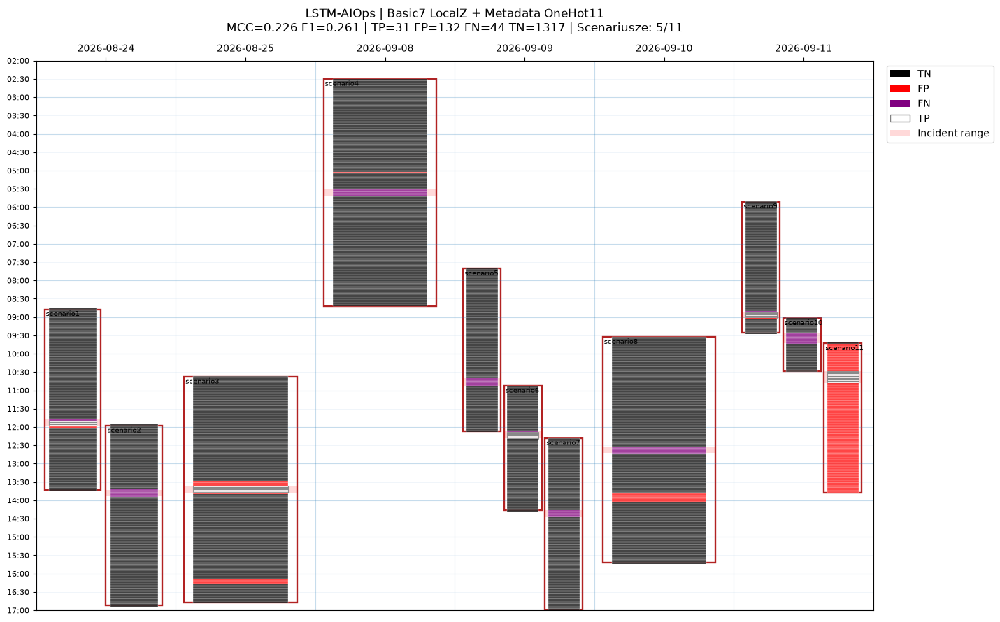


=== PORÓWNANIE MODELI ===


,model,MCC,F1,TP,FP,FN,TN,detected_scenarios
1,LSTM_AIOps_Temporal18,0.5238,0.5455,39,29,36,1420,9
0,Basic7_LocalZ,0.5143,0.5238,33,18,42,1431,7
2,MetadataOneHot4,0.2578,0.2869,35,134,40,1315,6
3,LSTM_AIOps_MetadataOneHot11,0.2255,0.2605,31,132,44,1317,5



=== KLUCZOWE SCENARIUSZE ===


,case,n_features,n_parameters,train_categories,MCC,F1,precision,recall,TP,FP,FN,TN
3,scenario4,136,15577,107,-0.0134,0.0000,0.000,0.0000,0,1,6,179
5,scenario6,137,15673,108,0.9210,0.9231,1.000,0.8571,6,0,1,96
6,scenario7,137,15673,108,0.0000,0.0000,0.000,0.0000,0,0,6,149
10,scenario11,137,15673,108,0.0269,0.1515,0.082,1.0000,10,112,0,1



Wyniki zapisano w: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\nn_loso\LSTM_AIOps_MetadataOneHot11


In [106]:
import os
import gc
import random

from collections import Counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    matthews_corrcoef,
    f1_score,
    precision_score,
    recall_score,
)

from IPython.display import display

# ============================================================
# 1. KONFIGURACJA
# ============================================================

MODEL_NAME = "LSTM_AIOps_MetadataOneHot11"

OUT = PREP_DIR / "nn_loso" / MODEL_NAME

for sub in ["predictions", "models", "reports"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

BASE7 = list(BASIC_FEATURES)

METADATA_FIELDS = list(OHE11_FIELDS)

assert len(BASE7) == 7
assert len(METADATA_FIELDS) == 11
assert "filename" not in METADATA_FIELDS

SEQ_LEN = 15
LOCAL_HISTORY = 15
MIN_HISTORY = 5

HIDDEN_SIZE = 24
DROPOUT = 0.20
EPOCHS = 25
BATCH_SIZE = 64
LR = 0.001
POS_WEIGHT = 2.0
THRESHOLD = 0.5

MIN_TRAIN_CASES = 2
SEED = 42

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(
        min(4, os.cpu_count() or 1)
    )

print("Urządzenie:", DEVICE)
print("Model:", MODEL_NAME)
print("Pola metadanych:", METADATA_FIELDS)


# ============================================================
# 2. DANE
# ============================================================

DATA11 = (
    META_BUCKET_DATA
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
    .copy()
)

Y11 = DATA11["label_primary"].astype(int).to_numpy()
CASES11 = DATA11["case"].astype(str).to_numpy()

assert len(DATA11) == 1524
assert int(Y11.sum()) == 75

new_run = (
    DATA11["case"].ne(DATA11["case"].shift())
    | DATA11["timestamp"].diff().ne(
        pd.Timedelta("2min")
    )
)

DATA11["run_id"] = new_run.cumsum()

BASE_X11 = (
    DATA11[BASE7]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

CASE_INDICES11 = {
    case: np.flatnonzero(CASES11 == case)
    for case in SCENARIOS
}

for case in SCENARIOS:
    assert (
        len(CASE_INDICES11[case])
        == len(OHE11_BUCKET_COUNTS[case])
    ), f"Niezgodne kubełki: {case}"


# ============================================================
# 3. LOCAL Z-SCORE BASIC7
# ============================================================

PAST_MEAN11 = pd.DataFrame(index=DATA11.index)
PAST_STD11 = pd.DataFrame(index=DATA11.index)

for feature in BASE7:

    previous = BASE_X11[feature].groupby(
        DATA11["run_id"], sort=False
    ).shift(1)

    grouped = previous.groupby(
        DATA11["run_id"], sort=False
    )

    PAST_MEAN11[feature] = grouped.transform(
        lambda s: s.rolling(
            LOCAL_HISTORY,
            min_periods=MIN_HISTORY,
        ).mean()
    )

    PAST_STD11[feature] = grouped.transform(
        lambda s: s.rolling(
            LOCAL_HISTORY,
            min_periods=MIN_HISTORY,
        ).std(ddof=0)
    )


def make_basic7_local_z11(train_idx):

    result = np.zeros(
        (len(DATA11), len(BASE7)),
        dtype=np.float32,
    )

    sigma_floors = {}

    for j, feature in enumerate(BASE7):

        train_std = float(
            BASE_X11[feature]
            .iloc[train_idx]
            .std(ddof=0)
        )

        floor = max(
            0.05 * train_std,
            1e-6,
        )

        sigma_floors[feature] = floor

        z = (
            BASE_X11[feature].to_numpy(dtype=float)
            - PAST_MEAN11[feature].to_numpy(dtype=float)
        ) / np.maximum(
            PAST_STD11[feature].to_numpy(dtype=float),
            floor,
        )

        z[~np.isfinite(z)] = 0.0

        result[:, j] = np.clip(
            z, -5.0, 5.0
        )

    return result, sigma_floors


# ============================================================
# 4. SŁOWNIK KATEGORII TYLKO Z TRAIN
# ============================================================

def build_vocab11(train_cases):

    vocab = {}

    for field in METADATA_FIELDS:

        scenario_presence = Counter()

        for case in train_cases:

            categories_in_case = (
                OHE11_CASE_COUNTS[case][field]
            )

            for category in categories_in_case:

                if category != OHE11_MISSING:
                    scenario_presence[category] += 1

        vocab[field] = sorted([
            category
            for category, count
            in scenario_presence.items()
            if count >= MIN_TRAIN_CASES
        ])

    return vocab


# ============================================================
# 5. ONE-HOT -> UDZIAŁY KATEGORII W KUBEŁKU
# ============================================================

def build_ohe11(vocab):

    feature_names = []
    field_columns = {}

    for field in METADATA_FIELDS:

        values = (
            list(vocab[field])
            + [OHE11_MISSING, OHE11_OTHER]
        )

        field_columns[field] = {}

        for category in values:

            col_idx = len(feature_names)

            field_columns[field][category] = col_idx
            feature_names.append(
                f"{field}={category}"
            )

    X = np.zeros(
        (len(DATA11), len(feature_names)),
        dtype=np.float32,
    )

    for case in SCENARIOS:

        positions = CASE_INDICES11[case]

        bucket_counts = (
            OHE11_BUCKET_COUNTS[case]
        )

        totals = OHE11_BUCKET_TOTALS[case]

        for bucket_i, global_pos in enumerate(positions):

            total = int(totals[bucket_i])

            if total == 0:
                continue

            for field in METADATA_FIELDS:

                columns = field_columns[field]
                counts = bucket_counts[bucket_i][field]

                for category, count in counts.items():

                    if category == OHE11_MISSING:
                        col = columns[OHE11_MISSING]
                    else:
                        col = columns.get(
                            category,
                            columns[OHE11_OTHER],
                        )

                    X[global_pos, col] += (
                        count / total
                    )

    # Kontrola: udziały dla jednego pola
    # sumują się do 1 w niepustym kubełku.
    offset = 0

    for field in METADATA_FIELDS:

        width = len(vocab[field]) + 2

        sums = X[
            :, offset:offset + width
        ].sum(axis=1)

        for case in SCENARIOS:

            positions = CASE_INDICES11[case]
            nonempty = (
                OHE11_BUCKET_TOTALS[case] > 0
            )

            if not np.allclose(
                sums[positions][nonempty],
                1.0,
                atol=1e-5,
            ):
                raise RuntimeError(
                    f"Błąd udziałów OHE: {case}, {field}"
                )

        offset += width

    return X, feature_names


# ============================================================
# 6. SEKWENCJE 15 KUBEŁKÓW
# ============================================================

def make_sequences11(scaled):

    n_features = scaled.shape[1]

    sequences = np.zeros(
        (
            len(DATA11),
            SEQ_LEN,
            n_features,
        ),
        dtype=np.float32,
    )

    for _, positions in DATA11.groupby(
        "run_id", sort=False
    ).indices.items():

        positions = np.asarray(positions)

        for j, position in enumerate(positions):

            history = positions[
                max(0, j - SEQ_LEN + 1):j + 1
            ]

            sequences[
                position,
                -len(history):,
                :
            ] = scaled[history]

    return sequences


# ============================================================
# 7. LSTM
# ============================================================

class MetadataOneHot11LSTM(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=HIDDEN_SIZE,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(DROPOUT)

        self.output = nn.Linear(
            HIDDEN_SIZE, 1
        )

    def forward(self, x):

        outputs, _ = self.lstm(x)

        return self.output(
            self.dropout(
                outputs[:, -1, :]
            )
        ).squeeze(-1)


def evaluate11(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    return {
        "MCC": matthews_corrcoef(
            y_true, y_pred
        ),
        "F1": f1_score(
            y_true, y_pred,
            zero_division=0,
        ),
        "precision": precision_score(
            y_true, y_pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true, y_pred,
            zero_division=0,
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


def test_other_percent11(test_case, vocab):

    result = {}

    for field in METADATA_FIELDS:

        test_counts = (
            OHE11_CASE_COUNTS[test_case][field]
        )

        known = set(vocab[field])

        total = sum(test_counts.values())

        unknown_logs = sum(
            count
            for category, count in test_counts.items()
            if category not in known
            and category != OHE11_MISSING
        )

        result[field] = (
            100 * unknown_logs / total
            if total else 0.0
        )

    return result


# ============================================================
# 8. WALIDACJA LOSO
# ============================================================

ALL_PRED11 = np.full(
    len(DATA11), -1, dtype=int
)

ALL_PROB11 = np.full(
    len(DATA11), np.nan
)

FOLD_RESULTS11 = []
OHE_DIAGNOSTICS11 = []

for fold, test_case in enumerate(
    SCENARIOS, start=1
):

    train_cases = [
        c for c in SCENARIOS
        if c != test_case
    ]

    train_idx = np.flatnonzero(
        CASES11 != test_case
    )

    test_idx = CASE_INDICES11[test_case]

    # 1. Słownik kategorii bez scenariusza testowego.
    vocab = build_vocab11(train_cases)

    # 2. One-hot uśredniany po logach w kubełku.
    X_ohe, ohe_names = build_ohe11(vocab)

    # 3. Siedem podstawowych cech LocalZ.
    X_basic, sigma_floors = (
        make_basic7_local_z11(train_idx)
    )

    X = np.column_stack([
        X_basic,
        X_ohe,
    ]).astype(np.float32)

    feature_names = BASE7 + ohe_names

    n_features = X.shape[1]

    # 4. Scaler tylko na treningu.
    scaler = StandardScaler()
    scaler.fit(X[train_idx])

    X_scaled = scaler.transform(
        X
    ).astype(np.float32)

    X_scaled = np.clip(
        X_scaled, -3.0, 3.0
    )

    sequences = make_sequences11(
        X_scaled
    )

    # 5. Powtarzalność eksperymentu.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    # 6. Model o rozmiarze dopasowanym do foldu.
    model = MetadataOneHot11LSTM(
        input_size=n_features
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR,
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            POS_WEIGHT,
            dtype=torch.float32,
            device=DEVICE,
        )
    )

    x_train = torch.from_numpy(
        sequences[train_idx]
    ).to(DEVICE)

    y_train = torch.from_numpy(
        Y11[train_idx].astype(np.float32)
    ).to(DEVICE)

    # 7. Trening.
    for epoch in range(EPOCHS):

        model.train()

        order = torch.randperm(
            len(train_idx),
            device=DEVICE,
        )

        for batch in order.split(BATCH_SIZE):

            optimizer.zero_grad(
                set_to_none=True
            )

            logits = model(
                x_train[batch]
            )

            loss = criterion(
                logits,
                y_train[batch],
            )

            loss.backward()
            optimizer.step()

    # 8. Predykcja na jednym scenariuszu.
    model.eval()

    with torch.no_grad():

        x_test = torch.from_numpy(
            sequences[test_idx]
        ).to(DEVICE)

        probabilities = torch.sigmoid(
            model(x_test)
        ).cpu().numpy()

    predictions = (
        probabilities >= THRESHOLD
    ).astype(int)

    ALL_PRED11[test_idx] = predictions
    ALL_PROB11[test_idx] = probabilities

    metrics = evaluate11(
        Y11[test_idx],
        predictions,
    )

    other_pct = test_other_percent11(
        test_case, vocab
    )

    num_params = sum(
        p.numel()
        for p in model.parameters()
    )

    FOLD_RESULTS11.append({
        "case": test_case,
        "n_features": n_features,
        "n_parameters": num_params,
        "train_categories": sum(
            len(v) for v in vocab.values()
        ),
        **metrics,
    })

    OHE_DIAGNOSTICS11.append({
        "case": test_case,
        "n_features": n_features,
        **{
            f"{field}_other_pct": value
            for field, value in other_pct.items()
        },
    })

    # 9. Zapis predykcji.
    fold_df = DATA11.iloc[test_idx][[
        "case",
        "timestamp",
        "bucket_end",
        "label_primary",
        "label_all_known",
    ]].copy()

    fold_df["prediction"] = predictions
    fold_df["probability"] = probabilities

    joblib.dump(
        {
            "data": fold_df,
            "metrics": metrics,
        },
        OUT
        / "predictions"
        / f"{test_case}.joblib",
        compress=3,
    )

    # 10. Zapis parametrów modelu i kodowania.
    torch.save(
        {
            "state_dict": {
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            },
            "features": feature_names,
            "vocab": vocab,
            "metadata_fields": METADATA_FIELDS,
            "input_size": n_features,
            "hidden_size": HIDDEN_SIZE,
            "dropout": DROPOUT,
            "scaler_mean": scaler.mean_,
            "scaler_scale": scaler.scale_,
            "sigma_floors": sigma_floors,
            "min_train_cases": MIN_TRAIN_CASES,
            "sequence_length": SEQ_LEN,
            "local_history": LOCAL_HISTORY,
            "min_history": MIN_HISTORY,
            "threshold": THRESHOLD,
            "epochs": EPOCHS,
            "seed": SEED,
        },
        OUT
        / "models"
        / f"{test_case}.pt",
    )

    print(
        f"{fold:2d}/11 {test_case:>10} | "
        f"cechy={n_features:3d} | "
        f"parametry={num_params:5d} | "
        f"MCC={metrics['MCC']:.3f} | "
        f"TP={metrics['TP']:2d} "
        f"FP={metrics['FP']:3d} "
        f"FN={metrics['FN']:2d}",
        flush=True,
    )

    del (
        model,
        optimizer,
        x_train,
        y_train,
        x_test,
        sequences,
        X_scaled,
        X_basic,
        X_ohe,
        X,
    )

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    gc.collect()


# ============================================================
# 9. GLOBALNE WYNIKI
# ============================================================

assert (ALL_PRED11 >= 0).all()
assert np.isfinite(ALL_PROB11).all()

OVERALL11 = evaluate11(
    Y11,
    ALL_PRED11,
)

DETECTED11 = sum(
    row["TP"] > 0
    for row in FOLD_RESULTS11
)

GLOBAL_RESULT11 = {
    "model": MODEL_NAME,
    "detected_scenarios": DETECTED11,
    **OVERALL11,
}

print("\n=== WYNIKI GLOBALNE ===")

display(
    pd.DataFrame([
        GLOBAL_RESULT11
    ]).round(4)
)

FOLD_TABLE11 = pd.DataFrame(
    FOLD_RESULTS11
)

print("\n=== WYNIKI WSZYSTKICH SCENARIUSZY ===")

display(
    FOLD_TABLE11[[
        "case",
        "n_features",
        "n_parameters",
        "MCC",
        "F1",
        "precision",
        "recall",
        "TP",
        "FP",
        "FN",
        "TN",
    ]].round(4)
)

print("\n=== KATEGORIE OTHER W LOSO [% LOGÓW] ===")

OHE_DIAG_TABLE11 = pd.DataFrame(
    OHE_DIAGNOSTICS11
)

display(
    OHE_DIAG_TABLE11.round(2)
)

FOLD_TABLE11.to_csv(
    OUT / "reports" / "by_scenario.csv",
    index=False,
)

pd.DataFrame([
    GLOBAL_RESULT11
]).to_csv(
    OUT / "reports" / "overall.csv",
    index=False,
)

OHE_DIAG_TABLE11.to_csv(
    OUT / "reports" / "other_categories.csv",
    index=False,
)


# ============================================================
# 10. ORYGINALNY KALENDARZ
# ============================================================

plot_df = DATA11[[
    "case",
    "timestamp",
    "bucket_end",
    "label_primary",
    "label_all_known",
]].copy()

plot_df["prediction"] = ALL_PRED11
plot_df["probability"] = ALL_PROB11

actual = plot_df[
    "label_primary"
].astype(int).to_numpy()

plot_df["outcome"] = np.select(
    [
        (actual == 1) & (ALL_PRED11 == 1),
        (actual == 0) & (ALL_PRED11 == 1),
        (actual == 1) & (ALL_PRED11 == 0),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)

for col in ["timestamp", "bucket_end"]:

    plot_df[col] = (
        pd.to_datetime(
            plot_df[col], utc=True
        ).dt.tz_localize(None)
    )

calendar = CALENDAR_SEGMENTS_3H.copy()

for col in [
    "day",
    "scenario_start",
    "scenario_end",
    "incident_start",
    "incident_end",
]:

    calendar[col] = (
        pd.to_datetime(
            calendar[col], utc=True
        ).dt.tz_localize(None)
    )

title = (
    f"LSTM-AIOps | Basic7 LocalZ + Metadata OneHot11\n"
    f"MCC={OVERALL11['MCC']:.3f} "
    f"F1={OVERALL11['F1']:.3f} | "
    f"TP={OVERALL11['TP']} "
    f"FP={OVERALL11['FP']} "
    f"FN={OVERALL11['FN']} "
    f"TN={OVERALL11['TN']} | "
    f"Scenariusze: {DETECTED11}/11"
)

plot_calendar_with_buckets(
    calendar_segments=calendar,
    bucket_df=plot_df,
    title=title,
    start_hour=2,
    end_hour=17,
)

plt.show()


# ============================================================
# 11. PORÓWNANIE MODELI
# ============================================================

COMPARISON11 = pd.DataFrame([
    {
        "model": "Basic7_LocalZ",
        "MCC": 0.5143,
        "F1": 0.5238,
        "TP": 33,
        "FP": 18,
        "FN": 42,
        "TN": 1431,
        "detected_scenarios": 7,
    },
    {
        "model": "LSTM_AIOps_Temporal18",
        "MCC": 0.5238,
        "F1": 0.5455,
        "TP": 39,
        "FP": 29,
        "FN": 36,
        "TN": 1420,
        "detected_scenarios": 9,
    },
    {
        "model": "MetadataOneHot4",
        "MCC": 0.2578,
        "F1": 0.2869,
        "TP": 35,
        "FP": 134,
        "FN": 40,
        "TN": 1315,
        "detected_scenarios": 6,
    },
    GLOBAL_RESULT11,
])

print("\n=== PORÓWNANIE MODELI ===")

display(
    COMPARISON11[
        [
            "model",
            "MCC",
            "F1",
            "TP",
            "FP",
            "FN",
            "TN",
            "detected_scenarios",
        ]
    ]
    .sort_values("MCC", ascending=False)
    .round(4)
)

print("\n=== KLUCZOWE SCENARIUSZE ===")

display(
    FOLD_TABLE11[
        FOLD_TABLE11["case"].isin([
            "scenario4",
            "scenario6",
            "scenario7",
            "scenario11",
        ])
    ].round(4)
)

print("\nWyniki zapisano w:", OUT)

In [107]:
import os
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. DANE PODSTAWOWE
# ============================================================

CLASSIC_FEATURES = list(BASIC_FEATURES)

assert len(CLASSIC_FEATURES) == 7

CLASSIC_FRAMES = []

for case in SCENARIOS:

    df = joblib.load(
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    ).copy()

    df["case"] = case

    for col in ["timestamp", "bucket_end"]:
        df[col] = pd.to_datetime(df[col], utc=True)

    df = df.sort_values("timestamp").reset_index(drop=True)

    CLASSIC_FRAMES.append(df)

CLASSIC_DATA = (
    pd.concat(CLASSIC_FRAMES, ignore_index=True)
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
)

CLASSIC_Y = (
    CLASSIC_DATA["label_primary"]
    .astype(int)
    .to_numpy()
)

CLASSIC_CASES = (
    CLASSIC_DATA["case"]
    .astype(str)
    .to_numpy()
)

assert len(CLASSIC_DATA) == 1524
assert int(CLASSIC_Y.sum()) == 75

CLASSIC_RAW = (
    CLASSIC_DATA[CLASSIC_FEATURES]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

# ============================================================
# 2. GRANICE NIEZALEŻNYCH SEKWENCJI
# ============================================================

# Reset historii na granicy scenariuszy
# lub przy przerwie dłuższej niż 2 minuty.
new_run = (
    CLASSIC_DATA["case"].ne(
        CLASSIC_DATA["case"].shift()
    )
    | CLASSIC_DATA["timestamp"].diff().ne(
        pd.Timedelta("2min")
    )
)

CLASSIC_DATA["run_id"] = new_run.cumsum()

# ============================================================
# 3. STATYSTYKI POPRZEDNICH 15 KUBEŁKÓW
# ============================================================

CLASSIC_PAST_MEAN = pd.DataFrame(
    index=CLASSIC_DATA.index
)

CLASSIC_PAST_STD = pd.DataFrame(
    index=CLASSIC_DATA.index
)

for feature in CLASSIC_FEATURES:

    # Wyłącznie przeszłość: bez bieżącego kubełka.
    previous = (
        CLASSIC_RAW[feature]
        .groupby(CLASSIC_DATA["run_id"], sort=False)
        .shift(1)
    )

    grouped = previous.groupby(
        CLASSIC_DATA["run_id"],
        sort=False,
    )

    CLASSIC_PAST_MEAN[feature] = grouped.transform(
        lambda x: x.rolling(
            15, min_periods=5
        ).mean()
    )

    CLASSIC_PAST_STD[feature] = grouped.transform(
        lambda x: x.rolling(
            15, min_periods=5
        ).std(ddof=0)
    )


# ============================================================
# 4. LOKALNY Z-SCORE DLA KONKRETNEGO FOLDU
# ============================================================

def classic_local_z(train_idx):

    z_matrix = np.zeros(
        (len(CLASSIC_DATA), 7),
        dtype=np.float32,
    )

    sigma_floors = {}

    for j, feature in enumerate(CLASSIC_FEATURES):

        values = CLASSIC_RAW[feature].to_numpy(
            dtype=np.float64
        )

        train_std = float(
            np.std(values[train_idx], ddof=0)
        )

        floor = max(
            0.05 * train_std,
            1e-6,
        )

        sigma_floors[feature] = floor

        mean = CLASSIC_PAST_MEAN[
            feature
        ].to_numpy(dtype=np.float64)

        std = CLASSIC_PAST_STD[
            feature
        ].to_numpy(dtype=np.float64)

        local_z = (
            (values - mean)
            / np.maximum(std, floor)
        )

        # Pierwsze kubełki: brak wystarczającej
        # historii -> 0, zgodnie z Basic7 LocalZ.
        local_z[~np.isfinite(local_z)] = 0.0

        z_matrix[:, j] = np.clip(
            local_z, -5.0, 5.0
        )

    # StandardScaler uczymy WYŁĄCZNIE na treningu.
    scaler = StandardScaler()
    scaler.fit(z_matrix[train_idx])

    scaled = scaler.transform(
        z_matrix
    ).astype(np.float32)

    scaled = np.clip(
        scaled, -3.0, 3.0
    )

    return scaled, scaler, sigma_floors


# ============================================================
# 5. HISTORIA 15 KUBEŁKÓW
# ============================================================

def classic_history15(scaled):

    n, n_features = scaled.shape

    sequences = np.zeros(
        (n, 15, n_features),
        dtype=np.float32,
    )

    for _, positions in CLASSIC_DATA.groupby(
        "run_id", sort=False
    ).indices.items():

        positions = np.asarray(positions)

        for j, pos in enumerate(positions):

            history = positions[
                max(0, j - 14):j + 1
            ]

            sequences[
                pos, -len(history):, :
            ] = scaled[history]

    # Zgodnie z wejściem LSTM: 15 x 7.
    # Klasyfikator otrzymuje 105 kolumn.
    return sequences.reshape(n, -1)


print("Dane:", CLASSIC_DATA.shape)
print("Cechy:", CLASSIC_FEATURES)
print("Incydentowe kubełki:", CLASSIC_Y.sum())
print("Normalne kubełki:", (CLASSIC_Y == 0).sum())
print("Liczba scenariuszy:", len(SCENARIOS))
print("Warianty wejścia: Current7, History15")

print("\nLiczba kubełków w scenariuszach:")
display(
    CLASSIC_DATA.groupby("case")
    .agg(
        buckets=("label_primary", "size"),
        incident_buckets=("label_primary", "sum"),
    )
    .reindex(SCENARIOS)
)

Dane: (1524, 24)
Cechy: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy']
Incydentowe kubełki: 75
Normalne kubełki: 1449
Liczba scenariuszy: 11
Warianty wejścia: Current7, History15

Liczba kubełków w scenariuszach:


,buckets,incident_buckets
case,,
scenario1,149,6
scenario2,149,6
scenario3,186,6
scenario4,186,6
scenario5,134,7
scenario6,103,7
scenario7,155,6
scenario8,186,6
scenario9,109,6



MODEL: LogisticRegression
WEJŚCIE: Current7
 1/11  scenario1 | MCC=+0.569 | TP= 2 FP=  0 FN= 4
 2/11  scenario2 | MCC=-0.017 | TP= 0 FP=  1 FN= 6
 3/11  scenario3 | MCC=+0.218 | TP= 1 FP=  2 FN= 5
 4/11  scenario4 | MCC=-0.019 | TP= 0 FP=  2 FN= 6
 5/11  scenario5 | MCC=+0.760 | TP= 5 FP=  1 FN= 2
 6/11  scenario6 | MCC=+0.693 | TP= 5 FP=  2 FN= 2
 7/11  scenario7 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=+0.828 | TP= 5 FP=  1 FN= 1
 9/11  scenario9 | MCC=+0.566 | TP= 2 FP=  0 FN= 4
10/11 scenario10 | MCC=-0.111 | TP= 0 FP=  2 FN= 9
11/11 scenario11 | MCC=+0.549 | TP= 7 FP=  7 FN= 3

=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,LogisticRegression,Current7,7,7,0.4441,0.45,0.6,0.36,27,18,48,1431,0.3399,0.7967



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.5694,0.5000,1.0000,0.3333,2,0,4,143,0.7809
1,scenario2,-0.0168,0.0000,0.0000,0.0000,0,1,6,142,0.1718
2,scenario3,0.2182,0.2222,0.3333,0.1667,1,2,5,178,0.5293
3,scenario4,-0.0190,0.0000,0.0000,0.0000,0,2,6,178,0.2561
4,scenario5,0.7600,0.7692,0.8333,0.7143,5,1,2,126,0.8441
5,scenario6,0.6935,0.7143,0.7143,0.7143,5,2,2,94,0.9695
6,scenario7,0.0000,0.0000,0.0000,0.0000,0,0,6,149,0.0852
7,scenario8,0.8278,0.8333,0.8333,0.8333,5,1,1,179,0.8566
8,scenario9,0.5665,0.5000,1.0000,0.3333,2,0,4,103,0.7046
9,scenario10,-0.1107,0.0000,0.0000,0.0000,0,2,9,33,0.1106


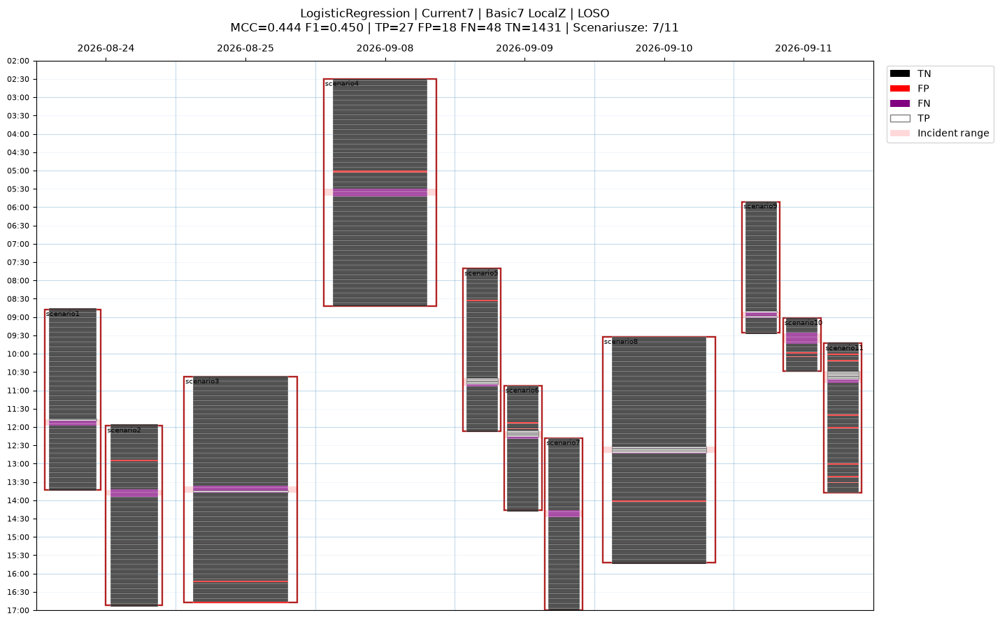

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\LogisticRegression__Current7

MODEL: SVM_RBF
WEJŚCIE: Current7
 1/11  scenario1 | MCC=+0.569 | TP= 2 FP=  0 FN= 4


C:\Users\kzieba\aiops\aiops_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


 2/11  scenario2 | MCC=+0.000 | TP= 0 FP=  0 FN= 6


C:\Users\kzieba\aiops\aiops_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


 3/11  scenario3 | MCC=+0.158 | TP= 1 FP=  4 FN= 5


C:\Users\kzieba\aiops\aiops_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (16 outputs left out)


=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,SVM_RBF,Current7,7,7,0.3909,0.4122,0.4821,0.36,27,29,48,1420,0.3915,0.8145



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.5694,0.5000,1.0000,0.3333,2,0,4,143,0.9012
1,scenario2,0.0000,0.0000,0.0000,0.0000,0,0,6,143,0.1634
2,scenario3,0.1578,0.1818,0.2000,0.1667,1,4,5,176,0.9639
3,scenario4,-0.0190,0.0000,0.0000,0.0000,0,2,6,178,0.0320
4,scenario5,0.7472,0.7273,1.0000,0.5714,4,0,3,127,0.9827
5,scenario6,0.8467,0.8571,0.8571,0.8571,6,1,1,95,0.9620
6,scenario7,-0.0162,0.0000,0.0000,0.0000,0,1,6,148,0.2534
7,scenario8,0.8278,0.8333,0.8333,0.8333,5,1,1,179,0.9334
8,scenario9,0.5665,0.5000,1.0000,0.3333,2,0,4,103,0.9496
9,scenario10,-0.1107,0.0000,0.0000,0.0000,0,2,9,33,0.1289


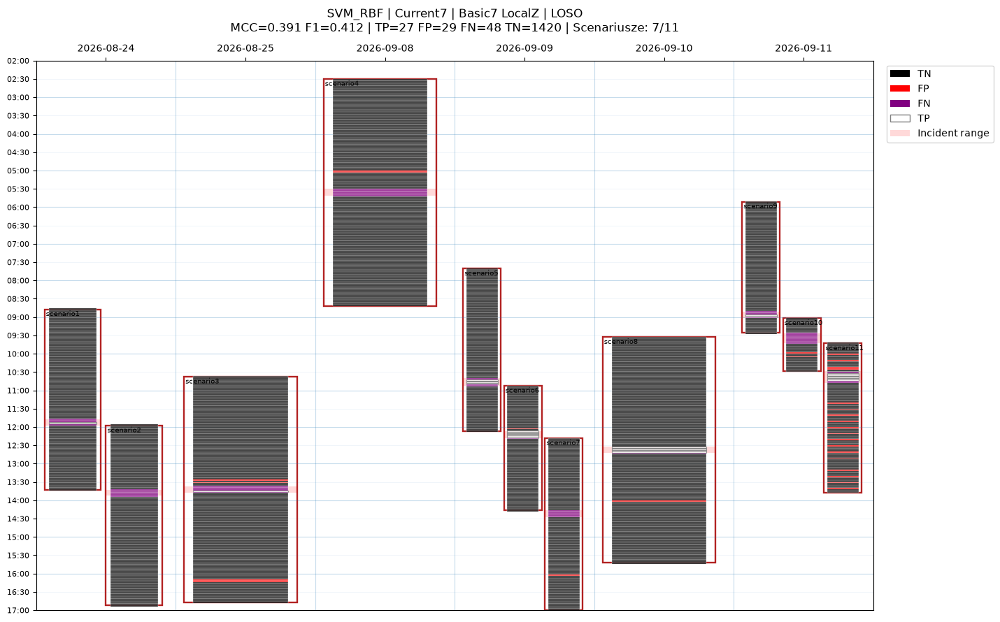

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\SVM_RBF__Current7

MODEL: RandomForest
WEJŚCIE: Current7
 1/11  scenario1 | MCC=+0.700 | TP= 3 FP=  0 FN= 3
 2/11  scenario2 | MCC=-0.029 | TP= 0 FP=  3 FN= 6
 3/11  scenario3 | MCC=+0.392 | TP= 2 FP=  2 FN= 4
 4/11  scenario4 | MCC=-0.019 | TP= 0 FP=  2 FN= 6
 5/11  scenario5 | MCC=+0.760 | TP= 5 FP=  1 FN= 2
 6/11  scenario6 | MCC=+0.786 | TP= 6 FP=  2 FN= 1
 7/11  scenario7 | MCC=+0.402 | TP= 1 FP=  0 FN= 5
 8/11  scenario8 | MCC=+0.828 | TP= 5 FP=  1 FN= 1
 9/11  scenario9 | MCC=+0.399 | TP= 1 FP=  0 FN= 5
10/11 scenario10 | MCC=+0.232 | TP= 2 FP=  2 FN= 7
11/11 scenario11 | MCC=+0.454 | TP= 8 FP= 16 FN= 2

=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,RandomForest,Current7,7,9,0.4599,0.4818,0.5323,0.44,33,29,42,1420,0.482,0.854



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.6998,0.6667,1.0000,0.5000,3,0,3,143,0.6943
1,scenario2,-0.0294,0.0000,0.0000,0.0000,0,3,6,140,0.4507
2,scenario3,0.3925,0.4000,0.5000,0.3333,2,2,4,178,0.8163
3,scenario4,-0.0190,0.0000,0.0000,0.0000,0,2,6,178,0.1856
4,scenario5,0.7600,0.7692,0.8333,0.7143,5,1,2,126,0.7741
5,scenario6,0.7864,0.8000,0.7500,0.8571,6,2,1,94,0.9357
6,scenario7,0.4016,0.2857,1.0000,0.1667,1,0,5,149,0.5447
7,scenario8,0.8278,0.8333,0.8333,0.8333,5,1,1,179,0.8811
8,scenario9,0.3987,0.2857,1.0000,0.1667,1,0,5,103,0.8275
9,scenario10,0.2316,0.3077,0.5000,0.2222,2,2,7,33,0.6766


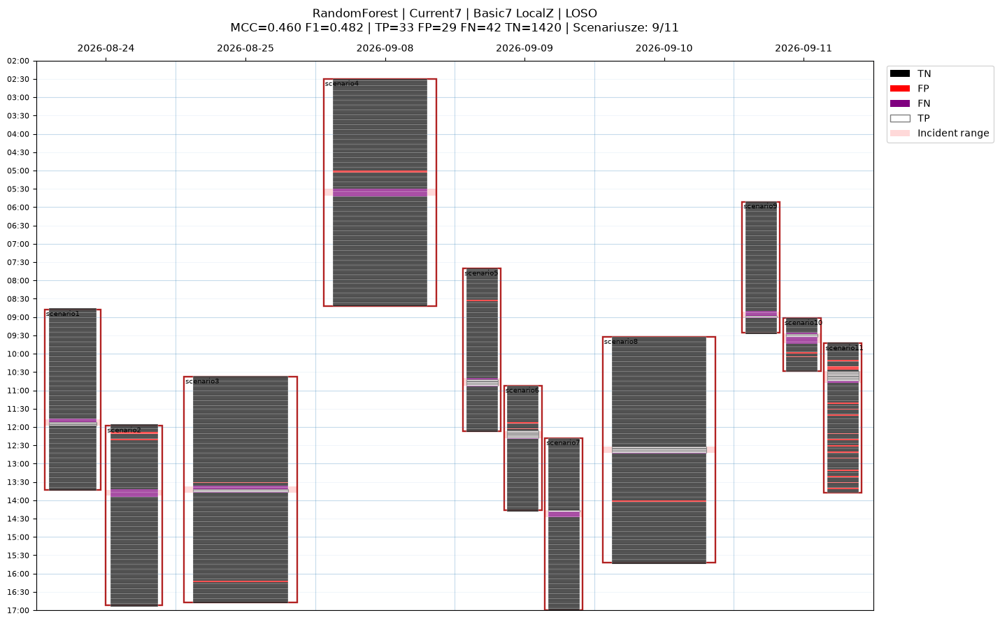

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\RandomForest__Current7

MODEL: HistGradientBoosting
WEJŚCIE: Current7
 1/11  scenario1 | MCC=+0.653 | TP= 4 FP=  2 FN= 2
 2/11  scenario2 | MCC=+0.341 | TP= 2 FP=  3 FN= 4
 3/11  scenario3 | MCC=+0.392 | TP= 2 FP=  2 FN= 4
 4/11  scenario4 | MCC=-0.019 | TP= 0 FP=  2 FN= 6
 5/11  scenario5 | MCC=+0.598 | TP= 4 FP=  2 FN= 3
 6/11  scenario6 | MCC=+0.786 | TP= 6 FP=  2 FN= 1
 7/11  scenario7 | MCC=+0.402 | TP= 1 FP=  0 FN= 5
 8/11  scenario8 | MCC=+0.763 | TP= 5 FP=  2 FN= 1
 9/11  scenario9 | MCC=+0.566 | TP= 2 FP=  0 FN= 4
10/11 scenario10 | MCC=+0.173 | TP= 2 FP=  3 FN= 7
11/11 scenario11 | MCC=+0.418 | TP= 7 FP= 14 FN= 3

=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,HistGradientBoosting,Current7,7,10,0.4691,0.493,0.5224,0.4667,35,32,40,1417,0.4264,0.7784



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.6527,0.6667,0.6667,0.6667,4,2,2,141,0.9546
1,scenario2,0.3410,0.3636,0.4000,0.3333,2,3,4,140,0.5304
2,scenario3,0.3925,0.4000,0.5000,0.3333,2,2,4,178,0.8228
3,scenario4,-0.0190,0.0000,0.0000,0.0000,0,2,6,178,0.0332
4,scenario5,0.5979,0.6154,0.6667,0.5714,4,2,3,125,0.8750
5,scenario6,0.7864,0.8000,0.7500,0.8571,6,2,1,94,0.9379
6,scenario7,0.4016,0.2857,1.0000,0.1667,1,0,5,149,0.5110
7,scenario8,0.7634,0.7692,0.7143,0.8333,5,2,1,178,0.9324
8,scenario9,0.5665,0.5000,1.0000,0.3333,2,0,4,103,0.9534
9,scenario10,0.1735,0.2857,0.4000,0.2222,2,3,7,32,0.6763


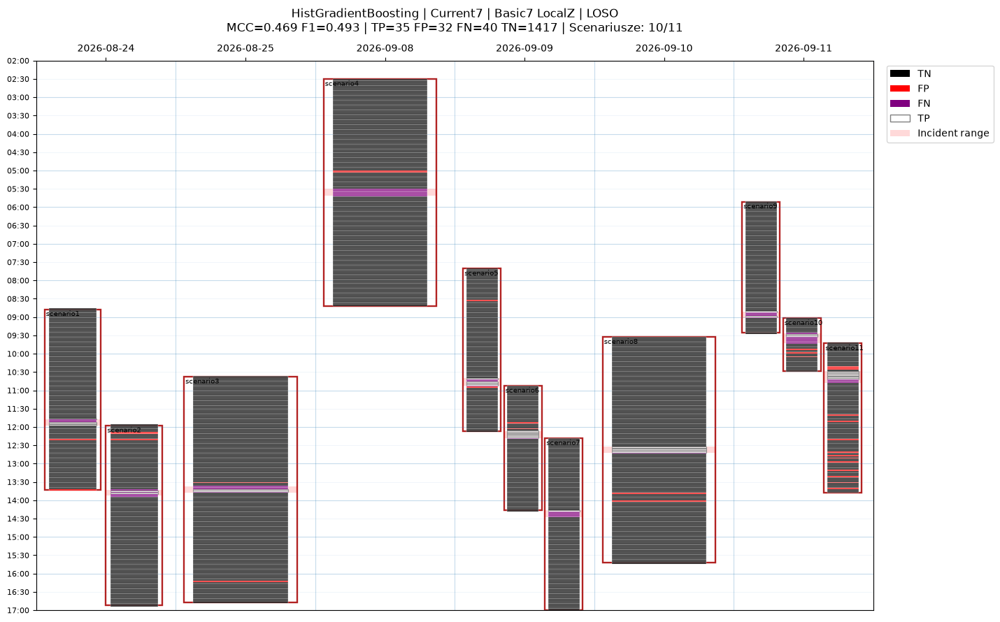

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\HistGradientBoosting__Current7

MODEL: LogisticRegression
WEJŚCIE: History15
 1/11  scenario1 | MCC=+0.401 | TP= 1 FP=  0 FN= 5
 2/11  scenario2 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | MCC=+0.261 | TP= 2 FP=  6 FN= 4
 4/11  scenario4 | MCC=-0.019 | TP= 0 FP=  2 FN= 6
 5/11  scenario5 | MCC=+0.699 | TP= 5 FP=  2 FN= 2
 6/11  scenario6 | MCC=+0.656 | TP= 6 FP=  5 FN= 1
 7/11  scenario7 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=+0.541 | TP= 6 FP= 13 FN= 0
 9/11  scenario9 | MCC=+0.757 | TP= 5 FP=  2 FN= 1
10/11 scenario10 | MCC=-0.111 | TP= 0 FP=  2 FN= 9
11/11 scenario11 | MCC=+0.804 | TP= 9 FP=  3 FN= 1

=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,LogisticRegression,History15,105,7,0.4465,0.4722,0.4928,0.4533,34,35,41,1414,0.4902,0.8065



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.4013,0.2857,1.0000,0.1667,1,0,5,143,0.8825
1,scenario2,0.0000,0.0000,0.0000,0.0000,0,0,6,143,0.2042
2,scenario3,0.2613,0.2857,0.2500,0.3333,2,6,4,174,0.8638
3,scenario4,-0.0190,0.0000,0.0000,0.0000,0,2,6,178,0.0002
4,scenario5,0.6985,0.7143,0.7143,0.7143,5,2,2,125,1.0000
5,scenario6,0.6560,0.6667,0.5455,0.8571,6,5,1,91,1.0000
6,scenario7,0.0000,0.0000,0.0000,0.0000,0,0,6,149,0.0501
7,scenario8,0.5413,0.4800,0.3158,1.0000,6,13,0,167,1.0000
8,scenario9,0.7572,0.7692,0.7143,0.8333,5,2,1,101,0.8807
9,scenario10,-0.1107,0.0000,0.0000,0.0000,0,2,9,33,0.1440


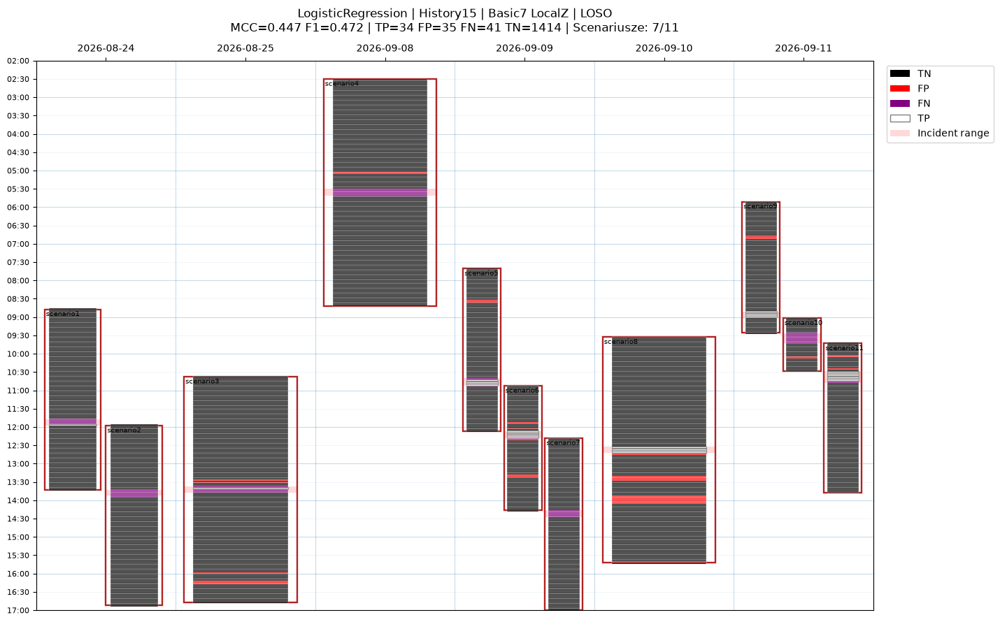

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\LogisticRegression__History15

MODEL: SVM_RBF
WEJŚCIE: History15
 1/11  scenario1 | MCC=+0.000 | TP= 0 FP=  0 FN= 6


C:\Users\kzieba\aiops\aiops_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


 2/11  scenario2 | MCC=+0.000 | TP= 0 FP=  0 FN= 6


C:\Users\kzieba\aiops\aiops_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


 3/11  scenario3 | MCC=+0.000 | TP= 0 FP=  0 FN= 6


C:\Users\kzieba\aiops\aiops_env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


... (16 outputs left out)


=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,SVM_RBF,History15,105,4,0.5355,0.4952,0.8667,0.3467,26,4,49,1445,0.5048,0.8492



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.0000,0.0000,0.0,0.0000,0,0,6,143,0.4585
1,scenario2,0.0000,0.0000,0.0,0.0000,0,0,6,143,0.1467
2,scenario3,0.0000,0.0000,0.0,0.0000,0,0,6,180,0.3360
3,scenario4,-0.0234,0.0000,0.0,0.0000,0,3,6,177,0.0163
4,scenario5,1.0000,1.0000,1.0,1.0000,7,0,0,127,0.9923
5,scenario6,1.0000,1.0000,1.0,1.0000,7,0,0,96,0.9394
6,scenario7,0.0000,0.0000,0.0,0.0000,0,0,6,149,0.0367
7,scenario8,0.7222,0.7273,0.8,0.6667,4,1,2,179,0.9115
8,scenario9,0.0000,0.0000,0.0,0.0000,0,0,6,103,0.2834
9,scenario10,0.0000,0.0000,0.0,0.0000,0,0,9,35,0.1853


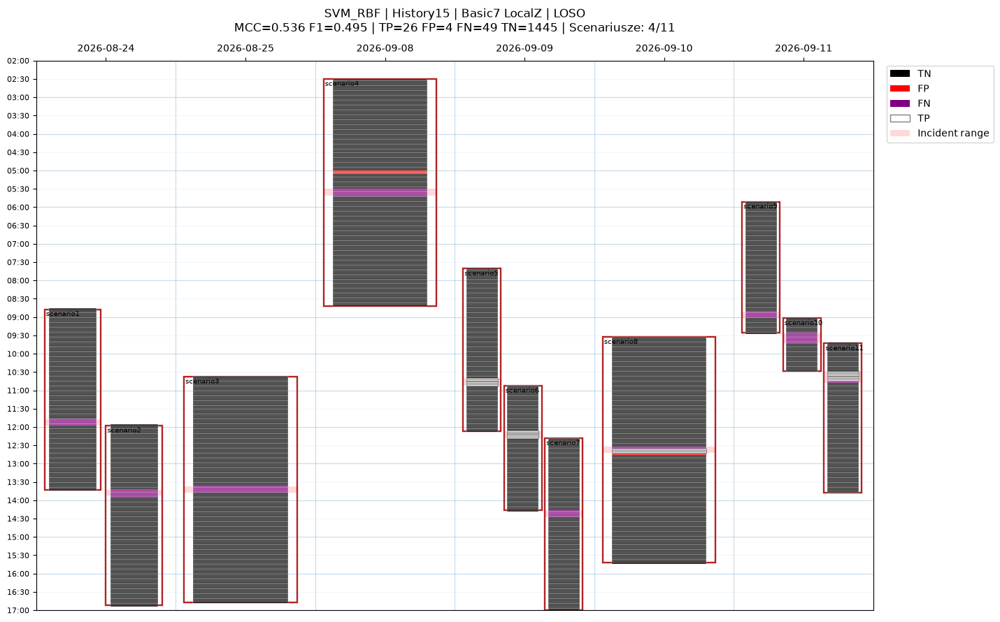

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\SVM_RBF__History15

MODEL: RandomForest
WEJŚCIE: History15
 1/11  scenario1 | MCC=+0.569 | TP= 2 FP=  0 FN= 4
 2/11  scenario2 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | MCC=-0.013 | TP= 0 FP=  1 FN= 6
 4/11  scenario4 | MCC=-0.013 | TP= 0 FP=  1 FN= 6
 5/11  scenario5 | MCC=+0.922 | TP= 6 FP=  0 FN= 1
 6/11  scenario6 | MCC=+0.921 | TP= 6 FP=  0 FN= 1
 7/11  scenario7 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=+0.722 | TP= 4 FP=  1 FN= 2
 9/11  scenario9 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
10/11 scenario10 | MCC=+0.000 | TP= 0 FP=  0 FN= 9
11/11 scenario11 | MCC=+0.716 | TP= 7 FP=  2 FN= 3

=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,RandomForest,History15,105,5,0.5137,0.4762,0.8333,0.3333,25,5,50,1444,0.5982,0.9235



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.5694,0.5000,1.0000,0.3333,2,0,4,143,0.5515
1,scenario2,0.0000,0.0000,0.0000,0.0000,0,0,6,143,0.2997
2,scenario3,-0.0134,0.0000,0.0000,0.0000,0,1,6,179,0.3954
3,scenario4,-0.0134,0.0000,0.0000,0.0000,0,1,6,179,0.1033
4,scenario5,0.9222,0.9231,1.0000,0.8571,6,0,1,127,0.7971
5,scenario6,0.9210,0.9231,1.0000,0.8571,6,0,1,96,0.7528
6,scenario7,0.0000,0.0000,0.0000,0.0000,0,0,6,149,0.1670
7,scenario8,0.7222,0.7273,0.8000,0.6667,4,1,2,179,0.7659
8,scenario9,0.0000,0.0000,0.0000,0.0000,0,0,6,103,0.4164
9,scenario10,0.0000,0.0000,0.0000,0.0000,0,0,9,35,0.2330


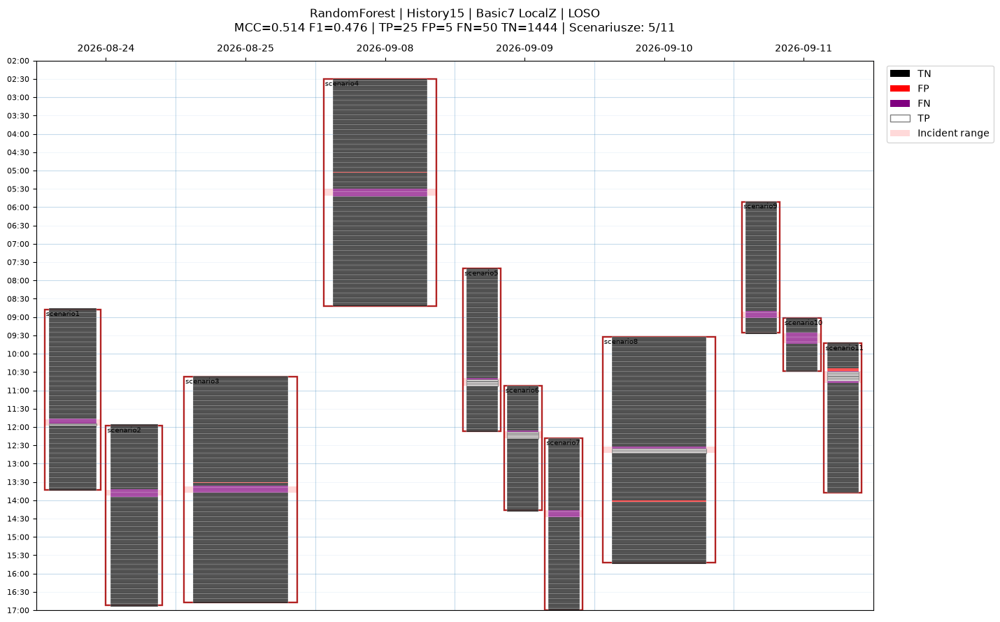

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\RandomForest__History15

MODEL: HistGradientBoosting
WEJŚCIE: History15
 1/11  scenario1 | MCC=+0.600 | TP= 3 FP=  1 FN= 3
 2/11  scenario2 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | MCC=+0.276 | TP= 1 FP=  1 FN= 5
 4/11  scenario4 | MCC=-0.013 | TP= 0 FP=  1 FN= 6
 5/11  scenario5 | MCC=+0.849 | TP= 6 FP=  1 FN= 1
 6/11  scenario6 | MCC=+1.000 | TP= 7 FP=  0 FN= 0
 7/11  scenario7 | MCC=+0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=+0.631 | TP= 5 FP=  5 FN= 1
 9/11  scenario9 | MCC=+0.399 | TP= 1 FP=  0 FN= 5
10/11 scenario10 | MCC=+0.310 | TP= 2 FP=  1 FN= 7
11/11 scenario11 | MCC=+0.736 | TP= 9 FP=  5 FN= 1

=== WYNIKI GLOBALNE ===


,model,input_mode,features,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN,AP,ROC_AUC
0,HistGradientBoosting,History15,105,8,0.5432,0.5484,0.6939,0.4533,34,15,41,1434,0.5825,0.9115



=== WYNIKI 11 SCENARIUSZY ===


,case,MCC,F1,precision,recall,TP,FP,FN,TN,max_incident_probability
0,scenario1,0.5996,0.6000,0.7500,0.5000,3,1,3,142,0.7893
1,scenario2,0.0000,0.0000,0.0000,0.0000,0,0,6,143,0.3709
2,scenario3,0.2760,0.2500,0.5000,0.1667,1,1,5,179,0.5300
3,scenario4,-0.0134,0.0000,0.0000,0.0000,0,1,6,179,0.0117
4,scenario5,0.8493,0.8571,0.8571,0.8571,6,1,1,126,0.9809
5,scenario6,1.0000,1.0000,1.0000,1.0000,7,0,0,96,0.9839
6,scenario7,0.0000,0.0000,0.0000,0.0000,0,0,6,149,0.0788
7,scenario8,0.6310,0.6250,0.5000,0.8333,5,5,1,175,0.9730
8,scenario9,0.3987,0.2857,1.0000,0.1667,1,0,5,103,0.9201
9,scenario10,0.3099,0.3333,0.6667,0.2222,2,1,7,34,0.7427


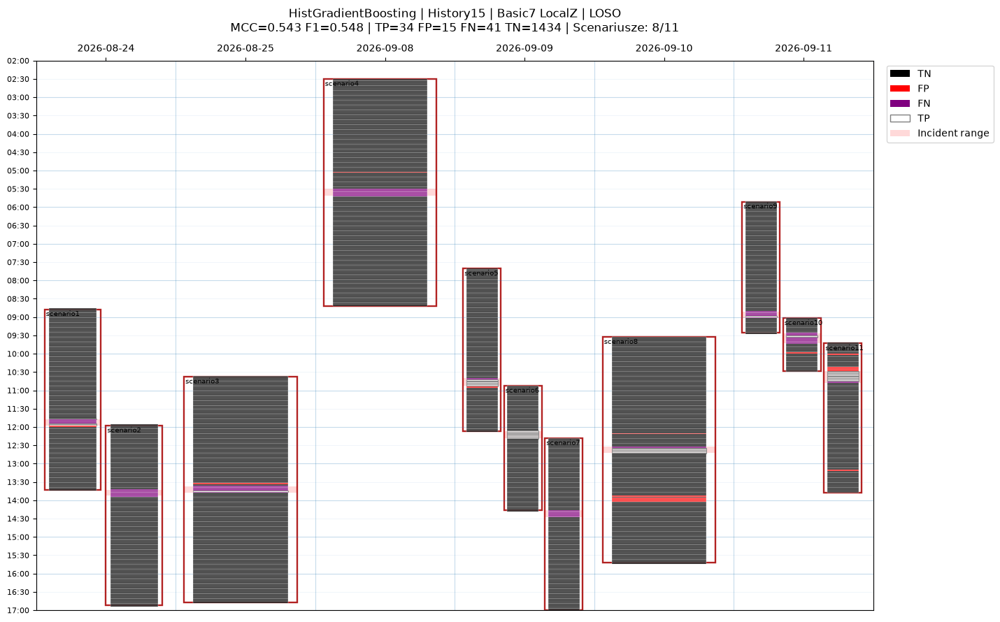

Zapisano wyniki: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ\HistGradientBoosting__History15

KOŃCOWY RANKING KLASYCZNYCH KLASYFIKATORÓW


,model,input_mode,features,MCC,F1,precision,recall,TP,FP,FN,TN,detected_scenarios,AP,ROC_AUC
7,HistGradientBoosting,History15,105,0.5432,0.5484,0.6939,0.4533,34,15,41,1434,8,0.5825,0.9115
5,SVM_RBF,History15,105,0.5355,0.4952,0.8667,0.3467,26,4,49,1445,4,0.5048,0.8492
6,RandomForest,History15,105,0.5137,0.4762,0.8333,0.3333,25,5,50,1444,5,0.5982,0.9235
3,HistGradientBoosting,Current7,7,0.4691,0.4930,0.5224,0.4667,35,32,40,1417,10,0.4264,0.7784
2,RandomForest,Current7,7,0.4599,0.4818,0.5323,0.4400,33,29,42,1420,9,0.4820,0.8540
4,LogisticRegression,History15,105,0.4465,0.4722,0.4928,0.4533,34,35,41,1414,7,0.4902,0.8065
0,LogisticRegression,Current7,7,0.4441,0.4500,0.6000,0.3600,27,18,48,1431,7,0.3399,0.7967
1,SVM_RBF,Current7,7,0.3909,0.4122,0.4821,0.3600,27,29,48,1420,7,0.3915,0.8145



=== KLASYFIKATORY KLASYCZNE VS LSTM ===


,model,input_mode,MCC,F1,TP,FP,FN,TN,detected_scenarios
9,HistGradientBoosting,History15,0.5432,0.5484,34,15,41,1434,8
7,SVM_RBF,History15,0.5355,0.4952,26,4,49,1445,4
1,LSTM_AIOps_Temporal18,History15,0.5238,0.5455,39,29,36,1420,9
0,LSTM_Basic7_LocalZ,History15,0.5143,0.5238,33,18,42,1431,7
8,RandomForest,History15,0.5137,0.4762,25,5,50,1444,5
5,HistGradientBoosting,Current7,0.4691,0.4930,35,32,40,1417,10
4,RandomForest,Current7,0.4599,0.4818,33,29,42,1420,9
6,LogisticRegression,History15,0.4465,0.4722,34,35,41,1414,7
2,LogisticRegression,Current7,0.4441,0.4500,27,18,48,1431,7
3,SVM_RBF,Current7,0.3909,0.4122,27,29,48,1420,7



Wszystkie wyniki zapisano w:
C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\classic_loso\Basic7_LocalZ


In [108]:
import gc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    confusion_matrix,
    matthews_corrcoef,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. KONFIGURACJA EKSPERYMENTU
# ============================================================

CLASSIC_OUT = (
    PREP_DIR
    / "classic_loso"
    / "Basic7_LocalZ"
)

CLASSIC_OUT.mkdir(
    parents=True, exist_ok=True
)

# Możesz pozostawić oba warianty.
INPUT_MODES = [
    "Current7",
    "History15",
]

POS_WEIGHT = 2.0
THRESHOLD = 0.50
SEED = 42

# Stałe ustawienia, bez strojenia na scenariuszach testowych.
CLASSIFIER_FACTORIES = {

    "LogisticRegression": lambda: LogisticRegression(
        C=1.0,
        max_iter=3000,
        random_state=SEED,
    ),

    "SVM_RBF": lambda: SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=SEED,
    ),

    "RandomForest": lambda: RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        max_features="sqrt",
        n_jobs=-1,
        random_state=SEED,
    ),

    "HistGradientBoosting": lambda: (
        HistGradientBoostingClassifier(
            max_iter=140,
            learning_rate=0.05,
            max_leaf_nodes=7,
            min_samples_leaf=10,
            l2_regularization=1.0,
            random_state=SEED,
        )
    ),
}


# ============================================================
# 2. FUNKCJE METRYK
# ============================================================

def classic_metrics(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


def classic_calendar(
    predictions,
    probabilities,
    title,
):

    plot_df = CLASSIC_DATA[
        [
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]
    ].copy()

    plot_df["prediction"] = predictions
    plot_df["probability"] = probabilities

    y = plot_df[
        "label_primary"
    ].astype(int).to_numpy()

    plot_df["outcome"] = np.select(
        [
            (y == 1) & (predictions == 1),
            (y == 0) & (predictions == 1),
            (y == 1) & (predictions == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    for col in ["timestamp", "bucket_end"]:
        plot_df[col] = (
            pd.to_datetime(plot_df[col], utc=True)
            .dt.tz_localize(None)
        )

    calendar = CALENDAR_SEGMENTS_3H.copy()

    for col in [
        "day",
        "scenario_start",
        "scenario_end",
        "incident_start",
        "incident_end",
    ]:
        calendar[col] = (
            pd.to_datetime(calendar[col], utc=True)
            .dt.tz_localize(None)
        )

    plot_calendar_with_buckets(
        calendar_segments=calendar,
        bucket_df=plot_df,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()


# ============================================================
# 3. LOSO DLA KAŻDEGO WARIANTU
# ============================================================

CLASSIC_SUMMARY_ROWS = []
CLASSIC_ALL_FOLD_ROWS = []

for input_mode in INPUT_MODES:

    for classifier_name, classifier_factory in (
        CLASSIFIER_FACTORIES.items()
    ):

        variant_name = (
            f"{classifier_name}__{input_mode}"
        )

        variant_dir = (
            CLASSIC_OUT / variant_name
        )

        (variant_dir / "models").mkdir(
            parents=True, exist_ok=True
        )

        (variant_dir / "predictions").mkdir(
            parents=True, exist_ok=True
        )

        print("\n" + "=" * 85)
        print("MODEL:", classifier_name)
        print("WEJŚCIE:", input_mode)
        print("=" * 85)

        predictions_all = np.full(
            len(CLASSIC_DATA),
            -1,
            dtype=int,
        )

        probabilities_all = np.full(
            len(CLASSIC_DATA),
            np.nan,
            dtype=float,
        )

        fold_rows = []

        for fold, test_case in enumerate(
            SCENARIOS, start=1
        ):

            train_idx = np.flatnonzero(
                CLASSIC_CASES != test_case
            )

            test_idx = np.flatnonzero(
                CLASSIC_CASES == test_case
            )

            # ------------------------------------------------
            # LOCAL Z-SCORE — osobno dla każdego foldu.
            # ------------------------------------------------

            X7, scaler, sigma_floors = (
                classic_local_z(train_idx)
            )

            if input_mode == "Current7":

                X = X7
                feature_names = list(CLASSIC_FEATURES)

            elif input_mode == "History15":

                X = classic_history15(X7)

                feature_names = [
                    f"lag_{lag}_{feature}"
                    for lag in range(-14, 1)
                    for feature in CLASSIC_FEATURES
                ]

            else:
                raise ValueError(
                    f"Nieznany input_mode: {input_mode}"
                )

            # ------------------------------------------------
            # TEN SAM POS_WEIGHT=2
            # ------------------------------------------------

            sample_weights = np.where(
                CLASSIC_Y[train_idx] == 1,
                POS_WEIGHT,
                1.0,
            )

            model = classifier_factory()

            model.fit(
                X[train_idx],
                CLASSIC_Y[train_idx],
                sample_weight=sample_weights,
            )

            # ------------------------------------------------
            # PREDYKCJA TESTOWA
            # ------------------------------------------------

            probabilities = (
                model.predict_proba(X[test_idx])[:, 1]
            )

            predictions = (
                probabilities >= THRESHOLD
            ).astype(int)

            predictions_all[test_idx] = predictions
            probabilities_all[test_idx] = probabilities

            metrics = classic_metrics(
                CLASSIC_Y[test_idx],
                predictions,
            )

            incident_mask = (
                CLASSIC_Y[test_idx] == 1
            )

            fold_rows.append({
                "model": classifier_name,
                "input_mode": input_mode,
                "case": test_case,
                "n_features": X.shape[1],
                **metrics,
                "max_incident_probability": float(
                    np.max(
                        probabilities[incident_mask]
                    )
                ),
            })

            # ------------------------------------------------
            # ZAPIS PREDYKCJI
            # ------------------------------------------------

            prediction_df = CLASSIC_DATA.iloc[
                test_idx
            ][[
                "case",
                "timestamp",
                "bucket_end",
                "label_primary",
                "label_all_known",
            ]].copy()

            prediction_df["prediction"] = predictions
            prediction_df["probability"] = probabilities

            joblib.dump(
                {
                    "data": prediction_df,
                    "metrics": metrics,
                },
                variant_dir
                / "predictions"
                / f"{test_case}.joblib",
                compress=3,
            )

            # Zapis kompletnego pipeline'u foldu.
            joblib.dump(
                {
                    "model": model,
                    "scaler": scaler,
                    "sigma_floors": sigma_floors,
                    "features": feature_names,
                    "base_features": CLASSIC_FEATURES,
                    "input_mode": input_mode,
                    "sequence_length": (
                        15 if input_mode == "History15"
                        else 1
                    ),
                    "threshold": THRESHOLD,
                    "pos_weight": POS_WEIGHT,
                },
                variant_dir
                / "models"
                / f"{test_case}.joblib",
                compress=3,
            )

            print(
                f"{fold:2d}/11 "
                f"{test_case:>10} | "
                f"MCC={metrics['MCC']:+.3f} | "
                f"TP={metrics['TP']:2d} "
                f"FP={metrics['FP']:3d} "
                f"FN={metrics['FN']:2d}",
                flush=True,
            )

            del X, X7, model
            gc.collect()

        # ====================================================
        # 4. GLOBALNE METRYKI PO PEŁNYM LOSO
        # ====================================================

        assert (predictions_all >= 0).all()
        assert np.isfinite(probabilities_all).all()

        overall = classic_metrics(
            CLASSIC_Y, predictions_all
        )

        detected_cases = sum(
            row["TP"] > 0
            for row in fold_rows
        )

        ap = average_precision_score(
            CLASSIC_Y,
            probabilities_all,
        )

        auc = roc_auc_score(
            CLASSIC_Y,
            probabilities_all,
        )

        summary_row = {
            "model": classifier_name,
            "input_mode": input_mode,
            "features": (
                7 if input_mode == "Current7"
                else 105
            ),
            "detected_scenarios": detected_cases,
            **overall,
            "AP": ap,
            "ROC_AUC": auc,
        }

        CLASSIC_SUMMARY_ROWS.append(summary_row)
        CLASSIC_ALL_FOLD_ROWS.extend(fold_rows)

        print("\n=== WYNIKI GLOBALNE ===")

        display(
            pd.DataFrame([
                summary_row
            ]).round(4)
        )

        print("\n=== WYNIKI 11 SCENARIUSZY ===")

        fold_table = pd.DataFrame(fold_rows)

        display(
            fold_table[
                [
                    "case",
                    "MCC",
                    "F1",
                    "precision",
                    "recall",
                    "TP",
                    "FP",
                    "FN",
                    "TN",
                    "max_incident_probability",
                ]
            ].round(4)
        )

        # ====================================================
        # 5. ORYGINALNY KALENDARZ
        # ====================================================

        title = (
            f"{classifier_name} | {input_mode} "
            f"| Basic7 LocalZ | LOSO\n"
            f"MCC={overall['MCC']:.3f} "
            f"F1={overall['F1']:.3f} | "
            f"TP={overall['TP']} "
            f"FP={overall['FP']} "
            f"FN={overall['FN']} "
            f"TN={overall['TN']} | "
            f"Scenariusze: {detected_cases}/11"
        )

        classic_calendar(
            predictions_all,
            probabilities_all,
            title,
        )

        # ====================================================
        # 6. ZAPIS RAPORTÓW
        # ====================================================

        fold_table.to_csv(
            variant_dir / "by_scenario.csv",
            index=False,
        )

        pd.DataFrame([
            summary_row
        ]).to_csv(
            variant_dir / "overall.csv",
            index=False,
        )

        print(
            "Zapisano wyniki:",
            variant_dir,
        )


# ============================================================
# 7. RANKING WSZYSTKICH KLASYCZNYCH KLASYFIKATORÓW
# ============================================================

CLASSIC_SUMMARY = pd.DataFrame(
    CLASSIC_SUMMARY_ROWS
)

CLASSIC_FOLD_RESULTS = pd.DataFrame(
    CLASSIC_ALL_FOLD_ROWS
)

print("\n" + "=" * 90)
print("KOŃCOWY RANKING KLASYCZNYCH KLASYFIKATORÓW")
print("=" * 90)

display(
    CLASSIC_SUMMARY.sort_values(
        "MCC", ascending=False
    )[
        [
            "model",
            "input_mode",
            "features",
            "MCC",
            "F1",
            "precision",
            "recall",
            "TP",
            "FP",
            "FN",
            "TN",
            "detected_scenarios",
            "AP",
            "ROC_AUC",
        ]
    ].round(4)
)

CLASSIC_SUMMARY.to_csv(
    CLASSIC_OUT / "all_models_summary.csv",
    index=False,
)

CLASSIC_FOLD_RESULTS.to_csv(
    CLASSIC_OUT / "all_fold_results.csv",
    index=False,
)


# ============================================================
# 8. PORÓWNANIE Z LSTM
# ============================================================

BASELINES = pd.DataFrame([
    {
        "model": "LSTM_Basic7_LocalZ",
        "input_mode": "History15",
        "MCC": 0.5143,
        "F1": 0.5238,
        "TP": 33,
        "FP": 18,
        "FN": 42,
        "TN": 1431,
        "detected_scenarios": 7,
    },
    {
        "model": "LSTM_AIOps_Temporal18",
        "input_mode": "History15",
        "MCC": 0.5238,
        "F1": 0.5455,
        "TP": 39,
        "FP": 29,
        "FN": 36,
        "TN": 1420,
        "detected_scenarios": 9,
    },
])

COMPARE_FINAL = pd.concat(
    [
        BASELINES,
        CLASSIC_SUMMARY[
            [
                "model",
                "input_mode",
                "MCC",
                "F1",
                "TP",
                "FP",
                "FN",
                "TN",
                "detected_scenarios",
            ]
        ],
    ],
    ignore_index=True,
)

print("\n=== KLASYFIKATORY KLASYCZNE VS LSTM ===")

display(
    COMPARE_FINAL.sort_values(
        "MCC", ascending=False
    ).round(4)
)

COMPARE_FINAL.to_csv(
    CLASSIC_OUT / "comparison_with_lstm.csv",
    index=False,
)

print("\nWszystkie wyniki zapisano w:")
print(CLASSIC_OUT)

In [109]:
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

PARSER_OUT = PREP_DIR / "nn_loso" / "parser_comparison"
PARSER_CACHE = PARSER_OUT / "buckets"
PARSER_CACHE.mkdir(parents=True, exist_ok=True)

PARSER_BASE7 = list(BASIC_FEATURES)

# Przykładowe nazwy. Będą sprawdzane, nie zakładamy
# że ich cache rzeczywiście istnieje.
EXTRA_PARSER_CANDIDATES = [
    "Spell", "IPLoM", "AEL", "LenMa"
]

# Wykrycie nazw parserów z istniejących kubełków.
detected_parsers = set()

for p in BUCKET_DIR.glob("*.joblib"):
    for case in SCENARIOS:
        suffix = f"__{case}__2min.joblib"
        if p.name.endswith(suffix):
            detected_parsers.add(p.name[:-len(suffix)])

PARSERS_TO_CHECK = list(dict.fromkeys(
    ["Drain3"]
    + sorted(detected_parsers - {"Drain3"})
    + EXTRA_PARSER_CANDIDATES
))

print("Parsery do sprawdzenia:", PARSERS_TO_CHECK)

PARSER_DATASETS = {}
PARSER_ERRORS = {}
PREP_ROWS = []


def prepare_parser_buckets(parser, case):
    """Bierze gotowe kubełki albo buduje je z cache parsera."""

    original_path = (
        BUCKET_DIR / f"{parser}__{case}__2min.joblib"
    )
    generated_path = (
        PARSER_CACHE / f"{parser}__{case}__2min.joblib"
    )

    if original_path.exists():
        buckets = joblib.load(original_path)
        source = "existing_buckets"

    elif generated_path.exists():
        buckets = joblib.load(generated_path)
        source = "generated_cache"

    else:
        parsed = get_parsed_dataframe(parser, case)

        if not isinstance(parsed, pd.DataFrame):
            raise TypeError(
                f"{parser}/{case}: parser nie zwrócił DataFrame"
            )

        required = {"timestamp", "template_id", "namespace"}
        missing = required - set(parsed.columns)

        if missing:
            raise ValueError(
                f"{parser}/{case}: brak kolumn {missing}"
            )

        buckets = build_namespace_buckets(
            parsed,
            window_size="2min",
            history_minutes=30,
        )

        if not isinstance(buckets, pd.DataFrame):
            raise TypeError(
                f"{parser}/{case}: agregator nie zwrócił "
                "DataFrame"
            )

        source = "built_from_parser_cache"

    required = {"timestamp"} | set(PARSER_BASE7)
    missing = required - set(buckets.columns)

    if missing:
        raise ValueError(
            f"{parser}/{case}: brak cech {missing}"
        )

    buckets = buckets.copy()
    buckets["timestamp"] = pd.to_datetime(
        buckets["timestamp"], utc=True
    )

    if buckets["timestamp"].duplicated().any():
        raise ValueError(
            f"{parser}/{case}: zduplikowane kubełki"
        )

    # Etykiety i przedziały pochodzą z jednego,
    # wspólnego kalendarza referencyjnego.
    reference = joblib.load(
        BUCKET_DIR / f"Drain3__{case}__2min.joblib"
    ).copy()

    for col in ["timestamp", "bucket_end"]:
        reference[col] = pd.to_datetime(
            reference[col], utc=True
        )

    reference["case"] = case

    reference = (
        reference[
            [
                "case", "timestamp", "bucket_end",
                "label_primary", "label_all_known",
                "total_logs",
            ]
        ]
        .rename(columns={"total_logs": "reference_logs"})
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    features = buckets[
        ["timestamp"] + PARSER_BASE7
    ].copy()

    for col in PARSER_BASE7:
        features[col] = pd.to_numeric(
            features[col], errors="raise"
        )

    aligned = reference.merge(
        features,
        on="timestamp",
        how="left",
        validate="one_to_one",
        indicator=True,
    )

    if not aligned["_merge"].eq("both").all():
        raise ValueError(
            f"{parser}/{case}: parser nie pokrywa całej "
            "referencyjnej siatki kubełków"
        )

    if not np.allclose(
        aligned["total_logs"].to_numpy(dtype=float),
        aligned["reference_logs"].to_numpy(dtype=float),
    ):
        raise ValueError(
            f"{parser}/{case}: total_logs różni się od Drain3. "
            "Sprawdź, czy parser nie pominął logów."
        )

    if not np.isfinite(
        aligned[PARSER_BASE7].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"{parser}/{case}: NaN/inf w cechach"
        )

    aligned = aligned.drop(
        columns=["_merge", "reference_logs"]
    )

    # Cache tworzymy tylko dla nowo zbudowanych kubełków.
    if source == "built_from_parser_cache":
        joblib.dump(
            aligned,
            generated_path,
            compress=3,
        )

    return aligned, source


for parser in PARSERS_TO_CHECK:

    frames = []
    sources = []

    try:
        for case in SCENARIOS:
            frame, source = prepare_parser_buckets(
                parser, case
            )
            frames.append(frame)
            sources.append(source)

        data = pd.concat(
            frames, ignore_index=True
        )

        assert len(data) == 1524
        assert data["label_primary"].sum() == 75

        PARSER_DATASETS[parser] = data

        PREP_ROWS.append({
            "parser": parser,
            "status": "READY",
            "buckets": len(data),
            "generated_cases": sources.count(
                "built_from_parser_cache"
            ),
        })

        print(f"OK: {parser} — 11 scenariuszy")

    except Exception as exc:
        PARSER_ERRORS[parser] = str(exc)

        PREP_ROWS.append({
            "parser": parser,
            "status": "UNAVAILABLE",
            "buckets": 0,
            "generated_cases": 0,
        })

        print(
            f"Pominięto {parser}: "
            f"{type(exc).__name__}: {str(exc)[:220]}"
        )

PARSER_READY = list(PARSER_DATASETS)

print("\n=== DOSTĘPNE PARSERY ===")
display(pd.DataFrame(PREP_ROWS))

print("\nGotowe do treningu:", PARSER_READY)

Parsery do sprawdzenia: ['Drain3', 'AEL', 'IPLoM', 'Spell', 'LenMa']
OK: Drain3 — 11 scenariuszy
OK: AEL — 11 scenariuszy
OK: IPLoM — 11 scenariuszy
OK: Spell — 11 scenariuszy
Pominięto LenMa: FileNotFoundError: Nie znaleziono cache parsera:
C:\Users\kzieba\aiops_private\results\evaluation_3h\parsed_cache\LenMa_scenario1.joblib

=== DOSTĘPNE PARSERY ===


,parser,status,buckets,generated_cases
0,Drain3,READY,1524,0
1,AEL,READY,1524,0
2,IPLoM,READY,1524,0
3,Spell,READY,1524,0
4,LenMa,UNAVAILABLE,0,0



Gotowe do treningu: ['Drain3', 'AEL', 'IPLoM', 'Spell']



PARSER: Drain3
 1/11  scenario1 | MCC=0.569 | TP= 2 FP=  0 FN= 4
 2/11  scenario2 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | MCC=0.218 | TP= 1 FP=  2 FN= 5
 4/11  scenario4 | MCC=-0.013 | TP= 0 FP=  1 FN= 6
 5/11  scenario5 | MCC=0.922 | TP= 6 FP=  0 FN= 1
 6/11  scenario6 | MCC=0.931 | TP= 7 FP=  1 FN= 0
 7/11  scenario7 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=0.409 | TP= 4 FP= 10 FN= 2
 9/11  scenario9 | MCC=0.809 | TP= 4 FP=  0 FN= 2
10/11 scenario10 | MCC=0.000 | TP= 0 FP=  0 FN= 9
11/11 scenario11 | MCC=0.769 | TP= 9 FP=  4 FN= 1

=== WYNIKI GLOBALNE ===


,parser,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,Drain3,LSTM_Basic7_LocalZ,7,0.5143,0.5238,0.6471,0.44,33,18,42,1431



=== WYNIKI SCENARIUSZY ===


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,0.5694,0.5000,2,0,4,143
1,scenario2,0.0000,0.0000,0,0,6,143
2,scenario3,0.2182,0.2222,1,2,5,178
3,scenario4,-0.0134,0.0000,0,1,6,179
4,scenario5,0.9222,0.9231,6,0,1,127
5,scenario6,0.9305,0.9333,7,1,0,95
6,scenario7,0.0000,0.0000,0,0,6,149
7,scenario8,0.4093,0.4000,4,10,2,170
8,scenario9,0.8087,0.8000,4,0,2,103
9,scenario10,0.0000,0.0000,0,0,9,35


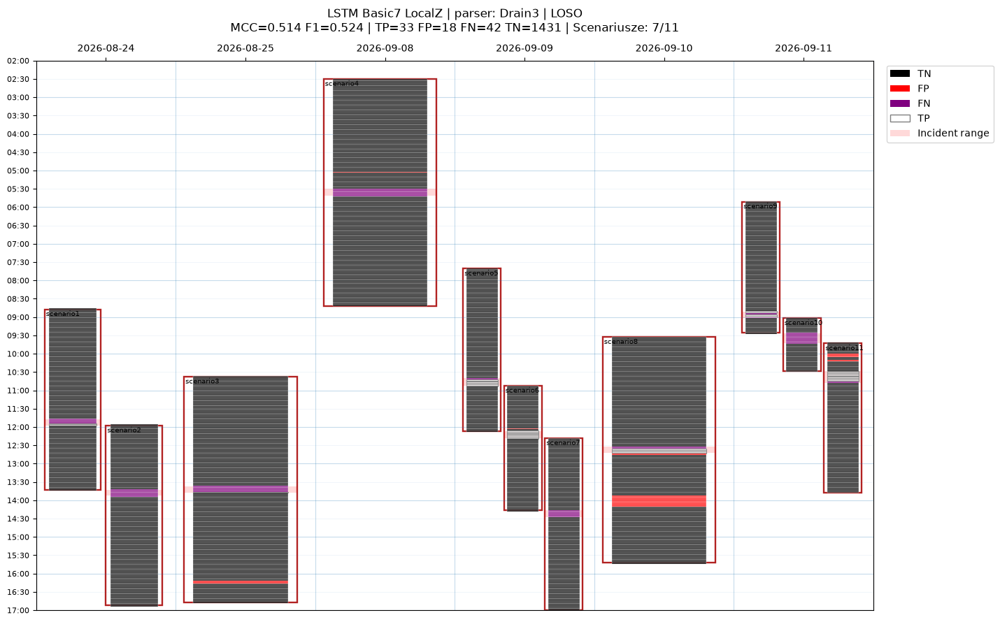

Kontrola odtworzenia Drain3 — wcześniejszy MCC: 0.5143, obecny: 0.5143

PARSER: AEL
 1/11  scenario1 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 2/11  scenario2 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | MCC=0.534 | TP= 3 FP=  2 FN= 3
 4/11  scenario4 | MCC=-0.030 | TP= 0 FP=  5 FN= 6
 5/11  scenario5 | MCC=0.922 | TP= 6 FP=  0 FN= 1
 6/11  scenario6 | MCC=0.823 | TP= 7 FP=  3 FN= 0
 7/11  scenario7 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=0.340 | TP= 4 FP= 15 FN= 2
 9/11  scenario9 | MCC=0.809 | TP= 4 FP=  0 FN= 2
10/11 scenario10 | MCC=0.000 | TP= 0 FP=  0 FN= 9
11/11 scenario11 | MCC=0.891 | TP= 9 FP=  1 FN= 1

=== WYNIKI GLOBALNE ===


,parser,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,AEL,LSTM_Basic7_LocalZ,6,0.4733,0.4925,0.5593,0.44,33,26,42,1423



=== WYNIKI SCENARIUSZY ===


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,0.0000,0.0000,0,0,6,143
1,scenario2,0.0000,0.0000,0,0,6,143
2,scenario3,0.5341,0.5455,3,2,3,178
3,scenario4,-0.0303,0.0000,0,5,6,175
4,scenario5,0.9222,0.9231,6,0,1,127
5,scenario6,0.8235,0.8235,7,3,0,93
6,scenario7,0.0000,0.0000,0,0,6,149
7,scenario8,0.3403,0.3200,4,15,2,165
8,scenario9,0.8087,0.8000,4,0,2,103
9,scenario10,0.0000,0.0000,0,0,9,35


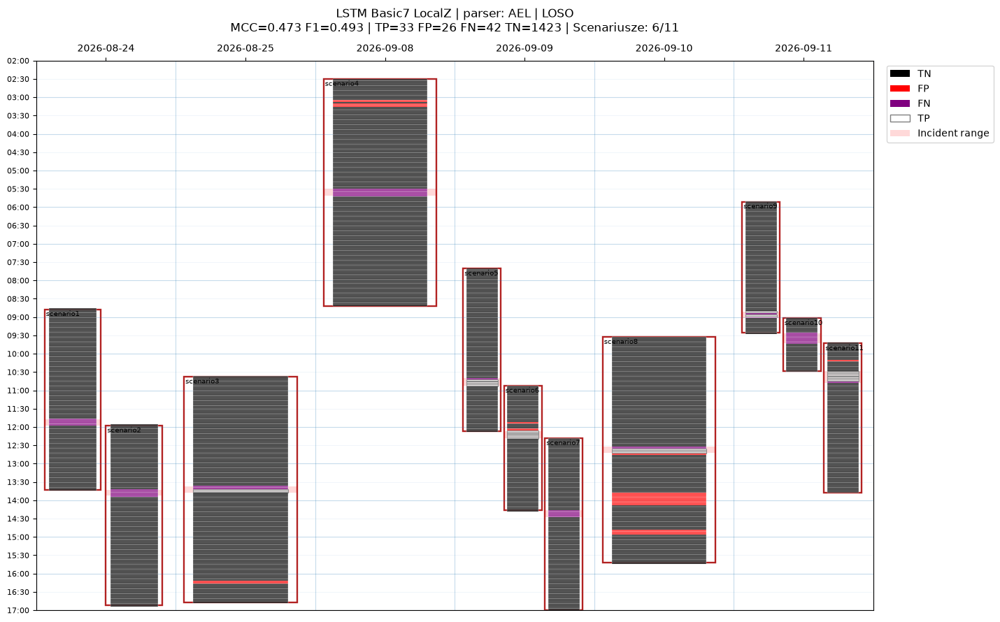


PARSER: IPLoM
 1/11  scenario1 | MCC=0.811 | TP= 4 FP=  0 FN= 2
 2/11  scenario2 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | MCC=-0.019 | TP= 0 FP=  2 FN= 6
 4/11  scenario4 | MCC=-0.013 | TP= 0 FP=  1 FN= 6
 5/11  scenario5 | MCC=0.922 | TP= 6 FP=  0 FN= 1
 6/11  scenario6 | MCC=0.931 | TP= 7 FP=  1 FN= 0
 7/11  scenario7 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=0.599 | TP= 5 FP=  6 FN= 1
 9/11  scenario9 | MCC=1.000 | TP= 6 FP=  0 FN= 0
10/11 scenario10 | MCC=0.000 | TP= 0 FP=  0 FN= 9
11/11 scenario11 | MCC=0.945 | TP= 9 FP=  0 FN= 1

=== WYNIKI GLOBALNE ===


,parser,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,IPLoM,LSTM_Basic7_LocalZ,6,0.6086,0.6066,0.7872,0.4933,37,10,38,1439



=== WYNIKI SCENARIUSZY ===


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,0.8108,0.8000,4,0,2,143
1,scenario2,0.0000,0.0000,0,0,6,143
2,scenario3,-0.0190,0.0000,0,2,6,178
3,scenario4,-0.0134,0.0000,0,1,6,179
4,scenario5,0.9222,0.9231,6,0,1,127
5,scenario6,0.9305,0.9333,7,1,0,95
6,scenario7,0.0000,0.0000,0,0,6,149
7,scenario8,0.5992,0.5882,5,6,1,174
8,scenario9,1.0000,1.0000,6,0,0,103
9,scenario10,0.0000,0.0000,0,0,9,35


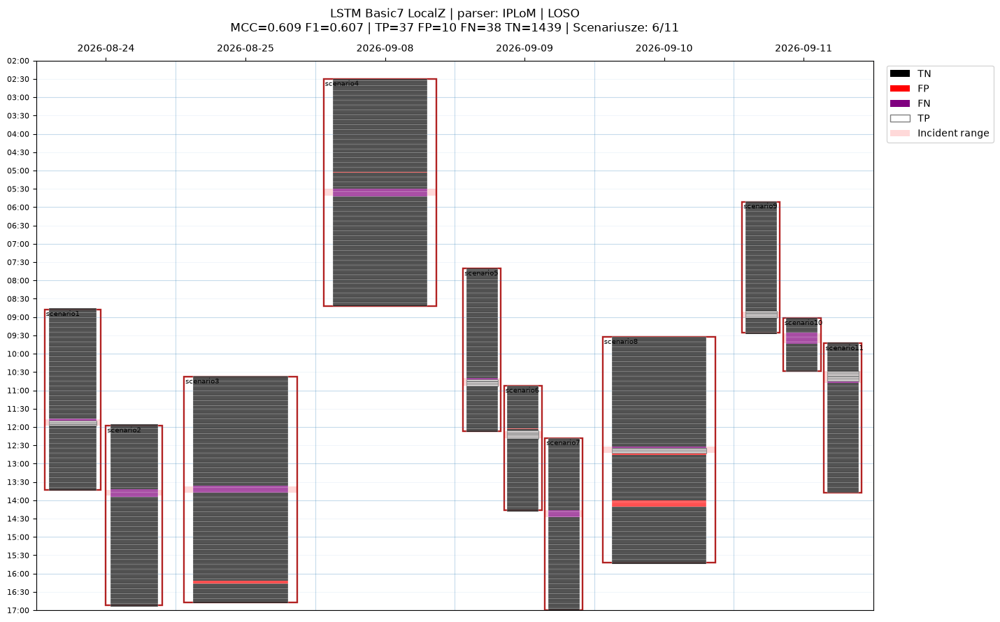


PARSER: Spell
 1/11  scenario1 | MCC=-0.017 | TP= 0 FP=  1 FN= 6
 2/11  scenario2 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 3/11  scenario3 | MCC=0.602 | TP= 3 FP=  1 FN= 3
 4/11  scenario4 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 5/11  scenario5 | MCC=0.849 | TP= 6 FP=  1 FN= 1
 6/11  scenario6 | MCC=0.756 | TP= 5 FP=  1 FN= 2
 7/11  scenario7 | MCC=0.000 | TP= 0 FP=  0 FN= 6
 8/11  scenario8 | MCC=-0.036 | TP= 0 FP=  7 FN= 6
 9/11  scenario9 | MCC=0.908 | TP= 5 FP=  0 FN= 1
10/11 scenario10 | MCC=0.000 | TP= 0 FP=  0 FN= 9
11/11 scenario11 | MCC=0.672 | TP= 8 FP=  5 FN= 2

=== WYNIKI GLOBALNE ===


,parser,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,Spell,LSTM_Basic7_LocalZ,5,0.4559,0.4576,0.6279,0.36,27,16,48,1433



=== WYNIKI SCENARIUSZY ===


,case,MCC,F1,TP,FP,FN,TN
0,scenario1,-0.0168,0.0000,0,1,6,142
1,scenario2,0.0000,0.0000,0,0,6,143
2,scenario3,0.6022,0.6000,3,1,3,179
3,scenario4,0.0000,0.0000,0,0,6,180
4,scenario5,0.8493,0.8571,6,1,1,126
5,scenario6,0.7563,0.7692,5,1,2,95
6,scenario7,0.0000,0.0000,0,0,6,149
7,scenario8,-0.0361,0.0000,0,7,6,173
8,scenario9,0.9085,0.9091,5,0,1,103
9,scenario10,0.0000,0.0000,0,0,9,35


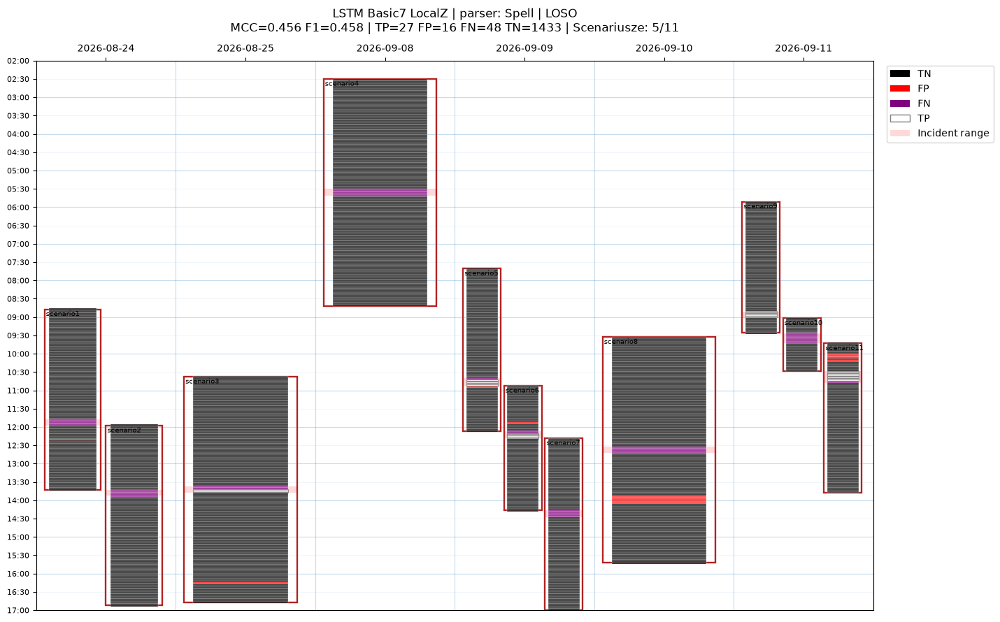


=== PORÓWNANIE PARSERÓW ===


,parser,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
2,IPLoM,LSTM_Basic7_LocalZ,6,0.6086,0.6066,0.7872,0.4933,37,10,38,1439
0,Drain3,LSTM_Basic7_LocalZ,7,0.5143,0.5238,0.6471,0.4400,33,18,42,1431
1,AEL,LSTM_Basic7_LocalZ,6,0.4733,0.4925,0.5593,0.4400,33,26,42,1423
3,Spell,LSTM_Basic7_LocalZ,5,0.4559,0.4576,0.6279,0.3600,27,16,48,1433


In [110]:
import gc
import os
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    matthews_corrcoef,
    f1_score,
    precision_score,
    recall_score,
)
from IPython.display import display

PARSERS_TO_TRAIN = list(PARSER_READY)

SEED = 42
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))


class ParserLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=7,
            hidden_size=24,
            num_layers=1,
            batch_first=True,
        )
        self.dropout = nn.Dropout(0.2)
        self.head = nn.Linear(24, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.head(
            self.dropout(output[:, -1, :])
        ).squeeze(-1)


def evaluate_parser(y, prediction):
    tn, fp, fn, tp = confusion_matrix(
        y, prediction, labels=[0, 1]
    ).ravel()

    return {
        "MCC": matthews_corrcoef(y, prediction),
        "F1": f1_score(y, prediction, zero_division=0),
        "precision": precision_score(
            y, prediction, zero_division=0
        ),
        "recall": recall_score(
            y, prediction, zero_division=0
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
    }


PARSER_RESULTS = []
PARSER_FOLD_RESULTS = []

for parser in PARSERS_TO_TRAIN:

    print("\n" + "=" * 75)
    print("PARSER:", parser)
    print("=" * 75)

    data = (
        PARSER_DATASETS[parser]
        .sort_values(["case", "timestamp"])
        .reset_index(drop=True)
        .copy()
    )

    y = data["label_primary"].astype(int).to_numpy()
    case_array = data["case"].astype(str).to_numpy()

    raw = data[PARSER_BASE7].astype(float)

    # Nie przenosimy historii między scenariuszami.
    new_run = (
        data["case"].ne(data["case"].shift())
        | data["timestamp"].diff().ne(
            pd.Timedelta("2min")
        )
    )
    data["run_id"] = new_run.cumsum()

    past_mean = pd.DataFrame(index=data.index)
    past_std = pd.DataFrame(index=data.index)

    for feature in PARSER_BASE7:
        previous = raw[feature].groupby(
            data["run_id"], sort=False
        ).shift(1)

        grouped = previous.groupby(
            data["run_id"], sort=False
        )

        past_mean[feature] = grouped.transform(
            lambda s: s.rolling(
                15, min_periods=5
            ).mean()
        )
        past_std[feature] = grouped.transform(
            lambda s: s.rolling(
                15, min_periods=5
            ).std(ddof=0)
        )

    pred_all = np.full(len(data), -1, dtype=int)
    prob_all = np.full(len(data), np.nan)
    fold_rows = []

    output_dir = PARSER_OUT / parser

    (output_dir / "models").mkdir(
        parents=True, exist_ok=True
    )
    (output_dir / "predictions").mkdir(
        parents=True, exist_ok=True
    )

    for fold, test_case in enumerate(SCENARIOS, 1):

        train_idx = np.flatnonzero(
            case_array != test_case
        )
        test_idx = np.flatnonzero(
            case_array == test_case
        )

        # =========================================
        # LOCAL Z-SCORE — PARAMETRY TYLKO Z TRAIN
        # =========================================

        local_z = np.zeros(
            (len(data), 7),
            dtype=np.float32,
        )

        floors = {}

        for j, feature in enumerate(PARSER_BASE7):
            values = raw[feature].to_numpy(dtype=float)

            train_std = float(
                np.std(values[train_idx], ddof=0)
            )
            floor = max(0.05 * train_std, 1e-6)

            floors[feature] = floor

            z = (
                values
                - past_mean[feature].to_numpy(dtype=float)
            ) / np.maximum(
                past_std[feature].to_numpy(dtype=float),
                floor,
            )

            z[~np.isfinite(z)] = 0
            local_z[:, j] = np.clip(z, -5, 5)

        scaler = StandardScaler()
        scaler.fit(local_z[train_idx])

        scaled = scaler.transform(
            local_z
        ).astype(np.float32)

        scaled = np.clip(scaled, -3, 3)

        # =========================================
        # SEKWENCJE 15 x 7
        # =========================================

        sequences = np.zeros(
            (len(data), 15, 7),
            dtype=np.float32,
        )

        for _, positions in data.groupby(
            "run_id", sort=False
        ).indices.items():

            positions = np.asarray(positions)

            for j, pos in enumerate(positions):
                history = positions[
                    max(0, j - 14):j + 1
                ]
                sequences[
                    pos, -len(history):, :
                ] = scaled[history]

        # =========================================
        # TRENING
        # =========================================

        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(SEED)

        model = ParserLSTM().to(DEVICE)

        optimizer = torch.optim.Adam(
            model.parameters(), lr=0.001
        )

        criterion = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                2.0, device=DEVICE
            )
        )

        x_train = torch.from_numpy(
            sequences[train_idx]
        ).to(DEVICE)

        y_train = torch.from_numpy(
            y[train_idx].astype(np.float32)
        ).to(DEVICE)

        for epoch in range(25):
            model.train()

            order = torch.randperm(
                len(train_idx), device=DEVICE
            )

            for batch in order.split(64):
                optimizer.zero_grad(set_to_none=True)

                logits = model(x_train[batch])
                loss = criterion(
                    logits, y_train[batch]
                )

                loss.backward()
                optimizer.step()

        # =========================================
        # TEST
        # =========================================

        model.eval()

        with torch.no_grad():
            x_test = torch.from_numpy(
                sequences[test_idx]
            ).to(DEVICE)

            probabilities = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        pred_all[test_idx] = predictions
        prob_all[test_idx] = probabilities

        metrics = evaluate_parser(
            y[test_idx], predictions
        )

        fold_rows.append({
            "parser": parser,
            "case": test_case,
            **metrics,
        })

        prediction_df = data.iloc[test_idx][[
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
        ]].copy()

        prediction_df["prediction"] = predictions
        prediction_df["probability"] = probabilities

        joblib.dump(
            {
                "data": prediction_df,
                "metrics": metrics,
            },
            output_dir / "predictions"
            / f"{test_case}.joblib",
            compress=3,
        )

        torch.save(
            {
                "state_dict": {
                    k: v.detach().cpu()
                    for k, v in model.state_dict().items()
                },
                "parser": parser,
                "features": PARSER_BASE7,
                "scaler_mean": scaler.mean_,
                "scaler_scale": scaler.scale_,
                "sigma_floors": floors,
                "sequence_length": 15,
                "local_history": 15,
                "threshold": 0.5,
                "seed": SEED,
            },
            output_dir / "models"
            / f"{test_case}.pt",
        )

        print(
            f"{fold:2d}/11 {test_case:>10} | "
            f"MCC={metrics['MCC']:.3f} | "
            f"TP={metrics['TP']:2d} "
            f"FP={metrics['FP']:3d} "
            f"FN={metrics['FN']:2d}",
            flush=True,
        )

        del (
            model, optimizer, x_train, y_train,
            x_test, sequences, scaled, local_z
        )

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

        gc.collect()

    # =============================================
    # GLOBALNE WYNIKI PARSERA
    # =============================================

    assert (pred_all >= 0).all()
    assert np.isfinite(prob_all).all()

    overall = evaluate_parser(y, pred_all)
    detected = sum(
        row["TP"] > 0 for row in fold_rows
    )

    result = {
        "parser": parser,
        "model": "LSTM_Basic7_LocalZ",
        "detected_scenarios": detected,
        **overall,
    }

    PARSER_RESULTS.append(result)
    PARSER_FOLD_RESULTS.extend(fold_rows)

    print("\n=== WYNIKI GLOBALNE ===")
    display(pd.DataFrame([result]).round(4))

    print("\n=== WYNIKI SCENARIUSZY ===")
    display(
        pd.DataFrame(fold_rows)[[
            "case", "MCC", "F1",
            "TP", "FP", "FN", "TN",
        ]].round(4)
    )

    pd.DataFrame([result]).to_csv(
        output_dir / "overall.csv",
        index=False,
    )
    pd.DataFrame(fold_rows).to_csv(
        output_dir / "by_scenario.csv",
        index=False,
    )

    # =============================================
    # ORYGINALNY KALENDARZ
    # =============================================

    plot_df = data[[
        "case", "timestamp", "bucket_end",
        "label_primary", "label_all_known",
    ]].copy()

    plot_df["prediction"] = pred_all
    plot_df["probability"] = prob_all

    plot_df["outcome"] = np.select(
        [
            (y == 1) & (pred_all == 1),
            (y == 0) & (pred_all == 1),
            (y == 1) & (pred_all == 0),
        ],
        ["TP", "FP", "FN"],
        default="TN",
    )

    for col in ["timestamp", "bucket_end"]:
        plot_df[col] = (
            pd.to_datetime(plot_df[col], utc=True)
            .dt.tz_localize(None)
        )

    calendar = CALENDAR_SEGMENTS_3H.copy()

    for col in [
        "day",
        "scenario_start",
        "scenario_end",
        "incident_start",
        "incident_end",
    ]:
        calendar[col] = (
            pd.to_datetime(calendar[col], utc=True)
            .dt.tz_localize(None)
        )

    title = (
        f"LSTM Basic7 LocalZ | parser: {parser} | LOSO\n"
        f"MCC={overall['MCC']:.3f} "
        f"F1={overall['F1']:.3f} | "
        f"TP={overall['TP']} "
        f"FP={overall['FP']} "
        f"FN={overall['FN']} "
        f"TN={overall['TN']} | "
        f"Scenariusze: {detected}/11"
    )

    plot_calendar_with_buckets(
        calendar_segments=calendar,
        bucket_df=plot_df,
        title=title,
        start_hour=2,
        end_hour=17,
    )

    plt.show()

    if parser == "Drain3":
        print(
            "Kontrola odtworzenia Drain3 — "
            f"wcześniejszy MCC: 0.5143, "
            f"obecny: {overall['MCC']:.4f}"
        )


# =============================================
# RANKING KOŃCOWY PARSERÓW
# =============================================

if PARSER_RESULTS:
    parser_ranking = (
        pd.DataFrame(PARSER_RESULTS)
        .sort_values("MCC", ascending=False)
    )

    print("\n=== PORÓWNANIE PARSERÓW ===")
    display(parser_ranking.round(4))

    parser_ranking.to_csv(
        PARSER_OUT / "parser_ranking.csv",
        index=False,
    )

In [111]:
import json
import joblib
from pathlib import Path
from datetime import datetime
from IPython.display import display

CHECKPOINT_DIR = (
    PREP_DIR / "session_checkpoints" / "parser_comparison"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Zapisujemy przygotowane zbiory, listę parserów
# i ewentualne wyniki już zakończonych treningów.
VARIABLES_TO_SAVE = [
    "PARSER_READY",
    "PARSER_ERRORS",
    "PARSER_DATASETS",
    "PREP_ROWS",
    "PARSER_RESULTS",
    "PARSER_FOLD_RESULTS",
    "CLASSIC_SUMMARY",
    "CLASSIC_FOLD_RESULTS",
]

saved_state = {
    name: globals()[name]
    for name in VARIABLES_TO_SAVE
    if name in globals()
}

state_path = CHECKPOINT_DIR / "notebook_state.joblib"

joblib.dump(
    saved_state,
    state_path,
    compress=3,
)

# Sprawdzamy, ile foldów sieci zostało zapisanych
# przez komórkę 99 (jeżeli już była uruchamiana).
parser_output = (
    PREP_DIR / "nn_loso" / "parser_comparison"
)

training_status = {}

for parser in ["Drain3", "AEL", "IPLoM", "Spell"]:
    model_dir = parser_output / parser / "models"
    pred_dir = parser_output / parser / "predictions"

    models = sorted(model_dir.glob("*.pt"))
    predictions = sorted(pred_dir.glob("*.joblib"))

    training_status[parser] = {
        "saved_models": len(models),
        "saved_predictions": len(predictions),
        "completed": (
            len(models) == 11
            and len(predictions) == 11
        ),
    }

status = {
    "saved_at": datetime.now().isoformat(),
    "experiment": "LSTM Basic7 LocalZ - parser comparison",
    "ready_parsers": [
        "Drain3", "AEL", "IPLoM", "Spell"
    ],
    "unavailable_parsers": ["LenMa"],
    "scenarios": 11,
    "buckets": 1524,
    "incident_buckets": 75,
    "training_status": training_status,
    "saved_variables": list(saved_state),
}

with open(
    CHECKPOINT_DIR / "status.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        status, f,
        ensure_ascii=False,
        indent=2,
    )

# Notatka do wklejenia w przyszłej rozmowie.
handoff = f"""# AIOps — punkt wznowienia eksperymentu

## Stan przygotowania
- Cztery parsery gotowe: Drain3, AEL, IPLoM, Spell.
- Każdy ma 11 scenariuszy i 1524 kubełki 2-minutowe.
- Łącznie 75 kubełków incydentowych.
- LenMa niedostępny: brak cache parsera.
- Bez filtrowania oryginalnych logów.
- Gotowe dane w zmiennej PARSER_DATASETS.
- Checkpoint Jupytera: session_checkpoints/parser_comparison/notebook_state.joblib.

## Model porównawczy
- LSTM Basic7 LocalZ.
- 7 cech podstawowych.
- Lokalny z-score względem poprzednich 15 kubełków.
- Sekwencje 15 x 7.
- LSTM 1 warstwa, hidden_size=24, dropout=0.20.
- Adam, lr=0.001, 25 epok, batch_size=64.
- BCEWithLogitsLoss, pos_weight=2.
- Próg 0.5, seed=42.
- Leave-One-Scenario-Out: 11 foldów.
- Po każdym parserze: metryki globalne, scenariusze, oryginalny kalendarz.

## Dotychczasowe modele referencyjne
- LSTM Basic7 LocalZ: MCC=0.5143, TP=33, FP=18, FN=42, TN=1431.
- LSTM Temporal18: MCC=0.5238, TP=39, FP=29, FN=36, TN=1420.
- Metadata OneHot4: MCC=0.2578, TP=35, FP=134, FN=40.
- Metadata OneHot11: MCC=0.2255, TP=31, FP=132, FN=44.
- Bezpośrednie kodowanie metadanych nie przyniosło poprawy.

## Ostatni krok
- Komórka 98: przygotowanie parserów — zakończone poprawnie.
- Komórka 99: trening i porównanie LSTM dla parserów.
- Wczytaj checkpoint komórką 101, następnie uruchom komórkę 99,
  jeśli treningi nie zostały jeszcze wykonane.

## Uwaga
- Komórka 99 w obecnej postaci trenuje wszystkie foldy od początku.
- Zapisane modele i predykcje można wczytać bez ponownego treningu.
- Należy sprawdzić status.json, zanim uruchomi się trening ponownie.

## Status treningów przy zapisie
{json.dumps(training_status, ensure_ascii=False, indent=2)}
"""

note_path = CHECKPOINT_DIR / "README_WZNOWIENIE.md"
note_path.write_text(handoff, encoding="utf-8")

print("ZAPIS ZAKOŃCZONY")
print("Folder:", CHECKPOINT_DIR)
print("Stan:", state_path)
print("Notatka:", note_path)

print("\nSTATUS TRENINGÓW:")
display(
    __import__("pandas").DataFrame(
        training_status
    ).T
)

print("\nZapisane zmienne:", list(saved_state))

ZAPIS ZAKOŃCZONY
Folder: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\session_checkpoints\parser_comparison
Stan: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\session_checkpoints\parser_comparison\notebook_state.joblib
Notatka: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\session_checkpoints\parser_comparison\README_WZNOWIENIE.md

STATUS TRENINGÓW:


,saved_models,saved_predictions,completed
Drain3,11,11,True
AEL,11,11,True
IPLoM,11,11,True
Spell,11,11,True



Zapisane zmienne: ['PARSER_READY', 'PARSER_ERRORS', 'PARSER_DATASETS', 'PREP_ROWS', 'PARSER_RESULTS', 'PARSER_FOLD_RESULTS', 'CLASSIC_SUMMARY', 'CLASSIC_FOLD_RESULTS']


In [114]:
import json
import joblib
import pandas as pd
from datetime import datetime
from pathlib import Path
from IPython.display import display

CHECKPOINT_DIR = (
    PREP_DIR / "session_checkpoints" / "parser_comparison"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR = (
    PREP_DIR / "nn_loso" / "parser_comparison"
)

PARSERS = ["Drain3", "AEL", "IPLoM", "Spell"]

# 1. Odczyt gotowych raportów.
summary_parts = []
fold_parts = []
training_status = {}

for parser in PARSERS:

    parser_dir = RESULTS_DIR / parser

    overall_path = parser_dir / "overall.csv"
    folds_path = parser_dir / "by_scenario.csv"

    model_files = list(
        (parser_dir / "models").glob("*.pt")
    )
    prediction_files = list(
        (parser_dir / "predictions").glob("*.joblib")
    )

    completed = (
        overall_path.exists()
        and folds_path.exists()
        and len(model_files) == 11
        and len(prediction_files) == 11
    )

    training_status[parser] = {
        "models": len(model_files),
        "predictions": len(prediction_files),
        "completed": completed,
    }

    if overall_path.exists():
        summary_parts.append(
            pd.read_csv(overall_path)
        )

    if folds_path.exists():
        fold_parts.append(
            pd.read_csv(folds_path)
        )

if not summary_parts:
    raise RuntimeError(
        "Nie znaleziono raportów parserów. "
        "Sprawdź, czy komórka 99 zakończyła trening."
    )

ranking = (
    pd.concat(summary_parts, ignore_index=True)
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

all_folds = (
    pd.concat(fold_parts, ignore_index=True)
    if fold_parts else pd.DataFrame()
)

# 2. Niezależny zapis zbiorczy.
ranking.to_csv(
    CHECKPOINT_DIR / "FINAL_PARSER_RANKING.csv",
    index=False,
)

if not all_folds.empty:
    all_folds.to_csv(
        CHECKPOINT_DIR / "FINAL_PARSER_FOLDS.csv",
        index=False,
    )

# 3. Aktualizacja status.json.
status_path = CHECKPOINT_DIR / "status.json"

if status_path.exists():
    status = json.loads(
        status_path.read_text(encoding="utf-8")
    )
else:
    status = {}

status["updated_at"] = datetime.now().isoformat()
status["training_status"] = training_status
status["parser_ranking"] = ranking.to_dict(
    orient="records"
)
status["best_parser_by_MCC"] = str(
    ranking.iloc[0]["parser"]
)
status["completed_experiment"] = all(
    x["completed"] for x in training_status.values()
)

status_path.write_text(
    json.dumps(status, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 4. Aktualizacja checkpointu zmiennych.
state_path = CHECKPOINT_DIR / "notebook_state.joblib"

state = (
    joblib.load(state_path)
    if state_path.exists() else {}
)

state["PARSER_RESULTS"] = ranking.to_dict(
    orient="records"
)
state["PARSER_FOLD_RESULTS"] = all_folds.to_dict(
    orient="records"
)

joblib.dump(state, state_path, compress=3)

# 5. Aktualizacja notatki do przyszłej rozmowy.
readme_path = CHECKPOINT_DIR / "README_WZNOWIENIE.md"

readme = (
    readme_path.read_text(encoding="utf-8")
    if readme_path.exists()
    else "# AIOps — checkpoint\n"
)

marker = "\n## AKTUALIZACJA: końcowe wyniki parserów"

if marker in readme:
    readme = readme.split(marker)[0]

ranking_text = ranking[
    [
        "parser", "MCC", "F1",
        "TP", "FP", "FN", "TN",
        "detected_scenarios",
    ]
].round(4).to_string(index=False)

readme += f"""

{marker}

Wszystkie cztery parsery zostały przygotowane do porównania
LSTM Basic7 LocalZ przy tym samym LOSO i tych samych
hiperparametrach.

Końcowy ranking:


Najlepszy parser według MCC: IPLoM.

IPLoM: MCC=0.6086, F1=0.6066,
TP=37, FP=10, FN=38, TN=1439,
wykryte scenariusze=6/11.

Wcześniejsze modele:
- Drain3 Basic7 LocalZ: MCC=0.5143.
- Drain3 Temporal18: MCC=0.5238.
- Metadata OneHot4: MCC=0.2578.
- Metadata OneHot11: MCC=0.2255.

Wnioski:
- IPLoM + Basic7 LocalZ jest najlepszy według MCC.
- Przewaga nad Drain3 Basic7 LocalZ wynosi 0.0943 MCC.
- IPLoM ma 10 FP zamiast 18 dla Drain3 Basic7 LocalZ.
- Drain3 Basic7 LocalZ wykrywa 7/11 scenariuszy,
  a IPLoM 6/11.
- Kodowanie metadanych one-hot pogorszyło wyniki.
- LenMa nie był dostępny (brak cache).
- Nie trzeba ponownie trenować zapisanych modeli.

Pliki wyników:
- FINAL_PARSER_RANKING.csv
- FINAL_PARSER_FOLDS.csv
- notebook_state.joblib
- status.json
- Pełne modele i predykcje:
  nn_loso/parser_comparison/<parser>/models i predictions

Zasady eksperymentu:
- Oryginalne, niefiltrowane logi.
- Kubełki 2-minutowe.
- 7 cech Basic7 LocalZ.
- Sekwencja 15 x 7.
- LSTM hidden_size=24, dropout=0.2.
- 25 epok, Adam lr=0.001, pos_weight=2.
- 11 foldów Leave-One-Scenario-Out.
- Próg decyzyjny 0.5.
"""

readme_path.write_text(
    readme, encoding="utf-8"
)

# 6. Kontrola końcowa.
print("=== RANKING ZAPISANY ===")
display(ranking.round(4))

print("\n=== STATUS PLIKÓW ===")
display(pd.DataFrame(training_status).T)

print("\nCheckpoint:", CHECKPOINT_DIR)
print("Najlepszy parser:", status["best_parser_by_MCC"])
print(
    "Wszystkie treningi kompletne:",
    status["completed_experiment"]
)

=== RANKING ZAPISANY ===


,parser,model,detected_scenarios,MCC,F1,precision,recall,TP,FP,FN,TN
0,IPLoM,LSTM_Basic7_LocalZ,6,0.6086,0.6066,0.7872,0.4933,37,10,38,1439
1,Drain3,LSTM_Basic7_LocalZ,7,0.5143,0.5238,0.6471,0.4400,33,18,42,1431
2,AEL,LSTM_Basic7_LocalZ,6,0.4733,0.4925,0.5593,0.4400,33,26,42,1423
3,Spell,LSTM_Basic7_LocalZ,5,0.4559,0.4576,0.6279,0.3600,27,16,48,1433



=== STATUS PLIKÓW ===


,models,predictions,completed
Drain3,11,11,True
AEL,11,11,True
IPLoM,11,11,True
Spell,11,11,True



Checkpoint: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\session_checkpoints\parser_comparison
Najlepszy parser: IPLoM
Wszystkie treningi kompletne: True


In [15]:
##############################

In [16]:

import gc
import time
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from drain3 import TemplateMiner
from drain3.template_miner_config import TemplateMinerConfig

GLOBAL_DIR = PREP_DIR.parent / "global_namespace_experiment"
GLOBAL_PARSED_DIR = GLOBAL_DIR / "parsed"
GLOBAL_BUCKET_DIR = GLOBAL_DIR / "buckets"
GLOBAL_REPORT_DIR = GLOBAL_DIR / "reports"

for directory in [
    GLOBAL_PARSED_DIR,
    GLOBAL_BUCKET_DIR,
    GLOBAL_REPORT_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)


def parse_global_namespace():
    frames = []

    for case in SCENARIOS:
        df = NEW_CASE_DATA[case]["full_df"][
            ["timestamp", "namespace", "message"]
        ].copy()

        df["case"] = case
        df["row_id"] = np.arange(len(df))
        frames.append(df)

    combined = pd.concat(frames, ignore_index=True)
    combined["timestamp"] = pd.to_datetime(
        combined["timestamp"], utc=True
    )

    combined = combined.sort_values(
        "timestamp", kind="stable"
    ).reset_index(drop=True)

    print("Łączna liczba logów:", len(combined))
    print("Liczba namespace'ów:",
          combined["namespace"].nunique())

    # Osobny parser dla każdego namespace'a.
    miners = {}
    template_ids = []

    start = time.perf_counter()

    for namespace, message in zip(
        combined["namespace"],
        combined["message"],
    ):
        if namespace not in miners:
            config = TemplateMinerConfig()
            miners[namespace] = TemplateMiner(
                config=config
            )

        result = miners[namespace].add_log_message(
            str(message)
        )

        # Namespace jest częścią identyfikatora.
        template_ids.append((
            namespace,
            int(result["cluster_id"]),
        ))

    combined["template_id"] = template_ids

    print(
        "Liczba szablonów:",
        combined["template_id"].nunique()
    )
    print(
        "Czas parsowania:",
        round(time.perf_counter() - start, 1),
        "s"
    )

    # Rozdzielamy sparsowane logi na scenariusze.
    for case in SCENARIOS:
        part = combined.loc[
            combined["case"] == case,
            ["timestamp", "template_id", "row_id"]
        ].copy()

        part = (
            part.sort_values("row_id")
            .drop(columns="row_id")
            .reset_index(drop=True)
        )

        assert len(part) == len(
            NEW_CASE_DATA[case]["full_df"]
        )

        joblib.dump(
            part,
            GLOBAL_PARSED_DIR / f"{case}.joblib",
            compress=3,
        )

        print("Zapisano:", case, len(part))

    del combined, frames, miners, template_ids
    gc.collect()


parse_global_namespace()


Łączna liczba logów: 855584
Liczba namespace'ów: 6
Liczba szablonów: 702
Czas parsowania: 8.6 s
Zapisano: scenario1 26858
Zapisano: scenario2 27651
Zapisano: scenario3 57081
Zapisano: scenario4 76732
Zapisano: scenario5 41251
Zapisano: scenario6 312362
Zapisano: scenario7 27221
Zapisano: scenario8 89713
Zapisano: scenario9 22788
Zapisano: scenario10 19253
Zapisano: scenario11 154674


In [17]:

GLOBAL_WINDOWS = ["2min", "5min", "10min"]

for case in SCENARIOS:
    parsed = joblib.load(
        GLOBAL_PARSED_DIR / f"{case}.joblib"
    )

    for window in GLOBAL_WINDOWS:
        buckets = build_namespace_buckets(
            parsed,
            window_size=window,
            history_minutes=30,
        )

        buckets = add_bucket_labels(
            buckets, case, window
        )

        missing = set(FEATURES18) - set(buckets.columns)
        if missing:
            raise ValueError(
                f"Brak cech: {sorted(missing)}"
            )

        columns = [
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
            *FEATURES18,
        ]

        buckets = buckets[columns]

        path = (
            GLOBAL_BUCKET_DIR
            / f"Drain3Global__{case}__{window}.joblib"
        )

        joblib.dump(buckets, path, compress=0)

        print(
            f"{case} | {window} | "
            f"{len(buckets)} okien | "
            f"{buckets['label_all_known'].sum()} pozytywnych"
        )

        del buckets

    del parsed
    gc.collect()

print("Zakończono ekstrakcję cech.")


scenario1 | 2min | 149 okien | 7 pozytywnych
scenario1 | 5min | 60 okien | 4 pozytywnych
scenario1 | 10min | 31 okien | 3 pozytywnych
scenario2 | 2min | 149 okien | 7 pozytywnych
scenario2 | 5min | 60 okien | 4 pozytywnych
scenario2 | 10min | 31 okien | 3 pozytywnych
scenario3 | 2min | 186 okien | 6 pozytywnych
scenario3 | 5min | 75 okien | 3 pozytywnych
scenario3 | 10min | 38 okien | 2 pozytywnych
scenario4 | 2min | 186 okien | 6 pozytywnych
scenario4 | 5min | 75 okien | 3 pozytywnych
scenario4 | 10min | 38 okien | 2 pozytywnych
scenario5 | 2min | 134 okien | 8 pozytywnych
scenario5 | 5min | 54 okien | 4 pozytywnych
scenario5 | 10min | 27 okien | 3 pozytywnych
scenario6 | 2min | 103 okien | 9 pozytywnych
scenario6 | 5min | 42 okien | 5 pozytywnych
scenario6 | 10min | 21 okien | 4 pozytywnych
scenario7 | 2min | 155 okien | 7 pozytywnych
scenario7 | 5min | 63 okien | 4 pozytywnych
scenario7 | 10min | 32 okien | 3 pozytywnych
scenario8 | 2min | 186 okien | 6 pozytywnych
scenario8 | 5min 

In [18]:

from sklearn.base import clone

GLOBAL_RANKING_ROWS = []
GLOBAL_FOLD_ROWS = []

for window in GLOBAL_WINDOWS:
    frames = []

    for case in SCENARIOS:
        path = (
            GLOBAL_BUCKET_DIR
            / f"Drain3Global__{case}__{window}.joblib"
        )
        frames.append(joblib.load(path))

    dataset = pd.concat(frames, ignore_index=True)
    del frames

    y = dataset["label_all_known"].to_numpy(
        dtype=np.int8
    )
    cases = dataset["case"].to_numpy()

    for feature_set, features in FEATURE_VARIANTS.items():
        X = (
            dataset[features]
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0)
            .to_numpy(dtype=np.float32)
        )

        for model_name, base_model in MODELS.items():
            all_true = []
            all_pred = []

            for test_case in SCENARIOS:
                train_mask = cases != test_case
                test_mask = cases == test_case

                model = clone(base_model)

                model.fit(
                    X[train_mask],
                    y[train_mask],
                )

                pred = model.predict(
                    X[test_mask]
                ).astype(np.int8)

                actual = y[test_mask]

                metrics = calculate_metrics(
                    actual, pred
                )

                GLOBAL_FOLD_ROWS.append({
                    "window": window,
                    "feature_set": feature_set,
                    "model": model_name,
                    "case": test_case,
                    **metrics,
                })

                all_true.append(actual)
                all_pred.append(pred)

                del model

            metrics = calculate_metrics(
                np.concatenate(all_true),
                np.concatenate(all_pred),
            )

            GLOBAL_RANKING_ROWS.append({
                "parser": "Drain3Global",
                "window": window,
                "feature_set": feature_set,
                "model": model_name,
                "features": len(features),
                **metrics,
            })

            print(
                f"{window} | {feature_set} | {model_name} "
                f"| MCC={metrics['MCC']:.3f} "
                f"| F1={metrics['F1']:.3f}",
                flush=True,
            )

        del X

    del dataset, y, cases
    gc.collect()

GLOBAL_RANKING = (
    pd.DataFrame(GLOBAL_RANKING_ROWS)
    .sort_values(["MCC", "F1"], ascending=False)
    .reset_index(drop=True)
)

GLOBAL_FOLD_RESULTS = pd.DataFrame(GLOBAL_FOLD_ROWS)

GLOBAL_RANKING.to_csv(
    GLOBAL_REPORT_DIR / "ranking.csv",
    index=False,
)

GLOBAL_FOLD_RESULTS.to_csv(
    GLOBAL_REPORT_DIR / "fold_results.csv",
    index=False,
)

display(GLOBAL_RANKING)


2min | basic | RF | MCC=0.441 | F1=0.472
2min | basic | LR | MCC=0.204 | F1=0.225
2min | basic | GB | MCC=0.325 | F1=0.325
2min | full | RF | MCC=0.460 | F1=0.487
2min | full | LR | MCC=0.273 | F1=0.271
2min | full | GB | MCC=0.362 | F1=0.392
5min | basic | RF | MCC=0.428 | F1=0.470
5min | basic | LR | MCC=0.310 | F1=0.356
5min | basic | GB | MCC=0.128 | F1=0.202
5min | full | RF | MCC=0.470 | F1=0.511
5min | full | LR | MCC=0.319 | F1=0.346
5min | full | GB | MCC=0.244 | F1=0.301
10min | basic | RF | MCC=0.351 | F1=0.426
10min | basic | LR | MCC=0.346 | F1=0.422
10min | basic | GB | MCC=0.292 | F1=0.371
10min | full | RF | MCC=0.358 | F1=0.432
10min | full | LR | MCC=0.305 | F1=0.385
10min | full | GB | MCC=0.305 | F1=0.375


,parser,window,feature_set,model,features,TP,FP,TN,FN,acc,prec,recall,F1,MCC
0,Drain3Global,5min,full,RF,18,24,24,546,22,0.925325,0.500000,0.521739,0.510638,0.470361
1,Drain3Global,2min,full,RF,18,39,37,1403,45,0.946194,0.513158,0.464286,0.487500,0.459822
2,Drain3Global,2min,basic,RF,7,46,65,1375,38,0.932415,0.414414,0.547619,0.471795,0.441273
3,Drain3Global,5min,basic,RF,7,27,42,528,19,0.900974,0.391304,0.586957,0.469565,0.427805
4,Drain3Global,2min,full,GB,18,30,39,1401,54,0.938976,0.434783,0.357143,0.392157,0.362291
5,Drain3Global,10min,full,RF,18,16,24,254,18,0.865385,0.400000,0.470588,0.432432,0.358154
6,Drain3Global,10min,basic,RF,7,20,40,238,14,0.826923,0.333333,0.588235,0.425532,0.351327
7,Drain3Global,10min,basic,LR,7,19,37,241,15,0.833333,0.339286,0.558824,0.422222,0.345686
8,Drain3Global,2min,basic,GB,7,20,19,1421,64,0.945538,0.512821,0.238095,0.325203,0.325025
9,Drain3Global,5min,full,LR,18,32,107,463,14,0.803571,0.230216,0.695652,0.345946,0.319416


In [19]:

old_ranking = pd.read_csv(
    REPORT_DIR / "ranking_by_MCC.csv"
)

old_drain = old_ranking.loc[
    old_ranking["parser"] == "Drain3"
].copy()

new_drain = GLOBAL_RANKING.copy()

keys = ["window", "feature_set", "model"]

comparison = old_drain.merge(
    new_drain,
    on=keys,
    suffixes=("_old", "_global"),
)

comparison["MCC_change"] = (
    comparison["MCC_global"]
    - comparison["MCC_old"]
)

comparison["F1_change"] = (
    comparison["F1_global"]
    - comparison["F1_old"]
)

comparison = comparison.sort_values(
    "MCC_change", ascending=False
)

display(comparison[[
    "window",
    "feature_set",
    "model",
    "MCC_old",
    "MCC_global",
    "MCC_change",
    "F1_old",
    "F1_global",
    "F1_change",
]].round(3))

comparison.to_csv(
    GLOBAL_REPORT_DIR / "comparison.csv",
    index=False,
)


,window,feature_set,model,MCC_old,MCC_global,MCC_change,F1_old,F1_global,F1_change
13,2min,basic,GB,0.284,0.325,0.041,0.290,0.325,0.035
1,5min,full,RF,0.453,0.470,0.018,0.495,0.511,0.016
15,5min,full,GB,0.236,0.244,0.008,0.295,0.301,0.006
9,5min,full,LR,0.316,0.319,0.004,0.342,0.346,0.004
0,2min,full,RF,0.460,0.460,0.000,0.488,0.488,0.000
8,10min,basic,LR,0.346,0.346,0.000,0.422,0.422,0.000
17,2min,basic,LR,0.204,0.204,-0.001,0.225,0.225,-0.001
10,5min,basic,LR,0.313,0.310,-0.003,0.359,0.356,-0.002
11,10min,full,LR,0.309,0.305,-0.004,0.388,0.385,-0.004
2,2min,basic,RF,0.446,0.441,-0.005,0.477,0.472,-0.005


In [20]:

import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from IPython.display import display

# Konfiguracja
LOCALZ_WINDOW = "2min"
LOCALZ_LABEL = "label_all_known"
LOCALZ_FEATURES = list(FEATURE_VARIANTS["basic"])

LOCALZ_OUT = GLOBAL_REPORT_DIR / "Basic7_LocalZ"
LOCALZ_OUT.mkdir(parents=True, exist_ok=True)

assert len(LOCALZ_FEATURES) == 7

# 1. Wczytanie danych z globalnego parsowania
frames = []

for case in SCENARIOS:
    path = (
        GLOBAL_BUCKET_DIR
        / f"Drain3Global__{case}__{LOCALZ_WINDOW}.joblib"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"Brakuje pliku: {path}"
        )

    df = joblib.load(path)
    frames.append(df)

LOCALZ_DATA = (
    pd.concat(frames, ignore_index=True)
    .sort_values(["case", "timestamp"])
    .reset_index(drop=True)
)

LOCALZ_DATA["timestamp"] = pd.to_datetime(
    LOCALZ_DATA["timestamp"], utc=True
)

LOCALZ_RAW = (
    LOCALZ_DATA[LOCALZ_FEATURES]
    .apply(pd.to_numeric, errors="raise")
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

# 2. Reset historii na granicy scenariuszy
# oraz przy przerwie między oknami
new_run = (
    LOCALZ_DATA["case"].ne(
        LOCALZ_DATA["case"].shift()
    )
    | LOCALZ_DATA["timestamp"].diff().ne(
        pd.Timedelta(LOCALZ_WINDOW)
    )
)

LOCALZ_DATA["run_id"] = new_run.cumsum()

# 3. Średnia i odchylenie z poprzednich 15 okien
LOCALZ_MEAN = pd.DataFrame(
    index=LOCALZ_DATA.index
)

LOCALZ_STD = pd.DataFrame(
    index=LOCALZ_DATA.index
)

for feature in LOCALZ_FEATURES:
    previous = (
        LOCALZ_RAW[feature]
        .groupby(LOCALZ_DATA["run_id"])
        .shift(1)
    )

    grouped = previous.groupby(
        LOCALZ_DATA["run_id"]
    )

    LOCALZ_MEAN[feature] = grouped.transform(
        lambda x: x.rolling(
            15, min_periods=5
        ).mean()
    )

    LOCALZ_STD[feature] = grouped.transform(
        lambda x: x.rolling(
            15, min_periods=5
        ).std(ddof=0)
    )

print("Przygotowano dane LocalZ")
print("Liczba okien:", len(LOCALZ_DATA))
print("Liczba cech:", len(LOCALZ_FEATURES))
print("Scenariusze:", LOCALZ_DATA["case"].nunique())
print("Cechy:", LOCALZ_FEATURES)


Przygotowano dane LocalZ
Liczba okien: 1524
Liczba cech: 7
Scenariusze: 11
Cechy: ['total_logs', 'unique_templates', 'single_occurrence_templates', 'unique_rate', 'single_occurrence_rate', 'dominant_share', 'template_entropy']


In [21]:

LOCALZ_RESULTS = []
LOCALZ_FOLDS = []

y = LOCALZ_DATA[LOCALZ_LABEL].to_numpy(
    dtype=np.int8
)

cases = LOCALZ_DATA["case"].to_numpy()

# Wykorzystujemy klasyfikatory z komórki 50
MODEL_NAMES = ["RF", "LR", "GB"]

for model_name in MODEL_NAMES:

    predictions = np.full(
        len(LOCALZ_DATA), -1, dtype=np.int8
    )

    print(f"\nMODEL: {model_name}")

    for test_case in SCENARIOS:

        train_idx = np.flatnonzero(
            cases != test_case
        )
        test_idx = np.flatnonzero(
            cases == test_case
        )

        # 1. Lokalny z-score
        local_z = np.zeros(
            (len(LOCALZ_DATA), 7),
            dtype=np.float32
        )

        for j, feature in enumerate(LOCALZ_FEATURES):

            values = LOCALZ_RAW[feature].to_numpy(
                dtype=np.float64
            )

            train_std = np.std(
                values[train_idx], ddof=0
            )

            floor = max(0.05 * train_std, 1e-6)

            mean = LOCALZ_MEAN[feature].to_numpy()
            std = LOCALZ_STD[feature].to_numpy()

            z = (
                (values - mean)
                / np.maximum(std, floor)
            )

            z[~np.isfinite(z)] = 0.0
            local_z[:, j] = np.clip(z, -5, 5)

        # 2. Standaryzacja wyłącznie na treningu
        scaler = StandardScaler()
        scaler.fit(local_z[train_idx])

        X = np.clip(
            scaler.transform(local_z),
            -3.0, 3.0
        ).astype(np.float32)

        # 3. Model
        # LR ma już StandardScaler w pipeline.
        # Usuwamy go, bo dane są wystandaryzowane.
        if model_name == "LR":
            model = clone(
                MODELS["LR"].named_steps["model"]
            )
        else:
            model = clone(MODELS[model_name])

        model.fit(
            X[train_idx],
            y[train_idx]
        )

        pred = model.predict(
            X[test_idx]
        ).astype(np.int8)

        predictions[test_idx] = pred

        metrics = calculate_metrics(
            y[test_idx], pred
        )

        LOCALZ_FOLDS.append({
            "model": model_name,
            "case": test_case,
            **metrics,
        })

        print(
            f"{test_case}: "
            f"MCC={metrics['MCC']:.3f}, "
            f"F1={metrics['F1']:.3f}"
        )

    # 4. Wynik dla wszystkich foldów
    assert (predictions >= 0).all()

    overall = calculate_metrics(y, predictions)

    LOCALZ_RESULTS.append({
        "parser": "Drain3Global",
        "window": LOCALZ_WINDOW,
        "feature_set": "Basic7_LocalZ",
        "model": model_name,
        "features": 7,
        **overall,
    })

    # Zapis predykcji
    prediction_df = LOCALZ_DATA[[
        "case",
        "timestamp",
        "bucket_end",
        "label_primary",
        "label_all_known",
    ]].copy()

    prediction_df["prediction"] = predictions

    joblib.dump(
        prediction_df,
        LOCALZ_OUT / f"predictions_{model_name}.joblib"
    )

# 5. Ranking i zapis
LOCALZ_RANKING = (
    pd.DataFrame(LOCALZ_RESULTS)
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

LOCALZ_FOLD_DF = pd.DataFrame(LOCALZ_FOLDS)

LOCALZ_RANKING.to_csv(
    LOCALZ_OUT / "ranking.csv",
    index=False
)

LOCALZ_FOLD_DF.to_csv(
    LOCALZ_OUT / "folds.csv",
    index=False
)

print("\n=== RANKING BASIC7 LOCAL Z-SCORE ===")
display(LOCALZ_RANKING.round(4))



MODEL: RF
scenario1: MCC=0.447, F1=0.471
scenario2: MCC=0.194, F1=0.235
scenario3: MCC=0.226, F1=0.250
scenario4: MCC=0.111, F1=0.143
scenario5: MCC=0.528, F1=0.556
scenario6: MCC=0.607, F1=0.636
scenario7: MCC=0.252, F1=0.286
scenario8: MCC=0.571, F1=0.556
scenario9: MCC=0.565, F1=0.588
scenario10: MCC=-0.035, F1=0.200
scenario11: MCC=0.389, F1=0.409

MODEL: LR
scenario1: MCC=0.373, F1=0.304
scenario2: MCC=0.220, F1=0.250
scenario3: MCC=0.159, F1=0.158
scenario4: MCC=0.122, F1=0.143
scenario5: MCC=0.547, F1=0.538
scenario6: MCC=0.473, F1=0.500
scenario7: MCC=-0.079, F1=0.000
scenario8: MCC=0.290, F1=0.233
scenario9: MCC=0.287, F1=0.320
scenario10: MCC=0.447, F1=0.556
scenario11: MCC=0.363, F1=0.400

MODEL: GB
scenario1: MCC=0.552, F1=0.545
scenario2: MCC=0.194, F1=0.200
scenario3: MCC=0.218, F1=0.222
scenario4: MCC=0.183, F1=0.200
scenario5: MCC=0.707, F1=0.714
scenario6: MCC=0.681, F1=0.706
scenario7: MCC=0.000, F1=0.000
scenario8: MCC=0.828, F1=0.833
scenario9: MCC=0.745, F1=0.727


,parser,window,feature_set,model,features,TP,FP,TN,FN,acc,prec,recall,F1,MCC
0,Drain3Global,2min,Basic7_LocalZ,GB,7,38,23,1417,46,0.9547,0.6230,0.4524,0.5241,0.5081
1,Drain3Global,2min,Basic7_LocalZ,RF,7,44,89,1351,40,0.9154,0.3308,0.5238,0.4055,0.3736
2,Drain3Global,2min,Basic7_LocalZ,LR,7,51,206,1234,33,0.8432,0.1984,0.6071,0.2991,0.2829


In [ ]:

import gc
import hashlib
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

GP_ROOT = PREP_DIR.parent / "global_namespace_experiment"
GP_BUCKET_DIR = GP_ROOT / "buckets"
GP_NS_DIR = GP_ROOT / "namespace_cache"
GP_RESULTS_DIR = GP_ROOT / "comparison_global_localz"

for p in [GP_BUCKET_DIR, GP_NS_DIR, GP_RESULTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

GP_PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]
GP_WINDOWS = ["2min"]
GP_LABEL = "label_all_known"

GP_PREFIX = {
    "Drain3": "Drain3Global",
    "Spell": "SpellGlobal",
    "IPLoM": "IPLoMGlobal",
    "AEL": "AELGlobal",
}

GP_FEATURES7 = list(FEATURE_VARIANTS["basic"])
GP_FEATURES18 = list(FEATURE_VARIANTS["full"])

assert len(GP_FEATURES7) == 7
assert len(GP_FEATURES18) == 18

def prepare_global_logs():
    frames = []

    for case in SCENARIOS:
        df = NEW_CASE_DATA[case]["full_df"][
            ["timestamp", "namespace", "message"]
        ].copy()

        df["case"] = case
        df["source_row"] = np.arange(len(df))
        frames.append(df)

    combined = pd.concat(frames, ignore_index=True)
    combined["timestamp"] = pd.to_datetime(
        combined["timestamp"], utc=True
    )
    combined["namespace"] = (
        combined["namespace"].fillna("<NA>").astype(str)
    )

    return combined


def prepare_parser_buckets(parser):
    prefix = GP_PREFIX[parser]

    expected_files = [
        GP_BUCKET_DIR / f"{prefix}__{case}__{win}.joblib"
        for case in SCENARIOS
        for win in GP_WINDOWS
    ]

    if all(p.exists() for p in expected_files):
        print(f"{parser}: kubełki już istnieją.")
        return

    all_logs = prepare_global_logs()
    cache_dir = GP_NS_DIR / parser
    cache_dir.mkdir(parents=True, exist_ok=True)
    namespace_files = []

    for namespace, group in all_logs.groupby(
        "namespace", sort=False
    ):
        group = (
            group.sort_values("timestamp", kind="stable")
            .reset_index(drop=True)
        )

        filename = (
            hashlib.sha256(
                namespace.encode("utf-8")
            ).hexdigest()[:24] + ".joblib"
        )
        path = cache_dir / filename
        namespace_files.append(path)

        if path.exists():
            cache = joblib.load(path)
            if (
                cache["namespace"] == namespace
                and cache["count"] == len(group)
            ):
                print(f"{parser}: cache {namespace}")
                continue

        print(
            f"{parser}: parsowanie namespace={namespace}, "
            f"logi={len(group)}",
            flush=True
        )

        result = PARSER_FUNCTIONS[parser](group)
        parsed = result[0]

        assert len(parsed) == len(group)
        assert parsed["template_id"].notna().all()

        compact = parsed[[
            "case", "source_row",
            "timestamp", "template_id"
        ]].copy()

        joblib.dump({
            "namespace": namespace,
            "count": len(group),
            "data": compact,
        }, path, compress=3)

        del result, parsed, compact
        gc.collect()

    del all_logs
    gc.collect()

    # Powrót do osobnych scenariuszy
    for case in SCENARIOS:
        parts = []

        for path in namespace_files:
            cached = joblib.load(path)["data"]

            part = cached.loc[
                cached["case"] == case,
                ["source_row", "timestamp", "template_id"]
            ]

            if len(part):
                parts.append(part.copy())

        parsed_case = (
            pd.concat(parts, ignore_index=True)
            .sort_values("source_row")
            .reset_index(drop=True)
        )

        assert len(parsed_case) == len(
            NEW_CASE_DATA[case]["full_df"]
        )

        for window in GP_WINDOWS:
            out = GP_BUCKET_DIR / (
                f"{prefix}__{case}__{window}.joblib"
            )

            if out.exists():
                continue

            buckets = build_namespace_buckets(
                parsed_case[["timestamp", "template_id"]],
                window_size=window,
                history_minutes=30,
            )

            buckets = add_bucket_labels(
                buckets, case, window
            )

            assert set(GP_FEATURES18).issubset(
                buckets.columns
            )

            keep = [
                "case", "timestamp", "bucket_end",
                "label_primary", "label_all_known",
                *GP_FEATURES18,
            ]

            joblib.dump(
                buckets[keep], out, compress=0
            )

            print(
                f"Zapisano {parser} / {case} / "
                f"{window}: {len(buckets)} okien"
            )

        del parts, parsed_case
        gc.collect()

    print(f"Zakończono: {parser}")


# Drain3Global powinien już istnieć.
# Parsujemy pozostałe trzy algorytmy.
for parser in ["Spell", "IPLoM", "AEL"]:
    prepare_parser_buckets(parser)


Spell: parsowanie namespace=reporting, logi=719825
Parsing file: C:\Users\kzieba\AppData\Local\Temp\tmpjl47rh0i\input\full.log
Processed 0.1% of log lines.
Processed 0.3% of log lines.
Processed 0.4% of log lines.
Processed 0.6% of log lines.
Processed 0.7% of log lines.
Processed 0.8% of log lines.
Processed 1.0% of log lines.
Processed 1.1% of log lines.
Processed 1.3% of log lines.
Processed 1.4% of log lines.
Processed 1.5% of log lines.
Processed 1.7% of log lines.
Processed 1.8% of log lines.
Processed 1.9% of log lines.
Processed 2.1% of log lines.
Processed 2.2% of log lines.
Processed 2.4% of log lines.
Processed 2.5% of log lines.
Processed 2.6% of log lines.
Processed 2.8% of log lines.
Processed 2.9% of log lines.
Processed 3.1% of log lines.
Processed 3.2% of log lines.
Processed 3.3% of log lines.
Processed 3.5% of log lines.
Processed 3.6% of log lines.
Processed 3.8% of log lines.
Processed 3.9% of log lines.
Processed 4.0% of log lines.
Processed 4.2% of log lines.
Pro

In [19]:

import os
import random
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from IPython.display import display

GP_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if GP_DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

GP_SEED = 42

class GlobalParserLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=7,
            hidden_size=24,
            num_layers=1,
            batch_first=True,
        )
        self.dropout = nn.Dropout(0.2)
        self.head = nn.Linear(24, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.head(
            self.dropout(output[:, -1, :])
        ).squeeze(-1)


def gp_load_data(parser, window="2min"):
    frames = []

    for case in SCENARIOS:
        path = GP_BUCKET_DIR / (
            f"{GP_PREFIX[parser]}__{case}__{window}.joblib"
        )
        frames.append(joblib.load(path))

    return (
        pd.concat(frames, ignore_index=True)
        .sort_values(["case", "timestamp"])
        .reset_index(drop=True)
    )


def gp_local_stats(data):
    data = data.copy()
    data["timestamp"] = pd.to_datetime(
        data["timestamp"], utc=True
    )

    # Historia nie przechodzi między scenariuszami
    new_run = (
        data["case"].ne(data["case"].shift())
        | data["timestamp"].diff().ne(
            pd.Timedelta("2min")
        )
    )
    data["run_id"] = new_run.cumsum()

    raw = data[GP_FEATURES7].astype(float)
    past_mean = pd.DataFrame(index=data.index)
    past_std = pd.DataFrame(index=data.index)

    for feature in GP_FEATURES7:
        previous = raw[feature].groupby(
            data["run_id"]
        ).shift(1)

        grouped = previous.groupby(
            data["run_id"]
        )

        past_mean[feature] = grouped.transform(
            lambda s: s.rolling(
                15, min_periods=5
            ).mean()
        )

        past_std[feature] = grouped.transform(
            lambda s: s.rolling(
                15, min_periods=5
            ).std(ddof=0)
        )

    return data, raw, past_mean, past_std


def gp_localz_fold(raw, mean, std, train_idx):
    z = np.zeros(
        (len(raw), 7), dtype=np.float32
    )

    for j, feature in enumerate(GP_FEATURES7):
        values = raw[feature].to_numpy(dtype=float)

        train_std = np.std(
            values[train_idx], ddof=0
        )
        floor = max(0.05 * train_std, 1e-6)

        score = (
            values - mean[feature].to_numpy()
        ) / np.maximum(
            std[feature].to_numpy(), floor
        )

        score[~np.isfinite(score)] = 0
        z[:, j] = np.clip(score, -5, 5)

    scaler = StandardScaler()
    scaler.fit(z[train_idx])

    return np.clip(
        scaler.transform(z), -3, 3
    ).astype(np.float32)


def gp_make_sequences(data, X):
    sequences = np.zeros(
        (len(data), 15, 7), dtype=np.float32
    )

    for positions in data.groupby(
        "run_id", sort=False
    ).indices.values():

        positions = np.asarray(positions)

        for j, pos in enumerate(positions):
            history = positions[
                max(0, j - 14):j + 1
            ]
            sequences[
                pos, -len(history):, :
            ] = X[history]

    return sequences


def gp_train_lstm(X_seq, y, train_idx, test_idx):
    random.seed(GP_SEED)
    np.random.seed(GP_SEED)
    torch.manual_seed(GP_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(GP_SEED)

    model = GlobalParserLSTM().to(GP_DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            2.0, device=GP_DEVICE
        )
    )

    x_train = torch.from_numpy(
        X_seq[train_idx]
    ).to(GP_DEVICE)

    y_train = torch.from_numpy(
        y[train_idx].astype(np.float32)
    ).to(GP_DEVICE)

    for epoch in range(25):
        model.train()

        order = torch.randperm(
            len(train_idx), device=GP_DEVICE
        )

        for batch in order.split(64):
            optimizer.zero_grad(set_to_none=True)

            logits = model(x_train[batch])
            loss = criterion(logits, y_train[batch])

            loss.backward()
            optimizer.step()

    model.eval()

    probabilities = []

    with torch.no_grad():
        for chunk in np.array_split(
            test_idx,
            max(1, int(np.ceil(len(test_idx) / 512)))
        ):
            x_test = torch.from_numpy(
                X_seq[chunk]
            ).to(GP_DEVICE)

            probs = torch.sigmoid(
                model(x_test)
            ).cpu().numpy()

            probabilities.append(probs)

    probabilities = np.concatenate(probabilities)
    predictions = (
        probabilities >= 0.5
    ).astype(np.int8)

    del model, optimizer, x_train, y_train

    if GP_DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return predictions, probabilities


print("Funkcje gotowe. Urządzenie:", GP_DEVICE)


Funkcje gotowe. Urządzenie: cpu


In [50]:

GP_MODELS = ["RF", "LR", "GB", "LSTM"]

GP_RANKING_ROWS = []
GP_FOLD_ROWS = []

for parser in GP_PARSERS:
    print(f"\n{'='*60}\nPARSER: {parser}\n{'='*60}")

    data = gp_load_data(parser)
    data, raw, mean, std = gp_local_stats(data)

    y = data[GP_LABEL].to_numpy(dtype=np.int8)
    cases = data["case"].astype(str).to_numpy()

    prediction_dir = GP_RESULTS_DIR / "predictions" / parser
    prediction_dir.mkdir(parents=True, exist_ok=True)

    predictions_all = {
        name: np.full(len(data), -1, dtype=np.int8)
        for name in GP_MODELS
    }

    for fold, test_case in enumerate(SCENARIOS, 1):
        train_idx = np.flatnonzero(cases != test_case)
        test_idx = np.flatnonzero(cases == test_case)

        # Sprawdzamy, których wyników jeszcze brakuje
        missing_models = []

        for model_name in GP_MODELS:
            path = prediction_dir / (
                f"{test_case}__{model_name}.joblib"
            )

            if path.exists():
                cached = joblib.load(path)

                if (
                    len(cached["prediction"]) == len(test_idx)
                    and np.array_equal(
                        cached["actual"], y[test_idx]
                    )
                ):
                    predictions_all[model_name][test_idx] = (
                        cached["prediction"]
                    )
                    continue

            missing_models.append(model_name)

        if not missing_models:
            print(f"{fold}/11 {test_case}: cache")
            continue

        X = gp_localz_fold(
            raw, mean, std, train_idx
        )

        sequences = None

        for model_name in missing_models:
            if model_name == "LSTM":
                if sequences is None:
                    sequences = gp_make_sequences(data, X)

                pred, prob = gp_train_lstm(
                    sequences, y, train_idx, test_idx
                )
            else:
                model = clone(MODELS[model_name])

                # LocalZ jest już wystandaryzowany.
                if model_name == "LR":
                    model = clone(
                        model.named_steps["model"]
                    )

                model.fit(X[train_idx], y[train_idx])
                pred = model.predict(
                    X[test_idx]
                ).astype(np.int8)

                prob = None
                del model

            predictions_all[model_name][test_idx] = pred

            path = prediction_dir / (
                f"{test_case}__{model_name}.joblib"
            )

            joblib.dump({
                "actual": y[test_idx],
                "prediction": pred,
                "probability": prob,
                "timestamp": data.iloc[test_idx][
                    "timestamp"
                ].to_numpy(),
            }, path, compress=3)

            metrics = calculate_metrics(
                y[test_idx], pred
            )

            print(
                f"{fold}/11 {test_case} | {model_name} | "
                f"MCC={metrics['MCC']:.3f} | "
                f"F1={metrics['F1']:.3f}",
                flush=True
            )

        del X, sequences
        gc.collect()

    # Wyniki globalne oraz poszczególnych scenariuszy
    for model_name in GP_MODELS:
        pred = predictions_all[model_name]

        assert (pred >= 0).all()

        overall = calculate_metrics(y, pred)

        GP_RANKING_ROWS.append({
            "parser": parser,
            "model": model_name,
            "features": "Basic7_LocalZ",
            "window": "2min",
            **overall,
        })

        for test_case in SCENARIOS:
            mask = cases == test_case

            metrics = calculate_metrics(
                y[mask], pred[mask]
            )

            GP_FOLD_ROWS.append({
                "parser": parser,
                "model": model_name,
                "case": test_case,
                **metrics,
            })

    del data, raw, mean, std, predictions_all
    gc.collect()

GP_RANKING = (
    pd.DataFrame(GP_RANKING_ROWS)
    .sort_values(["MCC", "F1"], ascending=False)
    .reset_index(drop=True)
)

GP_FOLDS = pd.DataFrame(GP_FOLD_ROWS)

GP_RANKING.to_csv(
    GP_RESULTS_DIR / "ranking_localz.csv",
    index=False
)

GP_FOLDS.to_csv(
    GP_RESULTS_DIR / "folds_localz.csv",
    index=False
)

display(
    GP_RANKING[[
        "parser", "model", "features",
        "MCC", "F1", "prec", "recall",
        "TP", "FP", "FN", "TN"
    ]].round(4)
)



PARSER: Drain3
1/11 scenario1: cache
2/11 scenario2: cache
3/11 scenario3: cache
4/11 scenario4: cache
5/11 scenario5: cache
6/11 scenario6: cache
7/11 scenario7: cache
8/11 scenario8: cache
9/11 scenario9: cache
10/11 scenario10: cache
11/11 scenario11: cache

PARSER: Spell
1/11 scenario1: cache
2/11 scenario2: cache
3/11 scenario3: cache
4/11 scenario4: cache
5/11 scenario5: cache
6/11 scenario6: cache
7/11 scenario7: cache
8/11 scenario8: cache
9/11 scenario9: cache
10/11 scenario10: cache
11/11 scenario11: cache

PARSER: IPLoM
1/11 scenario1 | RF | MCC=0.447 | F1=0.471
1/11 scenario1 | LR | MCC=0.360 | F1=0.292
1/11 scenario1 | GB | MCC=0.761 | F1=0.769
1/11 scenario1 | LSTM | MCC=0.000 | F1=0.000
2/11 scenario2 | RF | MCC=0.229 | F1=0.267
2/11 scenario2 | LR | MCC=0.210 | F1=0.240
2/11 scenario2 | GB | MCC=0.370 | F1=0.250
2/11 scenario2 | LSTM | MCC=0.000 | F1=0.000
3/11 scenario3 | RF | MCC=0.308 | F1=0.316
3/11 scenario3 | LR | MCC=0.224 | F1=0.195
3/11 scenario3 | GB | MCC=0.

,parser,model,features,MCC,F1,prec,recall,TP,FP,FN,TN
0,Drain3,GB,Basic7_LocalZ,0.5081,0.5241,0.6230,0.4524,38,23,46,1417
1,IPLoM,LSTM,Basic7_LocalZ,0.5043,0.5075,0.6800,0.4048,34,16,50,1424
2,Drain3,LSTM,Basic7_LocalZ,0.4882,0.4925,0.6600,0.3929,33,17,51,1423
3,IPLoM,GB,Basic7_LocalZ,0.4430,0.4667,0.5303,0.4167,35,31,49,1409
4,AEL,LSTM,Basic7_LocalZ,0.4390,0.4583,0.5500,0.3929,33,27,51,1413
5,Spell,LSTM,Basic7_LocalZ,0.3984,0.3968,0.5952,0.2976,25,17,59,1423
6,AEL,GB,Basic7_LocalZ,0.3837,0.4151,0.4400,0.3929,33,42,51,1398
7,IPLoM,RF,Basic7_LocalZ,0.3792,0.4112,0.3385,0.5238,44,86,40,1354
8,Drain3,RF,Basic7_LocalZ,0.3736,0.4055,0.3308,0.5238,44,89,40,1351
9,Spell,RF,Basic7_LocalZ,0.3568,0.3907,0.3206,0.5000,42,89,42,1351


In [ ]:

GP_RAW_RESULTS = []

for parser in GP_PARSERS:
    data = gp_load_data(parser)

    y = data[GP_LABEL].to_numpy(dtype=np.int8)
    cases = data["case"].to_numpy()

    feature_sets = {
        "Basic7": GP_FEATURES7,
        "Full18": GP_FEATURES18,
    }

    for feature_name, features in feature_sets.items():
        X = (
            data[features]
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0)
            .to_numpy(dtype=np.float32)
        )

        for model_name in ["RF", "LR", "GB"]:
            predictions = np.full(
                len(data), -1, dtype=np.int8
            )

            for test_case in SCENARIOS:
                train_idx = np.flatnonzero(
                    cases != test_case
                )
                test_idx = np.flatnonzero(
                    cases == test_case
                )

                model = clone(MODELS[model_name])
                model.fit(
                    X[train_idx], y[train_idx]
                )

                predictions[test_idx] = model.predict(
                    X[test_idx]
                ).astype(np.int8)

            metrics = calculate_metrics(y, predictions)

            GP_RAW_RESULTS.append({
                "parser": parser,
                "model": model_name,
                "features": feature_name,
                "window": "2min",
                **metrics,
            })

            print(
                parser, feature_name, model_name,
                f"MCC={metrics['MCC']:.3f}",
                f"F1={metrics['F1']:.3f}",
                flush=True
            )

    del data
    gc.collect()

GP_RAW_RANKING = pd.DataFrame(GP_RAW_RESULTS)

GP_RAW_RANKING.to_csv(
    GP_RESULTS_DIR / "ranking_raw.csv",
    index=False
)

GP_ALL_RANKING = pd.concat(
    [GP_RANKING, GP_RAW_RANKING],
    ignore_index=True
).sort_values(
    ["MCC", "F1"],
    ascending=False
).reset_index(drop=True)

display(
    GP_ALL_RANKING[[
        "parser", "model", "features",
        "MCC", "F1", "prec", "recall",
        "TP", "FP", "FN", "TN"
    ]].round(4)
)

GP_ALL_RANKING.to_csv(
    GP_RESULTS_DIR / "ranking_all.csv",
    index=False
)


In [14]:
print("Dane:", "NEW_CASE_DATA" in globals())
print("Parsery:", "PARSER_FUNCTIONS" in globals())
print("Modele:", "MODELS" in globals())
print("Globalne kubełki:", "GP_BUCKET_DIR" in globals())

Dane: True
Parsery: True
Modele: True
Globalne kubełki: False


In [15]:

from pathlib import Path

GP_ROOT = PREP_DIR.parent / "global_namespace_experiment"
GP_BUCKET_DIR = GP_ROOT / "buckets"
GP_NS_DIR = GP_ROOT / "namespace_cache"
GP_RESULTS_DIR = GP_ROOT / "comparison_global_localz"

GP_PREFIX = {
    "Drain3": "Drain3Global",
    "Spell": "SpellGlobal",
    "IPLoM": "IPLoMGlobal",
    "AEL": "AELGlobal",
}

GP_PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]
GP_WINDOWS = ["2min"]
GP_LABEL = "label_all_known"

print("Ścieżka:", GP_ROOT)
print("Katalog istnieje:", GP_ROOT.exists())


Ścieżka: C:\Users\kzieba\aiops_private\results\global_namespace_experiment
Katalog istnieje: True


In [16]:

for parser, prefix in GP_PREFIX.items():
    bucket_files = list(
        GP_BUCKET_DIR.glob(f"{prefix}__*.joblib")
    )

    ns_dir = GP_NS_DIR / parser
    namespace_files = list(
        ns_dir.glob("*.joblib")
    ) if ns_dir.exists() else []

    pred_dir = GP_RESULTS_DIR / "predictions" / parser
    prediction_files = list(
        pred_dir.glob("*.joblib")
    ) if pred_dir.exists() else []

    print(f"\n{parser}:")
    print("  Kubełki:", len(bucket_files))
    print("  Namespace cache:", len(namespace_files))
    print("  Predykcje:", len(prediction_files))



Drain3:
  Kubełki: 33
  Namespace cache: 0
  Predykcje: 0

Spell:
  Kubełki: 11
  Namespace cache: 6
  Predykcje: 0

IPLoM:
  Kubełki: 0
  Namespace cache: 0
  Predykcje: 0

AEL:
  Kubełki: 0
  Namespace cache: 0
  Predykcje: 0


In [17]:

import gc
from pathlib import Path

GP_ROOT = PREP_DIR.parent / "global_namespace_experiment"
GP_BUCKET_DIR = GP_ROOT / "buckets"
GP_NS_DIR = GP_ROOT / "namespace_cache"
GP_RESULTS_DIR = GP_ROOT / "comparison_global_localz"

GP_PREFIX = {
    "Drain3": "Drain3Global",
    "Spell": "SpellGlobal",
    "IPLoM": "IPLoMGlobal",
    "AEL": "AELGlobal",
}

GP_WINDOWS = ["2min"]
GP_LABEL = "label_all_known"

GP_FEATURES7 = list(FEATURE_VARIANTS["basic"])
GP_FEATURES18 = list(FEATURE_VARIANTS["full"])

# Na razie tylko parsery z gotowymi kubełkami
GP_PARSERS = ["Drain3", "Spell"]

GP_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for parser in GP_PARSERS:
    prefix = GP_PREFIX[parser]
    missing = [
        case for case in SCENARIOS
        if not (
            GP_BUCKET_DIR
            / f"{prefix}__{case}__2min.joblib"
        ).exists()
    ]
    print(parser, "brakujące scenariusze:", missing)

print("Konfiguracja gotowa")


Drain3 brakujące scenariusze: []
Spell brakujące scenariusze: []
Konfiguracja gotowa


In [18]:
del NEW_CASE_DATA
gc.collect()

20

In [21]:
required = [
    "load_json_records",
    "convert_log_records",
    "parse_full_by_namespace_iplom",
    "parse_full_by_namespace_ael",
    "build_namespace_buckets",
    "add_bucket_labels",
    "calculate_metrics",
    "MODELS",
    "FEATURE_VARIANTS",
    "NEW_EVENT_WINDOWS",
]

print({
    name: name in globals()
    for name in required
})

{'load_json_records': True, 'convert_log_records': True, 'parse_full_by_namespace_iplom': True, 'parse_full_by_namespace_ael': True, 'build_namespace_buckets': True, 'add_bucket_labels': True, 'calculate_metrics': True, 'MODELS': True, 'FEATURE_VARIANTS': True, 'NEW_EVENT_WINDOWS': True}


In [23]:

import gc
import re
import hashlib
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict

GP_ROOT = PREP_DIR.parent / "global_namespace_experiment"

GP_STAGE_DIR = GP_ROOT / "source_parts"
GP_SHARD_DIR = GP_ROOT / "parsed_namespace_shards"
GP_BUCKET_DIR = GP_ROOT / "buckets"
GP_RESULTS_DIR = GP_ROOT / "comparison_global_localz"

for directory in [
    GP_STAGE_DIR,
    GP_SHARD_DIR,
    GP_BUCKET_DIR,
    GP_RESULTS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

GP_PREFIX = {
    "Drain3": "Drain3Global",
    "Spell": "SpellGlobal",
    "IPLoM": "IPLoMGlobal",
    "AEL": "AELGlobal",
}

SCENARIOS = [f"scenario{i}" for i in range(1, 12)]

GP_FEATURES7 = list(FEATURE_VARIANTS["basic"])
GP_FEATURES18 = list(FEATURE_VARIANTS["full"])

GP_LABEL = "label_all_known"

# IPLoM i AEL korzystają z RAW_ROOT.parent
# do tworzenia plików tymczasowych.
RAW_ROOT = GP_ROOT / "input_placeholder"

def gp_ns_hash(namespace):
    return hashlib.sha256(
        str(namespace).encode("utf-8")
    ).hexdigest()[:24]


def gp_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_name(path.name + ".tmp")

    joblib.dump(obj, temporary, compress=0)
    temporary.replace(path)


def gp_manifest_path(case):
    return GP_STAGE_DIR / f"manifest__{case}.joblib"


def gp_shard_path(parser, case, namespace):
    return (
        GP_SHARD_DIR / parser / case
        / f"ns_{gp_ns_hash(namespace)}.joblib"
    )


def gp_done_path(parser, namespace):
    return (
        GP_SHARD_DIR / parser
        / f"ns_{gp_ns_hash(namespace)}.done"
    )

print("Konfiguracja gotowa")
print("Katalog:", GP_ROOT)


Konfiguracja gotowa
Katalog: C:\Users\kzieba\aiops_private\results\global_namespace_experiment


In [24]:

def gp_get_case_source(case):

    # Używamy danych z pamięci, jeśli istnieją.
    if (
        "NEW_CASE_DATA" in globals()
        and case in NEW_CASE_DATA
    ):
        return NEW_CASE_DATA[case]["full_df"][
            ["timestamp", "message", "namespace"]
        ].copy()

    # W przeciwnym razie wczytujemy
    # tylko jeden scenariusz z dysku.
    case_number = int(
        re.search(r"\d+", case).group()
    )

    matches = [
        d for d in SCENARIO_DIRS
        if int(re.search(r"\d+", d.name).group())
        == case_number
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Nie znaleziono katalogu dla {case}"
        )

    log_files = [
        p for p in matches[0].rglob("*.json")
        if not p.stem.lower().endswith("_window")
    ]

    if len(log_files) != 1:
        raise RuntimeError(
            f"{case}: oczekiwano jednego pliku logów"
        )

    records = load_json_records(log_files[0])
    df = convert_log_records(records)

    del records
    gc.collect()

    return df[[
        "timestamp", "message", "namespace"
    ]]


def gp_prepare_source_parts():

    for case in SCENARIOS:
        manifest_path = gp_manifest_path(case)

        # Pomijamy gotowe scenariusze.
        if manifest_path.exists():
            manifest = joblib.load(manifest_path)

            if all(
                Path(path).exists()
                for path in manifest["parts"].values()
            ):
                print(f"{case}: już przygotowany")
                continue

        print(f"Przygotowanie: {case}", flush=True)

        df = gp_get_case_source(case).copy()

        df["namespace"] = (
            df["namespace"]
            .fillna("<NA>")
            .astype(str)
        )

        df["source_row"] = np.arange(
            len(df), dtype=np.int64
        )

        case_dir = GP_STAGE_DIR / case
        case_dir.mkdir(parents=True, exist_ok=True)

        parts = {}

        for namespace, group in df.groupby(
            "namespace", sort=False
        ):
            filename = (
                f"ns_{gp_ns_hash(namespace)}.joblib"
            )
            path = case_dir / filename

            compact = group[[
                "timestamp",
                "message",
                "namespace",
                "source_row",
            ]].reset_index(drop=True)

            gp_save(compact, path)
            parts[namespace] = str(path)

            del compact

        gp_save({
            "case": case,
            "count": len(df),
            "parts": parts,
        }, manifest_path)

        print(
            f"  {len(df):,} logów, "
            f"{len(parts)} namespace'ów",
            flush=True
        )

        del df
        gc.collect()

    print("\nWszystkie logi przygotowane.")


gp_prepare_source_parts()


Przygotowanie: scenario1
  26,858 logów, 1 namespace'ów
Przygotowanie: scenario2
  27,651 logów, 1 namespace'ów
Przygotowanie: scenario3
  57,081 logów, 1 namespace'ów
Przygotowanie: scenario4
  76,732 logów, 1 namespace'ów
Przygotowanie: scenario5
  41,251 logów, 1 namespace'ów
Przygotowanie: scenario6
  312,362 logów, 1 namespace'ów
Przygotowanie: scenario7
  27,221 logów, 1 namespace'ów
Przygotowanie: scenario8
  89,713 logów, 1 namespace'ów
Przygotowanie: scenario9
  22,788 logów, 1 namespace'ów
Przygotowanie: scenario10
  19,253 logów, 2 namespace'ów
Przygotowanie: scenario11
  154,674 logów, 5 namespace'ów

Wszystkie logi przygotowane.


In [25]:
if "NEW_CASE_DATA" in globals():
    del NEW_CASE_DATA

gc.collect()

0

In [26]:

def gp_namespace_index():
    index = defaultdict(list)

    for case in SCENARIOS:
        manifest = joblib.load(
            gp_manifest_path(case)
        )

        for namespace, path in manifest["parts"].items():
            index[namespace].append(
                (case, Path(path))
            )

    return dict(index)


def gp_parse_one_namespace(parser, namespace, sources):
    frames = []

    for case, path in sources:
        part = joblib.load(path)
        part["case"] = case
        frames.append(part)

    combined = (
        pd.concat(frames, ignore_index=True)
        .sort_values("timestamp", kind="stable")
        .reset_index(drop=True)
    )

    del frames
    gc.collect()

    print(
        f"  Namespace: {namespace} | "
        f"{len(combined):,} logów",
        flush=True
    )

    # Oryginalna implementacja IPLoM lub AEL.
    parser_function = PARSER_FUNCTIONS[parser]
    result = parser_function(combined)

    parsed = (
        result[0]
        if isinstance(result, tuple)
        else result
    )

    if len(parsed) != len(combined):
        raise RuntimeError(
            "Niezgodna liczba sparsowanych logów"
        )

    if parsed["template_id"].isna().any():
        raise RuntimeError(
            "Nie wszystkie logi mają template_id"
        )

    for case, group in parsed.groupby(
        "case", sort=False
    ):
        compact = group[[
            "source_row",
            "timestamp",
            "template_id",
        ]].reset_index(drop=True)

        gp_save(
            compact,
            gp_shard_path(parser, case, namespace)
        )

        del compact

    # Checkpoint dopiero po zapisaniu wyników.
    gp_save({
        "parser": parser,
        "namespace": namespace,
        "count": len(parsed),
    }, gp_done_path(parser, namespace))

    del result, parsed, combined
    gc.collect()


def gp_parse_pending(parser, limit=1):

    if parser not in ["IPLoM", "AEL"]:
        raise ValueError(
            "Ta funkcja obsługuje IPLoM i AEL"
        )

    index = gp_namespace_index()

    def is_complete(namespace):
        sources = index[namespace]

        return (
            gp_done_path(parser, namespace).exists()
            and all(
                gp_shard_path(
                    parser, case, namespace
                ).exists()
                for case, _ in sources
            )
        )

    pending = [
        namespace for namespace in sorted(index)
        if not is_complete(namespace)
    ]

    print(
        f"{parser}: pozostało "
        f"{len(pending)} namespace'ów"
    )

    if limit is not None:
        pending = pending[:limit]

    for namespace in pending:
        print(
            f"\nParsowanie {parser}: {namespace}",
            flush=True
        )

        gp_parse_one_namespace(
            parser,
            namespace,
            index[namespace]
        )

        print(
            f"  Zapisano checkpoint",
            flush=True
        )

        gc.collect()

    remaining = sum(
        not is_complete(ns)
        for ns in index
    )

    print(
        f"\n{parser}: pozostało {remaining} namespace'ów"
    )

    return remaining


In [32]:
gp_parse_pending("IPLoM", limit=1)

IPLoM: pozostało 1 namespace'ów

Parsowanie IPLoM: resolve
  Namespace: resolve | 6,859 logów
Parsing file: C:\Users\kzieba\aiops_private\results\global_namespace_experiment\parser_tmp\tmp9d0n3gi5\input\full.log
Parsing done. [Time taken: 0:00:00.374699]
  Zapisano checkpoint

IPLoM: pozostało 0 namespace'ów


0

In [38]:
gp_parse_pending("AEL", limit=1)

AEL: pozostało 1 namespace'ów

Parsowanie AEL: resolve
  Namespace: resolve | 6,859 logów
Parsing file: C:\Users\kzieba\aiops_private\results\global_namespace_experiment\parser_tmp\tmp3sx51g_3\input\full.log
Parsing done. [Time taken: 0:00:00.171123]
  Zapisano checkpoint

AEL: pozostało 0 namespace'ów


0

In [39]:
print("LSTM:", "gp_train_lstm" in globals())
print("LocalZ:", "gp_localz_fold" in globals())
print("Sekwencje:", "gp_make_sequences" in globals())
print("Modele:", "MODELS" in globals())

LSTM: True
LocalZ: True
Sekwencje: True
Modele: True


In [40]:
GP_PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]

In [41]:

import pandas as pd
from IPython.display import display

ranking = pd.read_csv(
    GP_RESULTS_DIR / "ranking_localz.csv"
)

ranking = ranking.sort_values(
    ["MCC", "F1"],
    ascending=False
).reset_index(drop=True)

display(
    ranking[[
        "parser",
        "model",
        "MCC",
        "F1",
        "prec",
        "recall",
        "TP",
        "FP",
        "FN",
        "TN",
    ]].round(4)
)


,parser,model,MCC,F1,prec,recall,TP,FP,FN,TN
0,Drain3,GB,0.5081,0.5241,0.6230,0.4524,38,23,46,1417
1,Drain3,LSTM,0.4882,0.4925,0.6600,0.3929,33,17,51,1423
2,Spell,LSTM,0.3984,0.3968,0.5952,0.2976,25,17,59,1423
3,Drain3,RF,0.3736,0.4055,0.3308,0.5238,44,89,40,1351
4,Spell,RF,0.3568,0.3907,0.3206,0.5000,42,89,42,1351
5,Drain3,LR,0.2829,0.2991,0.1984,0.6071,51,206,33,1234
6,Spell,GB,0.2708,0.3046,0.3433,0.2738,23,44,61,1396
7,Spell,LR,0.2322,0.2561,0.1661,0.5595,47,236,37,1204


In [43]:
index = gp_namespace_index()

for namespace, sources in index.items():
    done = gp_done_path("IPLoM", namespace).exists()

    shards = all(
        gp_shard_path("IPLoM", case, namespace).exists()
        for case, _ in sources
    )

    print(
        f"{namespace}: "
        f"checkpoint={done}, "
        f"wyniki={shards}"
    )

reporting: checkpoint=True, wyniki=True
ingestion: checkpoint=True, wyniki=True
monitoring: checkpoint=True, wyniki=True
resolve: checkpoint=True, wyniki=True
ml: checkpoint=True, wyniki=True
integration: checkpoint=True, wyniki=True


In [45]:

import gc
import joblib
import pandas as pd

def gp_build_parser_buckets(parser, window="2min"):

    prefix = GP_PREFIX[parser]
    index = gp_namespace_index()

    # Sprawdzamy, czy wszystkie namespace'y
    # zostały już sparsowane.
    incomplete = [
        ns for ns, sources in index.items()
        if (
            not gp_done_path(parser, ns).exists()
            or not all(
                gp_shard_path(parser, case, ns).exists()
                for case, _ in sources
            )
        )
    ]

    if incomplete:
        raise RuntimeError(
            f"{parser}: niedokończone namespace'y: "
            f"{incomplete}"
        )

    print(f"\nAgregacja: {parser}")

    for case in SCENARIOS:

        output = GP_BUCKET_DIR / (
            f"{prefix}__{case}__{window}.joblib"
        )

        if output.exists():
            print(f"{case}: kubełki już istnieją")
            continue

        manifest = joblib.load(
            gp_manifest_path(case)
        )

        parts = []

        # Wczytujemy sparsowane części scenariusza.
        for namespace in manifest["parts"]:
            path = gp_shard_path(
                parser, case, namespace
            )
            parts.append(joblib.load(path))

        parsed_case = (
            pd.concat(parts, ignore_index=True)
            .sort_values("source_row")
            .reset_index(drop=True)
        )

        del parts
        gc.collect()

        # Kontrola poprawności danych.
        if len(parsed_case) != manifest["count"]:
            raise RuntimeError(
                f"{case}: niezgodna liczba logów"
            )

        if parsed_case["source_row"].duplicated().any():
            raise RuntimeError(
                f"{case}: zduplikowane logi"
            )

        compact = parsed_case[
            ["timestamp", "template_id"]
        ].copy()

        compact["timestamp"] = pd.to_datetime(
            compact["timestamp"], utc=True
        )

        del parsed_case
        gc.collect()

        # Wyznaczanie cech w oknach czasowych.
        buckets = build_namespace_buckets(
            compact,
            window_size=window,
            history_minutes=30,
        )

        del compact
        gc.collect()

        # Przypisanie etykiet incydentów.
        buckets = add_bucket_labels(
            buckets, case, window
        )

        missing = (
            set(GP_FEATURES18) - set(buckets.columns)
        )

        if missing:
            raise RuntimeError(
                f"Brak cech: {missing}"
            )

        columns = [
            "case",
            "timestamp",
            "bucket_end",
            "label_primary",
            "label_all_known",
            *GP_FEATURES18,
        ]

        buckets = buckets[columns]

        # Zapis atomowy, aby przerwanie pracy
        # nie pozostawiło niekompletnego pliku.
        temporary = output.with_suffix(".tmp")

        joblib.dump(
            buckets, temporary, compress=0
        )
        temporary.replace(output)

        print(
            f"{case}: {len(buckets)} okien, "
            f"{buckets['label_all_known'].sum()} "
            f"pozytywnych",
            flush=True
        )

        del buckets
        gc.collect()

    print(f"\nZakończono agregację: {parser}")


In [46]:
gp_build_parser_buckets("IPLoM")


Agregacja: IPLoM
scenario1: 149 okien, 7 pozytywnych
scenario2: 149 okien, 7 pozytywnych
scenario3: 186 okien, 6 pozytywnych
scenario4: 186 okien, 6 pozytywnych
scenario5: 134 okien, 8 pozytywnych
scenario6: 103 okien, 9 pozytywnych
scenario7: 155 okien, 7 pozytywnych
scenario8: 186 okien, 6 pozytywnych
scenario9: 109 okien, 7 pozytywnych
scenario10: 44 okien, 10 pozytywnych
scenario11: 123 okien, 11 pozytywnych

Zakończono agregację: IPLoM


In [47]:
gp_build_parser_buckets("AEL")


Agregacja: AEL
scenario1: 149 okien, 7 pozytywnych
scenario2: 149 okien, 7 pozytywnych
scenario3: 186 okien, 6 pozytywnych
scenario4: 186 okien, 6 pozytywnych
scenario5: 134 okien, 8 pozytywnych
scenario6: 103 okien, 9 pozytywnych
scenario7: 155 okien, 7 pozytywnych
scenario8: 186 okien, 6 pozytywnych
scenario9: 109 okien, 7 pozytywnych
scenario10: 44 okien, 10 pozytywnych
scenario11: 123 okien, 11 pozytywnych

Zakończono agregację: AEL


In [48]:

for parser, prefix in GP_PREFIX.items():
    ready = sum(
        (
            GP_BUCKET_DIR
            / f"{prefix}__{case}__2min.joblib"
        ).exists()
        for case in SCENARIOS
    )

    print(f"{parser}: {ready}/11")


Drain3: 11/11
Spell: 11/11
IPLoM: 11/11
AEL: 11/11


In [49]:
GP_PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]

In [51]:

import gc
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from IPython.display import display

CTRL_PARSERS = ["Drain3", "Spell", "IPLoM", "AEL"]
CTRL_MODELS = ["RF", "LR", "GB", "LSTM"]
CTRL_WINDOW = "2min"
CTRL_LABEL = "label_all_known"

CTRL_FEATURES = list(FEATURE_VARIANTS["basic"])
GP_FEATURES7 = CTRL_FEATURES

OLD_BUCKET_DIR = PREP_DIR / "buckets"

CTRL_ROOT = (
    GP_RESULTS_DIR / "controlled_parsing_comparison"
)
CTRL_PRED_DIR = CTRL_ROOT / "predictions"
CTRL_ROOT.mkdir(parents=True, exist_ok=True)

required_functions = [
    "gp_local_stats",
    "gp_localz_fold",
    "gp_make_sequences",
    "gp_train_lstm",
    "calculate_metrics",
]

for name in required_functions:
    if not callable(globals().get(name)):
        raise RuntimeError(f"Brakuje funkcji: {name}")


def ctrl_load_data(parser, mode):
    if mode == "separate":
        folder = OLD_BUCKET_DIR
        prefix = parser
    elif mode == "global":
        folder = GP_BUCKET_DIR
        prefix = GP_PREFIX[parser]
    else:
        raise ValueError(mode)

    frames = []

    for case in SCENARIOS:
        path = (
            folder
            / f"{prefix}__{case}__{CTRL_WINDOW}.joblib"
        )

        if not path.exists():
            raise FileNotFoundError(path)

        df = joblib.load(path)

        required = (
            {"timestamp", CTRL_LABEL}
            | set(CTRL_FEATURES)
        )
        missing = required - set(df.columns)

        if missing:
            raise ValueError(
                f"{parser}/{mode}/{case}: "
                f"brakuje {sorted(missing)}"
            )

        df = df[
            ["timestamp", CTRL_LABEL, *CTRL_FEATURES]
        ].copy()

        df["case"] = case
        df["timestamp"] = pd.to_datetime(
            df["timestamp"], utc=True
        )
        df[CTRL_LABEL] = df[CTRL_LABEL].astype(
            np.int8
        )

        frames.append(df)

    data = (
        pd.concat(frames, ignore_index=True)
        .sort_values(["case", "timestamp"])
        .reset_index(drop=True)
    )

    if data.duplicated(["case", "timestamp"]).any():
        raise ValueError(
            f"{parser}/{mode}: zduplikowane okna"
        )

    return data


# Sprawdzenie poprawności porównania
for parser in CTRL_PARSERS:
    old = ctrl_load_data(parser, "separate")
    new = ctrl_load_data(parser, "global")

    reference_columns = [
        "case",
        "timestamp",
        CTRL_LABEL,
        "total_logs",
    ]

    pd.testing.assert_frame_equal(
        old[reference_columns],
        new[reference_columns],
        check_dtype=False,
        obj=f"Porównanie okien: {parser}",
    )

    if len(old) != 1524 or int(
        old[CTRL_LABEL].sum()
    ) != 84:
        raise RuntimeError(
            f"{parser}: nieoczekiwana liczba "
            "okien lub pozytywnych etykiet"
        )

    print(
        f"{parser}: OK | "
        f"{len(old)} okien | "
        f"{old[CTRL_LABEL].sum()} pozytywnych"
    )

    del old, new
    gc.collect()

print("\nWszystkie zestawy danych są porównywalne.")


Drain3: OK | 1524 okien | 84 pozytywnych
Spell: OK | 1524 okien | 84 pozytywnych
IPLoM: OK | 1524 okien | 84 pozytywnych
AEL: OK | 1524 okien | 84 pozytywnych

Wszystkie zestawy danych są porównywalne.


In [53]:

def ctrl_cache_paths(mode, parser, case, model):
    paths = []

    # Wcześniejsze wyniki globalnego parsowania
    if mode == "global":
        paths.append(
            GP_RESULTS_DIR
            / "predictions"
            / parser
            / f"{case}__{model}.joblib"
        )

    paths.append(
        CTRL_PRED_DIR
        / mode
        / parser
        / f"{case}__{model}.joblib"
    )

    return paths



def ctrl_read_cache(path, expected_y, expected_times):
    if not path.exists():
        return None

    try:
        cached = joblib.load(path)

        prediction = np.asarray(
            cached["prediction"], dtype=np.int8
        )
        actual = np.asarray(
            cached["actual"], dtype=np.int8
        )

        if not np.array_equal(actual, expected_y):
            return None

        if len(prediction) != len(expected_y):
            return None

        if not np.isin(prediction, [0, 1]).all():
            return None

        # Konwersja do DatetimeIndex
        cached_times = pd.DatetimeIndex(
            pd.to_datetime(cached["timestamp"], utc=True)
        )

        expected_times = pd.DatetimeIndex(
            pd.to_datetime(expected_times, utc=True)
        )

        if not np.array_equal(
            cached_times.asi8,
            expected_times.asi8
        ):
            return None

        return prediction

    except (OSError, EOFError, KeyError,
            TypeError, ValueError):
        return None



def ctrl_get_prediction(
    mode, parser, case, model, expected_y, times
):
    for path in ctrl_cache_paths(
        mode, parser, case, model
    ):
        prediction = ctrl_read_cache(
            path, expected_y, times
        )

        if prediction is not None:
            return prediction

    return None


def ctrl_save_prediction(
    mode, parser, case, model, actual, prediction, times
):
    path = ctrl_cache_paths(
        mode, parser, case, model
    )[-1]

    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".tmp")

    joblib.dump({
        "actual": actual,
        "prediction": prediction,
        "timestamp": times.to_numpy(),
    }, temporary, compress=3)

    temporary.replace(path)


CTRL_RESULTS = []

for parser in CTRL_PARSERS:

    print(f"\n{'=' * 60}")
    print(f"PARSER: {parser}")
    print(f"{'=' * 60}", flush=True)

    for mode in ["global", "separate"]:

        print(f"\nTryb: {mode}", flush=True)

        data = ctrl_load_data(parser, mode)

        data, raw, mean, std = gp_local_stats(data)

        y = data[CTRL_LABEL].to_numpy(
            dtype=np.int8
        )
        cases = data["case"].astype(str).to_numpy()

        predictions_all = {
            model: np.full(
                len(data), -1, dtype=np.int8
            )
            for model in CTRL_MODELS
        }

        for fold, test_case in enumerate(
            SCENARIOS, start=1
        ):
            train_idx = np.flatnonzero(
                cases != test_case
            )
            test_idx = np.flatnonzero(
                cases == test_case
            )

            actual = y[test_idx]
            times = data.iloc[test_idx]["timestamp"]

            missing_models = []

            # Odczyt istniejących predykcji
            for model_name in CTRL_MODELS:
                cached = ctrl_get_prediction(
                    mode,
                    parser,
                    test_case,
                    model_name,
                    actual,
                    times,
                )

                if cached is not None:
                    predictions_all[
                        model_name
                    ][test_idx] = cached
                else:
                    missing_models.append(model_name)

            if not missing_models:
                print(
                    f"{fold}/11 {test_case}: cache",
                    flush=True
                )
                continue

            # Identyczne przygotowanie LocalZ
            # dla obu wariantów parsowania.
            X = gp_localz_fold(
                raw, mean, std, train_idx
            )

            sequences = None

            for model_name in missing_models:

                if model_name == "LSTM":
                    if sequences is None:
                        sequences = gp_make_sequences(
                            data, X
                        )

                    pred, _ = gp_train_lstm(
                        sequences,
                        y,
                        train_idx,
                        test_idx,
                    )
                else:
                    if model_name == "LR":
                        model = clone(
                            MODELS["LR"].named_steps[
                                "model"
                            ]
                        )
                    else:
                        model = clone(
                            MODELS[model_name]
                        )

                    model.fit(
                        X[train_idx],
                        y[train_idx],
                    )

                    pred = model.predict(
                        X[test_idx]
                    ).astype(np.int8)

                    del model

                predictions_all[
                    model_name
                ][test_idx] = pred

                ctrl_save_prediction(
                    mode,
                    parser,
                    test_case,
                    model_name,
                    actual,
                    pred,
                    times,
                )

                metrics = calculate_metrics(
                    actual, pred
                )

                print(
                    f"{fold}/11 {test_case} | "
                    f"{model_name} | "
                    f"MCC={metrics['MCC']:.3f} | "
                    f"F1={metrics['F1']:.3f}",
                    flush=True
                )

            del X, sequences
            gc.collect()

        # Łączne wyniki ze wszystkich foldów
        for model_name in CTRL_MODELS:
            pred = predictions_all[model_name]

            if (pred < 0).any():
                raise RuntimeError(
                    f"Niekompletne predykcje: "
                    f"{parser}/{mode}/{model_name}"
                )

            metrics = calculate_metrics(y, pred)

            CTRL_RESULTS.append({
                "parser": parser,
                "mode": mode,
                "model": model_name,
                "features": "Basic7_LocalZ",
                "window": CTRL_WINDOW,
                **metrics,
            })

        # Zapis po każdym wariancie parsera
        pd.DataFrame(CTRL_RESULTS).to_csv(
            CTRL_ROOT / "partial_results.csv",
            index=False,
        )

        del data, raw, mean, std, y, cases
        del predictions_all
        gc.collect()

CTRL_RANKING = pd.DataFrame(CTRL_RESULTS)

CTRL_RANKING.to_csv(
    CTRL_ROOT / "ranking_controlled.csv",
    index=False,
)

print("\nZakończono eksperyment kontrolny.")
display(
    CTRL_RANKING.sort_values(
        "MCC", ascending=False
    ).round(4)
)



PARSER: Drain3

Tryb: global
1/11 scenario1: cache
2/11 scenario2: cache
3/11 scenario3: cache
4/11 scenario4: cache
5/11 scenario5: cache
6/11 scenario6: cache
7/11 scenario7: cache
8/11 scenario8: cache
9/11 scenario9: cache
10/11 scenario10: cache
11/11 scenario11: cache

Tryb: separate
1/11 scenario1 | RF | MCC=0.447 | F1=0.471
1/11 scenario1 | LR | MCC=0.373 | F1=0.304
1/11 scenario1 | GB | MCC=0.646 | F1=0.600
1/11 scenario1 | LSTM | MCC=0.525 | F1=0.444
2/11 scenario2 | RF | MCC=0.194 | F1=0.235
2/11 scenario2 | LR | MCC=0.220 | F1=0.250
2/11 scenario2 | GB | MCC=0.194 | F1=0.200
2/11 scenario2 | LSTM | MCC=0.000 | F1=0.000
3/11 scenario3 | RF | MCC=0.212 | F1=0.235
3/11 scenario3 | LR | MCC=0.159 | F1=0.158
3/11 scenario3 | GB | MCC=0.218 | F1=0.222
3/11 scenario3 | LSTM | MCC=-0.019 | F1=0.000
4/11 scenario4 | RF | MCC=0.111 | F1=0.143
4/11 scenario4 | LR | MCC=0.122 | F1=0.143
4/11 scenario4 | GB | MCC=-0.023 | F1=0.000
4/11 scenario4 | LSTM | MCC=-0.013 | F1=0.000
5/11 scen

,parser,mode,model,features,window,TP,FP,TN,FN,acc,prec,recall,F1,MCC
23,IPLoM,separate,LSTM,Basic7_LocalZ,2min,39,13,1427,45,0.9619,0.7500,0.4643,0.5735,0.5723
2,Drain3,global,GB,Basic7_LocalZ,2min,38,23,1417,46,0.9547,0.6230,0.4524,0.5241,0.5081
19,IPLoM,global,LSTM,Basic7_LocalZ,2min,34,16,1424,50,0.9567,0.6800,0.4048,0.5075,0.5043
22,IPLoM,separate,GB,Basic7_LocalZ,2min,41,34,1406,43,0.9495,0.5467,0.4881,0.5157,0.4900
7,Drain3,separate,LSTM,Basic7_LocalZ,2min,33,17,1423,51,0.9554,0.6600,0.3929,0.4925,0.4882
3,Drain3,global,LSTM,Basic7_LocalZ,2min,33,17,1423,51,0.9554,0.6600,0.3929,0.4925,0.4882
6,Drain3,separate,GB,Basic7_LocalZ,2min,37,26,1414,47,0.9521,0.5873,0.4405,0.5034,0.4843
18,IPLoM,global,GB,Basic7_LocalZ,2min,35,31,1409,49,0.9475,0.5303,0.4167,0.4667,0.4430
27,AEL,global,LSTM,Basic7_LocalZ,2min,33,27,1413,51,0.9488,0.5500,0.3929,0.4583,0.4390
31,AEL,separate,LSTM,Basic7_LocalZ,2min,33,27,1413,51,0.9488,0.5500,0.3929,0.4583,0.4390


In [54]:

results = pd.read_csv(
    CTRL_ROOT / "ranking_controlled.csv"
)

columns = [
    "parser", "model",
    "MCC", "F1", "prec", "recall",
    "TP", "FP", "FN"
]

separate = results.loc[
    results["mode"] == "separate",
    columns
].copy()

global_results = results.loc[
    results["mode"] == "global",
    columns
].copy()

comparison = separate.merge(
    global_results,
    on=["parser", "model"],
    suffixes=("_separate", "_global"),
    validate="one_to_one",
)

comparison["MCC_change"] = (
    comparison["MCC_global"]
    - comparison["MCC_separate"]
)

comparison["F1_change"] = (
    comparison["F1_global"]
    - comparison["F1_separate"]
)

comparison = (
    comparison
    .sort_values(
        "MCC_change", ascending=False
    )
    .reset_index(drop=True)
)

display(
    comparison[[
        "parser",
        "model",
        "MCC_separate",
        "MCC_global",
        "MCC_change",
        "F1_separate",
        "F1_global",
        "F1_change",
    ]].round(4)
)

print("\nPODSUMOWANIE:")

improved = (comparison["MCC_change"] > 0).sum()
worsened = (comparison["MCC_change"] < 0).sum()
unchanged = (comparison["MCC_change"] == 0).sum()

print("Poprawa MCC:", improved)
print("Pogorszenie MCC:", worsened)
print("Bez zmiany:", unchanged)

comparison.to_csv(
    CTRL_ROOT / "comparison_final.csv",
    index=False,
)

print("\nZapisano:", CTRL_ROOT / "comparison_final.csv")


,parser,model,MCC_separate,MCC_global,MCC_change,F1_separate,F1_global,F1_change
0,Spell,RF,0.3157,0.3568,0.0410,0.3535,0.3907,0.0372
1,IPLoM,RF,0.3532,0.3792,0.0260,0.3871,0.4112,0.0241
2,AEL,GB,0.3591,0.3837,0.0246,0.3896,0.4151,0.0255
3,Drain3,GB,0.4843,0.5081,0.0238,0.5034,0.5241,0.0207
4,AEL,LR,0.2207,0.2268,0.0061,0.2515,0.2558,0.0044
5,AEL,LSTM,0.4390,0.4390,0.0000,0.4583,0.4583,0.0000
6,Drain3,LSTM,0.4882,0.4882,0.0000,0.4925,0.4925,0.0000
7,Drain3,LR,0.2846,0.2829,-0.0017,0.3009,0.2991,-0.0018
8,Spell,LSTM,0.4060,0.3984,-0.0075,0.4122,0.3968,-0.0154
9,Drain3,RF,0.3819,0.3736,-0.0083,0.4128,0.4055,-0.0073



PODSUMOWANIE:
Poprawa MCC: 5
Pogorszenie MCC: 9
Bez zmiany: 2

Zapisano: C:\Users\kzieba\aiops_private\results\global_namespace_experiment\comparison_global_localz\controlled_parsing_comparison\comparison_final.csv


In [57]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

ALL_TIME_DIR = PREP_DIR / "all_time_best"
ALL_TIME_DIR.mkdir(parents=True, exist_ok=True)

CTRL_FILE = (
    PREP_DIR.parent
    / "global_namespace_experiment"
    / "comparison_global_localz"
    / "controlled_parsing_comparison"
    / "ranking_controlled.csv"
)

sources = [
    (
        PREP_DIR / "reports" / "ranking_by_MCC.csv",
        "label_all_known",
        "separate",
    ),
    (
        CTRL_FILE,
        "label_all_known",
        "from_column",
    ),
]

# Historyczne eksperymenty LSTM i klasyczne
nn_root = PREP_DIR / "nn_loso"

if nn_root.exists():
    for path in sorted(nn_root.rglob("*.csv")):
        if path.name not in {
            "overall.csv",
            "overall_results.csv",
            "global_results.csv",
            "parser_ranking.csv",
        }:
            continue

        # Unikamy podwójnego wczytania
        # rankingu parserów i jego części.
        if "parser_comparison" in path.parts:
            if path.name != "parser_ranking.csv":
                continue

        sources.append((
            path,
            "label_primary",
            "separate",
        ))

classic_root = PREP_DIR / "classic_loso"

if classic_root.exists():
    for path in classic_root.rglob("all_models_summary.csv"):
        sources.append((
            path,
            "label_primary",
            "separate",
        ))


def get_value(row, names, default="—"):
    for name in names:
        if name in row.index and pd.notna(row[name]):
            return row[name]
    return default


rows = []
loaded_files = []

for path, label, default_mode in sources:
    if not path.exists():
        print("Brak pliku:", path)
        continue

    df = pd.read_csv(path)

    if not {"MCC", "F1"}.issubset(df.columns):
        print("Pominięto (brak metryk):", path)
        continue

    loaded_files.append(str(path))

    for _, r in df.iterrows():

        model = get_value(
            r, ["model", "variant"],
            path.parent.name
        )

        variant = get_value(
            r, ["variant", "feature_set", "input_mode"],
            "—"
        )

        if default_mode == "from_column":
            mode = get_value(r, ["mode"], "—")
        else:
            mode = default_mode

        entry = {
            "parser": get_value(r, ["parser"]),
            "model": model,
            "wariant": variant,
            "tryb": mode,
            "okno": get_value(r, ["window"]),
            "etykieta": label,
            "MCC": pd.to_numeric(r["MCC"], errors="coerce"),
            "F1": pd.to_numeric(r["F1"], errors="coerce"),
            "TP": get_value(r, ["TP"], np.nan),
            "FP": get_value(r, ["FP"], np.nan),
            "FN": get_value(r, ["FN"], np.nan),
            "TN": get_value(r, ["TN"], np.nan),
            "zrodlo": str(path),
        }

        rows.append(entry)

ALL_TIME_RANKING = pd.DataFrame(rows)

if ALL_TIME_RANKING.empty:
    raise RuntimeError("Nie znaleziono wyników.")

for col in ["TP", "FP", "FN", "TN"]:
    ALL_TIME_RANKING[col] = pd.to_numeric(
        ALL_TIME_RANKING[col], errors="coerce"
    )

ALL_TIME_RANKING["liczba_okien"] = (
    ALL_TIME_RANKING[["TP", "FP", "FN", "TN"]]
    .sum(axis=1, min_count=4)
)

ALL_TIME_RANKING["pozytywne"] = (
    ALL_TIME_RANKING["TP"] + ALL_TIME_RANKING["FN"]
)

ALL_TIME_RANKING = (
    ALL_TIME_RANKING
    .dropna(subset=["MCC", "F1"])
    .sort_values(["MCC", "F1"], ascending=False)
    .reset_index(drop=True)
)

ALL_TIME_RANKING.to_csv(
    ALL_TIME_DIR / "all_time_results.csv",
    index=False
)

print("Wczytane pliki:", len(loaded_files))
print("Wyniki:", len(ALL_TIME_RANKING))
print("Zapisano:", ALL_TIME_DIR / "all_time_results.csv")


Wczytane pliki: 16
Wyniki: 142
Zapisano: C:\Users\kzieba\aiops_private\results\benchmark_3h_LOSO_72_v2\all_time_best\all_time_results.csv


In [58]:

columns = [
    "parser", "model", "wariant", "tryb",
    "okno", "MCC", "F1", "TP", "FP", "FN", "TN",
    "zrodlo",
]

# Ranking z label_all_known
BEST_ALL_KNOWN = (
    ALL_TIME_RANKING[
        ALL_TIME_RANKING["etykieta"] == "label_all_known"
    ]
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

# Ranking z label_primary
BEST_PRIMARY = (
    ALL_TIME_RANKING[
        ALL_TIME_RANKING["etykieta"] == "label_primary"
    ]
    .sort_values("MCC", ascending=False)
    .reset_index(drop=True)
)

print("=== ALL-TIME BEST: LABEL_ALL_KNOWN ===")
display(BEST_ALL_KNOWN[columns].head(20).round(4))

print("\n=== ALL-TIME BEST: LABEL_PRIMARY ===")
display(BEST_PRIMARY[columns].head(20).round(4))

BEST_ALL_KNOWN.to_csv(
    ALL_TIME_DIR / "best_all_known.csv",
    index=False
)

BEST_PRIMARY.to_csv(
    ALL_TIME_DIR / "best_primary.csv",
    index=False
)


=== ALL-TIME BEST: LABEL_ALL_KNOWN ===


,parser,model,wariant,tryb,okno,MCC,F1,TP,FP,FN,TN,zrodlo
0,IPLoM,LSTM,—,separate,2min,0.5723,0.5735,39,13,45,1427,C:\Users\kzieba\aiops_private\results\global_n...
1,Drain3,GB,—,global,2min,0.5081,0.5241,38,23,46,1417,C:\Users\kzieba\aiops_private\results\global_n...
2,IPLoM,LSTM,—,global,2min,0.5043,0.5075,34,16,50,1424,C:\Users\kzieba\aiops_private\results\global_n...
3,IPLoM,GB,—,separate,2min,0.4900,0.5157,41,34,43,1406,C:\Users\kzieba\aiops_private\results\global_n...
4,Drain3,LSTM,—,global,2min,0.4882,0.4925,33,17,51,1423,C:\Users\kzieba\aiops_private\results\global_n...
5,Drain3,LSTM,—,separate,2min,0.4882,0.4925,33,17,51,1423,C:\Users\kzieba\aiops_private\results\global_n...
6,IPLoM,RF,basic,separate,10min,0.4853,0.5432,22,25,12,253,C:\Users\kzieba\aiops_private\results\benchmar...
7,Drain3,GB,—,separate,2min,0.4843,0.5034,37,26,47,1414,C:\Users\kzieba\aiops_private\results\global_n...
8,IPLoM,RF,full,separate,2min,0.4753,0.5031,41,38,43,1402,C:\Users\kzieba\aiops_private\results\benchmar...
9,Drain3,RF,full,separate,2min,0.4598,0.4875,39,37,45,1403,C:\Users\kzieba\aiops_private\results\benchmar...



=== ALL-TIME BEST: LABEL_PRIMARY ===


,parser,model,wariant,tryb,okno,MCC,F1,TP,FP,FN,TN,zrodlo
0,IPLoM,LSTM_Basic7_LocalZ,—,separate,—,0.6086,0.6066,37,10,38,1439,C:\Users\kzieba\aiops_private\results\benchmar...
1,—,Basic7_LogLocalZ,—,separate,—,0.5627,0.5620,34,12,41,1437,C:\Users\kzieba\aiops_private\results\benchmar...
2,—,HistGradientBoosting,History15,separate,—,0.5432,0.5484,34,15,41,1434,C:\Users\kzieba\aiops_private\results\benchmar...
3,—,SVM_RBF,History15,separate,—,0.5355,0.4952,26,4,49,1445,C:\Users\kzieba\aiops_private\results\benchmar...
4,—,LSTM_AIOps_Temporal18,—,separate,—,0.5238,0.5455,39,29,36,1420,C:\Users\kzieba\aiops_private\results\benchmar...
5,—,H_18_short_changes,H_18_short_changes,separate,—,0.5238,0.5455,39,29,36,1420,C:\Users\kzieba\aiops_private\results\benchmar...
6,—,Basic7_LocalZ,—,separate,—,0.5143,0.5238,33,18,42,1431,C:\Users\kzieba\aiops_private\results\benchmar...
7,Drain3,LSTM_Basic7_LocalZ,—,separate,—,0.5143,0.5238,33,18,42,1431,C:\Users\kzieba\aiops_private\results\benchmar...
8,—,RandomForest,History15,separate,—,0.5137,0.4762,25,5,50,1444,C:\Users\kzieba\aiops_private\results\benchmar...
9,—,hysteresis_030_015,hysteresis_030_015,separate,—,0.5027,0.5269,44,48,31,1401,C:\Users\kzieba\aiops_private\results\benchmar...


In [59]:

BEST_COMPARABLE = (
    BEST_ALL_KNOWN[
        (BEST_ALL_KNOWN["okno"] == "2min")
        & (BEST_ALL_KNOWN["pozytywne"] == 84)
        & (BEST_ALL_KNOWN["liczba_okien"] == 1524)
    ]
    .sort_values(["MCC", "F1"], ascending=False)
    .reset_index(drop=True)
)

BEST_COMPARABLE.insert(
    0, "miejsce", np.arange(1, len(BEST_COMPARABLE) + 1)
)

display(
    BEST_COMPARABLE[[
        "miejsce", "parser", "model",
        "wariant", "tryb", "MCC", "F1",
        "TP", "FP", "FN", "TN"
    ]].head(20).round(4)
)

BEST_COMPARABLE.to_csv(
    ALL_TIME_DIR / "best_comparable_2min.csv",
    index=False
)


,miejsce,parser,model,wariant,tryb,MCC,F1,TP,FP,FN,TN
0,1,IPLoM,LSTM,—,separate,0.5723,0.5735,39,13,45,1427
1,2,Drain3,GB,—,global,0.5081,0.5241,38,23,46,1417
2,3,IPLoM,LSTM,—,global,0.5043,0.5075,34,16,50,1424
3,4,IPLoM,GB,—,separate,0.4900,0.5157,41,34,43,1406
4,5,Drain3,LSTM,—,global,0.4882,0.4925,33,17,51,1423
5,6,Drain3,LSTM,—,separate,0.4882,0.4925,33,17,51,1423
6,7,Drain3,GB,—,separate,0.4843,0.5034,37,26,47,1414
7,8,IPLoM,RF,full,separate,0.4753,0.5031,41,38,43,1402
8,9,Drain3,RF,full,separate,0.4598,0.4875,39,37,45,1403
9,10,Drain3,RF,basic,separate,0.4462,0.4767,46,63,38,1377
